### IMPORT LIBRARIES

In [1]:
import gc
from pathlib import Path
import numpy as np
import pandas as pd
import pickle
import random
import igraph as ig
import networkx as nx

### 1. Dizionario delle risorse critiche

Definisce l'oggetto di analisi. `CRITICAL_CODES` associa 76 risorse ai
quattro stadi di filiera (upstream → refining → manufacturing →
recycling) tramite codici HS a 6 cifre, nella nomenclatura HS 2022.
La classificazione per layer (core / relevant / other) segue la
tassonomia UNCTAD delle materie prime critiche; il layer `extra`
raccoglie prodotti downstream multi-minerale usati come proxy della
domanda finale (celle per batterie, magneti permanenti, celle
fotovoltaiche, ecc.). La chiave `upstream_extended` del rame
(minerali polimetallici in cui il rame è coprodotto) è documentata
ma esclusa dal perimetro e dai conteggi.

`CODE_PRIMARY` assegna un titolare economico univoco ai codici
attribuibili a più risorse, secondo il criterio del metallo dominante
(es. 260600 bauxite → aluminium-bauxite e non gallium, che ne è
sottoprodotto in traccia; fonte: USGS Mineral Commodity Summaries).
Per i codici residuali (8112.92/99, cloruri e fluoruri n.c.a.) il
titolare è convenzionale e la purezza è bassa per costruzione. Dei
36 codici condivisi, 29 hanno un titolare primario; i restanti 7
(ossidi, fluoruri, sali, carburi e idruri n.c.a.) restano senza
titolare e vengono rimossi nella cella 2 (`BROAD_REMOVE`). Ne segue
che gallio e indio non hanno codici propri: compaiono solo attraverso
il contenitore aggregato 8112.92/99.

`UNSTABLE_ON_A` esclude le risorse non ricostruibili all'indietro
attraverso le revisioni HS: le voci 8541 e 8542 sono state
ristrutturate più volte e la back-conversion produce artefatti.
`DIAGNOSTIC_ONLY` isola i tre contenitori residuali `_nec`, tenuti per
verificare la copertura ma esclusi dall'analisi.

| | |
|---|---|
| risorse definite | 76 (core 34, relevant 9, other 22, extra 11) |
| occorrenze codice × stadio × risorsa | 672 |
| codici HS distinti | 577 |
| codici assegnati a più risorse | 36 (29 con titolare primario, 7 rimossi) |
| codici mal formati (≠ 6 cifre) | 0 |

In [2]:
# =====================================================================
# DIZIONARIO
# =====================================================================
CRITICAL_CODES = {
# ============================================================
# LAYER 1: CORE
# ============================================================

    "aluminium-bauxite": {
        "unctad_layer": "core",
        "upstream": ["260600"],
        "refining": ["760110","760120","281810","281820","281830","760310","760320","283322","283330","282732","284990","285000"],
        "manufacturing": ["760410","760421","760429","760511","760519","760521","760529","760611","760612","760691","760692","760711","760719","760720","760810","760820","760900"],
        "recycling": ["760200","262040"],
    },
    "antimony": {
        "unctad_layer": "core",
        "upstream": ["261710","262091"],
        "refining": ["282580","282619","282690","282739","282749","283090","284190","285390","811010"],
        "manufacturing": ["811090","780191","780199","800120"],
        "recycling": ["811020"],
    },
    "arsenic": {
        "unctad_layer": "core",
        "upstream": ["253090","262060"],
        "refining": ["280480","281119","281129","281219","281290","281390","285000","285390"],
        "manufacturing": ["780199"],
    },
    "bismuth": {
        "unctad_layer": "core",
        "upstream": ["260700","260900","261790","262029","262099"],
        # FIX: rimossi 283422, 283693 (non esistono in HS22)
        "refining": ["282590","282749","283429","283699","284190","284290","780199"],
        "manufacturing": ["810610","810690"],  # 810610 purezza >99.99%; 810690 <99.99%
    },
    "boron_borates": {
        "unctad_layer": "core",
        "upstream": ["252800"],
        "refining": ["280450","281000","281290","282690","284011","284019","284020","284030","284990","285000","293190","284520"],
        "manufacturing": [],
    },
    "cadmium": {
        "unctad_layer": "core",
        "upstream": ["262190"],
        # FIX: rimosso 810720 (cap. 8107 scomparso in HS22)
        "refining": ["283699"], #282590
        "manufacturing": ["811269"],   # FIX: rimosso 810790 (scomparso)
        "recycling": ["811261","854912"],  # FIX: rimosso 810730 (scomparso)
    },
    # cerium già dentro ree con stessi codici
    "chromium": {
        "unctad_layer": "core",
        "upstream": ["261000"],
        "refining": ["720241","720249","720250","281910","281990","284150","811221"],
        "manufacturing": ["320620","811229"],
        "recycling": ["811222"],
    },
    "cobalt": {
        "unctad_layer": "core",
        "upstream": ["260500"],
        # FIX: rimossi 282734, 291523 (non esistono in HS22)
        "refining": ["282200","282739","283429","283529","291529","291711","810520"],
        "manufacturing": ["810590"],   # FIX: rimosso 810510 (scomparso)
        "recycling": ["810530"],
    },
    "copper": {
        "unctad_layer": "core",
        "upstream": ["260300","262030","740100"],
        "refining": ["740200","740311","740312","740313","740319","740321","740322","740329","740500","740610","740620","282550","282741","283325","283429","283719"],
        "manufacturing": ["740710","740721","740729","740811","740819","740821","740822","740829","740911","740919","740921","740929","740931","740939","740940","740990","741011","741012","741021","741022","741110","741121","741122","741129","741210","741220"],
        "recycling": ["740400"],
        "upstream_extended": ["260700","260800","261610","261690","262019","262029"],
    },
    "fluorspar": {
        "unctad_layer": "core",
        "upstream": ["252921","252922"],
        "refining": ["280130","281111","282612","282619","282630"],
        "manufacturing": ["390469"],
    },
    "gallium": {
        "unctad_layer": "core",
        "upstream": ["260600"],
        "refining": ["282590","282739","811292"],
        "manufacturing": ["284290","285000","285390","293190","811299"],
    },
    "germanium": {
        "unctad_layer": "core",
        "upstream": ["261790","260800"],
        "refining": ["282560","282690","282739","284190","284290","285000","285390","811292"],
        "manufacturing": ["381590","381800","811299"],
    },
    "graphite": {
        "unctad_layer": "core",
        "upstream": ["250410","250490"],
        "refining": ["380110","380120","380130","380190"],
        # FIX: 681510 -> 681511/681512/681513/681519 (split HS22)
        "manufacturing": ["681511","681512","681513","681519","681389","854511"],
        "recycling": ["854913","854914"],
    },
    "indium": {
        "unctad_layer": "core",
        "upstream": ["260800"],
        "refining": ["282590","282739","285390","811292"],
        "manufacturing": ["381800","811299"],
    },
    "lithium": {
        "unctad_layer": "core",
        "upstream": ["253090"],
        "refining": ["280519","282520","282619","282690","282739","282759","282990","283691","284530"],
        "manufacturing": [],
        "recycling": [],
    },
    "magnesium": {
        "unctad_layer": "core",
        "upstream": ["251810","251910","253020"],
        "refining": ["810411","810419","810430","251990","281610","282731"],
        "manufacturing": ["810490","690210"],
        "recycling": ["810420"],
    },
    "manganese": {
        "unctad_layer": "core",
        "upstream": ["260200"],
        # 811100 "manganese e suoi lavori, compresi i cascami": voce a sei cifre che non
        # separa il metallo dai rottami. Esportatori (Cina 71%), valore unitario
        # (2.000-3.700 $/t, 14-25 volte il minerale) e importatori (KOR, JPN, USA)
        # indicano manganese metallico: va alla raffinazione, non al riciclo.
        "refining": ["720150","720211","720219","720230","282010","282090","282739","284161","284169","811100"],
        "manufacturing": ["285390"],
    },
    "molybdenum": {
        "unctad_layer": "core",
        "upstream": ["261310","261390"],
        "refining": ["282570","284170","810210","810294","720270"],
        "manufacturing": ["810295","810296","810299"],
        "recycling": ["810297"],
    },
    "nickel": {
        "unctad_layer": "core",
        "upstream": ["260400","750110","750120","282540"], #"262099"
        "refining": ["720150","720260","750210","750220","750400","282735","283324"],
        "manufacturing": ["750511","750512","750521","750522","750610","750620","750711","750712","750720"],
        "recycling": ["750300"],
    },
    "niobium": {
        "unctad_layer": "core",
        "upstream": ["261590"],
        "refining": ["282590","282619","282690","284190","284990","285000","720293","811292"],
        "manufacturing": ["382430","811299"],
    },
    "phosphates": {
        "unctad_layer": "core",
        "upstream": ["251010","251020"],
        "refining": ["280920","283510","283522","283524","283525","283526","283529","283531","283539","280470","280910","281212","281213","281214","285390"],
        "manufacturing": ["310311","310319","310390","310510","310520","310530","310540","310551","310559","310560"],
        "recycling": ["310100","262190"],
    },
    "platinum": {
        "unctad_layer": "core",
        "upstream": [], # 261690 spostato a gold: in valore prevalentemente concentrati d'oro
        "refining": ["711011","284310"],
        "manufacturing": ["711019","711510"], #382499 messo in ree
        "recycling": ["711292"], # 711230 -> gold (attribuzione UNCTAD)
    },
    "ree": {
        "unctad_layer": "core",
        "upstream": ["253090"], #"382499"
        "refining": ["280530","284610","284690"],
        "manufacturing": ["381590","360690"],
    },
    "selenium": {
        "unctad_layer": "core",
        "upstream": ["260300"],
        "refining": ["280490"],
        "manufacturing": [],
    },
    "silicon": {
        "unctad_layer": "core",
        "upstream": ["250510","250610","250620"],
        "refining": ["280461","280469","281122","720221","720229","283911","283919","283990"],
        "manufacturing": ["284920","381800","391000"],
    },
    "tantalum": {
        "unctad_layer": "core",
        "upstream": [],
        "refining": ["282590","282690","282739","284190","284990","285000","810320"],
        "manufacturing": ["382430","810399","810391"],
        "recycling": ["810330"],
    },
    "tin": {
        "unctad_layer": "core",
        "upstream": ["260900"],
        # FIX: rimosso 800520 (cap. 8005 scomparso)
        "refining": ["800110","800120"],
        # FIX: rimossi 800400, 800510, 800600 (cap. 8004/8005/8006 scomparsi)
        "manufacturing": ["800300","800700"],
        "recycling": ["800200"],
    },
    "titanium": {
        "unctad_layer": "core",
        "upstream": ["261400"],
        "refining": ["282300","720291","810820"],
        "manufacturing": ["810890"],
        "recycling": ["810830"],
    },
    "vanadium": {
        "unctad_layer": "core",
        "upstream": [],
        "refining": ["282530","282739","282749","284190","720292"],
        "manufacturing": ["811299","285000"],
        "recycling": ["261900"],
    },
    "zinc": {
        "unctad_layer": "core",
        "upstream": ["260800"],
        "refining": ["790111","790112","790120","790310","790390","281700"],
        "manufacturing": ["790400","790500","790700"],
        "recycling": ["790200", "262011", "262019"],
    },
    "gallium_germanium_indium_niobium_vanadium_other": { #5 RISORSE ASSIEME
        "unctad_layer": "core",
        "refining": ["811292"],
        "manufacturing": ["811299"],
    },
    "core_chlorides_nec": {
        "unctad_layer": "core",
        "refining": ["282739"],# antimony,cobalt,gallium,germanium,indium,lithium,manganese,tantalum,vanadium
    },
    "core_complex_fluorides_nec": {
        "unctad_layer": "core",
        "refining": ["282690"],# antimony, boron_borates, germanium, lithium, niobium, tantalum
    },
    #"core_phosphides_other_inorganic_nec": {
        #"unctad_layer": "core",
        #"refining": ["285390"],# antimony, arsenic, gallium, germanium, indium, manganese
    #},
    #"core_sulphates_nec": {
        #"unctad_layer": "core",
        #"refining": ["283329"],# cadmium, cobalt, manganese, vanadium
    #},
    "core_chloride_oxides_nec": {
        "unctad_layer": "core",
        "refining": ["282749"],# antimony, bismuth, vanadium
    },

# ============================================================
# LAYER 2: RELEVANT
# ============================================================

    "hafnium": {
        "unctad_layer": "relevant",
        "upstream": [],
        "refining": ["811231"], #282590","282690","284990","285000","811292
        "manufacturing": ["811239"], #811299
    },
    "iron_ore_steel": {
        "unctad_layer": "relevant",
        # 250200 pirite di ferro non arrostita (UNCTAD)
        "upstream": ["260111","260112","260120","250200"],
        # FIX: le ferroleghe con metallo identificabile restano ai rispettivi metalli
        #      (Cr, Si, Mn, Ni, Mo, Nb, V); va all'acciaio solo il residuo 720299
        #      ("altre ferroleghe"), che non identifica un metallo, come in UNCTAD.
        # 720120 ghisa fosforosa; 720310/720390 DRI e ferro spugnoso (UNCTAD)
        "refining": ["720110","720150","720120","720310","720390","282110","720299"],
        # FIX: 720811-720815 -> split HS22; 721060 -> 721061/721069; 721660 -> 721661/721669
        "manufacturing": [
        # --- gia' presenti ---
        "720810","720825","720826","720827","720836","720837","720838","720839",
        "720840","720851","720852","720853","720854","720890",
        "721011","721012","721020","721030","721041","721049","721050",
        "721061","721069","721070","721090",
        "721210","721220","721230","721240","721250","721260",
        "721310","721320","721391",
        "721410","721420","721430","721491","721499",
        "721510","721550","721590",
        "721610","721621","721622","721631","721632","721633","721640","721650",
        "721661","721669","721691",
        "730110","730210",
        # --- aggiunti da UNCTAD HS2022 ---
        "720510","720521","720529",                     # granuli e polveri
        "720610","720690",                              # lingotti e forme primarie
        "720711","720712","720719","720720",            # semilavorati
        "720915","720916","720917","720918",            # laminati a freddo, in rotoli
        "720925","720926","720927","720928","720990",   # laminati a freddo, non in rotoli
        "721113","721114","721119",                     # laminati a caldo, <600mm
        "721123","721129","721190",                     # laminati a freddo, <600mm
        "721399","721699",                              # barre e profilati n.c.a.
        "721710","721720","721730","721790",            # fili
        ],
        "recycling": ["720410","720421","720429","720430","720441","720449","720450","261800"],
    },
    "pgm_other_and_palladium": {
        "unctad_layer": "relevant",
        "upstream": [],
        "refining": ["284390","711021","711029","711031","711039","711041","711049"],
        "manufacturing": [],
        "recycling": ["854921"],
    },
    "potassium": {
        "unctad_layer": "relevant",
        # FIX: rimosso 283020 (è solfuro di zinco in HS22)
        "upstream": ["310420","310430","310490"],
        # FIX: rimossi 282620, 282700 (fluorosilicati / non esistono)
        "refining": ["283640","281520","281530","282751","283421"],
        "manufacturing": ["310559","310560"],
    },
    "rhenium": {
        "unctad_layer": "relevant",
        "upstream": [], # è molybdenum in natura
        "refining": ["811241"], #282590,284190,284290,285000
        "manufacturing": ["811249"], #811292 811299
    },
    "sodium": {
        "unctad_layer": "relevant",
        "upstream": ["250100"],
        "refining": ["280511","281511","281512","283620","283630"],
        "manufacturing": [],
    },
    "strontium": {
        "unctad_layer": "relevant",
        "upstream": [],
        # FIX: 283670 -> 283692 (strontium carbonate in HS22)
        "refining": ["281640","283692","284290"],
        "manufacturing": [],
    },
    "sulphur": {
        "unctad_layer": "relevant",
        "upstream": ["250300"],
        "refining": ["280200", "280700", "280800", "281310", "281215", "281216",
                     "283010", "283210", "283220", "283230", "283311", "283319",
                     "283321", "283327", "283329", "283340"],
        "manufacturing": ["310221"],
},
    "zirconium": {
        "unctad_layer": "relevant",
        "upstream": ["261510"], #"261590" tolto
        "refining": ["282619","284290","284990","285000","810921","810929"], #282590, "811292"
        "manufacturing": ["810991","810999"], #811299, 690210
        "recycling": ["810931","810939"],
    },

# ============================================================
# LAYER 3: OTHER
# ============================================================

    "barite": {
        "unctad_layer": "other",
        "upstream": ["251110"],   # FIX: 252810 -> 252800 # FIX: 252800 riassegnato a boron_borates (vero natural borate) # BARITE — 252800 va a boron_borates (è natural borates)
        "refining": [],
        "manufacturing": [],
    },
    "bentonite": {
        "unctad_layer": "other",
        "upstream": ["250810"],
        "refining": [],
        "manufacturing": [],
    },
    "beryllium": {
        "unctad_layer": "other",
        "upstream": [],
        "refining": ["811212"], #"282590","284990","285000","811292"
        "manufacturing": ["811219"], #"811299"
        "recycling": ["811213"],
    },
    "diamonds": {
        "unctad_layer": "other",
        "upstream": ["710210","710221","710231","710421"],
        "refining": [],
        # FIX: rimossi 710241/710251/710259/820650 (non esistono in HS22)
        "manufacturing": ["710229","710239","710491","710510","680421"], #681011 cemento
        "recycling": [],
    },
    "diatomite": {
        "unctad_layer": "other",
        "upstream": ["251200"],
        "refining": [],
        "manufacturing": [],
    },
    "emerald": {
        "unctad_layer": "other",
        "upstream": ["710310"],
        "refining": [],
        "manufacturing": ["710391"],
    },
    "feldspar": {
        "unctad_layer": "other",
        "upstream": ["252910"],
        "refining": [],
        "manufacturing": [],
    },
    "garnet": {
        "unctad_layer": "other",
        "upstream": ["251320"],
        "refining": [],
        "manufacturing": [],   # FIX: rimosso 680220 (è granito in HS22)
    },
    "gold": {
        "unctad_layer": "other",
        "upstream": ["261690"],  # 261690 "minerali di metalli preziosi, escl. argento": esportatori principali
        # AUS, ECU, IDN, MEX, PER, PNG (oro); ZAF (PGM) ~13% del valore 2022-2024
        "refining": ["710811","710812","710813","284330"],
        "manufacturing": ["711319","711320","710900","711100"],   # FIX: rimosso 710850 (non esiste)
        "recycling": ["711291","711230"],# 711230 ceneri contenenti metalli preziosi: l'origine (CZE, BEL, USA, FRA,
        # DEU) non identifica il metallo; si segue l'attribuzione UNCTAD
    },
    # gold_silver ELIMINATA: tutti i codici (711110/711120/711210/711220) non esistono in HS22
    "gypsum": {
        "unctad_layer": "other",
        "upstream": ["252010","252020"],
        "refining": [], #tolto "283620"
        "manufacturing": [],   # FIX: rimossi 681101-681199 (sono fibre-cement, attribuzione errata)
    },
    "helium": {
        "unctad_layer": "other",
        "upstream": ["280429"],
        "refining": ["284540"],
        "manufacturing": [],
    },
    "kaolin": {
        "unctad_layer": "other",
        "upstream": ["250700"],
        "refining": [],
        "manufacturing": [],   # FIX: 690110 -> 690100
    },
    "lead": {
        "unctad_layer": "other",
        "upstream": ["260700"],
        # FIX: rimosso 283422 (non esiste in HS22)
        "refining": ["780110","780191","780199","282590","282410","282490"],
        # FIX: rimosso 780300 (cap. 7803 scomparso); 780410 -> 780411/780419
        "manufacturing": ["780411","780419","780420","780600"],
        "recycling": ["780200", "854911", "262021"],
    },
    "limestone": {
        "unctad_layer": "other",
        # FIX: rimosso 252300 (è cemento in HS22)
        "upstream": ["252100","252210","252220"],
        "refining": ["252230"],   # FIX: rimosso 252400 (è amianto in HS22)
        "manufacturing": [],
    },
    "mercury": {
        "unctad_layer": "other",
        "upstream": [],   # FIX: rimosso 260490 (è nickel ores in HS22)
        "refining": ["280540","285210","285290"],
        "manufacturing": [],
    },
    "metallurgical_coal": {
        "unctad_layer": "other",
        "upstream": ["270112","270119"],
        "refining": ["270111","270400"],
        "manufacturing": [],
    },
    "perlite": {
        "unctad_layer": "other",
        "upstream": ["253010"],
        "refining": [],
        "manufacturing": [],
    },
    "silver": {
        "unctad_layer": "other",
        "upstream": ["261610"],
        # FIX: 710611/710612/710613/710620 -> 710610/710691/710692
        "refining": ["710610","710691","284321","284329"],
        "manufacturing": ["710692","710700"],
        "recycling": ["711299"],
    },
    "thallium": {
        "unctad_layer": "other",
        "upstream": [],
        "refining": ["811251"], #"282590","285000","811292"
        "manufacturing": ["811259"], #811299
        "recycling": ["811252"],
    },
    "thorium": {
        "unctad_layer": "other",
        "upstream": ["261220"],
        "refining": ["284430"], #sarebbe uranium + thorium
        "manufacturing": [],
    },
    "tungsten": {
        "unctad_layer": "other",
        "upstream": ["261100"],
        "refining": ["284190","810194","720280","284180","810110"],
        "manufacturing": ["810196","810199","820510"],
        "recycling": ["810197"],   # FIX: 810191 -> 810197
    },
    "uranium": {
        "unctad_layer": "other",
        "upstream": ["261210"],
        # FIX: 284440 -> 284441/284442/284443/284444 (split HS22)
        "refining": ["284410","284420","284441","284442","284443","284444","284450"],
        "manufacturing": [],
    },

# ============================================================
# EXTRA — Multi-mineral downstream proxy
# ============================================================

    "battery_cells": {
        "unctad_layer": "extra",
        "manufacturing": ["850760","850750","850780"],
        "recycling": ["854913","854914"],
    },
    "permanent_magnets": {
        "unctad_layer": "extra",
        "manufacturing": ["850511","850519"],# 850511 = magneti permanenti metallici, 850519 = non metallici
    },
    "solar_pv_cells": {
        "unctad_layer": "extra",
        "manufacturing": ["854142","854143"],# 854142 = celle fotovoltaiche non assemblate, 854143 = assemblate in pannelli
    },
    #"semiconductor_devices": {
        #"unctad_layer": "extra",
        #"manufacturing": ["854110","854121","854129","854130","854141","854149","854151","854159","854190",
                            #"854231","854232","854233","854239","854290"],
        # diodi, transistor, tiristori, dispositivi fotosensibili, circuiti integrati
    #},





    "semiconductor_discrete_devices": {
    "unctad_layer": "extra",
    "manufacturing": [
        "854110",  # diodi, esclusi fotodiodi e LED
        "854121",  # transistor, dissipazione < 1 W
        "854129",  # altri transistor
        "854130",  # tiristori, diac e triac
    ],
    },

    "semiconductor_integrated_circuits": {
        "unctad_layer": "extra",
        "manufacturing": [
            "854231",  # processori e controllori
            "854232",  # memorie
            "854233",  # amplificatori
            "854239",  # altri circuiti integrati
        ],
    },

    "semiconductor_parts": {
        "unctad_layer": "extra",
        "manufacturing": [
            "854190",  # parti dei dispositivi 8541
            "854290",  # parti dei circuiti integrati 8542
        ],
    },





    "catalytic_converters": {
        "unctad_layer": "extra",
        "manufacturing": ["842132"],
        # marmitte catalitiche e filtri antiparticolato per motori a combustione
    },
    "wind_turbine_generators": {
        "unctad_layer": "extra",
        "manufacturing": ["850231"],
        # generatori eolici
    },
    "tantalum_capacitors": {
        "unctad_layer": "extra",
        "manufacturing": ["853221"],
        # condensatori elettrici fissi al tantalio
    },
    "optical_fibre_cable": {
        "unctad_layer": "extra",
        "manufacturing": ["854470","900110"],
        # 854470 = cavi in fibra ottica isolati, 900110 = fibre/fasci ottici
    },
    "cemented_carbide_tools": {
        "unctad_layer": "extra",
        "manufacturing": ["820900"],
        # utensili in carburi metallici sinterizzati (widia) — leghe W-Co
    },

}
print(len(CRITICAL_CODES), "risorse caricate")

# Attribuzione primaria per codici a titolare economico univoco.
# Non e' una scelta arbitraria: la bauxite e' minerale di alluminio, il gallio
# ne e' un sottoprodotto in traccia. Documentare in appendice con la fonte
# (USGS Mineral Commodity Summaries per il rapporto principale/sottoprodotto).
CODE_PRIMARY = {
    # minerali: il titolare e' il metallo dominante
    "260300": "copper", "260600": "aluminium-bauxite", "260700": "lead",
    "260800": "zinc", "260900": "tin", "261790": "bismuth", #"262099": "nickel",
    "262019": "zinc", "262190": "cadmium", "253090": "lithium",
    "261310": "molybdenum", "261390": "molybdenum", "261590": "niobium",
    # intermedi e chimici
    "720150": "iron_ore_steel", "282540": "nickel", "283529": "cobalt",
    "283620": "sodium", "283699": "bismuth", "283429": "copper",
    "281290": "boron_borates",
    "381800": "silicon", "381590": "germanium", "382430": "niobium",
    "382499": "ree", "690210": "magnesium", "810820": "titanium",
    "811222": "chromium", "780191": "lead", "780199": "lead", "800120": "tin",
    "310420": "potassium", "310430": "potassium", "310490": "potassium",
    "310559": "phosphates", "310560": "phosphates",
    "284410": "uranium", "284420": "uranium", "284430": "thorium",
    "711292": "platinum", "854913": "battery_cells", "854914": "battery_cells",
    # residuali: titolare convenzionale, purezza bassa per costruzione
    "811292": "gallium_germanium_indium_niobium_vanadium_other",
    "811299": "gallium_germanium_indium_niobium_vanadium_other",
    "282739": "core_chlorides_nec", "282690": "core_complex_fluorides_nec",
    "285390": "phosphates",
    "283329": "sulphur", "282749": "core_chloride_oxides_nec",
}

# Risorse non tracciabili all'indietro: la voce 8542 e' stata ristrutturata
# tre volte (HS92 -> HS02 -> HS07) e la back-conversion BACI produce artefatti
# (crollo del 59% fra 2016 e 2017, economicamente impossibile).
UNSTABLE_ON_A = {"semiconductor_integrated_circuits", "semiconductor_parts",
                 "semiconductor_discrete_devices"}

DIAGNOSTIC_ONLY = {r for r in CRITICAL_CODES if r.endswith("_nec")}

76 risorse caricate


### 2. Configurazione e armonizzazione delle nomenclature

Il dizionario è scritto in HS 2022; i flussi BACI (release V202601)
coprono il 1995–2024. L'analisi usa per tutti gli anni la serie BACI in
nomenclatura HS 1992 ("binario A"): la definizione merceologica resta
costante nel tempo, al costo di dipendere dalle conversioni operate da
CEPII sugli anni più recenti. Il dizionario viene quindi riportato
all'indietro HS22 → HS17 → HS12 → HS07 → HS02 → HS96 → HS92 tramite
le sei tavole di concordanza WCO.

La traduzione non è 1:1. I codici vengono collegati ai corrispondenti
attraverso le revisioni e raggruppati nelle componenti connesse del
grafo di corrispondenza ("famiglie", `family_id`), che costituiscono
l'unità merceologica stabile nel tempo. Gli anni 2022–2024 in HS22
(`ANCHOR_YEARS_HS22`) servono da peso per attribuire ogni famiglia
alle risorse.

**Costruzione delle famiglie**

- `PREFER_CONVERSIONS = True` — si usa il foglio *Conversions* (mappa
  funzionale, una riga per codice figlio) anziché *Correlations*, che
  scrive i blocchi n:n come prodotto cartesiano e salderebbe fra loro
  codici privi di rapporto merceologico reale.
- `MAX_DEGREE = 8` — un codice collegato a più di otto corrispondenti
  è quasi sempre una voce residuale. Pota 154 archi su 31.609 (0,5%),
  concentrati su voci "altri" di chimica organica e inorganica,
  prodotti ittici ed elettronica. È l'unico vincolo effettivamente
  operativo: `MAX_HEADINGS_HARD = 10` resta come salvaguardia, ma
  nessuna famiglia supera tre heading; `MAX_HEADINGS_PER_FAMILY = 4`
  è solo diagnostico e non filtra.
- `BLOCKED_HEADINGS = {8548, 8549}` — la 8548 (parti elettriche
  n.c.a., che fino alla HS17 comprendeva anche i rottami di pile e
  accumulatori) e la 8549 (rifiuti elettrici ed elettronici,
  istituita con la HS22) collegherebbero fra loro tutti i rottami
  metallici e vengono isolate (22 archi). Poiché la 8549 nasce con la
  HS22, le sue sottovoci restano senza antenato HS92 e non entrano
  nell'analisi.

In totale, dei 31.609 archi letti dalle sei tavole ne restano 31.433
(22 bloccati, 154 potati).

**Attribuzione alle risorse**

- `BROAD_REMOVE` — rimuove le sette voci residuali contese senza
  titolare (282590, 282619, 284190, 284290, 284990, 285000, 293190):
  le prime sei sono attribuibili a cinque o più risorse, 293190 non
  figura nella lista UNCTAD dei minerali critici. Scelta
  conservativa: si preferisce perdere copertura piuttosto che
  duplicare lo stesso flusso su più archi della rete o attribuirlo
  d'ufficio.
- `CODE_PRIMARY` (cella 1) assegna i codici contesi rimanenti al
  titolare economico prevalente; `resource_purity` misura poi
  l'ambiguità che nasce a livello di famiglia, quando le concordanze
  fondono codici di risorse diverse (es. 811292 con le sottovoci di
  Hf, Re, Tl).
- Le soglie `MIN_CRITICAL_SHARE` e `MIN_RESOURCE_PURITY` (0,80) e
  `DRIFT_RANGE` (0,67–1,5, simmetrico in scala logaritmica)
  selezionano le famiglie ammesse; sono descritte nella cella 6, dove
  vengono applicate.

**Binario B e fonti esterne.** Il binario B legge gli anni 2022–2024
direttamente in HS22 (`OUT_BINARIO_B`) e serve da confronto; il file
UNCTAD SDG Pulse 2025 fornisce la lista di riferimento dei codici
critici in tutte le revisioni HS.

In [3]:
# =====================================================================
# 2. CONFIGURAZIONE E ARMONIZZAZIONE DELLE NOMENCLATURE
# =====================================================================

BASE = Path(r"C:\Users\CristianSirigu\Downloads")

FOLDERS = {
    "HS92": BASE / "BACI" / "BACI_HS92_V202601",
    "HS96": BASE / "BACI" / "BACI_HS96_V202601",
    "HS02": BASE / "BACI" / "BACI_HS02_V202601",
    "HS07": BASE / "BACI" / "BACI_HS07_V202601",
    "HS12": BASE / "BACI" / "BACI_HS12_V202601",
    "HS17": BASE / "BACI" / "BACI_HS17_V202601",
    "HS22": BASE / "BACI" / "BACI_HS22_V202601",
}

CONC_DIR = BASE / "CONCORDANCE"
OUT_DIR  = BASE / "OUT_BINARIO_A"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------
# Tavole di concordanza WCO (chiave: revisione figlia, revisione madre)
# ---------------------------------------------------------------------
CONCORDANCE_FILES = {
    ("HS96", "HS92"): CONC_DIR / "HS1996toHS1992.xls",
    ("HS02", "HS96"): CONC_DIR / "HS2002toHS1996.xls",
    ("HS07", "HS02"): CONC_DIR / "HS2007toHS2002.xls",
    ("HS12", "HS07"): CONC_DIR / "HS2012toHS2007.xls",
    ("HS17", "HS12"): CONC_DIR / "HS2017toHS2012.xlsx",
    ("HS22", "HS17"): CONC_DIR / "HS2022toHS2017.xlsx",
}

# colonne del foglio "Correlations" (usato solo se manca "Conversions")
CONCORDANCE_COLS = {
    ("HS96", "HS92"): dict(child_col="HS 1996", parent_col="HS 1992", rel_col="Relationship", ex_col="ex."),
    ("HS02", "HS96"): dict(child_col="HS 2002", parent_col="HS 1996", rel_col="Relationship", ex_col="ex."),
    ("HS07", "HS02"): dict(child_col="HS 2007", parent_col="HS 2002", rel_col="Relationship", ex_col="ex."),
    ("HS12", "HS07"): dict(child_col="HS 2012", parent_col="HS 2007", rel_col="Relationship", ex_col="ex."),
    ("HS17", "HS12"): dict(child_col="HS 2017", parent_col="HS 2012", rel_col="Relationship", ex_col="ex."),
    ("HS22", "HS17"): dict(child_col="HS 2022", parent_col="HS 2017", rel_col="Relationship", ex_col="ex."),
}

# etichette per riconoscere il foglio "Conversions" (mappa funzionale child->parent)
CONCORDANCE_LABELS = {
    ("HS96", "HS92"): ("hs1996", "hs1992"), ("HS02", "HS96"): ("hs2002", "hs1996"),
    ("HS07", "HS02"): ("hs2007", "hs2002"), ("HS12", "HS07"): ("hs2012", "hs2007"),
    ("HS17", "HS12"): ("hs2017", "hs2012"), ("HS22", "HS17"): ("hs2022", "hs2017"),
}

REV_ORDER = ["HS92", "HS96", "HS02", "HS07", "HS12", "HS17", "HS22"]
REV_FIRST_YEAR = {"HS92": 1995, "HS96": 1996, "HS02": 2002, "HS07": 2007,
                  "HS12": 2012, "HS17": 2017, "HS22": 2022}

# ---------------------------------------------------------------------
# Periodo
# ---------------------------------------------------------------------
# Binario A: tutti gli anni vengono letti dalla serie BACI in HS92.
YEARS = list(range(1995, 2025))
# Anni HS22 usati come peso per attribuire le famiglie alle risorse.
ANCHOR_YEARS_HS22 = (2022, 2023, 2024)

# ---------------------------------------------------------------------
# Costruzione delle famiglie
# ---------------------------------------------------------------------
# "Conversions" e' una mappa funzionale (una riga per codice figlio);
# "Correlations" scrive i blocchi n:n come prodotto cartesiano e salderebbe
# fra loro codici privi di rapporto merceologico.
PREFER_CONVERSIONS = True

# Un codice collegato a piu' di 8 corrispondenti e' quasi sempre una voce
# residuale. Unico vincolo operativo: pota 154 archi su 31.609 (0,5%).
MAX_DEGREE = 8

# 8548 (parti elettriche n.c.a.; fino alla HS17 includeva i rottami di pile,
# 8548.10) e 8549 (e-waste, istituita con la HS22) collegherebbero fra loro
# tutti i rottami metallici: 22 archi bloccati. Conseguenza: le sottovoci 8549
# restano senza antenato HS92 e non entrano nel binario A.
BLOCKED_HEADINGS = {"8548", "8549"}

MAX_HEADINGS_HARD       = 10   # salvaguardia: nessuna famiglia supera 3 heading
MAX_HEADINGS_PER_FAMILY = 4    # solo diagnostico (giant_flag), non filtra

# ---------------------------------------------------------------------
# Attribuzione delle famiglie alle risorse
# ---------------------------------------------------------------------
# Voci residuali ("altri", n.c.a.) attribuibili a piu' risorse: rimosse
# piuttosto che duplicate o attribuite d'ufficio. 293190 non figura nella
# lista UNCTAD dei minerali critici.
BROAD_REMOVE = {"282590", "282619", "284190", "284290", "284990", "285000", "293190"}

# Attribuzione in due passi: CODE_PRIMARY (cella 1) assegna i codici contesi
# al titolare economico prevalente; resource_purity misura poi l'ambiguita'
# che nasce a livello di famiglia, quando le concordanze fondono codici di
# risorse diverse (es. 811292 con le sottovoci di Hf, Re, Tl).
# Soglie di ammissione, applicate nella cella 6:
MIN_CRITICAL_SHARE  = 0.80          # quota di valore critico nella famiglia
MIN_RESOURCE_PURITY = 0.80          # quota del valore critico della risorsa assegnata
DRIFT_RANGE         = (0.67, 1.5)   # rapporto valore HS92/HS22, simmetrico in log

STAGE_MAP   = {"upstream": 1, "refining": 2, "manufacturing": 3, "recycling": 4}
STAGES_KEEP = set(STAGE_MAP)
SKIP_KEYS   = {"unctad_layer", "upstream_extended"}

# ---------------------------------------------------------------------
# Binario B e fonti esterne
# ---------------------------------------------------------------------
OUT_DIR_B = BASE / "OUT_BINARIO_B"
OUT_DIR_B.mkdir(parents=True, exist_ok=True)
YEARS_B = list(ANCHOR_YEARS_HS22)

UNCTAD_FILE = BASE / "SdgPulse2025_CM_HS_All_revisions.xlsx"

# ---------------------------------------------------------------------
# Verifiche
# ---------------------------------------------------------------------
assert "CRITICAL_CODES" in globals(), "Esegui prima la cella 1 (CRITICAL_CODES)"
assert all(p.exists() for p in FOLDERS.values()), \
    f"cartelle BACI mancanti: {[k for k, p in FOLDERS.items() if not p.exists()]}"
assert all(p.exists() for p in CONCORDANCE_FILES.values()), \
    f"concordanze mancanti: {[k for k, p in CONCORDANCE_FILES.items() if not p.exists()]}"
assert BROAD_REMOVE.isdisjoint(CODE_PRIMARY), \
    f"codici sia rimossi sia attribuiti: {BROAD_REMOVE & set(CODE_PRIMARY)}"
assert DRIFT_RANGE[0] < 1 < DRIFT_RANGE[1]

assert UNCTAD_FILE.exists(), f"file UNCTAD mancante: {UNCTAD_FILE}"

print(f"config OK — {len(CRITICAL_CODES)} risorse | "
      f"{len(CONCORDANCE_FILES)} concordanze | anni {YEARS[0]}-{YEARS[-1]}")

config OK — 76 risorse | 6 concordanze | anni 1995-2024


### 3. Riconciliazione dei codici paese e perimetro industriale

**Nodi ricostruiti.** Sei entità cambiano codifica all'interno del
periodo osservato (`MERGE_CODES`, 16 mappature):

| nodo | composizione | anno |
|---|---|---|
| BLX | Belgio, Lussemburgo | 1999 |
| SACU | Sudafrica, Botswana, Lesotho, Namibia, eSwatini | 2000 |
| PUS | Samoa americane, Guam | 2000 |
| SRB+MNE | Serbia, Montenegro | 2006 |
| ANT | Curaçao, Sint Maarten, Bonaire | 2011 |
| SDN+SSD | Sudan, Sud Sudan | 2011 (codici separati dal 2012) |

Tre sono vere scissioni statali (Belgio-Lussemburgo, Serbia e
Montenegro, Sudan); le altre tre sono aggregati statistici che BACI
riporta solo nei primi anni e poi sostituisce con i singoli territori.
In entrambi i casi, in un modello di formazione e cessazione dei
legami il cambio di codifica produce eventi puramente contabili:
tutte le relazioni del predecessore cessano e altrettante si formano
a nome dei successori nello stesso anno. Sui legami del modello
(risorsa × stadio, con soglia a isteresi; cella 10.10), senza
riconciliazione sarebbero eventi fantasma:

| anno | cambio di codifica | cessazioni | formazioni |
|---|---|---|---|
| 1999 | Belgio-Lussemburgo | 41,8% | 33,5% |
| 2000 | SACU, Isole del Pacifico | 29,9% | 16,1% |
| 2006 | Serbia e Montenegro | 7,7% | 3,9% |
| 2011 | Antille Olandesi | 0,4% | 0,1% |
| 2012 | Sudan | 1,8% | 0,9% |

Un evento è fantasma se coinvolge il codice cambiato e il legame
riconciliato corrispondente è attivo dall'altra parte del cambio.

I successori vengono quindi mappati sul predecessore per l'intero
arco 1995–2024, ottenendo nodi stabili su trent'anni. Il costo è la
perdita della distinzione fra i membri di ciascun nodo e
l'eliminazione dello 0,47% delle righe, che diventano flussi interni
al nodo aggregato (`applica_merge`): per due terzi (68,5%) si tratta
dei flussi interni all'Unione doganale sudafricana, per un quarto
(23,2%) di quelli fra Belgio e Lussemburgo. Palestina e San Marino
(dal 2000), Mayotte (2000–2013) e Saint-Barthélemy (dal 2013)
compaiono o scompaiono senza un predecessore identificabile:
coinvolgono lo 0,68% dei legami ma solo lo 0,016% del valore, e sono
lasciati invariati.

**Taiwan.** Il codice 490 ("Other Asia, nes") in Comtrade e BACI
corrisponde di fatto a Taiwan: viene mantenuto come nodo e
rietichettato TWN.

**Perimetro industriale.** Si escludono le risorse la cui domanda
globale è destinata per oltre metà a investimento, gioielleria e uso
ornamentale: per queste la voce doganale non separa la componente
industriale da quella finanziaria, e i flussi rispondono a logiche di
collocamento anziché a catene di approvvigionamento. Il criterio
(`NON_IND`) esclude oro (circa 7% di uso industriale; World Gold
Council), diamanti e smeraldi, che valgono il 26,2% del valore del
binario A sull'intero periodo 1995–2024 (29,0% nel 2024), con una
quota che oscilla fra il 16,8% del 2006 e il 35,1% del 2016 seguendo
soprattutto il prezzo dell'oro. Restano nell'analisi argento (circa
59%; Silver Institute), platino (circa 67%; WPIC) e palladio con gli
altri metalli del gruppo del platino (circa 81%; WPIC): sono input
diretti del fotovoltaico, dell'elettronica, dei convertitori catalitici
e degli elettrolizzatori, e figurano nelle liste ufficiali di materie
prime critiche. Poiché la soglia è convenzionale, il §X.X replica
l'esercizio su un perimetro alternativo (`NON_IND_ALT`) che esclude
tutti i metalli preziosi, pari al 30,2% del valore (32,7% nel 2024).

| | |
|---|---|
| mappature `MERGE_CODES` | 16 (6 nodi ricostruiti) |
| paesi con etichetta ISO | 238 |
| perimetro principale, escluse | diamonds, emerald, gold |
| perimetro alternativo, escluse | + pgm_other_and_palladium, platinum, silver |

In [4]:
# =====================================================================
# 3. RICONCILIAZIONE DEI CODICI PAESE E PERIMETRO INDUSTRIALE
# =====================================================================

# Entità che cambiano codifica dentro il periodo di osservazione: tre scissioni
# statali (BLX, SRB+MNE, SDN+SSD) e tre aggregati statistici che BACI riporta
# solo nei primi anni (SACU, PUS, ANT). Si mappano i successori sul predecessore
# per tutto l'arco 1995-2024, così il nodo resta stabile e non si generano
# eventi contabili di cessazione/formazione.
MERGE_CODES = {
    56: 58,   442: 58,                                # Belgio, Lussemburgo -> BLX          (1999)
    710: 711, 72: 711, 426: 711, 516: 711, 748: 711,  # Sudafrica e vicini  -> SACU         (2000)
    16: 849,  316: 849,                               # Samoa americane, Guam -> PUS        (2000)
    688: 891, 499: 891,                               # Serbia, Montenegro  -> SRB+MNE      (2006)
    531: 530, 534: 530, 535: 530,                     # Curaçao, Sint Maarten, Bonaire -> ANT (2011)
    729: 736, 728: 736,                               # Sudan, Sud Sudan    -> SDN+SSD      (2011; codici separati dal 2012)
}

ISO_OVERRIDE = {
    58:  "BLX",       # Belgio-Lussemburgo
    711: "SACU",      # Unione doganale dell'Africa australe
    849: "PUS",       # Isole statunitensi del Pacifico
    891: "SRB+MNE",   # Serbia e Montenegro
    530: "ANT",       # Antille olandesi
    736: "SDN+SSD",   # Sudan (confini pre-2011)
    490: "TWN",       # "Other Asia, nes": convenzione standard per Taiwan
}

# Territori comparsi o scomparsi senza un predecessore identificabile:
# Palestina e San Marino dal 2000, Mayotte 2000-2013, Saint-Barthélemy dal 2013.
# Coinvolgono lo 0,68% dei legami e lo 0,016% del valore: lasciati invariati.

# ---------------------------------------------------------------------
# Perimetro industriale
# ---------------------------------------------------------------------
# Criterio: si escludono le risorse la cui domanda globale è per oltre metà
# destinata a investimento, gioielleria e uso ornamentale. Per queste la voce
# doganale non separa la componente industriale da quella finanziaria.
#
#   gold        ~7%   [World Gold Council, Gold Demand Trends]     -> ESCLUSO
#   diamonds     —    [USGS MCS: gemme]                            -> ESCLUSO
#   emerald      —    [gemma, nessun uso industriale]              -> ESCLUSO
#   --------------------------------------------- soglia 50% ------------
#   silver      ~59%  [Silver Institute, World Silver Survey 2025]  -> incluso
#   platinum    ~67%  [WPIC Platinum Quarterly 2024, auto+ind.]     -> incluso
#   palladium   ~81%  [WPIC: autocatalizzatori 8.128/10.060 koz]    -> incluso

NON_IND     = {"gold", "diamonds", "emerald"}
NON_IND_ALT = NON_IND | {"silver", "platinum", "pgm_other_and_palladium"}


def costruisci_iso(path_cc):
    """Restituisce (ISO, NAME): codici a tre lettere e nomi estesi, con le
    etichette dei nodi aggregati."""
    cc = pd.read_csv(path_cc, encoding="utf-8")
    iso = dict(zip(cc.country_code.astype(int), cc.country_iso3))
    nome = dict(zip(cc.country_code.astype(int), cc.country_name))
    iso.update(ISO_OVERRIDE)
    nome.update({
        58:  "Belgio-Lussemburgo",
        711: "Unione doganale sudafricana",
        849: "Isole statunitensi del Pacifico",
        891: "Serbia e Montenegro",
        530: "Antille Olandesi",
        736: "Sudan (incl. Sud Sudan)",
        490: "Taiwan (Other Asia, nes)",
    })
    return iso, nome


ISO, NAME = costruisci_iso(FOLDERS["HS22"] / "country_codes_V202601.csv")


def applica_merge(df, col_exp="exp", col_imp="imp"):
    d = df.copy()
    d[col_exp] = d[col_exp].astype(int).replace(MERGE_CODES)
    d[col_imp] = d[col_imp].astype(int).replace(MERGE_CODES)
    return d[d[col_exp] != d[col_imp]]


# --- verifica ---
assert not (set(MERGE_CODES) & set(MERGE_CODES.values())), \
    "MERGE_CODES contiene catene: un successore è anche predecessore"
assert set(MERGE_CODES.values()) <= set(ISO), \
    f"predecessori senza etichetta ISO: {sorted(set(MERGE_CODES.values()) - set(ISO))}"
assert NON_IND < NON_IND_ALT, "NON_IND deve essere sottoinsieme di NON_IND_ALT"
print(f"MERGE_CODES: {len(MERGE_CODES)} mappature | ISO: {len(ISO)} paesi")
print(f"perimetro principale: esclude {sorted(NON_IND)}")
print(f"perimetro alternativo: esclude {sorted(NON_IND_ALT)}")

MERGE_CODES: 16 mappature | ISO: 238 paesi
perimetro principale: esclude ['diamonds', 'emerald', 'gold']
perimetro alternativo: esclude ['diamonds', 'emerald', 'gold', 'pgm_other_and_palladium', 'platinum', 'silver']


### 4. Funzioni di utilità

Normalizzazione dei codici HS, lettura delle tavole di concordanza e
dei file BACI, struttura union-find (`DisjointSet`) per le componenti
connesse del grafo di corrispondenza.

La normalizzazione dei codici è il punto più delicato: le tavole WCO
sono distribuite in Excel e i codici possono presentarsi come testo
("0101.21"), come numero (101.21, 2606.0) o come righe a livello di
heading ("2606"). `hs6` gestisce esplicitamente ciascun formato e
rifiuta i codici non ricostruibili (heading, capitoli fuori
dall'intervallo 01–97, segnaposto come 999999) anziché completarli
per riempimento di zeri, che produrrebbe codici inesistenti.

Il foglio *Conversions* associa a ogni codice figlio un solo padre,
anche quando la corrispondenza è parziale: il contenuto merceologico
viene quindi attribuito per intero al padre indicato dalla tavola, e
lo scostamento che ne deriva è misurato a valle da `value_drift`. Il
foglio *Correlations* (`read_concordance`) resta come alternativa se
*Conversions* manca, ma nel run attuale non viene mai usato.

La verifica finale controlla che la mappa sia funzionale (nessun
codice figlio ha più di un padre, in tutti e sei i passaggi) e che
ogni codice letto esista nella lista prodotti BACI della revisione
corrispondente:

| passaggio | archi | non validi | fuori lista |
|---|---|---|---|
| HS92 → HS96 | 5.130 | 0 | 19 |
| HS96 → HS02 | 5.223 | 0 | 5 |
| HS02 → HS07 | 5.052 | 0 | 4 |
| HS07 → HS12 | 5.205 | 0 | 6 |
| HS12 → HS17 | 5.387 | 1 | 5 |
| HS17 → HS22 | 5.612 | 1 | 5 |

I due codici non validi sono righe segnaposto (999999); i codici fuori
lista sono soprattutto sottovoci della 2710 (oli di petrolio), estranee
al dizionario delle risorse critiche. Il file BACI HS92 del 1995
(4.981.382 righe) non contiene codici fuori lista.

In [5]:
# =====================================================================
# 4. UTILITY: CODICI HS, CONCORDANZE, FILE BACI, UNION-FIND
# =====================================================================
import re


def hs6(x):
    """Codice HS a 6 cifre come stringa, o NaN se non ricostruibile.

    Gestisce i formati che Excel produce sulle concordanze:
      "010121", "0101.21", 101.21, 2606.0 ("2606.00" salvato come numero),
      260600, "260600.0". Rifiuta i codici a livello di heading ("2606")
      e i capitoli fuori dall'intervallo 01-97.
    """
    if x is None or (not isinstance(x, str) and pd.isna(x)):
        return np.nan
    if isinstance(x, (int, np.integer)):
        s = str(int(x))
    elif isinstance(x, (float, np.floating)):
        # < 10.000 -> formato "HHHH.SS"; altrimenti intero a 5-6 cifre
        s = (str(int(x)) if x >= 10_000 else f"{x:07.2f}").replace(".", "")
    else:
        t = str(x).strip()
        m = re.fullmatch(r"(\d{5,6})\.0+", t)   # "260600.0": numero reso stringa
        if m:
            t = m.group(1)
        s = "".join(ch for ch in t if ch.isdigit())
    if not s or len(s) > 6:
        return np.nan
    s = s.zfill(6)
    return s if "01" <= s[:2] <= "97" else np.nan


def hs4(code):
    return str(code)[:4]


def _norm(s):
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return ""
    return str(s).strip().lower().replace(" ", "").replace(".", "").replace("'", "")


def _find_header_row(raw_df, child_col, parent_col, search_rows=200):
    tgt_child, tgt_parent = _norm(child_col), _norm(parent_col)
    for r in range(min(search_rows, len(raw_df))):
        row_norm = [_norm(x) for x in raw_df.iloc[r].tolist()]
        if tgt_child in row_norm and tgt_parent in row_norm:
            return r, row_norm
    return None, None


def read_concordance(path, child_col, parent_col, rel_col=None, ex_col=None, sheet_name=0):
    """Foglio 'Correlations'. Fallback se manca 'Conversions': nel run
    attuale non viene mai usato. Le colonne rel/ex_flag sono lette ma
    non entrano nella costruzione delle famiglie."""
    raw = pd.read_excel(path, sheet_name=sheet_name, header=None, dtype=str)
    header_row, header_norm = _find_header_row(raw, child_col, parent_col)
    if header_row is None:
        raise KeyError(f"Header non trovato in {path} sheet={sheet_name}")

    def find_col(target):
        if not target:
            return None
        try:
            return header_norm.index(_norm(target))
        except ValueError:
            return None

    c_child, c_parent = find_col(child_col), find_col(parent_col)
    c_rel, c_ex = find_col(rel_col), find_col(ex_col)
    if c_rel is None and rel_col:
        c_rel = next((i for i, v in enumerate(header_norm) if "relationship" in v), None)
    if c_ex is None and ex_col:
        c_ex = next((i for i, v in enumerate(header_norm) if v in ("ex", "exflag")), None)
    if c_ex is None and ex_col and c_child is not None:
        cand = c_child + 1
        if cand < len(header_norm) and header_norm[cand] == "":
            c_ex = cand
    if c_child is None or c_parent is None:
        raise KeyError(f"Colonne child/parent non trovate in {path} sheet={sheet_name}")

    data = raw.iloc[header_row + 1:, :]
    out = pd.DataFrame({"child": data.iloc[:, c_child].apply(hs6),
                        "parent": data.iloc[:, c_parent].apply(hs6)})
    out["rel"] = data.iloc[:, c_rel].astype(str).str.strip() if c_rel is not None else ""
    out["ex_flag"] = (data.iloc[:, c_ex].fillna("").astype(str).str.strip()
                      if c_ex is not None else "")
    out = out.dropna(subset=["child", "parent"]).drop_duplicates(subset=["child", "parent"])
    return out.reset_index(drop=True)


def read_concordance_autosheet(path, cols_kwargs, max_sheets=10):
    xls = pd.ExcelFile(path)
    last_err = None
    for s in range(min(len(xls.sheet_names), max_sheets)):
        try:
            return read_concordance(path, sheet_name=s, **cols_kwargs), s
        except Exception as e:
            last_err = e
    raise RuntimeError(f"Concordance non leggibile {path}: {last_err}")


def read_conversion_sheet(path, child_lbl, parent_lbl):
    """Foglio 'Conversions': una riga per codice figlio, un solo padre.
    Le relazioni parziali ('ex') vengono attribuite per intero al padre
    indicato. Restituisce (None, None) se il file non ha il foglio.
    out.attrs riporta le righe non vuote con codici non validi."""
    xls = pd.ExcelFile(path)
    for s, name in enumerate(xls.sheet_names):
        if "conversion" not in name.lower():
            continue
        raw = pd.read_excel(path, sheet_name=s, header=None, dtype=str)
        if raw.shape[1] < 2:
            continue
        for r in range(min(20, len(raw))):
            row = [_norm(x) for x in raw.iloc[r].tolist()]
            ci = next((i for i, v in enumerate(row) if child_lbl in v), None)
            pi = next((i for i, v in enumerate(row) if parent_lbl in v), None)
            if ci is None or pi is None or ci == pi:
                continue
            d = raw.iloc[r + 1:, [ci, pi]].dropna(how="all")
            out = pd.DataFrame({"child": d.iloc[:, 0].apply(hs6).values,
                                "parent": d.iloc[:, 1].apply(hs6).values})
            invalid = out.isna().any(axis=1).values
            esempi = d[invalid].head(5).values.tolist()
            out = (out.dropna().drop_duplicates()
                      .assign(rel="", ex_flag="").reset_index(drop=True))
            out.attrs["non_validi"] = int(invalid.sum())
            out.attrs["esempi_non_validi"] = esempi
            return out, s
    return None, None


def read_baci_csv(path):
    """File BACI annuale. Il codice k e' sempre intero: zfill vettorizzato."""
    df = pd.read_csv(path, usecols=["t", "i", "j", "k", "v", "q"],
                     dtype={"t": "int16", "i": "int32", "j": "int32", "k": "string"})
    df = df.rename(columns={"t": "year", "i": "exp", "j": "imp",
                            "k": "hs", "v": "value", "q": "qty"})
    df["hs"] = df["hs"].str.strip().str.zfill(6)
    df["value"] = pd.to_numeric(df["value"], errors="coerce").astype("float64")
    df["qty"] = pd.to_numeric(df["qty"], errors="coerce").astype("float64")
    return df[["year", "exp", "imp", "hs", "value", "qty"]]


def index_year_files(folder):
    rx = re.compile(r"Y(19\d{2}|20\d{2})")
    idx = {}
    for p in sorted(folder.glob("*.csv")):
        low = p.name.lower()
        if "country_codes" in low or "product_codes" in low:
            continue
        m = rx.search(p.name)
        if m:
            idx[int(m.group(1))] = p
    return idx


def load_product_codes(folder):
    cands = list(folder.glob("product_codes*.csv"))
    if not cands:
        return None
    pc = pd.read_csv(cands[0], dtype=str)
    col = next((c for c in pc.columns if c.lower() in ("code", "k", "product")), pc.columns[0])
    return set(pc[col].apply(hs6).dropna())


class DisjointSet:
    """Union-Find con path compression: componenti connesse senza dipendenze."""

    def __init__(self):
        self.parent = {}

    def add(self, x):
        self.parent.setdefault(x, x)

    def find(self, x):
        self.add(x)
        root = x
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[x] != root:
            self.parent[x], x = root, self.parent[x]
        return root

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[rb] = ra

    def components(self):
        comps = {}
        for node in self.parent:
            comps.setdefault(self.find(node), []).append(node)
        return comps


# ---------------------------------------------------------------------
# Verifica: ogni codice letto deve esistere nella revisione di appartenenza
# ---------------------------------------------------------------------
PRODUCT_CODES = {rev: load_product_codes(f) for rev, f in FOLDERS.items()}
print("codici per revisione:", {r: len(s) for r, s in PRODUCT_CODES.items()})

for step, path in CONCORDANCE_FILES.items():
    child_rev, parent_rev = step
    a, s = read_conversion_sheet(path, *CONCORDANCE_LABELS[step])
    fuori = (set(a.child) - PRODUCT_CODES[child_rev]) | (set(a.parent) - PRODUCT_CODES[parent_rev])
    multi = int(a.child.duplicated().sum())
    assert multi == 0, f"{parent_rev}->{child_rev}: {multi} figli con più padri"
    print(f"  {parent_rev}->{child_rev}: {len(a):,} archi | "
          f"non validi {a.attrs['non_validi']} | fuori lista {len(fuori)}"
          + (f" | es. non validi {a.attrs['esempi_non_validi'][:3]}" if a.attrs["non_validi"] else "")
          + (f" | es. fuori lista {sorted(fuori)[:3]}" if fuori else ""))

_y0 = min(index_year_files(FOLDERS["HS92"]))
_b = read_baci_csv(index_year_files(FOLDERS["HS92"])[_y0])
print(f"  BACI HS92 {_y0}: {len(_b):,} righe | "
      f"codici fuori lista {len(set(_b.hs) - PRODUCT_CODES['HS92'])}")
del _b
print("utils OK")

codici per revisione: {'HS92': 5020, 'HS96': 5113, 'HS02': 5221, 'HS07': 5049, 'HS12': 5201, 'HS17': 5383, 'HS22': 5608}
  HS92->HS96: 5,130 archi | non validi 0 | fuori lista 19 | es. fuori lista ['271011', '271012', '271013']
  HS96->HS02: 5,223 archi | non validi 0 | fuori lista 5 | es. fuori lista ['140390', '271011', '271019']
  HS02->HS07: 5,052 archi | non validi 0 | fuori lista 4 | es. fuori lista ['271011', '271019', '271091']
  HS07->HS12: 5,205 archi | non validi 0 | fuori lista 6 | es. fuori lista ['271011', '271012', '271019']
  HS12->HS17: 5,387 archi | non validi 1 | fuori lista 5 | es. non validi [['999999', '999999']] | es. fuori lista ['271012', '271019', '271020']
  HS17->HS22: 5,612 archi | non validi 1 | fuori lista 5 | es. non validi [['999999', '999999']] | es. fuori lista ['271012', '271019', '271020']
  BACI HS92 1995: 4,981,382 righe | codici fuori lista 0
utils OK


### 5. Famiglie di codici, attribuzione alle risorse e pannello annuale

Funzioni che costruiscono le famiglie, le attribuiscono alle risorse,
ne misurano la qualità e le proiettano sulla serie BACI HS92. Vengono
eseguite nella cella 6.

**Famiglie.** Le tavole di concordanza definiscono un grafo i cui nodi
sono coppie (revisione, codice) e i cui archi collegano ogni codice al
suo antenato nella revisione precedente, dopo il blocco delle heading
8548/8549 e la potatura dei nodi di grado superiore a `MAX_DEGREE`.
Al grafo si aggiungono tutti i codici delle liste prodotti BACI, così
che anche i codici assenti dalle concordanze formino una famiglia (di
un solo codice). Le componenti connesse, calcolate con una struttura
union-find, sono le *famiglie*: insiemi di codici che, in revisioni
diverse, descrivono la stessa merce. Ogni famiglia è identificata dal
suo codice HS22 minimo (es. `F22_260300`) o, se non contiene codici
HS22, dal codice minimo della revisione più recente presente (es.
`F17_…`): l'identificativo resta così stabile fra configurazioni
diverse dei parametri. I nodi che perdono archi per il blocco o per la
potatura sono marcati (`cut`), così che nel registro degli scarti una
famiglia rimasta senza antenato HS92 per un taglio sia distinguibile
da una merce di nuova istituzione.

**Attribuzione.** Il dizionario operativo HS22 → (risorsa, stadio) si
ottiene da `CRITICAL_CODES` togliendo `BROAD_REMOVE` e applicando
`CODE_PRIMARY`: dopo questi passaggi ogni codice appartiene a una sola
risorsa. Ogni famiglia è assegnata alla coppia (risorsa, stadio) con il
valore medio annuo più elevato negli anni 2022–2024 (serie BACI HS22);
a parità decide l'ordine alfabetico. L'ambiguità fra minerali si
presenta quindi a due livelli: a livello di codice, quando lo stesso
codice è elencato sotto più risorse (tipicamente un minerale e i suoi
sottoprodotti: il minerale di rame contiene selenio, la bauxite
gallio), è risolta da `CODE_PRIMARY`; a livello di famiglia, quando le
concordanze fondono codici attribuiti a risorse diverse, è misurata da
`resource_purity`.

**Metriche di qualità.** Per ogni famiglia si calcolano:

- `critical_share` — quota del valore della famiglia coperta dal
  dizionario: misura la contaminazione da merci non critiche. I codici
  rimossi con `BROAD_REMOVE` contano come valore non critico;
- `resource_purity` — quota del valore critico attribuita alla risorsa
  assegnata;
- `stage_purity` — quota del valore critico attribuita alla coppia
  risorsa–stadio assegnata (quindi non supera `resource_purity`);
- `value_drift` — mediana, sugli anni 2022–2024, del rapporto fra il
  valore della famiglia nella serie BACI HS92 e nella serie BACI HS22.
  Poiché per questi anni la serie HS92 è ottenuta da CEPII per
  conversione all'indietro, il rapporto confronta la ricostruzione
  delle famiglie con quella di CEPII: un valore lontano da 1 indica
  che la famiglia guadagna o perde merce lungo le revisioni, anche
  quando le altre metriche sono pulite. `drift_anni_in_banda` conta
  gli anni con rapporto dentro `DRIFT_RANGE`; il drift è NaN per le
  famiglie senza codici HS92.

Si registrano inoltre indicatori descrittivi della struttura: numero
di codici per revisione, numero di heading (`giant_flag` oltre
`MAX_HEADINGS_PER_FAMILY`), rapporto fra codici HS22 e HS92
(`collapse_ratio`), famiglie stabili 1:1 (`is_stable_11`) e primo anno
da cui la famiglia mantiene la granularità della HS22
(`first_year_full_detail`).

**Pannello annuale.** `run_panel` trasferisce le famiglie ammesse
sulla serie BACI HS92 (binario A): per ogni anno 1995–2024 i flussi
vengono filtrati sui codici HS92 delle famiglie ammesse e aggregati a
livello esportatore × importatore × famiglia, con risorsa, stadio e
layer UNCTAD. Un controllo verifica che nessun codice HS92 appartenga
a più di una famiglia; i file annuali del run precedente vengono
cancellati prima della scrittura, così che una famiglia non più
ammessa non lasci residui.

| file | contenuto |
|---|---|
| `binario_a_YYYY.csv` | un file per anno, exp × imp × famiglia (valore in migliaia di USD, quantità in tonnellate) |
| `binario_a_coverage.csv` | per anno: valore mondiale, valore critico e sua quota, numero di famiglie, risorse e codici HS92 agganciati |
| `binario_a_panel_resource_year.csv` | valore per anno × risorsa × stadio |
| `lookup_hs92.csv` | codice HS92 → famiglia → risorsa e stadio, con gli indicatori strutturali della famiglia |

Le quantità mancanti sono sommate come zero: la variabile non è usata
a valle.

In [6]:
# =====================================================================
# 5. FAMIGLIE DI CODICI E ATTRIBUZIONE ALLE RISORSE
# =====================================================================

def prune_arcs(arcs, max_degree=MAX_DEGREE, verbose=True):
    """Rimuove gli archi incidenti su codici con piu' di max_degree
    corrispondenti. Restituisce (archi tenuti, archi rimossi)."""
    dc = arcs.groupby("child")["parent"].transform("nunique")
    dp = arcs.groupby("parent")["child"].transform("nunique")
    bad = (dc > max_degree) | (dp > max_degree)
    if verbose and bad.any():
        worst = arcs.loc[bad].groupby("parent")["child"].nunique().nlargest(3)
        print(f"    potati {int(bad.sum())} archi grado>{max_degree}; peggiori: {worst.to_dict()}")
    return arcs[~bad], arcs[bad]


def load_arcs(step, verbose=True):
    path = CONCORDANCE_FILES[step]
    if PREFER_CONVERSIONS and step in CONCORDANCE_LABELS:
        a, s = read_conversion_sheet(path, *CONCORDANCE_LABELS[step])
        if a is not None and len(a) > 0:
            if verbose:
                print(f"    [conversions] foglio {s}, {len(a)} archi")
            return a, s
    a, s = read_concordance_autosheet(path, CONCORDANCE_COLS[step])
    if verbose:
        print(f"    [correlations] foglio {s}, {len(a)} archi")
    return a, s


def build_families(verbose=True):
    """Componenti connesse del grafo di corrispondenza fra revisioni HS.

    family_id e' stabile fra configurazioni: F22_<codice HS22 minimo> se la
    famiglia contiene codici HS22, altrimenti F<rev>_<codice minimo> della
    revisione piu' recente presente.

    fam_map['cut'] marca i nodi che hanno perso archi:
      'bloccata' -> heading in BLOCKED_HEADINGS
      'potata'   -> grado oltre MAX_DEGREE
    """
    dsu, arcs_log, cut = DisjointSet(), [], {}

    for step in CONCORDANCE_FILES:
        child_rev, parent_rev = step
        if verbose:
            print(f"[CONC] {parent_rev}->{child_rev}")
        arcs, sheet = load_arcs(step, verbose)
        n0 = len(arcs)

        blk = (arcs.child.map(hs4).isin(BLOCKED_HEADINGS)
               | arcs.parent.map(hs4).isin(BLOCKED_HEADINGS))
        for c, p in zip(arcs.loc[blk, "child"], arcs.loc[blk, "parent"]):
            cut[f"{child_rev}:{c}"] = "bloccata"
            cut[f"{parent_rev}:{p}"] = "bloccata"
        arcs = arcs[~blk]

        arcs, removed = prune_arcs(arcs, verbose=verbose)
        for c, p in zip(removed["child"], removed["parent"]):
            cut.setdefault(f"{child_rev}:{c}", "potata")
            cut.setdefault(f"{parent_rev}:{p}", "potata")

        for c, p in zip(arcs["child"], arcs["parent"]):
            dsu.union(f"{child_rev}:{c}", f"{parent_rev}:{p}")

        arcs_log.append(dict(step=f"{parent_rev}->{child_rev}", sheet=sheet,
                             arcs_in=n0, bloccati=int(blk.sum()),
                             potati=len(removed), arcs_out=len(arcs)))
        if verbose:
            print(f"    tenuti {len(arcs)}/{n0}")

    for rev, folder in FOLDERS.items():
        codes = load_product_codes(folder)
        if codes:
            for c in codes:
                dsu.add(f"{rev}:{c}")

    rows = []
    for members in dsu.components().values():
        parsed = [m.split(":", 1) for m in members]
        c22 = sorted(code for rev, code in parsed if rev == "HS22")
        if c22:
            fid = f"F22_{c22[0]}"
        else:
            rev_max = max((rev for rev, _ in parsed), key=REV_ORDER.index)
            fid = f"F{rev_max[2:]}_{min(code for rev, code in parsed if rev == rev_max)}"
        for rev, code in parsed:
            rows.append((fid, rev, code, cut.get(f"{rev}:{code}", "")))

    fam_map = pd.DataFrame(rows, columns=["family_id", "rev", "code", "cut"])

    assert not fam_map.duplicated(["rev", "code"]).any(), "un codice in piu' famiglie"
    assert fam_map.family_id.nunique() == len(dsu.components()), "family_id non univoci"

    if verbose:
        print(f"[FAM] {fam_map.family_id.nunique()} famiglie, {len(fam_map)} nodi | "
              f"nodi tagliati: {(fam_map.cut == 'potata').sum()} potati, "
              f"{(fam_map.cut == 'bloccata').sum()} bloccati")
    return fam_map, pd.DataFrame(arcs_log)


def family_metrics(fam_map):
    counts = (fam_map.groupby(["family_id", "rev"])["code"]
              .nunique().unstack(fill_value=0).reindex(columns=REV_ORDER, fill_value=0))
    counts.columns = [f"n_{c}" for c in counts.columns]
    n_head = (fam_map.assign(h4=fam_map["code"].map(hs4))
              .groupby("family_id")["h4"].nunique().rename("n_headings"))
    cut_flags = (fam_map.assign(has_potata=fam_map.cut.eq("potata"),
                                has_bloccata=fam_map.cut.eq("bloccata"))
                 .groupby("family_id")[["has_potata", "has_bloccata"]].any())


    def first_full_detail(row):
        """Primo anno da cui la famiglia mantiene la granularita' di HS22
        in tutte le revisioni successive.
        Magneti 850511: 1 codice ovunque -> 1995. Accumulatori: 3 da HS07 -> 2007.
        Celle FV: 4 solo in HS22 -> 2022."""
        target = row.get("n_HS22", 0)
        if target == 0:
            return np.nan
        for i, rev in enumerate(REV_ORDER):
            if all(row.get(f"n_{r}", 0) >= target for r in REV_ORDER[i:]):
                return REV_FIRST_YEAR[rev]
        return REV_FIRST_YEAR["HS22"]

    meta = counts.join(n_head).join(cut_flags)
    meta["first_year_full_detail"] = meta.apply(first_full_detail, axis=1)
    meta["collapse_ratio"] = np.where(meta["n_HS92"] > 0, meta["n_HS22"] / meta["n_HS92"], np.nan)
    meta["is_stable_11"] = (meta["n_HS92"] == 1) & (meta["n_HS22"] == 1)
    meta["giant_flag"] = meta["n_headings"] > MAX_HEADINGS_PER_FAMILY
    return meta.reset_index()


def build_lookup_hs22(stages_keep=None):
    """Dizionario operativo HS22 -> (risorsa, stadio), dopo BROAD_REMOVE e
    CODE_PRIMARY. Dopo i filtri nessun codice e' attribuito a piu' risorse:
    l'ambiguita' fra minerali a livello di codice e' risolta qui, quella a
    livello di famiglia e' misurata da resource_purity in assign_families.
    stages_keep=None -> tutti gli stadi (usato per critical_share)."""
    rows = []
    for resource, stages in CRITICAL_CODES.items():
        layer = stages.get("unctad_layer", "unknown")
        for stage_name, codes in stages.items():
            if stage_name in SKIP_KEYS or stage_name not in STAGE_MAP:
                continue
            if stages_keep is not None and stage_name not in stages_keep:
                continue
            for code in codes:
                h = hs6(code)
                if isinstance(h, str):
                    rows.append((h, resource, STAGE_MAP[stage_name], stage_name, layer))
    lk = pd.DataFrame(rows, columns=["hs", "resource", "stage", "stage_name", "unctad_layer"])
    lk = lk[~lk["hs"].isin(BROAD_REMOVE)]
    prim = lk["hs"].map(CODE_PRIMARY)
    lk = lk[prim.isna() | (prim == lk["resource"])]
    return lk.drop_duplicates(subset=["hs", "resource", "stage"])


def anchor_values_hs22():
    """Valore medio annuo per codice HS22 sugli anni anchor (0 negli anni
    senza scambi, non esclusione dalla media)."""
    idx = index_year_files(FOLDERS["HS22"])
    parts = []
    for y in ANCHOR_YEARS_HS22:
        p = idx.get(y)
        if p is None:
            print(f"[WARN] anchor HS22 {y} mancante")
            continue
        parts.append(read_baci_csv(p).groupby("hs", as_index=False)["value"].sum())
    if not parts:
        raise RuntimeError("Nessun anno anchor HS22 trovato")
    n = len(parts)
    return (pd.concat(parts).groupby("hs", as_index=False)["value"].sum()
            .assign(value=lambda d: d["value"] / n)
            .rename(columns={"value": "v22"}))


def assign_families(fam_map, lk_keep, lk_full, v22):
    """
    Assegna ogni famiglia alla coppia (risorsa, stadio) con il valore HS22
    piu' alto; a parita' decide l'ordine alfabetico, cosi' il risultato non
    dipende dall'ordinamento interno.

    critical_share  : quota del valore della famiglia coperta dal dizionario.
                      Misura la contaminazione da merci non critiche.
    resource_purity : quota del valore critico attribuita alla risorsa assegnata.
                      Misura l'ambiguita' fra minerali che nasce quando le
                      concordanze fondono codici di risorse diverse.
    stage_purity    : quota del valore critico attribuita alla coppia
                      (risorsa, stadio) assegnata; non supera resource_purity.
                      Es. HS92 810510 fonde cobalto non lavorato e rottame.

    Il peso 1/n per codici attribuiti a n risorse e' una salvaguardia: con il
    dizionario attuale, dopo CODE_PRIMARY, n = 1 per tutti i codici.
    """
    nodes22 = (fam_map[fam_map["rev"] == "HS22"][["family_id", "code"]]
               .rename(columns={"code": "hs"}).merge(v22, on="hs", how="left"))
    nodes22["v22"] = nodes22["v22"].fillna(0.0)

    full = lk_full[["hs", "resource", "stage_name"]].drop_duplicates()
    full = full.assign(w=1.0 / full.groupby("hs")["resource"].transform("nunique"))
    full = full.rename(columns={"resource": "res_full", "stage_name": "stg_full"})

    tot = nodes22.groupby("family_id")["v22"].sum().rename("v_family")
    n_full = nodes22.merge(full, on="hs", how="left")
    n_full["v22w"] = n_full["v22"] * n_full["w"].fillna(1.0)

    in_dict = n_full[n_full["res_full"].notna()]
    crit = in_dict.groupby("family_id")["v22w"].sum().rename("v_critical")
    n_res = in_dict.groupby("family_id")["res_full"].nunique().rename("n_resources")
    n_stg = in_dict.groupby("family_id")["stg_full"].nunique().rename("n_stages")

    keep = lk_keep[["hs", "resource", "stage", "stage_name", "unctad_layer"]].drop_duplicates()
    keep = keep.assign(w=1.0 / keep.groupby("hs")["resource"].transform("nunique"))
    n_keep = nodes22.merge(keep, on="hs", how="inner")
    n_keep["v22w"] = n_keep["v22"] * n_keep["w"]
    win = (n_keep.groupby(["family_id", "resource", "stage", "stage_name", "unctad_layer"],
                          as_index=False)["v22w"].sum()
           .sort_values(["family_id", "v22w", "resource", "stage"],
                        ascending=[True, False, True, True], kind="mergesort")
           .drop_duplicates(subset=["family_id"])
           .rename(columns={"v22w": "v_assigned_stage"}))

    out = win.set_index("family_id").join([tot, crit, n_res, n_stg]).reset_index()
    out["v_critical"] = out["v_critical"].fillna(0.0)

    v_res_full = (in_dict.groupby(["family_id", "res_full"], as_index=False)["v22w"].sum()
                  .rename(columns={"res_full": "resource", "v22w": "v_res_full"}))
    v_stg_full = (in_dict.groupby(["family_id", "res_full", "stg_full"], as_index=False)["v22w"].sum()
                  .rename(columns={"res_full": "resource", "stg_full": "stage_name",
                                   "v22w": "v_stg_full"}))
    out = out.merge(v_res_full, on=["family_id", "resource"], how="left")
    out = out.merge(v_stg_full, on=["family_id", "resource", "stage_name"], how="left")

    out["critical_share"]  = np.where(out["v_family"] > 0,   out["v_critical"] / out["v_family"], np.nan)
    out["resource_purity"] = np.where(out["v_critical"] > 0, out["v_res_full"] / out["v_critical"], np.nan)
    out["stage_purity"]    = np.where(out["v_critical"] > 0, out["v_stg_full"] / out["v_critical"], np.nan)
    out["contaminated_flag"] = out["critical_share"] < MIN_CRITICAL_SHARE
    out["conflict_flag"]     = out["n_resources"] > 1
    out["stage_mixed_flag"]  = out["n_stages"] > 1
    out["assigned_at_zero"]  = out["v_assigned_stage"] == 0
    out["v_keep"] = out["v_assigned_stage"]
    return out


def add_value_drift(meta_out, fam_map, years=ANCHOR_YEARS_HS22):
    """Rapporto fra il valore della famiglia in HS92 e in HS22, anno per anno;
    value_drift e' la mediana dei rapporti annuali, robusta a un singolo anno
    anomalo (es. F22_282200 cobalto: 1,33 / 6,50 / 0,99).
    Lontano da 1 = la famiglia perde o guadagna merce lungo le revisioni.
    NaN = la famiglia non ha codici HS92."""
    idx92 = index_year_files(FOLDERS["HS92"])
    idx22 = index_year_files(FOLDERS["HS22"])
    f92 = fam_map[fam_map.rev == "HS92"][["code", "family_id"]].rename(columns={"code": "hs"})
    f22 = fam_map[fam_map.rev == "HS22"][["code", "family_id"]].rename(columns={"code": "hs"})
    fam92 = set(f92.family_id)

    ratios = {}
    for y in years:
        if y not in idx92 or y not in idx22:
            print(f"[WARN] drift: anno {y} mancante")
            continue
        a = read_baci_csv(idx92[y]).merge(f92, on="hs").groupby("family_id").value.sum()
        b = read_baci_csv(idx22[y]).merge(f22, on="hs").groupby("family_id").value.sum()
        a = a.reindex(b.index)
        a = a.where(~b.index.isin(fam92) | a.notna(), 0.0)   # codici HS92 senza scambi -> 0
        ratios[f"drift_{y}"] = a / b.where(b > 0)

    DR = pd.DataFrame(ratios)
    lo, hi = DRIFT_RANGE
    DR["value_drift"] = DR.median(axis=1)
    DR["drift_anni_in_banda"] = DR[list(ratios)].apply(lambda s: s.between(lo, hi)).sum(axis=1)

    return meta_out.merge(DR, left_on="family_id", right_index=True, how="left")


print("famiglie OK")

famiglie OK


In [7]:
def run_panel(fam_assign, fam_map, fam_meta, write_years=True):
    """Proietta le famiglie ammesse sulla serie BACI HS92 (binario A) e scrive
    un file per anno a livello exporter x importer x famiglia.
    value in migliaia di USD; qty in tonnellate, con i mancanti sommati come 0
    (non usata a valle)."""
    hs92_nodes = (fam_map[fam_map["rev"] == "HS92"][["family_id", "code"]]
                  .rename(columns={"code": "hs"}))
    lookup92 = hs92_nodes.merge(fam_assign, on="family_id", how="inner")
    lookup92 = lookup92.merge(
        fam_meta[["family_id", "n_HS92", "n_HS22", "n_headings", "collapse_ratio",
                  "first_year_full_detail", "is_stable_11", "giant_flag"]],
        on="family_id", how="left")
    assert not lookup92.hs.duplicated().any(), "codice HS92 in piu' famiglie ammesse"
    lookup92.to_csv(OUT_DIR / "lookup_hs92.csv", index=False)
    print(f"[LOOKUP] {lookup92['hs'].nunique()} codici HS92 -> "
          f"{lookup92['family_id'].nunique()} famiglie -> "
          f"{lookup92['resource'].nunique()} risorse")

    if write_years:
        vecchi = list(OUT_DIR.glob("binario_a_[12][0-9][0-9][0-9].csv"))
        for f in vecchi:
            f.unlink()
        print(f"[CLEAN] rimossi {len(vecchi)} file annuali del run precedente")

    target = lookup92[["hs", "family_id", "resource", "stage", "stage_name", "unctad_layer"]]
    idx92 = index_year_files(FOLDERS["HS92"])
    cov_rows, panel_parts = [], []

    for y in YEARS:
        p = idx92.get(y)
        if p is None:
            print(f"[WARN] anno {y} mancante in HS92")
            continue

        df = read_baci_csv(p)
        world = float(df["value"].sum())
        sel = df.merge(target, on="hs", how="inner")
        agg = sel.groupby(["year", "exp", "imp", "family_id", "resource",
                           "stage", "stage_name", "unctad_layer"],
                          as_index=False)[["value", "qty"]].sum()

        if write_years:
            agg.to_csv(OUT_DIR / f"binario_a_{y}.csv", index=False)
        panel_parts.append(agg.groupby(["year", "resource", "stage_name", "unctad_layer"],
                                       as_index=False)["value"].sum())

        cov_rows.append(dict(year=y, world_value=world,
                             critical_value=float(agg["value"].sum()),
                             share_of_world=float(agg["value"].sum()) / max(world, 1.0),
                             n_families=int(agg["family_id"].nunique()),
                             n_resources=int(agg["resource"].nunique()),
                             n_hs92_matched=int(sel["hs"].nunique())))
        # BACI e' in migliaia di dollari: /1e6 per avere i miliardi
        print(f"[{y}] {agg['value'].sum()/1e6:>10,.1f} mld$  "
              f"({cov_rows[-1]['share_of_world']:>6.2%} del mondo, "
              f"{cov_rows[-1]['n_families']} famiglie, "
              f"{cov_rows[-1]['n_resources']} risorse)")

        del df, sel, agg
        gc.collect()

    pd.DataFrame(cov_rows).to_csv(OUT_DIR / "binario_a_coverage.csv", index=False)
    if panel_parts:
        pd.concat(panel_parts, ignore_index=True).to_csv(
            OUT_DIR / "binario_a_panel_resource_year.csv", index=False)
    return lookup92


print("panel OK")

panel OK


### 6. Selezione delle famiglie e costruzione del panel

Esegue le funzioni della cella 5. Il grafo di corrispondenza conta
5.224 famiglie (36.657 nodi); la più larga copre tre heading, sotto il
limite di salvaguardia. Sono *candidate* le 512 famiglie che contengono
almeno un codice del dizionario.

**Selezione.** Una famiglia è ammessa se soddisfa congiuntamente:
quota di valore critico ≥ 0,80 (`MIN_CRITICAL_SHARE`), purezza di
risorsa ≥ 0,80 (`MIN_RESOURCE_PURITY`), mediana dei rapporti annuali
fra valore HS92 e HS22 compresa fra 0,67 e 1,5 (`DRIFT_RANGE`),
appartenenza a una risorsa non esclusa a priori (`UNSTABLE_ON_A`,
`DIAGNOSTIC_ONLY`); il limite di `MAX_HEADINGS_HARD` heading resta come
salvaguardia ma non è mai vincolante. Delle 512 candidate ne sono
ammesse 473. Ogni famiglia scartata è registrata con il motivo
prevalente (`families_escluse.csv`):

| motivo | famiglie |
|---|---|
| rapporto di valore HS92/HS22 fuori intervallo | 17 |
| risorsa non tracciabile all'indietro (semiconduttori) | 7 |
| heading bloccata (8548/8549) | 5 |
| contaminata da merci non critiche | 5 |
| bucket diagnostico | 3 |
| ambigua fra minerali | 2 |

Per le famiglie prive di antenato HS92 il registro distingue tre casi:
isolate dal blocco delle heading 8548/8549, antenato tagliato dalla
potatura, merce di nuova istituzione. Nel run attuale si presenta solo
il primo: sono le cinque famiglie della heading 8549 (rottami di
batterie e rifiuti elettronici di piombo, cadmio e metalli del gruppo
del platino).

**Risorse perse.** Delle 70 risorse attese (76 definite, meno tre
bucket diagnostici e tre non tracciabili), 61 sopravvivono
all'armonizzazione (`risorse_perse.csv`). Le nove perdite hanno
quattro cause:

| risorsa | layer | causa |
|---|---|---|
| gallium, indium | core | nessuna voce propria: i codici sono rimossi come residuali o attribuiti ad altri titolari (bauxite, zinco, silicio, fosfati, cloruri n.c.a., bucket 8112.92/99) |
| hafnium, rhenium, thallium | relevant/other | voci proprie introdotte dopo la HS 1992: all'indietro confluiscono nelle voci residuali della 8112, e le loro famiglie sono attribuite al bucket multi-metallo |
| solar_pv_cells, wind_turbine_generators, catalytic_converters | extra | antenati più larghi, che includono merci non critiche (quota critica 0,72, 0,66, 0,35) |
| garnet | other | valore HS92 incompatibile con quello HS22 (rapporto 0,003) |

Gallio e indio sono le uniche perdite core e sono dichiarate
esplicitamente nel codice (`PERDITE_DICHIARATE`): la perdita di
qualunque altra risorsa core interrompe l'esecuzione.

Le verifiche finali confermano che nessuna famiglia ammessa è
assegnata a valore nullo, che nessuna famiglia assegnata contiene voci
rimosse come residuali, e che tutti i codici del dizionario esistono
nella nomenclatura BACI HS 2022.

**Stadi non separabili.** Per tre famiglie la nomenclatura HS 1992 non
distingue il metallo grezzo dai rottami, riuniti in un'unica
sottovoce: molibdeno, tantalio e titanio. Le famiglie sono assegnate
allo stadio prevalente in valore (recycling per il molibdeno, refining
per gli altri due), con una purezza di stadio compresa fra 0,68 e
0,78: fino a un terzo del loro valore è quindi attribuito allo stadio
adiacente della filiera.

**Stabilità temporale del rapporto di valore.** Il rapporto fra valore
HS92 e HS22 è calcolato separatamente per il 2022, il 2023 e il 2024,
e la selezione usa la mediana dei tre. Per dodici famiglie l'esito
cambierebbe a seconda dell'anno considerato; la mediana neutralizza gli
scostamenti isolati, come quello degli ossidi di cobalto nel 2023
(1,33 / 6,50 / 0,99). Il 2022 risulta l'anno meno affidabile: dieci
delle dodici famiglie instabili sono più vicine a un rapporto unitario
nel 2024 che nel 2022 (fanno eccezione grafite e piombo), coerentemente
con l'adozione graduale della HS 2022 da parte dei paesi dichiaranti.

**Panel annuale.** Le 473 famiglie ammesse (473 codici HS92, 61
risorse) vengono proiettate sulla serie BACI HS92 per tutti gli anni
1995–2024. Prima dell'esclusione del perimetro non industriale (cella
3), il valore coperto passa da 447 miliardi di dollari nel 1995 (8,8%
del commercio mondiale) a 2.685 miliardi nel 2024 (11,8%), con un
massimo di 3.008 miliardi nel 2022.

In [8]:
# =====================================================================
# 6. COSTRUZIONE DELLE FAMIGLIE, SELEZIONE E PANEL ANNUALE
# =====================================================================

# Risorse core che si sa di perdere, dichiarate in tesi: non hanno voci HS
# proprie e i loro codici sono rimossi (BROAD_REMOVE) o attribuiti ai
# titolari economici prevalenti (CODE_PRIMARY).
PERDITE_DICHIARATE = {"gallium", "indium"}

# ---------------------------------------------------------------------
# 6.1 Famiglie e attribuzione
# ---------------------------------------------------------------------
fam_map, arcs_log = build_families()
fam_meta = family_metrics(fam_map)
print("\nfamiglie piu' larghe:")
print(fam_meta.nlargest(8, "n_headings")
      [["family_id", "n_HS92", "n_HS22", "n_headings"]].to_string(index=False))

lk_keep = build_lookup_hs22(STAGES_KEEP)
lk_full = build_lookup_hs22(None)
v22 = anchor_values_hs22()
fam_assign = assign_families(fam_map, lk_keep, lk_full, v22)

meta_out = fam_meta.merge(fam_assign, on="family_id", how="right")
meta_out = add_value_drift(meta_out, fam_map)

# ---------------------------------------------------------------------
# 6.2 Selezione
# ---------------------------------------------------------------------
lo, hi = DRIFT_RANGE
ok = ((meta_out.n_headings <= MAX_HEADINGS_HARD)
      & (meta_out.critical_share  >= MIN_CRITICAL_SHARE)
      & (meta_out.resource_purity >= MIN_RESOURCE_PURITY)
      & (meta_out.value_drift.between(lo, hi))          # NaN -> False
      & (~meta_out.resource.isin(UNSTABLE_ON_A))
      & (~meta_out.resource.isin(DIAGNOSTIC_ONLY)))

print(f"\ntengo {ok.sum()}/{len(meta_out)} famiglie")

# un drift NaN deve significare "nessun codice HS92"; altrimenti e' un errore
sospette = meta_out[meta_out.value_drift.isna()
                    & meta_out.family_id.isin(fam_map[fam_map.rev == "HS92"].family_id)]
assert sospette.empty, f"drift NaN con codici HS92: {sospette.family_id.tolist()}"

scarti = meta_out.loc[~ok].copy()
senza92 = scarti.value_drift.isna()
scarti["motivo"] = np.select(
    [scarti.resource.isin(DIAGNOSTIC_ONLY),
     scarti.resource.isin(UNSTABLE_ON_A),
     scarti.n_headings > MAX_HEADINGS_HARD,
     senza92 & scarti.has_bloccata,
     senza92 & scarti.has_potata,
     senza92,
     ~scarti.value_drift.between(lo, hi),
     scarti.critical_share  < MIN_CRITICAL_SHARE,
     scarti.resource_purity < MIN_RESOURCE_PURITY],
    ["bucket diagnostico",
     "non tracciabile all'indietro",
     "famiglia troppo larga",
     "heading bloccata (8548/8549)",
     "antenato tagliato da MAX_DEGREE",
     "voce senza antenato HS92",
     "scarto di valore HS92/HS22",
     "contaminata da merci non critiche",
     "ambigua fra minerali"],
    default="purezza non calcolabile")

print(scarti[["family_id", "resource", "stage_name", "n_headings", "critical_share",
              "resource_purity", "value_drift", "motivo"]]
      .sort_values(["motivo", "resource"]).to_string(index=False))
print("\nscarti per motivo:")
print(scarti.motivo.value_counts().to_string())

fam_ok = fam_assign[fam_assign.family_id.isin(meta_out.loc[ok, "family_id"])]

# ---------------------------------------------------------------------
# 6.3 Risorse perse e loro causa
# ---------------------------------------------------------------------
attese = set(CRITICAL_CODES) - DIAGNOSTIC_ONLY - UNSTABLE_ON_A
vive = set(fam_ok.resource)


def causa_perdita(r):
    s = scarti[scarti.resource == r]
    if len(s):
        return "famiglie scartate: " + ", ".join(s.motivo.value_counts().index)
    codes = {hs6(c) for st in STAGES_KEEP for c in CRITICAL_CODES[r].get(st, [])}
    fams = fam_map[(fam_map.rev == "HS22") & fam_map.code.isin(codes)].family_id.unique()
    altre = sorted(set(fam_assign[fam_assign.family_id.isin(fams)].resource) - {r})
    if altre:
        return "codici assorbiti da: " + ", ".join(altre)
    return "nessun codice attribuibile"


PERSE = pd.DataFrame([{"resource": r,
                       "layer": CRITICAL_CODES[r]["unctad_layer"],
                       "causa": causa_perdita(r)} for r in sorted(attese - vive)])
print(f"\nrisorse: {len(attese)} attese -> {len(vive)} sul binario A "
      f"(-{len(PERSE)})")
print(PERSE.to_string(index=False))

core_non_dichiarate = set(PERSE.loc[PERSE.layer == "core", "resource"]) - PERDITE_DICHIARATE
assert not core_non_dichiarate, \
    f"risorse CORE perse e non dichiarate: {sorted(core_non_dichiarate)}"

# ---------------------------------------------------------------------
# 6.4 Diagnostica
# ---------------------------------------------------------------------
n_zero = int(fam_ok.assigned_at_zero.sum())
print(f"\nfamiglie ammesse assegnate a valore anchor nullo: {n_zero}")
if n_zero:
    print(fam_ok.loc[fam_ok.assigned_at_zero,
                     ["family_id", "resource", "stage_name"]].to_string(index=False))

br_fam = set(fam_map[(fam_map.rev == "HS22") & fam_map.code.isin(BROAD_REMOVE)].family_id)
mix = fam_assign[fam_assign.family_id.isin(br_fam)]
print(f"famiglie assegnate che contengono codici BROAD_REMOVE: {len(mix)}")
if len(mix):
    print(mix[["family_id", "resource", "stage_name", "critical_share"]].to_string(index=False))

dict_codes = {hs6(c) for d in CRITICAL_CODES.values() for st in STAGE_MAP for c in d.get(st, [])}
assenti22 = sorted(c for c in dict_codes if isinstance(c, str) and c not in PRODUCT_CODES["HS22"])
print(f"codici del dizionario assenti dalla lista BACI HS22: {len(assenti22)} {assenti22}")

misti = meta_out.loc[ok & (meta_out.stage_purity < 0.80),
                     ["family_id", "resource", "stage_name", "stage_purity"]]
print(f"famiglie ammesse con stadio misto (stage_purity < 0,80): {len(misti)}")
print(misti.to_string(index=False))

# stabilita' del drift: famiglie il cui esito dipende dall'anno considerato
anni_d = [c for c in meta_out.columns if c.startswith("drift_") and c[6:].isdigit()]
instabili = meta_out[meta_out.drift_anni_in_banda.between(1, len(anni_d) - 1)]
converge = (np.log(instabili[anni_d[-1]]).abs() < np.log(instabili[anni_d[0]]).abs())
print(f"\nfamiglie con esito dipendente dall'anno: {len(instabili)} "
      f"(più vicine a 1 nel {anni_d[-1][6:]} che nel {anni_d[0][6:]}: {int(converge.sum())})")
print(instabili[["family_id", "resource"] + anni_d + ["value_drift"]]
      .sort_values("resource").to_string(index=False))

# ---------------------------------------------------------------------
# 6.5 Salvataggi e panel annuale
# ---------------------------------------------------------------------
meta_out.to_csv(OUT_DIR / "families_meta.csv", index=False)
scarti.to_csv(OUT_DIR / "families_escluse.csv", index=False)
PERSE.to_csv(OUT_DIR / "risorse_perse.csv", index=False)
arcs_log.to_csv(OUT_DIR / "concordanze_log.csv", index=False)

lookup92 = run_panel(fam_ok, fam_map, meta_out)

[CONC] HS92->HS96
    [conversions] foglio 1, 5130 archi
    tenuti 5128/5130
[CONC] HS96->HS02
    [conversions] foglio 1, 5223 archi
    potati 10 archi grado>8; peggiori: {'382490': 10}
    tenuti 5211/5223
[CONC] HS02->HS07
    [conversions] foglio 1, 5052 archi
    potati 13 archi grado>8; peggiori: {'382490': 13}
    tenuti 5037/5052
[CONC] HS07->HS12
    [conversions] foglio 1, 5205 archi
    potati 68 archi grado>8; peggiori: {'030429': 16, '030269': 15, '030419': 13}
    tenuti 5135/5205
[CONC] HS12->HS17
    [conversions] foglio 0, 5387 archi
    potati 10 archi grado>8; peggiori: {'293190': 10}
    tenuti 5375/5387
[CONC] HS17->HS22
    [conversions] foglio 0, 5612 archi
    potati 53 archi grado>8; peggiori: {'290339': 13, '852580': 12, '851712': 10}
    tenuti 5547/5612
[FAM] 5224 famiglie, 36657 nodi | nodi tagliati: 166 potati, 25 bloccati

famiglie piu' larghe:
 family_id  n_HS92  n_HS22  n_headings
F22_030772       1      15           3
F22_240412       0      13      

### 6b. Effetti della riconciliazione a livello di coppie di paesi

Misura complementare alla cella 10.10, calcolata sul pannello del
binario A prima della soglia: un legame è qui una coppia esportatore →
importatore con qualunque flusso positivo, senza distinzione di risorsa
e stadio. A questo livello gli eventi fantasma sono meno frequenti
(20,4% delle formazioni e 14,9% delle cessazioni nel 1999), perché una
relazione fra due paesi conta una volta sola anziché una per filiera.
La cella misura inoltre le righe che diventano flussi interni al nodo
aggregato (0,47%) e il peso dei territori senza predecessore (0,68% dei
legami, 0,016% del valore), citati nella cella 3
(`effetto_riconciliazione_paesi.csv`).

In [9]:
# =====================================================================
# 6b. VERIFICA DEGLI EFFETTI DELLA RICONCILIAZIONE DEI CODICI PAESE
# =====================================================================
# Ricalcola sul pannello del binario A le percentuali citate nella cella 3.
# Un legame e' una coppia esportatore -> importatore con flusso > SOGLIA_LINK
# (somma su tutte le famiglie). Una formazione (cessazione) e' un artefatto
# di codifica se coinvolge un codice coinvolto nelle riconciliazioni che
# compare (scompare) in quell'anno e se, dopo la riconciliazione, la coppia
# aggregata esisteva gia' l'anno prima (esiste ancora l'anno dopo).

SOGLIA_LINK = 0      # migliaia di USD: 0 = qualunque flusso positivo
SENZA_PREDECESSORE = {275: "Palestina", 674: "San Marino",
                      175: "Mayotte", 652: "Saint-Barthélemy"}
CODICI_MERGE = set(MERGE_CODES) | set(MERGE_CODES.values())


def _m(k):
    return MERGE_CODES.get(k, k)


coppie, righe_tot, righe_int = {}, 0, 0
val_tot, val_terr = 0.0, 0.0
for y in YEARS:
    d = pd.read_csv(OUT_DIR / f"binario_a_{y}.csv", usecols=["exp", "imp", "value"])
    righe_tot += len(d)
    righe_int += int((d.exp.map(_m) == d.imp.map(_m)).sum())
    terr = d.exp.isin(SENZA_PREDECESSORE) | d.imp.isin(SENZA_PREDECESSORE)
    val_tot += d.value.sum()
    val_terr += d.loc[terr, "value"].sum()
    p = d.groupby(["exp", "imp"], as_index=False)["value"].sum()
    p = p[p.value > SOGLIA_LINK]
    coppie[y] = set(zip(p.exp, p.imp))
    del d, p

righe = []
for y in YEARS[1:]:
    a, b = coppie[y - 1], coppie[y]
    att_a = {c for e in a for c in e}
    att_b = {c for e in b for c in e}
    nuovi = (att_b - att_a) & CODICI_MERGE      # codici che compaiono
    spariti = (att_a - att_b) & CODICI_MERGE    # codici che scompaiono
    agg_a = {(_m(i), _m(j)) for i, j in a}
    agg_b = {(_m(i), _m(j)) for i, j in b}
    form, cess = b - a, a - b
    art_f = sum(1 for i, j in form
                if (i in nuovi or j in nuovi)
                and _m(i) != _m(j) and (_m(i), _m(j)) in agg_a)
    art_c = sum(1 for i, j in cess
                if (i in spariti or j in spariti)
                and _m(i) != _m(j) and (_m(i), _m(j)) in agg_b)
    righe.append(dict(anno=y, codici_nuovi=len(nuovi), codici_spariti=len(spariti),
                      formazioni=len(form), artefatti_f=art_f,
                      quota_f=art_f / max(len(form), 1),
                      cessazioni=len(cess), artefatti_c=art_c,
                      quota_c=art_c / max(len(cess), 1)))
EFF = pd.DataFrame(righe)

print(f"soglia legame: {SOGLIA_LINK} k$\n")
print("anni con artefatti di codifica:")
print(EFF[(EFF.artefatti_f > 0) | (EFF.artefatti_c > 0)]
      .to_string(index=False, formatters={"quota_f": "{:.1%}".format,
                                          "quota_c": "{:.1%}".format}))

print(f"\nrighe che diventano flussi interni al nodo aggregato: "
      f"{righe_int:,} su {righe_tot:,} ({righe_int / righe_tot:.2%})")

tot_leg = sum(len(s) for s in coppie.values())
leg_terr = sum(1 for s in coppie.values() for i, j in s
               if i in SENZA_PREDECESSORE or j in SENZA_PREDECESSORE)
print(f"territori senza predecessore: {leg_terr:,} legami su {tot_leg:,} "
      f"({leg_terr / tot_leg:.2%}), {val_terr / val_tot:.3%} del valore")

EFF.to_csv(OUT_DIR / "effetto_riconciliazione_paesi.csv", index=False)
del coppie

soglia legame: 0 k$

anni con artefatti di codifica:
 anno  codici_nuovi  codici_spariti  formazioni  artefatti_f quota_f  cessazioni  artefatti_c quota_c
 1999             2               1        2359          482   20.4%        2010          299   14.9%
 2000             7               2        3038          462   15.2%        1676          255   15.2%
 2006             2               1        2517          181    7.2%        2099          116    5.5%
 2011             3               1        2333           78    3.3%        2130           74    3.5%
 2012             2               2        2315          110    4.8%        2256          105    4.7%
 2013             1               0        2216            6    0.3%        2173            0    0.0%

righe che diventano flussi interni al nodo aggregato: 70,112 su 14,829,301 (0.47%)
territori senza predecessore: 3,023 legami su 442,040 (0.68%), 0.016% del valore


### 7–8. Binario B e confronto

Il binario B applica lo stesso dizionario, con le stesse regole di
attribuzione (`BROAD_REMOVE`, `CODE_PRIMARY`, esclusione dei bucket
diagnostici), direttamente ai dati BACI in nomenclatura HS 2022 nativa
per gli anni 2022–2024: 569 codici, 71 risorse. Non passa per le
famiglie né per la conversione all'indietro: è il termine di confronto
per misurare quanto l'armonizzazione del binario A sposta i valori.

La differenza fra i due binari, per risorsa e anno, si scompone
esattamente in tre termini (l'identità è verificata nel codice):

- *drift di conversione*: differenza fra il valore delle famiglie
  ammesse nella serie HS92 e quello delle stesse famiglie in HS22;
- *contaminazione*: valore dei codici HS22 che fanno parte di una
  famiglia ammessa ma non appartengono alla risorsa assegnata;
- *perdita*: valore dei codici del dizionario che nel binario A
  finiscono in famiglie scartate o attribuite ad altre risorse.

Il confronto è condotto sul perimetro industriale (senza oro,
diamanti e smeraldi; `confronto_A_vs_B.csv`).

**Minerali.** Sui layer core, relevant e other, in media 2022–2024, il
binario A riproduce il binario B entro l'1,5% (1.899,9 contro 1.928,8
miliardi di dollari l'anno). Dello scarto di 28,9 miliardi, 27,5 sono
perdite dovute a famiglie scartate; il drift di conversione è di −1,5
miliardi (−0,1%) e la contaminazione di 0,2 miliardi. Sull'intero
perimetro il drift aggregato è di +11,4, −1,5 e −13,2 miliardi nei tre
anni (+0,3%, 0,0%, −0,4% del binario B). Il drift residuo va letto
come misurato *dopo* la selezione delle famiglie, che esclude per
costruzione quelle con rapporto di valore fuori dall'intervallo
[0,67; 1,5].

Le perdite più rilevanti su singole risorse minerali sono:

| risorsa | perdita media (mld $/anno) | causa |
|---|---|---|
| platino | 8,5 | rottami (711292): rapporto di valore HS92/HS22 prossimo a zero |
| grafite | 5,1 | manufatti (681511): contaminati da merci non critiche |
| bismuto | 1,7 | residui (262060): rapporto di valore 5,7 |
| bucket 8112.92/99 | 0,9 | famiglia F22_811231 ambigua fra minerali |

**Prodotti downstream.** Fra i prodotti del layer extra lo scarto è
dell'88% del valore del binario B: i semiconduttori, esclusi a priori,
ne spiegano 81 punti (980 miliardi l'anno); celle fotovoltaiche (61),
convertitori catalitici (11) e generatori eolici (6) il resto.

La cella 8 salva infine la qualità delle famiglie ammesse per risorsa
(`qualita_per_risorsa.csv`): numero di codici e famiglie, rapporto di
collasso massimo, primo anno di piena granularità e caso peggiore di
`critical_share`, `resource_purity`, `stage_purity` e `value_drift`.
È la base delle tabelle B.1 e B.2 dell'appendice.

In [10]:
# =====================================================================
# 7. BINARIO B: DIZIONARIO APPLICATO AI DATI HS22 NATIVI (2022-2024)
# =====================================================================
# Controllo di robustezza: stesse regole di attribuzione del binario A,
# ma senza famiglie e senza conversione all'indietro.

def build_lookup_b():
    lk = build_lookup_hs22(STAGES_KEEP)
    lk = lk[~lk.resource.isin(DIAGNOSTIC_ONLY)]
    assert not lk.hs.duplicated().any(), \
        f"codici attribuiti a piu' risorse: {sorted(lk.loc[lk.hs.duplicated(), 'hs'])}"
    return lk


def run_panel_b(lk_b, write_years=True):
    lk_b.to_csv(OUT_DIR_B / "lookup_hs22.csv", index=False)
    print(f"[LOOKUP B] {lk_b.hs.nunique()} codici HS22 -> {lk_b.resource.nunique()} risorse")

    idx = index_year_files(FOLDERS["HS22"])
    cov, parts = [], []
    for y in YEARS_B:
        p = idx.get(y)
        if p is None:
            print(f"[WARN] anno {y} mancante in HS22")
            continue
        df = read_baci_csv(p)
        world = float(df.value.sum())
        sel = df.merge(lk_b, on="hs", how="inner")
        agg = sel.groupby(["year", "exp", "imp", "hs", "resource", "stage",
                           "stage_name", "unctad_layer"],
                          as_index=False)[["value", "qty"]].sum()
        if write_years:
            agg.to_csv(OUT_DIR_B / f"binario_b_{y}.csv", index=False)
        parts.append(agg.groupby(["year", "resource", "stage_name", "unctad_layer"],
                                 as_index=False).value.sum())
        cov.append(dict(year=y, world_value=world,
                        critical_value=float(agg.value.sum()),
                        share_of_world=float(agg.value.sum()) / max(world, 1.0),
                        n_codes=int(sel.hs.nunique()),
                        n_resources=int(agg.resource.nunique())))
        print(f"[{y}] {agg.value.sum()/1e6:>10,.1f} mld$  "
              f"({cov[-1]['share_of_world']:>6.2%} del mondo, "
              f"{cov[-1]['n_codes']} codici, {cov[-1]['n_resources']} risorse)")
        del df, sel, agg
        gc.collect()

    pd.DataFrame(cov).to_csv(OUT_DIR_B / "binario_b_coverage.csv", index=False)
    if parts:
        pd.concat(parts, ignore_index=True).to_csv(
            OUT_DIR_B / "binario_b_panel_resource_year.csv", index=False)
    return lk_b


lk_b = run_panel_b(build_lookup_b())

[LOOKUP B] 567 codici HS22 -> 71 risorse
[2022]    4,252.2 mld$  (17.54% del mondo, 567 codici, 71 risorse)
[2023]    3,767.0 mld$  (16.41% del mondo, 567 codici, 71 risorse)
[2024]    3,797.4 mld$  (16.55% del mondo, 567 codici, 71 risorse)


In [11]:
# =====================================================================
# 8. CONFRONTO BINARIO A vs BINARIO B
# =====================================================================

idx92 = index_year_files(FOLDERS["HS92"])
idx22 = index_year_files(FOLDERS["HS22"])
f92 = fam_map[fam_map.rev == "HS92"][["code", "family_id"]].rename(columns={"code": "hs"})
f22 = fam_map[fam_map.rev == "HS22"][["code", "family_id"]].rename(columns={"code": "hs"})
fam_r = fam_ok[["family_id", "resource"]]
n92 = f92.merge(fam_r, on="family_id")      # codici HS92 delle famiglie ammesse
n22 = f22.merge(fam_r, on="family_id")      # codici HS22 delle famiglie ammesse


def scomponi(y):
    """A - B = drift + contaminazione - perdita, per risorsa, anno y (mld $)."""
    h92 = read_baci_csv(idx92[y]).groupby("hs").value.sum()
    h22 = read_baci_csv(idx22[y]).groupby("hs").value.sum()

    A     = n92.assign(v=n92.hs.map(h92).fillna(0)).groupby("resource").v.sum()
    B_fam = n22.assign(v=n22.hs.map(h22).fillna(0)).groupby("resource").v.sum()

    d = (lk_b[["hs", "resource"]]
         .assign(v=lambda t: t.hs.map(h22).fillna(0))
         .merge(n22[["hs", "resource"]].assign(ok=True), on=["hs", "resource"], how="left"))
    B      = d.groupby("resource").v.sum()
    B_ok   = d[d.ok.eq(True)].groupby("resource").v.sum()
    B_lost = d[d.ok.isna()].groupby("resource").v.sum()

    T = pd.DataFrame({"A": A, "B": B, "B_fam": B_fam,
                      "B_ok": B_ok, "B_lost": B_lost}).fillna(0.0) / 1e6
    T["drift"]          = T.A - T.B_fam
    T["contaminazione"] = T.B_fam - T.B_ok
    T["perdita"]        = -T.B_lost
    assert np.allclose(T.A - T.B, T.drift + T.contaminazione + T.perdita), "identita' violata"
    T["year"] = y
    return T.reset_index().rename(columns={"index": "resource"})


CMP = pd.concat([scomponi(y) for y in YEARS_B], ignore_index=True)
CMP["layer"] = CMP.resource.map({r: CRITICAL_CODES[r]["unctad_layer"] for r in CRITICAL_CODES})
CMP["esclusa_a_priori"] = CMP.resource.isin(UNSTABLE_ON_A)
CMP.to_csv(OUT_DIR_B / "confronto_A_vs_B.csv", index=False)

# --- perimetro dell'analisi: senza NON_IND -----------------------------
P = CMP[~CMP.resource.isin(NON_IND)]
COL = ["A", "B", "drift", "contaminazione", "perdita"]

print("=== scomposizione per anno (mld $, perimetro industriale) ===")
tot = P.groupby("year")[COL].sum()
for c in ["drift", "contaminazione", "perdita"]:
    tot[f"{c}_%B"] = 100 * tot[c] / tot.B
print(tot.round(1).to_string())

print("\n=== per layer, media 2022-2024 ===")
byl = P.groupby(["layer", "year"])[COL].sum().groupby("layer").mean()
byl["scarto_%B"] = 100 * (byl.A - byl.B) / byl.B
print(byl.round(1).to_string())

print("\n=== risorse con scarto oltre ±20%, media 2022-2024 ===")
R = P.groupby(["resource", "layer", "esclusa_a_priori"])[COL].mean().reset_index()
R["scarto_%B"] = np.where(R.B > 0, 100 * (R.A - R.B) / R.B, np.nan)
R["causa_prevalente"] = (R[["drift", "contaminazione", "perdita"]].abs()
                         .idxmax(axis=1))
print(R[R["scarto_%B"].abs() > 20]
      .sort_values("scarto_%B")
      .round(3).to_string(index=False))

# --- qualita' delle famiglie ammesse, per risorsa ----------------------
m_ok = meta_out[meta_out.family_id.isin(fam_ok.family_id)].copy()
m_ok["_dist"] = np.abs(np.log(m_ok.value_drift))
peggiore = (m_ok.loc[m_ok.groupby("resource")._dist.idxmax(), ["resource", "value_drift"]]
            .set_index("resource").rename(columns={"value_drift": "drift_peggiore"}))

Q = (lookup92.groupby("resource")
     .agg(n_hs92=("hs", "nunique"),
          n_fam=("family_id", "nunique"),
          collapse=("collapse_ratio", "max"),
          detail_da=("first_year_full_detail", "max"))
     .join(m_ok.groupby("resource")[["critical_share", "resource_purity", "stage_purity"]].min())
     .join(peggiore)
     .sort_values(["collapse", "resource"], ascending=[False, True]))
Q.to_csv(OUT_DIR / "qualita_per_risorsa.csv")
print("\n=== qualita' per risorsa (caso peggiore fra le famiglie ammesse) ===")
print(Q.round(3).to_string())

=== scomposizione per anno (mld $, perimetro industriale) ===
           A       B  drift  contaminazione  perdita  drift_%B  contaminazione_%B  perdita_%B
year                                                                                         
2022  2236.0  3465.6   11.4             0.1  -1241.1       0.3                0.0       -35.8
2023  1998.2  2957.1   -1.5             0.2   -957.6      -0.0                0.0       -32.4
2024  1904.5  2976.5  -13.2             0.2  -1059.1      -0.4                0.0       -35.6

=== per layer, media 2022-2024 ===
              A       B  drift  contaminazione  perdita  scarto_%B
layer                                                             
core      943.0   963.2   -1.6             0.2    -18.7       -2.1
extra     146.4  1204.3    0.5            -0.0  -1058.4      -87.8
other     339.8   341.1    0.6             0.0     -1.9       -0.4
relevant  617.1   624.5   -0.5             0.0     -6.9       -1.2

=== risorse con scarto oltre 

### 8b. Continuità della copertura agli anni di revisione

Se la conversione all'indietro operata da CEPII introducesse salti in
corrispondenza delle revisioni HS, la quota del commercio critico sul
commercio mondiale dovrebbe mostrare discontinuità nel primo anno di
ciascuna revisione (1996, 2002, 2007, 2012, 2017, 2022). Per
verificarlo si confronta, anno per anno, la crescita del valore
critico con quella del commercio mondiale.

Lo scarto medio in valore assoluto fra i due tassi di crescita è di
2,9 punti percentuali negli anni di revisione e di 5,3 punti negli
altri anni: le revisioni non producono discontinuità. Gli scarti più
ampi cadono in anni senza revisione e seguono il ciclo dei prezzi
delle materie prime: 2004 (+17,3 punti), 2010 (+16,3), 2021 (+14,1),
2011 (+9,2) e 2009 (−9,1). L'unico anno di revisione fra i sei
maggiori, il 2007 (+9,4 punti), si colloca nella fase di rialzo dei
prezzi che precede il picco del 2008 ed è quindi coerente con lo
stesso ciclo, non con un effetto di nomenclatura.

In [12]:
# 8b
cov = pd.read_csv(OUT_DIR / "binario_a_coverage.csv")
cov["gap"] = cov.critical_value.pct_change() - cov.world_value.pct_change()
conf = cov.year.isin([1996, 2002, 2007, 2012, 2017, 2022])
print(cov.loc[conf, ["year", "share_of_world", "gap"]].to_string(index=False))
print(f"\ngap medio sui confini : {cov.loc[conf, 'gap'].abs().mean():.3f}")
print(f"gap medio altri anni  : {cov.loc[~conf, 'gap'].abs().mean():.3f}")
print("\nanni con gap più ampio (in valore assoluto):")
print(cov.assign(gap_abs=cov.gap.abs()).nlargest(6, "gap_abs")
      [["year", "share_of_world", "gap"]].to_string(index=False))

 year  share_of_world       gap
 1996        0.086600 -0.018509
 2002        0.076935 -0.017198
 2007        0.104914  0.094084
 2012        0.117021 -0.013256
 2017        0.107998  0.025515
 2022        0.124589 -0.003829

gap medio sui confini : 0.029
gap medio altri anni  : 0.053

anni con gap più ampio (in valore assoluto):
 year  share_of_world       gap
 2004        0.088553  0.172983
 2010        0.110115  0.163363
 2021        0.125014  0.141499
 2007        0.104914  0.094084
 2011        0.118585  0.091713
 2009        0.096993 -0.091426


### 8c. Confronto con la lista UNCTAD

Il dizionario è stato confrontato con la classificazione HS 2022 dei
minerali critici pubblicata da UNCTAD (SDG Pulse 2025; 499 codici).
I due elenchi hanno 475 codici in comune: il dizionario copre il 95,2%
dei codici UNCTAD e il 99,1% del loro valore commerciale (media
2022–2024).

**Codici UNCTAD non inclusi.** Dei 24 codici esclusi, 22 sono derivati
organici dello zolfo (sulfonamidi, composti organo-solforati,
tensioattivi anionici; 23,5 miliardi di dollari l'anno): sono esclusi
perché lo zolfo vi compare come costituente chimico e non come oggetto
di una catena di approvvigionamento. I due restanti (uno del litio, uno
del potassio) hanno valore commerciale nullo.

**Codici aggiunti.** Il dizionario estende la lista UNCTAD con 92
codici (1.448 miliardi di dollari l'anno), in prevalenza prodotti
downstream: semiconduttori (980 miliardi), celle per batterie (118),
celle fotovoltaiche (61) e fibra ottica (12). Fra i minerali, le
aggiunte principali riguardano oro (107 miliardi), fosfati (24),
carbone metallurgico (22) e silicio (21).

**Attribuzione.** Sui codici comuni l'attribuzione coincide per il
92,0% dei codici e il 97,2% del valore. La regola adottata è seguire
la classificazione UNCTAD, salvo dove un argomento economico esplicito
giustifica una scelta diversa. Le divergenze seguono, con una sola
eccezione, un criterio comune: UNCTAD attribuisce il composto al
settore che lo utilizza o all'elemento più generico (acciaio, zolfo,
alluminio); questa analisi alla materia prima critica da cui il
composto deriva e di cui rappresenta uno stadio di filiera. Ne
discendono tre gruppi di divergenze:

- le ferroleghe con un metallo d'alega identificabile (ferro-nichel,
  ferro-cromo, ferro-silicio, ferro-manganese, ferro-molibdeno,
  ferro-niobio, ferro-vanadio), attribuite a quel metallo e non
  all'acciaio: sono la divergenza di gran lunga più ampia, circa 50
  miliardi di dollari l'anno. Le altre ferroleghe (720299), che non
  identificano un metallo, restano all'acciaio come in UNCTAD;
- i solfati di nichel (283324) e di rame (283325), attribuiti ai
  rispettivi metalli e non allo zolfo;
- il fluoruro di alluminio (282612), attribuito alla fluorite come
  prodotto della filiera del fluoro e non all'alluminio.

L'eccezione sono i fertilizzanti composti NPK (310520, 9,8 miliardi),
che contengono sia fosforo sia potassio: UNCTAD li attribuisce al
potassio, questa analisi ai fosfati, che ne costituiscono la
componente prevalente.

**Correzioni del dizionario.** Il confronto ha portato a tre
correzioni:

- 261690 (minerali di metalli preziosi diversi dall'argento),
  inizialmente attribuito al platino, è riassegnato all'oro, in accordo
  con UNCTAD e con la geografia degli esportatori: fra i principali,
  solo il Sudafrica è un produttore di metalli del gruppo del platino,
  per circa il 13% del valore;
- 711230 (ceneri contenenti metalli preziosi) è riassegnato all'oro
  secondo la classificazione UNCTAD, perché gli esportatori, paesi
  manifatturieri e raffinatori, non consentono di identificare il
  metallo contenuto;
- 293190 (altri composti organo-inorganici), assente dalla lista
  UNCTAD, è rimosso come voce residuale.

L'attribuzione di 285390 ai fosfati è conforme alla classificazione
UNCTAD ed è mantenuta.

**Conseguenza per il riciclo dei metalli preziosi.** Nel binario A il
riciclo dei metalli preziosi è rappresentato solo per l'argento
(711299). Le voci dei rottami elettronici (8549) non hanno antenato
HS92; quella dei rottami di platino (711292) è scartata per un
rapporto di valore HS92/HS22 prossimo a zero; le ceneri (711230) e i
rottami d'oro sono attribuiti all'oro, escluso dal perimetro. Il
platino è quindi rappresentato dai soli stadi refining e
manufacturing.

Il dettaglio dei codici solo UNCTAD, solo dizionario e in disaccordo è
in `confronto_unctad.csv`.

In [13]:
# =====================================================================
# 8c. CONFRONTO CON LA LISTA UNCTAD (SDG Pulse 2025)
# =====================================================================

def carica_unctad(sheet):
    u = pd.read_excel(UNCTAD_FILE, sheet_name=sheet, header=0, dtype=str)
    u.columns = [c.strip() for c in u.columns]
    u["hs"] = u["Code"].apply(hs6)
    u["res_u"] = u["Mineral/Metal"].str.strip()
    return u.dropna(subset=["hs"])


u22 = carica_unctad("HS2022")
val = v22.set_index("hs").v22 / 1e6          # media 2022-2024, mld $

mine, loro = set(lk_b.hs), set(u22.hs)
comuni = mine & loro
print(f"codici — UNCTAD {len(loro)} | dizionario {len(mine)} | comuni {len(comuni)}")
print(f"copertura della lista UNCTAD: {len(comuni)/len(loro):.1%} dei codici, "
      f"{val.reindex(list(comuni)).sum() / val.reindex(list(loro)).sum():.1%} del valore")

# --- codici UNCTAD assenti dal dizionario ------------------------------
manca = (u22[~u22.hs.isin(mine)].drop_duplicates("hs")
         .assign(mld=lambda d: d.hs.map(val).fillna(0)))
print(f"\n{manca.hs.nunique()} codici UNCTAD assenti dal dizionario, "
      f"{manca.mld.sum():,.1f} mld $/anno")
print(manca.groupby("res_u").agg(codici=("hs", "nunique"), mld=("mld", "sum"))
      .sort_values("mld", ascending=False).head(15).round(2).to_string())
print("\nprincipali per valore:")
print(manca.nlargest(10, "mld")[["hs", "res_u", "Description", "mld"]]
      .assign(Description=lambda d: d.Description.str[:60]).round(2).to_string(index=False))

# --- codici del dizionario assenti dalla lista UNCTAD ------------------
extra = lk_b[~lk_b.hs.isin(loro)].assign(mld=lambda d: d.hs.map(val).fillna(0))
print(f"\n{len(extra)} codici del dizionario non presenti nella lista UNCTAD, "
      f"{extra.mld.sum():,.1f} mld $/anno")
print(extra.groupby("resource").agg(codici=("hs", "count"), mld=("mld", "sum"))
      .sort_values("mld", ascending=False).head(10).round(2).to_string())

# --- accordo sulle attribuzioni, sui codici comuni ---------------------
NOMI_UNCTAD = {k.lower(): v for k, v in {
    "Iron ore and steel": "iron_ore_steel", "Boron": "boron_borates",
    "Gold/Silver": "gold", "Aluminium": "aluminium-bauxite", "Bauxite": "aluminium-bauxite",
    "Platinum group metals": "pgm_other_and_palladium",
    "Palladium": "pgm_other_and_palladium",
    "Other PMG (Platinum Metal Group)": "pgm_other_and_palladium",
    "Rare earth elements": "ree", "Rare-earth elements": "ree",
    "Coal": "metallurgical_coal",
    "Gallium, Germanium, Indium, Niobium, Tantalum, and Vanadium":
        "gallium_germanium_indium_niobium_vanadium_other",
}.items()}
norm = lambda s: NOMI_UNCTAD.get(s.lower(), s.lower().replace(" ", "_"))
u_res = u22.assign(r=u22.res_u.map(norm)).groupby("hs").r.apply(set)

acc = lk_b[lk_b.hs.isin(comuni)][["hs", "resource"]].copy()
acc["unctad"] = acc.hs.map(u_res)
acc["accordo"] = [r in s for r, s in zip(acc.resource, acc.unctad)]
acc["mld"] = acc.hs.map(val).fillna(0)
print(f"\naccordo sull'attribuzione: {acc.accordo.mean():.1%} dei codici comuni, "
      f"{acc.loc[acc.accordo, 'mld'].sum() / acc.mld.sum():.1%} del valore")
print("\ndisaccordi principali:")
print(acc[~acc.accordo].nlargest(15, "mld")
      .assign(unctad=lambda d: d.unctad.map(sorted))
      [["hs", "resource", "unctad", "mld"]].round(2).to_string(index=False))

pd.concat([manca.assign(tipo="solo UNCTAD"),
           extra.assign(tipo="solo dizionario"),
           acc[~acc.accordo].assign(tipo="disaccordo")]).to_csv(
    OUT_DIR / "confronto_unctad.csv", index=False)

codici — UNCTAD 499 | dizionario 567 | comuni 475
copertura della lista UNCTAD: 95.2% dei codici, 99.1% del valore

24 codici UNCTAD assenti dal dizionario, 23.5 mld $/anno
           codici    mld
res_u                   
Sulphur        22  23.46
Lithium         1   0.00
Potassium       1   0.00

principali per valore:
    hs   res_u                                                  Description  mld
293590 Sulphur                    Sulphonamides; n.e.c. in heading no. 2935 8.78
293090 Sulphur         Organo-sulphur compounds; n.e.c. in heading no. 2930 6.28
340239 Sulphur Anionic organic surface-active agents (other than soap); oth 3.10
293040 Sulphur                         Organo-sulphur compounds; methionine 2.40
340231 Sulphur Anionic organic surface-active agents (other than soap); lin 1.13
290410 Sulphur Derivatives of hydrocarbons; containing only sulpho groups,  0.67
380400 Sulphur Lyes, residual; from the manufacture of wood pulp, whether o 0.55
293020 Sulphur Organo-sulphur 

### 9. Caricamento dei flussi e definizione dei legami

I file annuali del binario A vengono aggregati a livello esportatore ×
importatore × risorsa × stadio × anno, dopo la riconciliazione dei
codici paese e l'esclusione del perimetro non industriale (cella 3).
`carica_flussi` è l'unico punto di caricamento dei dati: tutte le
analisi successive, compresi i controlli di robustezza sul perimetro,
la richiamano variando un solo argomento.

**Legami a isteresi.** Un legame si attiva quando il flusso annuo
raggiunge un milione di dollari (`SOGLIA`) e resta attivo finché non
scende sotto i 100 mila dollari (`SOGLIA_OFF`); se il flusso scompare
per un anno, la riattivazione richiede di nuovo la soglia piena. La
soglia di attivazione elimina i flussi marginali, tipicamente campioni
e spedizioni una tantum, che nel modello di formazione genererebbero
eventi spuri; la soglia di mantenimento evita che un legame stabile
risulti cessato e poi riformato solo perché il suo valore oscilla
intorno al milione. Il primo anno (1995) usa la sola soglia di
attivazione; gli anni 1995–1998 servono anche da periodo di
assestamento dell'isteresi.

La soglia riduce gli archi da 6,08 a 1,28 milioni (il 21,1%),
trattenendo il 98,8% del valore: quattro archi su cinque sono flussi
marginali che, insieme, valgono poco più dell'1% del commercio. Dei
1.280.389 legami attivi, il 21,9% è mantenuto sotto la soglia di
attivazione grazie all'isteresi. Gli archi con commercio fra 100 mila
e un milione di dollari che non costituiscono un legame attivo
(965.436) sono conservati a parte (`FL_LAT`). Non entrano nella rete:
servono solo ai controlli della cella 10, che misurano quante
formazioni nascono da flussi già presenti sotto la soglia di
attivazione.

| | |
|---|---|
| archi prima della soglia | 6.079.157 |
| legami attivi | 1.280.389 (1995–2024), 98,8% del valore |
| risorse | 58 |
| paesi | 216 |
| legami per stadio | manifattura 501.730, raffinazione 464.030, estrazione 195.272, riciclo 119.357 |

In [14]:
# =====================================================================
# 9. CARICAMENTO DEI FLUSSI E DEFINIZIONE DEI LEGAMI
# =====================================================================

ANNI_DATI  = range(1995, 2025)   # 1995-1998: storia pregressa e burn-in dell'isteresi
SOGLIA     = 1_000               # attivazione: 1 milione $ (BACI in migliaia)
SOGLIA_OFF = 100                 # mantenimento: 100 mila $

KEY = ["exp", "imp", "resource", "stage_name"]


def _leggi_anno(y, perimetro):
    p = OUT_DIR / f"binario_a_{y}.csv"
    if not p.exists():
        print(f"[WARN] manca {p.name}")
        return None
    d = pd.read_csv(p, usecols=KEY + ["value"], dtype={"exp": "int32", "imp": "int32"})
    d = d[~d.resource.isin(perimetro)]
    d = applica_merge(d)
    g = d.groupby(KEY, as_index=False).value.sum()
    g["year"] = int(y)
    return g


def carica_flussi(perimetro=None, anni=ANNI_DATI, soglia=SOGLIA, soglia_off=SOGLIA_OFF,
                  latenti=False, verbose=True):
    """Rete dei legami attivi con soglia a isteresi.

    Un legame si attiva quando il flusso raggiunge `soglia` e resta attivo
    finche' non scende sotto `soglia_off`. Con soglia_off=None la soglia e'
    unica. Il primo anno usa la sola soglia di attivazione.

    perimetro : risorse escluse (default NON_IND; set() = nessuna).
    latenti   : se True restituisce anche gli archi non attivi con flusso
                >= soglia_off, da escludere dalle candidate alla formazione.
    """
    perimetro = NON_IND if perimetro is None else perimetro
    off = soglia if soglia_off is None else min(soglia_off, soglia)

    attivi, lat, prev = [], [], None
    for y in anni:
        g = _leggi_anno(y, perimetro)
        if g is None:
            continue
        v = g.value.to_numpy()
        if prev is None:
            era_attivo = np.zeros(len(g), dtype=bool)
        else:
            era_attivo = (g[KEY].merge(prev.assign(_a=True), on=KEY, how="left")
                          ["_a"].notna().to_numpy())
        attivo = (v >= soglia) | ((v >= off) & era_attivo)
        attivi.append(g[attivo])
        if latenti:
            lat.append(g.loc[~attivo & (v >= off), KEY + ["year", "value"]])
        prev = g.loc[attivo, KEY]

    if not attivi:
        raise RuntimeError("Nessun file binario_a_YYYY.csv trovato in OUT_DIR.")

    F = pd.concat(attivi, ignore_index=True)
    F[["exp", "imp", "year"]] = F[["exp", "imp", "year"]].astype(int)

    if verbose:
        mant = (F.value < soglia).sum()
        print(f"[FLUSSI] {len(F):,} legami attivi | {F.year.min()}-{F.year.max()} | "
              f"{F.resource.nunique()} risorse | {F.stage_name.nunique()} stadi | "
              f"{pd.concat([F.exp, F.imp]).nunique()} paesi")
        print(f"          di cui mantenuti sotto soglia di attivazione: {mant:,} "
              f"({mant / len(F):.1%})")

    if latenti:
        L = pd.concat(lat, ignore_index=True)
        L[["exp", "imp", "year"]] = L[["exp", "imp", "year"]].astype(int)
        if verbose:
            print(f"[LATENTI] {len(L):,} archi con commercio fra "
                  f"{off:,} e {soglia:,} k$ non attivi")
        return F, L
    return F


FL, FL_LAT = carica_flussi(latenti=True)

RESOURCE_LEVELS = sorted(FL.resource.dropna().unique())
STAGE_LEVELS    = sorted(FL.stage_name.dropna().unique())

print(f"risorse escluse dal perimetro: {sorted(NON_IND)}")
print("legami attivi per stadio:\n" + FL.stage_name.value_counts().to_string())

[FLUSSI] 1,280,389 legami attivi | 1995-2024 | 58 risorse | 4 stadi | 216 paesi
          di cui mantenuti sotto soglia di attivazione: 280,464 (21.9%)
[LATENTI] 965,436 archi con commercio fra 100 e 1,000 k$ non attivi
risorse escluse dal perimetro: ['diamonds', 'emerald', 'gold']
legami attivi per stadio:
stage_name
manufacturing    501730
refining         464030
upstream         195272
recycling        119357


In [15]:
# %% CELLA INF1 — soglie in dollari costanti 2024 contro dollari correnti
import numpy as np, pandas as pd
from pathlib import Path

try:
    OUT_DIR
except NameError:
    OUT_DIR = Path(r"C:\Users\CristianSirigu\Downloads") / "OUT_BINARIO_A"

# CPI-U degli Stati Uniti, media annua (BLS)
CPI = {1995: 152.4, 1996: 156.9, 1997: 160.5, 1998: 163.0, 1999: 166.6, 2000: 172.2,
       2001: 177.1, 2002: 179.9, 2003: 184.0, 2004: 188.9, 2005: 195.3, 2006: 201.6,
       2007: 207.3, 2008: 215.3, 2009: 214.5, 2010: 218.1, 2011: 224.9, 2012: 229.6,
       2013: 233.0, 2014: 236.7, 2015: 237.0, 2016: 240.0, 2017: 245.1, 2018: 251.1,
       2019: 255.7, 2020: 258.8, 2021: 271.0, 2022: 292.7, 2023: 304.7, 2024: 313.7}
DEFL = {y: CPI[y] / CPI[2024] for y in CPI}      # 1 $ del 2024 in $ dell'anno y

KEY   = ["exp", "imp", "resource", "stage_name"]
ESCL  = globals().get("NON_IND", {"gold", "diamonds", "emerald"})
MERGE = globals().get("applica_merge", None)
if MERGE is None:
    print("[nota] applica_merge non definita: paesi non riconciliati (il confronto resta valido)")

def leggi(y):
    d = pd.read_csv(OUT_DIR / f"binario_a_{y}.csv", usecols=KEY + ["value"])
    d = d[~d.resource.isin(ESCL)]
    if MERGE is not None:
        d = MERGE(d)
    g = d.groupby(KEY, as_index=False).value.sum()
    g["year"] = y
    return g

DATI = {y: leggi(y) for y in range(1995, 2025)}

def legami(reale):
    out, prev = [], None
    for y, g in DATI.items():
        f = DEFL[y] if reale else 1.0
        on, off = 1_000 * f, 100 * f                # BACI in migliaia di dollari
        v = g.value.to_numpy()
        era = (np.zeros(len(g), bool) if prev is None else
               g[KEY].merge(prev.assign(_a=1), on=KEY, how="left")["_a"].notna().to_numpy())
        att = (v >= on) | ((v >= off) & era)
        out.append(g.loc[att, KEY + ["year"]])
        prev = g.loc[att, KEY]
    return pd.concat(out, ignore_index=True)

def episodi(F):
    F = F.sort_values(KEY + ["year"]).reset_index(drop=True)
    nuovo = F[KEY].ne(F[KEY].shift()).any(axis=1) | F.year.diff().ne(1)
    F["ep"] = nuovo.cumsum()
    return F.groupby("ep").agg(stadio=("stage_name", "first"),
                               inizio=("year", "min"), durata=("year", "size"))

R = {}
for nome, reale in [("correnti", False), ("costanti 2024", True)]:
    F = legami(reale)
    n = F.groupby("year").size()
    E = episodi(F)
    C = E[E.inizio.between(1999, 2014)]             # dieci anni osservabili per tutti
    T = C.groupby("stadio").agg(episodi=("durata", "size"),
                                attivi_10=("durata", lambda s: 100 * (s >= 10).mean()),
                                cessati_1=("durata", lambda s: 100 * (s == 1).mean())).round(1)
    R[nome] = (n, T)
    print(f"\n=== soglie in dollari {nome} ===")
    print(f"legami attivi {len(F):,} | 1995: {n[1995]:,} | 2024: {n[2024]:,} | "
          f"crescita x{n[2024] / n[1995]:.2f}")
    print(T.to_string())
    print(f"scarto manifattura-estrazione a 10 anni: "
          f"{T.loc['manufacturing', 'attivi_10'] - T.loc['upstream', 'attivi_10']:.1f} punti")

n0, n1 = R["correnti"][0], R["costanti 2024"][0]
print("\nlegami per anno (costanti / correnti):")
print((n1 / n0).loc[[1995, 2000, 2005, 2010, 2015, 2020, 2024]].round(3).to_string())


=== soglie in dollari correnti ===
legami attivi 1,280,389 | 1995: 20,291 | 2024: 55,048 | crescita x2.71
               episodi  attivi_10  cessati_1
stadio                                      
manufacturing    24760       39.1       23.5
recycling         8258       32.4       22.4
refining         27596       31.4       26.0
upstream         15452       23.4       35.0
scarto manifattura-estrazione a 10 anni: 15.7 punti

=== soglie in dollari costanti 2024 ===
legami attivi 1,487,967 | 1995: 27,657 | 2024: 56,930 | crescita x2.06
               episodi  attivi_10  cessati_1
stadio                                      
manufacturing    29026       34.1       26.2
recycling         9873       28.7       24.3
refining         32170       27.2       28.5
upstream         18298       21.2       37.1
scarto manifattura-estrazione a 10 anni: 12.9 punti

legami per anno (costanti / correnti):
year
1995    1.363
2000    1.306
2005    1.233
2010    1.163
2015    1.121
2020    1.091
2024    

In [16]:
# %% CELLA INF2 — Tabella 5.1 con soglie in dollari costanti (coppie di paesi)
Q = {}
for nome, reale in [("correnti", False), ("costanti 2024", True)]:
    F = legami(reale)
    coppie = F[["exp", "imp", "year"]].drop_duplicates()
    n_leg = coppie.groupby("year").size()
    paesi = pd.concat([coppie[["exp", "year"]].rename(columns={"exp": "p"}),
                       coppie[["imp", "year"]].rename(columns={"imp": "p"})]).drop_duplicates()
    n_p = paesi.groupby("year").size()
    dens = n_leg / (n_p * (n_p - 1))
    Q[nome] = pd.DataFrame({"legami": n_leg, "paesi": n_p, "densita": dens.round(3)})
    q = Q[nome]
    print(f"\n=== {nome} ===")
    print(q.loc[[1995, 2000, 2005, 2008, 2009, 2015, 2020, 2022, 2023, 2024]].to_string())
    print(f"1995-2008: legami {q.legami[2008] / q.legami[1995] - 1:+.1%}, "
          f"densità {q.densita[1995]} -> {q.densita[2008]}")
    print(f"2008-2023: legami {q.legami[2023] / q.legami[2008] - 1:+.1%}; "
          f"massimo densità {q.densita.max()} nel {q.densita.idxmax()}")


=== correnti ===
      legami  paesi  densita
year                        
1995    3833    185    0.113
2000    4994    196    0.131
2005    5920    199    0.150
2008    7049    206    0.167
2009    6763    206    0.160
2015    7089    203    0.173
2020    7185    204    0.174
2022    7688    206    0.182
2023    7556    205    0.181
2024    7138    205    0.171
1995-2008: legami +83.9%, densità 0.113 -> 0.167
2008-2023: legami +7.2%; massimo densità 0.182 nel 2022

=== costanti 2024 ===
      legami  paesi  densita
year                        
1995    4544    190    0.127
2000    5744    203    0.140
2005    6607    207    0.155
2008    7583    208    0.176
2009    7262    207    0.170
2015    7491    205    0.179
2020    7517    206    0.178
2022    7881    206    0.187
2023    7685    206    0.182
2024    7210    205    0.172
1995-2008: legami +66.9%, densità 0.127 -> 0.176
2008-2023: legami +1.3%; massimo densità 0.187 nel 2022


### 10. Validazione dei dati

Controlli sulla rete dei legami attivi prima delle analisi. Tutti i
controlli bloccanti sono superati.

**Integrità.** Nessun arco duplicato sulla chiave anno × esportatore ×
importatore × risorsa × stadio, nessun self-loop, nessun valore nullo
o non positivo (1.280.389 archi, 216 paesi). Nessun codice paese
riconciliato sopravvive nella rete, e tutti i codici hanno
un'etichetta ISO. I sei nodi ricostruiti e Taiwan sono presenti in
tutti i 30 anni.

**Continuità per risorsa e stadio.** Delle 131 coppie risorsa–stadio,
solo due hanno serie incomplete: la raffinazione del berillio (un anno
senza archi sopra soglia) e i minerali di torio, che entrano nella rete
dal 2000 con un anno vuoto successivo.

**Rotture agli anni di revisione.** Per ogni risorsa la variazione
annua del valore negli anni di revisione HS (1996, 2002, 2007, 2012,
2017, 2022) è confrontata con la distribuzione delle variazioni negli
altri anni (punteggio z). Otto casi superano |z| = 2,5:

| risorsa | anno | variazione | z |
|---|---|---|---|
| litio | 2022 | +349% | 14,9 |
| fibra ottica | 2002 | −67% | −4,8 |
| elio | 2022 | +66% | 4,1 |
| sodio | 2022 | +63% | 3,8 |
| piombo | 2007 | +69% | 3,0 |
| bismuto | 2007 | +56% | 3,0 |
| carbone metallurgico | 2022 | +86% | 2,9 |
| uranio | 2007 | +40% | 2,5 |

Le variazioni anomale si concentrano negli anni di forti movimenti dei
prezzi delle materie prime: il 2022 per litio, elio, sodio e carbone
metallurgico, il 2007 per piombo, bismuto e uranio. Per la fibra ottica
il calo del 2002 coincide con la contrazione degli investimenti in
telecomunicazioni seguita alla bolla del 2000–2001. Solo bismuto ed elio
superano |z| = 2 in più di una revisione. Il quadro è quindi compatibile
con il ciclo dei prezzi più che con un effetto di nomenclatura, anche se
il test non permette di escludere un contributo della revisione negli
stessi anni.

**Riconciliazione delle risorse.** 76 risorse definite → 70 attese
(meno 3 bucket diagnostici e 3 non tracciabili) → 61 ricostruite sul
binario A (meno 9 perse) → 58 analizzate (meno oro, diamanti e
smeraldi). La catena è verificata nel codice.

**Perimetro e soglia.** Il perimetro non industriale vale il 26,2% del
valore complessivo. Con una soglia unica, senza isteresi, il valore
trattenuto scende lentamente all'aumentare della soglia:

| soglia | archi | valore trattenuto |
|---|---|---|
| nessuna | 6.079.157 | 100,0% |
| 100 mila $ | 2.245.825 | 99,8% |
| 500 mila $ | 1.318.034 | 99,1% |
| 1 milione $ | 999.925 | 98,4% |
| 2 milioni $ | 734.019 | 97,3% |
| 5 milioni $ | 459.567 | 94,6% |

Nessuna soglia elimina risorse. Alla soglia di un milione l'isteresi
aggiunge 280.464 legami mantenuti, portando il valore trattenuto dal
98,4% al 98,8%.

**Rientri.** In media l'11,7% delle cessazioni di un anno si annulla
l'anno successivo, con il legame che torna sopra soglia (fra l'8,2%
del 2023 e il 14,4% del 2007). È la quota di cessazioni che l'isteresi
non riesce a filtrare: legami che scendono sotto i 100 mila dollari
per un solo anno. I modelli di cessazione del capitolo 7 vanno letti
tenendo conto di questo margine.

**Cessazioni: uscite o cali sotto soglia?** In media il 49,0% delle
cessazioni non è un'uscita dal mercato: l'anno della cessazione il
flusso prosegue, ma sotto i 100 mila dollari (mediana circa 35 mila).
La quota oscilla fra il 37% del 1996 e il 56% del 2017. Una cessazione
va quindi letta come la perdita di rilevanza commerciale di una
relazione, non necessariamente come la sua scomparsa.

**Formazioni: legami nuovi o flussi che superano la soglia?** Il
68,9% delle formazioni riguarda coppie che l'anno precedente
commerciavano già, sotto la soglia di attivazione (mediana dei flussi
circa 300 mila dollari). Solo tre formazioni su dieci nascono da un
commercio assente l'anno prima: la maggior parte degli eventi di
formazione descrive la crescita di relazioni esistenti oltre il
milione di dollari.

**Formazioni da archi latenti.** Il 48,8% delle formazioni proviene da
archi latenti, cioè da coppie che l'anno precedente commerciavano fra
100 mila e un milione di dollari senza costituire un legame attivo
(fra il 42% e il 56% a seconda dell'anno, con valori più bassi dopo il
2009). Insieme al risultato precedente, le formazioni si ripartiscono
quindi in circa metà provenienti da flussi latenti, un quinto da flussi
inferiori ai 100 mila dollari e meno di un terzo da relazioni senza
commercio l'anno prima. Gli archi latenti sono quindi la principale
riserva da cui nascono i nuovi legami.

**Eventi fantasma dai cambi di codifica.** Rifacendo la costruzione
dei legami senza riconciliazione dei codici paese, nell'anno del cambio
il 41,8% delle cessazioni e il 33,5% delle formazioni del 1999
(Belgio-Lussemburgo) e il 29,9% e 16,1% del 2000 (Unione doganale
sudafricana e Isole del Pacifico) risulterebbero eventi puramente
contabili; l'effetto è minore nel 2006 (Serbia e Montenegro: 7,7% e
3,9%) e trascurabile nel 2011 e nel 2012. Sono i numeri citati nella
cella 3 (`eventi_fantasma_cambi_codifica.csv`).

**Scelta della soglia di mantenimento.** Il 21,9% dei legami attivi
(280.464) è tenuto in vita dall'isteresi, con un flusso mediano di
497 mila dollari: non si tratta di relazioni residuali, ma di legami
che oscillano sotto il milione senza perdere consistenza. La soglia di
mantenimento di 100 mila dollari è scelta confrontando dieci valori
fra zero e un milione (`sensibilita_soglia_isteresi.csv`):

| soglia di mantenimento | legami | formazioni/anno | cessazioni/anno | rientri |
|---|---|---|---|---|
| nessuna | 1.524.557 | 4.073 | 2.337 | 10,9% |
| 50 mila $ | 1.335.030 | 4.498 | 3.196 | 11,3% |
| 100 mila $ | 1.280.389 | 4.683 | 3.484 | 11,7% |
| 250 mila $ | 1.187.895 | 5.093 | 4.062 | 13,4% |
| 600 mila $ | 1.075.904 | 5.904 | 5.061 | 18,0% |
| 1 milione $ (senza isteresi) | 999.925 | 6.870 | 6.145 | 25,3% |

Senza isteresi un quarto delle cessazioni si annulla l'anno
successivo: sono oscillazioni intorno alla soglia, non uscite. La
soglia di 100 mila dollari riduce questa quota all'11,7%, quasi quanto
l'assenza totale di una soglia di mantenimento (10,9%), senza però
tenere in vita legami ormai trascurabili: con mantenimento nullo il
7,3% dei legami attivi avrebbe un flusso inferiore a 50 mila dollari e
lo 0,9% inferiore a mille dollari. Abbassare la soglia sotto i 100
mila dollari ridurrebbe i rientri di meno di un punto, a costo di
conservare relazioni commercialmente irrilevanti; alzarla li
farebbe crescere rapidamente.

In [16]:
# =====================================================================
# 10. VALIDAZIONE DEI DATI
# =====================================================================

ANNI_ROTTURA = [1996, 2002, 2007, 2012, 2017, 2022]
esiti = {}

# ---------------------------------------------------------------------
# 10.1 Integrita' della rete
# ---------------------------------------------------------------------
K = ["year", "exp", "imp", "resource", "stage_name"]
assert not FL.duplicated(K).any(), "archi duplicati sulla chiave"
assert (FL.exp != FL.imp).all(),    "self-loop presenti"
assert (FL.value > 0).all(),        "valori non positivi"
assert FL.notna().all().all(),      "valori nulli"
esiti["archi"] = len(FL)

# ---------------------------------------------------------------------
# 10.2 Codici paese
# ---------------------------------------------------------------------
usati = set(FL.exp) | set(FL.imp)
assert not (usati & set(MERGE_CODES)), \
    f"codici non riconciliati: {sorted(usati & set(MERGE_CODES))}"
assert usati <= set(ISO), f"codici senza etichetta ISO: {sorted(usati - set(ISO))}"
esiti["paesi"] = len(usati)

presenza = {ISO[c]: FL[(FL.exp == c) | (FL.imp == c)].year.nunique()
            for c in sorted(set(MERGE_CODES.values()) | {490})}
print("anni di presenza dei nodi riconciliati e di Taiwan:", presenza)

# ---------------------------------------------------------------------
# 10.3 Continuita' temporale per risorsa-stadio
# ---------------------------------------------------------------------
cop = FL.groupby(["resource", "stage_name"]).year.agg(["min", "max", "nunique"])
cop["anni_vuoti"] = cop["max"] - cop["min"] + 1 - cop["nunique"]
esiti["coppie risorsa-stadio"] = len(cop)
esiti["  con anni senza archi sopra soglia"] = int((cop.anni_vuoti > 0).sum())
esiti["  che iniziano dopo il 1995"] = int((cop["min"] > 1995).sum())
irr = cop[(cop.anni_vuoti > 0) | (cop["min"] > 1995)]
if len(irr):
    print("\ncoppie risorsa-stadio con serie incompleta:")
    print(irr.to_string())

# ---------------------------------------------------------------------
# 10.4 Rotture agli anni di revisione HS
# ---------------------------------------------------------------------
Z_ANOM, Z_RIP = 2.5, 2.0   # anomalia singola; anomalia ripetuta in piu' revisioni

pc = FL.groupby(["resource", "year"]).value.sum().unstack("year").pct_change(axis=1)
righe = []
for r in pc.index:
    s = pc.loc[r].dropna()
    base = s[~s.index.isin(ANNI_ROTTURA)]
    if len(s) < 10 or base.std() == 0:
        continue
    for y in ANNI_ROTTURA:
        if y in s.index:
            righe.append({"resource": r, "anno": y, "variazione": s[y],
                          "z": (s[y] - base.mean()) / base.std()})
Z = pd.DataFrame(righe)
ripetute = Z[Z.z.abs() > Z_RIP].groupby("resource").size()
esiti[f"anomalie |z|>{Z_ANOM} alle revisioni"] = int((Z.z.abs() > Z_ANOM).sum())
esiti[f"risorse con |z|>{Z_RIP} in piu' revisioni"] = int((ripetute >= 2).sum())
print(f"\nanomalie alle revisioni (|z| > {Z_ANOM}):")
print(Z[Z.z.abs() > Z_ANOM].sort_values("z", key=abs, ascending=False)
      .round(2).to_string(index=False))
if (ripetute >= 2).any():
    print(f"risorse con |z| > {Z_RIP} in piu' revisioni:", ripetute[ripetute >= 2].to_dict())

# ---------------------------------------------------------------------
# 10.5 Riconciliazione delle risorse
# ---------------------------------------------------------------------
definite      = set(CRITICAL_CODES)
attese        = definite - DIAGNOSTIC_ONLY - UNSTABLE_ON_A
ricostruibili = set(lookup92.resource)
analizzate    = set(FL.resource)
print(f"\nrisorse: {len(definite)} definite"
      f" -> {len(attese)} attese (-{len(definite - attese)} bucket e non tracciabili)"
      f" -> {len(ricostruibili)} ricostruite (-{len(attese - ricostruibili)} perse)"
      f" -> {len(analizzate)} analizzate (-{len(ricostruibili - analizzate)} fuori perimetro)")
assert analizzate == ricostruibili - NON_IND, \
    f"differenza inattesa: {sorted(analizzate ^ (ricostruibili - NON_IND))}"

# ---------------------------------------------------------------------
# 10.6 Perimetro e soglia (un solo caricamento senza soglia)
# ---------------------------------------------------------------------
G0 = carica_flussi(perimetro=set(), soglia=0, verbose=False)
tot_all = G0.value.sum()
quota_nonind = G0.loc[G0.resource.isin(NON_IND), "value"].sum() / tot_all
print(f"\nquota di valore esclusa da NON_IND: {quota_nonind:.1%}")

Gp = G0[~G0.resource.isin(NON_IND)]
tot_p = Gp.value.sum()
print("\nsensibilita' alla soglia (perimetro industriale):")
for s in [0, 100, 500, 1_000, 2_000, 5_000]:
    g = Gp[Gp.value >= s]
    print(f"  soglia {s:>6,} k$ : {len(g):>9,} archi | "
          f"{g.value.sum() / tot_p:6.1%} del valore | {g.resource.nunique()} risorse")
del G0, Gp
gc.collect()

# ---------------------------------------------------------------------
# 10.7 Rientri: cessazioni che si annullano l'anno dopo
# ---------------------------------------------------------------------
S = {y: set(zip(d.exp, d.imp, d.resource, d.stage_name)) for y, d in FL.groupby("year")}
ch = []
for y in range(1996, 2024):
    cess = S[y - 1] - S[y]
    if cess:
        ch.append({"anno": y, "cessazioni": len(cess),
                   "rientri_dopo_1_anno": len(cess & S[y + 1]) / len(cess)})
CH = pd.DataFrame(ch)
esiti["rientri medi dopo 1 anno"] = f"{CH.rientri_dopo_1_anno.mean():.1%}"
print("\nrientri delle cessazioni l'anno successivo:")
print(CH.round(3).to_string(index=False))

# ---------------------------------------------------------------------
print("\n" + "=" * 60)
for k, v in esiti.items():
    print(f"  {k:40s} {v:,}" if isinstance(v, int) else f"  {k:40s} {v}")
print("VALIDAZIONE COMPLETATA")

anni di presenza dei nodi riconciliati e di Taiwan: {'BLX': 30, 'TWN': 30, 'ANT': 30, 'SACU': 30, 'SDN+SSD': 30, 'PUS': 30, 'SRB+MNE': 30}

coppie risorsa-stadio con serie incompleta:
                       min   max  nunique  anni_vuoti
resource  stage_name                                 
beryllium refining    1995  2024       29           1
thorium   upstream    2000  2024       24           1

anomalie alle revisioni (|z| > 2.5):
           resource  anno  variazione     z
            lithium  2022        3.49 14.89
optical_fibre_cable  2002       -0.67 -4.75
             helium  2022        0.66  4.12
             sodium  2022        0.63  3.75
               lead  2007        0.69  3.00
            bismuth  2007        0.56  2.99
 metallurgical_coal  2022        0.86  2.92
            uranium  2007        0.40  2.52
risorse con |z| > 2.0 in piu' revisioni: {'bismuth': 2, 'helium': 2}

risorse: 76 definite -> 70 attese (-6 bucket e non tracciabili) -> 61 ricostruite (-9 perse) -> 

In [17]:
# ---------------------------------------------------------------------
# 10.8 Cessazioni: uscite reali o cali sotto soglia?
# ---------------------------------------------------------------------
G0 = carica_flussi(soglia=0, verbose=False)
key = ["exp", "imp", "resource", "stage_name"]

out = []
for y in range(1996, 2025):
    prev = FL.loc[FL.year == y - 1, key]
    cur  = FL.loc[FL.year == y, key]
    cess = (prev.merge(cur, on=key, how="left", indicator=True)
                .query("_merge == 'left_only'")[key])
    z = cess.merge(G0.loc[G0.year == y, key + ["value"]], on=key, how="left")
    out.append({"anno": y, "cessazioni": len(z),
                "ancora_sotto_soglia": z.value.notna().mean(),
                "valore_mediano_k$": z.value.median()})
DEC = pd.DataFrame(out)
print(DEC.round(3).to_string(index=False))
print(f"\ncessazioni con flusso che prosegue sotto soglia: {DEC.ancora_sotto_soglia.mean():.1%}")

# ---------------------------------------------------------------------
# 10.9 Formazioni: legami nuovi o flussi che salgono sopra soglia?
# ---------------------------------------------------------------------
out = []
for y in range(1996, 2025):
    prev = FL.loc[FL.year == y - 1, key]
    cur  = FL.loc[FL.year == y, key]
    form = (cur.merge(prev, on=key, how="left", indicator=True)
               .query("_merge == 'left_only'")[key])
    z = form.merge(G0.loc[G0.year == y - 1, key + ["value"]], on=key, how="left")
    out.append({"anno": y, "formazioni": len(z),
                "gia_attivo_sotto_soglia": z.value.notna().mean(),
                "valore_mediano_prima_k$": z.value.median()})
FOR = pd.DataFrame(out)
print(FOR.round(3).to_string(index=False))
print(f"\nformazioni gia' attive sotto soglia l'anno prima: {FOR.gia_attivo_sotto_soglia.mean():.1%}")

# ---------------------------------------------------------------------
# 10.10 Eventi fantasma prodotti dai cambi di codifica (per la cella 3)
# ---------------------------------------------------------------------
# Rete senza riconciliazione, stesse regole (perimetro, soglia, isteresi).
# Un evento della rete grezza e' fantasma se coinvolge il codice cambiato e
# il legame riconciliato corrispondente e' attivo dall'altra parte del cambio:
# cessazione fantasma = il legame riconciliato e' ancora attivo nell'anno;
# formazione fantasma = il legame riconciliato era gia' attivo l'anno prima.
SCISSIONI = [(1999, 58,  {56, 442},                  "BLX"),
             (2000, 711, {710, 72, 426, 516, 748},   "SACU"),
             (2000, 849, {16, 316},                  "PUS"),
             (2006, 891, {688, 499},                 "SRB+MNE"),
             (2011, 530, {531, 534, 535},            "ANT"),
             (2012, 736, {729, 728},                 "SDN+SSD")]

_mc = MERGE_CODES
try:
    MERGE_CODES = {}
    FL_raw = carica_flussi(verbose=False)
finally:
    MERGE_CODES = _mc


def _ric(a):
    """Legame grezzo -> legame riconciliato."""
    return (MERGE_CODES.get(a[0], a[0]), MERGE_CODES.get(a[1], a[1]), a[2], a[3])


S0 = {y: set(zip(d.exp, d.imp, d.resource, d.stage_name)) for y, d in FL_raw.groupby("year")}
fant = []
for anno, pred, succ, nome in SCISSIONI:
    c_tot, f_tot = S0[anno - 1] - S0[anno], S0[anno] - S0[anno - 1]
    c_f = {a for a in c_tot if pred in a[:2] and _ric(a) in S[anno]}
    f_f = {a for a in f_tot if succ & set(a[:2]) and _ric(a) in S[anno - 1]}
    fant.append(dict(anno=anno, nodo=nome,
                     cessazioni=len(c_tot), cess_fantasma=len(c_f),
                     quota_c=len(c_f) / max(len(c_tot), 1),
                     formazioni=len(f_tot), form_fantasma=len(f_f),
                     quota_f=len(f_f) / max(len(f_tot), 1)))
FANT = pd.DataFrame(fant)
print(FANT.to_string(index=False, formatters={"quota_c": "{:.1%}".format,
                                               "quota_f": "{:.1%}".format}))
FANT.to_csv(OUT_DIR / "eventi_fantasma_cambi_codifica.csv", index=False)

del FL_raw, S0, G0
_ = gc.collect()

 anno  cessazioni  ancora_sotto_soglia  valore_mediano_k$
 1996        1377                0.370             33.966
 1997        1901                0.400             31.037
 1998        2102                0.440             33.669
 1999        2485                0.457             38.390
 2000        2195                0.508             37.844
 2001        2353                0.527             34.934
 2002        2569                0.522             34.213
 2003        2399                0.517             37.537
 2004        2149                0.483             34.000
 2005        2539                0.478             34.078
 2006        2743                0.432             30.992
 2007        2864                0.442             31.180
 2008        3234                0.459             34.566
 2009        5632                0.503             35.755
 2010        3752                0.512             34.424
 2011        3606                0.481             34.564
 2012        4

In [18]:
# ---------------------------------------------------------------------
# 10.11 Formazioni che provengono da archi latenti
# ---------------------------------------------------------------------
LAT = {y: set(zip(d.exp, d.imp, d.resource, d.stage_name)) for y, d in FL_LAT.groupby("year")}
out = []
for y in range(1996, 2025):
    form = S[y] - S[y - 1]
    out.append({"anno": y, "formazioni": len(form),
                "da_latente": len(form & LAT.get(y - 1, set())) / len(form)})
FL_FORM = pd.DataFrame(out)
print(FL_FORM.round(3).to_string(index=False))
print(f"\nformazioni da archi latenti (commercio 100 mila - 1 milione l'anno prima): "
      f"{FL_FORM.da_latente.mean():.1%}")

 anno  formazioni  da_latente
 1996        5027       0.560
 1997        4067       0.552
 1998        3563       0.502
 1999        2965       0.513
 2000        3456       0.487
 2001        3111       0.482
 2002        2903       0.528
 2003        3448       0.528
 2004        4841       0.554
 2005        4930       0.549
 2006        5503       0.545
 2007        6620       0.539
 2008        7132       0.523
 2009        4203       0.422
 2010        5656       0.428
 2011        6419       0.489
 2012        5311       0.449
 2013        4786       0.442
 2014        4782       0.440
 2015        3837       0.430
 2016        3730       0.431
 2017        4767       0.461
 2018        5058       0.493
 2019        4367       0.473
 2020        3859       0.462
 2021        5741       0.479
 2022        6441       0.478
 2023        5007       0.437
 2024        4275       0.478

formazioni da archi latenti (commercio 100 mila - 1 milione l'anno prima): 48.8%


In [19]:
# ---------------------------------------------------------------------
# 10.12 Sensibilita' della definizione di legame alla soglia di mantenimento
# ---------------------------------------------------------------------
s = FL[FL.value < SOGLIA]
print(f"legami attivi sotto la soglia di attivazione: {len(s):,} "
      f"({len(s)/len(FL):.1%}), valore mediano {s.value.median():,.0f} k$")
del s

# quanto peserebbero i legami tenuti in vita da flussi trascurabili,
# se la soglia di mantenimento fosse nulla
FL0 = carica_flussi(soglia_off=0, verbose=False)
for lim in [1, 10, 50]:
    n = (FL0.value < lim).sum()
    print(f"  con soglia di mantenimento nulla, sotto {lim:>3} k$: {n:>7,} "
          f"({n/len(FL0):.2%})")
del FL0

# griglia di soglie di mantenimento; _S e' locale per non sovrascrivere
# S (legami attivi effettivi, costruito in 10.7 e usato in 10.10-10.11)
GRIGLIA = [0, 25, 50, 100, 150, 250, 400, 600, 800, 1000]
righe = []
for off in GRIGLIA:
    F = carica_flussi(soglia_off=off, verbose=False)
    _S = {y: set(zip(d.exp, d.imp, d.resource, d.stage_name))
          for y, d in F.groupby("year")}
    anni = sorted(_S)
    form = [len(_S[y] - _S[y - 1]) for y in anni[1:]]
    cess = [len(_S[y - 1] - _S[y]) for y in anni[1:]]
    rien = [len((_S[y - 1] - _S[y]) & _S[y + 1]) / max(len(_S[y - 1] - _S[y]), 1)
            for y in anni[1:-1]]
    righe.append(dict(soglia_off=off, legami=len(F),
                      formazioni=np.mean(form), cessazioni=np.mean(cess),
                      rientri=100 * np.mean(rien)))
    print(f"  {off:>4} k$ fatto")
    del F, _S

SENS = pd.DataFrame(righe)
SENS.to_csv(OUT_DIR / "sensibilita_soglia_isteresi.csv", index=False)
print(SENS.round(1).to_string(index=False))
_ = gc.collect()

legami attivi sotto la soglia di attivazione: 280,464 (21.9%), valore mediano 497 k$
  con soglia di mantenimento nulla, sotto   1 k$:  13,687 (0.90%)
  con soglia di mantenimento nulla, sotto  10 k$:  47,366 (3.11%)
  con soglia di mantenimento nulla, sotto  50 k$: 111,566 (7.32%)
     0 k$ fatto
    25 k$ fatto
    50 k$ fatto
   100 k$ fatto
   150 k$ fatto
   250 k$ fatto
   400 k$ fatto
   600 k$ fatto
   800 k$ fatto
  1000 k$ fatto
 soglia_off  legami  formazioni  cessazioni  rientri
          0 1524557      4073.2      2336.6     10.9
         25 1379937      4371.3      2984.6     11.0
         50 1335030      4497.8      3196.2     11.3
        100 1280389      4682.9      3484.4     11.7
        150 1242039      4833.8      3707.9     12.3
        250 1187895      5092.7      4062.0     13.4
        400 1130444      5446.0      4510.6     15.1
        600 1075904      5904.3      5060.9     18.0
        800 1033639      6377.7      5602.1     21.3
       1000  999925      68

## CAPITOLO 4 — Analisi descrittiva

### 11. Base per l'analisi descrittiva

Il capitolo 4 descrive il commercio in valore: usa tutti i flussi del
binario A, senza la soglia che definisce i legami (cella 9), dopo la
riconciliazione dei codici paese. È quindi una base diversa dalla rete
dei legami attivi `FL`, usata dai capitoli successivi: qui conta quanto
valore passa fra due paesi, non se la relazione supera il milione di
dollari.

| oggetto | contenuto |
|---|---|
| `D` | tutti i flussi, 61 risorse (14.880.771 righe) |
| `DI` | perimetro industriale, 58 risorse (senza oro, diamanti, smeraldi) |
| `FAM_REE` | famiglia dei composti di terre rare (F22_284690), usata come caso di studio |

Funzioni di supporto:

- `hhi` — indice di Herfindahl-Hirschman sulle quote, da 1/n (massima
  frammentazione fra n paesi) a 1 (un solo paese);
- `posizione` — quota di export, quota di import e posizione netta di
  un paese, in percentuale del commercio del gruppo considerato
  (risorsa, stadio, anno);
- `fam` — famiglia che contiene un dato codice HS22.

Paesi di riferimento: la Cina; Myanmar e Laos, principali fornitori
delle importazioni cinesi di composti di terre rare (`FAM_REE`,
Tabella 4.5); il gruppo dell'Asia orientale (Giappone, Corea del Sud,
Taiwan e Hong Kong). In questo capitolo Hong Kong è trattato come
paese distinto dalla Cina; la posizione netta della Cina con Hong Kong
è calcolata nel capitolo 8.

In [20]:
# =====================================================================
# 11. BASE PER L'ANALISI DESCRITTIVA (CAPITOLO 4)
# =====================================================================
# Analisi in valore: tutti i flussi del binario A, senza soglia, con
# riconciliazione dei codici paese. Il perimetro si applica per filtro.

CHN, MMR, LAO = 156, 104, 418
ASIA_E = {392: "JPN", 410: "KOR", 490: "TWN", 344: "HKG"}

STAGES    = ["upstream", "refining", "manufacturing", "recycling"]
FIG_DIR   = OUT_DIR / "figure";  FIG_DIR.mkdir(exist_ok=True)
GRAPH_DIR = OUT_DIR / "GRAPHS";  GRAPH_DIR.mkdir(exist_ok=True)

def carica_valori(anni=ANNI_DATI):
    parts = []
    for y in anni:
        d = pd.read_csv(OUT_DIR / f"binario_a_{y}.csv",
                        usecols=["year", "exp", "imp", "family_id", "resource",
                                 "stage_name", "value", "qty"])
        parts.append(applica_merge(d))
    D = pd.concat(parts, ignore_index=True)
    D["year"] = D.year.astype("int16")
    for c in ["family_id", "resource", "stage_name"]:
        D[c] = D[c].astype("category")
    return D


def fam(hs22):
    """family_id della famiglia che contiene il codice HS22 indicato."""
    return fam_map.loc[(fam_map.rev == "HS22") & (fam_map.code == hs22), "family_id"].iat[0]

def hhi(shares):
    """Indice di Herfindahl-Hirschman: 1/n = massima frammentazione, 1 = monopolio."""
    s = np.asarray(shares, float)
    s = s[s > 0]
    return float(((s / s.sum()) ** 2).sum()) if s.sum() > 0 else np.nan

def posizione(df, paese, by):
    """Quota di export, quota di import e posizione netta di `paese`,
    in % del commercio del gruppo definito da `by`."""
    tot = df.groupby(by, observed=True).value.sum()
    ex = df[df.exp == paese].groupby(by, observed=True).value.sum().reindex(tot.index, fill_value=0)
    im = df[df.imp == paese].groupby(by, observed=True).value.sum().reindex(tot.index, fill_value=0)
    return pd.DataFrame({"tot_mld": tot / 1e6, "q_exp": 100 * ex / tot,
                         "q_imp": 100 * im / tot, "net": 100 * (ex - im) / tot})


D  = carica_valori()
DI = D[~D.resource.isin(NON_IND)]           # perimetro industriale
FAM_REE = fam("284690")                      # composti di terre rare

SIGLA = {c: ISO.get(c, str(c)) for c in set(D.exp) | set(D.imp)}
print(f"{len(D):,} flussi | {D.resource.nunique()} risorse | "
      f"perimetro: {DI.resource.nunique()} risorse | famiglia REE: {FAM_REE}")

14,759,189 flussi | 61 risorse | perimetro: 58 risorse | famiglia REE: F22_284690


In [22]:
agg_rs = DI.groupby(["year", "exp", "imp", "resource", "stage_name"], observed=True)["value"].sum()
agg_rs = agg_rs[agg_rs > 0]
print(f"record famiglia: {len(DI):,} | anni {DI['year'].min()}-{DI['year'].max()} | "
      f"risorse {DI['resource'].nunique()} | valore totale {DI['value'].sum()/1e6:,.0f} mld $")
print(f"osservazioni risorsa-stadio: {len(agg_rs):,}")
ind = agg_rs[agg_rs.index.get_level_values('resource').isin(FL['resource'].unique())]
print(f"  di cui nel perimetro industriale: {len(ind):,}")
print(f"anni-legame attivi (FL): {len(FL):,} | legami distinti: "
      f"{FL[['exp','imp','resource','stage_name']].drop_duplicates().shape[0]:,}")

record famiglia: 14,096,321 | anni 1995-2024 | risorse 58 | valore totale 32,588 mld $
osservazioni risorsa-stadio: 6,079,157
  di cui nel perimetro industriale: 6,079,157
anni-legame attivi (FL): 1,280,389 | legami distinti: 113,876


In [23]:
from pathlib import Path
BACI_DIR = Path(r"C:\Users\CristianSirigu\Downloads\BACI\BACI_HS92_V202601")
tot = 0
for f in sorted(BACI_DIR.glob("BACI_HS92_Y*_V202601.csv")):
    with open(f, "rb") as h:
        n = sum(1 for _ in h) - 1          # meno l'intestazione
    tot += n
    print(f.name, f"{n:,}")
print(f"totale: {tot:,}")

BACI_HS92_Y1995_V202601.csv 4,981,382
BACI_HS92_Y1996_V202601.csv 5,337,010
BACI_HS92_Y1997_V202601.csv 5,616,781
BACI_HS92_Y1998_V202601.csv 5,847,753
BACI_HS92_Y1999_V202601.csv 5,994,574
BACI_HS92_Y2000_V202601.csv 7,272,709
BACI_HS92_Y2001_V202601.csv 7,517,476
BACI_HS92_Y2002_V202601.csv 7,726,247
BACI_HS92_Y2003_V202601.csv 7,981,414
BACI_HS92_Y2004_V202601.csv 8,359,779
BACI_HS92_Y2005_V202601.csv 8,656,742
BACI_HS92_Y2006_V202601.csv 9,002,200
BACI_HS92_Y2007_V202601.csv 9,194,704
BACI_HS92_Y2008_V202601.csv 9,347,080
BACI_HS92_Y2009_V202601.csv 9,218,581
BACI_HS92_Y2010_V202601.csv 9,470,765
BACI_HS92_Y2011_V202601.csv 9,640,712
BACI_HS92_Y2012_V202601.csv 9,937,050
BACI_HS92_Y2013_V202601.csv 10,098,942
BACI_HS92_Y2014_V202601.csv 10,145,672
BACI_HS92_Y2015_V202601.csv 10,499,686
BACI_HS92_Y2016_V202601.csv 10,569,571
BACI_HS92_Y2017_V202601.csv 10,821,738
BACI_HS92_Y2018_V202601.csv 10,924,964
BACI_HS92_Y2019_V202601.csv 11,016,660
BACI_HS92_Y2020_V202601.csv 10,638,241
BACI

In [29]:
fid = fam_map.loc[(fam_map.rev == "HS92") & (fam_map.code == "810191"), "family_id"].iat[0]
print(fid)
print(fam_map[fam_map.family_id == fid].sort_values(["rev", "code"]).to_string())

F22_810194
        family_id   rev    code cut
26035  F22_810194  HS02  810194    
26036  F22_810194  HS02  810197    
26037  F22_810194  HS07  810194    
26038  F22_810194  HS07  810197    
26039  F22_810194  HS12  810194    
26040  F22_810194  HS12  810197    
26041  F22_810194  HS17  810194    
26042  F22_810194  HS17  810197    
26043  F22_810194  HS22  810194    
26044  F22_810194  HS22  810197    
26034  F22_810194  HS92  810191    
26033  F22_810194  HS96  810191    


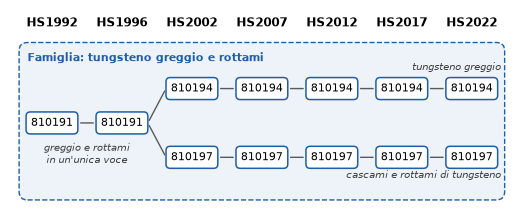

salvata: fig_3_1_famiglia.png


In [31]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

OUT_PNG = "fig_3_1_famiglia.png"

# impostazioni di base, indipendenti dal tema dell'editor
mpl.rcdefaults()
plt.style.use("default")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5,
                     "text.color": "black", "figure.facecolor": "white",
                     "savefig.facecolor": "white"})

NERO, BLU, GR, GR_T = "black", "#1f5fa8", "0.35", "0.25"
revs = ["HS1992", "HS1996", "HS2002", "HS2007", "HS2012", "HS2017", "HS2022"]

fig, ax = plt.subplots(figsize=(6.5, 2.5), facecolor="white")
ax.set_facecolor("white")
ax.set_xlim(-0.6, 6.6); ax.set_ylim(0.15, 2.95); ax.axis("off")

# riquadro della famiglia
ax.add_patch(FancyBboxPatch((-0.45, 0.2), 6.9, 2.25, boxstyle="round,pad=0.02,rounding_size=0.12",
                            fc="#eef3fa", ec=BLU, lw=1.0, ls="--", zorder=0))
ax.text(-0.35, 2.33, "Famiglia: tungsteno greggio e rottami", ha="left", va="top",
        color=BLU, fontsize=8, fontweight="bold")

y_one, y_a, y_b = 1.3, 1.8, 0.8

def nodo(x, y, code):
    ax.add_patch(FancyBboxPatch((x - 0.36, y - 0.15), 0.72, 0.30,
                                boxstyle="round,pad=0.01,rounding_size=0.06",
                                fc="white", ec=BLU, lw=1.1, zorder=3))
    ax.text(x, y, code, ha="center", va="center", fontsize=8, color=NERO, zorder=4)

def arco(x0, y0, x1, y1):
    ax.annotate("", xy=(x1 - 0.37, y1), xytext=(x0 + 0.37, y0),
                arrowprops=dict(arrowstyle="-", color=GR, lw=1.0), zorder=2)

# intestazioni delle colonne
for i, r in enumerate(revs):
    ax.text(i, 2.75, r, ha="center", va="center", fontsize=8.5, fontweight="bold", color=NERO)

# codici e corrispondenze
nodo(0, y_one, "810191"); nodo(1, y_one, "810191")
arco(0, y_one, 1, y_one)
for i in range(2, 7):
    nodo(i, y_a, "810194"); nodo(i, y_b, "810197")
arco(1, y_one, 2, y_a); arco(1, y_one, 2, y_b)
for i in range(2, 6):
    arco(i, y_a, i + 1, y_a); arco(i, y_b, i + 1, y_b)

# etichette descrittive
ax.text(6.42, y_a + 0.27, "tungsteno greggio", ha="right", fontsize=7.3, color=GR_T, style="italic")
ax.text(6.42, y_b - 0.30, "cascami e rottami di tungsteno", ha="right", fontsize=7.3, color=GR_T, style="italic")
ax.text(0.5, y_one - 0.28, "greggio e rottami\nin un'unica voce", ha="center", va="top",
        fontsize=7.0, color=GR_T, style="italic", linespacing=1.15)

fig.savefig(OUT_PNG, dpi=600, bbox_inches="tight", pad_inches=0.04, facecolor="white")
plt.show()
print("salvata:", OUT_PNG)

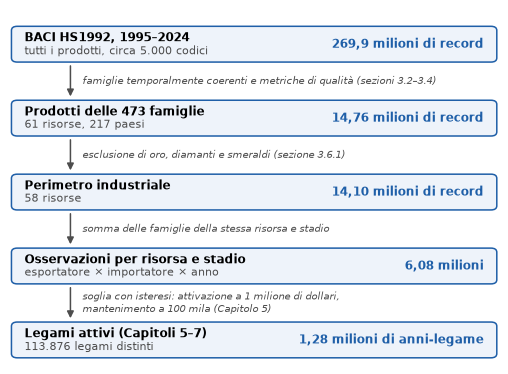

salvata: fig_3_3_percorso.png


In [32]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

OUT_PNG = "fig_3_3_percorso.png"

# impostazioni di base, indipendenti dal tema dell'editor
mpl.rcdefaults()
plt.style.use("default")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5,
                     "text.color": "black", "figure.facecolor": "white",
                     "savefig.facecolor": "white"})

NERO, BLU, GR = "black", "#1f5fa8", "0.3"

passaggi = [
    ("BACI HS1992, 1995–2024", "tutti i prodotti, circa 5.000 codici", "269,9 milioni di record"),
    ("Prodotti delle 473 famiglie", "61 risorse, 217 paesi", "14,76 milioni di record"),
    ("Perimetro industriale", "58 risorse", "14,10 milioni di record"),
    ("Osservazioni per risorsa e stadio", "esportatore × importatore × anno", "6,08 milioni"),
    ("Legami attivi (Capitoli 5–7)", "113.876 legami distinti", "1,28 milioni di anni-legame"),
]
operazioni = [
    "famiglie temporalmente coerenti e metriche di qualità (sezioni 3.2–3.4)",
    "esclusione di oro, diamanti e smeraldi (sezione 3.6.1)",
    "somma delle famiglie della stessa risorsa e stadio",
    "soglia con isteresi: attivazione a 1 milione di dollari,\nmantenimento a 100 mila (Capitolo 5)",
]

fig, ax = plt.subplots(figsize=(6.3, 4.6), facecolor="white")
ax.set_facecolor("white")
ax.axis("off"); ax.set_xlim(-0.05, 10.05); ax.set_ylim(-0.3, 10)
ys = [9.0, 6.85, 4.7, 2.55, 0.4]

for (titolo, sotto, numero), y in zip(passaggi, ys):
    ax.add_patch(FancyBboxPatch((0, y - 0.5), 10, 1.0, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc="#eef3fa", ec=BLU, lw=1.1))
    ax.text(0.25, y + 0.18, titolo, ha="left", va="center", fontsize=8.8, fontweight="bold", color=NERO)
    ax.text(0.25, y - 0.20, sotto, ha="left", va="center", fontsize=7.6, color=GR)
    ax.text(9.75, y, numero, ha="right", va="center", fontsize=8.8, color=BLU, fontweight="bold")

for i, op in enumerate(operazioni):
    y0, y1 = ys[i] - 0.55, ys[i + 1] + 0.55
    ax.annotate("", xy=(1.2, y1), xytext=(1.2, y0),
                arrowprops=dict(arrowstyle="-|>", color=GR, lw=1.1, mutation_scale=10))
    ax.text(1.45, (y0 + y1) / 2, op, ha="left", va="center", fontsize=7.4, color=GR, style="italic")

fig.savefig(OUT_PNG, dpi=600, bbox_inches="tight", pad_inches=0.04, facecolor="white")
plt.show()
print("salvata:", OUT_PNG)

### T1. Strumenti per tabelle e figure

Funzioni comuni a tutte le tabelle della tesi.

- **Numeri in formato italiano**: separatore delle migliaia con spazio
  indivisibile, virgola decimale e segno meno tipografico (`_num`),
  percentuali (`_pct`), variazioni con segno esplicito (`_pc`).
- **Nomi delle risorse in italiano** (`NOMI_IT`, `_nome`), per tutte le
  61 risorse ricostruite sul binario A.
- **`tabella`**: tabella in stile booktabs (tre filetti orizzontali,
  nessuna riga verticale), salvata come immagine a 600 dpi su fondo
  trasparente, con una copia su fondo bianco per l'anteprima. Il testo
  va a capo automaticamente anche nelle intestazioni; didascalia e
  nota, in corpo minore, stanno sotto la tabella. `tabella_da_df` fa lo
  stesso a partire da un DataFrame, allineando a destra le colonne
  numeriche.

La cella ripristina i parametri grafici predefiniti di matplotlib,
perché le figure di rete usano un tema scuro.

In [20]:
# %% CELLA T1 — formattazione dei numeri e funzione tabella
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt

assert "FIG_DIR" in globals(), "Esegui prima la cella 11 (definisce FIG_DIR)"

# I grafi di rete impiegano un tema scuro con testo bianco: si ripristinano
# i valori predefiniti, e i colori sono comunque imposti a ogni elemento.
plt.rcParams.update(plt.rcParamsDefault)


# ---------------------------------------------------------------------
# Formattazione italiana dei numeri
# ---------------------------------------------------------------------
def _num(x, dec=0):
    """1234.5 -> '1 234,5' (spazio indivisibile per le migliaia, segno meno tipografico)."""
    s = f"{x:,.{dec}f}".replace(",", "\u00a0").replace(".", ",")
    return s.replace("-", "\u2212")


def _pct(x, dec=1):
    """26.2 -> '26,2 %'."""
    return _num(x, dec) + "\u00a0%"


def _pc(x, dec=1):
    """Numero con segno esplicito: +2,7 / −0,8 / +1 234,5."""
    s = f"{x:+,.{dec}f}".replace(",", "\u00a0").replace(".", ",")
    return s.replace("-", "\u2212")


# ---------------------------------------------------------------------
# Nomi italiani delle risorse
# ---------------------------------------------------------------------
NOMI_IT = {
    "aluminium-bauxite": "bauxite e alluminio", "antimony": "antimonio",
    "arsenic": "arsenico", "barite": "barite", "battery_cells": "celle per accumulatori",
    "bentonite": "bentonite", "beryllium": "berillio", "bismuth": "bismuto",
    "boron_borates": "boro e borati", "cadmium": "cadmio",
    "cemented_carbide_tools": "utensili in carburi", "chromium": "cromo",
    "cobalt": "cobalto", "copper": "rame", "diamonds": "diamanti",
    "diatomite": "diatomite", "emerald": "smeraldi", "feldspar": "feldspato",
    "fluorspar": "fluorite",
    "gallium_germanium_indium_niobium_vanadium_other": "altri metalli minori (8112.92/99)",
    "germanium": "germanio", "gold": "oro", "graphite": "grafite", "gypsum": "gesso",
    "helium": "elio", "iron_ore_steel": "ferro e acciaio", "kaolin": "caolino",
    "lead": "piombo", "limestone": "calcare", "lithium": "litio",
    "magnesium": "magnesio", "manganese": "manganese", "mercury": "mercurio",
    "metallurgical_coal": "carbone metallurgico", "molybdenum": "molibdeno",
    "nickel": "nichel", "niobium": "niobio", "optical_fibre_cable": "fibra ottica",
    "perlite": "perlite", "permanent_magnets": "magneti permanenti",
    "pgm_other_and_palladium": "palladio e altri PGM", "phosphates": "fosfati",
    "platinum": "platino", "potassium": "potassio", "ree": "terre rare",
    "selenium": "selenio", "silicon": "silicio", "silver": "argento",
    "sodium": "sodio", "strontium": "stronzio", "sulphur": "zolfo",
    "tantalum": "tantalio", "tantalum_capacitors": "condensatori al tantalio",
    "thorium": "torio", "tin": "stagno", "titanium": "titanio",
    "tungsten": "tungsteno", "uranium": "uranio", "vanadium": "vanadio",
    "zinc": "zinco", "zirconium": "zirconio",
}


def _nome(r):
    """Nome italiano della risorsa, con iniziale maiuscola."""
    n = NOMI_IT.get(r, r.replace("_", " "))
    return n[0].upper() + n[1:]


def _wrap(testo, larghezza_car):
    """Manda a capo rispettando le interruzioni esplicite: textwrap.fill le
    sostituirebbe con spazi, impedendo di controllare dove il testo si spezza."""
    return "\n".join(textwrap.fill(p, larghezza_car) for p in str(testo).split("\n"))


# ---------------------------------------------------------------------
# Tabella
# ---------------------------------------------------------------------
def tabella(righe, colonne, larghezze, didascalia=None, nota=None,
            allinea=None, out=None, larghezza=9.5, fs=9.5, dpi=600,
            trasparente=True, didascalia_sopra=False, anteprima=True):
    """Tabella in stile booktabs: tre filetti orizzontali, nessuna riga
    verticale.

    righe             lista di tuple, una per riga
    colonne           intestazioni; ammettono \\n per l'a capo esplicito
    larghezze         quote della larghezza totale, somma pari a 1
    allinea           'l' o 'r' per colonna; i numeri vanno a destra
    didascalia        titolo numerato; per convenzione sotto la tabella
    nota              riga in corpo minore per fonti e avvertenze
    dpi               600 anziché 300: inserita in pagina la tabella viene
                      ridotta a circa due terzi, e a 300 punti il testo
                      risulterebbe sgranato in stampa
    trasparente       sfondo trasparente, così che la tabella si integri nel
                      colore di pagina del documento
    anteprima         salva accanto al file una copia su fondo bianco, per
                      verificare l'aspetto senza dipendere dal visualizzatore

    Il testo va a capo anche nelle intestazioni, che altrimenti sconfinano
    nelle colonne adiacenti. Didascalia e nota, composte in corpo minore,
    usano una larghezza di riga proporzionalmente maggiore. L'altezza le
    comprende entrambe, che il ritaglio automatico dei margini eliminerebbe."""
    assert abs(sum(larghezze) - 1) < 1e-6, f"le larghezze sommano a {sum(larghezze):.3f}"
    assert len(larghezze) == len(colonne), "una larghezza per colonna"

    allinea = allinea or ["l"] * len(colonne)
    out = Path(out or (FIG_DIR / "tabella.png"))
    NERO, GRIGIO = "#000000", "#555555"
    H_RIGA, H_INT, H_DID = 0.30, 0.30, 0.26

    def wrap_w(corpo):
        """Caratteri per riga a un dato corpo: inversamente proporzionale,
        così che i testi in corpo minore riempiano l'intera larghezza."""
        return max(int(larghezza * 11.5 * fs / corpo), 20)

    def wrap_col(testo, w):
        return _wrap(testo, max(int(w * larghezza * 10.5), 8))

    testi = [[wrap_col(v, w) for v, w in zip(r, larghezze)] for r in righe]
    n_linee = [max(c.count("\n") + 1 for c in cel) for cel in testi]

    cols = [wrap_col(c, w) for c, w in zip(colonne, larghezze)]
    n_int = max(c.count("\n") + 1 for c in cols)

    # sopra la tabella la didascalia e' in corpo pieno, sotto in corpo minore
    fs_did = fs if didascalia_sopra else fs - 0.5
    fs_nt = fs - 2
    did = _wrap(didascalia, wrap_w(fs_did)) if didascalia else None
    nt = _wrap(nota, wrap_w(fs_nt)) if nota else None
    n_did = (did.count("\n") + 1) if did else 0
    n_nt = (nt.count("\n") + 1) if nt else 0

    altezza = (H_INT * n_int + sum(n * H_RIGA for n in n_linee) + 0.20
               + (0.14 + H_DID * n_did if did else 0)
               + (0.10 + (H_DID - 0.02) * n_nt if nt else 0))

    fig, ax = plt.subplots(figsize=(larghezza, altezza))
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, altezza)
    y = altezza

    if did and didascalia_sopra:
        y -= H_DID * n_did * 0.5
        ax.text(0, y, did, fontsize=fs_did, fontweight="bold", va="center",
                color=NERO, linespacing=1.4)
        y -= H_DID * n_did * 0.5 + 0.14

    ax.plot([0, 1], [y, y], color=NERO, lw=1.1)
    y -= H_INT * n_int * 0.55
    x = 0
    for c, w, a in zip(cols, larghezze, allinea):
        ax.text(x + (w - 0.012 if a == "r" else 0.012), y, c, fontsize=fs,
                fontweight="bold", va="center", color=NERO,
                ha="right" if a == "r" else "left", linespacing=1.3)
        x += w
    y -= H_INT * n_int * 0.45
    ax.plot([0, 1], [y, y], color=NERO, lw=0.6)

    for cel, n in zip(testi, n_linee):
        y -= n * H_RIGA * 0.5
        x = 0
        for v, w, a in zip(cel, larghezze, allinea):
            ax.text(x + (w - 0.012 if a == "r" else 0.012), y, v, fontsize=fs,
                    va="center", color=NERO,
                    ha="right" if a == "r" else "left", linespacing=1.35)
            x += w
        y -= n * H_RIGA * 0.5
    ax.plot([0, 1], [y, y], color=NERO, lw=1.1)

    if did and not didascalia_sopra:
        y -= 0.14 + H_DID * n_did * 0.5
        ax.text(0, y, did, fontsize=fs_did, va="center", color=NERO, linespacing=1.4)
        y -= H_DID * n_did * 0.5
    if nt:
        y -= 0.10 + (H_DID - 0.02) * n_nt * 0.5
        ax.text(0, y, nt, fontsize=fs_nt, color=GRIGIO, va="center", linespacing=1.4)

    fig.savefig(out, dpi=dpi, bbox_inches="tight", transparent=trasparente,
                facecolor="none" if trasparente else "white")
    plt.show()
    plt.close(fig)

    if trasparente and anteprima:
        try:
            from PIL import Image
            im = Image.open(out).convert("RGBA")
            (Image.alpha_composite(Image.new("RGBA", im.size, "white"), im)
                  .convert("RGB").save(out.with_name(out.stem + "_anteprima.png")))
        except ImportError:
            pass

    print(f"scritta {out}")
    return out


def tabella_da_df(df, **kw):
    """Come sopra, a partire da un DataFrame. Le colonne numeriche sono
    allineate a destra."""
    allinea = ["r" if pd.api.types.is_numeric_dtype(df[c]) else "l" for c in df.columns]
    n = len(df.columns)
    return tabella([tuple(r) for r in df.astype(str).values],
                   list(df.columns), kw.pop("larghezze", [1 / n] * n),
                   allinea=kw.pop("allinea", allinea), **kw)


print("formattatori e funzione tabella disponibili")

formattatori e funzione tabella disponibili


### F1. Cornice comune alle figure

`figura` impagina tutte le figure del capitolo nello stesso modo:
riquadro del grafico senza bordi superiore e destro, griglia leggera,
didascalia e nota sotto il grafico, salvataggio a 600 dpi su fondo
trasparente con una copia su fondo bianco per l'anteprima. Riceve una
funzione che disegna sull'asse, così che ogni figura definisca solo il
proprio contenuto. I margini sono regolabili per figura: va alzato
quello inferiore quando il titolo dell'asse orizzontale occupa due
righe, e quello sinistro quando le etichette dell'asse verticale sono
lunghe.

La palette degli stadi (`COL_ST`) e le loro etichette italiane
(`LBL_ST`: estrazione, raffinazione, manifattura, riciclo) sono comuni
a figure e testo. `FONTE` è la nota standard per le figure sul
perimetro industriale.

In [21]:
# %% CELLA F1 — la cornice comune alle figure
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

assert "FIG_DIR" in globals(), "Esegui prima la cella 11 (definisce FIG_DIR)"
assert "_wrap" in globals(), "Esegui prima la cella T1 (definisce _wrap)"

plt.rcParams.update(plt.rcParamsDefault)

# Palette impiegata in tutto il capitolo, coerente fra figure e testo.
COL_ST = {"upstream": "#8c6d3f", "refining": "#c0392b",
          "manufacturing": "#1f6f8b", "recycling": "#5a9367"}
LBL_ST = {"upstream": "Estrazione", "refining": "Raffinazione",
          "manufacturing": "Manifattura", "recycling": "Riciclo"}

FONTE = ("Fonte: elaborazione su BACI-CEPII (HS 1992, release V202601). "
         "Esclusi oro, diamanti e smeraldi.")


def figura(disegna, didascalia=None, nota=None, out=None,
           larghezza=9.0, altezza=5.0, fs=9.5, dpi=600,
           margine_basso=0.55, margine_alto=0.15,
           margine_sx=0.95, margine_dx=0.25,
           trasparente=True, anteprima=True):
    """Cornice comune alle figure del capitolo.

    disegna         funzione che riceve l'asse e vi traccia il grafico
    altezza         altezza del solo riquadro del grafico, in pollici
    margine_basso   spazio riservato sotto il riquadro per le etichette
                    dell'asse orizzontale e il relativo titolo: senza di esso
                    tali elementi si sovrapporrebbero alla didascalia. Va
                    alzato a 0,8 quando il titolo dell'asse occupa due righe
    margine_sx      spazio a sinistra per il titolo dell'asse verticale; va
                    alzato quando le etichette dell'asse sono lunghe (es. barre
                    orizzontali con nomi di voci)
    dpi             600 anziché 300: inserita in pagina la figura viene
                    ridotta, e a 300 punti il testo risulterebbe sgranato

    Didascalia e nota vanno a capo su larghezza proporzionale al proprio corpo,
    e sono comprese nell'altezza complessiva: il ritaglio automatico dei
    margini le eliminerebbe altrimenti."""
    NERO, GRIGIO = "#000000", "#555555"
    fs_did, fs_nt = fs - 0.5, fs - 2

    def wrap_w(corpo):
        """Caratteri per riga a un dato corpo. La costante è calibrata sulla
        larghezza effettivamente disponibile al netto del margine sinistro; i
        testi in corpo minore ne contengono proporzionalmente di più."""
        return max(int(larghezza * 13.3 * fs / corpo), 20)

    did = _wrap(didascalia, wrap_w(fs_did)) if didascalia else None
    nt = _wrap(nota, wrap_w(fs_nt)) if nota else None
    n_did = (did.count("\n") + 1) if did else 0
    n_nt = (nt.count("\n") + 1) if nt else 0

    H_DID, H_NT = 0.20, 0.17
    h_testi = ((0.12 + H_DID * n_did) if did else 0) \
        + ((0.06 + H_NT * n_nt) if nt else 0)
    h_tot = margine_alto + altezza + margine_basso + h_testi

    fig = plt.figure(figsize=(larghezza, h_tot))
    ax = fig.add_axes([margine_sx / larghezza,
                       (h_testi + margine_basso) / h_tot,
                       1 - (margine_sx + margine_dx) / larghezza,
                       altezza / h_tot])
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ax.spines.values():
        s.set_color(NERO)
    ax.grid(alpha=0.25, lw=0.5)
    ax.tick_params(labelsize=fs - 1, colors=NERO)
    disegna(ax)

    x0 = max(margine_sx / larghezza - 0.07, 0.0)
    y = h_testi / h_tot
    if did:
        y -= 0.12 / h_tot
        fig.text(x0, y, did, fontsize=fs_did, color=NERO, va="top", linespacing=1.4)
        y -= H_DID * n_did / h_tot
    if nt:
        y -= 0.06 / h_tot
        fig.text(x0, y, nt, fontsize=fs_nt, color=GRIGIO, va="top", linespacing=1.4)

    out = Path(out or (FIG_DIR / "figura.png"))
    fig.savefig(out, dpi=dpi, bbox_inches="tight", transparent=trasparente,
                facecolor="none" if trasparente else "white")
    plt.show()
    plt.close(fig)

    if trasparente and anteprima:
        try:
            from PIL import Image
            im = Image.open(out).convert("RGBA")
            (Image.alpha_composite(Image.new("RGBA", im.size, "white"), im)
                  .convert("RGB").save(out.with_name(out.stem + "_anteprima.png")))
        except ImportError:
            pass

    print(f"scritta {out}")
    return out


print("funzione figura disponibile")

funzione figura disponibile


### 12. §4.1–4.2 Perimetro e posizione della Cina

**4.1.1 Peso dei beni esclusi.** Oro, diamanti e smeraldi valgono una
quota variabile del commercio ricostruito: dal 19,6% del 1995 a un
massimo del 35,1% nel 2016, fino al 29,0% del 2024. Il peso è
concentrato nella raffinazione, dove nel 2024 i beni esclusi
rappresentano il 51,6% del valore dello stadio, contro il 20,3% della
manifattura, il 10,5% del riciclo e il 6,3% dell'estrazione. Nella
raffinazione l'intera quota esclusa è oro, che da solo vale più della
metà dello stadio, quasi cinque volte il rame (10,9%), seconda risorsa
per valore: senza l'esclusione, la raffinazione descriverebbe
soprattutto il mercato dell'oro.

| anno | totale (mld $) | perimetro industriale (mld $) | quota esclusa |
|---|---|---|---|
| 1995 | 447,0 | 359,5 | 19,6% |
| 2003 | 592,7 | 460,4 | 22,3% |
| 2008 | 1.772,0 | 1.466,2 | 17,3% |
| 2011 | 2.123,4 | 1.607,2 | 24,3% |
| 2016 | 1.653,4 | 1.073,1 | 35,1% |
| 2021 | 2.676,6 | 1.982,9 | 25,9% |
| 2024 | 2.682,3 | 1.903,4 | 29,0% |

Da qui in avanti il capitolo usa il perimetro industriale (`DI`).

**4.2.1 Posizione netta della Cina per stadio.** La posizione netta è
la differenza fra export e import cinesi, in percentuale del commercio
mondiale dello stadio (Hong Kong escluso; `cina_posizione_netta.csv`).
Fra il 1995 e il 2024 la Cina:

- diventa il principale importatore netto di minerali: da −0,7% a
  −46,4% del commercio mondiale dell'estrazione;
- passa da esportatrice a importatrice netta di raffinati: da +4,6% a
  −11,6%, con il cambio di segno nel 2009;
- diventa esportatrice netta di manufatti: da −2,6% a +24,1%, con
  un'accelerazione dopo il 2021;
- resta importatrice netta di rottami e residui per tutto il periodo
  (−13,4% nel 2024), con un minimo di −23,7% nel 2009 e un
  ridimensionamento fino al −5,8% del 2020.

La Cina importa quindi materia prima e prodotti raffinati ed esporta
prodotti finiti. Il saldo negativo nella raffinazione è concentrato in
due metalli: nel 2024 il rame raffinato contribuisce per −7,8 punti e
il nichel per −2,9, circa il 90% del saldo complessivo di −11,6;
seguono a distanza alluminio (−1,1), uranio, cromo e platino (circa
−0,6 ciascuno). Nelle altre risorse raffinate la Cina è in sostanziale
equilibrio o esportatrice netta (argento, silicio, fosfati, magnesio).

**4.2.2 Chi importa minerali e raffinati.** La quota cinese delle
importazioni mondiali di minerali sale dal 3,7% del 1995 al 47,0% del
2024; quella di Giappone, Corea del Sud, Taiwan e Hong Kong scende nello
stesso periodo dal 32,6% al 17,5%. Nei raffinati il sorpasso avviene
intorno al 2015 (14,1% contro 14,2%), e nel 2024 la Cina importa il
19,3% del commercio mondiale contro il 12,1% dei quattro paesi
dell'Asia orientale.

| | 1995 | 2005 | 2015 | 2019 | 2024 |
|---|---|---|---|---|---|
| minerali — Cina | 3,7% | 15,6% | 31,2% | 38,6% | 47,0% |
| minerali — Asia orientale | 32,6% | 26,7% | 22,4% | 20,0% | 17,5% |
| raffinati — Cina | 1,5% | 5,9% | 14,1% | 13,7% | 19,3% |
| raffinati — Asia orientale | 21,4% | 17,4% | 14,2% | 13,4% | 12,1% |

In [22]:
# =====================================================================
# 12. §4.1-4.2: PERIMETRO E POSIZIONE CINESE
# =====================================================================

# --- 4.1.1 incidenza dei beni esclusi -----------------------------------
tot = D.groupby("year").value.sum() / 1e6
ind = DI.groupby("year").value.sum() / 1e6
PERIM = pd.DataFrame({"totale": tot, "perimetro": ind,
                      "quota_esclusa": 100 * (1 - ind / tot)})
print(PERIM.loc[[1995, 2003, 2008, 2011, 2016, 2021, 2024]].round(1).to_string())
print(f"massimo: {PERIM.quota_esclusa.max():.1f}% nel {PERIM.quota_esclusa.idxmax()}")

s_tot = D[D.year == 2024].groupby("stage_name", observed=True).value.sum()
s_ind = DI[DI.year == 2024].groupby("stage_name", observed=True).value.sum()
print("\nincidenza dei beni esclusi per stadio, 2024 (%):")
print((100 * (1 - s_ind / s_tot)).round(1).to_string())

# --- 4.2.1 posizione netta cinese per stadio ----------------------------
POS = posizione(DI, CHN, ["year", "stage_name"])
N = POS.net.unstack()[["upstream", "refining", "manufacturing", "recycling"]]
N.to_csv(OUT_DIR / "cina_posizione_netta.csv")
print("\nposizione netta cinese (% del commercio mondiale dello stadio):")
print(N.round(1).to_string())

# --- 4.2.2 chi importa i raffinati e i minerali -------------------------
for st in ["refining", "upstream"]:
    S = DI[DI.stage_name == st]
    t = S.groupby("year").value.sum()
    q = pd.DataFrame({
        "CHN": 100 * S[S.imp == CHN].groupby("year").value.sum() / t,
        "JPN+KOR+TWN+HKG": 100 * S[S.imp.isin(ASIA_E)].groupby("year").value.sum() / t})
    print(f"\nquota delle importazioni mondiali, {st} (%):")
    print(q.loc[[1995, 2005, 2015, 2019, 2024]].round(1).to_string())

# --- verifica: composizione della raffinazione 2024 (tutte le risorse) ---
R24 = D[(D.year == 2024) & (D.stage_name == "refining")]
comp = (R24.groupby("resource", observed=True).value.sum()
        .sort_values(ascending=False) / R24.value.sum() * 100)
print("\ncomposizione della raffinazione 2024, % del valore dello stadio:")
print(comp.head(8).round(1).to_string())
print(f"di cui beni esclusi (NON_IND): {comp[comp.index.isin(NON_IND)].sum():.1f}%")

# --- verifica: da quali risorse viene la posizione netta cinese nei raffinati ---
R24i = DI[(DI.year == 2024) & (DI.stage_name == "refining")]
tot_r = R24i.value.sum()
ex = R24i[R24i.exp == CHN].groupby("resource", observed=True).value.sum()
im = R24i[R24i.imp == CHN].groupby("resource", observed=True).value.sum()
saldo = (ex.reindex(im.index.union(ex.index), fill_value=0)
         - im.reindex(im.index.union(ex.index), fill_value=0)) / tot_r * 100
print("\nposizione netta cinese nella raffinazione 2024, contributo per risorsa "
      "(punti % del commercio mondiale dello stadio):")
print(saldo.sort_values().head(6).round(2).to_string())
print("...")
print(saldo.sort_values().tail(4).round(2).to_string())
print(f"totale: {saldo.sum():.1f}")

      totale  perimetro  quota_esclusa
year                                  
1995   447.0      359.5           19.6
2003   592.7      460.4           22.3
2008  1772.0     1466.2           17.3
2011  2123.4     1607.2           24.3
2016  1653.4     1073.1           35.1
2021  2676.6     1982.9           25.9
2024  2682.3     1903.4           29.0
massimo: 35.1% nel 2016

incidenza dei beni esclusi per stadio, 2024 (%):
stage_name
manufacturing    20.3
recycling        10.5
refining         51.6
upstream          6.3

posizione netta cinese (% del commercio mondiale dello stadio):
stage_name  upstream  refining  manufacturing  recycling
year                                                    
1995            -0.7       4.6           -2.6       -3.2
1996            -0.9       3.8           -4.0       -3.1
1997            -0.9       5.2           -3.1       -3.0
1998            -1.3       4.5           -3.5       -3.1
1999            -1.2       4.0           -4.1       -5.8
2000        

### 13. §4.2.3 Che cosa guida la fase recente

**Scomposizione del saldo manifatturiero.** Fra il 2021 e il 2024 il
saldo cinese nella manifattura (export meno import) aumenta di 84,3
miliardi di dollari. L'aumento è concentrato in due voci, che ne
spiegano il 90%:

| risorsa | variazione (mld $) | quota della variazione |
|---|---|---|
| celle per accumulatori | +42,5 | 50,4% |
| ferro e acciaio | +33,7 | 40,0% |
| rame | +4,5 | 5,3% |
| bauxite e alluminio | +3,2 | 3,8% |
| altre risorse (saldo) | +0,4 | 0,5% |

Le celle per accumulatori sono un prodotto downstream multi-minerale
(layer `extra`): la fase recente riflette quindi soprattutto
l'espansione cinese nelle batterie e, in misura quasi pari, nei
prodotti siderurgici.

**Robustezza: senza ferro e acciaio.** Poiché l'acciaio pesa molto sia
nell'estrazione (minerale di ferro) sia nella manifattura (laminati),
la posizione netta per stadio è ricalcolata escludendolo. La
divaricazione resta: nel 2024 la Cina è importatrice netta di minerali
(−37,1% del commercio mondiale dello stadio, contro −46,4% con
l'acciaio) e di raffinati (−11,8%), ed esportatrice netta di manufatti
(+26,2%, contro +24,1%). Senza l'acciaio la posizione manifatturiera
diventa positiva nel 2007, un anno dopo la serie completa (nel 2006 è
in pareggio), e quella nell'estrazione resta negativa in tutto il
periodo dopo il 1995. Il risultato non dipende quindi dalla siderurgia.

| anno | estrazione | raffinazione | manifattura | riciclo |
|---|---|---|---|---|
| 1995 | +1,1 | +4,0 | −3,5 | −4,6 |
| 2005 | −3,4 | +2,4 | −0,8 | −26,0 |
| 2009 | −13,7 | −7,7 | +1,7 | −31,5 |
| 2015 | −19,3 | −7,6 | +10,7 | −24,3 |
| 2021 | −28,4 | −11,3 | +16,3 | −14,1 |
| 2024 | −37,1 | −11,8 | +26,2 | −20,9 |

Posizione netta cinese senza ferro e acciaio, % del commercio mondiale
dello stadio.

In [23]:
# =====================================================================
# 13. §4.2.3: CHE COSA GUIDA LA FASE RECENTE
# =====================================================================

MAN = DI[DI.stage_name == "manufacturing"]


def saldo_cina(df, y):
    g = df[df.year == y]
    e = g[g.exp == CHN].groupby("resource", observed=True).value.sum()
    i = g[g.imp == CHN].groupby("resource", observed=True).value.sum()
    return e.sub(i, fill_value=0) / 1e6


delta = saldo_cina(MAN, 2024).sub(saldo_cina(MAN, 2021), fill_value=0).sort_values(ascending=False)
tot_delta = delta.sum()
print(f"variazione del saldo manifatturiero cinese 2021-2024: {tot_delta:+.1f} mld $")
print(pd.DataFrame({"mld": delta.head(8),
                    "quota_%": 100 * delta.head(8) / tot_delta}).round(1).to_string())
print(f"\nprime due voci: {100 * delta.head(2).sum() / tot_delta:.0f}% della variazione")

# robustezza: la divaricazione regge anche senza l'acciaio?
N_noFe = posizione(DI[DI.resource != "iron_ore_steel"], CHN,
                   ["year", "stage_name"]).net.unstack()[["upstream", "refining",
                                                          "manufacturing", "recycling"]]
print("\nposizione netta cinese senza iron_ore_steel:")
print(N_noFe.loc[[1995, 2005, 2006, 2007, 2009, 2015, 2021, 2024]].round(1).to_string())

variazione del saldo manifatturiero cinese 2021-2024: +84.3 mld $
                    mld  quota_%
resource                        
battery_cells      42.5     50.4
iron_ore_steel     33.7     40.0
copper              4.5      5.3
aluminium-bauxite   3.2      3.8
sulphur             0.8      0.9
silicon             0.5      0.6
platinum            0.4      0.5
titanium            0.3      0.3

prime due voci: 90% della variazione

posizione netta cinese senza iron_ore_steel:
stage_name  upstream  refining  manufacturing  recycling
year                                                    
1995             1.1       4.0           -3.5       -4.6
2005            -3.4       2.4           -0.8      -26.0
2006            -5.6       1.3            0.0      -21.7
2007            -9.8       0.3            1.4      -21.8
2009           -13.7      -7.7            1.7      -31.5
2015           -19.3      -7.6           10.7      -24.3
2021           -28.4     -11.3           16.3      -14.1
2024   

### T4.1 Tabella 4.1 — Il perimetro nel tempo

Valore del commercio ricostruito, sua quota sul commercio mondiale
complessivo (BACI) e peso di oro, diamanti e smeraldi, per anni
selezionati fra il 1995 e il 2024. Il valore passa da 447 a 2.682
miliardi di dollari e la quota sul commercio mondiale dall'8,8%
all'11,8%; il peso dei beni esclusi oscilla fra il 19% e il 31% negli
anni mostrati, con un massimo del 35,1% nel 2016 (cella 12).

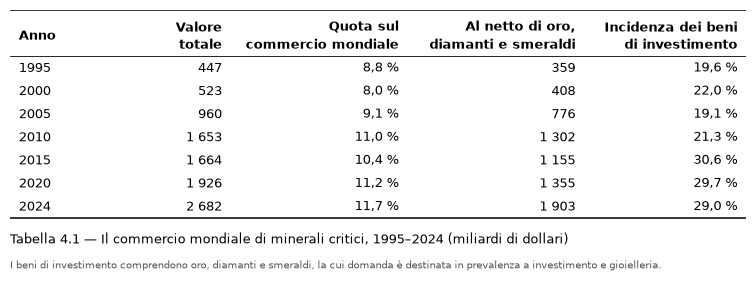

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_4_1_perimetro.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_4_1_perimetro.png')

In [24]:
# %% CELLA T4.1 — il perimetro nel tempo
cov = pd.read_csv(OUT_DIR / "binario_a_coverage.csv").set_index("year")
ANNI_T = [1995, 2000, 2005, 2010, 2015, 2020, 2024]

tabella(
    [(str(y), _num(PERIM.totale[y]),
      _pct(100 * PERIM.totale[y] * 1e6 / cov.world_value[y]),
      _num(PERIM.perimetro[y]), _pct(PERIM.quota_esclusa[y])) for y in ANNI_T],
    ["Anno", "Valore\ntotale", "Quota sul\ncommercio mondiale",
     "Al netto di oro,\ndiamanti e smeraldi", "Incidenza dei beni\ndi investimento"],
    [0.12, 0.18, 0.24, 0.24, 0.22],
    didascalia="Tabella 4.1 — Il commercio mondiale di minerali critici, "
               "1995–2024 (miliardi di dollari)",
    nota="I beni di investimento comprendono oro, diamanti e smeraldi, la cui "
         "domanda è destinata in prevalenza a investimento e gioielleria.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_4_1_perimetro.png")

### T4.2 Tabella 4.2 — Posizione netta cinese per stadio

Posizione netta della Cina (export meno import, in percentuale del
commercio mondiale dello stadio) per anni selezionati, sul perimetro
industriale e con Hong Kong considerato separatamente. Gli anni 2005,
2006, 2007 e 2009 sono inclusi per mostrare i due cambi di segno: la
manifattura diventa positiva nel 2006, la raffinazione stabilmente
negativa dal 2009. La serie completa è in `cina_posizione_netta.csv`.

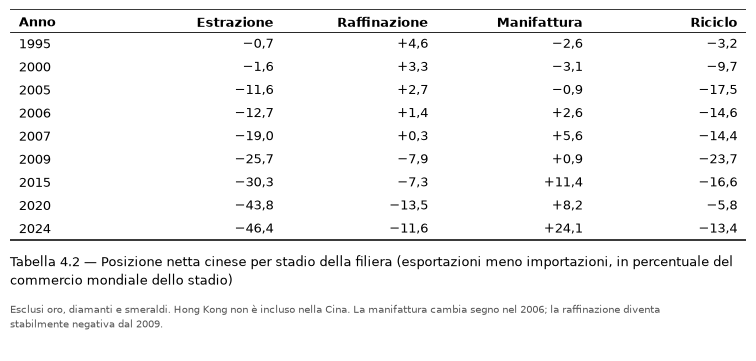

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_4_2_posizione_netta.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_4_2_posizione_netta.png')

In [25]:
# %% CELLA T4.2 — posizione netta cinese per stadio
ANNI_PN = [1995, 2000, 2005, 2006, 2007, 2009, 2015, 2020, 2024]

tabella(
    [(str(y),) + tuple(_pc(N.loc[y, s]) for s in STAGES) for y in ANNI_PN],
    ["Anno"] + [LBL_ST[s] for s in STAGES],
    [0.16, 0.21, 0.21, 0.21, 0.21],
    didascalia="Tabella 4.2 — Posizione netta cinese per stadio della filiera "
               "(esportazioni meno importazioni, in percentuale del commercio "
               "mondiale dello stadio)",
    nota="Esclusi oro, diamanti e smeraldi. Hong Kong non è incluso nella Cina. "
         "La manifattura cambia segno nel 2006; la raffinazione diventa "
         "stabilmente negativa dal 2009.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_4_2_posizione_netta.png")

### F4.1 Figura 4.1 — Posizione netta cinese per stadio

Serie completa 1995–2024 della posizione netta cinese nei quattro stadi
(perimetro industriale, Hong Kong escluso). La figura mostra la
divaricazione della filiera cinese: l'estrazione scende in modo quasi
continuo fino al −46,4% del 2024, la manifattura diventa positiva nel
2006 e accelera dopo il 2021 fino al +24,1%, la raffinazione passa in
territorio negativo nel 2009 e vi resta. L'area grigia evidenzia il
periodo fra i due cambi di segno.

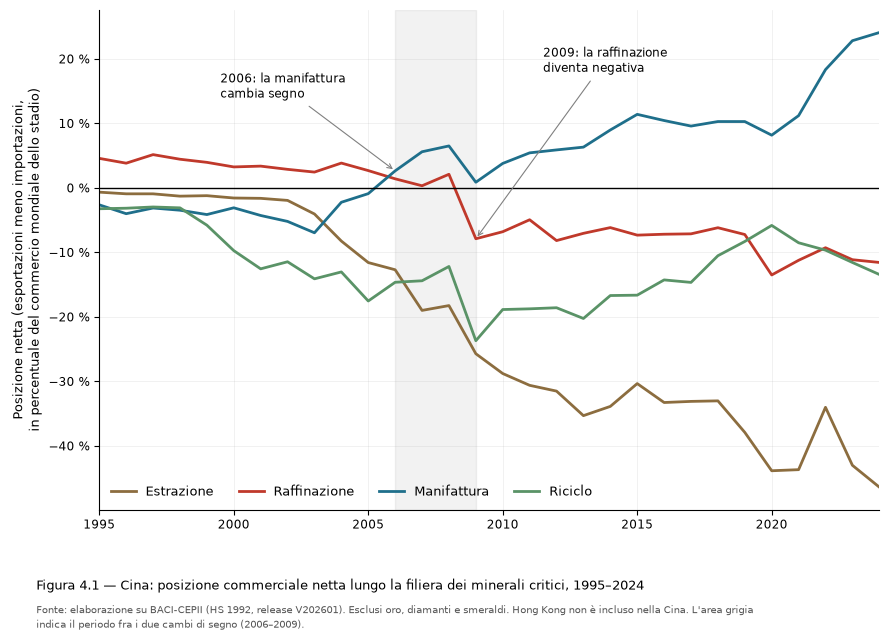

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_4_1_cina_stadi.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_4_1_cina_stadi.png')

In [26]:
# %% CELLA F4.1 — Figura 4.1: posizione netta cinese per stadio
def _f41(ax):
    for st in STAGES:
        ax.plot(N.index, N[st], color=COL_ST[st], lw=2, label=LBL_ST[st])
    ax.axhline(0, color="black", lw=1)
    ax.axvspan(2006, 2009, color="grey", alpha=0.10)
    ax.annotate("2006: la manifattura\ncambia segno",
                xy=(2006, N.loc[2006, "manufacturing"]), xytext=(1999.5, 14),
                fontsize=8.5, arrowprops=dict(arrowstyle="->", lw=0.8, color="grey"))
    ax.annotate("2009: la raffinazione\ndiventa negativa",
                xy=(2009, N.loc[2009, "refining"]), xytext=(2011.5, 18),
                fontsize=8.5, arrowprops=dict(arrowstyle="->", lw=0.8, color="grey"))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _pct(v, 0)))
    ax.set_ylabel("Posizione netta (esportazioni meno importazioni,\n"
                  "in percentuale del commercio mondiale dello stadio)", fontsize=9)
    ax.set_xlim(1995, 2024)
    ax.legend(frameon=False, ncol=4, fontsize=9, loc="lower left")


figura(_f41,
       didascalia="Figura 4.1 — Cina: posizione commerciale netta lungo la "
                  "filiera dei minerali critici, 1995–2024",
        nota=FONTE + " Hong Kong non è incluso nella Cina. L'area grigia indica "
                    "il periodo fra i due cambi di segno (2006–2009).",
       out=FIG_DIR / "fig_4_1_cina_stadi.png")

### 14. §4.3 La filiera delle batterie

Posizione della Cina nelle risorse della filiera delle batterie (litio,
cobalto, nichel, grafite, manganese) e nelle celle per accumulatori,
per stadio, nel 2024 e nella serie 2010–2024.

**2024.** La Cina è esportatrice dominante a valle e importatrice
dominante a monte:

| risorsa | stadio | commercio mondiale (mld $) | quota export Cina | quota import Cina | posizione netta |
|---|---|---|---|---|---|
| celle per accumulatori | manifattura | 122,5 | 58,0% | 1,6% | +56,4 |
| litio | estrazione | 5,7 | 2,9% | 76,5% | −73,6 |
| litio | raffinazione | 7,4 | 30,8% | 35,6% | −4,8 |
| cobalto | raffinazione | 6,6 | 9,1% | 50,4% | −41,3 |
| nichel | estrazione | 19,3 | 0,4% | 54,6% | −54,3 |
| nichel | raffinazione | 32,2 | 3,9% | 50,9% | −46,9 |
| manganese | estrazione | 6,6 | 0,7% | 60,7% | −60,1 |
| manganese | raffinazione | 7,7 | 16,1% | 1,5% | +14,6 |
| grafite | estrazione | 0,6 | 50,7% | 5,1% | +45,5 |
| grafite | raffinazione | 3,3 | 47,8% | 7,5% | +40,3 |

La grafite è l'unico materiale in cui la Cina è esportatrice netta in
tutti gli stadi. Per litio, nichel e manganese importa la maggior parte
del minerale mondiale; nel manganese esporta poi il metallo raffinato.
Per cobalto e nichel risulta invece importatrice netta anche nella
raffinazione, perché lo stadio comprende i prodotti intermedi che la
Cina importa per completarne la lavorazione: nel 2024 importa il 68,6%
del commercio mondiale di mattes e intermedi del cobalto (810520), per
il 93,4% dalla Repubblica Democratica del Congo, e l'86,2% del
ferronichel (720260), per il 91,8% dall'Indonesia.

**2010–2024.** La posizione netta nelle celle per accumulatori sale da
+7,8 a +56,4, con un'accelerazione dopo il 2020. Nello stesso periodo
la Cina diventa importatrice netta di cobalto raffinato (da −5,7 a
−41,3) e di nichel raffinato (da −12,9 a −46,9), mentre rafforza la
posizione esportatrice nella grafite raffinata (da +8,0 a +40,3). Il
litio raffinato è l'unica serie instabile: positiva fino al 2021,
oscilla poi fra −7,5 e +13,3.

In [27]:
# =====================================================================
# 14. §4.3 LA FILIERA DELLE BATTERIE
# =====================================================================

BATT = ["lithium", "cobalt", "nickel", "graphite", "manganese", "battery_cells"]
B = DI[DI.resource.isin(BATT)]

T24 = posizione(B[B.year == 2024], CHN, ["resource", "stage_name"])
print("Cina, 2024 (% del commercio mondiale della risorsa-stadio):")
print(T24.round(1).to_string())

SB = posizione(B, CHN, ["year", "resource", "stage_name"]).net.unstack(["resource", "stage_name"])
chiave = [("lithium", "refining"), ("cobalt", "refining"), ("nickel", "refining"),
          ("graphite", "refining"), ("battery_cells", "manufacturing")]
print("\nposizione netta cinese, 2010-2024:")
print(SB[[c for c in chiave if c in SB.columns]].loc[2010:].round(1).to_string())

Cina, 2024 (% del commercio mondiale della risorsa-stadio):
                             tot_mld  q_exp  q_imp   net
resource      stage_name                                
battery_cells manufacturing    122.5   58.0    1.6  56.4
cobalt        manufacturing      0.8    5.2    8.2  -3.1
              refining           6.6    9.1   50.4 -41.3
              upstream           0.0    0.3    7.8  -7.4
graphite      manufacturing      4.9   23.5    6.1  17.5
              refining           3.3   47.8    7.5  40.3
              upstream           0.6   50.7    5.1  45.5
lithium       refining           7.4   30.8   35.6  -4.8
              upstream           5.7    2.9   76.5 -73.6
manganese     refining           7.7   16.1    1.5  14.6
              upstream           6.6    0.7   60.7 -60.1
nickel        manufacturing      8.7    6.8    9.7  -2.9
              recycling          1.3    3.9    1.1   2.8
              refining          32.2    3.9   50.9 -46.9
              upstream      

### T4.3 Tabella 4.3 — La filiera delle batterie

Quote cinesi del commercio mondiale nel 2024 per le voci principali
della filiera delle batterie (da `T24`, cella 14). La tabella mostra lo
schema ricorrente: la Cina importa il minerale (litio −73,6, manganese
−60,1) e gli intermedi di nichel e cobalto (−46,9 e −41,3), ed esporta
il prodotto finale (celle per accumulatori, +56,4) e il manganese
metallico (+14,6). La grafite è l'eccezione: la Cina ne è esportatrice
netta anche a monte.

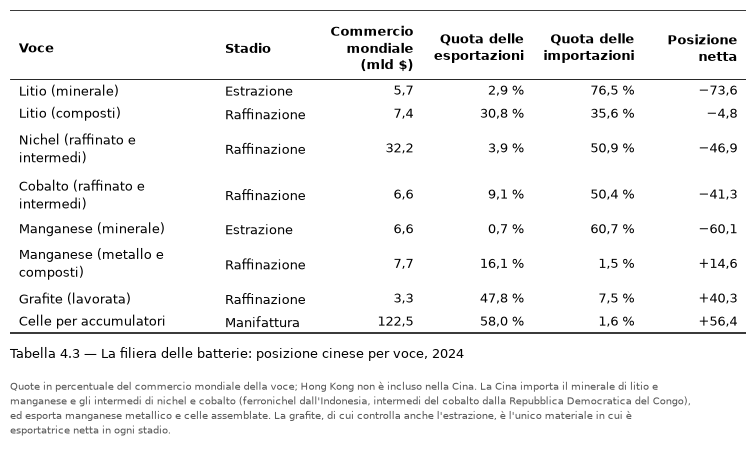

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_4_3_batterie.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_4_3_batterie.png')

In [28]:
# %% CELLA T4.3 — la filiera delle batterie
VOCI = [("Litio (minerale)",                  "lithium",       "upstream",      "Estrazione"),
        ("Litio (composti)",                  "lithium",       "refining",      "Raffinazione"),
        ("Nichel (raffinato e intermedi)",    "nickel",        "refining",      "Raffinazione"),
        ("Cobalto (raffinato e intermedi)",   "cobalt",        "refining",      "Raffinazione"),
        ("Manganese (minerale)",              "manganese",     "upstream",      "Estrazione"),
        ("Manganese (metallo e composti)",    "manganese",     "refining",      "Raffinazione"),
        ("Grafite (lavorata)",                "graphite",      "refining",      "Raffinazione"),
        ("Celle per accumulatori",            "battery_cells", "manufacturing", "Manifattura")]

tabella(
    [(lbl, sl, _num(T24.loc[(r, s), "tot_mld"], 1),
      _pct(T24.loc[(r, s), "q_exp"]), _pct(T24.loc[(r, s), "q_imp"]),
      _pc(T24.loc[(r, s), "net"])) for lbl, r, s, sl in VOCI],
    ["Voce", "Stadio", "Commercio\nmondiale\n(mld $)",
     "Quota delle\nesportazioni", "Quota delle\nimportazioni", "Posizione\nnetta"],
    [0.28, 0.14, 0.14, 0.15, 0.15, 0.14],
    didascalia="Tabella 4.3 — La filiera delle batterie: posizione cinese per "
               "voce, 2024",
    nota="Quote in percentuale del commercio mondiale della voce; Hong Kong non "
         "è incluso nella Cina. La Cina importa il minerale di litio e manganese "
         "e gli intermedi di nichel e cobalto (ferronichel dall'Indonesia, "
         "intermedi del cobalto dalla Repubblica Democratica del Congo), ed "
         "esporta manganese metallico e celle assemblate. La grafite, di cui "
         "controlla anche l'estrazione, è l'unico materiale in cui è "
         "esportatrice netta in ogni stadio.",
    allinea=["l", "l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_4_3_batterie.png")

### F4.2 Figura 4.2 — La filiera delle batterie

Rappresentazione grafica della posizione netta cinese nelle voci della
Tabella 4.3. A sinistra dell'asse le voci in cui la Cina è
importatrice netta (minerale di litio e manganese, intermedi di nichel
e cobalto), a destra quelle in cui è esportatrice netta (manganese
metallico, grafite lavorata, celle per accumulatori).

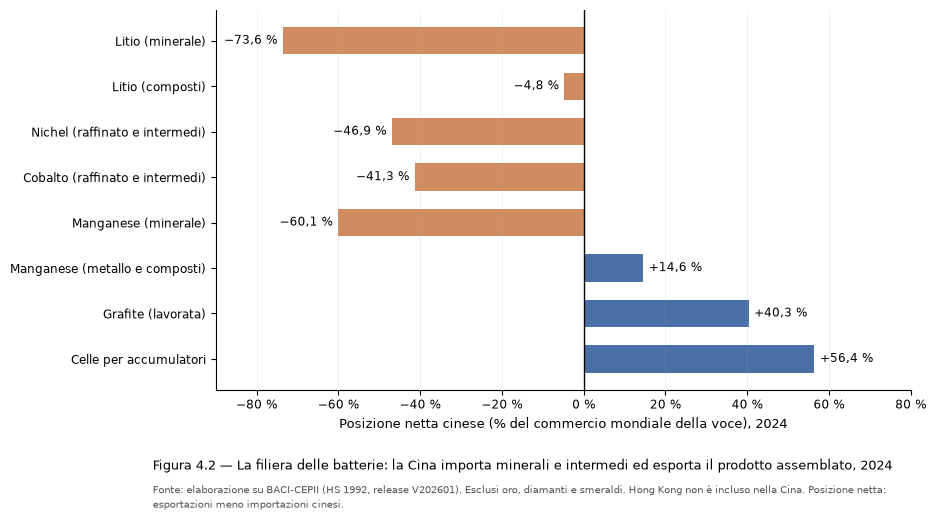

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_4_2_batterie.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_4_2_batterie.png')

In [29]:
# %% CELLA F4.2 — Figura 4.2: la filiera delle batterie
COL_NEG, COL_POS = "#d08c60", "#4a6fa5"   # fuori dalla palette degli stadi (COL_ST)


def _f42(ax):
    lab = [l for l, _, _, _ in VOCI]
    val = [T24.loc[(r, s), "net"] for _, r, s, _ in VOCI]
    b = ax.barh(lab, val, height=0.6,
                color=[COL_NEG if v < 0 else COL_POS for v in val])
    ax.bar_label(b, labels=[_pc(v) + "\u00a0%" for v in val], padding=4, fontsize=8.5)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlim(-90, 80)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _pct(v, 0)))
    ax.set_xlabel("Posizione netta cinese (% del commercio mondiale della voce), 2024",
                  fontsize=9)
    ax.grid(axis="y", visible=False)


figura(_f42, altezza=3.8, margine_sx=1.8,
       didascalia="Figura 4.2 — La filiera delle batterie: la Cina importa minerali "
                  "e intermedi ed esporta il prodotto assemblato, 2024",
       nota=FONTE + " Hong Kong non è incluso nella Cina. Posizione netta: "
                    "esportazioni meno importazioni cinesi.",
       out=FIG_DIR / "fig_4_2_batterie.png")

### 15. §4.4 Le terre rare

Il caso di studio usa due basi. La posizione cinese complessiva è
calcolata sull'intero stadio di raffinazione delle terre rare (metalli
e composti); valori, quantità e origine delle importazioni sono
calcolati sulla sola famiglia dei composti di terre rare (`FAM_REE`,
HS22 284690 e antenati), la voce in cui si concentra la
riorganizzazione dei flussi.

**4.4.1 Valore e quantità.** Il commercio mondiale dei composti passa
da 0,9 miliardi di dollari nel 2010 a 2,4 nel 2024, con un picco di
3,3 nel 2023. Le quantità crescono più del valore: da 50 mila
tonnellate nel 2010 a circa 170 mila nel 2023–2024, mentre il valore
unitario scende da circa 17.700 a 14.100 dollari per tonnellata. La serie dei prezzi ha un picco isolato nel 2011 (69.500 $/t), in
corrispondenza della riduzione delle quote cinesi all'esportazione
(Morrison e Tang, 2012).

**4.4.2 Dalla Cina esportatrice alla Cina importatrice.** Nello stadio
di raffinazione la Cina passa da esportatrice netta dominante a
importatrice netta:

| anno | quota export Cina | quota import Cina | posizione netta |
|---|---|---|---|
| 2010 | 64,9% | 1,9% | +63,1 |
| 2011 | 62,8% | 0,5% | +62,3 |
| 2015 | 30,2% | 6,9% | +23,3 |
| 2020 | 18,1% | 28,7% | −10,6 |
| 2024 | 16,7% | 44,9% | −28,2 |

Nella famiglia dei composti la svolta è ancora più netta. La quota
cinese delle importazioni mondiali sale dall'1,9% del 2010 al 56,9% del
2024, mentre quella delle esportazioni scende dal 64,5% al 15,9%.
Cambia anche l'origine delle importazioni cinesi:

| anno | primi fornitori della Cina |
|---|---|
| 2010 | Germania 26,4%, Stati Uniti 26,1%, Giappone 20,2%, Francia 9,3% |
| 2015 | Malaysia 52,2%, Stati Uniti 11,5%, Vietnam 9,1%, Myanmar 6,9% |
| 2020 | Myanmar 73,8%, Malaysia 10,8%, Stati Uniti 6,4% |
| 2024 | Myanmar 59,9%, Laos 19,0%, Malaysia 14,6% |

Nel 2010 la Cina importava quantità trascurabili da paesi
industrializzati; nel 2024 importa quasi otto decimi dei composti da
due paesi confinanti, Myanmar e Laos. Il flusso dal Myanmar alla Cina
vale da solo il 34,1% del commercio mondiale della voce, quello dal
Laos il 10,8% (comparso solo nel 2023).

**4.4.3 Il Myanmar.** Nel 2024 il 100% delle esportazioni birmane della
voce è diretto in Cina. Poiché BACI ricostruisce ogni flusso
riconciliando le dichiarazioni di esportatore e importatore, il
commercio birmano di terre rare è osservabile anche in assenza di
statistiche affidabili del paese d'origine, attraverso le importazioni
registrate dalla Cina: è la stessa base su cui le indagini
indipendenti ricostruiscono questi flussi.

`IMP_REE` prepara i dati della figura sull'origine delle importazioni
cinesi (Myanmar, Laos, Malaysia, altri; miliardi di dollari dal 2010).

In [30]:
# =====================================================================
# 15. §4.4 LE TERRE RARE
# =====================================================================

R = D[D.family_id == FAM_REE]          # composti di terre rare (HS22 284690 e antenati)
anni_r = R.groupby("year").value.sum().index

# --- 4.4.1 valore, quantita', valore unitario -----------------------------
# valore unitario solo sui flussi con quantita' dichiarata
q = R[R.qty > 0]
A = pd.DataFrame({
    "mld":        R.groupby("year").value.sum() / 1e6,
    "kt":         q.groupby("year").qty.sum() / 1e3,
    "usd_per_t":  q.groupby("year").value.sum() * 1000 / q.groupby("year").qty.sum(),
    "copertura_qty_%": 100 * q.groupby("year").value.sum() / R.groupby("year").value.sum()})
print("composti di terre rare, commercio mondiale:")
print(A.loc[2008:].round(2).to_string())

# --- 4.4.2 posizione cinese e origine delle importazioni ------------------
NR = posizione(DI[(DI.resource == "ree") & (DI.stage_name == "refining")], CHN, "year")
print("\nCina, terre rare raffinate (%):")
print(NR.loc[[2010, 2011, 2015, 2020, 2024], ["q_exp", "q_imp", "net"]].round(1).to_string())

tot_f = R.groupby("year").value.sum()
flusso = lambda m: R[m].groupby("year").value.sum().reindex(anni_r, fill_value=0)
SR = pd.DataFrame({
    "mondo_mld":     tot_f / 1e6,
    "MMR->CHN_%":    100 * flusso((R.exp == MMR) & (R.imp == CHN)) / tot_f,
    "LAO->CHN_%":    100 * flusso((R.exp == LAO) & (R.imp == CHN)) / tot_f,
    "import_CHN_%":  100 * flusso(R.imp == CHN) / tot_f,
    "export_CHN_%":  100 * flusso(R.exp == CHN) / tot_f})
print("\ncomposti di terre rare, quote del commercio mondiale:")
print(SR.loc[2010:].round(1).to_string())

for y in [2010, 2015, 2020, 2024]:
    x = R[(R.year == y) & (R.imp == CHN)].groupby("exp").value.sum()
    top = (100 * x / x.sum()).nlargest(5).rename(index=SIGLA).round(1)
    print(f"\n{y} — origine delle importazioni cinesi (%): {top.to_dict()}")

# --- 4.4.3 destinazioni delle esportazioni birmane ------------------------
m = R[(R.year == 2024) & (R.exp == MMR)].groupby("imp").value.sum()
print(f"\nMyanmar 2024 — destinazioni (%): "
      f"{(100 * m / m.sum()).rename(index=SIGLA).round(1).to_dict()}")

# --- dati per la figura 3 -------------------------------------------------
x = R[(R.imp == CHN) & (R.year >= 2010)].copy()
x["origine"] = x.exp.map({MMR: "Myanmar", LAO: "Laos", 458: "Malaysia"}).fillna("Altri")
IMP_REE = x.groupby(["year", "origine"]).value.sum().unstack(fill_value=0) / 1e6
IMP_REE = IMP_REE[[c for c in ["Myanmar", "Laos", "Malaysia", "Altri"] if c in IMP_REE]]

composti di terre rare, commercio mondiale:
       mld      kt  usd_per_t  copertura_qty_%
year                                          
2008  1.01   60.23   16688.00            99.55
2009  0.47   43.65   10400.25            96.24
2010  0.90   50.45   17730.65            99.81
2011  3.11   44.70   69514.67            99.90
2012  1.55   31.95   48180.80            99.35
2013  1.00   40.46   23432.69            94.60
2014  0.87   47.57   18322.16            99.79
2015  0.80   56.01   14319.64            99.96
2016  0.94   33.84   27800.11            99.96
2017  0.90   80.53   11162.89           100.00
2018  1.01  125.84    8060.99            99.98
2019  1.09  116.66    9367.51            99.99
2020  1.31   82.28   15899.67           100.00
2021  2.23   89.92   24817.29           100.00
2022  3.13  100.06   31269.65            99.84
2023  3.28  177.77   18419.23            99.97
2024  2.40  169.62   14126.70            99.97

Cina, terre rare raffinate (%):
      q_exp  q_imp   net
year 

### T4.4 Tabella 4.4 — Le terre rare: valore, quantità, prezzo implicito

Valore, quantità e valore unitario del commercio mondiale di composti
di terre rare per anni selezionati (da `A`, cella 15). La tabella
separa le due componenti del valore: il picco del 2011 è dovuto
interamente al prezzo, con quantità in calo; la crescita successiva,
fino al massimo del 2023, è invece trainata dalle quantità, più che
triplicate dal 2015, a valore unitario stabile.

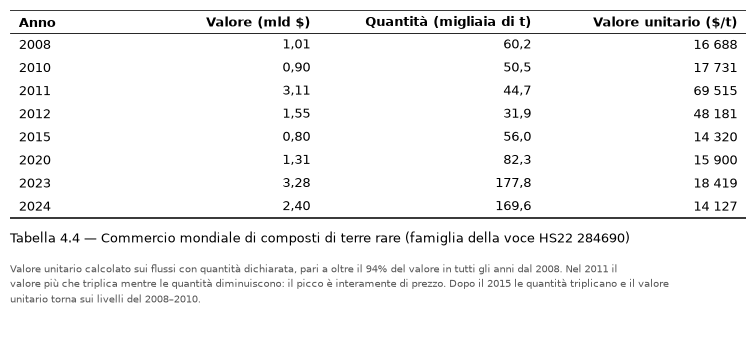

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_4_4_ree_prezzo.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_4_4_ree_prezzo.png')

In [31]:
# %% CELLA T4.4 — le terre rare: valore, quantità, prezzo implicito
tabella(
    [(str(y), _num(A.mld[y], 2), _num(A.kt[y], 1), _num(A.usd_per_t[y]))
     for y in [2008, 2010, 2011, 2012, 2015, 2020, 2023, 2024]],
    ["Anno", "Valore (mld $)", "Quantità (migliaia di t)", "Valore unitario ($/t)"],
    [0.16, 0.26, 0.30, 0.28],
    didascalia="Tabella 4.4 — Commercio mondiale di composti di terre rare "
               "(famiglia della voce HS22 284690)",
    nota="Valore unitario calcolato sui flussi con quantità dichiarata, pari a "
         "oltre il 94% del valore in tutti gli anni dal 2008. Nel 2011 il valore "
         "più che triplica mentre le quantità diminuiscono: il picco è "
         "interamente di prezzo. Dopo il 2015 le quantità triplicano e il valore "
         "unitario torna sui livelli del 2008–2010.",
    allinea=["l", "r", "r", "r"],
    out=FIG_DIR / "tab_4_4_ree_prezzo.png")

### T4.5 Tabella 4.5 — Origine delle importazioni cinesi di terre rare

Composizione per origine delle importazioni cinesi di composti di terre
rare e loro peso sul commercio mondiale della voce (da `R`, cella 15).
In quindici anni l'origine passa dai paesi industrializzati (Germania,
Stati Uniti, Giappone nel 2010) alla Malaysia (52,2% nel 2015) e poi a
Myanmar e Laos, che nel 2024 forniscono insieme il 78,9% delle
importazioni cinesi. Nello stesso periodo la quota cinese sul
commercio mondiale della voce sale dall'1,9% al 56,9%.

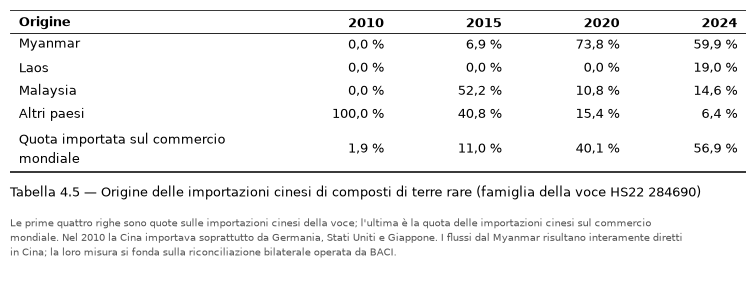

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_4_5_ree_origine.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_4_5_ree_origine.png')

In [32]:
# %% CELLA T4.5 — origine delle importazioni cinesi di terre rare
ANNI_R = [2010, 2015, 2020, 2024]

def _quote_ree(y):
    imp = R[(R.year == y) & (R.imp == CHN)]
    ti = imp.value.sum()
    q = {k: imp[imp.exp == c].value.sum() / ti for k, c in
         [("Myanmar", MMR), ("Laos", LAO), ("Malaysia", 458)]}
    q["Altri paesi"] = 1 - sum(q.values())
    q["Quota importata sul commercio mondiale"] = ti / R[R.year == y].value.sum()
    return q

QR = {y: _quote_ree(y) for y in ANNI_R}
tabella(
    [(k,) + tuple(_pct(100 * QR[y][k]) for y in ANNI_R) for k in QR[ANNI_R[0]]],
    ["Origine"] + [str(y) for y in ANNI_R],
    [0.36, 0.16, 0.16, 0.16, 0.16],
    didascalia="Tabella 4.5 — Origine delle importazioni cinesi di composti di "
               "terre rare (famiglia della voce HS22 284690)",
    nota="Le prime quattro righe sono quote sulle importazioni cinesi della "
         "voce; l'ultima è la quota delle importazioni cinesi sul commercio "
         "mondiale. Nel 2010 la Cina importava soprattutto da Germania, Stati "
         "Uniti e Giappone. I flussi dal Myanmar risultano interamente diretti "
         "in Cina; la loro misura si fonda sulla riconciliazione bilaterale "
         "operata da BACI.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_4_5_ree_origine.png")

### F4.3 Figura 4.3 — Origine delle importazioni cinesi di terre rare

Valore delle importazioni cinesi di composti di terre rare per origine,
2010–2024 (da `IMP_REE`, cella 15). Fino al 2016 le importazioni sono
modeste e provengono soprattutto dalla Malaysia e da altri paesi; dal
2017 cresce il Myanmar, che diventa il primo fornitore e raggiunge il
massimo nel 2023; il Laos compare nel 2023 e nel 2024 fornisce quasi
un quinto delle importazioni.

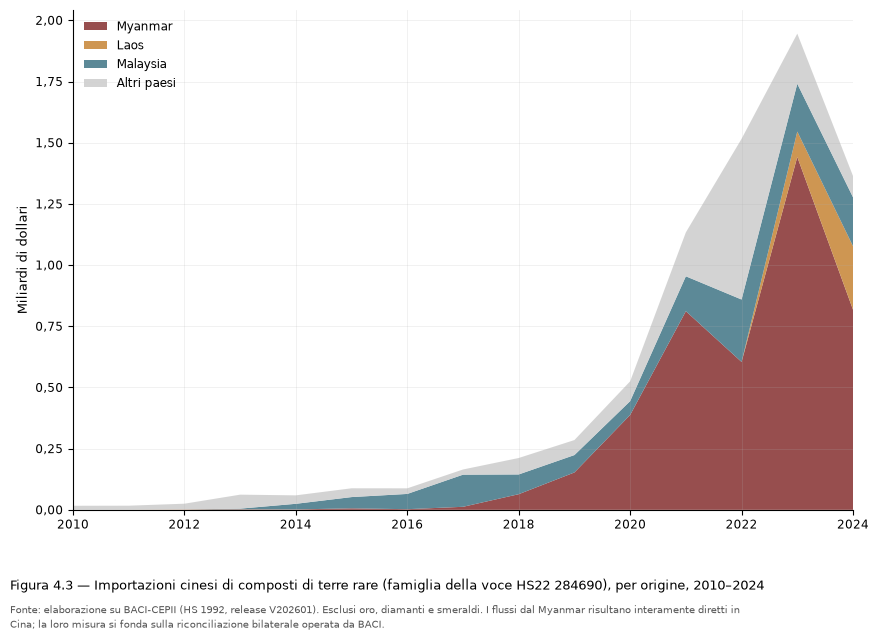

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_4_3_ree_origine.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_4_3_ree_origine.png')

In [33]:
# %% CELLA F4.3 — Figura 4.3: origine delle importazioni cinesi di terre rare
COL_REE = {"Myanmar": "#8c3b3b", "Laos": "#c98b3f", "Malaysia": "#4a7c8c",
           "Altri": "#cfcfcf"}
LBL_REE = {"Myanmar": "Myanmar", "Laos": "Laos", "Malaysia": "Malaysia",
           "Altri": "Altri paesi"}


def _f43(ax):
    ax.stackplot(IMP_REE.index, IMP_REE.T.values,
                 labels=[LBL_REE[c] for c in IMP_REE.columns],
                 colors=[COL_REE[c] for c in IMP_REE.columns], alpha=0.9)
    ax.set_ylabel("Miliardi di dollari", fontsize=9)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _num(v, 2)))
    ax.set_xlim(IMP_REE.index.min(), IMP_REE.index.max())
    ax.legend(frameon=False, loc="upper left", fontsize=8.5)


figura(_f43,
       didascalia="Figura 4.3 — Importazioni cinesi di composti di terre rare "
                  "(famiglia della voce HS22 284690), per origine, 2010–2024",
        nota=FONTE + " I flussi dal Myanmar risultano interamente diretti in "
            "Cina; la loro misura si fonda sulla riconciliazione bilaterale "
            "operata da BACI.",
       out=FIG_DIR / "fig_4_3_ree_origine.png")

## Cella U1 — sostituisci i paragrafi "Serie aggregata" ed "Effetto della composizione"

**Serie aggregata.** Il valore unitario cresce in tutti gli stadi fra
il 1995 e il 2024: in estrazione da 54 a 152 dollari per tonnellata, in
raffinazione da 599 a 1.467, in manifattura da 660 a 1.469, nel riciclo
da 302 a 754. Rispetto all'estrazione, raffinazione e manifattura
valgono circa dieci volte tanto per tonnellata.

**Effetto della composizione.** Il valore unitario aggregato pesa ogni
risorsa per il suo tonnellaggio, e gli stadi sono dominati in tonnellate
da pochi materiali pesanti e poco costosi: minerale di ferro e carbone
metallurgico nell'estrazione, laminati d'acciaio nella manifattura.
Escludendo ferro, acciaio e carbone metallurgico, il quadro cambia:

| stadio | 1995 | 2005 | 2015 | 2024 | rapporto con l'estrazione, 2024 |
|---|---|---|---|---|---|
| estrazione | 111 | 193 | 222 | 314 | 1,0 |
| raffinazione | 848 | 1.218 | 1.545 | 1.934 | 6,2 |
| manifattura | 1.266 | 1.863 | 2.229 | 3.162 | 10,1 |
| riciclo | 863 | 964 | 1.588 | 2.573 | 8,2 |

Valore unitario in dollari per tonnellata, senza ferro, acciaio e
carbone metallurgico.

Il salto dall'estrazione alla raffinazione si riduce (da 9,6 a 6,2 volte
nel 2024), mentre la manifattura si distingue nettamente dalla
raffinazione, cosa che nella serie completa non accade per effetto
dell'acciaio.

**Risorsa per risorsa.** Il confronto più pulito tiene ferma la merce:
per le 32 risorse con entrambi gli stadi, il rapporto fra valore
unitario della raffinazione e dell'estrazione ha nel 2024 una mediana
di 4,2. La dispersione è però molto ampia: da circa 1 per piombo,
cobalto e molibdeno, il cui minerale scambiato è già un concentrato
ricco, a oltre 20 per alluminio, silicio, zirconio e litio, fino a 216
per l'argento.

In [34]:
# %% CELLA U1 — valore unitario per stadio
# Il valore unitario (valore/quantita', $ per tonnellata) e' il prezzo
# implicito della merce scambiata, non valore aggiunto. Calcolato sui soli
# flussi con quantita' dichiarata.

D_uv = DI[(DI.qty > 0) & (DI.value > 0)].copy()
D_uv["uv"] = D_uv.value * 1000 / D_uv.qty
print(f"[UV] {len(D_uv):,} flussi con quantità valida | valore escluso per quantità "
      f"mancante: {1 - D_uv.value.sum() / DI.value.sum():.1%}")


def uv_per_stadio(D, per=("year", "stage_name")):
    """uv_aggregato   valore totale su quantita' totale: il prezzo medio del
                      paniere, misura di riferimento
       uv_medio_pond  media dei valori unitari ponderata per il valore
       uv_mediano     mediana semplice, robusta agli estremi"""
    out = []
    for k, g in D.groupby(list(per), observed=True):
        w = g.value / g.value.sum()
        out.append(dict(zip(per, k if isinstance(k, tuple) else (k,))) | dict(
            uv_aggregato=float(g.value.sum() * 1000 / g.qty.sum()),
            uv_medio_pond=float((g.uv * w).sum()),
            uv_mediano=float(g.uv.median()),
            valore_mld=g.value.sum() / 1e6,
            qta_mln_t=g.qty.sum() / 1e6,
            n=len(g)))
    return pd.DataFrame(out)


UV = uv_per_stadio(D_uv)
UV.to_csv(OUT_DIR / "valore_unitario_stadio.csv", index=False)

UVP = UV.pivot(index="year", columns="stage_name", values="uv_aggregato")[STAGES]
UVG = UVP.div(UVP["upstream"], axis=0)           # rapporto rispetto all'estrazione

print("\nvalore unitario per stadio ($/t):")
print(UVP.loc[[1995, 2000, 2005, 2010, 2015, 2020, 2024]].round(0).to_string())
print("\nrapporto rispetto allo stadio estrattivo:")
print(UVG.loc[[1995, 2005, 2015, 2024]].round(1).to_string())

# --- robustezza 1: senza ferro e acciaio e senza carbone metallurgico ---
PESANTI = {"iron_ore_steel", "metallurgical_coal"}
UVP_x = (uv_per_stadio(D_uv[~D_uv.resource.isin(PESANTI)])
         .pivot(index="year", columns="stage_name", values="uv_aggregato")[STAGES])
print("\nvalore unitario per stadio senza ferro, acciaio e carbone ($/t):")
print(UVP_x.loc[[1995, 2005, 2015, 2024]].round(0).to_string())
print("\nrapporto rispetto all'estrazione, senza ferro, acciaio e carbone:")
print(UVP_x.div(UVP_x["upstream"], axis=0).loc[[1995, 2005, 2015, 2024]].round(1).to_string())

# --- robustezza 2: rapporto raffinazione/estrazione risorsa per risorsa (2024) ---
g24 = (D_uv[D_uv.year == 2024]
       .groupby(["resource", "stage_name"], observed=True)[["value", "qty"]].sum())
uv_r = (g24.value * 1000 / g24.qty).unstack()
rap = (uv_r["refining"] / uv_r["upstream"]).dropna().sort_values()
print(f"\nrapporto raffinazione/estrazione per risorsa, 2024 "
      f"({len(rap)} risorse con entrambi gli stadi): mediana {rap.median():.1f}")
print(rap.round(1).to_string())

[UV] 13,787,628 flussi con quantità valida | valore escluso per quantità mancante: 0.6%

valore unitario per stadio ($/t):
stage_name  upstream  refining  manufacturing  recycling
year                                                    
1995            54.0     599.0          660.0      302.0
2000            47.0     643.0          555.0      235.0
2005            86.0     855.0          842.0      381.0
2010           138.0    1255.0         1092.0      637.0
2015            92.0    1066.0          948.0      516.0
2020           104.0    1176.0         1049.0      542.0
2024           152.0    1467.0         1469.0      754.0

rapporto rispetto allo stadio estrattivo:
stage_name  upstream  refining  manufacturing  recycling
year                                                    
1995             1.0      11.0           12.1        5.6
2005             1.0      10.0            9.8        4.4
2015             1.0      11.6           10.3        5.6
2024             1.0       9.6      

### U5. Valore unitario per risorsa e moltiplicatore

Per ogni risorsa il moltiplicatore è il rapporto fra il valore unitario
della manifattura e quello dell'estrazione, calcolato sulla media
2020–2024 (`valore_unitario_risorsa.csv`). A differenza del dato
aggregato, che pesa le risorse per tonnellaggio e scende da 12,1 a 9,7
volte fra il 1995 e il 2024, il confronto risorsa per risorsa tiene
ferma la merce.

Per le 23 risorse con entrambi gli stadi il moltiplicatore ha mediana
8 e media 36: la distribuzione è molto asimmetrica, con pochi casi
estremi.

| risorsa | estrazione ($/t) | manifattura ($/t) | moltiplicatore |
|---|---|---|---|
| silicio | 69 | 12.318 | 177 |
| argento | 3.302 | 381.520 | 116 |
| titanio | 476 | 49.451 | 104 |
| nichel | 353 | 32.012 | 91 |
| cadmio | 40 | 2.938 | 74 |
| fluorite | 332 | 23.811 | 72 |
| bauxite e alluminio | 63 | 4.164 | 66 |
| magnesio | 41 | 1.235 | 30 |

I moltiplicatori più alti riguardano risorse il cui minerale è un
materiale abbondante e poco costoso (sabbia silicea, bauxite, magnesite).
Una spiegazione plausibile, non verificata in questa sede, è che il
rapporto rifletta la distanza tecnologica fra la materia prima e i
prodotti finali, più che una maggiore cattura di valore. Il caso opposto
è lo stagno (1,2): il minerale scambiato è già un concentrato ricco
(circa 13.400 $/t di mediana) e la manifattura vale meno del metallo
grezzo (27.500 contro 29.000 $/t di mediana). Il valore della filiera si
concentra così nella raffinazione: 31,4 dei circa 43 miliardi scambiati
fra il 2020 e il 2024.

In [35]:
# %% CELLA U5 — valore unitario per risorsa e moltiplicatore
UVR = uv_per_stadio(D_uv[D_uv.year >= 2020], per=("resource", "stage_name"))
UVR.to_csv(OUT_DIR / "valore_unitario_risorsa.csv", index=False)

W = UVR.pivot(index="resource", columns="stage_name", values="uv_aggregato")
W = W.reindex(columns=[s for s in STAGES if s in W.columns])
W["scarto"] = W["manufacturing"] / W["upstream"]
sc = W.scarto.dropna()

print("=== MOLTIPLICATORE DEL VALORE UNITARIO (manifattura / estrazione) ===")
print(f"aggregato, pesato sui volumi: 1995 {UVG.loc[1995, 'manufacturing']:.1f}× | "
      f"2024 {UVG.loc[2024, 'manufacturing']:.1f}×")
print(f"per risorsa, medie 2020-2024, {len(sc)} risorse con entrambi gli stadi:")
print(f"  mediana {sc.median():.0f}× | media {sc.mean():.0f}× | "
      f"massimo {sc.max():.0f}× ({sc.idxmax()}) | minimo {sc.min():.2f}× ({sc.idxmin()})")

print("\nmoltiplicatori maggiori:")
print(W.loc[sc.nlargest(8).index, ["upstream", "manufacturing", "scarto"]].round(1).to_string())

# --- gradienti piatti o invertiti: da verificare prima di commentarli ------
inv = W[W.scarto.notna() & (W.scarto < 1.2)].sort_values("scarto")
print("\ngradienti piatti o invertiti (moltiplicatore < 1,2):")
print(inv[["upstream", "refining", "manufacturing", "scarto"]].round(1).to_string())

for r in inv.index:
    d = D_uv[(D_uv.resource == r) & (D_uv.year >= 2020)]
    print(f"\n--- {r}, 2020-2024 ---")
    print(d.groupby("stage_name", observed=True).agg(
        mld=("value", lambda s: s.sum() / 1e6),
        kt=("qty", lambda s: s.sum() / 1e3),
        uv_mediano=("uv", "median")).round(1).to_string())

=== MOLTIPLICATORE DEL VALORE UNITARIO (manifattura / estrazione) ===
aggregato, pesato sui volumi: 1995 12.1× | 2024 9.7×
per risorsa, medie 2020-2024, 23 risorse con entrambi gli stadi:
  mediana 8× | media 36× | massimo 177× (silicon) | minimo 1.19× (tin)

moltiplicatori maggiori:
stage_name         upstream  manufacturing  scarto
resource                                          
silicon                69.4        12317.9   177.4
silver               3302.2       381519.9   115.5
titanium              475.8        49450.6   103.9
nickel                353.0        32011.5    90.7
cadmium                39.7         2937.9    73.9
fluorspar             332.0        23811.2    71.7
aluminium-bauxite      62.8         4163.5    66.3
magnesium              41.0         1234.8    30.1

gradienti piatti o invertiti (moltiplicatore < 1,2):
stage_name  upstream  refining  manufacturing  scarto
resource                                             
tin          11411.5   25375.9        13611

### U5b. Figura A.4 — Sensibilità alla soglia di mantenimento

Rappresentazione grafica della griglia della cella 10.12: per dieci
soglie di mantenimento fra zero e un milione di dollari, quota di
cessazioni che rientrano entro un anno (scala sinistra) e numero medio
annuo di cessazioni e formazioni (scala destra). Tutte e tre le curve
crescono con la soglia senza discontinuità. Alla soglia adottata (100
mila dollari) i rientri sono all'11,7%, contro il 10,9% senza soglia di
mantenimento e il 25,3% con soglia unica.

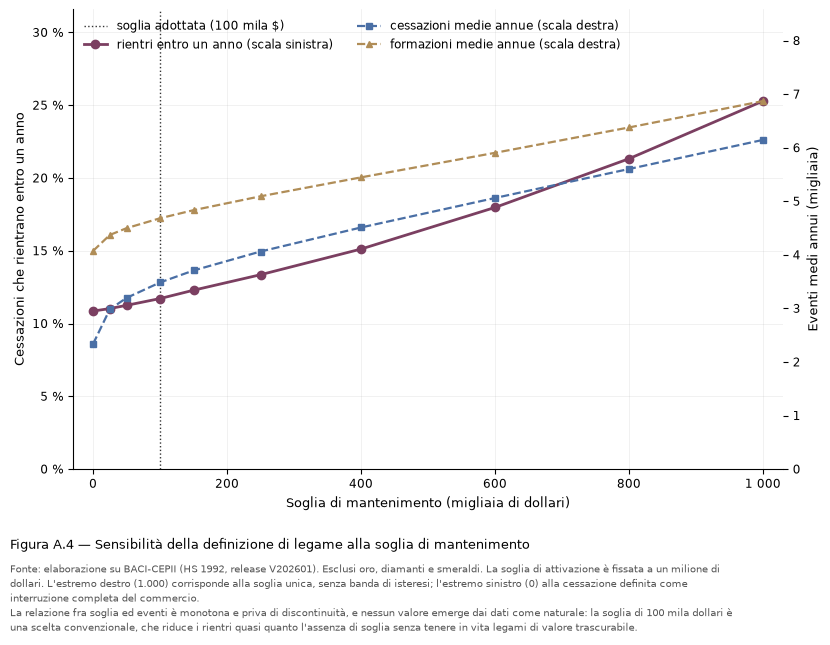

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_A4_sensibilita_isteresi.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_A4_sensibilita_isteresi.png')

In [36]:
# %% CELLA U5b — Figura A.4: sensibilità alla soglia di mantenimento
# I dati sono calcolati nella cella 10.12: qui si legge il file, così che la
# figura si possa rifare senza ricaricare dieci volte la rete.
SENS = pd.read_csv(OUT_DIR / "sensibilita_soglia_isteresi.csv")

# colori fuori dalla palette degli stadi (COL_ST)
COL_RIE, COL_CES, COL_FOR = "#7b3f61", "#4a6fa5", "#b08d57"


def _fs(ax):
    ax.axvline(SOGLIA_OFF, color="#333333", lw=1, ls=":",
               label=f"soglia adottata ({SOGLIA_OFF} mila $)")
    ax.plot(SENS.soglia_off, SENS.rientri, "o-", color=COL_RIE, lw=2,
            label="rientri entro un anno (scala sinistra)")
    ax.set_xlabel("Soglia di mantenimento (migliaia di dollari)", fontsize=9)
    ax.set_ylabel("Cessazioni che rientrano entro un anno", fontsize=9)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _pct(v, 0)))
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _num(v)))
    ax.set_ylim(0, SENS.rientri.max() * 1.25)
    ax.set_xlim(-30, 1030)

    a2 = ax.twinx()
    a2.plot(SENS.soglia_off, SENS.cessazioni / 1000, "s--", color=COL_CES,
            lw=1.6, ms=4, label="cessazioni medie annue (scala destra)")
    a2.plot(SENS.soglia_off, SENS.formazioni / 1000, "^--", color=COL_FOR,
            lw=1.6, ms=4, label="formazioni medie annue (scala destra)")
    a2.set_ylabel("Eventi medi annui (migliaia)", fontsize=9)
    a2.set_ylim(0, max(SENS.formazioni.max(), SENS.cessazioni.max()) / 1000 * 1.25)
    a2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _num(v)))
    a2.tick_params(labelsize=8.5)
    a2.grid(False)
    for s in a2.spines.values():
        s.set_visible(False)

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = a2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=8.5,
              loc="upper left", ncol=2)


figura(_fs, altezza=4.6, margine_dx=0.95,
       didascalia="Figura A.4 — Sensibilità della definizione di legame alla "
                  "soglia di mantenimento",
        nota=FONTE + " La soglia di attivazione è fissata a un milione di "
            "dollari. L'estremo destro (1.000) corrisponde alla soglia unica, "
            "senza banda di isteresi; l'estremo sinistro (0) alla cessazione "
            "definita come interruzione completa del commercio.\n"
            "La relazione fra soglia ed eventi è monotona e priva di "
            "discontinuità, e nessun valore emerge dai dati come naturale: la "
            "soglia di 100 mila dollari è una scelta convenzionale, che riduce i "
            "rientri quasi quanto l'assenza di soglia senza tenere in vita "
            "legami di valore trascurabile.",
       out=FIG_DIR / "fig_A4_sensibilita_isteresi.png")

### F4.4 Figura 4.4 — Valore unitario a monte e a valle

Per le 23 risorse con entrambi gli stadi (medie 2020–2024) si stima la
relazione log-log fra il valore unitario della manifattura e quello
dell'estrazione. Si stima la relazione diretta fra i due valori unitari
e non quella fra il moltiplicatore e il valore del minerale, che
sarebbe in parte meccanica: il logaritmo del rapporto contiene già la
variabile esplicativa con segno negativo, e darebbe pendenza −1 anche
in assenza di qualunque legame.

La pendenza stimata è β = 0,53 (errore standard 0,16; R² = 0,35). È
significativamente positiva (t = 3,4) e significativamente inferiore a
1 (t = −3,0): i manufatti valgono di più dove il minerale vale di più,
ma meno che proporzionalmente. Un minerale dieci volte più costoso si
associa in media a un manufatto circa 3,4 volte più costoso, e il
moltiplicatore si riduce quindi all'aumentare del valore del minerale
(elasticità −0,47). Il risultato non dipende dall'argento, il punto più
estremo: escludendolo la pendenza scende a 0,47 (errore standard 0,14)
e la distanza da 1 aumenta (t = −3,7). Tutte le 23 risorse si
collocano sopra la linea di parità. Il colore riporta il valore
unitario allo stadio di raffinazione, dove osservato.

Data la numerosità ridotta, il risultato va letto come una regolarità
descrittiva più che come una stima strutturale.

beta = 0.531  (e.s. 0.156)   R² = 0.355   n = 23
  ipotesi beta = 0: t = +3.40
  ipotesi beta = 1: t = -3.00   <- il confronto rilevante
  elasticità del moltiplicatore: -0.469
senza argento: beta = 0.467 (e.s. 0.142), t(beta=1) = -3.74, R² = 0.350, n = 22
risorse sopra la linea di parità: 23 su 23


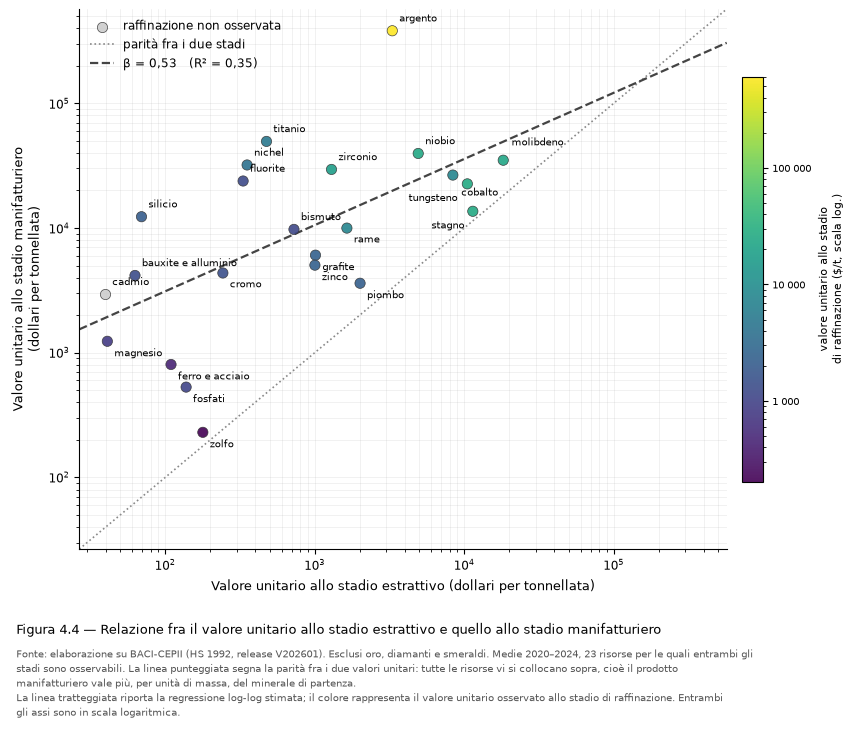

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_4_4_moltiplicatore.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_4_4_moltiplicatore.png')

In [37]:
# %% CELLA F4.4 — Figura 4.4: valore unitario a monte e a valle
# Si stima la relazione diretta fra i due valori unitari anziché quella fra il
# loro rapporto e il denominatore: quest'ultima sarebbe in parte meccanica,
# poiché log(M/U) = log(M) − log(U) contiene già la variabile esplicativa con
# segno negativo, e restituirebbe pendenza −1 anche in assenza di legame.
from matplotlib.colors import LogNorm

assert "W" in globals(), "Esegui prima la cella U5 (definisce W)"
assert "_nome" in globals(), "Esegui prima la cella T1 (definisce _nome)"

MOLT = W.dropna(subset=["upstream", "manufacturing"]).copy()
lu, lm = np.log(MOLT.upstream.values), np.log(MOLT.manufacturing.values)


def _ols(x, y):
    """Pendenza, intercetta, errore standard della pendenza, R²."""
    b, a = np.polyfit(x, y, 1)
    r = y - (a + b * x)
    s = np.sqrt((r ** 2).sum() / (len(x) - 2) / ((x - x.mean()) ** 2).sum())
    return b, a, s, np.corrcoef(x, y)[0, 1] ** 2


beta, alpha, se, r2 = _ols(lu, lm)
print(f"beta = {beta:.3f}  (e.s. {se:.3f})   R² = {r2:.3f}   n = {len(MOLT)}")
print(f"  ipotesi beta = 0: t = {beta / se:+.2f}")
print(f"  ipotesi beta = 1: t = {(beta - 1) / se:+.2f}   <- il confronto rilevante")
print(f"  elasticità del moltiplicatore: {beta - 1:+.3f}")

# robustezza: senza l'argento, punto estremo
m_ = (MOLT.index != "silver")
b_ns, _, se_ns, r2_ns = _ols(lu[m_], lm[m_])
print(f"senza argento: beta = {b_ns:.3f} (e.s. {se_ns:.3f}), "
      f"t(beta=1) = {(b_ns - 1) / se_ns:+.2f}, R² = {r2_ns:.3f}, n = {m_.sum()}")
print(f"risorse sopra la linea di parità: {(lm > lu).sum()} su {len(MOLT)}")


def _f44(ax):
    # Il colore porta il valore unitario alla raffinazione, dimensione non
    # ricavabile dalle altre due. Le risorse per le quali tale stadio non è
    # osservato ricevono un colore neutro anziché un valore imputato.
    ha_raf = MOLT.refining.notna()
    sc = ax.scatter(MOLT.upstream[ha_raf], MOLT.manufacturing[ha_raf], s=55,
                    c=MOLT.refining[ha_raf], cmap="viridis", norm=LogNorm(),
                    edgecolor="#333333", lw=0.5, alpha=0.9, zorder=3)
    if (~ha_raf).any():
        ax.scatter(MOLT.upstream[~ha_raf], MOLT.manufacturing[~ha_raf], s=55,
                   color="#cccccc", edgecolor="#333333", lw=0.5, alpha=0.9,
                   zorder=3, label="raffinazione non osservata")

    lim = [min(lu.min(), lm.min()) - 0.4, max(lu.max(), lm.max()) + 0.4]
    ax.plot(np.exp(lim), np.exp(lim), color="#888888", lw=1.2, ls=":",
            zorder=1, label="parità fra i due stadi")
    xs = np.linspace(lim[0], lim[1], 50)
    ax.plot(np.exp(xs), np.exp(alpha + beta * xs), color="#444444", lw=1.6,
            ls="--", zorder=2,
            label=f"β = {beta:.2f}".replace(".", ",")
                  + f"   (R² = {r2:.2f})".replace(".", ","))

    # L'etichetta va sopra il punto se questo giace sopra la retta, sotto
    # altrimenti; i punti prossimi al margine destro la ricevono a sinistra,
    # per non sconfinare sulla barra dei colori.
    soglia = np.quantile(lu, 0.88)
    # correzioni manuali
    SPOSTA = {"tungsten":   (-7, -7, "right", "top"),
              "molybdenum": (6,  9,  "left",  "bottom"),
              "cobalt":     (6, -9,  "left",  "top"),
              "tin":        (-6, -7, "right", "top")}

    for nome, xi, yi, lxi, lyi in zip(MOLT.index, MOLT.upstream, MOLT.manufacturing, lu, lm):
        if nome in SPOSTA:
            dx, dy, ha, va = SPOSTA[nome]
        else:
            sopra = lyi >= alpha + beta * lxi
            destra = lxi > soglia
            dx = -5 if destra else 5
            dy = 5 if sopra else -5
            ha = "right" if destra else "left"
            va = "bottom" if sopra else "top"
        ax.annotate(_nome(nome).lower(), (xi, yi), fontsize=7, zorder=4,
                    xytext=(dx, dy), textcoords="offset points", ha=ha, va=va)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(np.exp(lim))
    ax.set_ylim(np.exp(lim))
    ax.set_xlabel("Valore unitario allo stadio estrattivo "
                  "(dollari per tonnellata)", fontsize=9)
    ax.set_ylabel("Valore unitario allo stadio manifatturiero\n"
                  "(dollari per tonnellata)", fontsize=9)
    ax.legend(frameon=False, loc="upper left", fontsize=8.5)
    ax.grid(alpha=0.25, lw=0.5, which="both")

    cb = ax.figure.colorbar(sc, ax=ax, shrink=0.75, pad=0.02)
    cb.set_label("valore unitario allo stadio\ndi raffinazione ($/t, scala log.)",
                 fontsize=8)
    cb.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _num(v)))
    cb.ax.tick_params(labelsize=7.5)


figura(_f44, altezza=5.4, margine_basso=0.6,
       didascalia="Figura 4.4 — Relazione fra il valore unitario allo stadio "
                  "estrattivo e quello allo stadio manifatturiero",
        nota=FONTE + f" Medie 2020–2024, {len(MOLT)} risorse per le quali "
            f"entrambi gli stadi sono osservabili. La linea punteggiata segna la "
            f"parità fra i due valori unitari: tutte le risorse vi si collocano "
            f"sopra, cioè il prodotto manifatturiero vale più, per unità di "
            f"massa, del minerale di partenza.\n"
            f"La linea tratteggiata riporta la regressione log-log stimata; il "
            f"colore rappresenta il valore unitario osservato allo stadio di "
            f"raffinazione. Entrambi gli assi sono in scala logaritmica.",
       out=FIG_DIR / "fig_4_4_moltiplicatore.png")

### U7. Robustezza della stima di F4.4

Due controlli sulla pendenza della Figura 4.4. Con errori standard
robusti all'eteroschedasticità (HC1) la stima risulta più precisa
(errore standard 0,13 anziché 0,16) e la distanza da 1 aumenta
(t = −3,7). Ripetendo la stima escludendo una risorsa alla volta, la
pendenza resta compresa fra 0,47 (senza argento) e 0,58 (senza
silicio), sempre inferiore a 1 in tutti i 23 casi: nessuna risorsa da
sola determina il risultato.

In [38]:
# %% CELLA U7 — robustezza della stima di F4.4
# Errori standard robusti all'eteroschedasticita' (HC1) e stima ripetuta
# escludendo una risorsa alla volta.
assert "MOLT" in globals(), "Esegui prima la cella F4.4"

n_r = len(lu)
res = lm - (alpha + beta * lu)                  # residui della stima di F4.4
X = np.column_stack([np.ones(n_r), lu])
XtX_inv = np.linalg.inv(X.T @ X)
meat = X.T @ (X * (res ** 2)[:, None])
se_hc1 = np.sqrt((XtX_inv @ meat @ XtX_inv)[1, 1] * n_r / (n_r - 2))

loo = pd.Series([np.polyfit(np.delete(lu, i), np.delete(lm, i), 1)[0]
                 for i in range(n_r)], index=MOLT.index)

print(f"beta = {beta:.3f} | e.s. classico {se:.3f} | e.s. robusto HC1 {se_hc1:.3f}")
print(f"ipotesi beta = 1: t classico {(beta - 1) / se:+.2f} | t robusto {(beta - 1) / se_hc1:+.2f}")
print(f"beta escludendo una risorsa alla volta: da {loo.min():.3f} ({_nome(loo.idxmin())}) "
      f"a {loo.max():.3f} ({_nome(loo.idxmax())})")
print(f"escludendo ciascuna risorsa, beta resta sotto 1 in {(loo < 1).sum()}/{n_r} casi")

beta = 0.531 | e.s. classico 0.156 | e.s. robusto HC1 0.127
ipotesi beta = 1: t classico -3.00 | t robusto -3.71
beta escludendo una risorsa alla volta: da 0.467 (Argento) a 0.583 (Silicio)
escludendo ciascuna risorsa, beta resta sotto 1 in 23/23 casi


### T4.6 Tabella 4.6 — Il moltiplicatore del valore unitario

Le sei risorse con il moltiplicatore più alto e le sei con il più
basso fra le 23 con entrambi gli stadi (da `W`, cella U5). In cima
silicio (177 volte), argento (116) e titanio (104); in fondo stagno
(1,2), zolfo (1,3), piombo (1,8) e molibdeno (1,9). La mediana è 8,
la media 36: pochi casi estremi spostano la media verso l'alto. Il
rapporto confronta prezzi impliciti di merci fisicamente diverse e
non va letto come valore aggiunto.

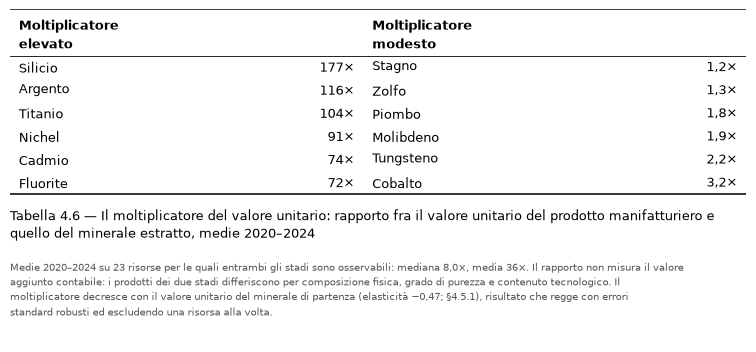

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_4_6_moltiplicatore.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_4_6_moltiplicatore.png')

In [39]:
# %% CELLA T4.6 — il moltiplicatore del valore unitario
# Richiede W (cella U5), _nome (cella T1) e, per la nota, beta (cella F4.4).
assert "W" in globals(), "Esegui prima la cella U5 (definisce W)"
assert "_nome" in globals(), "Esegui prima la cella T1 (definisce _nome)"


def _x(v):
    return (_num(v) if v >= 10 else _num(v, 1)) + "×"


sc = W.scarto.dropna()
k = min(6, len(sc) // 2)                 # le due metà non devono sovrapporsi
alti = sc.nlargest(k)
bassi = sc.nsmallest(k)

nota = (f"Medie 2020–2024 su {len(sc)} risorse per le quali entrambi gli stadi "
        f"sono osservabili: mediana {_x(sc.median())}, media {_x(sc.mean())}. "
        f"Il rapporto non misura il valore aggiunto contabile: i prodotti dei due "
        f"stadi differiscono per composizione fisica, grado di purezza e "
        f"contenuto tecnologico.")
if "beta" in globals():
    el = f"{beta - 1:.2f}".replace(".", ",").replace("-", "\u2212")
    nota += (f" Il moltiplicatore decresce con il valore unitario del minerale "
             f"di partenza (elasticità {el}; §4.5.1), risultato che regge con "
             f"errori standard robusti ed escludendo una risorsa alla volta.")

tabella(
    [(_nome(ra), _x(va), _nome(rb), _x(vb))
     for (ra, va), (rb, vb) in zip(alti.items(), bassi.items())],
    ["Moltiplicatore\nelevato", "", "Moltiplicatore\nmodesto", ""],
    [0.32, 0.16, 0.32, 0.20],
    didascalia="Tabella 4.6 — Il moltiplicatore del valore unitario: rapporto fra "
               "il valore unitario del prodotto manifatturiero e quello del "
               "minerale estratto, medie 2020–2024",
    nota=nota,
    allinea=["l", "r", "l", "r"],
    out=FIG_DIR / "tab_4_6_moltiplicatore.png")

### T4.7 Tabella 4.7 — Il riciclo come input

Peso del rottame sul totale degli input commerciati (minerale più
rottame), sulle 12 risorse per le quali sono osservati sia lo stadio
estrattivo sia quello del riciclo: alluminio, rame, ferro e acciaio,
piombo, magnesio, molibdeno, nichel, fosfati, argento, stagno,
tungsteno, zinco. La restrizione è necessaria: per minerali senza
rottame (potassio, carbone, calcare e altri) il denominatore
includerebbe input privi di alternativa secondaria, abbassando la
quota in modo meccanico (su tutte le risorse la quota sarebbe del
24,5% nel 1995 e del 17,5% nel 2024).

Sulle risorse confrontabili il rottame vale il 41,9% dell'input
commerciato nel 1995 e il 26,7% nel 2024. Il calo non dipende dalla
composizione ma dal fatto che il commercio di minerale cresce molto più
di quello di rottame: da 29 a 345 miliardi di dollari il primo, da 21 a
126 il secondo. Il risultato non dipende dai fosfati, il cui "riciclo"
consiste in concimi organici e scorie più che in rottami: escludendoli,
la quota passa dal 43,0% al 26,8%. Il commercio internazionale di
rottame non misura tuttavia il riciclo complessivo, perché una quota
rilevante della produzione secondaria avviene entro i confini
nazionali.

risorse con estrazione e riciclo: 12
Bauxite e alluminio, Rame, Ferro e acciaio, Piombo, Magnesio, Molibdeno, Nichel, Fosfati, Argento, Stagno, Tungsteno, Zinco

quota del rottame sull'input (%):
      tutte le risorse  con entrambi gli stadi
year                                          
1995              24.5                    41.9
2005              23.0                    37.5
2015              19.9                    31.2
2024              17.5                    26.7


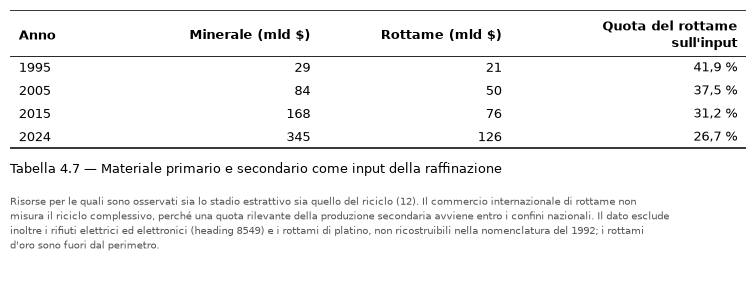

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_4_7_riciclo.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_4_7_riciclo.png')

In [40]:
# %% CELLA T4.7 — il riciclo come input
# Il confronto e' ristretto alle risorse che hanno sia lo stadio estrattivo sia
# quello del riciclo: per minerali senza rottame (fosfati, potassio, carbone,
# calcare...) il denominatore includerebbe input che non hanno alternativa
# secondaria, abbassando la quota in modo meccanico.
st_ris = DI.groupby("resource", observed=True).stage_name.agg(set)
CON_RIC = sorted(r for r, s in st_ris.items() if {"upstream", "recycling"} <= s)


def _quota_ric(df):
    t = (df[df.stage_name.isin(["upstream", "recycling"])]
         .groupby(["year", "stage_name"], observed=True).value.sum().unstack() / 1e6)
    t["quota"] = 100 * t.recycling / (t.upstream + t.recycling)
    return t


RIC_TUTTE = _quota_ric(DI)
RIC = _quota_ric(DI[DI.resource.isin(CON_RIC)])

print(f"risorse con estrazione e riciclo: {len(CON_RIC)}")
print(", ".join(_nome(r) for r in CON_RIC))
print("\nquota del rottame sull'input (%):")
print(pd.DataFrame({"tutte le risorse": RIC_TUTTE.quota,
                    "con entrambi gli stadi": RIC.quota})
      .loc[[1995, 2005, 2015, 2024]].round(1).to_string())

tabella(
    [(str(y), _num(RIC.upstream[y]), _num(RIC.recycling[y]), _pct(RIC.quota[y]))
     for y in [1995, 2005, 2015, 2024]],
    ["Anno", "Minerale (mld $)", "Rottame (mld $)", "Quota del rottame\nsull'input"],
    [0.16, 0.26, 0.26, 0.32],
    didascalia="Tabella 4.7 — Materiale primario e secondario come input "
               "della raffinazione",
    nota=f"Risorse per le quali sono osservati sia lo stadio estrattivo sia "
         f"quello del riciclo ({len(CON_RIC)}). Il commercio internazionale di "
         f"rottame non misura il riciclo complessivo, perché una quota rilevante "
         f"della produzione secondaria avviene entro i confini nazionali. Il dato "
         f"esclude inoltre i rifiuti elettrici ed elettronici (heading 8549) e i "
         f"rottami di platino, non ricostruibili nella nomenclatura del 1992; i "
         f"rottami d'oro sono fuori dal perimetro.",
    allinea=["l", "r", "r", "r"],
    out=FIG_DIR / "tab_4_7_riciclo.png")

### U2a. Figura A.1 — Valore unitario per stadio

Serie annuale 1995–2024 del valore unitario per stadio (valore totale
su quantità totale), senza ferro e acciaio e carbone metallurgico: nella
serie completa questi materiali dominano il tonnellaggio di estrazione
e manifattura, e raffinazione e manifattura risulterebbero quasi
sovrapposte (cella U1). Senza di essi gli stadi si ordinano lungo la
filiera: nel 2024 il valore unitario è di circa 300 dollari per
tonnellata in estrazione, 1.900 in raffinazione e 3.200 in manifattura,
con il riciclo in posizione intermedia (2.600). Tutti gli stadi
crescono nel periodo e seguono gli stessi cicli dei prezzi delle
materie prime.

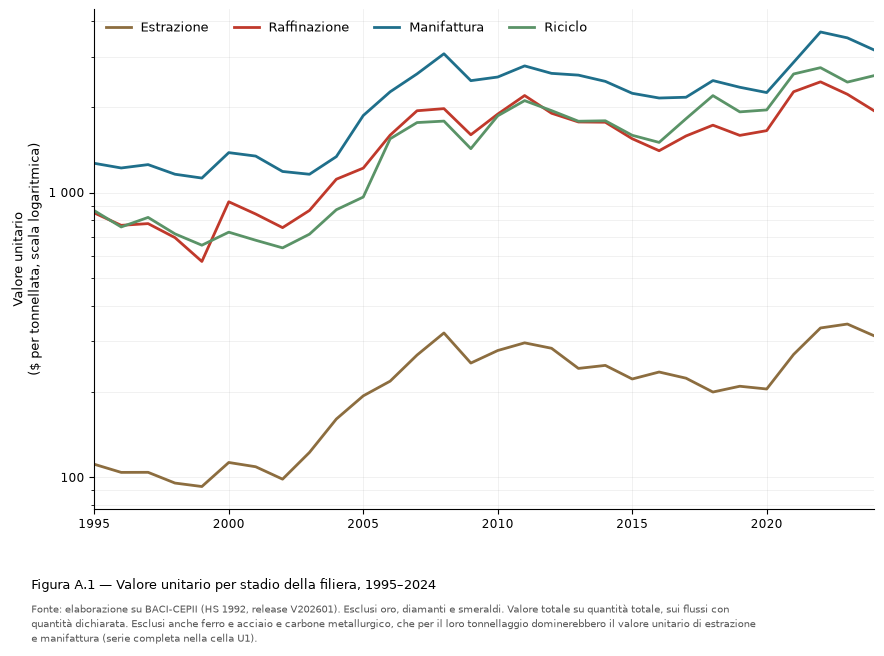

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_A1_uv_stadio.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_A1_uv_stadio.png')

In [41]:
# %% CELLA U2a — valore unitario per stadio
# Si mostra la serie senza ferro, acciaio e carbone metallurgico (UVP_x, cella
# U1): nella serie completa questi materiali, pesanti e poco costosi, dominano
# il tonnellaggio di estrazione e manifattura e rendono raffinazione e
# manifattura quasi indistinguibili.
assert "UVP_x" in globals(), "Esegui prima la cella U1 (definisce UVP_x)"


def _u2a(ax):
    for st in STAGES:
        ax.plot(UVP_x.index, UVP_x[st], lw=2, color=COL_ST[st], label=LBL_ST[st])
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _num(v)))
    ax.yaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_ylabel("Valore unitario\n($ per tonnellata, scala logaritmica)", fontsize=9)
    ax.set_xlim(1995, 2024)
    ax.legend(frameon=False, ncol=4, fontsize=9, loc="upper left")
    ax.grid(alpha=0.25, lw=0.5, which="both")


figura(_u2a,
       didascalia="Figura A.1 — Valore unitario per stadio della filiera, 1995–2024",
       nota=FONTE + " Valore totale su quantità totale, sui flussi con quantità "
                    "dichiarata. Esclusi anche ferro e acciaio e carbone "
                    "metallurgico, che per il loro tonnellaggio dominerebbero il "
                    "valore unitario di estrazione e manifattura (serie completa "
                    "nella cella U1).",
       out=FIG_DIR / "fig_A1_uv_stadio.png")

### U2b. Figura A.2 — Quote di valore e di quantità per stadio

Peso di ciascuno stadio sul valore e sulle tonnellate commerciate,
1995–2024 (flussi con quantità dichiarata). Le due misure divergono
nettamente: l'estrazione pesa l'80,1% delle tonnellate nel 2024 ma il
31,3% del valore; manifattura e raffinazione, insieme, pesano il 16,5%
delle tonnellate ma il 62,1% del valore. Le quote di quantità
dell'estrazione riflettono in larga parte il tonnellaggio di minerale
di ferro e carbone metallurgico.

| stadio | valore 1995 | valore 2024 | quantità 1995 | quantità 2024 |
|---|---|---|---|---|
| estrazione | 18,7% | 31,3% | 71,3% | 80,1% |
| raffinazione | 30,3% | 27,4% | 10,5% | 7,3% |
| manifattura | 44,8% | 34,7% | 14,0% | 9,2% |
| riciclo | 6,2% | 6,6% | 4,2% | 3,4% |

Nel tempo la composizione si sposta verso monte: la quota di valore
dell'estrazione sale di 12,6 punti, quella della manifattura ne perde
10,1, mentre la raffinazione cala di 2,9 punti e il riciclo resta
stabile intorno al 6–7%. Non si tratta di un arretramento della
manifattura, che in valore assoluto cresce da 152 a 659 miliardi di
dollari (4,3 volte, +5,2% l'anno), ma della crescita ancora più rapida
del commercio di minerale, che passa da 64 a 595 miliardi (9,4 volte,
+8,0% l'anno), trainata in larga parte dalle importazioni cinesi: la
quota cinese delle importazioni mondiali di minerale sale nello stesso
periodo dal 3,7% al 47,0% (cella 12).

quota di valore (%):
stage_name  upstream  refining  manufacturing  recycling
year                                                    
1995            18.7      30.3           44.8        6.2
2005            21.7      29.9           41.8        6.5
2015            26.8      30.0           36.6        6.6
2024            31.3      27.4           34.7        6.6

quota di quantità (%):
stage_name  upstream  refining  manufacturing  recycling
year                                                    
1995            71.3      10.5           14.0        4.2
2005            71.4       9.8           14.0        4.8
2015            78.5       7.6           10.4        3.5
2024            80.1       7.3            9.2        3.4


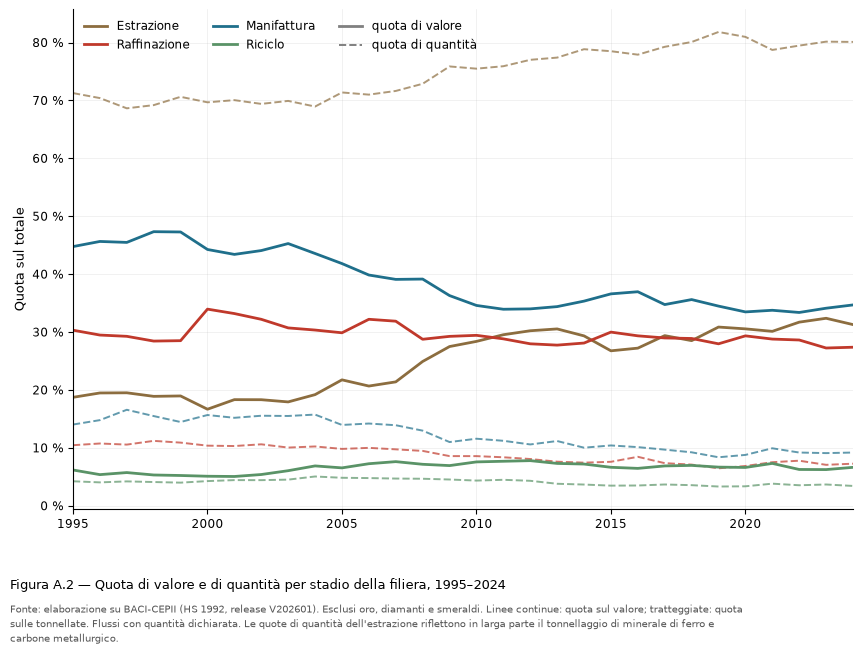

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_A2_quote_valore_quantita.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_A2_quote_valore_quantita.png')

In [42]:
# %% CELLA U2b — quote di valore e di quantità per stadio
from matplotlib.lines import Line2D

QV = UV.pivot(index="year", columns="stage_name", values="valore_mld")[STAGES]
QQ = UV.pivot(index="year", columns="stage_name", values="qta_mln_t")[STAGES]
QV = 100 * QV.div(QV.sum(axis=1), axis=0)
QQ = 100 * QQ.div(QQ.sum(axis=1), axis=0)

print("quota di valore (%):")
print(QV.loc[[1995, 2005, 2015, 2024]].round(1).to_string())
print("\nquota di quantità (%):")
print(QQ.loc[[1995, 2005, 2015, 2024]].round(1).to_string())


def _u2b(ax):
    for st in STAGES:
        ax.plot(QV.index, QV[st], lw=2, color=COL_ST[st], label=LBL_ST[st])
        ax.plot(QQ.index, QQ[st], lw=1.4, ls="--", color=COL_ST[st], alpha=0.7)
    h, l = ax.get_legend_handles_labels()
    h += [Line2D([0], [0], color="grey", lw=2),
          Line2D([0], [0], color="grey", lw=1.4, ls="--")]
    l += ["quota di valore", "quota di quantità"]
    ax.legend(h, l, frameon=False, ncol=3, fontsize=8.5, loc="upper left")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _pct(v, 0)))
    ax.set_ylabel("Quota sul totale", fontsize=9)
    ax.set_xlim(1995, 2024)


figura(_u2b,
       didascalia="Figura A.2 — Quota di valore e di quantità per stadio della "
                  "filiera, 1995–2024",
       nota=FONTE + " Linee continue: quota sul valore; tratteggiate: quota sulle "
                    "tonnellate. Flussi con quantità dichiarata. Le quote di "
                    "quantità dell'estrazione riflettono in larga parte il "
                    "tonnellaggio di minerale di ferro e carbone metallurgico.",
       out=FIG_DIR / "fig_A2_quote_valore_quantita.png")

### U3 Indice di posizionamento a valle per paese (2020–2024)

Per ogni paese l'indice è la media dei pesi degli stadi, ponderata con il
valore esportato. I pesi sono estrazione 0, raffinazione 0,5, manifattura 1 e
riciclo 0. Il valore esportato è la media annua del periodo 2020–2024. L'indice
va da 0 (paniere solo estrattivo) a 1 (paniere solo manifatturiero).

**I primi esportatori.** La Cina è prima sia per posizionamento (0,87) sia,
dopo l'Australia, per valore esportato (186 mld $ l'anno). Il 77% del suo
paniere è manifatturiero e solo il 2,4% è estrattivo. Seguono Corea del Sud
(0,82), Giappone (0,76) e Germania (0,70), tutti con una quota estrattiva
sotto il 5%. All'estremo opposto c'è l'Australia: è il primo esportatore in
assoluto (204 mld $ l'anno), ma ha un indice di 0,06 e l'87,7% del paniere
nello stadio estrattivo.

**Gli esportatori a monte.** Tra i primi 40 esportatori, i più a monte dopo
l'Australia sono Colombia (0,11), Perù (0,12), Indonesia (0,19) e Brasile
(0,21). Il Cile (0,24) è un caso intermedio. Il 52,8% del paniere è
estrattivo, ma il 45,6% è raffinato, perché il paese esporta sia concentrati
sia catodi di rame. Per questo il suo valore unitario (1.656 $/t) è il più
alto tra i primi 15 esportatori, sopra quello della Cina (1.253 $/t).

**Stati Uniti e Russia** hanno un indice simile (0,43). La loro composizione
è più bilanciata: circa un terzo del paniere estrattivo, un quarto o un terzo
raffinato, un quarto o un terzo manifatturiero.

**Robustezza al peso della raffinazione.** Il peso 0,5 è una scelta
convenzionale. Si è ricalcolato l'indice assegnando alla raffinazione
peso 0 (conta solo la manifattura) e peso 1 (raffinazione e manifattura
equivalenti). Sui primi 40 esportatori la correlazione di rango con lo
schema di base è 0,944 nel primo caso e 0,838 nel secondo; su tutti i
206 paesi è rispettivamente 0,887 e 0,924. In entrambi i casi la
classifica cambia poco. Lo schema meno stabile dipende dall'insieme
considerato: fra i grandi esportatori pesa di più il caso
raffinazione = 1, che fa salire i paesi con molta raffinazione e poca
manifattura come Kazakistan, SACU e Cile.

Il caso più sensibile è la Repubblica Democratica del Congo, che ha il 90,6%
delle esportazioni nella raffinazione. Il suo indice passa da circa 0,00
(raffinazione = 0) a circa 0,91 (raffinazione = 1), contro 0,46 nello schema
di base. Per i paesi specializzati nella raffinazione la posizione sull'asse
va quindi letta insieme alla composizione del paniere.

In [43]:
# %% CELLA U3 — indice di posizionamento a valle
# L'indice misura la composizione del paniere esportato, non il valore aggiunto:
# un paese che assembla prodotti con input importati ottiene valori elevati
# anche se la trasformazione domestica e' modesta.
ANNI_IDX = range(2020, 2025)
PESI_IDX = {"upstream": 0.0, "refining": 0.5, "manufacturing": 1.0, "recycling": 0.0}
MIN_EXPORT_K = 1_000          # esportatori con almeno 1 milione $ nel periodo


def indice_downstream(anni=ANNI_IDX, min_k=MIN_EXPORT_K, pesi=PESI_IDX):
    d = DI[DI.year.isin(anni)]
    comp = d.groupby(["exp", "stage_name"], observed=True).value.sum().unstack(fill_value=0)
    tot = comp.sum(axis=1)
    q = comp.div(tot, axis=0)

    u = (D_uv[D_uv.year.isin(anni)].groupby("exp")
         .agg(v=("value", "sum"), t=("qty", "sum")))

    I = pd.DataFrame(index=comp.index)
    I["paese"] = [ISO.get(int(c), str(c)) for c in comp.index]
    I["export_mld_anno"] = tot / 1e6 / len(anni)          # media annua
    I["uv_paniere"] = (u.v * 1000 / u.t).reindex(comp.index)
    for s in STAGES:
        I[f"q_{s}"] = q[s] if s in q.columns else 0.0
    I["indice"] = sum(pesi[s] * I[f"q_{s}"] for s in STAGES)
    return I[tot >= min_k].sort_values("indice", ascending=False)


IDX = indice_downstream()
IDX.to_csv(OUT_DIR / "indice_downstream.csv")

COLS = ["paese", "export_mld_anno", "uv_paniere", "q_upstream", "q_refining",
        "q_manufacturing", "indice"]
print("posizionamento a valle — primi 15 esportatori per valore, media 2020-2024:")
print(IDX.nlargest(15, "export_mld_anno").sort_values("indice", ascending=False)
      [COLS].round(3).to_string(index=False))

print("\ni piu' a monte fra i primi 40 esportatori:")
print(IDX.nlargest(40, "export_mld_anno").nsmallest(10, "indice")
      [COLS].round(3).to_string(index=False))

# robustezza: la classifica dei primi 40 esportatori dipende dal peso della raffinazione?
top40 = IDX.nlargest(40, "export_mld_anno").index
for nome, w_ref in [("raffinazione = 0", 0.0), ("raffinazione = 1", 1.0)]:
    alt = indice_downstream(pesi={**PESI_IDX, "refining": w_ref})
    rho = IDX.loc[top40, "indice"].rank().corr(alt.loc[top40, "indice"].rank())
    print(f"correlazione di rango con lo schema {nome}: {rho:.3f}")

posizionamento a valle — primi 15 esportatori per valore, media 2020-2024:
paese  export_mld_anno  uv_paniere  q_upstream  q_refining  q_manufacturing  indice
  CHN          185.961    1252.586       0.024       0.200            0.770   0.870
  KOR           48.220    1407.021       0.026       0.256            0.696   0.824
  JPN           65.528    1068.110       0.008       0.267            0.623   0.756
  DEU           86.227    1414.568       0.047       0.249            0.577   0.701
  BLX           36.610    1100.200       0.049       0.362            0.479   0.660
  IND           32.832     353.513       0.170       0.456            0.359   0.587
  NLD           32.269     939.574       0.084       0.375            0.344   0.532
  USA          101.117     580.268       0.273       0.215            0.326   0.434
  RUS           94.751     330.068       0.368       0.374            0.244   0.431
 SACU           62.237     319.087       0.444       0.483            0.060   0.301
 

### Figura A.3 — Posizionamento dei principali esportatori nella filiera (2020–2024)

La figura incrocia l'indice di posizionamento a valle (asse orizzontale) con
il valore unitario del paniere esportato (asse verticale, in scala
logaritmica), per i 35 paesi con il maggior valore esportato.

- La **dimensione del punto** indica il valore esportato medio annuo. La scala
  si basa sulla radice del valore. I tre valori in legenda (21, 32 e
  91 mld $ l'anno) corrispondono al 25°, 60° e 90° percentile dei paesi
  selezionati.
- Il **colore** indica la quota delle esportazioni nello stadio estrattivo.

**Lettura.** Si distinguono tre gruppi.

1. **In basso a sinistra** ci sono gli esportatori di materie prime sfuse:
   Australia, Colombia, Brasile e Indonesia. Hanno un indice sotto 0,22,
   una quota estrattiva tra il 66% e l'88% e valori unitari intorno o sotto
   i 180 $/t.

2. **A destra** ci sono le economie manifatturiere: Cina, Corea del Sud,
   Giappone e Germania. Hanno un indice tra 0,70 e 0,87 e valori unitari tra
   1.070 e 1.410 $/t.

3. **In alto, al centro** c'è la Repubblica Democratica del Congo, con il
   valore unitario più alto del campione (6.755 $/t). Il 90,6% del suo paniere
   è nello stadio di raffinazione, cioè catodi di rame e prodotti intermedi
   del cobalto, mentre la quota estrattiva è solo l'8,8%. L'indice resta a
   metà scala (0,46) perché la raffinazione pesa 0,5. Più in basso, il Cile
   (indice 0,24) esporta a 1.656 $/t, più della Cina, con un paniere diviso
   tra concentrati (52,8%) e catodi di rame (45,6%).

La relazione tra posizionamento a valle e valore unitario quindi **non è
monotona**. Il valore per tonnellata dipende dalla risorsa esportata più che
dallo stadio. I paesi specializzati nel rame e nel cobalto raffinati, o nei
loro concentrati, superano per valore unitario le economie manifatturiere,
il cui paniere pesa di più verso acciaio e alluminio.

*L'indice misura la composizione del paniere esportato, non il valore aggiunto
interno: un paese può esportare manifatturiero ottenuto da materia prima
importata. Il peso della raffinazione è convenzionale; la cella U3 ne verifica
la robustezza.*

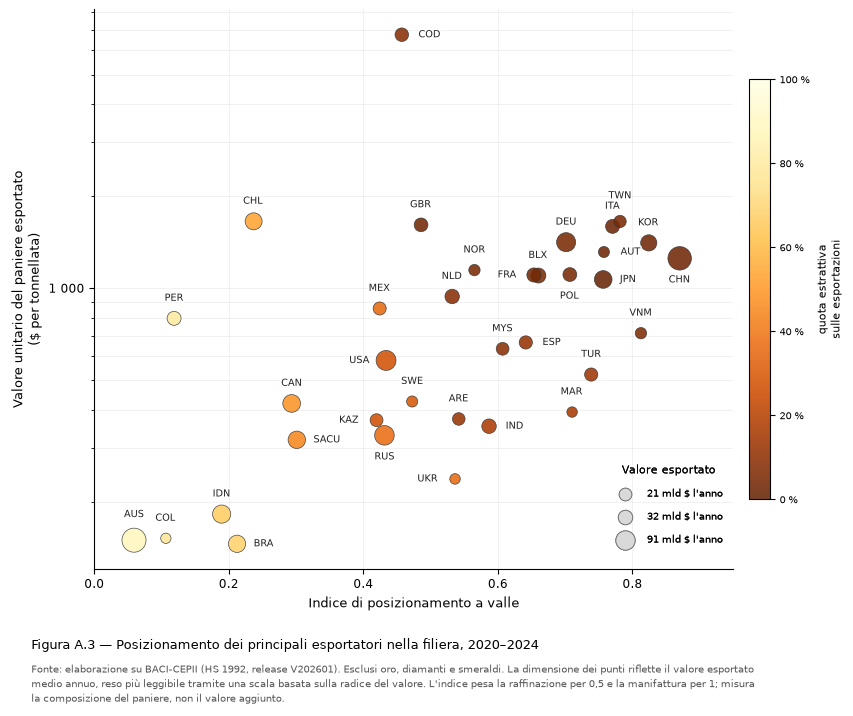

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_A3_posizionamento_paesi.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_A3_posizionamento_paesi.png')

In [44]:
# %% CELLA U4 — figura: posizionamento dei paesi
import matplotlib.patheffects as pe
from matplotlib.transforms import Bbox

SEL = IDX.nlargest(35, "export_mld_anno").copy()

# Direzione preferita dell'etichetta rispetto al punto, per i casi più
# delicati. L'algoritmo prova prima questa soluzione e, se collide con altre
# etichette o con i pallini, passa a posizioni alternative vicine.
# (dx, dy) in punti tipografici.
SPOSTA_A3 = {
    "AUS":  (0, -13), "COL": (14, 4),
    "RUS":  (0, -13), "KAZ": (-14, 2), "SACU": (-16, -4),
    "POL":  (12, 4),  "FRA": (-13, 3),
    "ITA":  (-12, 3), "TWN": (12, 4), "KOR": (13, 3), "AUT": (0, -13),
    "IND":  (0, -13), "ARE": (-13, 3), "ESP": (12, 4), "MYS": (-14, 2),
    "CHN":  (-14, 3),
}

# Posizioni candidate attorno al punto: prima si prova quella manuale
# eventualmente indicata sopra, poi un ventaglio di alternative vicine.
CANDIDATI_A3 = [
    (0, 11), (10, 8), (-10, 8), (12, 0), (-12, 0), (0, -12),
    (14, 10), (-14, 10), (14, -10), (-14, -10),
    (0, 15), (16, 4), (-16, 4), (0, -16),
    (18, 12), (-18, 12), (18, -12), (-18, -12)
]


def _allinea(dx, dy):
    ha = "left" if dx > 3 else ("right" if dx < -3 else "center")
    va = "bottom" if dy > 3 else ("top" if dy < -3 else "center")
    return ha, va


def _scala_size(v):
    """Trasforma il valore esportato medio annuo nella superficie del marcatore.
    Si usa la radice del valore esportato, ma la si normalizza su un intervallo
    piu' ampio per rendere la differenza visivamente leggibile."""
    rad = np.sqrt(v)
    rmin, rmax = np.sqrt(SEL.export_mld_anno).min(), np.sqrt(SEL.export_mld_anno).max()
    return 55 + (rad - rmin) / (rmax - rmin + 1e-9) * 245


def _bbox_punto(ax, x, y, s):
    """Riquadro di ingombro del pallino in coordinate schermo, con un piccolo
    margine addizionale per evitare che il testo gli si appoggi troppo."""
    xp, yp = ax.transData.transform((x, y))
    r_pt = np.sqrt(s / np.pi)
    r_px = r_pt * ax.figure.dpi / 72.0 + 3.0
    return Bbox.from_extents(xp - r_px, yp - r_px, xp + r_px, yp + r_px)


def _dentro_assi(bb, bb_ax, margine=2):
    return (bb.x0 >= bb_ax.x0 + margine and bb.x1 <= bb_ax.x1 - margine
            and bb.y0 >= bb_ax.y0 + margine and bb.y1 <= bb_ax.y1 - margine)


def _sovrapposto(bb, occupati, pad=1.5):
    bb_pad = Bbox.from_extents(bb.x0 - pad, bb.y0 - pad, bb.x1 + pad, bb.y1 + pad)
    return any(bb_pad.overlaps(o) for o in occupati)


def _piazza_etichette(ax, dati, sizes):
    """Piazza le etichette in modo greedy: per ciascun paese prova una serie
    di posizioni vicine al pallino e sceglie la prima che non collide né con
    etichette già scritte né con i marcatori."""
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    bb_ax = ax.get_window_extent(renderer=renderer)

    occupati = []
    for (_, r), s in zip(dati.iterrows(), sizes):
        occupati.append(_bbox_punto(ax, r.indice, r.uv_paniere, s))

    ann = []

    # Prima i punti più grandi: sono i più importanti e i più difficili da
    # etichettare bene senza collisioni.
    ordine = dati.assign(_size=sizes).sort_values("_size", ascending=False)

    for _, r in ordine.iterrows():
        base = SPOSTA_A3.get(r.paese)
        prove = ([base] if base is not None else []) \
              + [p for p in CANDIDATI_A3 if p != base]

        score_scelta = None
        ann_scelta = None
        bb_scelta = None

        for dx, dy in prove:
            ha, va = _allinea(dx, dy)

            a = ax.annotate(r.paese, (r.indice, r.uv_paniere),
                            fontsize=7, color="#222222",
                            xytext=(dx, dy), textcoords="offset points",
                            ha=ha, va=va, zorder=5,
                            path_effects=[
                                pe.withStroke(linewidth=2.2, foreground="white")
                            ])

            bb = a.get_window_extent(renderer=renderer)

            # Penalizza le soluzioni fuori dagli assi o in collisione, ma se
            # nessuna è perfetta conserva comunque la meno problematica.
            penalita = 0
            if not _dentro_assi(bb, bb_ax):
                penalita += 10
            penalita += 100 * sum(bb.overlaps(o) for o in occupati)
            penalita += 0.02 * (abs(dx) + abs(dy))

            if penalita == 0:
                if ann_scelta is not None:
                    ann_scelta.remove()
                ann_scelta = a
                bb_scelta = bb
                break

            if score_scelta is None or penalita < score_scelta:
                if ann_scelta is not None:
                    ann_scelta.remove()
                score_scelta = penalita
                ann_scelta = a
                bb_scelta = bb
            else:
                a.remove()

        occupati.append(bb_scelta)
        ann.append(ann_scelta)

    return ann


def _legenda_size(ax):
    """Legenda della grandezza dei pallini. I tre valori sono scelti sui
    quantili della distribuzione del valore esportato medio annuo."""
    qs = SEL.export_mld_anno.quantile([0.25, 0.60, 0.90]).to_numpy()
    vals = np.unique(np.round(qs, 1))
    handles = [
        ax.scatter([], [], s=_scala_size(v), facecolor="#d9d9d9",
                   edgecolor="#666666", lw=0.6, alpha=0.9)
        for v in vals
    ]
    labels = [f"{_num(v)} mld $ l'anno" for v in vals]

    leg = ax.legend(handles, labels, title="Valore esportato",
                    scatterpoints=1, frameon=False, fontsize=7.5,
                    title_fontsize=8, loc="lower right",
                    bbox_to_anchor=(0.995, 0.03), labelspacing=1.2,
                    handletextpad=1.1, borderpad=0.2)
    return leg


def _u4(ax):
    sizes = _scala_size(SEL.export_mld_anno)

    sc = ax.scatter(SEL.indice, SEL.uv_paniere, s=sizes,
                    c=100 * SEL.q_upstream, cmap="YlOrBr_r", vmin=0, vmax=100,
                    edgecolor="#333333", lw=0.5, alpha=0.88, zorder=3)

    _piazza_etichette(ax, SEL, sizes)
    leg = _legenda_size(ax)
    ax.add_artist(leg)

    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _num(v)))
    ax.yaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_xlim(0.0, 0.95)
    ax.set_xlabel("Indice di posizionamento a valle", fontsize=9)
    ax.set_ylabel("Valore unitario del paniere esportato\n($ per tonnellata)", fontsize=9)
    ax.grid(alpha=0.25, lw=0.5, which="both")

    cb = ax.figure.colorbar(sc, ax=ax, shrink=0.75, pad=0.02)
    cb.set_label("quota estrattiva\nsulle esportazioni", fontsize=8)
    cb.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: _pct(v, 0)))
    cb.ax.tick_params(labelsize=7.5)


figura(_u4, altezza=5.6, margine_dx=0.35,
       didascalia="Figura A.3 — Posizionamento dei principali esportatori nella "
                  "filiera, 2020–2024",
       nota=FONTE + " La dimensione dei punti riflette il valore esportato medio "
                    "annuo, reso più leggibile tramite una scala basata sulla "
                    "radice del valore. L'indice pesa la raffinazione per 0,5 e la "
                    "manifattura per 1; misura la composizione del paniere, "
                    "non il valore aggiunto.",
       out=FIG_DIR / "fig_A3_posizionamento_paesi.png")

### CAPITOLO 5

### R2. Costruzione dei grafi

La funzione `rete` trasforma i legami attivi della cella 9 (`FL`) in un
grafo diretto e pesato: i nodi sono i paesi (con i nodi ricostruiti della
cella 3), un arco va dall'esportatore all'importatore e il suo peso è il
valore scambiato. Si usa la stessa definizione di legame dei modelli di
formazione e cessazione, così che l'analisi della struttura e quella della
dinamica descrivano la stessa rete. La funzione permette di restringere
la rete ad anni, risorse o stadi, e di costruire un grafo per stadio.

Senza restrizioni sugli anni la rete somma l'intero periodo 1995–2024: un
arco è una coppia di paesi con un legame attivo in almeno un anno, e il
peso è il valore cumulato in dollari correnti. Su questa base:

| rete | paesi | legami |
|---|---|---|
| aggregata | 216 | 12.903 |
| estrazione | 207 | 6.739 |
| raffinazione | 207 | 7.907 |
| manifattura | 213 | 9.386 |
| riciclo | 203 | 4.739 |

La rete aggregata vale 32.215 miliardi di dollari cumulati e ha una
densità di 0,28 (12.903 legami su 46.440 coppie ordinate possibili). La
somma dei legami per stadio (28.771) supera quella della rete aggregata
perché la stessa coppia di paesi può scambiare in più stadi. I grafi per
stadio sono salvati in `graphs_country.pkl`. Un controllo finale verifica
che nessun codice paese accorpato nella cella 3 compaia come nodo a sé.

In [45]:
# %% CELLA R2 — costruzione dei grafi
# I grafi sono costruiti sui legami attivi (FL), secondo la definizione con
# soglia a isteresi adottata nella cella 9: un legame si attiva a un milione
# di dollari e resta attivo finché il flusso non scende sotto i 100 mila.
# La stessa definizione vale per i modelli di formazione e cessazione, così
# che l'analisi strutturale e quella dinamica descrivano la stessa rete.
# Senza l'argomento anni, la rete somma tutti gli anni 1995-2024: un arco è
# una coppia attiva in almeno un anno, con peso pari al valore cumulato.

def rete(df=None, anni=None, risorse=None, stadi=None, per_stadio=False,
         verbose=False):
    """Grafo diretto pesato dei legami attivi, con etichette ISO.

    df         sorgente (default FL, legami attivi); DI per tutti i flussi
               del perimetro industriale, senza soglia
    anni       sottoinsieme di anni; None = somma 1995-2024
    risorse    sottoinsieme di risorse; None = intero perimetro
    stadi      sottoinsieme di stadi
    per_stadio se True restituisce un dizionario stadio -> grafo
    """
    d = FL if df is None else df
    if anni is not None:
        d = d[d.year.isin(anni)]
    if risorse is not None:
        d = d[d.resource.isin(risorse)]
    if stadi is not None:
        d = d[d.stage_name.isin(stadi)]

    chiavi = (["stage_name"] if per_stadio else []) + ["exp", "imp"]
    e = d.groupby(chiavi, observed=True, as_index=False).value.sum()

    def _g(sub):
        H = nx.DiGraph()
        for a, b, v in zip(sub.exp, sub.imp, sub.value):
            H.add_edge(ISO[a], ISO[b], value=float(v))
        return H

    if per_stadio:
        G = {st: _g(g) for st, g in e.groupby("stage_name", observed=True)}
        if verbose:
            for st in [s for s in STAGES if s in G]:
                print(f"  {st:14s} {G[st].number_of_nodes():4d} nodi  "
                      f"{G[st].number_of_edges():7,d} archi")
        return G

    G = _g(e)
    if verbose:
        print(f"[RETE] {G.number_of_nodes()} paesi, {G.number_of_edges():,} legami, "
              f"{e.value.sum()/1e6:,.0f} mld$")
    return G


G_tot = rete(verbose=True)
graphs = rete(per_stadio=True, verbose=True)

with open(GRAPH_DIR / "graphs_country.pkl", "wb") as f:
    pickle.dump(graphs, f)

resid = {ISO.get(c) for c in MERGE_CODES} & set(G_tot)
assert not resid, f"nodi non accorpati: {resid}"
print("riconciliazione dei nodi verificata")

[RETE] 216 paesi, 12,903 legami, 32,215 mld$
  upstream        207 nodi    6,739 archi
  refining        207 nodi    7,907 archi
  manufacturing   213 nodi    9,386 archi
  recycling       203 nodi    4,739 archi
riconciliazione dei nodi verificata


### R2b. Profilo strutturale della rete

Le misure sono binarie: considerano la presenza di un legame, non il suo
valore. Densità e reciprocità sono calcolate sul grafo diretto; diametro,
distanza media, clustering e assortatività sul grafo non diretto. Poiché
la rete cumulata 1995–2024 conta una coppia di paesi anche se il legame è
attivo un solo anno, il profilo è calcolato anche sulle reti del primo e
dell'ultimo anno (`profilo_strutturale.csv`).

| rete | paesi | legami | densità | distanza media | reciprocità | clustering | clustering / densità | assortatività |
|---|---|---|---|---|---|---|---|---|
| cumulata 1995–2024 | 216 | 12.903 | 0,278 | 1,66 | 0,722 | 0,817 | 2,3 | −0,371 |
| 1995 | 185 | 3.833 | 0,113 | 1,99 | 0,584 | 0,751 | 4,7 | −0,404 |
| 2024 | 205 | 7.138 | 0,171 | 1,82 | 0,691 | 0,780 | 3,5 | −0,393 |
| estrazione 2024 | 177 | 3.119 | 0,100 | 2,02 | 0,483 | 0,620 | 4,1 | −0,291 |
| raffinazione 2024 | 170 | 4.335 | 0,151 | 1,86 | 0,645 | 0,738 | 3,6 | −0,378 |
| manifattura 2024 | 203 | 4.935 | 0,120 | 1,89 | 0,590 | 0,758 | 4,5 | −0,375 |
| riciclo 2024 | 175 | 2.433 | 0,080 | 2,09 | 0,495 | 0,672 | 5,6 | −0,420 |

Il rapporto clustering / densità usa la densità del grafo non diretto,
che corrisponde al clustering atteso in un grafo casuale con lo stesso
numero di legami.

**Rete cumulata e reti annuali.** Dei 12.903 legami attivi in almeno un
anno, 7.138 lo sono nel 2024 (55%). La rete cumulata sovrastima quindi la
densità (0,278 contro 0,171 nel 2024) e, in misura minore, la reciprocità
e il clustering. Le analisi che descrivono la struttura in un dato momento
usano perciò le reti annuali.

**Crescita.** Fra il 1995 e il 2024 i paesi passano da 185 a 205 e i
legami da 3.833 a 7.138 (+86%); la densità sale da 0,113 a 0,171 e la
distanza media scende da 1,99 a 1,82.

**Tre regolarità.** Si mantengono in tutte le reti, cumulate e annuali,
aggregate e per stadio:

1. *Distanze brevi.* Il diametro è 3 o 4 e la distanza media è inferiore
   a 2,1: quasi ogni coppia di paesi è collegata attraverso al più un
   intermediario.
2. *Clustering elevato.* Il clustering medio (0,62–0,82) è da 2,3 a 5,6
   volte quello atteso in un grafo casuale con la stessa densità: i
   partner commerciali di un paese tendono a commerciare anche fra loro.
3. *Disassortatività.* Il coefficiente di assortatività per grado è
   negativo ovunque (da −0,29 a −0,42): i paesi con molti legami
   commerciano soprattutto con paesi che ne hanno pochi, una struttura di
   tipo centro-periferia.

**Differenze fra stadi (2024).** L'estrazione ha la reciprocità più bassa
(0,483): meno della metà dei legami ha un legame di ritorno, coerente con
una filiera in cui i paesi esportatori di minerali importano poco nello
stesso stadio. È anche lo stadio meno disassortativo (−0,29). La
raffinazione è lo stadio più denso (0,151), con meno paesi della
manifattura (170 contro 203) ma una quota maggiore delle coppie possibili
effettivamente attive. Il riciclo è il meno denso (0,080) e il più
disassortativo (−0,42), ma ha il clustering più alto rispetto alla sua
densità (5,6 volte).

In [46]:
# %% CELLA R2b — profilo strutturale, aggregato e per stadio
# Misure binarie (ignorano il valore dei flussi). Densità e reciprocità sono
# calcolate sul grafo diretto; diametro, distanza media, clustering e
# assortatività sul grafo non diretto. La rete cumulata 1995-2024 conta una
# coppia anche se attiva un solo anno: per questo si affiancano le reti
# annuali del primo e dell'ultimo anno.
# clust_rel = clustering / densità non diretta: il clustering atteso in un
# grafo casuale con la stessa densità è pari alla densità stessa.

def _profilo(H, nome):
    u = H.to_undirected()
    conn = nx.is_connected(u)
    d_u = nx.density(u)
    cl = nx.average_clustering(u)
    return {
        "rete": nome,
        "paesi": H.number_of_nodes(),
        "legami": H.number_of_edges(),
        "densita": nx.density(H),
        "densita_nd": d_u,
        "diametro": nx.diameter(u) if conn else np.nan,
        "dist_media": nx.average_shortest_path_length(u) if conn else np.nan,
        "reciprocita": nx.reciprocity(H),
        "clustering": cl,
        "clust_rel": cl / d_u,
        "assortativita": nx.degree_assortativity_coefficient(u),
        "connessa": conn,
    }


_g24 = rete(anni=[2024], per_stadio=True)
righe = [_profilo(G_tot, "aggregata 1995–2024"),
         _profilo(rete(anni=[1995]), "aggregata 1995"),
         _profilo(rete(anni=[2024]), "aggregata 2024")]
righe += [_profilo(graphs[st], f"{st} 1995–2024") for st in STAGES]
righe += [_profilo(_g24[st], f"{st} 2024") for st in STAGES if st in _g24]

PROF = pd.DataFrame(righe).set_index("rete")
PROF.to_csv(OUT_DIR / "profilo_strutturale.csv")

with pd.option_context("display.width", 200, "display.max_columns", None):
    print(PROF.round(3).to_string())
if not PROF.connessa.all():
    print("\nreti non connesse (diametro e distanza media non calcolati):",
          list(PROF.index[~PROF.connessa]))

                         paesi  legami  densita  densita_nd  diametro  dist_media  reciprocita  clustering  clust_rel  assortativita  connessa
rete                                                                                                                                          
aggregata 1995–2024        216   12903    0.278       0.355         3       1.664        0.722       0.817      2.302         -0.371      True
aggregata 1995             185    3833    0.113       0.159         4       1.993        0.584       0.751      4.711         -0.404      True
aggregata 2024             205    7138    0.171       0.223         3       1.820        0.691       0.780      3.492         -0.393      True
upstream 1995–2024         207    6739    0.158       0.224         4       1.885        0.584       0.675      3.015         -0.308      True
refining 1995–2024         207    7907    0.185       0.246         3       1.827        0.672       0.769      3.121         -0.375      True

### R3. Funzioni per il disegno delle reti

Funzioni di sola rappresentazione grafica: non intervengono nel calcolo
degli indicatori.

- `igraph_layout` calcola le posizioni con l'algoritmo DrL di igraph, più
  adatto di quello di networkx a reti dense, perché non comprime la
  periferia. Gli archi sono pesati con il logaritmo del valore e il seme
  casuale è fissato sul generatore interno di igraph, così che il layout
  sia riproducibile.
- `separate` sposta i nodi finché i dischi non si sovrappongono più,
  tenendo conto del rapporto d'aspetto della figura.
- `top_subgraph` restringe la figura ai paesi più grandi, in ordine di
  intensità (esportazioni più importazioni), fino a coprire una quota data
  della somma delle intensità.
- `shared_layout` calcola le posizioni una sola volta sull'unione di più
  grafi, così che i pannelli di una stessa figura (per esempio i quattro
  stadi) mostrino ogni paese nello stesso punto e siano confrontabili.
  La dimensione dei nodi è proporzionale al logaritmo dell'intensità.

In [47]:
# %% CELLA R3 — layout dei grafi
# I layout force-directed posizionano punti, non cerchi: senza correzione i
# nodi grandi finiscono sovrapposti.

def _intensita(H):
    """Esportazioni + importazioni di ogni nodo (somma dei pesi in uscita e
    in entrata)."""
    return {n: sum(d["value"] for _, _, d in H.out_edges(n, data=True))
               + sum(d["value"] for _, _, d in H.in_edges(n, data=True)) for n in H}


def separate(pos, nodes, sizes, pad=1.15, iters=400,
             larghezza_pollici=None, altezza_pollici=None):
    """Allontana i nodi trattandoli come dischi, finché non si toccano più
    (rilassamento a collisioni, O(n²) ma n è piccolo).

    larghezza/altezza_pollici: se fornite, si tiene conto del rapporto
    d'aspetto della tela. Il layout vive in [-1, 1] su entrambi gli assi: su
    una tela larga L e alta A, un'unità verticale vale A/L unità orizzontali.
    Il rilassamento avviene in questo spazio corretto, poi le coordinate sono
    riportate alla scala del layout. Non serve se gli assi hanno
    set_aspect("equal")."""
    if larghezza_pollici and altezza_pollici:
        scala = np.array([1.0, altezza_pollici / larghezza_pollici])
    else:
        scala = np.array([1.0, 1.0])

    Q = np.array([pos[n] for n in nodes], float) * scala
    # node_size è un'area in punti²: il raggio va con la radice; 0.055 porta
    # i raggi nella scala del layout
    R = np.sqrt(np.asarray(sizes, float)) / np.sqrt(max(sizes)) * 0.055 * pad

    for _ in range(iters):
        moved = False
        for i in range(len(Q)):
            d = Q - Q[i]
            dist = np.hypot(d[:, 0], d[:, 1])
            dist[i] = np.inf
            need = R + R[i]
            hit = dist < need
            if not hit.any():
                continue
            moved = True
            for j in np.where(hit)[0]:
                v = Q[j] - Q[i]
                nrm = np.hypot(*v)
                if nrm < 1e-9:
                    v, nrm = np.array([np.cos(j), np.sin(j)]), 1.0
                push = (need[j] - dist[j]) / 2 * 1.02
                Q[i] -= v / nrm * push
                Q[j] += v / nrm * push
        if not moved:
            break
    P = Q / scala
    return {n: P[i] for i, n in enumerate(nodes)}


def igraph_layout(K, algo="drl", seed=42):
    """DrL è pensato per grafi grandi e densi e distribuisce i nodi meglio di
    spring_layout, che comprime la periferia.
    Il seed va fissato sul generatore interno di igraph, che vuole un oggetto
    in stile random.Random: np.random.seed non ha alcun effetto, e senza
    questo ogni esecuzione produce un layout diverso."""
    nodes = list(K.nodes())
    idx = {n: i for i, n in enumerate(nodes)}
    ew = {}
    for u, v, d in K.edges(data=True):
        a, b = idx[u], idx[v]
        key = (min(a, b), max(a, b))
        ew[key] = ew.get(key, 0) + d["value"]

    g = ig.Graph(n=len(nodes), directed=False)
    g.add_edges(list(ew.keys()))
    lw = np.log1p(np.array(list(ew.values()), float))
    # DrL e Fruchterman-Reingold rifiutano pesi nulli: minimo 0.01
    g.es["weight"] = (0.01 + 0.99 * (lw - lw.min()) / (lw.max() - lw.min() + 1e-9)).tolist()

    ig.set_random_number_generator(random.Random(seed))
    L = {"drl": lambda: g.layout_drl(weights="weight"),
         "fr":  lambda: g.layout_fruchterman_reingold(weights="weight", niter=800),
         "kk":  lambda: g.layout_kamada_kawai(),
         "lgl": lambda: g.layout_lgl()}[algo]()
    ig.set_random_number_generator(random.Random())

    P = np.array(L.coords, float)
    P = (P - P.mean(0)) / (np.abs(P - P.mean(0)).max() + 1e-9)
    return {n: P[i] for i, n in enumerate(nodes)}, g, nodes


def top_subgraph(H, coverage=0.99):
    """Sottografo dei paesi più grandi, presi in ordine di intensità
    (esportazioni + importazioni) finché non coprono la quota `coverage`
    della somma delle intensità. Conserva solo i flussi fra i paesi
    selezionati. Serve alla leggibilità delle figure, non al calcolo degli
    indicatori."""
    ss = sorted(_intensita(H).items(), key=lambda x: x[1], reverse=True)
    tot = sum(v for _, v in ss)
    cum, keep = 0.0, []
    for c, v in ss:
        cum += v
        keep.append(c)
        if cum / tot >= coverage:
            break
    return H.subgraph(keep).copy()


def union_graph(gs):
    """Unione di più grafi, sommando i pesi degli archi comuni. Serve al
    layout condiviso fra pannelli, che deve usare le stesse posizioni."""
    U = nx.DiGraph()
    for H in gs:
        for u, v, d in H.edges(data=True):
            if U.has_edge(u, v):
                U[u][v]["value"] += d["value"]
            else:
                U.add_edge(u, v, value=d["value"])
    return U


def shared_layout(gs, coverage=0.95, seed=42, pad=1.15, size_max=2600,
                  base=110, algo="drl", larghezza=None, altezza=None):
    """Posizioni calcolate una volta sola sull'unione dei grafi: senza questo,
    due pannelli dello stesso insieme di paesi avrebbero layout incomparabili
    e il lettore non potrebbe leggere la differenza fra i flussi.
    La dimensione dei nodi riflette l'intensità sull'unione completa, non
    solo sui flussi fra i paesi rappresentati.
    Restituisce (posizioni, nodi rappresentati, dimensioni dei nodi)."""
    U = union_graph(gs)
    K = top_subgraph(U, coverage)
    forza = _intensita(U)
    nodes = list(K.nodes())
    s = np.log1p(np.array([forza[n] for n in nodes], float))
    sn = (s - s.min()) / (s.max() - s.min() + 1e-9)
    sizes = base + sn ** 1.4 * size_max
    pos, _, _ = igraph_layout(K, algo, seed)
    pos = separate(pos, nodes, sizes, pad=pad,
                   larghezza_pollici=larghezza, altezza_pollici=altezza)
    return pos, set(nodes), dict(zip(nodes, sizes))

print("funzioni di layout disponibili")

funzioni di layout disponibili


### G0. Funzione di disegno delle reti

`disegna_rete` fissa lo stile comune delle figure di rete. Ogni paese è un
nodo, la cui dimensione cresce con il logaritmo degli scambi complessivi e
il cui colore indica la posizione netta, (esportazioni − importazioni) /
(esportazioni + importazioni): da −1 (blu, solo importazioni) a +1 (rosso,
solo esportazioni). La posizione netta è calcolata sulla rete completa del
pannello, non solo sui paesi rappresentati. Per leggibilità sono tracciati
solo gli archi sopra il 75° percentile del valore, senza frecce: la soglia
serve alla figura e non interviene negli indicatori. Le etichette sono
bianche sui nodi scuri abbastanza grandi da contenerle.

In [48]:
# %% CELLA G0 — disegno delle reti
import matplotlib.colors as mcolors

NOTA_LAYOUT = ("Le posizioni dei paesi, calcolate con l'algoritmo DrL sull'unione "
               "dei pannelli, sono identiche in tutte le figure della serie, così che "
               "le differenze visibili riflettano i flussi e non il tracciamento. La "
               "distanza fra i nodi riflette la struttura complessiva dei legami e "
               "non va letta come misura dell'intensità di un singolo rapporto "
               "bilaterale. La dimensione dei nodi cresce con il logaritmo degli "
               "scambi complessivi (esportazioni più importazioni); il colore indica "
               "la posizione netta, (esportazioni − importazioni) / (esportazioni + "
               "importazioni), da −1 (solo importazioni) a +1 (solo esportazioni). "
               "Per leggibilità sono tracciati solo i flussi più grandi, senza "
               "indicarne il verso.")

_mig = lambda x: f"{x:,}".replace(",", "\u00a0")

def disegna_rete(K, pos, sizes, quantile=0.75, fs_lab=8.0, rif=None,
                 cmap=plt.cm.RdBu_r, vmin=-1, vmax=1,
                 cb_lab="posizione netta\nblu: importa, rosso: esporta"):
    """Grafo nello stile delle figure della tesi. Restituisce la funzione di
    disegno da passare a figura(), il numero di nodi e di archi tracciati.

    rif      grafo su cui calcolare la posizione netta (default K). Va passata
             la rete completa del pannello, perché K contiene solo i flussi fra
             i paesi rappresentati.
    quantile sono tracciati solo gli archi sopra questo quantile del valore:
             è una soglia di leggibilità, non di analisi."""
    R = K if rif is None else rif
    nodi = list(K.nodes())
    ov = {n: sum(d["value"] for _, _, d in R.out_edges(n, data=True)) if n in R else 0
          for n in nodi}
    iv = {n: sum(d["value"] for _, _, d in R.in_edges(n, data=True)) if n in R else 0
          for n in nodi}
    cv = np.array([(ov[n] - iv[n]) / max(ov[n] + iv[n], 1) for n in nodi])
    sz = (np.array([sizes[n] for n in nodi], float) if isinstance(sizes, dict)
          else np.asarray(sizes, float))

    ev = np.array([d["value"] for _, _, d in K.edges(data=True)])
    thr = np.quantile(ev, quantile) if len(ev) else np.inf
    ek = [(u, v) for u, v, d in K.edges(data=True) if d["value"] >= thr]
    ew = np.log1p(np.array([K[u][v]["value"] for u, v in ek], float))
    ewn = (ew - ew.min()) / (ew.max() - ew.min() + 1e-9) if len(ew) else ew

    # etichette bianche sui nodi scuri abbastanza grandi da contenerle
    norm = mcolors.Normalize(vmin, vmax)
    rgba = cmap(norm(cv))
    lum = 0.2126 * rgba[:, 0] + 0.7152 * rgba[:, 1] + 0.0722 * rgba[:, 2]
    grande = 2 * np.sqrt(sz / np.pi) >= fs_lab * 2.6
    scuri = {n for n, l, g in zip(nodi, lum, grande) if l < 0.55 and g}
    chiari = [n for n in nodi if n not in scuri]

    def _f(ax):
        ax.grid(False)
        ax.axis("off")
        nx.draw_networkx_edges(K, pos, edgelist=ek, ax=ax, width=0.12 + ewn * 1.5,
                               edge_color="#9aa5b1", alpha=0.28, arrows=False)
        nx.draw_networkx_nodes(K, pos, nodelist=nodi, ax=ax, node_size=sz,
                               node_color=cv, cmap=cmap, vmin=vmin, vmax=vmax,
                               edgecolors="#333333", linewidths=0.5)
        for gruppo, col in [(chiari, "#111111"), (list(scuri), "#ffffff")]:
            if gruppo:
                nx.draw_networkx_labels(K, pos, labels={n: n for n in gruppo},
                                        ax=ax, font_size=fs_lab,
                                        font_weight="bold", font_color=col)
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cb = ax.figure.colorbar(sm, ax=ax, shrink=0.55, pad=0.01)
        cb.set_label(cb_lab, fontsize=8)
        cb.ax.tick_params(labelsize=7.5)

    return _f, len(nodi), len(ek)


print("disegna_rete disponibile")

disegna_rete disponibile


### R6. Comunità e modularità

Le comunità sono individuate con l'algoritmo di Louvain sul grafo non
orientato, con pesi pari al logaritmo del valore. La modularità Q è la
media di dieci esecuzioni, la partizione riportata è la migliore fra
queste. Poiché la modularità dipende meccanicamente dalla densità, Q è
confrontata con un modello nullo: 200 reti con gli stessi gradi, archi
riconnessi a caso e pesi permutati (`modularity_by_stage.csv`).

| rete | densità | comunità | Q | Q nullo | Q − Q nullo | z |
|---|---|---|---|---|---|---|
| totale 1995–2024 | 0,278 | 4 | 0,105 | 0,070 | 0,036 | 12,5 |
| totale 2024 | 0,171 | 4 | 0,126 | 0,084 | 0,042 | 14,2 |
| estrazione 2024 | 0,100 | 4 | 0,165 | 0,123 | 0,042 | 11,9 |
| raffinazione 2024 | 0,151 | 3 | 0,134 | 0,097 | 0,037 | 13,3 |
| manifattura 2024 | 0,120 | 5 | 0,167 | 0,103 | 0,064 | 19,2 |
| riciclo 2024 | 0,080 | 4 | 0,208 | 0,135 | 0,073 | 20,3 |

**Una struttura significativa ma debole.** In tutte le reti la modularità
osservata supera ampiamente quella del modello nullo (z fra 12 e 21), ma
resta bassa in assoluto (0,11–0,21): le comunità esistono, ma i legami fra
comunità restano numerosi. È coerente con la densità elevata e con le
distanze brevi viste nella cella R2b.

**Differenze fra stadi.** L'eccesso di modularità rispetto al modello
nullo ordina gli stadi allo stesso modo nella rete cumulata e nel 2024:
riciclo (0,064–0,073) e manifattura (0,052–0,064) sono i più organizzati
per blocchi regionali; estrazione (0,034–0,042) e raffinazione
(0,033–0,037) i meno, cioè i più globali.

**Composizione.** Le comunità corrispondono a macro-regioni. Nella rete
cumulata 1995–2024 sono quattro:

- Asia-Pacifico, guidata da Cina, Giappone, Australia e Corea, con il
  43,9% degli scambi;
- Europa con Russia e Turchia (28,3%);
- Americhe con i Paesi Bassi (20,1%);
- Francia, Belgio-Lussemburgo, Spagna e Portogallo con il Nord Africa e
  l'Africa occidentale (7,8%).

**Il 2024: la Cina guida una comunità propria.** Nella rete totale del
2024 la Cina non appartiene più alla comunità di Giappone, Corea e
Australia. Guida una comunità di 46 paesi (21,3% degli scambi) con
Turchia, Marocco, Egitto, Mongolia, Guinea, Nigeria e altri paesi africani
e mediorientali. Lo stesso accade nell'estrazione (Cina con Mongolia,
Guinea, Marocco) e nella manifattura (Cina con Turchia, Egitto, SACU,
Nigeria). L'Asia-Pacifico resta una comunità a sé, guidata da Australia,
Giappone, Corea e India (33,3%).

**Riciclo.** È lo stadio con la struttura più netta. Nel 2024 si divide
in un blocco europeo (48,7% degli scambi) e uno transpacifico con Stati
Uniti, Cina, Giappone e Corea (42,8%). Già nella rete cumulata la Cina
stava con Stati Uniti e Canada anziché con l'Asia, coerente con il ruolo
storico dei rottami nordamericani nelle importazioni cinesi.

*Le comunità di una rete a modularità bassa sono stabili nel nucleo ma non
ai margini: i paesi con legami distribuiti fra più blocchi possono
cambiare comunità per piccole variazioni dei flussi. Per questo si
commentano solo i paesi che guidano le comunità, non le assegnazioni
singole.*

In [49]:
# %% CELLA R6 — modularità con modello nullo
# Comunità con l'algoritmo di Louvain (igraph, community_multilevel) sul
# grafo non orientato, con pesi pari al logaritmo del valore normalizzato.
# Q è la media su n_rep esecuzioni; la partizione riportata è la migliore fra
# queste. Il modello nullo riconnette gli archi preservando i gradi e
# permuta i pesi: la modularità osservata è confrontata con la sua
# distribuzione (z). Si calcola sulla rete cumulata 1995-2024 e sul 2024.

def to_ig(K):
    """networkx -> igraph, non orientato con pesi log-normalizzati."""
    nodes = list(K.nodes()); idx = {n: i for i, n in enumerate(nodes)}
    ew = {}
    for u, v, d in K.edges(data=True):
        a, b = idx[u], idx[v]; k = (min(a, b), max(a, b))
        ew[k] = ew.get(k, 0) + d["value"]
    g = ig.Graph(n=len(nodes), directed=False); g.add_edges(list(ew.keys()))
    lw = np.log1p(np.array(list(ew.values()), float))
    g.es["weight"] = (0.01 + 0.99*(lw-lw.min())/(lw.max()-lw.min()+1e-9)).tolist()
    return g, nodes


def _louvain(g, n_rep):
    """n_rep esecuzioni di Louvain: restituisce la partizione migliore e il
    vettore delle modularità."""
    runs = [g.community_multilevel(weights="weight") for _ in range(n_rep)]
    qs = np.array([p.modularity for p in runs])
    return runs[int(qs.argmax())], qs


def modularity_test(K, n_null=200, n_rep=10, seed=42):
    """Confronta la modularità osservata con un modello nullo che preserva la
    sequenza dei gradi. Necessario perché la modularità è meccanicamente più
    bassa nelle reti dense: senza questo controllo il confronto fra stadi con
    densità diverse non è interpretabile. Servono almeno 200 riconnessioni:
    con 30 la stima oscilla fino al 20% fra esecuzioni."""
    g, nodes = to_ig(K)
    ig.set_random_number_generator(random.Random(seed))
    try:
        part, qs = _louvain(g, n_rep)
        rng = np.random.default_rng(seed)
        null = []
        for _ in range(n_null):
            h = g.copy()
            h.rewire(n=10*h.ecount())                     # preserva i gradi
            h.es["weight"] = rng.permutation(g.es["weight"]).tolist()
            null.append(h.community_multilevel(weights="weight").modularity)
        null = np.array(null)
    finally:
        ig.set_random_number_generator(random.Random())

    return dict(Q=float(qs.mean()), Q_sd=float(qs.std()), Q_best=float(qs.max()),
                Q_null=float(null.mean()), sd=float(null.std()),
                z=float((qs.mean() - null.mean()) / (null.std() + 1e-12)),
                n_comm=len(part),
                memb={nodes[i]: m for i, m in enumerate(part.membership)})


def communities(K, n_rep=10, seed=42):
    """Solo la partizione (migliore su n_rep esecuzioni), senza modello nullo."""
    g, nodes = to_ig(K)
    ig.set_random_number_generator(random.Random(seed))
    try:
        part, qs = _louvain(g, n_rep)
    finally:
        ig.set_random_number_generator(random.Random())
    print(f"  {len(part)} comunità, Q={qs.mean():.4f}")
    return {nodes[i]: m for i, m in enumerate(part.membership)}, float(qs.mean())


_g24 = rete(anni=[2024], per_stadio=True)
_G24 = rete(anni=[2024])
RETI = ([("1995–2024", st, graphs[st]) for st in STAGES]
        + [("1995–2024", "totale", G_tot)]
        + [("2024", st, _g24[st]) for st in STAGES if st in _g24]
        + [("2024", "totale", _G24)])

rows = []
for periodo, st, K in RETI:                       # niente top_subgraph
    n, m = K.number_of_nodes(), K.number_of_edges()
    r = modularity_test(K)
    rows.append(dict(periodo=periodo, stadio=st, n=n, densita=m/(n*(n-1)),
                     comunita=r["n_comm"], Q=r["Q"], Q_sd=r["Q_sd"],
                     Q_null=r["Q_null"], z=r["z"]))
    forza = _intensita(K)
    print(f"\n=== {st} {periodo} — {r['n_comm']} comunità, "
          f"Q={r['Q']:.4f} (±{r['Q_sd']:.4f}), z={r['z']:+.1f}")
    for k in range(r["n_comm"]):
        mem = sorted((x for x, mm in r["memb"].items() if mm == k),
                     key=lambda x: -forza[x])
        quota = sum(forza[x] for x in mem) / sum(forza.values())
        print(f"   C{k} ({len(mem):3d} paesi, {quota:5.1%} degli scambi): "
              f"{', '.join(mem[:12])}{' …' if len(mem) > 12 else ''}")

MOD = pd.DataFrame(rows)
MOD.to_csv(OUT_DIR / "modularity_by_stage.csv", index=False)
print("\n" + MOD.round(4).to_string(index=False))


=== upstream 1995–2024 — 3 comunità, Q=0.1286 (±0.0040), z=+13.3
   C0 ( 80 paesi, 60.1% degli scambi): CHN, AUS, JPN, IDN, IND, KOR, SACU, TWN, MYS, PHL, MNG, VNM …
   C1 ( 83 paesi, 19.8% degli scambi): RUS, DEU, NLD, ESP, GBR, BLX, FRA, TUR, UKR, ITA, SWE, POL …
   C2 ( 44 paesi, 20.1% degli scambi): BRA, USA, CAN, CHL, PER, COL, MEX, BLR, ARG, BOL, VEN, CUB …

=== refining 1995–2024 — 4 comunità, Q=0.1196 (±0.0028), z=+13.0
   C0 ( 89 paesi, 40.1% degli scambi): CHN, JPN, KOR, SACU, AUS, IND, TWN, IDN, MYS, ARE, COD, HKG …
   C1 ( 22 paesi,  6.1% degli scambi): BLX, ESP, TUR, MAR, EGY, PRT, TUN, DZA, SEN, LBY, LBN, SYR …
   C2 ( 35 paesi, 19.6% degli scambi): USA, CAN, CHL, BRA, MEX, PER, ARG, COL, VEN, TTO, BOL, DOM …
   C3 ( 61 paesi, 34.3% degli scambi): DEU, RUS, GBR, NLD, ITA, FRA, CHE, NOR, KAZ, POL, AUT, SWE …

=== manufacturing 1995–2024 — 5 comunità, Q=0.1320 (±0.0015), z=+20.0
   C0 ( 14 paesi,  5.4% degli scambi): RUS, UKR, IRN, KAZ, UZB, AZE, GEO, ARM, TKM, AFG, KGZ, T

### R7. Profilo della rete aggregata (diagnostica)

Riepilogo di controllo sulla rete cumulata 1995–2024: misure
strutturali, concentrazione, principali paesi e corridoi bilaterali. I
valori sono cumulati sui trent'anni in dollari correnti. Le cifre citate
nel testo provengono dalle tabelle T5.1–T5.4; questa cella serve solo a
verificarle.

In [50]:
# %% CELLA R7 — profilo della rete aggregata (diagnostica)
# I numeri riportati in tesi provengono dalle tabelle T5.1-T5.4; questa cella
# serve a controllarli a colpo d'occhio. G_tot è la rete cumulata 1995-2024:
# i valori sono somme sui trent'anni, in dollari correnti.

def network_profile(G, label="totale"):
    n, m = G.number_of_nodes(), G.number_of_edges()
    out_v = {x: sum(d["value"] for _, _, d in G.out_edges(x, data=True)) for x in G}
    in_v = {x: sum(d["value"] for _, _, d in G.in_edges(x, data=True)) for x in G}
    st = {x: out_v[x] + in_v[x] for x in G}
    ex = pd.Series(out_v).sort_values(ascending=False)
    im = pd.Series(in_v).sort_values(ascending=False)
    ev = np.array([d["value"] for _, _, d in G.edges(data=True)])
    und = G.to_undirected()

    print(f"\n=== profilo della rete: {label} ===")
    print(f"paesi                {n}")
    print(f"legami               {m:,}  (su {n*(n-1):,} possibili)")
    print(f"densità              {m/(n*(n-1)):.3f}")
    print(f"reciprocità          {nx.reciprocity(G):.3f}")
    print(f"clustering medio     {nx.average_clustering(und):.3f}")
    # grafo diretto: m/n partner in uscita e m/n in entrata per paese
    print(f"grado medio          {m/n:.1f} in uscita e {m/n:.1f} in entrata "
          f"({2*m/n:.1f} totale)")
    print(f"cammino medio        {nx.average_shortest_path_length(und):.2f}")
    print(f"diametro             {nx.diameter(und)}")
    # negativa = i grandi commerciano coi piccoli: struttura centro-periferia
    print(f"assortatività        {nx.degree_assortativity_coefficient(und):+.3f}")

    h_ex, h_im = hhi(ex.values), hhi(im.values)
    print("\nconcentrazione")
    print(f"  HHI esportazioni   {h_ex:.4f}   (equivale a {1/h_ex:.0f} paesi "
          f"di pari peso; 1/n = {1/n:.4f})")
    print(f"  HHI importazioni   {h_im:.4f}   (equivale a {1/h_im:.0f} paesi "
          f"di pari peso)")
    print(f"  CR3 export         {ex.head(3).sum()/ex.sum():.1%}   {', '.join(ex.head(3).index)}")
    print(f"  CR3 import         {im.head(3).sum()/im.sum():.1%}   {', '.join(im.head(3).index)}")
    print(f"  quota primi 10 corridoi {np.sort(ev)[-10:].sum()/ev.sum():.1%}")

    print("\nprimi 10 paesi per scambi complessivi (mld $)")
    top = pd.DataFrame({"export": pd.Series(out_v) / 1e6,
                        "import": pd.Series(in_v) / 1e6,
                        "totale": pd.Series(st) / 1e6}).nlargest(10, "totale")
    top["netta"] = (top.export - top["import"]) / top.totale
    print(top.round({"export": 1, "import": 1, "totale": 1, "netta": 2}).to_string())

    print("\nprimi 10 corridoi bilaterali (mld $)")
    for u, v, val in sorted(((u, v, d["value"]) for u, v, d in G.edges(data=True)),
                            key=lambda x: x[2], reverse=True)[:10]:
        print(f"  {u} → {v}: {val/1e6:>8,.1f}")


network_profile(G_tot, "totale 1995–2024")


=== profilo della rete: totale 1995–2024 ===
paesi                216
legami               12,903  (su 46,440 possibili)
densità              0.278
reciprocità          0.722
clustering medio     0.817
grado medio          59.7 in uscita e 59.7 in entrata (119.5 totale)
cammino medio        1.66
diametro             3
assortatività        -0.371

concentrazione
  HHI esportazioni   0.0373   (equivale a 27 paesi di pari peso; 1/n = 0.0046)
  HHI importazioni   0.0514   (equivale a 19 paesi di pari peso)
  CR3 export         23.1%   AUS, CHN, USA
  CR3 import         30.1%   CHN, USA, JPN
  quota primi 10 corridoi 14.0%

primi 10 paesi per scambi complessivi (mld $)
     export  import  totale  netta
CHN  2403.8  5062.5  7466.3  -0.36
USA  2009.3  2524.2  4533.5  -0.11
DEU  1753.9  2024.5  3778.4  -0.07
JPN  1415.3  2099.2  3514.5  -0.19
AUS  3024.3   187.9  3212.2   0.88
KOR   807.3  1594.7  2402.0  -0.33
RUS  1877.5   265.0  2142.5   0.75
CAN  1260.4   592.5  1852.9   0.36
IND   506.4

### R9. Metriche annuali

La rete cumulata 1995–2024 conta un legame anche se attivo un solo anno:
misura la connessione accumulata, non lo stato della rete in un dato
momento. Per seguirne l'evoluzione si calcolano le stesse misure anno per
anno (`metriche_annuali.csv`). Le medie annuali (densità 0,156,
reciprocità 0,650, clustering 0,759, assortatività −0,371) sono i valori
di riferimento per descrivere la rete; quelli della rete cumulata
(densità 0,278, reciprocità 0,722) ne sovrastimano la connessione.

**Due fasi.** I legami quasi raddoppiano fra il 1995 e il 2008 (da 3.833
a 7.049, +84%), poi la crescita si ferma: fra il 2008 e il 2023 aumentano
solo del 7%, oscillando fra 6.800 e 7.700. La densità segue lo stesso
profilo, da 0,113 nel 1995 a 0,167 nel 2008 e a un massimo di 0,182 nel
2022. La flessione del 2009 (−4,1% dei legami) coincide con la crisi
finanziaria. Quella del 2024 (−5,5%) non riflette invece una contrazione
della rete: nello stesso anno il numero di flussi registrati scende in
misura quasi identica sia nel perimetro (−5,3%) sia nell'intera banca dati
BACI (−5,5%), segno di una copertura ancora incompleta dell'ultimo anno
della release. Le misure del 2024 basate sul numero di legami vanno quindi
lette con cautela.

**Reciprocità in crescita costante.** La quota di legami con un legame di
ritorno sale con regolarità da 0,584 a 0,691, anche negli anni in cui il
numero di legami non cresce: un numero crescente di coppie di paesi
commercia in entrambe le direzioni.

**Clustering stabile, centro-periferia variabile.** Il clustering resta
fra 0,73 e 0,79 per tutto il periodo. L'assortatività è sempre negativa:
si attenua fino alla metà degli anni Duemila (−0,344 nel 2004), poi torna
a scendere (−0,393 nel 2024). La struttura centro-periferia si allenta
nella fase di espansione della rete e si riaccentua nella fase di
stagnazione.

In [51]:
# %% CELLA R9 — metriche annuali
# Gli indicatori calcolati sull'aggregato trentennale misurano la connessione
# cumulata: un legame attivo anche in un solo anno vi figura al pari di uno
# attivo in tutti. I valori annuali sono la misura corretta dell'evoluzione.
rows = []
for y in YEARS:
    G = rete(anni=[y])
    n, m = G.number_of_nodes(), G.number_of_edges()
    und = G.to_undirected()
    rows.append(dict(anno=y, paesi=n, legami=m, densita=m/(n*(n-1)),
                     reciprocita=nx.reciprocity(G),
                     clustering=nx.average_clustering(und),
                     assortativita=nx.degree_assortativity_coefficient(und)))

ANN = pd.DataFrame(rows)
ANN.to_csv(OUT_DIR / "metriche_annuali.csv", index=False)
print(ANN.round(3).to_string(index=False))
print("\nmedia annuale:")
print(ANN[["densita", "reciprocita", "clustering", "assortativita"]].mean().round(3).to_string())

 anno  paesi  legami  densita  reciprocita  clustering  assortativita
 1995    185    3833    0.113        0.584       0.751         -0.404
 1996    190    4345    0.121        0.598       0.733         -0.382
 1997    191    4574    0.126        0.592       0.757         -0.373
 1998    191    4820    0.133        0.603       0.744         -0.364
 1999    191    4798    0.132        0.613       0.735         -0.367
 2000    196    4994    0.131        0.610       0.744         -0.350
 2001    195    5076    0.134        0.610       0.747         -0.351
 2002    195    5096    0.135        0.608       0.769         -0.351
 2003    197    5303    0.137        0.617       0.755         -0.346
 2004    200    5622    0.141        0.634       0.748         -0.344
 2005    199    5920    0.150        0.638       0.753         -0.347
 2006    199    6217    0.158        0.655       0.760         -0.349
 2007    204    6561    0.158        0.663       0.771         -0.364
 2008    206    7049

### R11. Modularità per finestra temporale

Per verificare se la struttura a comunità cambia nel tempo, la modularità
è stimata su tre finestre decennali (1995–2004, 2005–2014, 2015–2024),
ciascuna come rete cumulata dei legami attivi nei dieci anni, separatamente
per stadio. Ogni stima è ripetuta con tre semi casuali, con 200 reti del
modello nullo ciascuna (`modularity_windows.csv`).

Il punteggio z non basta per confrontare le finestre: con l'aumentare dei
legami la distribuzione del modello nullo si restringe e z cresce anche a
parità di struttura. Si usa quindi lo scarto grezzo fra la modularità
osservata e quella del modello nullo, che non dipende da questa
dispersione.

| finestra | estrazione | raffinazione | manifattura | riciclo |
|---|---|---|---|---|
| 1995–2004 | 0,012 | 0,044 | 0,052 | 0,036 |
| 2005–2014 | 0,041 | 0,046 | 0,061 | 0,076 |
| 2015–2024 | 0,047 | 0,033 | 0,063 | 0,071 |

Scarto Q − Q nullo, media fra tre semi.

La modularità osservata Q diminuisce in tutti gli stadi (per esempio da
0,161 a 0,111 nella raffinazione), ma è un effetto della densificazione:
la modularità attesa nel modello nullo scende ancora di più.

**Estrazione: da rete globale a rete regionale.** Nel primo decennio la
rete dell'estrazione è appena più modulare del modello nullo (scarto
0,012, z = 3,4): i flussi di minerali non seguono blocchi regionali.
Nei due decenni successivi lo scarto si quadruplica (0,047) e lo stadio
assume una struttura a comunità paragonabile agli altri.

**Riciclo: la regionalizzazione più forte.** Lo scarto raddoppia fra il
primo e il secondo decennio (da 0,036 a 0,076) e resta elevato
nell'ultimo (0,071). Il riciclo è lo stadio più organizzato per blocchi
regionali dal 2005 in poi.

**Manifattura: struttura regionale stabile.** Lo scarto cresce di poco
(da 0,052 a 0,063): la manifattura è già regionalizzata all'inizio del
periodo e lo resta.

**Raffinazione: unico stadio che si globalizza.** Lo scarto è stabile nei
primi due decenni (0,044–0,046) e scende a 0,033 nell'ultimo, il valore
più basso fra gli stadi nel 2015–2024. La riduzione è visibile anche in
z (da 18,3 a 12,9), con uno scarto ben superiore alla variabilità fra
semi (deviazione standard 0,3–0,7). È coerente con quanto osservato nella
cella R6, dove la raffinazione ha l'eccesso di modularità più basso anche
nella rete del 2024.

*La deviazione standard fra semi misura solo la variabilità dovuta
all'algoritmo e al modello nullo, non l'incertezza campionaria dei dati.
Una differenza fra due finestre si commenta solo se supera due volte
questa deviazione standard.*

In [52]:
# %% CELLA R11 — modularità per finestra temporale
# Il rapporto standardizzato z dipende anche dalla dimensione della rete: con
# piu' archi la distribuzione del modello nullo si restringe, e a parita' di
# struttura z cresce. Si riporta quindi anche lo scarto grezzo Q - Q_nullo,
# che non dipende da tale dispersione: se cresce anch'esso, la maggiore
# regionalizzazione e' reale e non un effetto della densificazione.
FINESTRE = {"1995-2004": range(1995, 2005),
            "2005-2014": range(2005, 2015),
            "2015-2024": range(2015, 2025)}

rows = []
for lbl, yy in FINESTRE.items():
    g = rete(anni=yy, per_stadio=True)
    for st in STAGES:
        n, m = g[st].number_of_nodes(), g[st].number_of_edges()
        for rep in range(3):
            r = modularity_test(g[st], n_null=200, seed=42 + rep)
            rows.append(dict(periodo=lbl, stadio=st, seed=rep, paesi=n, archi=m,
                             z=r["z"], Q=r["Q"], Q_null=r["Q_null"],
                             eccesso=r["Q"] - r["Q_null"]))

T = pd.DataFrame(rows)
T.to_csv(OUT_DIR / "modularity_windows.csv", index=False)


def _pv(col, agg="mean", dec=1):
    return (T.pivot_table(index="periodo", columns="stadio", values=col, aggfunc=agg)
            [STAGES].round(dec).to_string())


print("dimensione delle reti (paesi, archi):")
print(T.groupby(["periodo", "stadio"])[["paesi", "archi"]].first()
      .unstack("stadio").to_string())
print("\nz medio fra i semi:")
print(_pv("z"))
print("\ndeviazione standard di z fra i semi:")
print(_pv("z", "std", 2))
print("\nscarto grezzo Q - Q_nullo (media fra i semi):")
print(_pv("eccesso", dec=4))
print("\nmodularità osservata Q:")
print(_pv("Q", dec=4))
# Regola di lettura: una differenza fra due celle di z e' commentabile solo se
# supera due volte la deviazione standard fra semi.

dimensione delle reti (paesi, archi):
                  paesi                                     archi                            
stadio    manufacturing recycling refining upstream manufacturing recycling refining upstream
periodo                                                                                      
1995-2004           202       160      182      188          5664      1847     4193     3339
2005-2014           207       200      198      194          7409      3468     5919     4768
2015-2024           207       188      193      192          7243      3739     6423     5211

z medio fra i semi:
stadio     upstream  refining  manufacturing  recycling
periodo                                                
1995-2004       3.4      14.2           18.4        7.6
2005-2014      15.3      18.3           21.9       26.1
2015-2024      18.2      12.9           25.1       25.3

deviazione standard di z fra i semi:
stadio     upstream  refining  manufacturing  recycling
per

### R12. Centralità di intermediazione

La betweenness misura quanto spesso un paese si trova sui cammini più
brevi fra altri due paesi. I cammini sono calcolati con una distanza pari
al logaritmo negativo della quota di ciascun legame sul valore della rete,
così che i legami più intensi siano i percorsi più brevi. La misura è
calcolata su tre reti: la rete cumulata 1995–2024, la rete del 2020–2024
e la struttura portante, estratta con il filtro di disparità di Serrano,
Boguñá e Vespignani (2009), che conserva solo i legami la cui quota sugli
scambi di almeno uno dei due paesi è significativamente superiore a una
ripartizione casuale (α = 0,05). La struttura portante conserva 1.131
coppie su 8.242 (13,7%), che valgono l'86,8% del valore.

Le tre misure ordinano i paesi in modo simile: la correlazione di rango
con la rete cumulata è 0,785 per la struttura portante e 0,871 per il
2020–2024 (`intermediazione_totale.csv`). Poiché la struttura portante è
non orientata e normalizzata diversamente, se ne confrontano solo i ranghi.

| paese | betweenness 1995–2024 | betweenness 2020–2024 | rango scambi | rango betweenness 1995–2024 | rango 2020–2024 |
|---|---|---|---|---|---|
| Cina | 0,297 | 0,407 | 1 | 1 | 1 |
| Stati Uniti | 0,089 | 0,082 | 2 | 2 | 2 |
| India | 0,067 | 0,059 | 9 | 3 | 3 |
| Regno Unito | 0,030 | 0,016 | 15 | 4 | 8 |
| Corea del Sud | 0,028 | 0,030 | 6 | 5 | 5 |
| Turchia | 0,027 | 0,043 | 21 | 6 | 4 |
| Spagna | 0,018 | 0,021 | 20 | 8 | 6 |
| Germania | 0,016 | 0,016 | 3 | 9 | 9 |
| Australia | 0,011 | 0,002 | 5 | 11 | 29 |

**Un intermediario dominante.** La Cina è prima in tutte e tre le reti,
con una betweenness oltre tre volte quella degli Stati Uniti nella rete
cumulata e quasi cinque volte nel 2020–2024 (0,407 contro 0,082). Il suo
ruolo si rafforza nel periodo recente, mentre quello degli Stati Uniti
resta stabile.

**Intermediazione e volume non coincidono.** Alcuni paesi intermediano
molto più di quanto il loro volume di scambi farebbe attendere: India
(nona per scambi, terza per intermediazione), Turchia (21ª e sesta,
quarta nel 2020–2024), Spagna (20ª e ottava), Regno Unito (15° e quarto).
All'opposto, Germania e Australia, terza e quinta per scambi, sono nona e
undicesima per intermediazione; l'Australia, esportatrice quasi pura,
scende al 29° posto nel 2020–2024.

**Per stadio.** La Cina è il primo intermediario dell'estrazione, della
raffinazione e della manifattura; nel riciclo il primo sono gli Stati
Uniti, con Cina e Regno Unito subito dopo. Sulla struttura portante la
Cina resta prima nei tre stadi principali, mentre nel riciclo il primo
posto passa all'India, seguita da Stati Uniti e Germania
(`intermediazione_per_stadio.csv`).

**Per risorsa (2020–2024).** Per ciascuna delle 58 risorse si costruisce
la rete dei legami attivi nel quinquennio, con tutti gli stadi insieme
(`intermediazione_per_risorsa.csv`). La Cina è il primo intermediario in
34 risorse, la Germania in 10, gli Stati Uniti in 8, l'India in 3. In 42
risorse su 58 (21 delle quali con scambi superiori a 20 miliardi nel
quinquennio) il primo intermediario non coincide con il primo
esportatore. Fra le maggiori: minerale di ferro e acciaio (primo
esportatore Australia, primo intermediario Cina), rame (Cile e Cina),
nichel (Indonesia e Cina), litio (Australia e Cina), platino e altri
metalli del gruppo del platino (SACU e Germania), argento (Stati Uniti e
Germania), uranio (Kazakistan e Stati Uniti), manganese (SACU e India).

Poiché le reti per risorsa sommano tutti gli stadi, un paese intermedia
quando importa a monte ed esporta a valle: la posizione della Cina come
primo intermediario corrisponde al suo ruolo di polo di trasformazione,
più che di semplice riesportazione.

In [53]:
# %% CELLA R12 — centralità di intermediazione
# Con la rete dei legami attivi il diametro è 3: esistono coppie non collegate
# direttamente, e la betweenness è calcolabile sul grafo completo. La struttura
# portante (disparity filter) è mantenuta come controllo di robustezza.
# Gli algoritmi di cammino minimo leggono i pesi come costi: la distanza di un
# arco è quindi il logaritmo negativo della sua quota sul valore della rete,
# così che i legami più intensi siano i percorsi più brevi.
# La rete completa è diretta, la struttura portante non diretta: networkx le
# normalizza in modo diverso, quindi si confrontano i ranghi, non i valori.

def backbone_disparity(G, alpha=0.05):
    """Disparity filter (Serrano, Boguñá e Vespignani 2009): un arco è tenuto
    se la sua quota sul totale del nodo eccede significativamente quella
    attesa da una ripartizione casuale. I due versi di una coppia sono sommati."""
    U = nx.Graph()
    for u, v, d in G.edges(data=True):
        w = d["value"] + (U[u][v]["value"] if U.has_edge(u, v) else 0)
        U.add_edge(u, v, value=w)
    keep = set()
    for i in U:
        k = U.degree(i)
        s = sum(U[i][j]["value"] for j in U[i])
        for j in U[i]:
            if k < 2 or (1 - U[i][j]["value"] / s) ** (k - 1) < alpha:
                keep.add((min(i, j), max(i, j)))
    B = nx.Graph()
    B.add_edges_from((u, v, {"value": U[u][v]["value"]}) for u, v in keep)
    return B


def betweenness(G):
    tot = sum(d["value"] for _, _, d in G.edges(data=True))
    H = G.__class__()
    H.add_nodes_from(G)
    H.add_edges_from((u, v, {"dist": -np.log(d["value"] / tot)})
                     for u, v, d in G.edges(data=True))
    return pd.Series(nx.betweenness_centrality(H, weight="dist", normalized=True))


def forza(G):
    return pd.Series({n: sum(d["value"] for _, _, d in G.out_edges(n, data=True))
                      + sum(d["value"] for _, _, d in G.in_edges(n, data=True))
                      for n in G})


# --- rete aggregata ------------------------------------------------------
bt = betweenness(G_tot)
B = backbone_disparity(G_tot)
G_rec = rete(anni=range(2020, 2025))
TB = pd.DataFrame({
    "bt": bt,
    "bt_backbone": betweenness(B).reindex(bt.index, fill_value=0),
    "bt_2020_24": betweenness(G_rec).reindex(bt.index, fill_value=0),
    "grado": pd.Series(dict(G_tot.to_undirected().degree())),   # partner distinti
    "grado_bb": pd.Series(dict(B.degree())).reindex(bt.index, fill_value=0),
    "scambi_mld": forza(G_tot) / 1e6})
TB["rango_scambi"] = TB.scambi_mld.rank(ascending=False, method="min")
TB["rango_bt"] = TB.bt.rank(ascending=False, method="min")
TB["rango_bt_2020_24"] = TB.bt_2020_24.rank(ascending=False, method="min")
TB["scarto_rango"] = TB.rango_scambi - TB.rango_bt
TB.index.name = "paese"
TB = TB.sort_values("bt", ascending=False)
TB.to_csv(OUT_DIR / "intermediazione_totale.csv")

# il valore totale si somma sul grafo orientato: to_undirected() terrebbe uno
# solo dei due versi di ogni coppia, mentre la struttura portante li somma
vt = sum(d["value"] for _, _, d in G_tot.edges(data=True))
vb = sum(d["value"] for _, _, d in B.edges(data=True))
n_und = G_tot.to_undirected().number_of_edges()
print(f"struttura portante: {B.number_of_edges():,} coppie su {n_und:,} "
      f"({B.number_of_edges() / n_und:.1%}), {vb / vt:.1%} del valore")
print("correlazione di rango con la betweenness 1995-2024:")
print(f"  struttura portante   {TB.bt.corr(TB.bt_backbone, method='spearman'):.3f}")
print(f"  rete 2020-2024       {TB.bt.corr(TB.bt_2020_24, method='spearman'):.3f}")
print(TB.head(15).round(4).to_string())

# --- per stadio ----------------------------------------------------------
INT = pd.concat([
    pd.DataFrame({"bt": betweenness(graphs[st]),
                  "bt_backbone": betweenness(backbone_disparity(graphs[st]))})
      .fillna(0).rename_axis("paese").reset_index().assign(stadio=st)
    for st in STAGES], ignore_index=True)
INT.to_csv(OUT_DIR / "intermediazione_per_stadio.csv", index=False)
print("\nprimi tre intermediari per stadio (rete completa e struttura portante):")
for st in STAGES:
    s = INT[INT.stadio == st]
    a = ", ".join(f"{p} {v:.3f}" for p, v in s.nlargest(3, "bt")[["paese", "bt"]].values)
    b = ", ".join(f"{p} {v:.3f}" for p, v in
                  s.nlargest(3, "bt_backbone")[["paese", "bt_backbone"]].values)
    print(f"  {st:14s} {a}   |   {b}")

# --- per risorsa, 2020-2024 ----------------------------------------------
F5 = FL[FL.year >= 2020]
righe = []
for r, d in F5.groupby("resource"):
    G = rete(df=d)
    if G.number_of_edges() < 10:
        continue
    b = betweenness(G)
    ex = d.groupby("exp").value.sum()
    righe.append(dict(risorsa=r, valore_mld=d.value.sum() / 1e6,
                      primo_intermediario=b.idxmax(), bt_primo=b.max(),
                      primo_per_volume=ISO[ex.idxmax()], hhi_bt=hhi(b.values)))
IR = pd.DataFrame(righe)
IR["coincidono"] = IR.primo_intermediario == IR.primo_per_volume
IR.to_csv(OUT_DIR / "intermediazione_per_risorsa.csv", index=False)

print(f"\nrisorse: {len(IR)} | intermediario diverso dal primo esportatore: "
      f"{(~IR.coincidono).sum()} | di cui sopra 20 mld: "
      f"{((~IR.coincidono) & (IR.valore_mld >= 20)).sum()}")
print("conteggio dei primi intermediari:",
      IR.primo_intermediario.value_counts().head(6).to_dict())
print("\nprime 20 risorse per valore, 2020-2024:")
print(IR.nlargest(20, "valore_mld").round(3).to_string(index=False))

struttura portante: 1,131 coppie su 8,242 (13.7%), 86.8% del valore
correlazione di rango con la betweenness 1995-2024:
  struttura portante   0.785
  rete 2020-2024       0.871
           bt  bt_backbone  bt_2020_24  grado  grado_bb  scambi_mld  rango_scambi  rango_bt  rango_bt_2020_24  scarto_rango
paese                                                                                                                      
CHN    0.2973       0.5842      0.4067    189       140   7466.2990           1.0       1.0               1.0           0.0
USA    0.0890       0.1690      0.0823    188        84   4533.5058           2.0       2.0               2.0           0.0
IND    0.0669       0.0352      0.0588    186        57   1800.7670           9.0       3.0               3.0           6.0
GBR    0.0301       0.0182      0.0164    182        34   1527.7870          15.0       4.0               8.0          11.0
KOR    0.0276       0.0346      0.0299    180        46   2401.9885           

### R13. Numeri per il testo del capitolo

Valori di supporto al testo, calcolati sulla rete cumulata 1995–2024 salvo
il caso del carbone metallurgico (2020–2024).

**Paesi dall'undicesimo al quindicesimo (§5.2.2).** Italia (1.570 mld $),
Paesi Bassi (1.566), Brasile (1.558), Belgio-Lussemburgo (1.529) e Regno
Unito (1.528) hanno volumi quasi identici.

**Profilo italiano.** Il 52,4% degli scambi italiani è nella
manifattura, il 30,2% nella raffinazione, il 9,5% nel riciclo e solo il
7,9% nell'estrazione. Le prime risorse sono ferro e acciaio (538 mld $),
rame (269) e alluminio e bauxite (244), seguite a distanza da carbone
metallurgico (60) e metalli del gruppo del platino (59).

**Ponti fra comunità (§5.4.3).** Fra i primi 40 paesi per scambi, la quota
più alta di scambi verso altre comunità spetta a Paesi Bassi (84,5%),
Belgio-Lussemburgo (80,1%), Cile (75,9%), Francia (74,6%), Spagna (73,5%),
Perù (72,9%), Brasile (69,1%) e Regno Unito (59,5%). Per i paesi europei
il valore riflette soprattutto la divisione dell'Europa occidentale fra
più comunità nella partizione della cella R6. Cile, Perù e Brasile sono
invece ponti in senso proprio: appartengono alla comunità delle Americhe,
ma la maggior parte dei loro scambi va verso la comunità asiatica.

**Concentrazione dell'intermediazione (§5.4.4).** I primi tre paesi
concentrano il 52,4% della betweenness nella raffinazione (Cina, Stati
Uniti, India), il 45,6% nella manifattura (Cina, Stati Uniti, Turchia), il
43,3% nell'estrazione (Cina, Stati Uniti, India) e il 34,9% nel riciclo
(Stati Uniti, Cina, Regno Unito). La raffinazione è lo stadio in cui
l'intermediazione è più concentrata.

**Il carbone metallurgico (§5.4.6), 2020–2024.** L'Australia esporta il
31,9% del carbone metallurgico, ma la sua betweenness (0,048) è inferiore
a quella della SACU (0,078), che esporta il 4,7%. Il primo intermediario
è la Cina (0,104). La differenza riflette la natura della misura: un
esportatore che importa poco non si trova sui cammini fra altri paesi,
qualunque sia il suo peso nelle esportazioni. I due esportatori hanno
una clientela concentrata in modo simile (HHI degli acquirenti 0,170 per
l'Australia, 0,153 per la SACU).

In [54]:
# %% CELLA R13 — numeri per il testo del capitolo
# Tutti i valori di questa cella, salvo dove indicato, si riferiscono alla rete
# cumulata 1995-2024.

# --- 5.2.2 paesi dall'undicesimo al quindicesimo e profilo italiano ------
SC = forza(G_tot).sort_values(ascending=False) / 1e6
print("posizioni 11-15 per scambi complessivi (mld $):")
print(SC.iloc[10:15].round(0).to_string())

COD_ITA = 380
fi = FL[(FL.exp == COD_ITA) | (FL.imp == COD_ITA)]
print("\nItalia, quota degli scambi per stadio (%):")
print((100 * fi.groupby("stage_name").value.sum() / fi.value.sum()).round(1).to_string())
print("Italia, prime cinque risorse (mld $):")
print((fi.groupby("resource").value.sum() / 1e6).nlargest(5).round(0).to_string())

# --- 5.4.3 ponti fra comunità --------------------------------------------
# stessa partizione della cella R6 (stesso seme, migliore di 10 esecuzioni)
memb, _ = communities(G_tot, seed=42)
ponte = {}
for n in G_tot:
    tot = altro = 0.0
    for u, v, d in list(G_tot.out_edges(n, data=True)) + list(G_tot.in_edges(n, data=True)):
        k = v if u == n else u
        tot += d["value"]
        altro += d["value"] if memb[k] != memb[n] else 0
    ponte[n] = altro / tot if tot else np.nan
PONTE = pd.DataFrame({"comunita": pd.Series(memb), "quota_altre": pd.Series(ponte),
                      "scambi_mld": SC}).dropna()
print("\nquota degli scambi verso altre comunità, primi 40 paesi per dimensione:")
print(PONTE.nlargest(40, "scambi_mld").nlargest(8, "quota_altre").round(3).to_string())

# --- 5.4.4 concentrazione dell'intermediazione per stadio ----------------
print("\nquota dei primi tre paesi sulla betweenness complessiva dello stadio:")
for st in STAGES:
    b = INT[INT.stadio == st].bt
    print(f"  {st:14s} {b.nlargest(3).sum() / b.sum():.1%}  "
          f"({', '.join(INT[INT.stadio == st].nlargest(3, 'bt').paese)})")

# --- 5.4.6 il caso del carbone metallurgico (2020-2024) ------------------
dc = FL[(FL.year >= 2020) & (FL.resource == "metallurgical_coal")]
Gc = rete(df=dc)
bc = betweenness(Gc)
Bc = backbone_disparity(Gc)
ex_c = dc.groupby("exp").value.sum()
im_c = dc.groupby("imp").value.sum()
print("\ncarbone metallurgico, 2020-2024:")
for code, nome in [(36, "AUS"), (711, "SACU")]:
    acq = dc[dc.exp == code].groupby("imp").value.sum()
    print(f"  {nome}: quota export {ex_c.get(code, 0) / ex_c.sum():.1%} | "
          f"import {im_c.get(code, 0) / 1e6:.1f} mld | "
          f"betweenness {bc.get(nome, 0):.4f} | HHI acquirenti {hhi(acq.values):.3f} | "
          f"legami nella struttura portante {Bc.degree(nome) if nome in Bc else 0}")
print(f"  primo intermediario: {bc.idxmax()} ({bc.max():.4f})")

posizioni 11-15 per scambi complessivi (mld $):
ITA    1570.0
NLD    1566.0
BRA    1558.0
BLX    1529.0
GBR    1528.0

Italia, quota degli scambi per stadio (%):
stage_name
manufacturing    52.4
recycling         9.5
refining         30.2
upstream          7.9
Italia, prime cinque risorse (mld $):
resource
iron_ore_steel             538.0
copper                     269.0
aluminium-bauxite          244.0
metallurgical_coal          60.0
pgm_other_and_palladium     59.0
  4 comunità, Q=0.1053

quota degli scambi verso altre comunità, primi 40 paesi per dimensione:
     comunita  quota_altre  scambi_mld
NLD         2        0.845    1565.684
BLX         1        0.801    1528.832
CHL         2        0.759    1073.046
FRA         1        0.746    1611.528
ESP         1        0.735    1048.577
PER         2        0.729     467.326
BRA         2        0.691    1557.676
GBR         0        0.595    1527.787

quota dei primi tre paesi sulla betweenness complessiva dello stadio:
  upstrea

### T5.0. Utilità per le tabelle del capitolo 5

Etichette italiane dei tre livelli di rilevanza UNCTAD (`LBL_LAY`) e tre
formattatori brevi (`_n`, `_mig`, `_sgn`) che si appoggiano a `_num`
della cella T1, così che le tabelle del capitolo seguano le stesse regole
tipografiche del resto della tesi.

In [55]:
# %% CELLA T5.0 — utilità
# I formattatori si appoggiano a _num della cella T1, così che tutte le tabelle
# della tesi seguano le stesse regole (virgola decimale, spazio unificatore per
# le migliaia, meno tipografico). I nomi brevi sono mantenuti per le celle
# del capitolo 5 che li usano.
LBL_LAY = {"core": "Rilevanza primaria", "relevant": "Rilevanza intermedia",
           "other": "Altre risorse"}


def _n(x, dec=3):
    """Numero con virgola decimale e spazio unificatore per le migliaia."""
    return _num(x, dec)


def _mig(x, dec=0):
    """Come _n, con zero decimali per default (conteggi, milioni, miliardi)."""
    return _num(x, dec)


def _sgn(x, dec=3):
    """Numero con segno esplicito: +0,123 / −0,123."""
    s = _num(x, dec)
    return s if x < 0 else "+" + s


assert _n(1234.5, 1) == "1\u00a0234,5", _n(1234.5, 1)
assert _sgn(-0.25, 2) == "\u221220,25".replace("2", "", 1) or _sgn(-0.25, 2).endswith("0,25")
print("utilità pronte")

utilità pronte


### T5.4bis. Caratteristiche dei quattro stadi

Raccoglie in un dizionario (`CAR`) le caratteristiche di ciascuno stadio
usate nella tabella 5.5: dimensione e valore della rete cumulata
1995–2024, densità cumulata e media annua, assortatività, comunità e
modularità (dalla cella R6) e primo intermediario (dalla cella R12). I
valori per stadio sommano al totale della rete, 32.215 miliardi di
dollari cumulati: manifattura 11.753, raffinazione 9.402, estrazione
8.882, riciclo 2.179.

La densità media annua è circa la metà di quella cumulata e inverte
l'ordine fra raffinazione e manifattura: la manifattura ha più legami
attivati nel trentennio (densità cumulata 0,208 contro 0,185), ma in un
anno tipico la raffinazione è lo stadio più denso (0,130 contro 0,118).

In [56]:
# %% CELLA T5.4bis — caratteristiche dei quattro stadi (CAR)
# Valori sulla rete cumulata 1995-2024, più la densità media annua per stadio:
# la densità cumulata conta una coppia anche se attiva un solo anno.
MOD = pd.read_csv(OUT_DIR / "modularity_by_stage.csv")
MOD = MOD[MOD.periodo.astype(str).str.startswith("1995")]     # rete cumulata
INT = pd.read_csv(OUT_DIR / "intermediazione_per_stadio.csv")

# densità media annua per stadio
_dens = {st: [] for st in STAGES}
for y in YEARS:
    for st, H in rete(anni=[y], per_stadio=True).items():
        k = H.number_of_nodes()
        _dens[st].append(H.number_of_edges() / (k * (k - 1)))

CAR = {}
for st in STAGES:
    G = graphs[st]
    n, m = G.number_of_nodes(), G.number_of_edges()
    r = MOD[MOD.stadio == st].iloc[0]
    primo = INT[INT.stadio == st].nlargest(1, "bt").iloc[0]
    CAR[st] = dict(
        paesi=n, archi=m,
        valore=sum(d["value"] for _, _, d in G.edges(data=True)) / 1e6,
        densita=m / (n * (n - 1)),
        densita_annua=float(np.mean(_dens[st])),
        assort=nx.degree_assortativity_coefficient(G.to_undirected()),
        comunita=int(r.comunita), Q=r.Q, z=r.z,
        intermediario=primo.paese, bt=primo.bt)

assert len(MOD) == len(STAGES) + 1, "modularity_by_stage.csv: periodo cumulato non trovato"
print(pd.DataFrame(CAR).T.round(3).to_string())

              paesi archi        valore   densita densita_annua    assort comunita         Q          z intermediario        bt
upstream        207  6739   8881.625257  0.158037      0.087809 -0.308054        3  0.128616  13.255321           CHN  0.200426
refining        207  7907   9401.821472  0.185428      0.129948 -0.374517        4  0.119584   13.00431           CHN  0.247691
manufacturing   213  9386  11753.314881  0.207857      0.117734 -0.369779        5  0.131994  19.981659           CHN  0.206988
recycling       203  4739   2178.643123  0.115568      0.070162 -0.412944        3  0.178225    20.5584           USA  0.124846


### T5.6bis. Caratteristiche per livello di rilevanza UNCTAD

Le 53 risorse classificate sono raggruppate nei tre livelli di rilevanza
UNCTAD e per ciascun livello si costruisce la rete cumulata 1995–2024 dei
legami attivi, con le stesse misure usate per gli stadi
(`caratteristiche_per_layer.csv`). Restano fuori cinque manufatti senza
livello assegnato, per 1.238 miliardi di dollari cumulati: celle per
batterie (751), cavi in fibra ottica (185), utensili in carburi cementati
(133), magneti permanenti (111) e condensatori al tantalio (58).

| livello | risorse | paesi | valore (mld $) | densità media annua | assortatività | comunità | Q | z |
|---|---|---|---|---|---|---|---|---|
| rilevanza primaria | 29 | 212 | 15.116 | 0,141 | −0,364 | 4 | 0,112 | 14,3 |
| rilevanza intermedia | 7 | 213 | 11.038 | 0,111 | −0,367 | 5 | 0,140 | 24,5 |
| altre risorse | 17 | 196 | 4.823 | 0,082 | −0,355 | 4 | 0,166 | 19,9 |

**Ogni livello è dominato da poche risorse.** Rame (4.898 mld $) e
alluminio e bauxite (3.847) valgono il 58% del primo livello; ferro e
acciaio (9.391) l'85% del livello intermedio; il carbone metallurgico
(3.104) il 64% delle altre risorse. Le caratteristiche delle tre reti
riflettono quindi in larga parte quelle di queste risorse, non del
livello in quanto tale.

**Struttura.** La rete delle risorse di primo livello è la più densa
(0,141 legami attivi su cento coppie possibili in un anno tipico) e la
meno modulare in rapporto al modello nullo (z = 14,3): è la più
globale. Il livello intermedio ha la struttura a comunità più marcata
(z = 24,5), coerente con il carattere regionale della manifattura
dell'acciaio che lo domina. L'assortatività è negativa e quasi identica
nei tre livelli (da −0,355 a −0,367): la struttura centro-periferia non
dipende dalla rilevanza delle risorse.

In [57]:
# %% CELLA T5.6bis — caratteristiche per livello di rilevanza UNCTAD (CL)
# Rete cumulata 1995-2024 per livello, più la densità media annua.
RIS_PRESENTI = set(FL.resource)
LAYER = {r: CRITICAL_CODES[r].get("unctad_layer") for r in RIS_PRESENTI}
ris_lay = {lay: {r for r, l in LAYER.items() if l == lay}
           for lay in ["core", "relevant", "other"]}

CAR_LAY = {}
for lay, rr in ris_lay.items():
    G = rete(risorse=rr)
    n, m = G.number_of_nodes(), G.number_of_edges()
    mt = modularity_test(G, n_null=200)
    dens_y = []
    for y in YEARS:
        H = rete(anni=[y], risorse=rr)
        k = H.number_of_nodes()
        dens_y.append(H.number_of_edges() / (k * (k - 1)))
    CAR_LAY[lay] = dict(
        risorse=len(rr), paesi=n, archi=m,
        valore=sum(d["value"] for _, _, d in G.edges(data=True)) / 1e6,
        densita=m / (n * (n - 1)), densita_annua=float(np.mean(dens_y)),
        assort=nx.degree_assortativity_coefficient(G.to_undirected()),
        comunita=mt["n_comm"], Q=mt["Q"], z=mt["z"])
    print(f"{lay:10s} {len(rr):2d} risorse | z = {mt['z']:+.1f}")

CL = pd.DataFrame(CAR_LAY).T
for c in ["risorse", "paesi", "archi", "comunita"]:
    CL[c] = CL[c].astype(int)
CL.to_csv(OUT_DIR / "caratteristiche_per_layer.csv")
ESCLUSE_LAY = sorted(RIS_PRESENTI - set().union(*ris_lay.values()))
print("\n" + CL.round(3).to_string())

# composizione: valore cumulato per risorsa, dentro ciascun livello
v_ris = FL.groupby("resource").value.sum() / 1e6
print("\ncomposizione dei livelli (mld $ cumulati):")
for lay, rr in ris_lay.items():
    s = v_ris.reindex(sorted(rr)).sort_values(ascending=False)
    print(f"  {lay:9s} {', '.join(f'{r} {v:,.0f}' for r, v in s.head(6).items())}"
          f"{' …' if len(s) > 6 else ''}")
s = v_ris.reindex(ESCLUSE_LAY).sort_values(ascending=False)
print(f"\nfuori dai tre livelli ({s.sum():,.0f} mld $): "
      f"{', '.join(f'{r} {v:,.0f}' for r, v in s.items())}")

core       29 risorse | z = +14.3
relevant    7 risorse | z = +24.5
other      17 risorse | z = +19.9

          risorse  paesi  archi     valore  densita  densita_annua  assort  comunita      Q       z
core           29    212   9986  15116.406    0.223          0.141  -0.364         4  0.112  14.269
relevant        7    213   9143  11037.736    0.202          0.111  -0.367         5  0.140  24.453
other          17    196   5113   4823.405    0.134          0.082  -0.355         4  0.166  19.939

composizione dei livelli (mld $ cumulati):
  core      copper 4,898, aluminium-bauxite 3,847, nickel 1,025, silicon 931, phosphates 916, zinc 651 …
  relevant  iron_ore_steel 9,391, pgm_other_and_palladium 568, potassium 453, sodium 297, sulphur 286, zirconium 40 …
  other     metallurgical_coal 3,104, silver 769, uranium 404, lead 293, kaolin 52, tungsten 42 …

fuori dai tre livelli (1,238 mld $): battery_cells 751, optical_fibre_cable 185, cemented_carbide_tools 133, permanent_magnets 111,

### T5.1. Tabella 5.1 — Indicatori strutturali annuali

Riporta per una selezione di anni gli indicatori della cella R9:
paesi, legami attivi, densità, reciprocità, clustering e
assortatività. Il 2023 è incluso come ultimo anno a copertura
completa, per il confronto con il 2024.

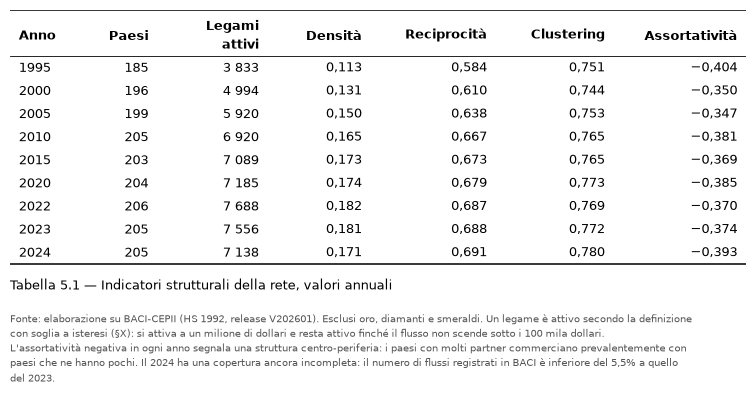

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_1_annuali.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_1_annuali.png')

In [58]:
# %% CELLA T5.1 — indicatori strutturali annuali
# Legge il file della cella R9: rilanciare R9 prima di questa cella.
ANN = pd.read_csv(OUT_DIR / "metriche_annuali.csv")
assert "legami" in ANN.columns, "rilancia la cella R9 (colonna 'legami')"
ANNI_S = [1995, 2000, 2005, 2010, 2015, 2020, 2022, 2023, 2024]

tabella(
    [(str(int(r.anno)), f"{int(r.paesi)}", _mig(r.legami), _n(r.densita),
      _n(r.reciprocita), _n(r.clustering), _sgn(r.assortativita))
     for r in ANN[ANN.anno.isin(ANNI_S)].itertuples()],
    ["Anno", "Paesi", "Legami\nattivi", "Densità", "Reciprocità", "Clustering",
     "Assortatività"],
    [0.10, 0.10, 0.15, 0.14, 0.17, 0.16, 0.18],
    didascalia="Tabella 5.1 — Indicatori strutturali della rete, valori annuali",
    nota=FONTE + " Un legame è attivo secondo la definizione con soglia a "
         "isteresi (§X): si attiva a un milione di dollari e resta attivo "
         "finché il flusso non scende sotto i 100 mila dollari. "
         "L'assortatività negativa in ogni anno segnala una struttura "
         "centro-periferia: i paesi con molti partner commerciano "
         "prevalentemente con paesi che ne hanno pochi. Il 2024 ha una "
         "copertura ancora incompleta: il numero di flussi registrati in BACI "
         "è inferiore del 5,5% a quello del 2023.",
    allinea=["l", "r", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_5_1_annuali.png")

### T5.2. Tabella 5.2 — Concentrazione della rete

Gli indici di concentrazione sono calcolati sulla rete cumulata e sui due
anni estremi. Il confronto fra 1995 e 2024 permette di distinguere un
cambiamento della concentrazione dall'effetto dell'aggregazione
temporale.

**Esportazioni: stesso livello, protagonisti diversi.** L'HHI delle
esportazioni è praticamente invariato (0,0425 nel 1995, 0,0430 nel
2024), pari a circa 23 esportatori equivalenti. Cambiano però i paesi:
i primi tre esportatori erano Stati Uniti, Germania e Russia nel 1995 e
sono Cina, Australia e Stati Uniti nel 2024, con una quota salita dal
24,2% al 27,7%. Sulla rete cumulata l'HHI è più basso (0,0373, circa 27
esportatori equivalenti) proprio perché somma periodi con protagonisti
diversi: qui l'aggregazione temporale attenua la concentrazione.

**Importazioni: una concentrazione crescente.** Nel 1995 domanda e
offerta erano concentrate in misura simile (HHI 0,0493 contro 0,0425).
Nel 2024 l'HHI delle importazioni sale a 0,0723: gli importatori
equivalenti scendono da 20,3 a 13,8 e la quota dei primi tre (Cina,
Stati Uniti, Germania) passa dal 30,0% al 35,6%. L'asimmetria fra una
domanda più concentrata e un'offerta più distribuita si forma quindi nel
corso del periodo e coincide con l'ascesa della Cina come primo
importatore.

**Corridoi.** I primi dieci corridoi bilaterali valgono il 13,8% del
valore nel 1995 e il 17,5% nel 2024, a fronte di un numero di legami
quasi raddoppiato (da 3.833 a 7.138): il commercio si concentra su pochi
grandi corridoi anche mentre la rete si estende.

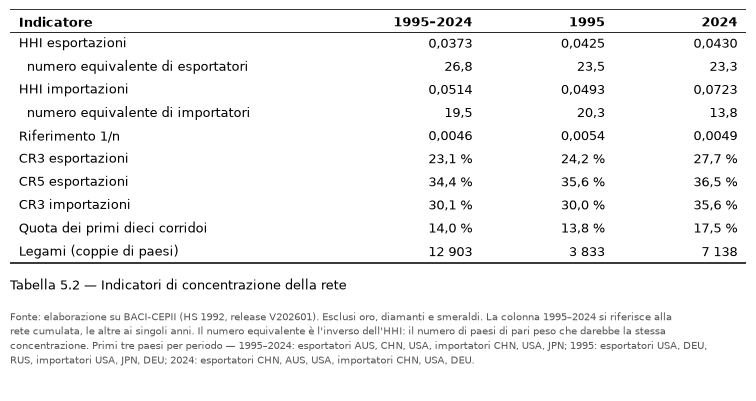

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_2_concentrazione.png
1995–2024 {'he': 0.0373, 'hi': 0.0514, 'cr3e': np.float64(0.2309), 'cr5e': np.float64(0.3436), 'cr3i': np.float64(0.3007), 'top10': np.float64(0.1403)} ['AUS', 'CHN', 'USA', 'RUS', 'DEU'] ['CHN', 'USA', 'JPN']
1995 {'he': 0.0425, 'hi': 0.0493, 'cr3e': np.float64(0.242), 'cr5e': np.float64(0.3558), 'cr3i': np.float64(0.3005), 'top10': np.float64(0.1379)} ['USA', 'DEU', 'RUS', 'AUS', 'CAN'] ['USA', 'JPN', 'DEU']
2024 {'he': 0.043, 'hi': 0.0723, 'cr3e': np.float64(0.277), 'cr5e': np.float64(0.3647), 'cr3i': np.float64(0.3559), 'top10': np.float64(0.1752)} ['CHN', 'AUS', 'USA', 'IDN', 'DEU'] ['CHN', 'USA', 'DEU']


In [59]:
# %% CELLA T5.2 — indicatori di concentrazione
# Stessi indici sulla rete cumulata e sui due anni estremi: il confronto
# 1995/2024 distingue un aumento della concentrazione dall'effetto
# dell'aggregazione temporale.

def _conc(d):
    ex = d.groupby("exp").value.sum().sort_values(ascending=False)
    im = d.groupby("imp").value.sum().sort_values(ascending=False)
    cor = d.groupby(["exp", "imp"]).value.sum().sort_values(ascending=False)
    n = len(set(d.exp) | set(d.imp))
    return dict(
        he=hhi(ex.values), hi=hhi(im.values), n=n,
        cr3e=ex.head(3).sum() / ex.sum(), cr5e=ex.head(5).sum() / ex.sum(),
        cr3i=im.head(3).sum() / im.sum(),
        top10=cor.head(10).sum() / cor.sum(), legami=len(cor),
        e5=[ISO[c] for c in ex.head(5).index],
        i3=[ISO[c] for c in im.head(3).index])


PER = {"1995–2024": _conc(FL),
       "1995": _conc(FL[FL.year == 1995]),
       "2024": _conc(FL[FL.year == 2024])}
COL = list(PER)

def _riga(etichetta, f):
    return (etichetta, *[f(PER[c]) for c in COL])

righe = [
    _riga("HHI esportazioni", lambda p: _n(p["he"], 4)),
    _riga("  numero equivalente di esportatori", lambda p: _n(1 / p["he"], 1)),
    _riga("HHI importazioni", lambda p: _n(p["hi"], 4)),
    _riga("  numero equivalente di importatori", lambda p: _n(1 / p["hi"], 1)),
    _riga("Riferimento 1/n", lambda p: _n(1 / p["n"], 4)),
    _riga("CR3 esportazioni", lambda p: _pct(100 * p["cr3e"])),
    _riga("CR5 esportazioni", lambda p: _pct(100 * p["cr5e"])),
    _riga("CR3 importazioni", lambda p: _pct(100 * p["cr3i"])),
    _riga("Quota dei primi dieci corridoi", lambda p: _pct(100 * p["top10"])),
    _riga("Legami (coppie di paesi)", lambda p: _mig(p["legami"])),
]

nomi = "; ".join(f"{c}: esportatori {', '.join(PER[c]['e5'][:3])}, "
                 f"importatori {', '.join(PER[c]['i3'])}" for c in COL)

tabella(
    righe,
    ["Indicatore", "1995–2024", "1995", "2024"],
    [0.46, 0.18, 0.18, 0.18],
    didascalia="Tabella 5.2 — Indicatori di concentrazione della rete",
    nota=FONTE + " La colonna 1995–2024 si riferisce alla rete cumulata, le "
         "altre ai singoli anni. Il numero equivalente è l'inverso dell'HHI: "
         "il numero di paesi di pari peso che darebbe la stessa "
         "concentrazione. Primi tre paesi per periodo — " + nomi + ".",
    allinea=["l", "r", "r", "r"],
    out=FIG_DIR / "tab_5_2_concentrazione.png")

for c in COL:
    print(c, {k: round(v, 4) for k, v in PER[c].items() if isinstance(v, float)},
          PER[c]["e5"], PER[c]["i3"])

### T5.3. Tabella 5.3 — Primi dieci paesi per scambi complessivi

Esportazioni, importazioni, posizione netta e quota sugli scambi dei
dieci paesi con il maggior valore di scambi nella rete cumulata
1995–2024. La Cina è il primo paese (11,6% degli scambi) ma è
importatrice netta (−0,36), come Giappone, Corea del Sud e India;
Australia (+0,88) e Russia (+0,75) sono esportatrici quasi pure, il
Canada esportatore netto (+0,36). I dieci paesi insieme concentrano il
50,8% degli scambi.

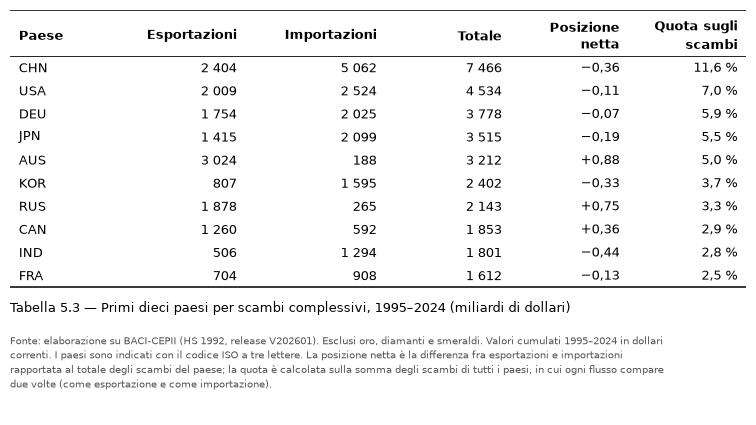

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_3_paesi.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_3_paesi.png')

In [60]:
# %% CELLA T5.3 — primi dieci paesi
# Calcolata da FL, senza dipendere da variabili di altre celle.
_ex = FL.groupby("exp").value.sum()
_im = FL.groupby("imp").value.sum()
T3 = pd.DataFrame({"exp": _ex, "imp": _im}).fillna(0) / 1e6
T3["tot"] = T3.exp + T3.imp
T3["netta"] = (T3.exp - T3.imp) / T3.tot
T3["quota"] = 100 * T3.tot / T3.tot.sum()      # somma su tutti i paesi = 100
T3 = T3.nlargest(10, "tot")
T3.index = [ISO[c] for c in T3.index]

tabella(
    [(p, _mig(r.exp), _mig(r.imp), _mig(r.tot), _sgn(r.netta, 2), _pct(r.quota))
     for p, r in T3.iterrows()],
    ["Paese", "Esportazioni", "Importazioni", "Totale", "Posizione\nnetta",
     "Quota sugli\nscambi"],
    [0.13, 0.19, 0.19, 0.17, 0.16, 0.16],
    didascalia="Tabella 5.3 — Primi dieci paesi per scambi complessivi, "
               "1995–2024 (miliardi di dollari)",
    nota=FONTE + " Valori cumulati 1995–2024 in dollari correnti. I paesi sono "
         "indicati con il codice ISO a tre lettere. La posizione netta è la "
         "differenza fra esportazioni e importazioni rapportata al totale degli "
         "scambi del paese; la quota è calcolata sulla somma degli scambi di "
         "tutti i paesi, in cui ogni flusso compare due volte (come "
         "esportazione e come importazione).",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_5_3_paesi.png")

### T5.4. Tabella 5.4 — Primi dieci corridoi bilaterali

I dieci corridoi esportatore → importatore di maggior valore nella rete
cumulata 1995–2024, con la quota sul valore complessivo e la risorsa
principale. Australia → Cina (1.232 miliardi di dollari, 3,8% del valore)
vale il doppio del secondo corridoio, Canada → Stati Uniti (618). Cinque
dei dieci corridoi hanno la Cina come destinazione o origine e tre partono
dall'Australia. Insieme valgono il 14,0% del valore su 12.903 legami.

Ferro e acciaio sono la prima risorsa in sette corridoi su dieci, ma con
peso molto diverso. Nei flussi di minerale verso la Cina dominano
nettamente: 74% da Australia, 90% dal Brasile. Fra economie industriali
(Stati Uniti → Canada e Messico, Giappone e Corea con la Cina) pesano fra
il 25% e il 35%, segno di un paniere più diversificato. Gli altri
corridoi sono specializzati in una risorsa: rame dal Cile alla Cina
(90%), carbone metallurgico dall'Australia al Giappone (58%) e alla
Corea (40%), alluminio dal Canada agli Stati Uniti (32%).

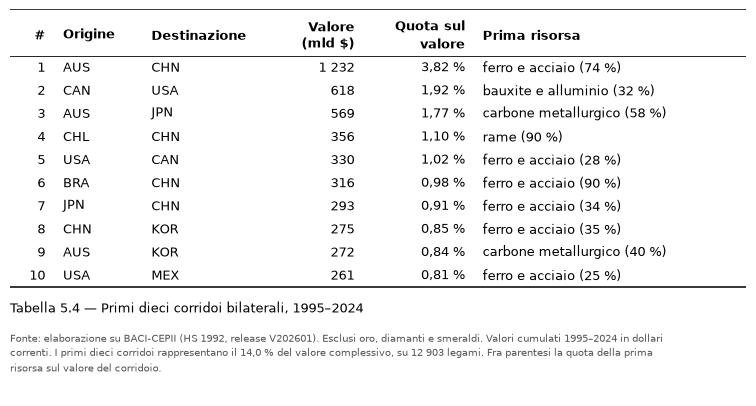

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_4_corridoi.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_4_corridoi.png')

In [61]:
# %% CELLA T5.4 — primi dieci corridoi
# Calcolata da FL, senza dipendere da variabili di altre celle.
_cor = FL.groupby(["exp", "imp"]).value.sum()
_tot = _cor.sum()
_top = _cor.nlargest(10)

# prima risorsa di ciascun corridoio, con la sua quota sul valore del corridoio
_ris = (FL.set_index(["exp", "imp"]).loc[_top.index]
          .groupby(["exp", "imp", "resource"]).value.sum())

righe = []
for i, ((e, m), val) in enumerate(_top.items()):
    s = _ris.loc[(e, m)].sort_values(ascending=False)
    righe.append((str(i + 1), ISO[e], ISO[m], _mig(val / 1e6),
                  _pct(100 * val / _tot, 2),
                  f"{_nome(s.index[0]).lower()} ({_pct(100 * s.iloc[0] / val, 0)})"))

tabella(
    righe,
    ["#", "Origine", "Destinazione", "Valore\n(mld $)", "Quota sul\nvalore",
     "Prima risorsa"],
    [0.06, 0.12, 0.15, 0.15, 0.15, 0.37],
    didascalia="Tabella 5.4 — Primi dieci corridoi bilaterali, 1995–2024",
    nota=FONTE + f" Valori cumulati 1995–2024 in dollari correnti. I primi "
         f"dieci corridoi rappresentano il {_pct(100 * _top.sum() / _tot, 1)} "
         f"del valore complessivo, su {_mig(len(_cor))} legami. Fra parentesi "
         f"la quota della prima risorsa sul valore del corridoio.",
    allinea=["r", "l", "l", "r", "r", "l"],
    out=FIG_DIR / "tab_5_4_corridoi.png")

### T5.5. Tabella 5.5 — Caratteristiche dei quattro stadi

Riassume per stadio le misure delle celle R2, R6, R12 e T5.4bis. La
manifattura è lo stadio con più paesi, legami e valore (11.753 miliardi
di dollari cumulati), ma in un anno tipico la rete più densa è quella
della raffinazione (0,130 contro 0,118). Il riciclo è lo stadio più
piccolo (2.179 miliardi), il meno denso (0,070) e il più
disassortativo (−0,413), ma anche quello con la struttura a comunità più
marcata (Q = 0,178, z = +20,6). La Cina è il primo intermediario in
estrazione, raffinazione e manifattura; nel riciclo il primo sono gli
Stati Uniti.

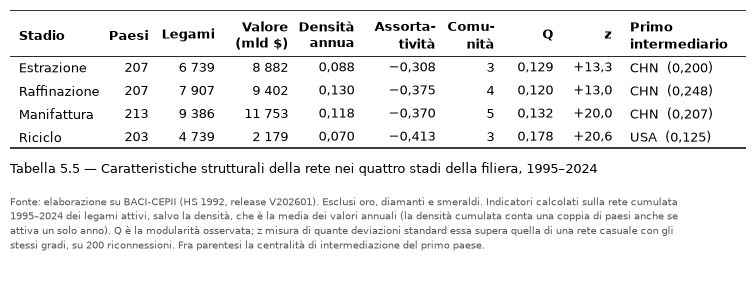

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_5_stadi.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_5_stadi.png')

In [62]:
# %% CELLA T5.5 — caratteristiche dei quattro stadi
tabella(
    [(LBL_ST[st], f"{CAR[st]['paesi']}", _mig(CAR[st]["archi"]),
      _mig(CAR[st]["valore"]), _n(CAR[st]["densita_annua"]),
      _sgn(CAR[st]["assort"]), f"{CAR[st]['comunita']}", _n(CAR[st]["Q"]),
      _sgn(CAR[st]["z"], 1),
      f"{CAR[st]['intermediario']}  ({_n(CAR[st]['bt'])})")
     for st in STAGES],
    ["Stadio", "Paesi", "Legami", "Valore\n(mld $)", "Densità\nannua",
     "Assorta-\ntività", "Comu-\nnità", "Q", "z", "Primo\nintermediario"],
    [0.13, 0.07, 0.09, 0.10, 0.09, 0.11, 0.08, 0.08, 0.08, 0.17],
    didascalia="Tabella 5.5 — Caratteristiche strutturali della rete nei "
               "quattro stadi della filiera, 1995–2024",
    nota=FONTE + " Indicatori calcolati sulla rete cumulata 1995–2024 dei "
         "legami attivi, salvo la densità, che è la media dei valori annuali "
         "(la densità cumulata conta una coppia di paesi anche se attiva un solo "
         "anno). Q è la modularità osservata; z misura di quante deviazioni "
         "standard essa supera quella di una rete casuale con gli stessi gradi, "
         "su 200 riconnessioni. Fra parentesi la centralità di intermediazione "
         "del primo paese.",
    allinea=["l", "r", "r", "r", "r", "r", "r", "r", "r", "l"],
    out=FIG_DIR / "tab_5_5_stadi.png")

### T5.6. Tabella 5.6 — Modularità per periodo e stadio

Riporta per ciascuna finestra decennale e ciascuno stadio lo scarto fra
modularità osservata e attesa (cella R11). Estrazione e riciclo si
regionalizzano (lo scarto passa rispettivamente da 0,012 a 0,047 e da
0,036 a 0,071), la manifattura resta stabile su valori alti (0,052–0,063),
la raffinazione è l'unico stadio in cui lo scarto diminuisce nell'ultimo
decennio (da 0,046 a 0,033).

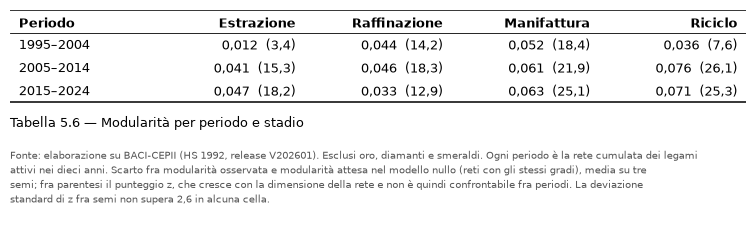

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_6_modularita_periodi.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_6_modularita_periodi.png')

In [63]:
# %% CELLA T5.6 — modularità per periodo
# Lo scarto grezzo Q − Q nullo è la misura confrontabile fra periodi; z, che
# cresce con la dimensione della rete, è riportato fra parentesi.
TW = pd.read_csv(OUT_DIR / "modularity_windows.csv")
Z = TW.pivot_table(index="periodo", columns="stadio", values="z")[STAGES]
SD = TW.pivot_table(index="periodo", columns="stadio", values="z", aggfunc="std")[STAGES]
EX = TW.pivot_table(index="periodo", columns="stadio", values="eccesso")[STAGES]

tabella(
    [(p.replace("-", "–"),) + tuple(f"{_n(EX.loc[p, s], 3)}  ({_n(Z.loc[p, s], 1)})"
                                    for s in STAGES) for p in Z.index],
    ["Periodo"] + [LBL_ST[s] for s in STAGES],
    [0.20, 0.20, 0.20, 0.20, 0.20],
    didascalia="Tabella 5.6 — Modularità per periodo e stadio",
    nota=FONTE + " Ogni periodo è la rete cumulata dei legami attivi nei dieci "
         "anni. Scarto fra modularità osservata e modularità attesa nel modello "
         "nullo (reti con gli stessi gradi), media su tre semi; fra parentesi il "
         f"punteggio z, che cresce con la dimensione della rete e non è quindi "
         f"confrontabile fra periodi. La deviazione standard di z fra semi non "
         f"supera {_n(SD.max().max(), 1)} in alcuna cella.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_5_6_modularita_periodi.png")

### T5.7. Tabella 5.7 — Caratteristiche per livello di rilevanza UNCTAD

Riporta per ciascun livello di rilevanza le misure della cella T5.6bis.
Le risorse di primo livello formano la rete più densa (0,141 in un anno
tipico) e meno modulare rispetto al modello nullo (z = +14,3); il livello
intermedio ha la struttura a comunità più marcata (z = +24,5);
l'assortatività è quasi identica nei tre livelli. Poiché ciascun livello
è dominato da una o due risorse (ferro e acciaio valgono l'85% del
livello intermedio), le differenze fra livelli riflettono soprattutto
quelle fra queste risorse.

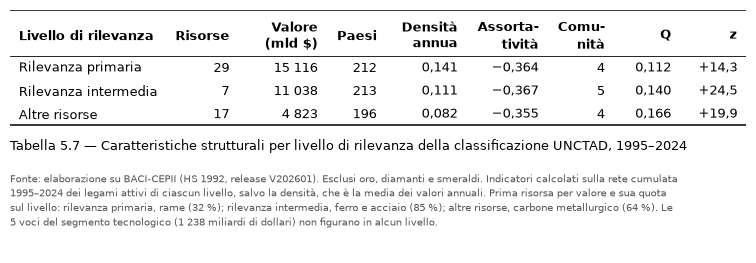

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_7_layer.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_7_layer.png')

In [64]:
# %% CELLA T5.7 — caratteristiche per livello di rilevanza UNCTAD
# La nota riporta la prima risorsa di ciascun livello: ogni livello è dominato
# da una o due risorse, e le sue caratteristiche riflettono in larga parte
# quelle di queste risorse.
_vr = FL.groupby("resource").value.sum()
_comp = []
for l in ["core", "relevant", "other"]:
    s = _vr.reindex(sorted(ris_lay[l])).sort_values(ascending=False)
    _comp.append(f"{LBL_LAY[l].lower()}, {_nome(s.index[0]).lower()} "
                 f"({_pct(100 * s.iloc[0] / s.sum(), 0)})")
_v_escl = _vr.reindex(ESCLUSE_LAY).sum() / 1e6

tabella(
    [(LBL_LAY[l], f"{int(CL.loc[l, 'risorse'])}", _mig(CL.loc[l, "valore"]),
      f"{int(CL.loc[l, 'paesi'])}", _n(CL.loc[l, "densita_annua"]),
      _sgn(CL.loc[l, "assort"]), f"{int(CL.loc[l, 'comunita'])}",
      _n(CL.loc[l, "Q"]), _sgn(CL.loc[l, "z"], 1))
     for l in ["core", "relevant", "other"]],
    ["Livello di rilevanza", "Risorse", "Valore\n(mld $)", "Paesi", "Densità\nannua",
     "Assorta-\ntività", "Comu-\nnità", "Q", "z"],
    [0.22, 0.09, 0.12, 0.08, 0.11, 0.11, 0.09, 0.09, 0.09],
    didascalia="Tabella 5.7 — Caratteristiche strutturali per livello di "
               "rilevanza della classificazione UNCTAD, 1995–2024",
    nota=FONTE + " Indicatori calcolati sulla rete cumulata 1995–2024 dei "
         "legami attivi di ciascun livello, salvo la densità, che è la media dei "
         "valori annuali. Prima risorsa per valore e sua quota sul livello: "
         + "; ".join(_comp) + f". Le {len(ESCLUSE_LAY)} voci del segmento "
         f"tecnologico ({_mig(_v_escl)} miliardi di dollari) non figurano in "
         f"alcun livello.",
    allinea=["l", "r", "r", "r", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_5_7_layer.png")

### T5.8. Tabella 5.8 — Centralità di intermediazione

I dodici paesi con la betweenness più alta nella rete cumulata
1995–2024 (cella R12), con il rango per scambi, lo scarto fra i due ranghi
e il rango nel periodo 2020–2024. La Cina è prima in entrambi i periodi.
India, Turchia, Spagna e Regno Unito intermediano molto più di quanto
il loro volume di scambi farebbe attendere (scarti da +6 a +15), mentre
Germania e Australia meno (−6). Nel 2020–2024 la Turchia sale al quarto
posto e l'Australia, esportatrice quasi pura, scende al 29°.

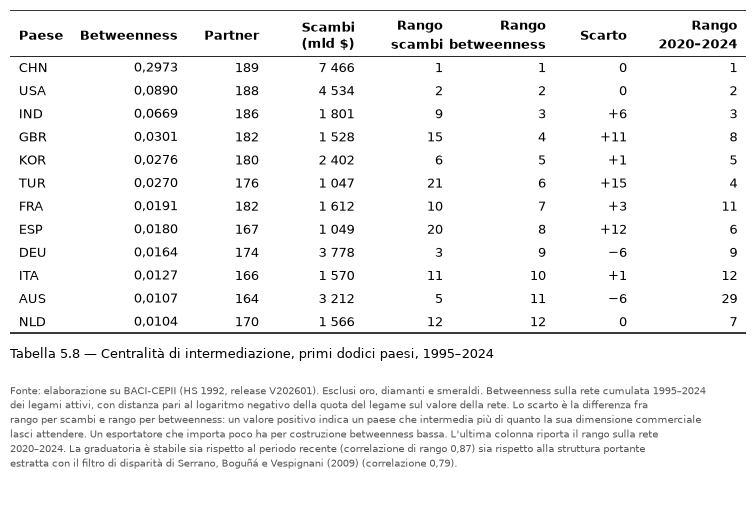

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_8_intermediazione.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_8_intermediazione.png')

In [65]:
# %% CELLA T5.8 — centralità di intermediazione
# Legge il file della cella R12 (versione con la colonna bt_2020_24).
TB = pd.read_csv(OUT_DIR / "intermediazione_totale.csv", index_col=0)
assert "bt_2020_24" in TB.columns, "rilancia la cella R12"
T8 = TB.nlargest(12, "bt")
rho_bb = TB.bt.corr(TB.bt_backbone, method="spearman")
rho_rec = TB.bt.corr(TB.bt_2020_24, method="spearman")


def _scarto(x):
    return "0" if x == 0 else _sgn(x, 0)


tabella(
    [(p, _n(r.bt, 4), f"{int(r.grado)}", _mig(r.scambi_mld),
      f"{int(r.rango_scambi)}", f"{int(r.rango_bt)}", _scarto(r.scarto_rango),
      f"{int(r.rango_bt_2020_24)}")
     for p, r in T8.iterrows()],
    ["Paese", "Betweenness", "Partner", "Scambi\n(mld $)", "Rango\nscambi",
     "Rango\nbetweenness", "Scarto", "Rango\n2020–2024"],
    [0.10, 0.14, 0.11, 0.13, 0.12, 0.14, 0.11, 0.15],
    didascalia="Tabella 5.8 — Centralità di intermediazione, primi dodici paesi, "
               "1995–2024",
    nota=FONTE + " Betweenness sulla rete cumulata 1995–2024 dei legami attivi, "
         "con distanza pari al logaritmo negativo della quota del legame sul "
         "valore della rete. Lo scarto è la differenza fra rango per scambi e "
         "rango per betweenness: un valore positivo indica un paese che "
         "intermedia più di quanto la sua dimensione commerciale lasci "
         "attendere. Un esportatore che importa poco ha per costruzione "
         "betweenness bassa. L'ultima colonna riporta il rango sulla rete "
         "2020–2024. La graduatoria è stabile sia rispetto al periodo recente "
         f"(correlazione di rango {_n(rho_rec, 2)}) sia rispetto alla struttura "
         "portante estratta con il filtro di disparità di Serrano, Boguñá e "
         f"Vespignani (2009) (correlazione {_n(rho_bb, 2)}).",
    allinea=["l", "r", "r", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_5_8_intermediazione.png")

### T5.9. Tabella 5.9 — Intermediari ed esportatori per risorsa

Per le risorse con scambi superiori a 20 miliardi di dollari nel
2020–2024, elenca quelle in cui il primo paese per intermediazione
(cella R12) non è il primo esportatore. Sono 21; su tutte le 58 risorse
il caso ricorre 42 volte. La Cina è il primo intermediario in 14 delle
21 risorse, fra cui rame, litio, ferro e acciaio, cobalto e nichel; la
Germania nei metalli del gruppo del platino, nell'argento, nel germanio e
nel potassio; l'India nel manganese e nel piombo; gli Stati Uniti
nell'uranio. I primi esportatori sono invece paesi produttori di
minerali: Cile, Australia, SACU, Indonesia, Repubblica Democratica del
Congo, Kazakistan.

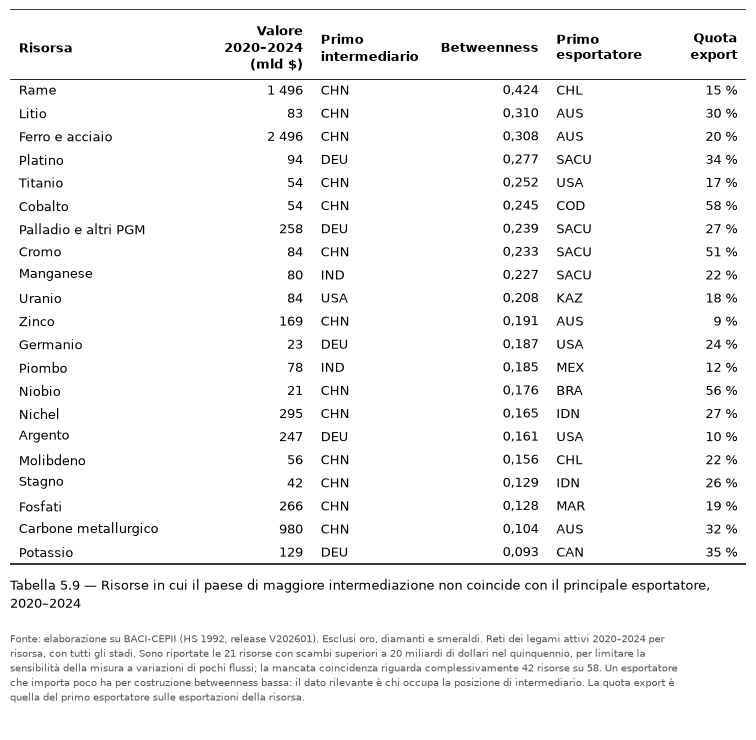

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_9_intermediari.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_9_intermediari.png')

In [66]:
# %% CELLA T5.9 — intermediari ed esportatori per risorsa
IR = pd.read_csv(OUT_DIR / "intermediazione_per_risorsa.csv")
DIV = IR[(~IR.coincidono) & (IR.valore_mld >= 20)].sort_values("bt_primo", ascending=False)

# quota del primo esportatore sulle esportazioni della risorsa, 2020-2024
_f5 = FL[FL.year >= 2020]
_q1 = {r: d.groupby("exp").value.sum().pipe(lambda s: s.max() / s.sum())
       for r, d in _f5[_f5.resource.isin(DIV.risorsa)].groupby("resource")}

tabella(
    [(_nome(r.risorsa), _mig(r.valore_mld), r.primo_intermediario, _n(r.bt_primo),
      r.primo_per_volume, _pct(100 * _q1[r.risorsa], 0)) for r in DIV.itertuples()],
    ["Risorsa", "Valore\n2020–2024\n(mld $)", "Primo\nintermediario",
     "Betweenness", "Primo\nesportatore", "Quota\nexport"],
    [0.27, 0.14, 0.17, 0.15, 0.15, 0.12],
    didascalia="Tabella 5.9 — Risorse in cui il paese di maggiore "
               "intermediazione non coincide con il principale esportatore, "
               "2020–2024",
    nota=FONTE + f" Reti dei legami attivi 2020–2024 per risorsa, con tutti gli "
         f"stadi. Sono riportate le {len(DIV)} risorse con scambi superiori a "
         f"20 miliardi di dollari nel quinquennio, per limitare la sensibilità "
         f"della misura a variazioni di pochi flussi; la mancata coincidenza "
         f"riguarda complessivamente {(~IR.coincidono).sum()} risorse su "
         f"{len(IR)}. Un esportatore che importa poco ha per costruzione "
         f"betweenness bassa: il dato rilevante è chi occupa la posizione di "
         f"intermediario. La quota export è quella del primo esportatore sulle "
         f"esportazioni della risorsa.",
    allinea=["l", "r", "l", "r", "l", "r"],
    out=FIG_DIR / "tab_5_9_intermediari.png")

### F5.4. Figura 5.4 — Concentrazione dell'intermediazione e posizione nella filiera

Per ciascuna risorsa la figura confronta l'indice di posizionamento a
valle (quota di raffinazione con peso 0,5 e di manifattura con peso 1
sugli scambi 2020–2024) con la concentrazione dell'intermediazione,
misurata dall'indice di Herfindahl della betweenness nella rete della
risorsa: un valore alto indica che l'intermediazione è concentrata in
pochi paesi.

**Più a valle, più concentrata.** La correlazione fra l'indice di
posizionamento e il logaritmo della concentrazione è +0,49 (p < 0,001,
58 risorse). Le risorse estratte e scambiate soprattutto come minerale
(calcare, gesso, potassio, carbone metallurgico, caolino) hanno
un'intermediazione distribuita fra molti paesi; i manufatti (magneti
permanenti, celle per accumulatori, condensatori al tantalio) la hanno
concentrata in pochi.

**Robustezza.** La relazione resiste a tre controlli:

| specificazione | coefficiente o correlazione | p | n |
|---|---|---|---|
| tutte le risorse | r = +0,49 | < 0,001 | 58 |
| senza le risorse agli estremi dell'asse (0 e 1) | r = +0,44 | 0,003 | 44 |
| solo risorse oltre 20 miliardi | r = +0,60 | < 0,001 | 32 |
| regressione con controllo per il numero di paesi | b = +0,79 (e.s. 0,16) | < 0,001 | 58 |

Le risorse con un solo stadio nel dizionario si collocano per costruzione
a 0 o a 1, ma la correlazione resta simile escludendole. Le reti piccole
hanno un'intermediazione più concentrata (coefficiente del logaritmo dei
paesi −0,51, p < 0,001), ma la dimensione è quasi scorrelata con il
posizionamento (−0,08) e non spiega la relazione: a parità di numero di
paesi, passare da una risorsa solo estrattiva a una solo manifatturiera
moltiplica l'indice di concentrazione per circa 2,2.

**Eccezioni.** Sopra la retta si trovano risorse con reti piccole
(berillio, stronzio, mercurio, torio), il cui valore elevato riflette la
dimensione più che il posizionamento. Sotto la retta spiccano i fosfati:
pur collocandosi a valle (0,78), hanno un'intermediazione poco
concentrata.

  tutte le risorse           r = +0.495  p = 0.0001  (n = 58)
  senza gli estremi 0 e 1    r = +0.444  p = 0.0025  (n = 44)
  solo filiere oltre 20 mld  r = +0.601  p = 0.0003  (n = 32)

regressione con controllo per la dimensione della rete (HC1):
              Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
const        -0.016     0.508 -0.032  0.975  -1.011   0.979
indice_valle  0.787     0.156  5.048  0.000   0.481   1.092
log_paesi    -0.512     0.110 -4.655  0.000  -0.727  -0.296
correlazione indice / log paesi: -0.078


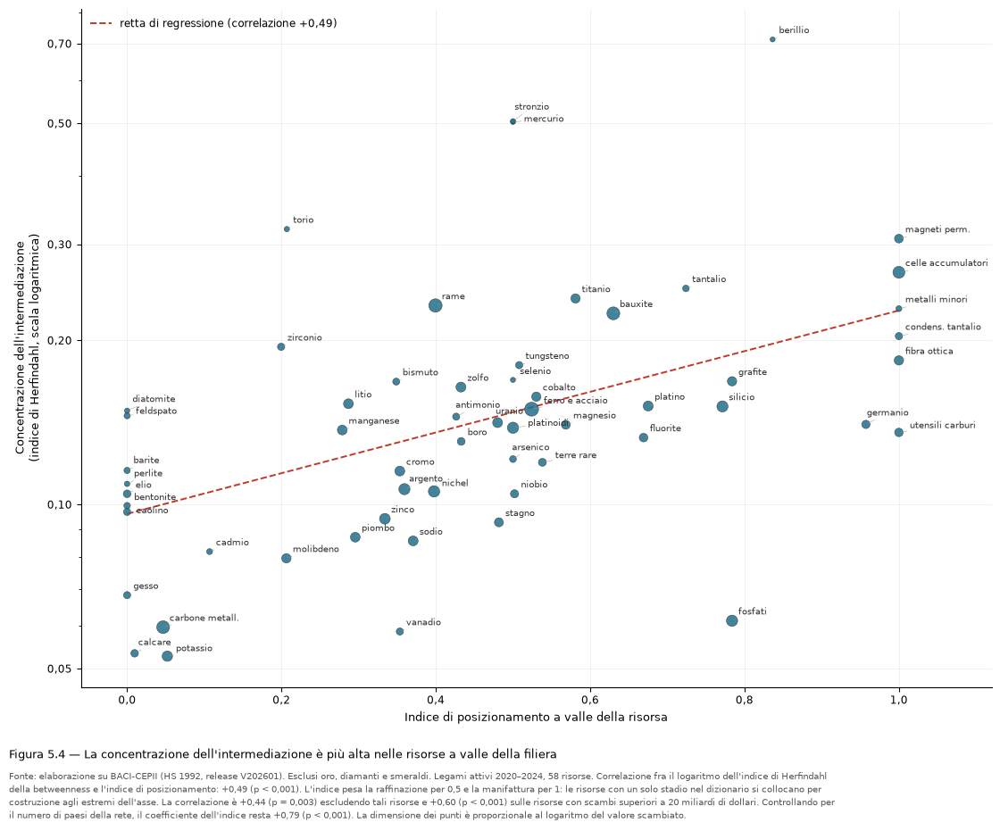

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_4_intermediazione_valle.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_5_4_intermediazione_valle.png')

In [67]:
# %% CELLA F5.4 — intermediazione e posizione nella filiera
from scipy import stats

stadi = (DI[DI.year >= 2020]
         .groupby(["resource", "stage_name"], observed=True).value.sum()
         .unstack().fillna(0))
stadi.columns = stadi.columns.astype(str)
stadi.index = stadi.index.astype(str)
q = stadi.div(stadi.sum(axis=1), axis=0)

IR2 = IR.set_index("risorsa").join(q)
IR2["indice_valle"] = IR2.get("refining", 0) * 0.5 + IR2.get("manufacturing", 0)

# numero di paesi nella rete 2020-2024 di ciascuna risorsa (controllo dimensione)
_f5 = FL[FL.year >= 2020]
IR2["paesi"] = pd.Series({r: rete(df=d).number_of_nodes()
                          for r, d in _f5.groupby("resource")})

M = IR2[["hhi_bt", "indice_valle", "valore_mld", "paesi"]].dropna()
M = M[M.hhi_bt > 0]

# Robustezza: le risorse con un solo stadio nel dizionario stanno per
# costruzione agli estremi dell'asse, e sulle reti piccole la betweenness si
# concentra per ragioni di dimensione. La correlazione è quindi ricalcolata
# escludendo gli estremi e limitandosi alle filiere maggiori; una regressione
# controlla direttamente per il numero di paesi della rete.
interni = M[(M.indice_valle > 0) & (M.indice_valle < 1)]
grandi = M[M.valore_mld >= 20]


def _r(d):
    return stats.pearsonr(d.indice_valle, np.log(d.hhi_bt))


r_corr, p_corr = _r(M)
for lbl, d in [("tutte le risorse", M), ("senza gli estremi 0 e 1", interni),
               ("solo filiere oltre 20 mld", grandi)]:
    r, p = _r(d)
    print(f"  {lbl:26s} r = {r:+.3f}  p = {p:.4f}  (n = {len(d)})")

# regressione log(hhi_bt) ~ indice_valle + log(paesi), errori robusti HC1
import statsmodels.api as sm
X = sm.add_constant(pd.DataFrame({"indice_valle": M.indice_valle,
                                  "log_paesi": np.log(M.paesi)}))
OLS = sm.OLS(np.log(M.hhi_bt), X).fit(cov_type="HC1")
b_ind, p_ind = OLS.params["indice_valle"], OLS.pvalues["indice_valle"]
print(f"\nregressione con controllo per la dimensione della rete (HC1):")
print(OLS.summary2().tables[1].round(3).to_string())
print(f"correlazione indice / log paesi: "
      f"{np.corrcoef(M.indice_valle, np.log(M.paesi))[0, 1]:+.3f}")

ABBREV = {"metallurgical_coal": "carbone metall.",
          "cemented_carbide_tools": "utensili carburi",
          "tantalum_capacitors": "condens. tantalio",
          "optical_fibre_cable": "fibra ottica",
          "gallium_germanium_indium_niobium_vanadium_other": "metalli minori",
          "pgm_other_and_palladium": "platinoidi",
          "boron_borates": "boro",
          "aluminium-bauxite": "bauxite",
          "permanent_magnets": "magneti perm.",
          "battery_cells": "celle accumulatori"}
_etich = lambda r: ABBREV.get(r, _nome(r).lower())


def colloca_etichette(ax, xd, yd, testi, fs=6.5, iters=260, sep=0.9,
                      raggio=11.0, passo=1.6):
    """Colloca le etichette evitando sovrapposizioni reciproche e con i
    marcatori, mediante rilassamento iterativo in coordinate di
    visualizzazione. Ciascuna etichetta resta collegata al proprio punto da un
    segmento sottile, così che lo spostamento non ne comprometta la
    riferibilità.

    La misura degli ingombri richiede che la figura sia già stata tracciata:
    il testo non ha dimensioni note prima del rendering."""
    fig = ax.figure
    fig.canvas.draw()
    P = ax.transData.transform(np.c_[xd, yd]).astype(float)
    L = P.copy() + np.array([6.0, 6.0])
    r = fig.canvas.get_renderer()

    W, H = [], []
    for t in testi:
        tt = ax.text(0, 0, t, fontsize=fs)
        bb = tt.get_window_extent(renderer=r)
        W.append(bb.width)
        H.append(bb.height)
        tt.remove()
    W, H = np.array(W), np.array(H)
    n = len(testi)

    for _ in range(iters):
        moved = False
        for i in range(n):
            dx = L[:, 0] - L[i, 0]
            dy = L[:, 1] - L[i, 1]
            ov = ((np.abs(dx) < (W + W[i]) / 2 * sep)
                  & (np.abs(dy) < (H + H[i]) / 2 * 1.25))
            ov[i] = False
            for j in np.where(ov)[0]:
                moved = True
                v = L[j] - L[i]
                nr = np.hypot(*v)
                if nr < 1e-6:
                    v, nr = np.array([1.0, 1.0]), 1.0
                L[i] -= v / nr * passo
                L[j] += v / nr * passo

            d = np.hypot(*(L[i] - P).T)
            for j in np.where(d < raggio)[0]:
                u = L[i] - P[j]
                nr = np.hypot(*u)
                if nr < 1e-6:
                    u, nr = np.array([1.0, 1.0]), 1.0
                L[i] += u / nr * (raggio - nr) * 0.5
                moved = True
        if not moved:
            break

    LD = ax.transData.inverted().transform(L)
    for (lx, ly), px, py, t in zip(LD, xd, yd, testi):
        ax.annotate(t, xy=(px, py), xytext=(lx, ly), fontsize=fs,
                    color="#333333", zorder=5,
                    arrowprops=dict(arrowstyle="-", lw=0.35,
                                    color="#999999", shrinkA=0, shrinkB=2))


def _f54(ax):
    v = np.log1p(M.valore_mld.values)
    sz = 16 + (v / v.max()) ** 1.5 * 110
    ax.scatter(M.indice_valle, M.hhi_bt, s=sz, color="#1f6f8b",
               edgecolor="#333333", lw=0.4, alpha=0.85, zorder=3)

    xs = np.linspace(M.indice_valle.min(), M.indice_valle.max(), 50)
    b, a = np.polyfit(M.indice_valle, np.log(M.hhi_bt), 1)
    ax.plot(xs, np.exp(a + b * xs), color="#c0392b", lw=1.4, ls="--", zorder=2,
            label=f"retta di regressione (correlazione {_sgn(r_corr, 2)})")

    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mtick.FixedLocator([0.05, 0.1, 0.2, 0.3, 0.5, 0.7]))
    ax.yaxis.set_major_formatter(
        mtick.FuncFormatter(lambda y, _: f"{y:.2f}".replace(".", ",")))
    ax.yaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_xlim(-0.06, 1.12)
    ax.xaxis.set_major_formatter(
        mtick.FuncFormatter(lambda x, _: f"{x:.1f}".replace(".", ",")))

    ax.set_xlabel("Indice di posizionamento a valle della risorsa", fontsize=9)
    ax.set_ylabel("Concentrazione dell'intermediazione\n"
                  "(indice di Herfindahl, scala logaritmica)", fontsize=9)
    ax.legend(frameon=False, loc="upper left", fontsize=8.5)
    ax.grid(alpha=0.25, lw=0.5, which="major")

    nomi = [_etich(n) for n in M.index]
    colloca_etichette(ax, M.indice_valle.values, M.hhi_bt.values, nomi,
                      fs=7, iters=600, sep=1.05, raggio=10.0, passo=1.2)


_p = lambda p: "p < 0,001" if p < 0.001 else f"p = {_n(p, 3)}"
figura(_f54, altezza=7.6, larghezza=11.5, margine_dx=0.35,
       didascalia="Figura 5.4 — La concentrazione dell'intermediazione è più "
                  "alta nelle risorse a valle della filiera",
       nota=FONTE + f" Legami attivi 2020–2024, {len(M)} risorse. Correlazione "
            f"fra il logaritmo dell'indice di Herfindahl della betweenness e "
            f"l'indice di posizionamento: {_sgn(r_corr, 2)} ({_p(p_corr)}). "
            f"L'indice pesa la raffinazione per 0,5 e la manifattura per 1: le "
            f"risorse con un solo stadio nel dizionario si collocano per "
            f"costruzione agli estremi dell'asse. La correlazione è "
            f"{_sgn(_r(interni)[0], 2)} ({_p(_r(interni)[1])}) escludendo tali "
            f"risorse e {_sgn(_r(grandi)[0], 2)} ({_p(_r(grandi)[1])}) sulle "
            f"risorse con scambi superiori a 20 miliardi di dollari. "
            f"Controllando per il numero di paesi della rete, il coefficiente "
            f"dell'indice resta {_sgn(b_ind, 2)} ({_p(p_ind)}). La dimensione "
            f"dei punti è proporzionale al logaritmo del valore scambiato.",
       out=FIG_DIR / "fig_5_4_intermediazione_valle.png")

### G1. Figura 5.1 — La rete aggregata

Rappresenta la rete cumulata 1995–2024 limitata, per leggibilità, ai
paesi che coprono il 95% degli scambi e ai loro legami più intensi. Le
posizioni sono calcolate con l'algoritmo DrL; dimensione e colore dei
nodi si riferiscono alla rete completa. Al centro si collocano le grandi
economie importatrici e trasformatrici (Germania, Stati Uniti, Corea,
Cina, Giappone, India), in azzurro; ai margini gli esportatori di
minerali, in rosso (Australia, SACU, Russia, Cile, Perù, Kazakistan,
Repubblica Democratica del Congo, Zambia). La distanza fra i nodi
riflette la struttura complessiva dei legami e non l'intensità di un
singolo rapporto bilaterale.

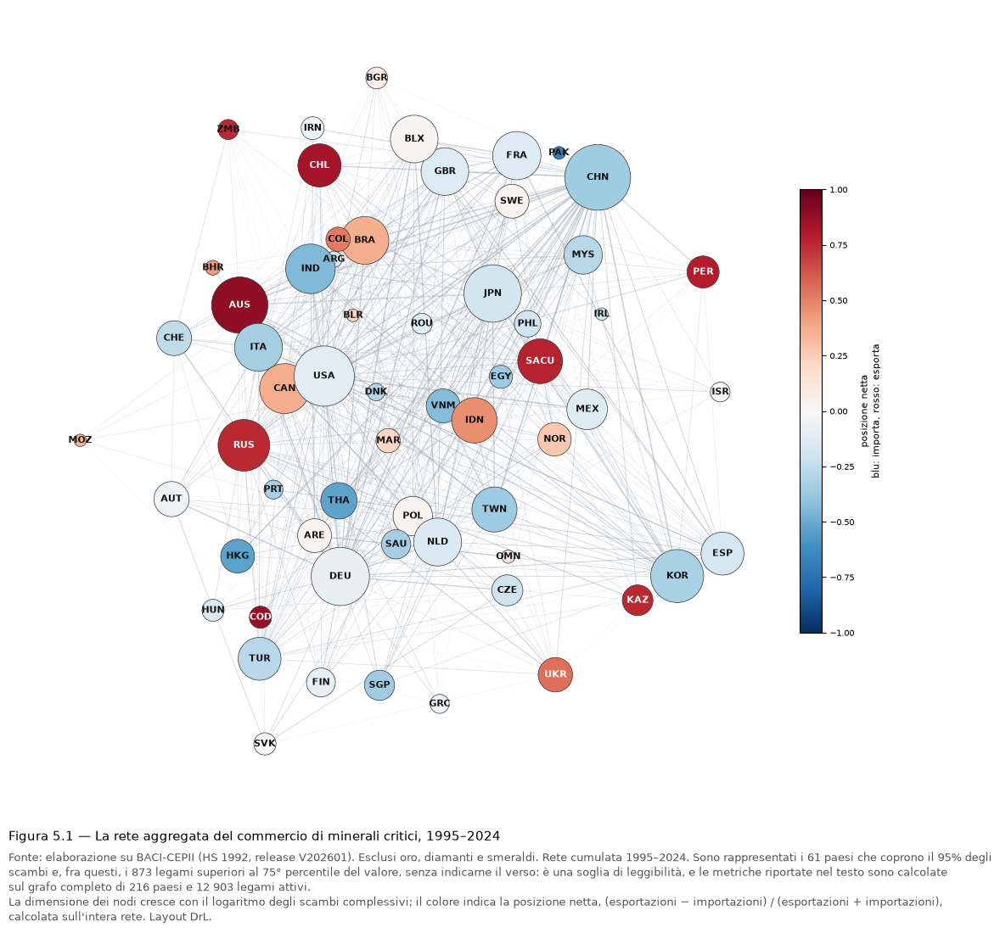

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_1_rete_aggregata.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_5_1_rete_aggregata.png')

In [68]:
# %% CELLA G1 — Figura 5.1: la rete aggregata
# Le posizioni sono calcolate su questo solo grafo: l'insieme dei nodi è
# diverso da quello degli stadi, e forzare coordinate condivise peggiorerebbe
# il tracciamento senza guadagno di confrontabilità.
# La tela è ampliata a undici pollici per nove e mezzo, con nodi ed etichette
# proporzionalmente maggiori: i layout a forze lasciano ampi margini vuoti, e
# ingrandire i soli elementi disegnati recupera lo spazio senza invadere
# didascalia e legenda.
# Dimensione e colore dei nodi sono calcolati sulla rete completa (G_tot), non
# sul sottografo dei paesi rappresentati.
LARG_A, ALT_A, FS_A = 11.0, 9.5, 11.0

K_tot = top_subgraph(G_tot, 0.95)
forza_tot = _intensita(G_tot)
s = np.log1p(np.array([forza_tot[n] for n in K_tot.nodes()], float))
sn = (s - s.min()) / (s.max() - s.min() + 1e-9)
sizes_a = 110 + sn ** 1.4 * 3000

pos_a = igraph_layout(K_tot, "drl", seed=42)[0]
pos_a = separate(pos_a, list(K_tot.nodes()), sizes_a, pad=1.35,
                 larghezza_pollici=LARG_A, altezza_pollici=ALT_A)

f, nn, na = disegna_rete(K_tot, pos_a, sizes_a, fs_lab=8.0, rif=G_tot)

figura(f, altezza=ALT_A, larghezza=LARG_A, fs=FS_A, margine_basso=0.05,
       margine_sx=0.05, margine_dx=0.05,
       didascalia="Figura 5.1 — La rete aggregata del commercio di minerali "
                  "critici, 1995–2024",
       nota=FONTE + f" Rete cumulata 1995–2024. Sono rappresentati i {nn} paesi "
            f"che coprono il 95% degli scambi e, fra questi, i {_mig(na)} legami "
            f"superiori al 75° percentile del valore, senza indicarne il verso: "
            f"è una soglia di leggibilità, e le metriche riportate nel testo sono "
            f"calcolate sul grafo completo di {G_tot.number_of_nodes()} paesi e "
            f"{_mig(G_tot.number_of_edges())} legami attivi.\n"
            "La dimensione dei nodi cresce con il logaritmo degli scambi "
            "complessivi; il colore indica la posizione netta, (esportazioni − "
            "importazioni) / (esportazioni + importazioni), calcolata sull'intera "
            "rete. Layout DrL.",
       out=FIG_DIR / "fig_5_1_rete_aggregata.png")

### G2. Figure 5.2a–d — La rete nei quattro stadi

Rappresentano la rete cumulata 1995–2024 di ciascuno stadio sugli stessi
61 paesi e con le stesse posizioni, calcolate sull'unione degli stadi,
così che i pannelli siano direttamente confrontabili. La dimensione dei
nodi riflette gli scambi del paese nello stadio, su una scala comune; il
colore la posizione netta nello stadio. Il confronto mostra come lo
stesso paese cambi ruolo lungo la filiera: il Cile, esportatore netto
nell'estrazione, è importatore nella manifattura; Giappone e Cina, che
importano minerali, sono esportatori netti di manufatti.

nodi rappresentati: 61


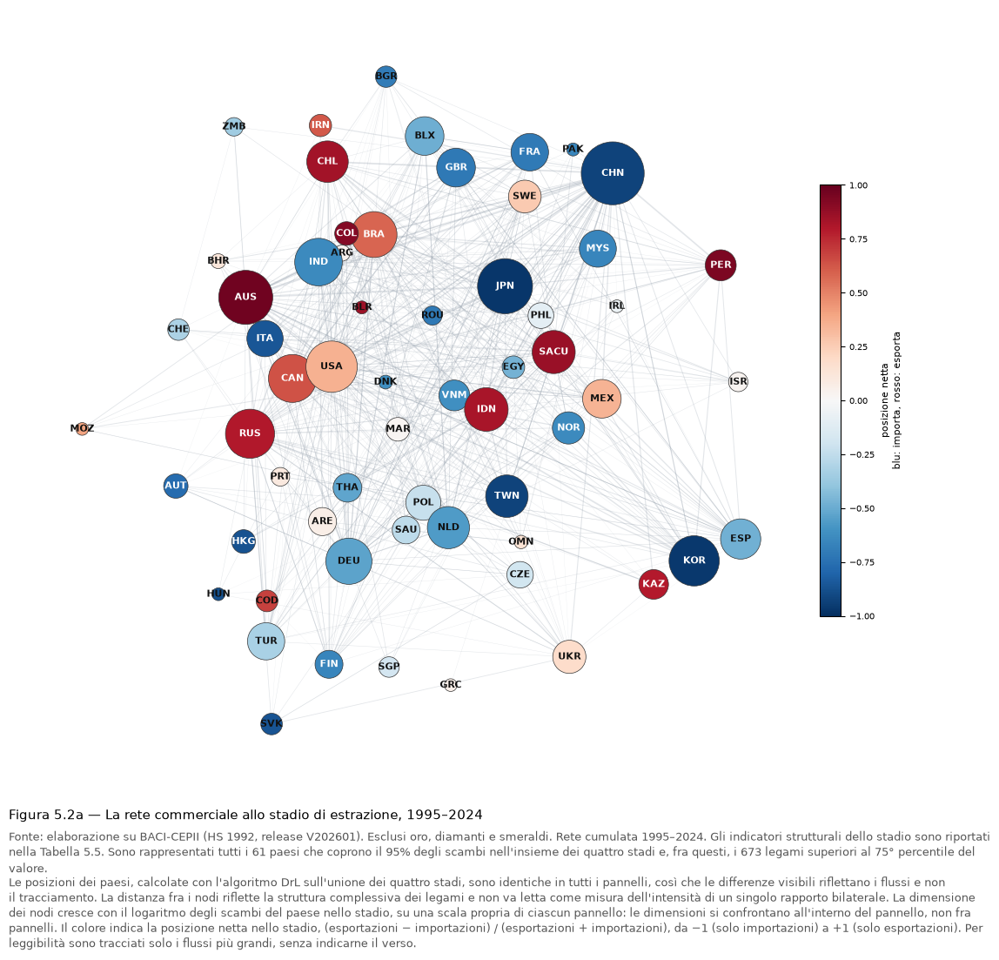

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_2a_upstream.png


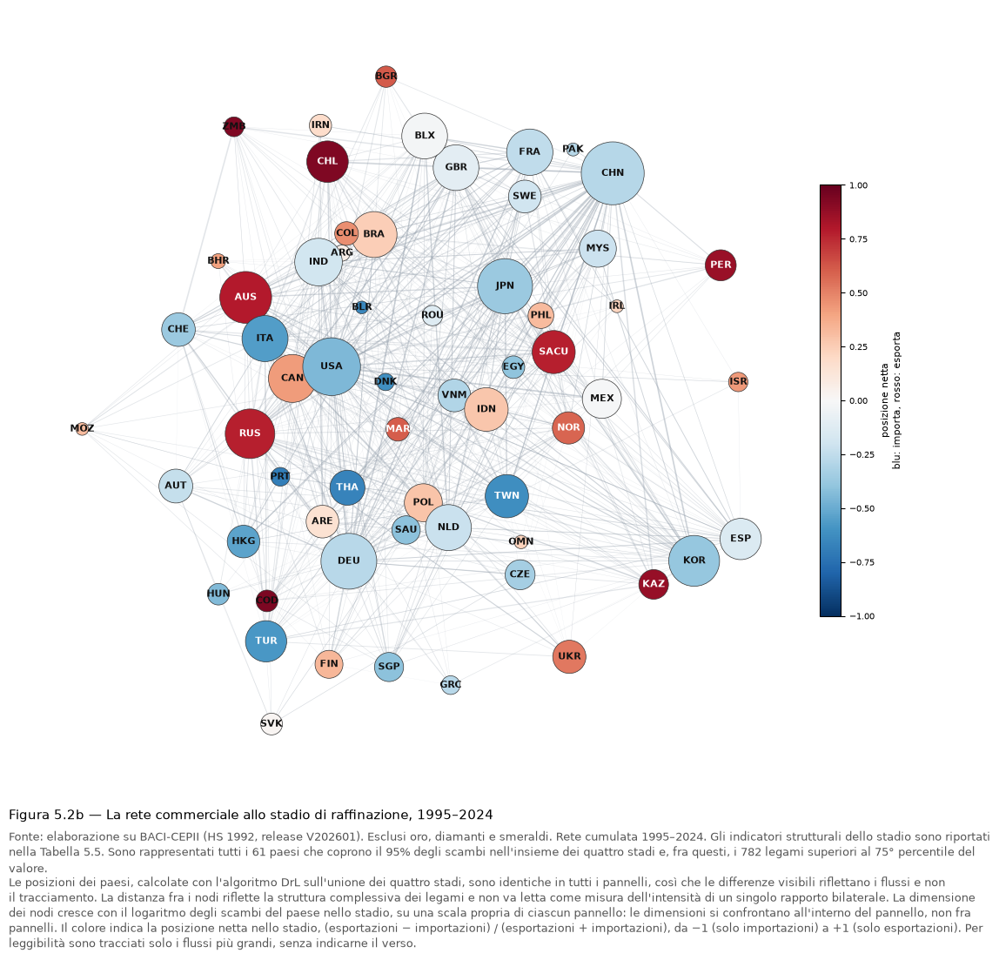

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_2b_refining.png


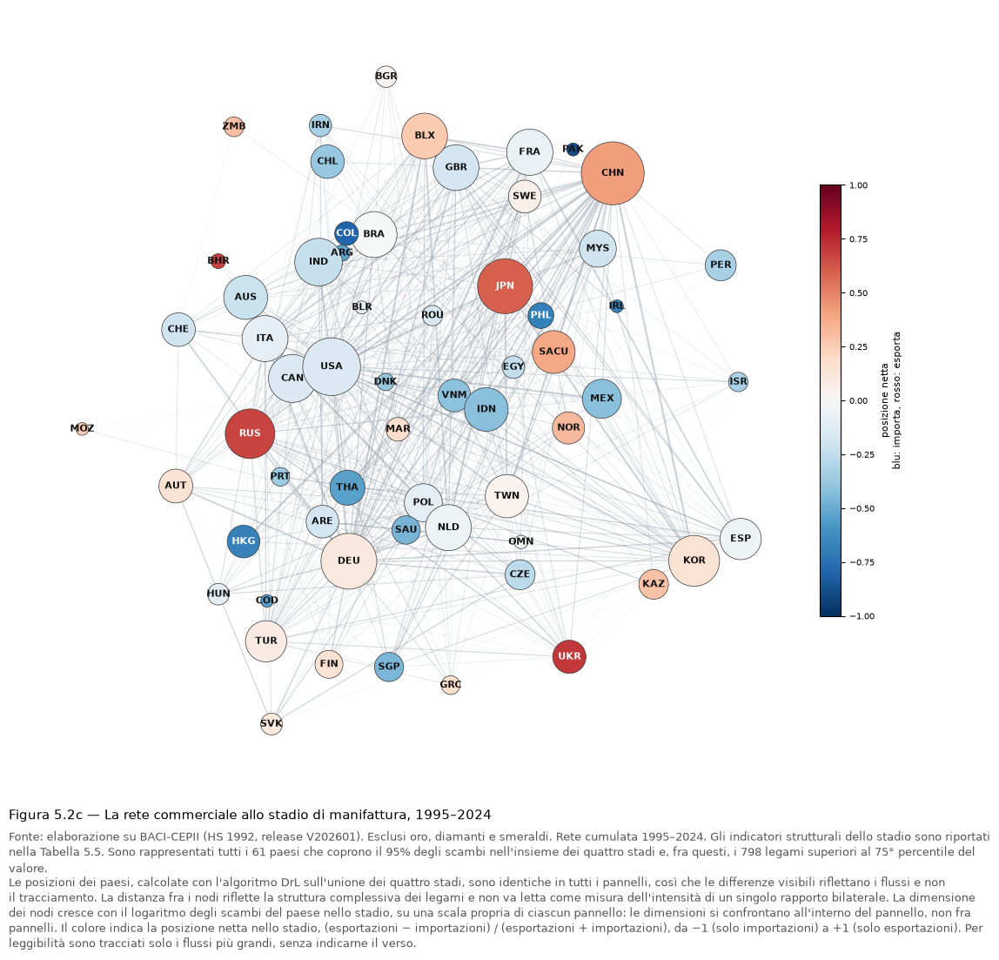

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_2c_manufacturing.png


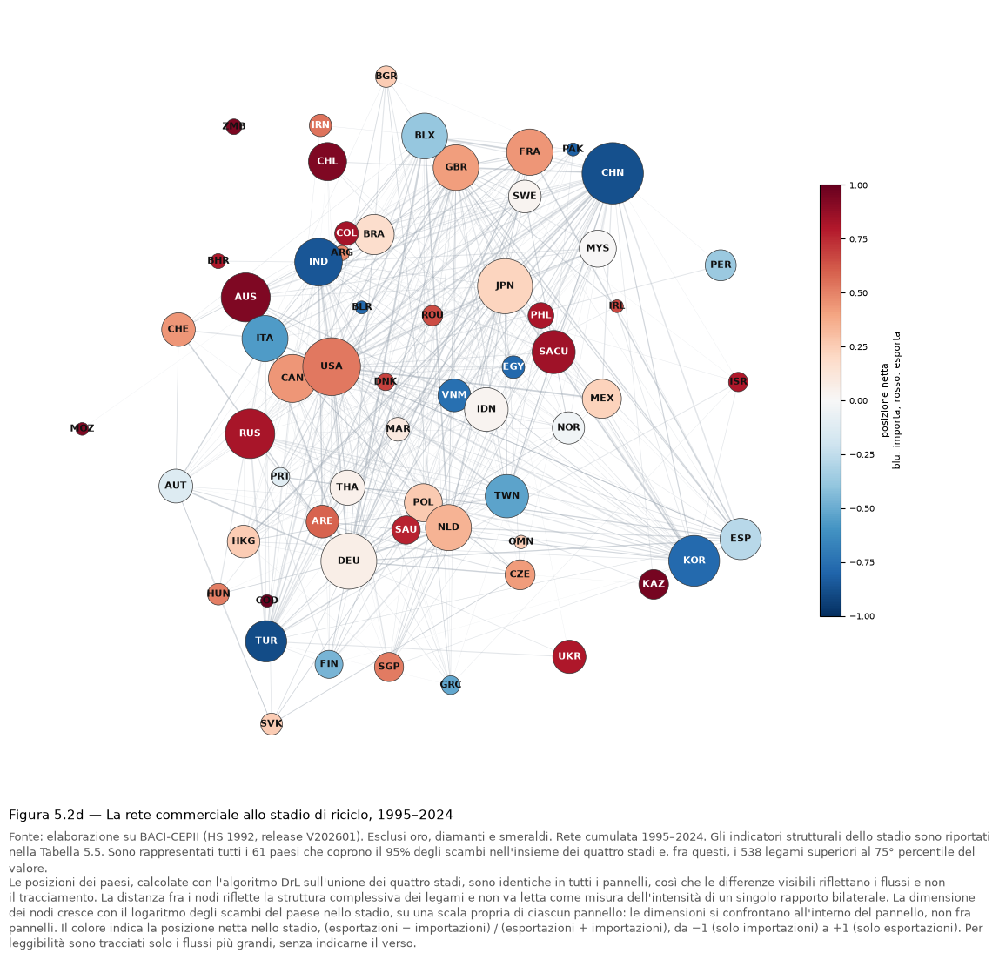

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_2d_recycling.png


In [69]:
# %% CELLA G2 — Figure 5.2a–d: i quattro stadi
# Posizioni comuni ai quattro pannelli: gli spostamenti apparenti riflettono
# i flussi e non il tracciamento. La copertura è ridotta al 95% per consentire
# l'etichettatura di tutti i nodi.
# La dimensione dei nodi riflette gli scambi del singolo stadio, su una scala
# comune ai quattro pannelli (minimo e massimo dell'unione degli stadi):
# poiché gli scambi di uno stadio non superano quelli totali, i nodi non
# eccedono l'ingombro previsto dalla separazione.
# Il colore (posizione netta) è calcolato sulla rete completa dello stadio.
LARG_S, ALT_S, FS_S = 11.0, 9.0, 11.0
SIZE_MAX_S, BASE_S = 2600, 110

pos_st, keep_st, sizes_st = shared_layout(
    [graphs[s] for s in STAGES], coverage=0.95, size_max=SIZE_MAX_S, base=BASE_S,
    pad=1.30, larghezza=LARG_S, altezza=ALT_S)
print(f"nodi rappresentati: {len(keep_st)}")

# scala comune: la stessa normalizzazione usata da shared_layout
_U = union_graph([graphs[s] for s in STAGES])
_fu = _intensita(_U)
_lu = np.log1p(np.array([_fu[n] for n in keep_st], float))
_lmin, _lmax = _lu.min(), _lu.max()

LETTERA = dict(zip(STAGES, "abcd"))
NOTA_STADI = (
    "Le posizioni dei paesi, calcolate con l'algoritmo DrL sull'unione dei "
    "quattro stadi, sono identiche in tutti i pannelli, così che le differenze "
    "visibili riflettano i flussi e non il tracciamento. La distanza fra i nodi "
    "riflette la struttura complessiva dei legami e non va letta come misura "
    "dell'intensità di un singolo rapporto bilaterale. La dimensione dei nodi "
    "cresce con il logaritmo degli scambi del paese nello stadio, su una scala "
    "propria di ciascun pannello: le dimensioni si confrontano all'interno del "
    "pannello, non fra pannelli. Il colore indica la posizione netta nello "
    "stadio, (esportazioni − importazioni) / (esportazioni + importazioni), da "
    "−1 (solo importazioni) a +1 (solo esportazioni). Per leggibilità sono "
    "tracciati solo i flussi più grandi, senza indicarne il verso.")

for st in STAGES:
    G_st = graphs[st]
    K = G_st.subgraph([n for n in keep_st if n in G_st]).copy()
    nodi = list(K.nodes())

    # scala propria del pannello, limitata all'ingombro previsto dalla
    # separazione (dimensione calcolata sull'unione degli stadi)
    f_st = _intensita(G_st)
    l_st = np.log1p(np.array([f_st[n] for n in nodi], float))
    sn = (l_st - l_st.min()) / (l_st.max() - l_st.min() + 1e-9)
    sizes = np.minimum(BASE_S + sn ** 1.4 * SIZE_MAX_S,
                       np.array([sizes_st[n] for n in nodi]))

    f, nn, na = disegna_rete(K, pos_st, sizes, fs_lab=8.0, rif=G_st)

    presenti = (f"tutti i {nn} paesi" if nn == len(keep_st)
                else f"{nn} dei {len(keep_st)} paesi")
    figura(f, altezza=ALT_S, larghezza=LARG_S, fs=FS_S, margine_basso=0.05,
           margine_sx=0.05, margine_dx=0.05,
           didascalia=f"Figura 5.2{LETTERA[st]} — La rete commerciale allo "
                      f"stadio di {LBL_ST[st].lower()}, 1995–2024",
           nota=FONTE + f" Rete cumulata 1995–2024. Gli indicatori strutturali "
                f"dello stadio sono riportati nella Tabella 5.5. Sono "
                f"rappresentati {presenti} che coprono il 95% degli scambi "
                f"nell'insieme dei quattro stadi e, fra questi, i {_mig(na)} "
                f"legami superiori al 75° percentile del valore.\n" + NOTA_STADI,
           out=FIG_DIR / f"fig_5_2{LETTERA[st]}_{st}.png")

### G3. Figure 5.3a–c — La rete nei tre livelli di rilevanza UNCTAD

Rappresentano la rete cumulata 1995–2024 delle risorse di ciascun
livello di rilevanza, con posizioni comuni ai tre pannelli. Come nelle
figure per stadio, la dimensione dei nodi riflette gli scambi del paese
nel livello, su una scala propria di ciascun pannello, e il colore la
posizione netta nel livello. Poiché ogni livello è dominato da una o
due risorse (cella T5.6bis), le figure vanno lette soprattutto come reti
di rame e alluminio (primo livello), di ferro e acciaio (livello
intermedio) e di carbone metallurgico (altre risorse).

core       29 risorse | 212 paesi | 9,986 legami
relevant    7 risorse | 213 paesi | 9,143 legami
other      17 risorse | 196 paesi | 5,113 legami
fuori dai tre livelli: ['battery_cells', 'cemented_carbide_tools', 'optical_fibre_cable', 'permanent_magnets', 'tantalum_capacitors']
nodi rappresentati: 61


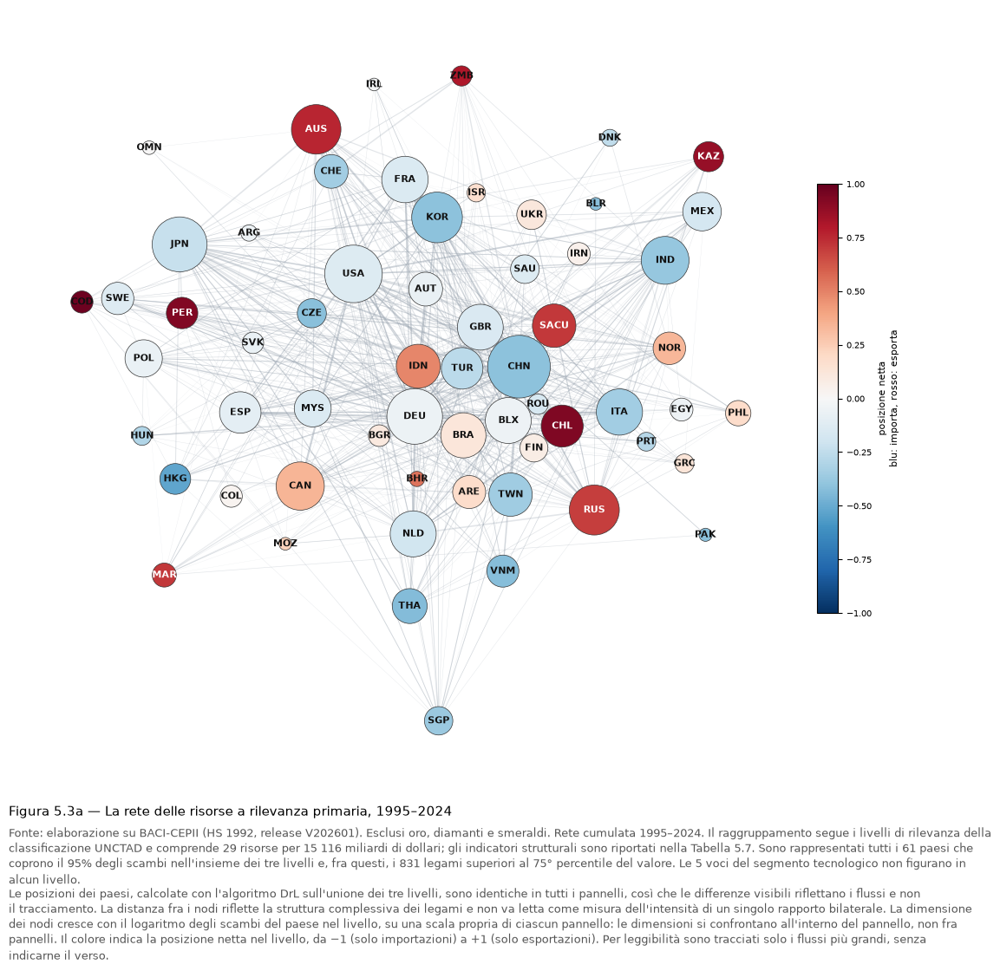

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_3a_core.png


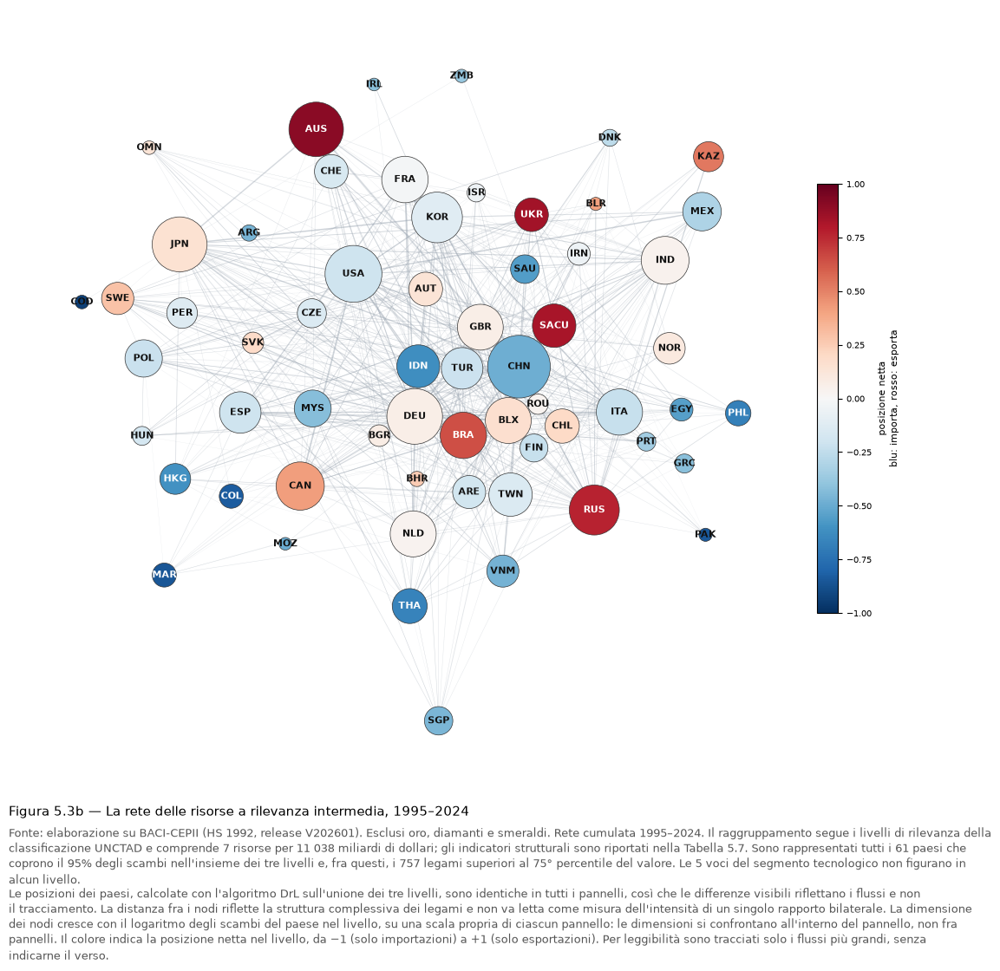

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_3b_relevant.png


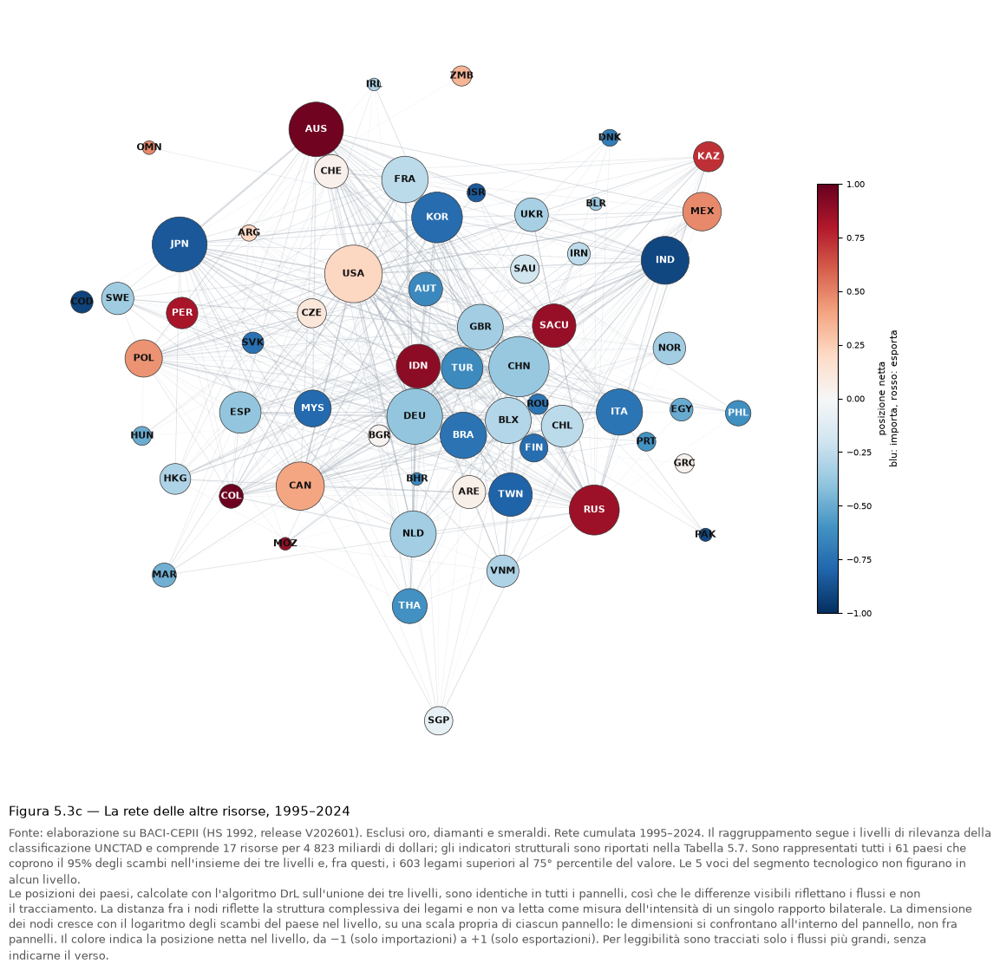

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_3c_other.png


In [70]:
# %% CELLA G3 — Figure 5.3a–c: i tre livelli di rilevanza UNCTAD
# Stesse scelte della cella G2: posizioni comuni ai tre pannelli, dimensione
# dei nodi sugli scambi del livello (scala propria del pannello, limitata
# all'ingombro previsto dalla separazione), colore calcolato sulla rete
# completa del livello.
LARG_L, ALT_L, FS_L = 11.0, 9.0, 11.0
SIZE_MAX_L, BASE_L = 2600, 110
LAYERS = ["core", "relevant", "other"]
LBL_LAY = {"core": "Rilevanza primaria", "relevant": "Rilevanza intermedia",
           "other": "Altre risorse"}
TIT_LAY = {"core": "La rete delle risorse a rilevanza primaria",
           "relevant": "La rete delle risorse a rilevanza intermedia",
           "other": "La rete delle altre risorse"}

# I raggruppamenti sono intersecati con le risorse effettivamente presenti nel
# perimetro: il dizionario ne contiene alcune che la nomenclatura del 1992 non
# consente di tracciare.
RIS_PRESENTI = set(FL.resource)
LAYER = {r: CRITICAL_CODES[r].get("unctad_layer") for r in RIS_PRESENTI}
ris_lay = {lay: {r for r, l in LAYER.items() if l == lay} for lay in LAYERS}
graphs_lay = {lay: rete(risorse=ris_lay[lay]) for lay in LAYERS}

for lay in LAYERS:
    print(f"{lay:10s} {len(ris_lay[lay]):2d} risorse | "
          f"{graphs_lay[lay].number_of_nodes()} paesi | "
          f"{graphs_lay[lay].number_of_edges():,} legami")

escluse = sorted(RIS_PRESENTI - set().union(*ris_lay.values()))
print(f"fuori dai tre livelli: {escluse}")

pos_l, keep_l, sizes_l = shared_layout(
    [graphs_lay[l] for l in LAYERS], coverage=0.95, size_max=SIZE_MAX_L,
    base=BASE_L, pad=1.30, larghezza=LARG_L, altezza=ALT_L)
print(f"nodi rappresentati: {len(keep_l)}")

NOTA_LIVELLI = (
    "Le posizioni dei paesi, calcolate con l'algoritmo DrL sull'unione dei tre "
    "livelli, sono identiche in tutti i pannelli, così che le differenze "
    "visibili riflettano i flussi e non il tracciamento. La distanza fra i nodi "
    "riflette la struttura complessiva dei legami e non va letta come misura "
    "dell'intensità di un singolo rapporto bilaterale. La dimensione dei nodi "
    "cresce con il logaritmo degli scambi del paese nel livello, su una scala "
    "propria di ciascun pannello: le dimensioni si confrontano all'interno del "
    "pannello, non fra pannelli. Il colore indica la posizione netta nel "
    "livello, da −1 (solo importazioni) a +1 (solo esportazioni). Per "
    "leggibilità sono tracciati solo i flussi più grandi, senza indicarne il "
    "verso.")

for i, lay in enumerate(LAYERS):
    G = graphs_lay[lay]
    K = G.subgraph([n for n in keep_l if n in G]).copy()
    nodi = list(K.nodes())

    f_l = _intensita(G)
    l_l = np.log1p(np.array([f_l[n] for n in nodi], float))
    sn = (l_l - l_l.min()) / (l_l.max() - l_l.min() + 1e-9)
    sizes = np.minimum(BASE_L + sn ** 1.4 * SIZE_MAX_L,
                       np.array([sizes_l[n] for n in nodi]))

    f, nn, na = disegna_rete(K, pos_l, sizes, fs_lab=8.0, rif=G)
    val = sum(d["value"] for _, _, d in G.edges(data=True)) / 1e6
    presenti = (f"tutti i {nn} paesi" if nn == len(keep_l)
                else f"{nn} dei {len(keep_l)} paesi")

    figura(f, altezza=ALT_L, larghezza=LARG_L, fs=FS_L, margine_basso=0.05,
           margine_sx=0.05, margine_dx=0.05,
           didascalia=f"Figura 5.3{'abc'[i]} — {TIT_LAY[lay]}, 1995–2024",
           nota=FONTE + f" Rete cumulata 1995–2024. Il raggruppamento segue i "
                f"livelli di rilevanza della classificazione UNCTAD e comprende "
                f"{len(ris_lay[lay])} risorse per {_mig(round(val))} miliardi di "
                f"dollari; gli indicatori strutturali sono riportati nella "
                f"Tabella 5.7. Sono rappresentati {presenti} che coprono il 95% "
                f"degli scambi nell'insieme dei tre livelli e, fra questi, i "
                f"{_mig(na)} legami superiori al 75° percentile del valore. Le "
                f"{len(escluse)} voci del segmento tecnologico non figurano in "
                f"alcun livello.\n" + NOTA_LIVELLI,
           out=FIG_DIR / f"fig_5_3{'abc'[i]}_{lay}.png")

In [71]:
# %% CELLA G4 — riepilogo dei file prodotti
print("=== FIGURE E TABELLE DEL CAPITOLO 5 ===")
for pat in ["fig_5_*.png", "tab_5_*.png"]:
    for p in sorted(FIG_DIR.glob(pat)):
        if "anteprima" not in p.name:
            print(f"  {p.name:42s} {p.stat().st_size/1024:6.0f} KB")

attese = ([f"fig_5_1_rete_aggregata.png"]
          + [f"fig_5_2{l}_{s}.png" for l, s in zip("abcd", STAGES)]
          + [f"fig_5_3{l}_{y}.png" for l, y in zip("abc", ["core", "relevant", "other"])])
mancanti = [f for f in attese if not (FIG_DIR / f).exists()]
print(f"\nfigure attese {len(attese)} | mancanti {len(mancanti)}"
      + (f": {mancanti}" if mancanti else ""))

=== FIGURE E TABELLE DEL CAPITOLO 5 ===
  fig_5_1_intermediazione_valle.png             574 KB
  fig_5_1_rete_aggregata.png                   6286 KB
  fig_5_2_rete_aggregata.png                   4987 KB
  fig_5_2a_upstream.png                        5740 KB
  fig_5_2b_refining.png                        6089 KB
  fig_5_2c_manufacturing.png                   6053 KB
  fig_5_2d_recycling.png                       4980 KB
  fig_5_3_1995.png                             5313 KB
  fig_5_3_2015.png                             7357 KB
  fig_5_3_quattro_stadi.png                   11880 KB
  fig_5_3a_core.png                            5403 KB
  fig_5_3a_upstream.png                        5256 KB
  fig_5_3b_refining.png                        4983 KB
  fig_5_3b_relevant.png                        5013 KB
  fig_5_3c_manufacturing.png                   4809 KB
  fig_5_3c_other.png                           4742 KB
  fig_5_3d_recycling.png                       4756 KB
  fig_5_4_intermediazione

### MAP1. Esportazione per mappe esterne (facoltativa)

Produce, per ciascuno stadio, i file GeoJSON dei 400 flussi maggiori e
dei nodi, sulla rete cumulata 1995–2024 e sulle tre finestre decennali,
per la visualizzazione in un programma GIS (QGIS, GeoLibre). I flussi
seguono l'arco di cerchio massimo fra i centroidi dei paesi, spezzato
all'antimeridiano; i nodi ricostruiti usano il centroide del membro
principale (Sudafrica per la SACU, Belgio per Belgio-Lussemburgo).
I valori sono cumulati sul periodo, in miliardi di dollari. I file non
entrano nella tesi.

In [72]:
# %% CELLA MAP1 — esportazione GeoJSON (cumulato e decenni)
# Facoltativa: produce i file per una mappa esterna (GeoLibre, QGIS), non
# figure della tesi. I valori sono cumulati sul periodo, in miliardi di dollari.
import json

GEO_DIR = GRAPH_DIR / "geo"
GEO_DIR.mkdir(exist_ok=True)

# Centroidi dei paesi: scaricati una sola volta e conservati in locale, così
# che la cella non dipenda dalla rete né dalla disponibilità del file remoto.
CENT_URL = ("https://raw.githubusercontent.com/google/dspl/master/samples/"
            "google/canonical/countries.csv")
_cen_file = GEO_DIR / "countries_centroids.csv"
if not _cen_file.exists():
    pd.read_csv(CENT_URL, keep_default_na=False).to_csv(_cen_file, index=False)
cen = (pd.read_csv(_cen_file, keep_default_na=False)       # "NA" = Namibia
         .set_index("country")[["latitude", "longitude"]])

_cc2 = pd.read_csv(FOLDERS["HS22"] / "country_codes_V202601.csv",
                   dtype=str, keep_default_na=False)
ISO2 = dict(zip(_cc2.country_code.astype(int), _cc2.country_iso2))
# i nodi aggregati non hanno un iso2 proprio: si usa il centroide del membro
# principale. Per le Antille Olandesi il file dei centroidi, anteriore al
# 2010, riporta il vecchio codice "AN" e non Curaçao ("CW").
ISO2.update({58: "BE", 711: "ZA", 849: "GU", 891: "RS", 736: "SD",
             530: "AN" if "AN" in cen.index else "CW", 490: "TW"})

COORD = {ISO[c]: (float(cen.loc[i2, "longitude"]), float(cen.loc[i2, "latitude"]))
         for c, i2 in ISO2.items() if c in ISO and i2 in cen.index}

# Nodi ancora assenti dal file dei centroidi: coordinate inserite a mano
# (Curaçao per le Antille Olandesi ricostruite, Gustavia per Saint-Barthélemy)
COORD.setdefault("ANT", (-68.99, 12.17))
COORD.setdefault("BLM", (-62.85, 17.90))
print(f"coordinate disponibili per {len(COORD)} etichette")


def great_circle(lon1, lat1, lon2, lat2, n=48):
    """Geodetica: per rotte lunghe il segmento dritto è visivamente sbagliato."""
    r = np.radians
    f1, l1, f2, l2 = r(lat1), r(lon1), r(lat2), r(lon2)
    d = 2 * np.arcsin(np.sqrt(np.sin((f2 - f1) / 2) ** 2 +
                              np.cos(f1) * np.cos(f2) * np.sin((l2 - l1) / 2) ** 2))
    if d < 1e-9:
        return [(lon1, lat1), (lon2, lat2)]
    t = np.linspace(0, 1, n)
    A, B = np.sin((1 - t) * d) / np.sin(d), np.sin(t * d) / np.sin(d)
    x = A * np.cos(f1) * np.cos(l1) + B * np.cos(f2) * np.cos(l2)
    y = A * np.cos(f1) * np.sin(l1) + B * np.cos(f2) * np.sin(l2)
    z = A * np.sin(f1) + B * np.sin(f2)
    return list(zip(np.degrees(np.arctan2(y, x)),
                    np.degrees(np.arctan2(z, np.hypot(x, y)))))


def split_antimeridian(pts):
    """Spezza a ±180 interpolando la latitudine del taglio, così la linea
    arriva al bordo della mappa invece di interrompersi prima."""
    segs, cur = [], [pts[0]]
    for (x0, y0), (x1, y1) in zip(pts, pts[1:]):
        if abs(x1 - x0) > 180:
            edge = 180 if x0 > 0 else -180
            x1u = x1 + 360 if x0 > 0 else x1 - 360
            yc = y0 + (y1 - y0) * (edge - x0) / (x1u - x0)
            cur.append((edge, yc))
            segs.append(cur)
            cur = [(-edge, yc), (x1, y1)]
        else:
            cur.append((x1, y1))
    segs.append(cur)
    return [s for s in segs if len(s) > 1]


MANCANTI = set()

def export_geojson(H, stage, period="1995-2024", top_n=400):
    e = sorted(H.edges(data="value"), key=lambda x: x[2], reverse=True)[:top_n]
    feats = []
    for u, v, val in e:
        if u not in COORD or v not in COORD:
            continue
        segs = split_antimeridian(great_circle(*COORD[u], *COORD[v]))
        feats.append(dict(type="Feature",
            geometry=dict(type="MultiLineString",
                          coordinates=[[[float(x), float(y)] for x, y in s] for s in segs]),
            properties=dict(exp=u, imp=v, stage=stage, period=period,
                            value_mld=round(val / 1e6, 3),
                            log_value=round(float(np.log10(max(val, 1))), 3))))
    tag = f"{stage}_{period}"
    (GEO_DIR / f"flows_{tag}.geojson").write_text(
        json.dumps(dict(type="FeatureCollection", features=feats)))

    out_v = dict(H.out_degree(weight="value"))
    in_v = dict(H.in_degree(weight="value"))
    nf = []
    for n in H:
        if n not in COORD:
            continue
        tot = out_v[n] + in_v[n]
        nf.append(dict(type="Feature",
            geometry=dict(type="Point", coordinates=list(COORD[n])),
            properties=dict(iso=n, stage=stage, period=period,
                            strength_mld=round(tot / 1e6, 2),
                            export_mld=round(out_v[n] / 1e6, 2),
                            import_mld=round(in_v[n] / 1e6, 2),
                            net=round((out_v[n] - in_v[n]) / max(tot, 1), 3))))
    (GEO_DIR / f"nodes_{tag}.geojson").write_text(
        json.dumps(dict(type="FeatureCollection", features=nf)))
    missing = sorted(n for n in H if n not in COORD)
    MANCANTI.update(missing)
    print(f"  {tag:28s} {len(feats):4d} flussi, {len(nf):3d} nodi"
          f"{'  | senza coordinate: ' + str(missing) if missing else ''}")


for st in STAGES:
    export_geojson(graphs[st], st)

for lbl, yy in FINESTRE.items():
    g = rete(anni=yy, per_stadio=True)
    for st in STAGES:
        export_geojson(g[st], st, lbl)

print(f"\nnodi senza coordinate in almeno un file: {sorted(MANCANTI) or 'nessuno'}")

coordinate disponibili per 228 etichette
  upstream_1995-2024            400 flussi, 207 nodi
  refining_1995-2024            400 flussi, 207 nodi
  manufacturing_1995-2024       400 flussi, 213 nodi
  recycling_1995-2024           400 flussi, 203 nodi
  upstream_1995-2004            400 flussi, 188 nodi
  refining_1995-2004            400 flussi, 182 nodi
  manufacturing_1995-2004       400 flussi, 202 nodi
  recycling_1995-2004           400 flussi, 160 nodi
  upstream_2005-2014            400 flussi, 194 nodi
  refining_2005-2014            400 flussi, 198 nodi
  manufacturing_2005-2014       400 flussi, 207 nodi
  recycling_2005-2014           400 flussi, 200 nodi
  upstream_2015-2024            400 flussi, 192 nodi
  refining_2015-2024            400 flussi, 193 nodi
  manufacturing_2015-2024       400 flussi, 207 nodi
  recycling_2015-2024           400 flussi, 188 nodi

nodi senza coordinate in almeno un file: nessuno


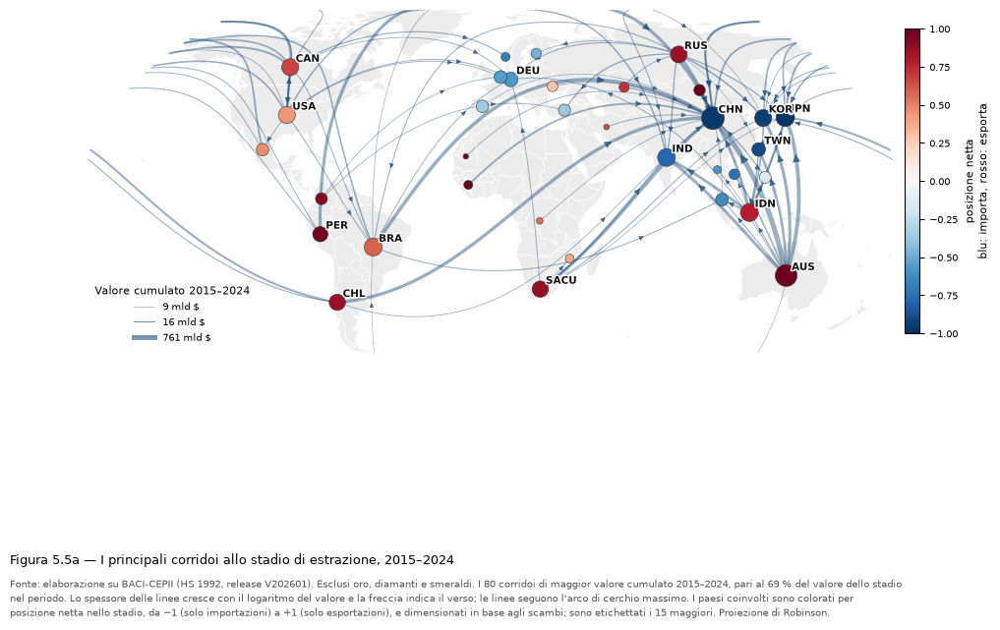

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_5a_mappa_upstream.png


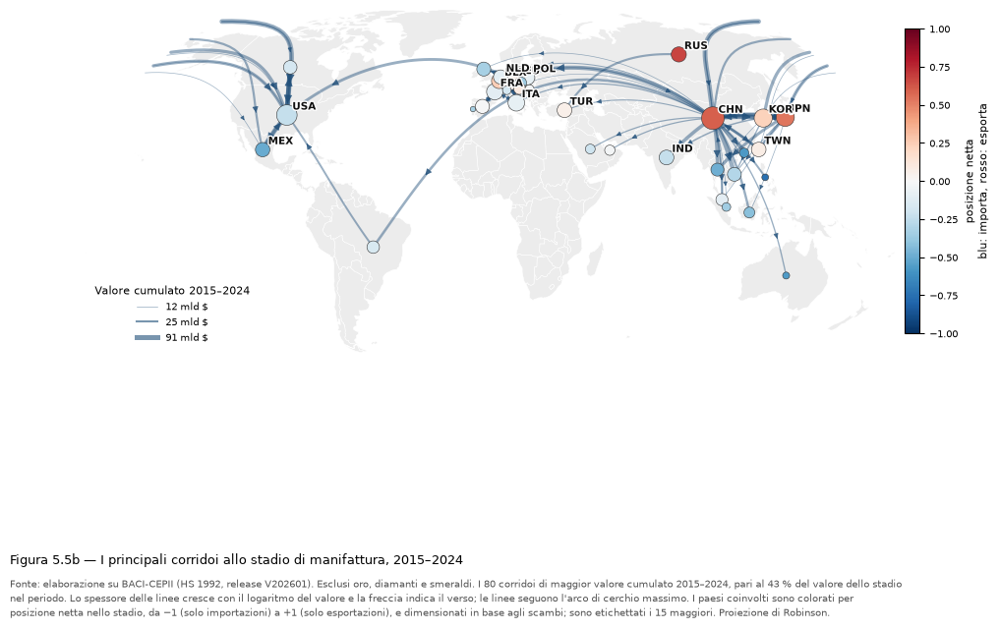

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_5_5b_mappa_manufacturing.png


In [73]:
# %% CELLA MAP2 — Figure 5.5a–b: mappe dei principali corridoi
# Legge i file GeoJSON della cella MAP1. Richiede geopandas
# (pip install geopandas). I confini dei paesi (Natural Earth, 1:110 milioni)
# sono scaricati una sola volta e conservati in locale.
import geopandas as gpd
import matplotlib.patheffects as pe
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D

CRS_MAPPA = "ESRI:54030"          # proiezione di Robinson
_world_file = GEO_DIR / "ne_110m_countries.geojson"
if not _world_file.exists():
    _url = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
            "master/geojson/ne_110m_admin_0_countries.geojson")
    gpd.read_file(_url).to_file(_world_file, driver="GeoJSON")
WORLD = gpd.read_file(_world_file)
if "CONTINENT" in WORLD.columns:
    WORLD = WORLD[WORLD.CONTINENT != "Antarctica"]
WORLD = WORLD.to_crs(CRS_MAPPA)

COL_FLUSSO = "#1f4e79"


def mappa_corridoi(stage, period="2015-2024", top=80, n_etich=15):
    """Funzione di disegno per figura(): primi `top` corridoi dello stadio nel
    periodo, con i paesi coinvolti colorati per posizione netta."""
    fl = gpd.read_file(GEO_DIR / f"flows_{stage}_{period}.geojson")
    nd = gpd.read_file(GEO_DIR / f"nodes_{stage}_{period}.geojson")
    fl = fl.nlargest(top, "value_mld").to_crs(CRS_MAPPA).reset_index(drop=True)
    nd = nd[nd.iso.isin(set(fl.exp) | set(fl.imp))].to_crs(CRS_MAPPA)

    # spessore delle linee e dimensione dei nodi su scala logaritmica
    lv = np.log10(fl.value_mld.values)
    lo, hi = lv.min(), lv.max()
    _w = lambda v: 0.4 + 3.2 * (np.log10(v) - lo) / (hi - lo + 1e-9)
    w = _w(fl.value_mld.values)
    ls = np.log10(nd.strength_mld.clip(lower=0.01).values)
    sz = 15 + 260 * ((ls - ls.min()) / (ls.max() - ls.min() + 1e-9)) ** 1.3
    norm, cmap = mcolors.Normalize(-1, 1), plt.cm.RdBu_r

    def _f(ax):
        WORLD.plot(ax=ax, color="#ececec", edgecolor="white", linewidth=0.4,
                   zorder=1)
        for i in np.argsort(w):                     # i flussi grandi sopra
            geom = fl.geometry.iloc[i]
            parti = list(geom.geoms) if geom.geom_type == "MultiLineString" else [geom]
            for p in parti:
                x, y = p.xy
                ax.plot(x, y, color=COL_FLUSSO, lw=w[i], alpha=0.45,
                        solid_capstyle="round", zorder=2)
            # freccia a tre quarti dell'ultimo tratto, per non finire sotto il nodo
            x, y = parti[-1].xy
            k = max(1, int(0.75 * len(x)))
            ax.annotate("", xy=(x[k], y[k]), xytext=(x[k - 1], y[k - 1]),
                        arrowprops=dict(arrowstyle="-|>", color=COL_FLUSSO,
                                        lw=0.6, alpha=0.75,
                                        mutation_scale=5 + 2.5 * w[i]),
                        zorder=3)

        ax.scatter(nd.geometry.x, nd.geometry.y, s=sz, c=nd.net, cmap=cmap,
                   norm=norm, edgecolor="#333333", linewidth=0.4, zorder=4)
        for _, r in nd.nlargest(n_etich, "strength_mld").iterrows():
            ax.annotate(r.iso, (r.geometry.x, r.geometry.y), xytext=(4, 4),
                        textcoords="offset points", fontsize=7.5,
                        fontweight="bold", color="#111111", zorder=5,
                        path_effects=[pe.withStroke(linewidth=2, foreground="white")])

        # legenda degli spessori: minimo, mediana e massimo dei corridoi tracciati
        ref = fl.value_mld.quantile([0.0, 0.5, 1.0]).values
        ax.legend([Line2D([], [], color=COL_FLUSSO, lw=_w(v), alpha=0.6) for v in ref],
                  [f"{_num(v, 0)} mld $" for v in ref],
                  title=f"Valore cumulato {period.replace('-', '–')}",
                  loc="lower left", frameon=False, fontsize=7.5, title_fontsize=8)

        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cb = ax.figure.colorbar(sm, ax=ax, shrink=0.5, pad=0.01)
        cb.set_label("posizione netta\nblu: importa, rosso: esporta", fontsize=8)
        cb.ax.tick_params(labelsize=7.5)

        xmin, ymin, xmax, ymax = WORLD.total_bounds
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_aspect("equal")
        ax.set_axis_off()

    # quota del valore dello stadio coperta dai corridoi tracciati
    a, b = map(int, period.split("-"))
    tot = FL[(FL.stage_name == stage) & FL.year.between(a, b)].value.sum() / 1e6
    return _f, len(fl), 100 * fl.value_mld.sum() / tot


for lettera, st in zip("ab", ["upstream", "manufacturing"]):
    f, n, quota = mappa_corridoi(st, "2015-2024")
    figura(f, altezza=6.2, larghezza=11,
           didascalia=f"Figura 5.5{lettera} — I principali corridoi allo stadio "
                      f"di {LBL_ST[st].lower()}, 2015–2024",
           nota=FONTE + f" I {n} corridoi di maggior valore cumulato 2015–2024, "
                f"pari al {_pct(quota, 0)} del valore dello stadio nel periodo. Lo "
                f"spessore delle linee cresce con il logaritmo del valore e la "
                f"freccia indica il verso; le linee seguono l'arco di cerchio "
                f"massimo. I paesi coinvolti sono colorati per posizione netta "
                f"nello stadio, da −1 (solo importazioni) a +1 (solo "
                f"esportazioni), e dimensionati in base agli scambi; sono "
                f"etichettati i {15} maggiori. Proiezione di Robinson.",
           out=FIG_DIR / f"fig_5_5{lettera}_mappa_{st}.png")

### WMD1. Validazione esterna con il World Mining Data: funzioni

Per verificare che il dizionario HS misuri ciò che dichiara, le
esportazioni di ciascun paese sono confrontate con la produzione rilevata
dal World Mining Data (Ministero federale delle finanze austriaco), una
fonte indipendente costruita con metodologia diversa, sulla media
2019–2023. Se la classificazione è corretta, i paesi che producono un
minerale devono essere in larga parte quelli che lo esportano allo stadio
corrispondente: la correlazione di rango fra le due graduatorie è un test
di validità, non un risultato sostantivo.

Ogni foglio del World Mining Data è associato a una risorsa e allo stadio
coerente con la natura del dato: estrazione per la produzione mineraria,
raffinazione per i metalli rilevati dopo la fusione. Il confronto usa
tutti i flussi (`D`), compresi oro, argento e diamanti, che il World
Mining Data rileva. Per ogni coppia risorsa–stadio si calcolano la
correlazione di Spearman, il numero di paesi in comune fra i primi cinque
produttori e i primi cinque esportatori, e la quota delle esportazioni
detenuta dal primo produttore.

Per alcune risorse il confronto è disomogeneo per costruzione: oro e
litio confrontano la produzione mineraria con esportazioni di prodotti
raffinati, tantalio e berillio concentrati minerari con lo stadio di
raffinazione, per mancanza di una voce estrattiva nel dizionario. In
questi casi una correlazione bassa misura la distanza fra luogo di
produzione e luogo di commercio, non un errore di classificazione.

In [74]:
# %% CELLA WMD1 — validazione esterna: funzioni
"""
============================================================================
VALIDAZIONE ESTERNA — confronto con World Mining Data
============================================================================

Confronta le esportazioni ricavate dal dizionario HS con la produzione
mineraria e metallurgica rilevata dal World Mining Data (Federal Ministry of
Finance, Austria), fonte indipendente costruita con metodologia diversa.

Logica: se la classificazione HS misura cio' che dichiara di misurare, i paesi
che producono un minerale devono essere gli stessi che lo esportano allo stadio
corrispondente. La correlazione fra le due graduatorie e' quindi un test di
validita' della classificazione, non un risultato sostantivo.

Attenzione allo stadio: alcuni fogli WMD rilevano produzione MINERARIA
(bauxite, rame in miniera), altri produzione METALLURGICA (alluminio primario,
germanio). Il confronto va fatto con lo stadio corrispondente.

PREREQUISITI: OUT_DIR, MERGE_CODES, ISO, NAME (celle 2 e 3) e il panel D
(cella 11). L'esecuzione e' nella cella WMD2.
============================================================================
"""

from scipy.stats import spearmanr

# === CONFIG ================================================================
WMD = OUT_DIR.parent / "6.4. Production_of_Mineral_Raw_Materials_of_individual_Countries_by_Minerals.xlsx"

ANNI_WMD = range(2019, 2024)          # copertura del World Mining Data

# --- nomi paese WMD che non coincidono con quelli BACI ---------------------
# I nodi aggregati (SACU, BLX, SRB+MNE, SDN+SSD) non richiedono correzione:
# il nome BACI del predecessore e' risolto da MERGE_CODES a valle.
FIX_NOMI = {
    "United States": "USA",
    "Russia": "Russian Federation",
    "Korea, South": "Rep. of Korea",
    "Korea, North": "Dem. People's Rep. of Korea",
    "Congo, D.R.": "Dem. Rep. of the Congo",
    "Congo, Rep.": "Congo",
    "Cote d'Ivoire": "Côte d'Ivoire",
    "Bolivia": "Bolivia (Plurinational State of)",
    "Tanzania": "United Rep. of Tanzania",
    "Laos": "Lao People's Dem. Rep.",
    "Dominican Republic": "Dominican Rep.",
    "Central African Republic": "Central African Rep.",
    "Moldova": "Rep. of Moldova",
    "Cape Verde": "Cabo Verde",
    "Taiwan": "Taiwan (Other Asia, nes)",
    "Solomon Islands": "Solomon Isds",
    "French Guiana": None,        # assenti in BACI
    "Kosovo": None,
    "Christmas Island": None,
}

# --- foglio WMD -> (risorsa, stadio di confronto) --------------------------
# Lo stadio riflette la natura del dato: estrazione per i minerali, raffinazione
# per i metalli che il WMD rileva a valle della fusione.
# Gallio, indio e renio sono esclusi: le rispettive risorse non sopravvivono
# all'armonizzazione (§6), perche' prive di voce HS propria.
MAP_WMD = {
    "Iron (Fe)":            ("iron_ore_steel", "upstream"),
    "Chromium (Cr2O3)":     ("chromium", "upstream"),
    "Cobalt":               ("cobalt", "upstream"),
    "Manganese":            ("manganese", "upstream"),
    "Molybdenum":           ("molybdenum", "upstream"),
    "Nickel":               ("nickel", "upstream"),
    "Niobium (Nb2O5)":      ("niobium", "upstream"),
    "Tantalum (Ta2O5)":     ("tantalum", "refining"),    # nessun upstream nel dizionario
    "Titanium (TiO2)":      ("titanium", "upstream"),
    "Tungsten (W)":         ("tungsten", "upstream"),
    "Vanadium (V)":         ("vanadium", "refining"),
    "Aluminium":            ("aluminium-bauxite", "refining"),   # alluminio primario
    "Bauxite":              ("aluminium-bauxite", "upstream"),
    "Antimony":             ("antimony", "upstream"),
    "Arsenic":              ("arsenic", "refining"),
    "Beryllium (conc.)":    ("beryllium", "refining"),
    "Bismuth":              ("bismuth", "manufacturing"),
    "Cadmium":              ("cadmium", "manufacturing"),
    "Copper":               ("copper", "upstream"),
    "Germanium":            ("germanium", "refining"),
    "Lead":                 ("lead", "upstream"),
    "Lithium (Li2O)":       ("lithium", "refining"),
    "Mercury":              ("mercury", "refining"),
    "Rare Earths (REO)":    ("ree", "refining"),
    "Selenium":             ("selenium", "refining"),
    "Tin":                  ("tin", "upstream"),
    "Zinc":                 ("zinc", "upstream"),
    "Gold":                 ("gold", "refining"),
    "Platinum":             ("platinum", "refining"),
    "Palladium":            ("pgm_other_and_palladium", "refining"),
    "Rhodium":              ("pgm_other_and_palladium", "refining"),
    "Silver":               ("silver", "upstream"),
    "Baryte":               ("barite", "upstream"),
    "Bentonite":            ("bentonite", "upstream"),
    "Boron Minerals":       ("boron_borates", "upstream"),
    "Diamonds (Gem)":       ("diamonds", "upstream"),
    "Diamonds (Ind)":       ("diamonds", "upstream"),
    "Diatomite":            ("diatomite", "upstream"),
    "Feldspar":             ("feldspar", "upstream"),
    "Fluorspar":            ("fluorspar", "upstream"),
    "Graphite":             ("graphite", "upstream"),
    "Gypsum and Anhydrite": ("gypsum", "upstream"),
    "Kaolin (China-Clay)":  ("kaolin", "upstream"),
    "Magnesite":            ("magnesium", "upstream"),
    "Perlite":              ("perlite", "upstream"),
    "Phosphate Rock (P2O5)": ("phosphates", "upstream"),
    "Potash (K2O)":         ("potassium", "upstream"),
    "Salt (rock, brines, marine)": ("sodium", "upstream"),
    "Sulfur (elementar & industrial)": ("sulphur", "upstream"),
    "Zircon":               ("zirconium", "upstream"),
    "Coking Coal":          ("metallurgical_coal", "upstream"),
    "Uranium (U3O8)":       ("uranium", "upstream"),
}


# ===========================================================================
def _norm_paese(s):
    """Nome paese ridotto alle sole lettere minuscole, per l'abbinamento fra
    le denominazioni del World Mining Data e quelle di BACI. Nome distinto da
    _norm della cella 4, che normalizza le intestazioni delle concordanze."""
    return re.sub(r"[^a-z]", "", str(s).lower())


def controlla_mappa(verbose=True):
    """Verifica che ogni coppia (risorsa, stadio) di MAP_WMD esista nel panel:
    una coppia assente produrrebbe un confronto vuoto senza alcun avviso."""
    presenti = set(map(tuple, D[["resource", "stage_name"]].drop_duplicates().values))
    mancanti = sorted({v for v in MAP_WMD.values() if v not in presenti})
    if verbose:
        print(f"[MAPPA] {len(MAP_WMD)} fogli mappati, "
              f"{len(set(MAP_WMD.values()))} coppie risorsa-stadio")
        if mancanti:
            print(f"[MAPPA] coppie assenti dal panel: {mancanti}")
    return mancanti


def carica_wmd(path=None, anni=ANNI_WMD, verbose=True):
    """Legge i fogli mappati e restituisce la produzione media per paese e
    risorsa, con il codice paese BACI. La mappa nome -> codice e' ricavata dal
    dizionario NAME gia' in memoria, senza rileggere il file dei codici."""
    path = path or WMD
    if not path.exists():
        raise FileNotFoundError(
            f"File World Mining Data non trovato: {path}\n"
            f"Imposta la variabile WMD sul percorso corretto.")

    lookup = {_norm_paese(v): k for k, v in NAME.items()}

    xls = pd.ExcelFile(path)
    out, non_abbinati = [], set()

    for sheet, (res, stage) in MAP_WMD.items():
        if sheet not in xls.sheet_names:
            if verbose:
                print(f"[WARN] foglio assente: {sheet}")
            continue

        raw = xls.parse(sheet, header=None)
        hdr = next((i for i in range(min(8, len(raw)))
                    if str(raw.iloc[i, 0]).strip().lower() == "country"), None)
        if hdr is None:
            if verbose:
                print(f"[WARN] intestazione non trovata: {sheet}")
            continue

        d = raw.iloc[hdr + 1:].copy()
        d.columns = ["country", "unit"] + [str(c) for c in raw.iloc[hdr, 2:]]
        yrs = [c for c in d.columns
               if re.match(r"^\d{4}(\.0)?$", str(c)) and int(float(c)) in anni]
        if not yrs:
            continue

        d["country"] = d.country.astype(str).str.strip()
        d = d[~d.country.str.lower().isin(["nan", "total", "world", "", "none"])]
        for y in yrs:
            d[y] = pd.to_numeric(d[y], errors="coerce")
        d["prod"] = d[yrs].mean(axis=1)
        d = d.dropna(subset=["prod"])
        d = d[d["prod"] > 0]

        d["nome_baci"] = d.country.map(lambda n: FIX_NOMI.get(n, n))
        d = d[d.nome_baci.notna()]
        d["code"] = d.nome_baci.map(lambda n: lookup.get(_norm_paese(n)))
        non_abbinati |= set(d[d.code.isna()].country)
        d = d.dropna(subset=["code"])

        out.append(pd.DataFrame({"resource": res, "stage_name": stage,
                                 "code": d.code.astype(int).values,
                                 "prod": d["prod"].values}))

    W = pd.concat(out, ignore_index=True)
    # i due fogli sui diamanti (gemme e industriali) confluiscono in una risorsa
    W = W.groupby(["resource", "stage_name", "code"], as_index=False)["prod"].sum()
    W["code"] = W.code.replace(MERGE_CODES)
    W = W.groupby(["resource", "stage_name", "code"], as_index=False)["prod"].sum()

    if verbose:
        print(f"[WMD] {W.resource.nunique()} risorse, {len(W)} osservazioni "
              f"paese-risorsa, media {min(anni)}-{max(anni)}")
        if non_abbinati:
            print(f"[WMD] paesi non abbinati: {sorted(non_abbinati)}")
    return W


def carica_export(anni=ANNI_WMD):
    """Esportazioni per paese, risorsa e stadio, dal panel gia' in memoria.
    Si usa D e non DI: il confronto riguarda anche oro, argento e diamanti,
    rilevati dal World Mining Data ma esclusi dal perimetro industriale."""
    E = (D[D.year.isin(anni)]
         .groupby(["resource", "stage_name", "exp"], observed=True, as_index=False)
         .value.sum())
    return E.rename(columns={"exp": "code", "value": "export"})


def valida(W=None, E=None, top=5, salva=True):
    controlla_mappa()
    W = carica_wmd() if W is None else W
    E = carica_export() if E is None else E

    M = W.merge(E, on=["resource", "stage_name", "code"], how="outer")
    M["prod"] = M["prod"].fillna(0.0)
    M["export"] = M["export"].fillna(0.0)

    righe = []
    for (res, stage), g in M.groupby(["resource", "stage_name"]):
        g = g[(g["prod"] > 0) | (g["export"] > 0)]
        if len(g) < 5 or g["prod"].sum() == 0 or g["export"].sum() == 0:
            continue
        rho, p = spearmanr(g["prod"], g["export"])

        pw = set(g.nlargest(top, "prod").code)
        pe = set(g.nlargest(top, "export").code)
        primo_p = g.nlargest(1, "prod").iloc[0]
        primo_e = g.nlargest(1, "export").iloc[0]

        righe.append(dict(
            risorsa=res, stadio=stage, paesi=len(g),
            rho=rho, p_value=p, top5_comuni=len(pw & pe),
            primo_produttore=ISO.get(int(primo_p.code), "?"),
            quota_prod=primo_p["prod"] / g["prod"].sum(),
            primo_esportatore=ISO.get(int(primo_e.code), "?"),
            quota_exp_del_primo_prod=primo_p["export"] / g["export"].sum(),
        ))

    V = pd.DataFrame(righe).sort_values("rho", ascending=False).reset_index(drop=True)
    if salva:
        V.to_csv(OUT_DIR / "validazione_wmd.csv", index=False)
        M.to_csv(OUT_DIR / "validazione_wmd_dettaglio.csv", index=False)

    print(f"\n=== VALIDAZIONE ESTERNA (World Mining Data {min(ANNI_WMD)}-{max(ANNI_WMD)}) ===")
    print(f"risorse confrontate                   {len(V)}")
    print(f"rho di Spearman mediano               {V.rho.median():.3f}")
    print(f"rho > 0,5                             {(V.rho > 0.5).sum()}/{len(V)}")
    print(f"significative (p < 0,05)              {(V.p_value < 0.05).sum()}/{len(V)}")
    print(f"primo produttore = primo esportatore  "
          f"{(V.primo_produttore == V.primo_esportatore).sum()}/{len(V)}")
    print(f"almeno 3 dei primi 5 in comune        {(V.top5_comuni >= 3).sum()}/{len(V)}\n")
    print(V.round(3).to_string(index=False))
    return V, M


def dettaglio(res, stage, M, top=10):
    """Confronto puntuale per una singola risorsa."""
    g = M[(M.resource == res) & (M.stage_name == stage)].copy()
    if g.empty:
        print(f"\n--- {res} ({stage}): nessun dato ---")
        return
    g["paese"] = g.code.map(lambda c: ISO.get(int(c), str(c)))
    g["quota_prod_%"] = g["prod"] / g["prod"].sum() * 100
    g["quota_exp_%"] = g["export"] / g["export"].sum() * 100
    print(f"\n--- {res} ({stage}) ---")
    print(g.nlargest(top, "prod")[["paese", "prod", "quota_prod_%", "quota_exp_%"]]
          .round(2).to_string(index=False))


print("funzioni di validazione esterna disponibili")

funzioni di validazione esterna disponibili


### WMD2. Validazione esterna: risultati

Sulle 50 coppie risorsa–stadio confrontabili, la correlazione di rango
fra produzione (World Mining Data, media 2019–2023) ed esportazioni è
positiva e significativa in 46 casi, con una mediana di 0,51; in 30 casi
almeno tre dei primi cinque produttori sono anche fra i primi cinque
esportatori. Escludendo le quattro coppie disomogenee per costruzione
(oro, litio, tantalio, berillio), la mediana sale a 0,53 e le coppie
significative sono 44 su 46 (`validazione_wmd.csv`).

**Una misura pesata per il valore.** La correlazione di rango pesa allo
stesso modo tutti i paesi e, quando la produzione è molto concentrata, è
dominata dai paesi minori. Nel cobalto, per esempio, è bassa (0,15) pur
concentrando la Repubblica Democratica del Congo il 68,5% della
produzione e l'83,2% delle esportazioni di minerale: gli altri produttori
esportano cobalto intermedio o raffinato, cioè in un altro stadio. Si
affianca quindi la quota delle esportazioni detenuta dai paesi
produttori. Nei 46 confronti omogenei la mediana è dell'89,1%, e del
52,9% per i soli primi cinque produttori; nel cobalto le due quote sono
rispettivamente dell'86,8% e dell'83,4%.

**Estrazione e raffinazione.** La corrispondenza è molto più stretta
nello stadio estrattivo: la quota mediana delle esportazioni da paesi
produttori è del 92,8% sui 35 confronti estrattivi omogenei (oltre
l'80% in 30 casi) e del 51,5% sui 9 confronti di raffinazione. I
minerali si esportano dove si estraggono; i metalli raffinati passano
più spesso per paesi terzi che li commerciano o li raffinano. Nel
platino la SACU produce il 71,5% ma esporta il 34,8% del metallo
raffinato; nel selenio e nel mercurio i primi esportatori sono Hong
Kong e gli Emirati Arabi Uniti, che non ne producono.

**Produzione e consumo interno.** Il primo produttore coincide con il
primo esportatore in 19 casi su 50. La Cina è il primo produttore in 26
coppie, ma raramente il primo esportatore, perché trasforma nel paese la
propria produzione. Nelle terre rare il Myanmar esporta una quota
(22,6%) superiore alla propria produzione (10,1%), coerentemente con il
ruolo di fornitore della Cina visto nel capitolo 4.

Nel complesso il dizionario individua correttamente i paesi produttori
nello stadio estrattivo; le divergenze negli stadi a valle riflettono la
geografia della trasformazione e del commercio, non errori di
classificazione.

In [75]:
# %% CELLA WMD2 — validazione esterna (World Mining Data)
V_WMD, M_WMD = valida()

for r, s in [("copper", "upstream"), ("cobalt", "upstream"),
             ("ree", "refining"), ("graphite", "upstream"),
             ("platinum", "refining"), ("chromium", "upstream")]:
    dettaglio(r, s, M_WMD)

# Misura complementare, pesata per il valore: quota delle esportazioni
# detenuta dai paesi produttori e dai primi cinque produttori. La correlazione
# di Spearman pesa ugualmente tutti i paesi ed è dominata dalla coda quando la
# produzione è molto concentrata (es. cobalto).
def _quote(g):
    tot = g["export"].sum()
    top5 = g.nlargest(5, "prod")
    return pd.Series({"quota_exp_produttori": g.loc[g["prod"] > 0, "export"].sum() / tot,
                      "quota_exp_top5_prod": top5["export"].sum() / tot})

Q = (M_WMD[M_WMD.export > 0].groupby(["resource", "stage_name"])
     .apply(_quote, include_groups=False)
     .reset_index().rename(columns={"resource": "risorsa", "stage_name": "stadio"}))
V_WMD = V_WMD.drop(columns=[c for c in Q.columns[2:] if c in V_WMD], errors="ignore") \
             .merge(Q, on=["risorsa", "stadio"], how="left")
V_WMD.to_csv(OUT_DIR / "validazione_wmd.csv", index=False)

DISOMOGENEI = {"gold", "lithium", "tantalum", "beryllium"}
om = V_WMD[~V_WMD.risorsa.isin(DISOMOGENEI)]
print(f"\nconfronti omogenei: {len(om)} | rho mediano {om.rho.median():.3f} | "
      f"rho > 0,5: {(om.rho > 0.5).sum()} | p < 0,05: {(om.p_value < 0.05).sum()}")
print(f"quota mediana delle esportazioni da paesi produttori: "
      f"{om.quota_exp_produttori.median():.1%}")
print(f"quota mediana delle esportazioni dai primi 5 produttori: "
      f"{om.quota_exp_top5_prod.median():.1%}")
print(V_WMD[["risorsa", "stadio", "rho", "quota_exp_produttori", "quota_exp_top5_prod"]]
      .sort_values("quota_exp_produttori").round(3).to_string(index=False))

[MAPPA] 52 fogli mappati, 50 coppie risorsa-stadio
[WMD] 49 risorse, 1492 osservazioni paese-risorsa, media 2019-2023

=== VALIDAZIONE ESTERNA (World Mining Data 2019-2023) ===
risorse confrontate                   50
rho di Spearman mediano               0.508
rho > 0,5                             25/50
significative (p < 0,05)              46/50
primo produttore = primo esportatore  19/50
almeno 3 dei primi 5 in comune        30/50

                risorsa        stadio  paesi    rho  p_value  top5_comuni primo_produttore  quota_prod primo_esportatore  quota_exp_del_primo_prod
                 copper      upstream    147  0.739    0.000            2              CHL       0.258               CHL                     0.281
                   zinc      upstream    130  0.731    0.000            3              CHN       0.323               AUS                     0.001
                   lead      upstream    117  0.702    0.000            4              CHN       0.421               MEX

### GR0. Modello gravitazionale: funzioni

Verifica se l'allineamento geopolitico predice i flussi di minerali
critici più del resto del commercio. L'allineamento è misurato dalla
distanza fra gli ideal points dei paesi, stimati dai voti all'Assemblea
generale ONU (Bailey, Strezhnev e Voeten), con il segno invertito, così
che valori più alti indichino paesi più allineati. La stessa equazione
gravitazionale è stimata su tre variabili dipendenti: flussi di minerali
critici, commercio totale e commercio non critico (totale meno critici).
Il confronto rilevante è fra i critici e i non critici, che non si
sovrappongono.

Lo stimatore è il PPML (Silva e Tenreyro, 2006), che gestisce gli zeri,
numerosi nel commercio bilaterale disaggregato, ed è robusto
all'eteroschedasticità. Gli effetti fissi esportatore-anno e
importatore-anno assorbono i termini di resistenza multilaterale
(Anderson e van Wincoop, 2003); gli errori standard sono raggruppati per
coppia di paesi. I controlli bilaterali vengono dal CEPII Gravity
(distanza, contiguità, lingua ufficiale comune, passato coloniale comune,
accordi commerciali), che limita la finestra al 1996–2020. Come
robustezza si aggiungono effetti fissi di coppia: le variabili invarianti
nel tempo sono assorbite e l'allineamento è identificato dalle sole
variazioni nel tempo entro la stessa coppia.

I paesi seguono la stessa riconciliazione del resto dell'analisi; poiché
il CEPII Gravity e i voti ONU non conoscono i nodi ricostruiti, questi
sono abbinati ai dati del membro dominante (cella GR1), e le coppie in
cui un paese non ha flussi propri in BACI sono escluse, così che i flussi
nulli corrispondano ad assenza di scambio e non ad artefatti di codifica.

L'errore standard della differenza fra i coefficienti dei critici e dei
non critici è calcolato assumendo l'indipendenza delle due stime: il
confronto è indicativo, e una verifica formale richiederebbe una stima
congiunta con interazione.

In [76]:
# GR0
"""
============================================================================
MODELLO GRAVITAZIONALE E ALLINEAMENTO GEOPOLITICO — funzioni
============================================================================

Domanda: l'allineamento geopolitico predice i flussi di minerali critici piu'
di quanto predica il commercio non critico?

Strategia: si stima la stessa equazione gravitazionale su tre variabili
dipendenti — flussi di minerali critici, commercio totale e commercio non
critico (totale meno critici) — e si confronta il coefficiente
sull'allineamento.

Stimatore: PPML (Poisson pseudo-maximum likelihood) con effetti fissi
esportatore-anno e importatore-anno (Silva e Tenreyro, 2006); come controllo
di robustezza si aggiungono gli effetti fissi di coppia, che identificano
l'allineamento dalle sole variazioni nel tempo entro la coppia.

Codifica dei paesi: si usa la stessa riconciliazione del resto del lavoro
(MERGE_CODES, cella 3). I nodi aggregati sono abbinati al Gravity tramite il
membro dominante (ISO_GRAV, cella GR1); gli altri membri, privi di flussi
propri, escono dal panel (costruisci_panel).

FONTI
  CEPII Gravity V202211      distanza, contiguita', lingua, PIL, RTA (1948-2020)
  Bailey-Strezhnev-Voeten    voti Assemblea generale ONU, distanza ideal points
  BACI HS92 V202601          flussi bilaterali

Configurazione (percorsi, ISO_GRAV, accordi commerciali, flussi critici)
nella cella GR1.
============================================================================
"""

import re

import numpy as np
import pandas as pd

G_OUT    = OUT_DIR
G_BACI92 = FOLDERS["HS92"]

# CEPII Gravity V202211 si ferma al 2020: e' questo a definire la finestra
ANNI_MOD = list(range(1996, 2021))


def controlla_percorsi():
    """Verifica che tutti i file siano al loro posto (percorsi in GR1)."""
    print(f"{'OK   ' if G_BACI92.exists() else 'MANCA'} {G_BACI92}")
    for p in [GRAVITY, VOTI, IDEAL]:
        print(f"{'OK   ' if p.exists() else 'MANCA'} {p}")


# ===========================================================================
# 1. ALLINEAMENTO GEOPOLITICO
# ===========================================================================
def ponte_ccode_iso3(path=None):
    """I voti ONU usano i codici Correlates of War; Gravity e BACI usano ISO3.
    Il file degli ideal points contiene entrambi e funge da ponte."""
    d = pd.read_csv(path or IDEAL, usecols=["ccode", "iso3c"]).dropna()
    m = d.drop_duplicates("ccode").set_index("ccode")["iso3c"].to_dict()
    print(f"[PONTE] {len(m)} codici COW mappati su ISO3")
    return m


def carica_allineamento(path=None, anni=ANNI_MOD, simmetrico=True):
    """Voti all'Assemblea generale ONU. Per ogni coppia-anno restituisce:
      agree    quota di voti concordi (0-1)
      ipdist   distanza fra gli ideal points stimati (0 = perfettamente allineati)
    La seconda e' la misura preferita in letteratura: coglie la struttura
    latente delle preferenze e non la sola coincidenza di voto. I paesi non
    membri dell'ONU (Taiwan) non hanno voti e restano fuori dal panel."""
    cow2iso = ponte_ccode_iso3()
    d = pd.read_csv(path or VOTI,
                    usecols=["ccode1", "ccode2", "year", "agree",
                             "IdealPointDistance"])
    d = d[d.year.isin(anni)]
    d["iso3_o"] = d.ccode1.map(cow2iso)
    d["iso3_d"] = d.ccode2.map(cow2iso)
    d = d.dropna(subset=["iso3_o", "iso3_d"])
    d = d[["iso3_o", "iso3_d", "year", "agree", "IdealPointDistance"]] \
         .rename(columns={"IdealPointDistance": "ipdist"})

    if simmetrico:
        # il dataset elenca ogni coppia una volta sola: si duplica invertita
        d = pd.concat([d, d.rename(columns={"iso3_o": "iso3_d",
                                            "iso3_d": "iso3_o"})],
                      ignore_index=True)
    d = d.drop_duplicates(["iso3_o", "iso3_d", "year"])
    print(f"[ONU] {len(d):,} osservazioni coppia-anno, {d.year.min()}-"
          f"{d.year.max()}, {d.iso3_o.nunique()} paesi")
    return d


# ===========================================================================
# 2. VARIABILI GRAVITAZIONALI
# ===========================================================================
def carica_gravity(path=None, anni=ANNI_MOD, chunksize=2_000_000):
    """CEPII Gravity. Il file supera i 2 GB: lettura a blocchi con filtro
    immediato sugli anni e sulle sole colonne necessarie (GRAV_COLS, GR1)."""
    path = path or GRAVITY
    if not path.exists():
        raise FileNotFoundError(f"Gravity non trovato: {path}")

    testa = pd.read_csv(path, nrows=1)
    mancanti = [c for c in GRAV_COLS if c not in testa.columns]
    if mancanti:
        print(f"[WARN] colonne assenti: {mancanti}")
    cols = [c for c in GRAV_COLS if c in testa.columns]

    parti = [b[b.year.isin(anni)]
             for b in pd.read_csv(path, usecols=cols, chunksize=chunksize,
                                  low_memory=False)]
    g = pd.concat(parti, ignore_index=True)
    g = g[g.iso3_o != g.iso3_d]
    print(f"[GRAVITY] {len(g):,} osservazioni, {g.year.min()}-{g.year.max()}, "
          f"{g.iso3_o.nunique()} paesi")
    return g


# ===========================================================================
# 3. COMMERCIO TOTALE (i flussi critici sono in GR1)
# ===========================================================================
def flussi_totali(anni=ANNI_MOD, cache=True):
    """Commercio bilaterale TOTALE dai file BACI HS92 grezzi, con la stessa
    riconciliazione dei codici (MERGE_CODES) e la stessa corrispondenza con
    il Gravity (ISO_GRAV) dei flussi critici. Operazione onerosa: risultato
    in cache; il nome del file cambia con la codifica."""
    out = G_OUT / "flussi_totali_v5_iso_grav.csv"
    if cache and out.exists():
        f = pd.read_csv(out)
        print(f"[TOTALI] letti da cache: {len(f):,} osservazioni")
        return f

    idx = {}
    for p in G_BACI92.glob("BACI_HS92_Y*.csv"):
        m = re.search(r"_Y(\d{4})_", p.name)
        if m:
            idx[int(m.group(1))] = p
    if not idx:
        raise FileNotFoundError(f"file BACI non trovati in {G_BACI92}")

    parti = []
    for y in anni:
        p = idx.get(y)
        if p is None:
            continue
        d = pd.read_csv(p, usecols=["i", "j", "v"])
        d.columns = ["exp", "imp", "value"]
        d["exp"] = d.exp.replace(MERGE_CODES)
        d["imp"] = d.imp.replace(MERGE_CODES)
        d = d[d.exp != d.imp]
        g = d.groupby(["exp", "imp"], as_index=False).value.sum()
        g["year"] = y
        parti.append(g)
        print(f"  {y}: {len(g):,} coppie")

    f = pd.concat(parti, ignore_index=True)
    f["iso3_o"] = f.exp.map(ISO_GRAV)
    f["iso3_d"] = f.imp.map(ISO_GRAV)
    f = f.dropna(subset=["iso3_o", "iso3_d"])
    f = f[["iso3_o", "iso3_d", "year", "value"]].rename(columns={"value": "totali"})
    if cache:
        f.to_csv(out, index=False)
    print(f"[TOTALI] {len(f):,} osservazioni coppia-anno")
    return f


# ===========================================================================
# 4. COSTRUZIONE DEL PANEL
# ===========================================================================
def _prepara(P):
    """Trasformazioni comuni: logaritmi, segno dell'allineamento, effetti
    fissi. Gli accordi commerciali sono costruiti da aggiungi_rta (GR1)."""
    dist_col = "distw_harmonic" if "distw_harmonic" in P.columns else "dist"
    P["ldist"] = np.log(P[dist_col].replace(0, np.nan))
    for c in ["gdp_o", "gdp_d", "pop_o", "pop_d"]:
        if c in P.columns:
            P["l" + c] = np.log(P[c].replace(0, np.nan))
    # ipdist cresce con la distanza politica: si inverte per leggere il segno
    P["allineamento"] = -P.ipdist
    P["oy"] = P.iso3_o + "_" + P.year.astype(str)
    P["dy"] = P.iso3_d + "_" + P.year.astype(str)
    P["coppia"] = P.iso3_o + "_" + P.iso3_d
    return P.dropna(subset=["ldist", "allineamento"])


def costruisci_panel(anni=ANNI_MOD, salva=True):
    """Unisce gravity, allineamento e flussi. Le coppie senza scambio sono
    mantenute con valore zero, perche' il PPML le utilizza; si escludono pero'
    le coppie-anno in cui uno dei due paesi non compare nei flussi BACI
    (commercio totale nullo con tutti i partner). Sono i membri minori dei
    nodi aggregati (Namibia, Botswana, Lussemburgo, Montenegro, ...), i cui
    flussi sono attribuiti al membro dominante: per loro lo zero sarebbe un
    artefatto di codifica, non un'assenza di scambio."""
    G = carica_gravity(anni=anni)
    A = carica_allineamento(anni=anni)
    C = flussi_critici(anni=anni)
    T = flussi_totali(anni=anni)

    P = G.merge(A, on=["iso3_o", "iso3_d", "year"], how="inner")
    P = P.merge(C, on=["iso3_o", "iso3_d", "year"], how="left")
    P = P.merge(T, on=["iso3_o", "iso3_d", "year"], how="left")
    P[["critici", "totali"]] = P[["critici", "totali"]].fillna(0.0)

    attivi = set(zip(T.iso3_o, T.year)) | set(zip(T.iso3_d, T.year))
    ok = [(o, y) in attivi and (d, y) in attivi
          for o, d, y in zip(P.iso3_o, P.iso3_d, P.year)]
    esclusi = sorted({o for o, y in zip(P.iso3_o, P.year) if (o, y) not in attivi})
    n0 = len(P)
    P = P[ok].copy()
    print(f"[PANEL] escluse {n0 - len(P):,} coppie-anno con paesi assenti dai "
          f"flussi BACI ({len(esclusi)} paesi): {', '.join(esclusi)}")

    P["non_critici"] = (P.totali - P.critici).clip(lower=0)
    P = aggiungi_rta(P)
    P = _prepara(P)
    if salva:
        try:
            P.to_parquet(G_OUT / "panel_gravity.parquet", index=False)
        except Exception:
            P.to_csv(G_OUT / "panel_gravity.csv", index=False)

    print(f"\n[PANEL] {len(P):,} osservazioni | {P.year.min()}-{P.year.max()} | "
          f"{P.iso3_o.nunique()} paesi")
    print(f"        coppie con flusso critico nullo: {(P.critici == 0).mean():.1%}")
    print(f"        coppie con commercio totale nullo: {(P.totali == 0).mean():.1%}")
    return P


# ===========================================================================
# 5. STIMA
# ===========================================================================
EXTRA = ("contig", "comlang_off", "comcol", "rta")
VARIANO_NEL_TEMPO = ("allineamento", "rta", "rta_prof")


def stima(P, dep="critici", fe="oy + dy", cluster="coppia",
          extra=EXTRA, verbose=True):
    """PPML con effetti fissi. Gli effetti esportatore-anno e importatore-anno
    assorbono i termini di resistenza multilaterale (Anderson e van Wincoop,
    2003). Con fe='oy + dy + coppia' le variabili invarianti nel tempo
    (distanza, lingua, contiguita') sono assorbite e l'allineamento e'
    identificato dalle sole variazioni entro la coppia."""
    import pyfixest as pf

    reg = ["ldist", "allineamento"] + list(extra)
    assenti = [c for c in reg if c not in P.columns]
    if assenti:
        raise KeyError(f"variabili assenti dal panel: {assenti}")
    if "coppia" in fe:
        reg = [c for c in reg if c in VARIANO_NEL_TEMPO]
    formula = f"{dep} ~ {' + '.join(reg)} | {fe}"
    if verbose:
        print(f"\n>>> {formula}   (cluster: {cluster}, N = {len(P):,})")
    m = pf.fepois(formula, data=P, vcov={"CRV1": cluster})
    if verbose:
        print(m.tidy().round(4).to_string())
    return m


def confronta(P, fe="oy + dy", extra=EXTRA):
    """Stima la stessa equazione su minerali critici, commercio totale e
    commercio non critico, e confronta il coefficiente sull'allineamento."""
    mod = {dep: stima(P, dep, fe=fe, extra=extra)
           for dep in ("critici", "totali", "non_critici")}
    b = {k: m.tidy().loc["allineamento"] for k, m in mod.items()}

    print(f"\n=== COEFFICIENTE DI ALLINEAMENTO (effetti fissi: {fe}) ===")
    for k in mod:
        print(f"{k:12s} {b[k]['Estimate']:+.4f}  (e.s. {b[k]['Std. Error']:.4f})")
    diff = b["critici"]["Estimate"] - b["non_critici"]["Estimate"]
    se = np.sqrt(b["critici"]["Std. Error"]**2 + b["non_critici"]["Std. Error"]**2)
    print(f"critici - non critici  {diff:+.4f}  (e.s. approx {se:.4f}, z = {diff/se:+.2f})")
    print("\nAvvertenza: l'errore standard della differenza assume indipendenza "
          "fra le due stime. Il confronto con il commercio non critico la rende "
          "piu' plausibile di quello con il totale, ma resta indicativo; una "
          "verifica formale richiede una stima congiunta con interazione.")
    return mod


print("funzioni del modello gravitazionale disponibili")

funzioni del modello gravitazionale disponibili


### GR1. Modello gravitazionale: configurazione

Definisce i percorsi dei file (CEPII Gravity, voti ONU e ideal points),
le variabili degli accordi commerciali, la corrispondenza fra i codici
della rete e quelli del Gravity e la funzione che estrae i flussi
critici.

**Accordi commerciali.** Il CEPII Gravity non contiene una variabile
unica sugli accordi: se ne costruiscono due. `rta` vale 1 quando un
accordo copre gli scambi di beni (gli accordi sui soli servizi non
incidono sul commercio di minerali); `rta_prof` quando l'accordo è anche
profondo, cioè un'unione doganale o un accordo di integrazione economica.
Il secondo è il controllo più severo, perché gli accordi profondi sono i
più plausibilmente correlati con l'allineamento politico.
Nel panel il tipo 3 (EIA) compare solo con copertura sui servizi, quindi è
già escluso da rta: gli accordi profondi sono di fatto i tipi 1, 2, 5 e 7.

**Nodi aggregati.** I nodi ricostruiti della rete sono abbinati ai dati
del membro dominante: Sudafrica per la SACU, Belgio per
Belgio-Lussemburgo, Serbia per Serbia e Montenegro, Sudan per Sudan e Sud
Sudan. Gli altri membri, privi di flussi propri, escono dal panel.

**Flussi critici.** Sono presi dal panel del perimetro industriale
(`DI`), con la stessa riconciliazione dei codici del resto dell'analisi;
il commercio totale è ricostruito dai file BACI con la stessa codifica.

In [77]:
# %% CELLA GR1 — configurazione del modello gravitazionale
GRAVITY   = BASE / "Gravity_csv_V202211" / "Gravity_V202211.csv"
COUNTRIES = BASE / "Gravity_csv_V202211" / "Countries_V202211.csv"
VOTI      = BASE / "AgreementScores.csv"
IDEAL     = BASE / "IdealpointestimatesAll_Jun2024.csv"

# In Gravity V202211 non esiste una dummy 'rta': l'informazione e' distribuita
# su rta_coverage (1 beni, 2 beni e servizi, 3 servizi) e rta_type (CU, FTA,
# EIA, PSA e combinazioni), entrambe mancanti quando non vi e' accordo.
# Per i minerali critici rileva la copertura sui beni: un accordo che copra
# soltanto i servizi non incide sugli scambi di merci.
GRAV_COLS = ["year", "iso3_o", "iso3_d", "dist", "distw_harmonic",
             "contig", "comlang_off", "comcol", "col_dep_ever",
             "rta_coverage", "rta_type",
             "gdp_o", "gdp_d", "pop_o", "pop_d", "wto_o", "wto_d"]

# Codici di rta_type considerati "accordo profondo": unione doganale o con
# integrazione economica (1 CU, 2 CU&EIA, 3 EIA, 5 FTA&EIA, 7 PSA&EIA).
RTA_PROFONDI = [1, 2, 3, 5, 7]

# I nodi aggregati della rete non esistono in Gravity e nei voti ONU, che
# usano i singoli paesi: si assegnano loro distanza, contiguita' e
# allineamento del membro economicamente dominante. Senza questa tabella le
# loro coppie non si abbinano ed escono dalla stima, Sudafrica compreso.
# Gli altri membri (Namibia, Botswana, Lesotho, eSwatini, Lussemburgo,
# Montenegro, Sud Sudan) non hanno flussi propri ed escono dal panel
# (costruisci_panel, cella GR0).
ISO_GRAV = {**ISO, 711: "ZAF", 58: "BEL", 891: "SRB", 736: "SDN"}


def aggiungi_rta(P, verbose=True):
    """rta      = accordo che copre i beni (coverage 1 o 2)
       rta_prof = accordo profondo: unione doganale o con integrazione
                  economica (EIA). E' il controllo piu' severo, perche' gli
                  accordi profondi sono i piu' plausibilmente correlati con
                  l'allineamento politico."""
    P["rta"] = P.rta_coverage.isin([1, 2]).astype(int)
    P["rta_prof"] = (P["rta"].astype(bool) &
                     P.rta_type.isin(RTA_PROFONDI)).astype(int)
    if verbose:
        print(f"[RTA] coppie con accordo sui beni: {P['rta'].mean():.1%} | "
              f"di cui profondi: {P.rta_prof.sum()/max(P['rta'].sum(), 1):.1%}")
    return P


def flussi_critici(anni=ANNI_MOD, per_stadio=False):
    """Flussi bilaterali di minerali critici, dal panel gia' in memoria (DI):
    il modello usa per costruzione lo stesso perimetro e la stessa
    riconciliazione dei codici paese del resto del lavoro."""
    chiavi = ["exp", "imp"] + (["stage_name"] if per_stadio else []) + ["year"]
    f = (DI[DI.year.isin(anni)]
         .groupby(chiavi, observed=True, as_index=False).value.sum())
    f["iso3_o"] = f.exp.map(ISO_GRAV)
    f["iso3_d"] = f.imp.map(ISO_GRAV)
    f = f.dropna(subset=["iso3_o", "iso3_d"])
    f = f[f.iso3_o != f.iso3_d]
    f = f.rename(columns={"value": "critici"})
    keep = ["iso3_o", "iso3_d", "year", "critici"] + (["stage_name"] if per_stadio else [])
    print(f"[CRITICI] {len(f):,} osservazioni coppia-anno | "
          f"{f.iso3_o.nunique()} paesi")
    return f[keep]


controlla_percorsi()
assert all(p.exists() for p in [GRAVITY, VOTI, IDEAL]), \
    "file del modello gravitazionale mancanti: vedi l'elenco sopra"

OK    C:\Users\CristianSirigu\Downloads\BACI\BACI_HS92_V202601
OK    C:\Users\CristianSirigu\Downloads\Gravity_csv_V202211\Gravity_V202211.csv
OK    C:\Users\CristianSirigu\Downloads\AgreementScores.csv
OK    C:\Users\CristianSirigu\Downloads\IdealpointestimatesAll_Jun2024.csv


### GR2. Panel e stime

Il panel conta 802.762 osservazioni coppia-anno (183 paesi, 1996–2020).
Escono gli 11 paesi privi di flussi propri in BACI: i membri minori dei
nodi aggregati (Botswana, Lesotho, Namibia, eSwatini, Lussemburgo,
Montenegro, Sud Sudan), tre microstati dichiarati insieme al paese
confinante (Liechtenstein, Monaco, San Marino) e la Iugoslavia, codice
storico del Gravity. Il 62,9% delle coppie-anno non scambia minerali
critici, il 29,6% non scambia affatto.

**L'allineamento non predice i flussi critici.** Nella specificazione
principale il coefficiente sull'allineamento è +0,025 (e.s. 0,049,
p = 0,61) per i minerali critici e −0,081 (e.s. 0,029) per il commercio
non critico. Il risultato non cambia controllando per i soli accordi
profondi (+0,015 contro −0,077) né con effetti fissi di coppia (+0,009
contro −0,023, quest'ultimo non più significativo).

| specificazione | critici | non critici | totali |
|---|---|---|---|
| base | +0,025 (0,049) | −0,081 (0,029) | −0,072 (0,030) |
| accordi profondi | +0,015 (0,049) | −0,077 (0,030) | −0,069 (0,031) |
| effetti fissi di coppia | +0,009 (0,027) | −0,023 (0,015) | −0,029 (0,014) |

Coefficiente sull'allineamento (distanza fra ideal points con segno
invertito), errori standard raggruppati per coppia fra parentesi.

La differenza fra critici e non critici è positiva ma debole (z = 1,85
nella specificazione principale, 1,60 con gli accordi profondi, 1,02
con gli effetti fissi di coppia) e non resiste ai controlli. Nel periodo
1996–2020 non emerge quindi un legame specifico fra vicinanza politica e
commercio di minerali critici. Il segno negativo per il commercio non
critico, piccolo e non robusto agli effetti fissi di coppia, potrebbe
riflettere complementarità economiche fra paesi politicamente distanti
non assorbite dagli effetti fissi.

**Distanza e accordi contano di più per i minerali critici.**
L'elasticità alla distanza è −0,79 per i flussi critici contro −0,69 per
il commercio non critico, coerente con merci pesanti e a basso valore
unitario. Un accordo commerciale sui beni aumenta i flussi critici del
57% circa e il resto del commercio del 35%. La lingua comune, rilevante
per il commercio in generale, non lo è per i minerali critici.

Con gli effetti fissi di coppia escono dal campione le coppie che non
scambiano mai minerali critici (254.217 osservazioni, contro circa 48.000
per il commercio non critico): le due stime si riferiscono quindi a
campioni diversi.

*La finestra si chiude nel 2020, prima delle politiche di
"friend-shoring" seguite al 2022: il risultato descrive il periodo
osservato e non esclude che il legame emerga negli anni successivi.*

In [78]:
# %% CELLA GR2 — panel e stime
# Specificazione principale e due controlli di robustezza:
#   base       effetti fissi esportatore-anno e importatore-anno, accordi sui beni
#   rta_prof   accordi profondi al posto di tutti gli accordi sui beni
#   coppia     effetti fissi di coppia: allineamento identificato dalle sole
#              variazioni nel tempo entro la coppia
P = costruisci_panel()

SPEC = {
    "base":     dict(fe="oy + dy",          extra=EXTRA),
    "rta_prof": dict(fe="oy + dy",          extra=("contig", "comlang_off",
                                                   "comcol", "rta_prof")),
    "coppia":   dict(fe="oy + dy + coppia", extra=EXTRA),
}

MOD_GR = {nome: confronta(P, **s) for nome, s in SPEC.items()}

# riepilogo del coefficiente di allineamento
righe = []
for nome, mod in MOD_GR.items():
    for dep, m in mod.items():
        t = m.tidy().loc["allineamento"]
        righe.append(dict(specificazione=nome, dipendente=dep,
                          coef=t["Estimate"], se=t["Std. Error"],
                          p=t["Pr(>|t|)"], n=m._N))
RIS_GR = pd.DataFrame(righe)
RIS_GR.to_csv(OUT_DIR / "gravity_allineamento.csv", index=False)

print("\n=== RIEPILOGO: COEFFICIENTE DI ALLINEAMENTO ===")
print(RIS_GR.pivot(index="specificazione", columns="dipendente", values="coef")
      [["critici", "non_critici", "totali"]].round(4).to_string())
print("\nerrori standard:")
print(RIS_GR.pivot(index="specificazione", columns="dipendente", values="se")
      [["critici", "non_critici", "totali"]].round(4).to_string())

[GRAVITY] 1,580,850 osservazioni, 1996-2020, 243 paesi
[PONTE] 199 codici COW mappati su ISO3
[ONU] 885,824 osservazioni coppia-anno, 1996-2020, 193 paesi
[CRITICI] 339,390 osservazioni coppia-anno | 217 paesi
[TOTALI] letti da cache: 689,701 osservazioni
[PANEL] escluse 86,422 coppie-anno con paesi assenti dai flussi BACI (11 paesi): BWA, LIE, LSO, LUX, MCO, MNE, NAM, SMR, SSD, SWZ, YUG
[RTA] coppie con accordo sui beni: 9.9% | di cui profondi: 66.2%

[PANEL] 802,762 osservazioni | 1996-2020 | 183 paesi
        coppie con flusso critico nullo: 62.9%
        coppie con commercio totale nullo: 29.6%

>>> critici ~ ldist + allineamento + contig + comlang_off + comcol + rta | oy + dy   (cluster: coppia, N = 802,762)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 698 observations removed because of separation.
  warnings.warn(


              Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                          
ldist          -0.7922      0.0466 -16.9995    0.0000 -0.8835 -0.7009
allineamento    0.0248      0.0489   0.5083    0.6112 -0.0709  0.1206
contig          0.4000      0.1026   3.8995    0.0001  0.1990  0.6011
comlang_off     0.0773      0.1014   0.7621    0.4460 -0.1215  0.2760
comcol          0.4584      0.1317   3.4797    0.0005  0.2002  0.7165
rta             0.4514      0.0738   6.1137    0.0000  0.3067  0.5961

>>> totali ~ ldist + allineamento + contig + comlang_off + comcol + rta | oy + dy   (cluster: coppia, N = 802,762)
              Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                          
ldist          -0.6917      0.0292 -23.6500    0.0000 -0.7491 -0.6344
allineamento   -0.0721      0.0299  -2.4131    0.0158 -0.1307 -0.0135
contig          0.3800      0.0645   5.8947 

C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 698 observations removed because of separation.
  warnings.warn(


              Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                          
ldist          -0.8099      0.0456 -17.7430    0.0000 -0.8994 -0.7204
allineamento    0.0151      0.0492   0.3074    0.7586 -0.0813  0.1116
contig          0.4054      0.1016   3.9911    0.0001  0.2063  0.6044
comlang_off     0.0923      0.1003   0.9204    0.3574 -0.1042  0.2888
comcol          0.4383      0.1309   3.3475    0.0008  0.1817  0.6949
rta_prof        0.4045      0.0778   5.2018    0.0000  0.2521  0.5569

>>> totali ~ ldist + allineamento + contig + comlang_off + comcol + rta_prof | oy + dy   (cluster: coppia, N = 802,762)
              Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                          
ldist          -0.7153      0.0290 -24.6653    0.0000 -0.7721 -0.6585
allineamento   -0.0689      0.0305  -2.2613    0.0237 -0.1286 -0.0092
contig          0.3823      0.0641   5.

C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 254217 observations removed because of separation.
  warnings.warn(


              Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                          
allineamento    0.0086      0.0268   0.3190    0.7497 -0.0440  0.0611
rta             0.1926      0.0373   5.1612    0.0000  0.1195  0.2657

>>> totali ~ allineamento + rta | oy + dy + coppia   (cluster: coppia, N = 802,762)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 47282 observations removed because of separation.
  warnings.warn(


              Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                          
allineamento   -0.0290      0.0143  -2.0298    0.0424 -0.0569 -0.0010
rta             0.1244      0.0210   5.9080    0.0000  0.0831  0.1656

>>> non_critici ~ allineamento + rta | oy + dy + coppia   (cluster: coppia, N = 802,762)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 47847 observations removed because of separation.
  warnings.warn(


              Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                          
allineamento   -0.0229      0.0153  -1.4949    0.1349 -0.0528  0.0071
rta             0.1183      0.0219   5.4019    0.0000  0.0754  0.1613

=== COEFFICIENTE DI ALLINEAMENTO (effetti fissi: oy + dy + coppia) ===
critici      +0.0086  (e.s. 0.0268)
totali       -0.0290  (e.s. 0.0143)
non_critici  -0.0229  (e.s. 0.0153)
critici - non critici  +0.0314  (e.s. approx 0.0309, z = +1.02)

Avvertenza: l'errore standard della differenza assume indipendenza fra le due stime. Il confronto con il commercio non critico la rende piu' plausibile di quello con il totale, ma resta indicativo; una verifica formale richiede una stima congiunta con interazione.

=== RIEPILOGO: COEFFICIENTE DI ALLINEAMENTO ===
dipendente      critici  non_critici  totali
specificazione                              
base             0.0248      -0.0805 -0.0721
coppia           0.0086   

### GR2b. Estensioni: allineamento per periodo e per stadio

**Per periodo.** Con un coefficiente distinto per finestra temporale,
l'associazione fra allineamento e commercio cresce nel tempo. Per i
flussi critici passa da −0,019 nel 1996–2004 a +0,081 nel 2015–2020
nella specificazione base (differenza +0,100, z = 2,19) e da −0,071 a
+0,078 con effetti fissi di coppia (differenza +0,148, z = 4,37); in
quest'ultima il coefficiente dell'ultima finestra è positivo e
significativo. L'aumento riguarda però anche il commercio non critico,
in misura simile (da −0,069 a +0,061 con effetti fissi di coppia,
differenza +0,130): il rafforzamento del legame fra vicinanza politica e
commercio negli anni più recenti è generale, non specifico dei minerali
critici. Il risultato nullo della cella GR2 è in parte la media di un
periodo iniziale con coefficiente negativo e di uno finale con
coefficiente positivo.

**Per stadio.** Il risultato aggregato nasconde effetti di segno
opposto. L'allineamento non è associato ai flussi di estrazione né a
quelli di raffinazione, lo stadio più rilevante sul piano strategico.
È positivo per la manifattura (+0,078, p = 0,01 nella specificazione
base; +0,058, p = 0,13 con effetti fissi di coppia) e fortemente
negativo per il riciclo (−0,238 e −0,169, entrambi significativi): i
rottami circolano soprattutto fra paesi politicamente distanti,
coerentemente con la comunità del riciclo che unisce Stati Uniti e Cina
(cella R6).

| stadio | base | effetti fissi di coppia |
|---|---|---|
| estrazione | +0,039 (0,060) | −0,059 (0,041) |
| raffinazione | +0,028 (0,049) | +0,026 (0,038) |
| manifattura | +0,078 (0,032) | +0,058 (0,038) |
| riciclo | −0,238 (0,061) | −0,169 (0,078) |

Coefficiente sull'allineamento, errori standard raggruppati per coppia
fra parentesi. Con effetti fissi di coppia escono dal campione le coppie
che non scambiano mai nello stadio (fra il 39% e il 65% delle
osservazioni).

In [79]:
# %% CELLA GR2b — estensioni: allineamento per periodo e per stadio
# 1) Coefficiente dell'allineamento distinto per finestra temporale: se il
#    legame fra vicinanza politica e commercio di minerali critici emerge
#    di recente, deve comparire nell'ultima finestra (2015-2020).
# 2) Stessa equazione della cella GR2 sui flussi critici di ciascuno stadio:
#    le preoccupazioni strategiche riguardano soprattutto raffinazione e
#    manifattura, meno l'estrazione.
# Ogni stima e' ripetuta con gli effetti fissi di coppia.
import pyfixest as pf

FE_SPEC = {"base": "oy + dy", "coppia": "oy + dy + coppia"}
INVARIANTI = ("ldist", "contig", "comlang_off", "comcol")
CONTROLLI = ["ldist", "contig", "comlang_off", "comcol", "rta"]


def _fit(dep, rhs, fe, data):
    """PPML con errori raggruppati per coppia; con gli effetti fissi di
    coppia si tolgono le variabili invarianti nel tempo."""
    if "coppia" in fe:
        rhs = [c for c in rhs if c not in INVARIANTI]
    f = f"{dep} ~ {' + '.join(rhs)} | {fe}"
    return pf.fepois(f, data=data, vcov={"CRV1": "coppia"})


def _righe(m, variabili, **etichette):
    t = m.tidy()
    return [dict(**etichette, variabile=v, coef=t.loc[v, "Estimate"],
                 se=t.loc[v, "Std. Error"], p=t.loc[v, "Pr(>|t|)"])
            for v in variabili if v in t.index]


def _diff(m, a, b):
    """Differenza fra due coefficienti dello stesso modello, con la
    covarianza stimata (non l'ipotesi di indipendenza)."""
    try:
        nomi = list(m._coefnames)
        V = np.asarray(m._vcov)
        i, j = nomi.index(a), nomi.index(b)
        beta = m.coef()
        d = beta[a] - beta[b]
        se = np.sqrt(V[i, i] + V[j, j] - 2 * V[i, j])
        return d, se
    except Exception as e:
        print(f"  [test non calcolato: {e}]")
        return np.nan, np.nan


# --- 1. per periodo -------------------------------------------------------
PERIODI = {"1996–2004": (1996, 2004), "2005–2014": (2005, 2014),
           "2015–2020": (2015, 2020)}
VAR_P = []
for nome, (a, b) in PERIODI.items():
    v = f"all_{a}"
    P[v] = P.allineamento * P.year.between(a, b)
    VAR_P.append(v)

righe_p = []
print("=== ALLINEAMENTO PER PERIODO ===")
for spec, fe in FE_SPEC.items():
    for dep in ("critici", "non_critici"):
        m = _fit(dep, VAR_P + CONTROLLI, fe, P)
        righe_p += _righe(m, VAR_P, specificazione=spec, dipendente=dep)
        d, se = _diff(m, VAR_P[-1], VAR_P[0])
        print(f"  {spec:7s} {dep:12s} " +
              "  ".join(f"{k}: {m.coef()[v]:+.4f} ({m.se()[v]:.4f})"
                        for k, v in zip(PERIODI, VAR_P)) +
              f"   | 2015–20 meno 1996–04: {d:+.4f} (e.s. {se:.4f}, z = {d/se:+.2f})")

RIS_P = pd.DataFrame(righe_p)
RIS_P["periodo"] = RIS_P.variabile.map(dict(zip(VAR_P, PERIODI)))
RIS_P.to_csv(OUT_DIR / "gravity_allineamento_periodi.csv", index=False)

# --- 2. per stadio --------------------------------------------------------
C_st = flussi_critici(per_stadio=True)
W = (C_st.pivot_table(index=["iso3_o", "iso3_d", "year"], columns="stage_name",
                      values="critici", aggfunc="sum", observed=True)
         .add_prefix("crit_").reset_index())
W.columns = [str(c) for c in W.columns]
P_st = P.merge(W, on=["iso3_o", "iso3_d", "year"], how="left")
COL_ST = [f"crit_{s}" for s in STAGES if f"crit_{s}" in P_st.columns]
P_st[COL_ST] = P_st[COL_ST].fillna(0.0)
print("\nquota di coppie-anno con flusso nullo per stadio:",
      {c[5:]: f"{(P_st[c] == 0).mean():.1%}" for c in COL_ST})

righe_s = []
print("\n=== ALLINEAMENTO PER STADIO ===")
for spec, fe in FE_SPEC.items():
    for dep in COL_ST:
        m = _fit(dep, ["allineamento"] + CONTROLLI, fe, P_st)
        righe_s += _righe(m, ["allineamento", "ldist", "rta"],
                          specificazione=spec, dipendente=dep[5:])
        t = m.tidy().loc["allineamento"]
        print(f"  {spec:7s} {dep[5:]:14s} {t['Estimate']:+.4f} "
              f"(e.s. {t['Std. Error']:.4f}, p = {t['Pr(>|t|)']:.3f})")

RIS_S = pd.DataFrame(righe_s)
RIS_S.to_csv(OUT_DIR / "gravity_allineamento_stadi.csv", index=False)
del P_st, W, C_st
gc.collect()

=== ALLINEAMENTO PER PERIODO ===


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 698 observations removed because of separation.
  warnings.warn(


  base    critici      1996–2004: -0.0190 (0.0357)  2005–2014: +0.0001 (0.0499)  2015–2020: +0.0814 (0.0593)   | 2015–20 meno 1996–04: +0.1004 (e.s. 0.0458, z = +2.19)
  base    non_critici  1996–2004: -0.1326 (0.0272)  2005–2014: -0.0837 (0.0313)  2015–2020: -0.0513 (0.0313)   | 2015–20 meno 1996–04: +0.0812 (e.s. 0.0216, z = +3.76)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 254217 observations removed because of separation.
  warnings.warn(


  coppia  critici      1996–2004: -0.0706 (0.0284)  2005–2014: +0.0102 (0.0266)  2015–2020: +0.0777 (0.0365)   | 2015–20 meno 1996–04: +0.1483 (e.s. 0.0340, z = +4.37)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 47847 observations removed because of separation.
  warnings.warn(


... (14 outputs left out)

  coppia  manufacturing  +0.0581 (e.s. 0.0379, p = 0.126)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 519436 observations removed because of separation.
  warnings.warn(


  coppia  recycling      -0.1685 (e.s. 0.0777, p = 0.030)


8443

### GR3. Confronto con stima congiunta

Il confronto della cella GR2 assume che le stime sui flussi critici e
non critici siano indipendenti, ipotesi falsa perché riguardano le stesse
coppie di paesi. I due campioni sono quindi impilati e ogni regressore è
interagito con un indicatore dei flussi critici: i coefficienti delle
interazioni misurano direttamente la differenza fra critici e non
critici, con errori standard raggruppati per coppia che tengono conto
della dipendenza fra le due serie (`gravity_pooled.csv`).

| differenza critici − non critici | base | effetti fissi di coppia |
|---|---|---|
| allineamento | +0,105 (0,048)** | +0,031 (0,029) |
| log distanza | −0,101 (0,043)** | — |
| accordo commerciale | +0,151 (0,071)** | +0,074 (0,036)** |
| contiguità | +0,039 (0,092) | — |
| lingua ufficiale comune | −0,062 (0,095) | — |
| passato coloniale comune | +0,008 (0,143) | — |

Errori standard raggruppati per coppia fra parentesi; ** p < 0,05. Con
effetti fissi di coppia le variabili invarianti nel tempo sono assorbite.

Gli effetti fissi di coppia sono la specificazione più severa (Baier e
Bergstrand, 2007): assorbono l'eterogeneità bilaterale non osservata e
identificano i coefficienti dalla sola variazione nel tempo entro
ciascuna coppia.

**Allineamento.** Nella specificazione principale la differenza è
positiva e significativa (+0,105, p = 0,03): fra coppie di paesi, i
flussi di minerali critici sono più associati all'allineamento
geopolitico del resto del commercio. Con effetti fissi di coppia la
differenza si riduce a +0,031 e non è significativa (p = 0,27), né lo è
in alcuna delle tre finestre temporali (−0,002, +0,026 e +0,017). La
maggiore associazione riflette quindi differenze stabili fra coppie di
paesi, non una risposta dei flussi critici ai cambiamenti
dell'allineamento: i paesi stabilmente vicini scambiano relativamente
più minerali critici, ma quando l'allineamento di una coppia cambia i
flussi critici non reagiscono più del resto del commercio.

**Distanza e accordi commerciali.** I flussi critici sono più sensibili
alla distanza (−0,10, p = 0,02), coerentemente con merci pesanti e a
basso valore unitario. Gli accordi commerciali contano di più per i
minerali critici in entrambe le specificazioni (+0,15 e +0,07, p < 0,05):
è l'unica differenza robusta agli effetti fissi di coppia, e indica che
l'entrata in vigore di un accordo aumenta i flussi critici più del
resto del commercio.

In [80]:
# %% CELLA GR3 — confronto con stima congiunta
# I due campioni (flussi critici e commercio non critico) sono impilati e
# OGNI regressore e' interagito con l'indicatore cm (1 = critici): i
# coefficienti di base riproducono la stima sui non critici, quelli
# interagiti la differenza critici - non critici. Gli effetti fissi sono
# separati per campione e gli errori raggruppati per coppia di paesi, cosi'
# che la dipendenza fra le due serie della stessa coppia sia considerata.
# A differenza del confronto della cella GR2, l'errore standard della
# differenza non assume l'indipendenza delle due stime.
# Il caso con effetti fissi di coppia segue Baier e Bergstrand (2007): senza
# di essi i coefficienti delle variabili bilaterali che variano nel tempo
# (accordi, allineamento) possono essere distorti dall'eterogeneita' non
# osservata fra coppie; con essi sono identificati dalla sola variazione
# temporale entro ciascuna coppia.
import gc
import pyfixest as pf


def confronto_pooled(P, fe="oy + dy", extra=EXTRA, rif="non_critici",
                     variabili=None, verbose=True):
    variabili = list(variabili or (["ldist", "allineamento"] + list(extra)))
    if "coppia" in fe:
        variabili = [v for v in variabili if v not in INVARIANTI]
    effetti = [f.strip() for f in fe.split("+")]

    # 'coppia' serve sempre per il cluster, anche quando non e' un effetto fisso
    cols = list(dict.fromkeys(variabili + effetti + ["coppia"]))
    a = P[cols].copy(); a["flusso"] = P.critici.values; a["cm"] = 1
    b = P[cols].copy(); b["flusso"] = P[rif].values;    b["cm"] = 0
    S = pd.concat([a, b], ignore_index=True)
    del a, b

    for v in variabili:
        S[f"{v}_cm"] = S[v] * S.cm
    for e in effetti:
        S[f"{e}_s"] = S[e].astype(str) + "_" + S.cm.astype(str)

    reg = variabili + [f"{v}_cm" for v in variabili]
    f = f"flusso ~ {' + '.join(reg)} | {' + '.join(e + '_s' for e in effetti)}"
    if verbose:
        print(f"\n>>> {f}   (N = {len(S):,}, cluster: coppia)")
    m = pf.fepois(f, data=S, vcov={"CRV1": "coppia"})
    if verbose:
        print(m.tidy().loc[[f"{v}_cm" for v in variabili]].round(4).to_string())
    del S
    _ = gc.collect()
    return m


righe = []
CASI = {
    "base":            dict(fe="oy + dy"),
    "coppia":          dict(fe="oy + dy + coppia"),
    "periodi, coppia": dict(fe="oy + dy + coppia",
                            variabili=VAR_P + ["rta"]),
}
for nome, kw in CASI.items():
    m = confronto_pooled(P, **kw)
    t = m.tidy()
    for v in [i for i in t.index if i.endswith("_cm")]:
        righe.append(dict(caso=nome, variabile=v[:-3],
                          differenza=t.loc[v, "Estimate"],
                          se=t.loc[v, "Std. Error"], p=t.loc[v, "Pr(>|t|)"]))

POOL = pd.DataFrame(righe)
POOL.to_csv(OUT_DIR / "gravity_pooled.csv", index=False)
print("\n=== DIFFERENZA CRITICI − NON CRITICI (stima congiunta) ===")
print(POOL[POOL.variabile.str.startswith("all")].round(4).to_string(index=False))


>>> flusso ~ ldist + allineamento + contig + comlang_off + comcol + rta + ldist_cm + allineamento_cm + contig_cm + comlang_off_cm + comcol_cm + rta_cm | oy_s + dy_s   (N = 1,605,524, cluster: coppia)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 698 observations removed because of separation.
  warnings.warn(


                 Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                             
ldist_cm          -0.1006      0.0431  -2.3333    0.0196 -0.1852 -0.0161
allineamento_cm    0.1054      0.0477   2.2099    0.0271  0.0119  0.1988
contig_cm          0.0394      0.0915   0.4302    0.6671 -0.1400  0.2187
comlang_off_cm    -0.0621      0.0951  -0.6525    0.5141 -0.2485  0.1243
comcol_cm          0.0081      0.1428   0.0567    0.9548 -0.2718  0.2880
rta_cm             0.1506      0.0705   2.1362    0.0327  0.0124  0.2888

>>> flusso ~ allineamento + rta + allineamento_cm + rta_cm | oy_s + dy_s + coppia_s   (N = 1,605,524, cluster: coppia)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 302064 observations removed because of separation.
  warnings.warn(


                 Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                             
allineamento_cm    0.0314      0.0285   1.1009    0.2709 -0.0245  0.0873
rta_cm             0.0743      0.0361   2.0570    0.0397  0.0035  0.1450

>>> flusso ~ all_1996 + all_2005 + all_2015 + rta + all_1996_cm + all_2005_cm + all_2015_cm + rta_cm | oy_s + dy_s + coppia_s   (N = 1,605,524, cluster: coppia)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 302064 observations removed because of separation.
  warnings.warn(


             Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                         
all_1996_cm   -0.0016      0.0311  -0.0512    0.9591 -0.0626  0.0594
all_2005_cm    0.0257      0.0284   0.9054    0.3653 -0.0300  0.0814
all_2015_cm    0.0168      0.0378   0.4442    0.6569 -0.0573  0.0909
rta_cm         0.0836      0.0369   2.2684    0.0233  0.0114  0.1559

=== DIFFERENZA CRITICI − NON CRITICI (stima congiunta) ===
           caso    variabile  differenza     se      p
           base allineamento      0.1054 0.0477 0.0271
         coppia allineamento      0.0314 0.0285 0.2709
periodi, coppia     all_1996     -0.0016 0.0311 0.9591
periodi, coppia     all_2005      0.0257 0.0284 0.3653
periodi, coppia     all_2015      0.0168 0.0378 0.6569


### GR4. Robustezza al controllo per gli accordi commerciali

Se i paesi politicamente vicini sono anche quelli legati da accordi
commerciali, la maggiore associazione fra allineamento e flussi critici
potrebbe riflettere l'integrazione commerciale anziché la politica. La
stima congiunta della cella GR3 è quindi ripetuta con un controllo
progressivamente più severo per gli accordi (`gravity_robustezza_rta.csv`).

| specificazione | allineamento | accordo sui beni | accordo profondo |
|---|---|---|---|
| senza accordi | +0,109 (0,047)** | — | — |
| accordi sui beni | +0,105 (0,048)** | +0,151 (0,071)** | — |
| accordi profondi | +0,100 (0,048)** | +0,008 (0,105) | +0,170 (0,110) |

Differenza fra il coefficiente sui flussi critici e quello sul commercio
non critico; errori standard raggruppati per coppia fra parentesi;
** p < 0,05. Nell'ultima riga l'accordo profondo misura l'effetto
ulteriore di unioni doganali e accordi di integrazione economica
rispetto a un accordo qualsiasi sui beni.

La differenza sull'allineamento varia appena (da +0,109 a +0,100) e
resta significativa in tutte le specificazioni: non è un riflesso degli
accordi commerciali. Il maggiore effetto degli accordi sui flussi
critici sembra concentrarsi negli accordi profondi, ma la stima è
imprecisa (p = 0,12). Come nella cella GR3, la robustezza riguarda il
confronto fra coppie di paesi: con effetti fissi di coppia la differenza
sull'allineamento non è significativa.

In [81]:
# %% CELLA GR4 — robustezza: quanto l'effetto dipende dal controllo per accordi
# Tre specificazioni progressivamente piu' severe, nella stima congiunta della
# cella GR3 (effetti fissi esportatore-anno e importatore-anno):
#   senza accordi     solo controlli geografici e culturali
#   accordi sui beni  la specificazione principale (cella GR3)
#   accordi profondi  si aggiunge rta_prof, l'effetto ulteriore di unioni
#                     doganali e accordi di integrazione economica rispetto
#                     a un accordo qualsiasi sui beni
# Se la differenza sull'allineamento regge anche con gli accordi profondi,
# non e' un riflesso dell'integrazione commerciale fra paesi alleati.
BASE_CTRL = ("contig", "comlang_off", "comcol")
spec = {
    "senza accordi":    BASE_CTRL,
    "accordi sui beni": BASE_CTRL + ("rta",),
    "accordi profondi": BASE_CTRL + ("rta", "rta_prof"),
}

rows = []
for lbl, ex in spec.items():
    print(f"\n########## {lbl} ##########")
    m = confronto_pooled(P, extra=ex)
    t = m.tidy()
    for v in ("allineamento", "rta", "rta_prof"):
        if f"{v}_cm" in t.index:
            r = t.loc[f"{v}_cm"]
            rows.append(dict(specificazione=lbl, variabile=v,
                             differenza=r["Estimate"], se=r["Std. Error"],
                             z=r["t value"], p=r["Pr(>|t|)"]))

ROB = pd.DataFrame(rows)
ROB.to_csv(OUT_DIR / "gravity_robustezza_rta.csv", index=False)
print("\n=== DIFFERENZA CRITICI − NON CRITICI AL VARIARE DEL CONTROLLO PER ACCORDI ===")
print(ROB.round(4).to_string(index=False))


########## senza accordi ##########

>>> flusso ~ ldist + allineamento + contig + comlang_off + comcol + ldist_cm + allineamento_cm + contig_cm + comlang_off_cm + comcol_cm | oy_s + dy_s   (N = 1,605,524, cluster: coppia)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 698 observations removed because of separation.
  warnings.warn(


                 Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                             
ldist_cm          -0.1216      0.0395  -3.0771    0.0021 -0.1990 -0.0441
allineamento_cm    0.1094      0.0473   2.3144    0.0206  0.0168  0.2020
contig_cm          0.0532      0.0919   0.5794    0.5623 -0.1268  0.2333
comlang_off_cm    -0.0605      0.0909  -0.6651    0.5060 -0.2387  0.1178
comcol_cm          0.0351      0.1419   0.2476    0.8044 -0.2430  0.3132

########## accordi sui beni ##########

>>> flusso ~ ldist + allineamento + contig + comlang_off + comcol + rta + ldist_cm + allineamento_cm + contig_cm + comlang_off_cm + comcol_cm + rta_cm | oy_s + dy_s   (N = 1,605,524, cluster: coppia)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 698 observations removed because of separation.
  warnings.warn(


                 Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                             
ldist_cm          -0.1006      0.0431  -2.3333    0.0196 -0.1852 -0.0161
allineamento_cm    0.1054      0.0477   2.2099    0.0271  0.0119  0.1988
contig_cm          0.0394      0.0915   0.4302    0.6671 -0.1400  0.2187
comlang_off_cm    -0.0621      0.0951  -0.6525    0.5141 -0.2485  0.1243
comcol_cm          0.0081      0.1428   0.0567    0.9548 -0.2718  0.2880
rta_cm             0.1506      0.0705   2.1362    0.0327  0.0124  0.2888

########## accordi profondi ##########

>>> flusso ~ ldist + allineamento + contig + comlang_off + comcol + rta + rta_prof + ldist_cm + allineamento_cm + contig_cm + comlang_off_cm + comcol_cm + rta_cm + rta_prof_cm | oy_s + dy_s   (N = 1,605,524, cluster: coppia)


C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 698 observations removed because of separation.
  warnings.warn(


                 Estimate  Std. Error  t value  Pr(>|t|)    2.5%   97.5%
Coefficient                                                             
ldist_cm          -0.0981      0.0433  -2.2664    0.0234 -0.1829 -0.0133
allineamento_cm    0.1003      0.0484   2.0730    0.0382  0.0055  0.1951
contig_cm          0.0344      0.0913   0.3767    0.7064 -0.1445  0.2133
comlang_off_cm    -0.0512      0.0952  -0.5372    0.5912 -0.2378  0.1355
comcol_cm          0.0068      0.1424   0.0475    0.9621 -0.2722  0.2858
rta_cm             0.0080      0.1045   0.0771    0.9386 -0.1967  0.2128
rta_prof_cm        0.1702      0.1102   1.5444    0.1225 -0.0458  0.3861

=== DIFFERENZA CRITICI − NON CRITICI AL VARIARE DEL CONTROLLO PER ACCORDI ===
  specificazione    variabile  differenza     se      z      p
   senza accordi allineamento      0.1094 0.0473 2.3144 0.0206
accordi sui beni allineamento      0.1054 0.0477 2.2099 0.0271
accordi sui beni          rta      0.1506 0.0705 2.1362 0.0327
accordi prof

### GR5. Tabelle del modello gravitazionale

La Tabella 5.10 riassume il modello principale: stime separate per i
flussi critici e per il commercio non critico, e la loro differenza dalla
stima congiunta (cella GR3), con effetti fissi esportatore-anno e
importatore-anno, con effetti fissi di coppia e con l'allineamento
distinto per periodo. La Tabella 5.11 riporta il coefficiente
sull'allineamento per stadio (cella GR2b).

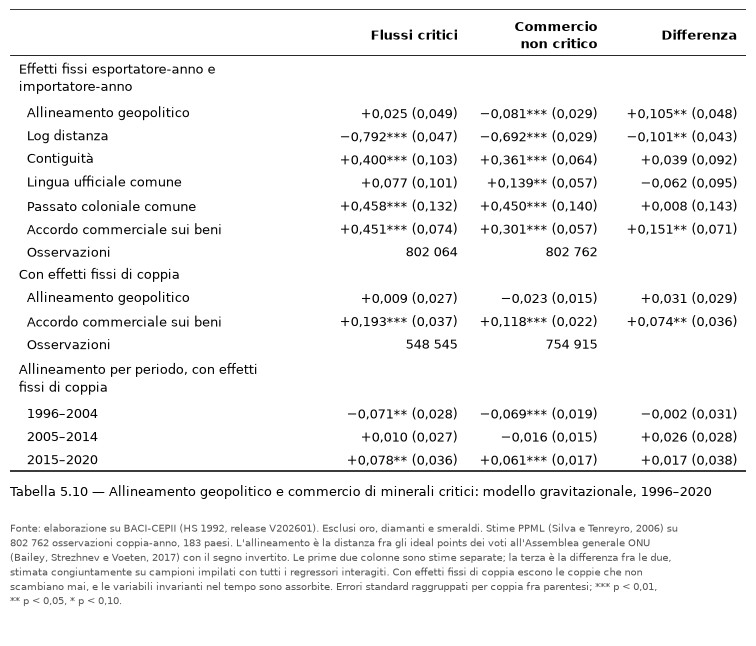

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_10_gravitazionale.png


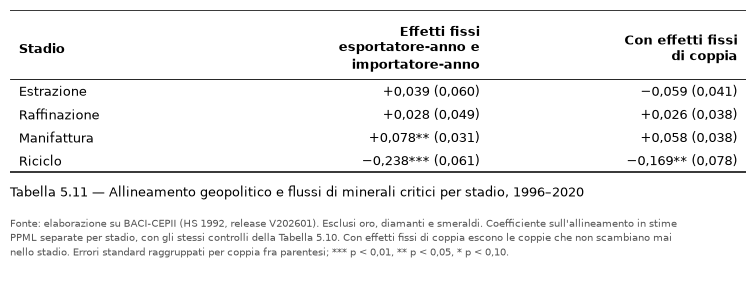

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_5_11_gravitazionale_stadi.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_5_11_gravitazionale_stadi.png')

In [82]:
# %% CELLA GR5 — tabelle del modello gravitazionale
# Legge i modelli e i risultati delle celle GR2 (MOD_GR), GR2b (RIS_P, RIS_S)
# e GR3 (POOL). Coefficienti PPML con errori standard raggruppati per coppia.
NUM_A, NUM_B = "5.10", "5.11"      # da adattare alla numerazione della tesi

NB = "\u00a0"                      # spazio unificatore
LEGENDA_STELLE = (f"Errori standard raggruppati per coppia fra parentesi; "
                  f"***{NB}p{NB}<{NB}0,01, **{NB}p{NB}<{NB}0,05, "
                  f"*{NB}p{NB}<{NB}0,10.")


def _stelle(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


def _cella(b, se, p):
    return f"{_sgn(b, 3)}{_stelle(p)} ({_n(se, 3)})"


def _da_mod(m, v):
    t = m.tidy()
    if v not in t.index:
        return "—"
    r = t.loc[v]
    return _cella(r["Estimate"], r["Std. Error"], r["Pr(>|t|)"])


def _da_pool(caso, v):
    r = POOL[(POOL.caso == caso) & (POOL.variabile == v)]
    return "—" if r.empty else _cella(*r[["differenza", "se", "p"]].iloc[0])


def _da_periodi(dep, v):
    r = RIS_P[(RIS_P.specificazione == "coppia") & (RIS_P.dipendente == dep)
              & (RIS_P.variabile == v)]
    return "—" if r.empty else _cella(*r[["coef", "se", "p"]].iloc[0])


# --- tabella A: modello principale -------------------------------------------
VARS = [("allineamento", "Allineamento geopolitico"),
        ("ldist", "Log distanza"),
        ("contig", "Contiguità"),
        ("comlang_off", "Lingua ufficiale comune"),
        ("comcol", "Passato coloniale comune"),
        ("rta", "Accordo commerciale sui beni")]
mb, mc = MOD_GR["base"], MOD_GR["coppia"]

righe = [("Effetti fissi esportatore-anno e importatore-anno", "", "", "")]
righe += [(f"  {lab}", _da_mod(mb["critici"], v), _da_mod(mb["non_critici"], v),
           _da_pool("base", v)) for v, lab in VARS]
righe += [("  Osservazioni", _mig(mb["critici"]._N), _mig(mb["non_critici"]._N), "")]

righe += [("Con effetti fissi di coppia", "", "", "")]
righe += [(f"  {lab}", _da_mod(mc["critici"], v), _da_mod(mc["non_critici"], v),
           _da_pool("coppia", v)) for v, lab in VARS if v in ("allineamento", "rta")]
righe += [("  Osservazioni", _mig(mc["critici"]._N), _mig(mc["non_critici"]._N), "")]

righe += [("Allineamento per periodo, con effetti fissi di coppia", "", "", "")]
righe += [(f"  {per}", _da_periodi("critici", v), _da_periodi("non_critici", v),
           _da_pool("periodi, coppia", v)) for per, v in zip(PERIODI, VAR_P)]

tabella(
    righe,
    ["", "Flussi critici", "Commercio\nnon critico", "Differenza"],
    [0.43, 0.19, 0.19, 0.19],
    didascalia=f"Tabella {NUM_A} — Allineamento geopolitico e commercio di "
               f"minerali critici: modello gravitazionale, 1996–2020",
    nota=FONTE + f" Stime PPML (Silva e Tenreyro, 2006) su {_mig(len(P))} "
         f"osservazioni coppia-anno, {P.iso3_o.nunique()} paesi. L'allineamento "
         "è la distanza fra gli ideal points dei voti all'Assemblea generale ONU "
         "(Bailey, Strezhnev e Voeten, 2017) con il segno invertito. Le prime "
         "due colonne sono stime separate; la terza è la differenza fra le due, "
         "stimata congiuntamente su campioni impilati con tutti i regressori "
         "interagiti. Con effetti fissi di coppia escono le coppie che non "
         "scambiano mai, e le variabili invarianti nel tempo sono assorbite. "
         + LEGENDA_STELLE,
    allinea=["l", "r", "r", "r"],
    out=FIG_DIR / f"tab_{NUM_A.replace('.', '_')}_gravitazionale.png")


# --- tabella B: allineamento per stadio --------------------------------------
def _da_stadio(st, spec):
    r = RIS_S[(RIS_S.dipendente == st) & (RIS_S.specificazione == spec)
              & (RIS_S.variabile == "allineamento")]
    return "—" if r.empty else _cella(*r[["coef", "se", "p"]].iloc[0])


tabella(
    [(LBL_ST[st], _da_stadio(st, "base"), _da_stadio(st, "coppia"))
     for st in STAGES],
    ["Stadio", "Effetti fissi\nesportatore-anno e\nimportatore-anno",
     "Con effetti fissi\ndi coppia"],
    [0.30, 0.35, 0.35],
    didascalia=f"Tabella {NUM_B} — Allineamento geopolitico e flussi di "
               f"minerali critici per stadio, 1996–2020",
    nota=FONTE + " Coefficiente sull'allineamento in stime PPML separate per "
         f"stadio, con gli stessi controlli della Tabella {NUM_A}. Con effetti "
         "fissi di coppia escono le coppie che non scambiano mai nello stadio. "
         + LEGENDA_STELLE,
    allinea=["l", "r", "r"],
    out=FIG_DIR / f"tab_{NUM_B.replace('.', '_')}_gravitazionale_stadi.png")

### GR5b. Variazione utilizzata dalla stima entro coppia

Con effetti fissi di coppia l'effetto dell'allineamento è identificato
dalla sola variazione nel tempo entro ciascuna coppia. Togliendo le
medie di coppia e di anno resta circa il 12% della varianza
dell'allineamento nel campione della stima sui flussi critici (14%
sull'intero panel): la deviazione standard entro coppia è 0,26, contro
0,73 complessiva (`gravity_varianza_entro.csv`). Gli accordi commerciali
variano di più nel tempo (23% della varianza entro coppia), e il loro
effetto resta stimato con precisione anche con effetti fissi di coppia.

La stima entro coppia è quindi severa ma poco potente: il risultato non
significativo per l'allineamento non esclude un effetto, ma ne limita
l'entità. Uno spostamento di una deviazione standard entro coppia
aumenterebbe i flussi critici dello 0,2% sull'intero periodo e del 2,0%
nel 2015–2020, la finestra in cui il coefficiente è significativo.

Nel confronto fra coppie gli effetti sono più ampi. Una deviazione
standard di allineamento in più si associa a flussi critici più alti
dell'1,8% e a un commercio non critico più basso del 5,7%: rispetto al
commercio non critico, i flussi critici risultano più alti dell'8,0%
(differenza +0,105, cella GR3).

In sintesi, l'allineamento geopolitico conta per il commercio di
minerali critici soprattutto come caratteristica stabile delle coppie di
paesi, e con un peso moderato; le sue variazioni nel tempo hanno effetti
piccoli e non distinguibili da quelli sul resto del commercio.

In [83]:
# %% CELLA GR5b — quanta variazione identifica lo stimatore entro coppia
# Con gli effetti fissi di coppia l'effetto e' identificato dalla sola
# variazione temporale entro ciascuna coppia. Se questa e' una piccola parte
# della variazione complessiva, la stima e' severa ma poco potente: un
# risultato nullo non esclude un effetto di entita' modesta.
# Due misure: (a) scarto dalla media di coppia; (b) scarto dalla media di
# coppia e di anno, piu' vicino a cio' che resta dopo gli effetti fissi
# esportatore-anno e importatore-anno. Entrambe sull'intero panel e sul
# campione effettivo della stima sui flussi critici (coppie che scambiano
# almeno una volta).
# In fondo, gli effetti espressi per una deviazione standard di allineamento:
# entro coppia (d.s. entro coppia e anno) e fra coppie (d.s. complessiva).

def _entro(d, col):
    x = d[col].astype(float)
    m_c = d.groupby("coppia")[col].transform("mean")
    m_y = d.groupby("year")[col].transform("mean")
    e1 = x - m_c
    e2 = x - m_c - m_y + x.mean()
    return dict(var_tot=x.var(), quota_entro=e1.var() / x.var(),
                quota_entro_anno=e2.var() / x.var(),
                sd_tot=x.std(), sd_entro_anno=e2.std())


attive = P.groupby("coppia").critici.transform("max") > 0
CAMPIONI = {"panel completo": P, "coppie con flussi critici": P[attive]}

righe = []
for nome, d in CAMPIONI.items():
    for c in ("allineamento", "rta"):
        righe.append(dict(campione=nome, variabile=c, n=len(d), **_entro(d, c)))
VAR_ENTRO = pd.DataFrame(righe)
VAR_ENTRO.to_csv(OUT_DIR / "gravity_varianza_entro.csv", index=False)

print(VAR_ENTRO.round(4).to_string(index=False))


def _sd(campione, misura):
    return VAR_ENTRO.query(f"campione == '{campione}' and "
                           f"variabile == 'allineamento'")[misura].iloc[0]


# --- entro coppia: d.s. entro coppia e anno, campione della stima sui critici
sd_in = _sd("coppie con flussi critici", "sd_entro_anno")
b = MOD_GR["coppia"]["critici"].coef()["allineamento"]
b15 = RIS_P.query("specificazione == 'coppia' and dipendente == 'critici' "
                  "and variabile == 'all_2015'").coef.iloc[0]
print(f"\nENTRO COPPIA (d.s. entro coppia e anno: {sd_in:.3f})")
print(f"  +1 d.s. sui flussi critici: intero periodo {np.expm1(b * sd_in):+.1%}, "
      f"2015–2020 {np.expm1(b15 * sd_in):+.1%}")

# --- fra coppie: d.s. complessiva, intero panel, specificazione principale
sd_tot = _sd("panel completo", "sd_tot")
b_c = MOD_GR["base"]["critici"].coef()["allineamento"]
b_n = MOD_GR["base"]["non_critici"].coef()["allineamento"]
d_cn = POOL.query("caso == 'base' and variabile == 'allineamento'").differenza.iloc[0]
print(f"\nFRA COPPIE (d.s. complessiva: {sd_tot:.3f})")
print(f"  +1 d.s. sui flussi critici:         {np.expm1(b_c * sd_tot):+.1%}")
print(f"  +1 d.s. sul commercio non critico:  {np.expm1(b_n * sd_tot):+.1%}")
print(f"  critici rispetto ai non critici:    {np.expm1(d_cn * sd_tot):+.1%}")

                 campione    variabile      n  var_tot  quota_entro  quota_entro_anno  sd_tot  sd_entro_anno
           panel completo allineamento 802762   0.5307       0.1480            0.1435  0.7285         0.2760
           panel completo          rta 802762   0.0966       0.2502            0.2319  0.3108         0.1497
coppie con flussi critici allineamento 548676   0.5597       0.1206            0.1162  0.7481         0.2551
coppie con flussi critici          rta 548676   0.1279       0.2546            0.2296  0.3576         0.1713

ENTRO COPPIA (d.s. entro coppia e anno: 0.255)
  +1 d.s. sui flussi critici: intero periodo +0.2%, 2015–2020 +2.0%

FRA COPPIE (d.s. complessiva: 0.728)
  +1 d.s. sui flussi critici:         +1.8%
  +1 d.s. sul commercio non critico:  -5.7%
  critici rispetto ai non critici:    +8.0%


### GR6. Robustezza: stima su intervalli di anni

Con anni consecutivi la stima entro coppia si basa su variazioni anno su
anno, che nei flussi commerciali sono in parte rumore e in parte
aggiustamenti incompleti; l'allineamento, inoltre, varia poco da un anno
all'altro (cella GR5b). Seguendo Yotov et al. (2016), la stima congiunta
è ripetuta su anni a intervalli di 3, 4 e 5 anni e, per l'intervallo di
4 anni, con quattro anni di partenza diversi (`gravity_intervalli.csv`).

| intervallo | anni | base | effetti fissi di coppia |
|---|---|---|---|
| 1 anno | 1996–2020 (25) | +0,105 (0,048)** | +0,031 (0,029) |
| 3 anni | 1996–2020 (9) | +0,107 (0,048)** | +0,018 (0,033) |
| 4 anni | 1996–2020 (7) | +0,113 (0,047)** | +0,018 (0,034) |
| 5 anni | 1996–2016 (5) | +0,110 (0,044)** | +0,010 (0,043) |

Differenza critici − non critici nel coefficiente sull'allineamento,
stima congiunta; errori standard raggruppati per coppia fra parentesi;
** p < 0,05.

Nella specificazione principale la differenza è stabile (da +0,105 a
+0,113) e sempre significativa. Con effetti fissi di coppia resta
piccola e non significativa con ogni intervallo; con intervallo di 4
anni varia fra +0,018 e +0,065 secondo l'anno di partenza, sempre con
p ≥ 0,19. Lasciare ai flussi più tempo per adattarsi non fa emergere un
effetto differenziale entro coppia.

Il coefficiente sugli accordi commerciali, che in letteratura cresce
passando agli intervalli (Yotov et al., 2016; Piermartini e Yotov,
2016), qui resta pressoché invariato (fra 0,107 e 0,145 con effetti
fissi di coppia, contro 0,118 con anni consecutivi): in questi dati la
stima su intervalli non modifica la dinamica di aggiustamento, e le
conclusioni non dipendono da questa scelta.

In [84]:
# %% CELLA GR6 — effetti fissi di coppia su intervalli (Yotov et al. 2016)
# Con anni consecutivi l'effetto entro coppia e' identificato da variazioni
# anno su anno, che nei flussi commerciali sono in parte rumore e in parte
# aggiustamenti non ancora completati; la cella GR5b mostra inoltre che
# l'allineamento varia poco da un anno all'altro. Yotov et al. (2016, cap. 1)
# raccomandano di stimare su anni a intervalli (3-5 anni): la variazione
# entro coppia fra due osservazioni successive e' piu' ampia e il
# coefficiente cattura un adeguamento piu' completo.
# Su ogni campione si stima anche la specificazione senza effetti di coppia,
# per separare l'effetto del sottocampionamento da quello degli effetti
# fissi. Il coefficiente sugli accordi fa da controllo: in letteratura cresce
# passando agli intervalli (Yotov et al. 2016; Piermartini e Yotov 2016).
# Stima congiunta come nella cella GR3 (confronto_pooled): i coefficienti non
# interagiti si riferiscono al commercio non critico, quelli con suffisso
# _cm alla differenza critici - non critici.
import warnings

FE_GR6 = {"oy+dy": "oy + dy", "coppia": "oy + dy + coppia"}


def _riga(m, step, offset, spec, anni):
    t = m.tidy()
    r = dict(intervallo=step, offset=offset, spec=spec,
             anni=f"{anni[0]}-{anni[-1]} ({len(anni)})",
             N=getattr(m, "_N", np.nan))
    for v, lab in [("allineamento_cm", "diff_all"), ("allineamento", "all_nc"),
                   ("rta_cm", "diff_rta"), ("rta", "rta_nc")]:
        if v in t.index:
            r[f"{lab}_coef"] = t.loc[v, "Estimate"]
            r[f"{lab}_se"] = t.loc[v, "Std. Error"]
            r[f"{lab}_p"] = t.loc[v, "Pr(>|t|)"]
    return r


def stima_intervalli(P, steps=(3, 4, 5), offsets_step4=(1, 2, 3)):
    anni_tot = np.sort(P.year.unique())
    righe = []

    def gira(step, offset, specs):
        anni = anni_tot[offset::step]
        Q = P[P.year.isin(anni)]
        print(f"\n########## intervallo {step} anni, offset {offset}: {list(anni)}")
        for spec in specs:
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore", message=".*separation.*")
                m = confronto_pooled(Q, fe=FE_GR6[spec], verbose=False)
            righe.append(_riga(m, step, offset, spec, anni))
            r = righe[-1]
            print(f"  {spec:7s} differenza allineamento {r['diff_all_coef']:+.4f} "
                  f"(e.s. {r['diff_all_se']:.4f}) | accordi, non critici "
                  f"{r['rta_nc_coef']:+.4f}")
            del m
            _ = gc.collect()
        del Q
        _ = gc.collect()

    # specificazione principale: offset 0, entrambe le specificazioni
    for s in steps:
        gira(s, 0, ("oy+dy", "coppia"))
    # robustezza: con passo 4 il risultato non deve dipendere dall'anno di partenza
    for o in offsets_step4:
        gira(4, o, ("coppia",))
    return pd.DataFrame(righe)


R = stima_intervalli(P)

# riferimento: anni consecutivi, dalle celle GR2 (MOD_GR) e GR3 (POOL)
anni_c = np.sort(P.year.unique())
rif = []
for spec, caso in [("oy+dy", "base"), ("coppia", "coppia")]:
    mn = MOD_GR[caso]["non_critici"].tidy()
    pa = POOL.query(f"caso == '{caso}' and variabile == 'allineamento'").iloc[0]
    pr = POOL.query(f"caso == '{caso}' and variabile == 'rta'").iloc[0]
    rif.append(dict(intervallo=1, offset=0, spec=spec,
                    anni=f"{anni_c[0]}-{anni_c[-1]} ({len(anni_c)})", N=np.nan,
                    diff_all_coef=pa.differenza, diff_all_se=pa.se, diff_all_p=pa.p,
                    all_nc_coef=mn.loc["allineamento", "Estimate"],
                    diff_rta_coef=pr.differenza, diff_rta_se=pr.se, diff_rta_p=pr.p,
                    rta_nc_coef=mn.loc["rta", "Estimate"]))
R = pd.concat([pd.DataFrame(rif), R], ignore_index=True)
R.to_csv(OUT_DIR / "gravity_intervalli.csv", index=False)

cols = ["intervallo", "offset", "spec", "anni", "diff_all_coef", "diff_all_se",
        "diff_all_p", "all_nc_coef", "rta_nc_coef", "diff_rta_coef"]
print("\n=== DIFFERENZA CRITICI − NON CRITICI: ANNI CONSECUTIVI E INTERVALLI ===")
print(R[cols].round(4).to_string(index=False))


########## intervallo 3 anni, offset 0: [np.int64(1996), np.int64(1999), np.int64(2002), np.int64(2005), np.int64(2008), np.int64(2011), np.int64(2014), np.int64(2017), np.int64(2020)]
  oy+dy   differenza allineamento +0.1065 (e.s. 0.0482) | accordi, non critici +0.3007
  coppia  differenza allineamento +0.0175 (e.s. 0.0325) | accordi, non critici +0.1120

########## intervallo 4 anni, offset 0: [np.int64(1996), np.int64(2000), np.int64(2004), np.int64(2008), np.int64(2012), np.int64(2016), np.int64(2020)]
  oy+dy   differenza allineamento +0.1131 (e.s. 0.0467) | accordi, non critici +0.3126
  coppia  differenza allineamento +0.0176 (e.s. 0.0344) | accordi, non critici +0.1071

########## intervallo 5 anni, offset 0: [np.int64(1996), np.int64(2001), np.int64(2006), np.int64(2011), np.int64(2016)]
  oy+dy   differenza allineamento +0.1099 (e.s. 0.0440) | accordi, non critici +0.3402
  coppia  differenza allineamento +0.0097 (e.s. 0.0427) | accordi, non critici +0.1393

########## inte

### CAPITOLO 3

families_meta.csv   : ['family_id', 'n_HS92', 'n_HS96', 'n_HS02', 'n_HS07', 'n_HS12', 'n_HS17', 'n_HS22', 'n_headings', 'has_potata', 'has_bloccata', 'first_year_full_detail', 'collapse_ratio', 'is_stable_11', 'giant_flag', 'resource', 'stage', 'stage_name', 'unctad_layer', 'v_assigned_stage', 'v_family', 'v_critical', 'n_resources', 'n_stages', 'v_res_full', 'v_stg_full', 'critical_share', 'resource_purity', 'stage_purity', 'contaminated_flag', 'conflict_flag', 'stage_mixed_flag', 'assigned_at_zero', 'v_keep', 'drift_2022', 'drift_2023', 'drift_2024', 'value_drift', 'drift_anni_in_banda']
families_escluse.csv: ['family_id', 'n_HS92', 'n_HS96', 'n_HS02', 'n_HS07', 'n_HS12', 'n_HS17', 'n_HS22', 'n_headings', 'has_potata', 'has_bloccata', 'first_year_full_detail', 'collapse_ratio', 'is_stable_11', 'giant_flag', 'resource', 'stage', 'stage_name', 'unctad_layer', 'v_assigned_stage', 'v_family', 'v_critical', 'n_resources', 'n_stages', 'v_res_full', 'v_stg_full', 'critical_share', 'resource

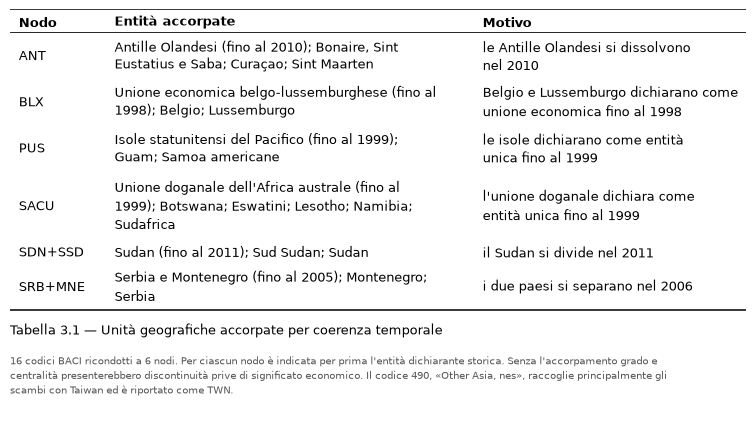

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_3_1_accorpamenti.png


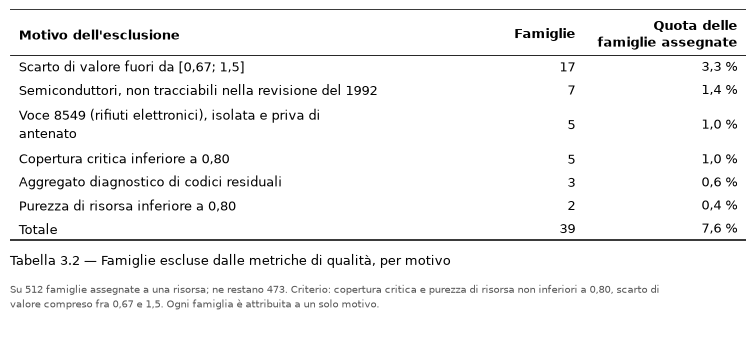

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_3_2_esclusioni.png
motivo_t
Scarto di valore fuori da [0,67; 1,5]                           17
Semiconduttori, non tracciabili nella revisione del 1992         7
Voce 8549 (rifiuti elettronici), isolata e priva di antenato     5
Copertura critica inferiore a 0,80                               5
Aggregato diagnostico di codici residuali                        3
Purezza di risorsa inferiore a 0,80                              2


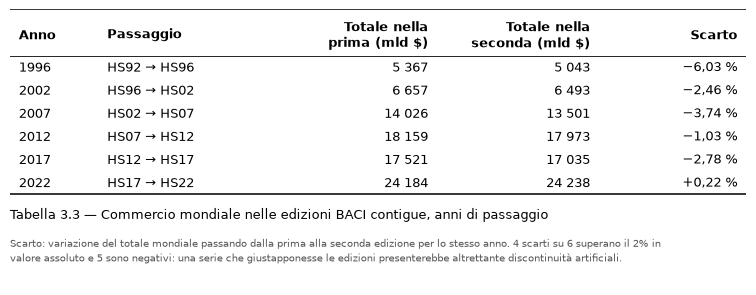

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_3_3_giunzioni.png


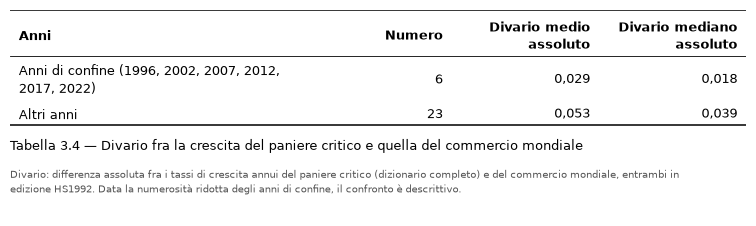

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_3_4_confini.png
divario medio: confini 0.029, altri anni 0.053


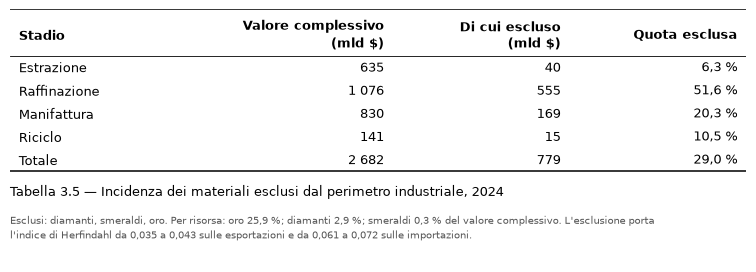

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_3_5_perimetro.png
61 risorse, tavola completa in qualita_per_risorsa.csv


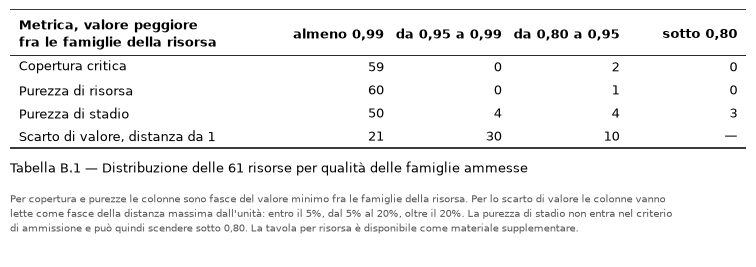

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_B_1_qualita_distribuzione.png


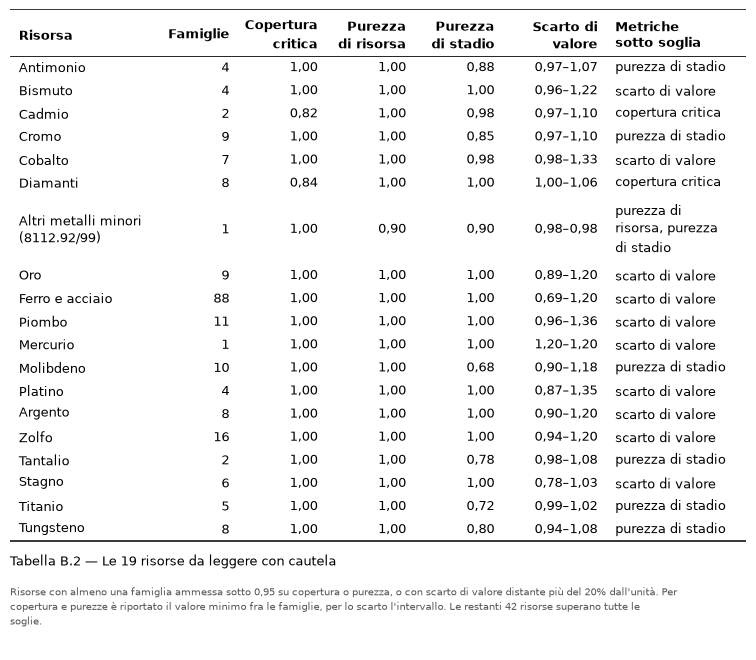

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_B_2_qualita_cautela.png
famiglie ammesse       : 473
famiglie escluse       : 39 su 512
risorse nel dizionario : 61 | nel perimetro industriale: 58
paesi                  : 217
coppie di paesi distinte, 1995-2024: 28,683
relazioni attive distinte (esportatore, importatore, risorsa, stadio): 113,876
quota esclusa dal perimetro nel 2024: 29.0%
risorse con tutte le metriche sopra le soglie di attenzione: 42 su 61


In [85]:
# %% [markdown]
# # Capitolo 3 — tabelle e numeri
#
# Prerequisiti (kernel riavviato): celle 0-4, 9, 11, T1, F1 del notebook
# principale. Servono D, DI, FL, ISO, MERGE_CODES, NON_IND, FOLDERS, BASE,
# OUT_DIR, FIG_DIR, STAGES, hhi, tabella, _nome, LBL_ST e le soglie della
# cella 2 (MIN_CRITICAL_SHARE, MIN_RESOURCE_PURITY, DRIFT_RANGE).
#
#   Tab. 3.1  unità geografiche accorpate                    §3.2.3
#   Tab. 3.2  famiglie escluse per motivo                    §3.4
#   Tab. 3.3  scarti fra edizioni BACI contigue              §3.5.1
#   Tab. 3.4  divario di crescita ai confini di revisione    §3.5.2
#   Tab. 3.5  incidenza del perimetro industriale            §3.6.1
#   Tab. B.1  distribuzione delle metriche di qualità        Appendice B
#   Tab. B.2  risorse da leggere con cautela                 Appendice B
#   N3        numeri per il testo della §3.6


# %% CELLA T3.0 — metadati delle famiglie e utilità
from pathlib import Path

FM = pd.read_csv(OUT_DIR / "families_meta.csv")
FE = pd.read_csv(OUT_DIR / "families_escluse.csv")
print("families_meta.csv   :", list(FM.columns))
print("families_escluse.csv:", list(FE.columns))
print(f"righe: {len(FM)} nei metadati, {len(FE)} escluse")


# stesso formato del capitolo 7: migliaia separate da spazio non separabile
def _n(x, dec=3):
    if x is None or not np.isfinite(x):
        return "—"
    return f"{x:,.{dec}f}".replace(",", "\u00a0").replace(".", ",")


def _mig(x, dec=0):
    return f"{x:,.{dec}f}".replace(",", "\u00a0")


def _pp(x, dec=1):
    return _n(x, dec) + " %"


def _sgn(x, dec=2):
    if x is None or not np.isfinite(x):
        return "—"
    return f"{x:+.{dec}f}".replace(".", ",").replace("-", "−")


def _col(df, *nomi):
    return next((c for c in nomi if c in df.columns), None)


COL_FAM = _col(FM, "family_id", "famiglia", "family")
COL_RIS = _col(FM, "resource", "risorsa")
ESCLUSE = set(FE[COL_FAM]) if COL_FAM and COL_FAM in FE.columns else set()
AMMESSE = FM[~FM[COL_FAM].isin(ESCLUSE)] if COL_FAM else FM


# %% CELLA T3.1 — unità geografiche accorpate
# Nomi italiani scritti per esteso: il file country_codes di BACI è in inglese,
# e letto con la codifica sbagliata altera i caratteri accentati.
NOMI_GEO = {
    58: "Unione economica belgo-lussemburghese (fino al 1998)",
    56: "Belgio", 442: "Lussemburgo",
    711: "Unione doganale dell'Africa australe (fino al 1999)",
    710: "Sudafrica", 72: "Botswana", 426: "Lesotho", 516: "Namibia", 748: "Eswatini",
    849: "Isole statunitensi del Pacifico (fino al 1999)",
    16: "Samoa americane", 316: "Guam",
    891: "Serbia e Montenegro (fino al 2005)", 688: "Serbia", 499: "Montenegro",
    530: "Antille Olandesi (fino al 2010)",
    531: "Curaçao", 534: "Sint Maarten", 535: "Bonaire, Sint Eustatius e Saba",
    736: "Sudan (fino al 2011)", 729: "Sudan", 728: "Sud Sudan",
}
MOTIVO_GEO = {
    58: "Belgio e Lussemburgo dichiarano come unione economica fino al 1998",
    711: "l'unione doganale dichiara come entità unica fino al 1999",
    849: "le isole dichiarano come entità unica fino al 1999",
    891: "i due paesi si separano nel 2006",
    530: "le Antille Olandesi si dissolvono nel 2010",
    736: "il Sudan si divide nel 2011",
}

_gr = {}
for src, dst in MERGE_CODES.items():
    _gr.setdefault(dst, set()).add(src)

tabella(
    [(ISO.get(dst, str(dst)),
      "; ".join([NOMI_GEO.get(dst, str(dst))]
                + sorted(NOMI_GEO.get(c, str(c)) for c in src)),
      MOTIVO_GEO.get(dst, ""))
     for dst, src in sorted(_gr.items(), key=lambda kv: ISO.get(kv[0], ""))],
    ["Nodo", "Entità accorpate", "Motivo"],
    [0.13, 0.50, 0.37],
    didascalia="Tabella 3.1 — Unità geografiche accorpate per coerenza temporale",
    nota=f"{len(MERGE_CODES)} codici BACI ricondotti a {len(_gr)} nodi. Per ciascun "
         f"nodo è indicata per prima l'entità dichiarante storica. Senza l'accorpamento "
         f"grado e centralità presenterebbero discontinuità prive di significato "
         f"economico. Il codice 490, «Other Asia, nes», raccoglie principalmente gli "
         f"scambi con Taiwan ed è riportato come TWN.",
    allinea=["l", "l", "l"],
    out=FIG_DIR / "tab_3_1_accorpamenti.png")


# %% CELLA T3.2 — famiglie escluse per motivo
# Il motivo è quello assegnato dalla cella 6 (colonna "motivo" di
# families_escluse.csv), con etichette riscritte per la tabella. Se la
# colonna mancasse, lo si ricostruisce dalle metriche con le soglie della
# cella 2. I conteggi sono su famiglie distinte, una per motivo.
MIN_CS = globals().get("MIN_CRITICAL_SHARE", 0.80)
MIN_RP = globals().get("MIN_RESOURCE_PURITY", 0.80)
DR_LO, DR_HI = globals().get("DRIFT_RANGE", (0.67, 1.5))
_soglia_drift = f"[{_n(DR_LO, 2)}; {_n(DR_HI, 1)}]"

ETI_MOTIVO = {
    "scarto di valore HS92/HS22": f"Scarto di valore fuori da {_soglia_drift}",
    "non tracciabile all'indietro": "Semiconduttori, non tracciabili nella revisione "
                                    "del 1992",
    "heading bloccata (8548/8549)": "Voce 8549 (rifiuti elettronici), isolata e priva "
                                    "di antenato",
    "contaminata da merci non critiche": f"Copertura critica inferiore a {_n(MIN_CS, 2)}",
    "bucket diagnostico": "Aggregato diagnostico di codici residuali",
    "ambigua fra minerali": f"Purezza di risorsa inferiore a {_n(MIN_RP, 2)}",
    "antenato tagliato da MAX_DEGREE": "Antenato escluso dal limite di grado",
    "voce senza antenato HS92": "Nessun codice nella revisione del 1992",
    "famiglia troppo larga": "Famiglia troppo ampia",
}


def motivo(r):
    vd = r.get("value_drift", np.nan)
    if pd.isna(vd):
        return "voce senza antenato HS92"
    if r.get("critical_share", 1) < MIN_CS:
        return "contaminata da merci non critiche"
    if r.get("resource_purity", 1) < MIN_RP:
        return "ambigua fra minerali"
    if not (DR_LO <= vd <= DR_HI):
        return "scarto di valore HS92/HS22"
    return "famiglia troppo larga"


COL_MOT = _col(FE, "motivo", "reason", "exclusion_reason")
FE["motivo_t"] = FE[COL_MOT] if COL_MOT else FE.apply(motivo, axis=1)
FE["motivo_t"] = FE.motivo_t.map(lambda m: ETI_MOTIVO.get(m, m))
FE_U = FE.drop_duplicates(COL_FAM) if COL_FAM and COL_FAM in FE.columns else FE
N_ESC = len(FE_U)
if N_ESC != len(FE):
    print(f"ATTENZIONE: {len(FE)} righe ma {N_ESC} famiglie distinte fra le escluse")
N_TOT = FM[COL_FAM].nunique() if COL_FAM else len(FM)
N_TOT += len(ESCLUSE - set(FM[COL_FAM])) if COL_FAM else 0
ME = FE_U.motivo_t.value_counts()

tabella(
    [(m, f"{n}", _pp(n / N_TOT * 100)) for m, n in ME.items()]
    + [("Totale", f"{N_ESC}", _pp(N_ESC / N_TOT * 100))],
    ["Motivo dell'esclusione", "Famiglie", "Quota delle\nfamiglie assegnate"],
    [0.60, 0.18, 0.22],
    didascalia="Tabella 3.2 — Famiglie escluse dalle metriche di qualità, per motivo",
    nota=f"Su {N_TOT} famiglie assegnate a una risorsa; ne restano {N_TOT - N_ESC}. "
         f"Criterio: copertura critica e purezza di risorsa non inferiori a "
         f"{_n(MIN_CS, 2)}, scarto di valore compreso fra {_n(DR_LO, 2)} e "
         f"{_n(DR_HI, 1)}. Ogni famiglia è attribuita a un solo motivo.",
    allinea=["l", "r", "r"],
    out=FIG_DIR / "tab_3_2_esclusioni.png")
print(ME.to_string())


# %% CELLA T3.3 — scarti fra edizioni BACI contigue
# Per ogni anno di passaggio si confronta il commercio mondiale totale nelle due
# edizioni che lo coprono. La prima esecuzione legge dodici file annuali; il
# risultato è poi salvato.
GIUNZIONI = [(1996, "HS92", "HS96"), (2002, "HS96", "HS02"), (2007, "HS02", "HS07"),
             (2012, "HS07", "HS12"), (2017, "HS12", "HS17"), (2022, "HS17", "HS22")]


def totale_mondo(rev, anno):
    cart = FOLDERS.get(rev) if isinstance(FOLDERS, dict) else None
    cart = cart or next((BASE / "BACI").glob(f"BACI_{rev}_V*"))
    p = next(Path(cart).glob(f"BACI_{rev}_Y{anno}_*.csv"))
    return pd.read_csv(p, usecols=["v"]).v.sum()


_cache_g = OUT_DIR / "scarti_giunzioni_edizioni.csv"
if _cache_g.exists():
    GIU = pd.read_csv(_cache_g)
else:
    _g = []
    for y, a, b in GIUNZIONI:
        ta, tb = totale_mondo(a, y), totale_mondo(b, y)
        _g.append(dict(anno=y, da=a, a=b, totale_da=ta / 1e6, totale_a=tb / 1e6,
                       scarto=(tb / ta - 1) * 100))
    GIU = pd.DataFrame(_g)
    GIU.to_csv(_cache_g, index=False)

tabella(
    [(f"{int(r.anno)}", f"{r.da} → {r.a}", _mig(r.totale_da), _mig(r.totale_a),
      _sgn(r.scarto) + " %") for r in GIU.itertuples()],
    ["Anno", "Passaggio", "Totale nella\nprima (mld $)", "Totale nella\nseconda (mld $)",
     "Scarto"],
    [0.12, 0.24, 0.22, 0.22, 0.20],
    didascalia="Tabella 3.3 — Commercio mondiale nelle edizioni BACI contigue, anni di "
               "passaggio",
    nota=f"Scarto: variazione del totale mondiale passando dalla prima alla seconda "
         f"edizione per lo stesso anno. {(GIU.scarto.abs() > 2).sum()} scarti su "
         f"{len(GIU)} superano il 2% in valore assoluto e {(GIU.scarto < 0).sum()} sono "
         f"negativi: una serie che giustapponesse le edizioni presenterebbe altrettante "
         f"discontinuità artificiali.",
    allinea=["l", "l", "r", "r", "r"],
    out=FIG_DIR / "tab_3_3_giunzioni.png")


# %% CELLA T3.4 — divario di crescita ai confini di revisione
# Se l'uso della sola edizione HS1992 fosse viziato, il paniere critico
# dovrebbe discostarsi dal commercio mondiale soprattutto negli anni in cui i
# paesi cambiano nomenclatura dichiarativa. Trenta file alla prima esecuzione,
# poi il file salvato.
_cache_t = OUT_DIR / "totale_mondo_hs92.csv"
if _cache_t.exists():
    TM = pd.read_csv(_cache_t).set_index("year").totale
else:
    TM = pd.Series({y: totale_mondo("HS92", y) for y in range(1995, 2025)}, name="totale")
    TM.rename_axis("year").to_csv(_cache_t)

CRIT = D.groupby("year").value.sum()
DIV = (CRIT.pct_change() - TM.pct_change()).abs().dropna()
CONFINI = [1996, 2002, 2007, 2012, 2017, 2022]
d_conf, d_alt = DIV[DIV.index.isin(CONFINI)], DIV[~DIV.index.isin(CONFINI)]

tabella(
    [("Anni di confine (" + ", ".join(map(str, CONFINI)) + ")", f"{len(d_conf)}",
      _n(d_conf.mean()), _n(d_conf.median())),
     ("Altri anni", f"{len(d_alt)}", _n(d_alt.mean()), _n(d_alt.median()))],
    ["Anni", "Numero", "Divario medio\nassoluto", "Divario mediano\nassoluto"],
    [0.46, 0.14, 0.20, 0.20],
    didascalia="Tabella 3.4 — Divario fra la crescita del paniere critico e quella del "
               "commercio mondiale",
    nota="Divario: differenza assoluta fra i tassi di crescita annui del paniere critico "
         "(dizionario completo) e del commercio mondiale, entrambi in edizione HS1992. "
         "Data la numerosità ridotta degli anni di confine, il confronto è descrittivo.",
    allinea=["l", "r", "r", "r"],
    out=FIG_DIR / "tab_3_4_confini.png")
print(f"divario medio: confini {d_conf.mean():.3f}, altri anni {d_alt.mean():.3f}")


# %% CELLA T3.5 — incidenza del perimetro industriale
A = 2024
_d, _di = D[D.year == A], DI[DI.year == A]
_esc = _d[_d.resource.isin(NON_IND)]
_st_tot = _d.groupby("stage_name", observed=True).value.sum()
_st_esc = (_esc.groupby("stage_name", observed=True).value.sum()
           .reindex(_st_tot.index, fill_value=0))
_ris_esc = _esc.groupby("resource", observed=True).value.sum() / _d.value.sum() * 100
_ris_esc = _ris_esc[_ris_esc > 0].sort_values(ascending=False)
HHI_P = {("exp", "tutte"): hhi(_d.groupby("exp").value.sum().values),
         ("exp", "perimetro"): hhi(_di.groupby("exp").value.sum().values),
         ("imp", "tutte"): hhi(_d.groupby("imp").value.sum().values),
         ("imp", "perimetro"): hhi(_di.groupby("imp").value.sum().values)}

tabella(
    [(LBL_ST[st], _mig(_st_tot[st] / 1e6), _mig(_st_esc[st] / 1e6),
      _pp(_st_esc[st] / _st_tot[st] * 100)) for st in STAGES]
    + [("Totale", _mig(_d.value.sum() / 1e6), _mig(_esc.value.sum() / 1e6),
        _pp(_esc.value.sum() / _d.value.sum() * 100))],
    ["Stadio", "Valore complessivo\n(mld $)", "Di cui escluso\n(mld $)", "Quota esclusa"],
    [0.28, 0.24, 0.24, 0.24],
    didascalia=f"Tabella 3.5 — Incidenza dei materiali esclusi dal perimetro industriale, "
               f"{A}",
    nota=f"Esclusi: {', '.join(_nome(r).lower() for r in sorted(NON_IND))}. Per risorsa: "
         + "; ".join(f"{_nome(r).lower()} {_pp(v)}" for r, v in _ris_esc.items())
         + f" del valore complessivo. L'esclusione porta l'indice di Herfindahl da "
           f"{_n(HHI_P['exp', 'tutte'])} a {_n(HHI_P['exp', 'perimetro'])} sulle "
           f"esportazioni e da {_n(HHI_P['imp', 'tutte'])} a "
           f"{_n(HHI_P['imp', 'perimetro'])} sulle importazioni.",
    allinea=["l", "r", "r", "r"],
    out=FIG_DIR / "tab_3_5_perimetro.png")


# %% CELLA TB.0 — qualità per risorsa (tavola completa, solo su file)
# Per ciascuna risorsa il valore peggiore fra le sue famiglie ammesse: il
# minimo per copertura e purezze, lo scostamento massimo dall'unità per lo
# scarto di valore. La tavola completa va come materiale supplementare; nel
# testo vanno il riepilogo (B.1) e le sole risorse da leggere con cautela (B.2).
METRICHE = [c for c in ["critical_share", "resource_purity", "stage_purity"]
            if c in AMMESSE.columns]
ETI_MET = {"critical_share": "Copertura critica", "resource_purity": "Purezza di risorsa",
           "stage_purity": "Purezza di stadio"}

QR = AMMESSE.groupby(COL_RIS).agg(famiglie=(COL_FAM, "nunique"),
                                  **{c: (c, "min") for c in METRICHE})
HA_DRIFT = "value_drift" in AMMESSE.columns
if HA_DRIFT:
    _vd = AMMESSE.groupby(COL_RIS).value_drift
    QR["drift_min"], QR["drift_max"] = _vd.min(), _vd.max()
    QR["drift_dist"] = np.maximum((1 - QR.drift_min).abs(), (QR.drift_max - 1).abs())
QR = QR.sort_index()
QR.to_csv(OUT_DIR / "qualita_per_risorsa.csv")
print(f"{len(QR)} risorse, tavola completa in qualita_per_risorsa.csv")


# %% CELLA TB.1 — Appendice B: distribuzione delle metriche di qualità
FASCE = [(0.99, 1.01, "almeno 0,99"), (0.95, 0.99, "da 0,95 a 0,99"),
         (0.80, 0.95, "da 0,80 a 0,95"), (0.0, 0.80, "sotto 0,80")]
FASCE_D = [(0, 0.05), (0.05, 0.20), (0.20, np.inf)]

_righe = []
for c in METRICHE:
    v = QR[c]
    _righe.append((ETI_MET[c],) + tuple(str(int(((v >= lo) & (v < hi)).sum()))
                                        for lo, hi, _ in FASCE))
if HA_DRIFT:
    v = QR.drift_dist
    _righe.append(("Scarto di valore, distanza da 1",)
                  + tuple(str(int(((v >= lo) & (v < hi)).sum())) for lo, hi in FASCE_D)
                  + ("—",))

tabella(
    _righe,
    ["Metrica, valore peggiore\nfra le famiglie della risorsa"] + [f[2] for f in FASCE],
    [0.36, 0.16, 0.16, 0.16, 0.16],
    didascalia=f"Tabella B.1 — Distribuzione delle {len(QR)} risorse per qualità delle "
               f"famiglie ammesse",
    nota="Per copertura e purezze le colonne sono fasce del valore minimo fra le famiglie "
         "della risorsa. Per lo scarto di valore le colonne vanno lette come fasce della "
         "distanza massima dall'unità: entro il 5%, dal 5% al 20%, oltre il 20%. La "
         "purezza di stadio non entra nel criterio di ammissione e può quindi scendere "
         "sotto 0,80. La tavola per risorsa è disponibile come materiale supplementare.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_B_1_qualita_distribuzione.png")


# %% CELLA TB.2 — Appendice B: risorse da leggere con cautela
# Le risorse con almeno una famiglia sotto la soglia di attenzione su una delle
# metriche, o con scarto di valore oltre il 20%: quelle per cui una variazione
# osservata può in parte riflettere la composizione della famiglia. Se la
# tabella risulta troppo lunga si alzano le soglie, se è vuota si abbassano.
SOGLIA_ATT, SOGLIA_DRIFT = 0.95, 0.20
_mask = np.zeros(len(QR), bool)
for c in METRICHE:
    _mask |= QR[c].to_numpy() < SOGLIA_ATT
if HA_DRIFT:
    _mask |= QR.drift_dist.to_numpy() > SOGLIA_DRIFT
CAUT = QR[_mask]


def _debole(q):
    out = [ETI_MET[c].lower() for c in METRICHE if q[c] < SOGLIA_ATT]
    if HA_DRIFT and q.drift_dist > SOGLIA_DRIFT:
        out.append("scarto di valore")
    return ", ".join(out)


_intest = ["Risorsa", "Famiglie"] + [ETI_MET[c].replace(" ", "\n", 1) for c in METRICHE]
_largh = [0.22, 0.09] + [0.12] * len(METRICHE)
if HA_DRIFT:
    _intest.append("Scarto di\nvalore")
    _largh.append(0.14)
_intest.append("Metriche\nsotto soglia")
_largh.append(1 - sum(_largh))

tabella(
    [(_nome(r), f"{int(q.famiglie)}") + tuple(_n(q[c], 2) for c in METRICHE)
     + ((f"{_n(q.drift_min, 2)}–{_n(q.drift_max, 2)}",) if HA_DRIFT else ())
     + (_debole(q),) for r, q in CAUT.iterrows()],
    _intest,
    _largh,
    didascalia=f"Tabella B.2 — Le {len(CAUT)} risorse da leggere con cautela",
    nota=f"Risorse con almeno una famiglia ammessa sotto {_n(SOGLIA_ATT, 2)} su copertura "
         f"o purezza, o con scarto di valore distante più del {int(SOGLIA_DRIFT * 100)}% "
         f"dall'unità. Per copertura e purezze è riportato il valore minimo fra le "
         f"famiglie, per lo scarto l'intervallo. Le restanti {len(QR) - len(CAUT)} "
         f"risorse superano tutte le soglie.",
    allinea=["l", "r"] + ["r"] * (len(_intest) - 3) + ["l"],
    out=FIG_DIR / "tab_B_2_qualita_cautela.png")


# %% CELLA N3 — numeri per il testo della §3.6
print(f"famiglie ammesse       : {AMMESSE[COL_FAM].nunique() if COL_FAM else len(AMMESSE)}")
print(f"famiglie escluse       : {N_ESC} su {N_TOT}")
print(f"risorse nel dizionario : {D.resource.nunique()} | nel perimetro industriale: "
      f"{DI.resource.nunique()}")
print(f"paesi                  : {len(set(D.exp) | set(D.imp))}")
print(f"coppie di paesi distinte, 1995-2024: {D.groupby(['exp', 'imp']).ngroups:,}")
if "FL" in globals():
    print(f"relazioni attive distinte (esportatore, importatore, risorsa, stadio): "
          f"{FL.groupby(['exp', 'imp', 'resource', 'stage_name']).ngroups:,}")
print(f"quota esclusa dal perimetro nel {A}: {_esc.value.sum() / _d.value.sum():.1%}")
print(f"risorse con tutte le metriche sopra le soglie di attenzione: "
      f"{len(QR) - len(CAUT)} su {len(QR)}")

# Capitolo 6 — Vulnerabilità e determinanti: celle di analisi

In ordine di esecuzione. Le tabelle e le figure (T6.x, F6.x, A6) vengono
dopo e leggono dai file salvati qui.

Prerequisiti dal notebook principale:
- celle 0–11: `DI`, `FL`, `ISO`, `MERGE_CODES`, `NON_IND`, `STAGES`,
  `CHN`, `hhi`, `carica_flussi`, `OUT_DIR`, `FOLDERS`, `UNCTAD_FILE`;
- celle GR0–GR1: `ISO_GRAV` e il panel gravitazionale `P` (servono solo
  alla S3).

| blocco | contenuto | sezione |
|---|---|---|
| V | dipendenze e simulazione di rimozione | §6.1–6.2 |
| S | durata delle relazioni | §6.3 |
| GR | modello gravitazionale (celle GR0–GR6) | §6.4 |
| E | restrizioni all'esportazione | §6.5 |

Nomi da non riusare: `D` (panel principale), `P` (panel gravitazionale),
`carica_flussi` (isteresi), `SENS` (sensibilità dell'isteresi), e i
risultati del modello gravitazionale (`MOD_GR`, `RIS_GR`, `RIS_P`,
`RIS_S`, `POOL`, `ROB`, `VAR_ENTRO`, `R`).

### V1. Flussi del periodo e dipendenze bilaterali

Definisce le funzioni per misurare la dipendenza di ciascun importatore
dai propri fornitori, per risorsa e stadio, sui flussi complessivi del
2020–2024 (non sui soli legami attivi: anche un flusso sotto soglia
concorre all'approvvigionamento). Per ogni combinazione
importatore–risorsa–stadio si calcolano il numero effettivo di fornitori
(inverso dell'indice di Herfindahl), la quota del fornitore principale e
la copertura alternativa: le esportazioni mondiali della voce al netto
del primo fornitore, rapportate al volume che questo fornisce
all'importatore.

Una dipendenza è **critica** quando il primo fornitore copre almeno metà
delle importazioni e gli altri esportatori, tutti insieme, non
basterebbero a sostituirlo (copertura inferiore a 1); è **esposta**
quando la copertura è inferiore a 3. La copertura è una condizione
necessaria, non sufficiente, per la sostituzione: le esportazioni degli
altri fornitori sono già destinate ad altri clienti. Le combinazioni
inferiori a un milione di dollari sul periodo sono escluse, perché quote
del 100% vi riflettono spesso transazioni isolate.

In [86]:
# %% CELLA V1 — flussi del periodo e dipendenze bilaterali
MIN_DIP = 1_000.0     # migliaia di dollari sul periodo: 1 milione in cinque anni


def flussi_periodo(anni=range(2020, 2025), per_stadio=True, verbose=True):
    """Flussi bilaterali in valore aggregati sul periodo. Si usano tutti i
    flussi e non i soli legami attivi: la dipendenza è una quota
    dell'approvvigionamento, e anche un flusso sotto soglia vi concorre.
    Il 2024 ha una copertura incompleta in BACI (circa 5% di flussi in meno),
    concentrata sui flussi minori."""
    k = (["resource", "stage_name", "exp", "imp"] if per_stadio
         else ["resource", "exp", "imp"])
    f = DI[DI.year.isin(anni)].groupby(k, observed=True, as_index=False).value.sum()
    f = f[f.value > 0]
    for c in ("resource", "stage_name"):
        if c in f:
            f[c] = f[c].astype(str)      # evita il prodotto cartesiano delle categorie
    if verbose:
        print(f"[FLUSSI] {len(f):,} combinazioni, {f.value.sum() / 1e6:,.0f} mld$")
    return f


def dipendenze(F, min_val=MIN_DIP, verbose=True):
    """Per ogni combinazione importatore-risorsa-stadio:
      n_eff          numero effettivo di fornitori (inverso dell'HHI)
      quota_primo    quota del fornitore principale
      copertura_alt  esportazioni mondiali della voce al netto del primo
                     fornitore, rapportate al volume che esso fornisce.
                     Sotto l'unità nessuna combinazione di altri esportatori
                     potrebbe rimpiazzarlo: la dipendenza è di disponibilità
                     fisica. Sopra l'unità la sostituzione non è impossibile,
                     ma non per questo facile: quelle esportazioni sono già
                     destinate ad altri clienti.
    min_val (migliaia di dollari sul periodo) esclude le combinazioni
    marginali, dove quote del 100% riflettono transazioni isolate.
    Classi: 'critica' = primo fornitore >= 50% e copertura < 1;
            'esposta' = primo fornitore >= 50% e copertura < 3."""
    EW = (F.groupby(["resource", "stage_name", "exp"], as_index=False).value.sum()
            .rename(columns={"value": "exp_mondo"}))
    tot_rs = (EW.groupby(["resource", "stage_name"], as_index=False).exp_mondo.sum()
                .rename(columns={"exp_mondo": "mondo"}))
    ew_idx = EW.set_index(["resource", "stage_name", "exp"]).exp_mondo.to_dict()
    tot_idx = tot_rs.set_index(["resource", "stage_name"]).mondo.to_dict()

    righe = []
    for (r, s, i), g in F.groupby(["resource", "stage_name", "imp"]):
        tot = g.value.sum()
        if tot < min_val:
            continue
        g = g.sort_values("value", ascending=False)
        j, v1 = int(g.exp.iloc[0]), g.value.iloc[0]
        h = hhi(g.value.values)
        alt = (tot_idx[(r, s)] - ew_idx[(r, s, j)]) / v1 if v1 > 0 else np.nan
        righe.append(dict(imp=i, paese=ISO.get(i, i), resource=r, stage_name=s,
                          import_mld=tot / 1e6, n_fornitori=len(g),
                          n_eff=1 / h if h > 0 else np.nan, quota_primo=v1 / tot,
                          primo=ISO.get(j, j), copertura_alt=alt))

    Dd = pd.DataFrame(righe)
    Dd["critica"] = (Dd.quota_primo >= 0.5) & (Dd.copertura_alt < 1)
    Dd["esposta"] = (Dd.quota_primo >= 0.5) & (Dd.copertura_alt < 3)
    if verbose:
        print(f"[DIPENDENZE] {len(Dd):,} combinazioni (soglia {min_val:,.0f} k$) | "
              f"critiche: {Dd.critica.sum()} | esposte: {Dd.esposta.sum()}")
    return Dd


def sensibilita_soglia_dip(F, soglie=(100.0, 1_000.0, 10_000.0)):
    """Numero di dipendenze critiche ed esposte al variare della soglia
    minima: le combinazioni marginali gonfiano i conteggi."""
    out = []
    for s in soglie:
        d = dipendenze(F, min_val=s, verbose=False)
        out.append(dict(soglia_k=s, combinazioni=len(d), critiche=int(d.critica.sum()),
                        esposte=int(d.esposta.sum()),
                        valore_critiche_mld=d.loc[d.critica, "import_mld"].sum()))
    return pd.DataFrame(out)

### V2. Dipendenze bilaterali, 2020–2024

Su 11.653 combinazioni importatore–risorsa–stadio superiori a un milione
di dollari nel quinquennio (`vulnerabilita_dipendenze.csv`), sette sono
dipendenze critiche: il primo fornitore copre almeno metà delle
importazioni e le esportazioni di tutti gli altri paesi non basterebbero
a sostituirlo. Il risultato non dipende dalla soglia minima: con soglie
di 100 mila e 10 milioni di dollari le dipendenze critiche restano
sette, per 111,7 miliardi di dollari importati.

| importatore | risorsa e stadio | importazioni (mld $) | primo fornitore | quota | copertura alternativa |
|---|---|---|---|---|---|
| Cina | bauxite, estrazione | 34,8 | Guinea | 68% | 0,68 |
| Cina | litio, estrazione | 29,1 | Australia | 82% | 0,48 |
| Cina | cobalto, raffinazione | 25,7 | Rep. Dem. del Congo | 93% | 0,84 |
| Cina | cromo, estrazione | 17,1 | SACU | 79% | 0,39 |
| Cina | niobio, raffinazione | 4,5 | Brasile | 92% | 0,97 |
| Cina | cobalto, estrazione | 0,4 | Rep. Dem. del Congo | 98% | 0,32 |
| Cina | berillio, raffinazione | 0,1 | Kazakistan | 98% | 0,18 |

**Tutte le dipendenze critiche sono della Cina.** Non per caso: la
copertura alternativa è bassa quando l'importatore assorbe gran parte
del mercato mondiale, e la Cina riceve il 42,5% delle importazioni
mondiali di materiali estratti (18,1% nella raffinazione, 4,8% nella
manifattura, 10,9% nel riciclo). Le dipendenze critiche sono quindi
dipendenze di un acquirente dominante da fornitori a loro volta
dominanti, e la misura riflette anche la scala dell'importatore.

**Concentrazione per stadio.** Contando le combinazioni, gli stadi si
somigliano: fra il 43% e il 56% ha un primo fornitore oltre il 50%.
Pesando per il valore importato le differenze sono nette: il 50% del
valore importato nell'estrazione proviene da un fornitore che copre
almeno metà dell'approvvigionamento, contro il 30% nella raffinazione,
il 21% nella manifattura e il 15% nel riciclo. Le dipendenze critiche
valgono il 2,75% del valore importato nell'estrazione, l'1,13% nella
raffinazione e nulla negli altri stadi.

In [87]:
# %% CELLA V2 — dipendenze bilaterali, 2020-2024
F = flussi_periodo()

print("\n=== SENSIBILITÀ ALLA SOGLIA MINIMA (migliaia di dollari sul periodo) ===")
SENS_DIP = sensibilita_soglia_dip(F)
print(SENS_DIP.round(1).to_string(index=False))
SENS_DIP.to_csv(OUT_DIR / "vulnerabilita_sensibilita_soglia.csv", index=False)

DIP = dipendenze(F)
DIP.to_csv(OUT_DIR / "vulnerabilita_dipendenze.csv", index=False)

print("\n=== DIPENDENZE CRITICHE, per valore importato ===")
print(DIP[DIP.critica].nlargest(20, "import_mld")[
    ["paese", "resource", "stage_name", "import_mld", "quota_primo",
     "primo", "copertura_alt"]].round(2).to_string(index=False))
print(f"paesi importatori coinvolti: {sorted(DIP[DIP.critica].paese.unique())}")

print("\nquota cinese delle importazioni mondiali, per stadio:")
for st in STAGES:
    f = F[F.stage_name == st]
    print(f"  {st:14s} {f[f.imp == CHN].value.sum() / f.value.sum():.1%}")


def _conc(g):
    w = g.import_mld
    return pd.Series({
        "combinazioni": len(g),
        "n_eff mediano": g.n_eff.median(),
        "quota primo (mediana)": g.quota_primo.median(),
        "% combinazioni con primo >= 50%": (g.quota_primo >= 0.5).mean() * 100,
        "% combinazioni critiche": g.critica.mean() * 100,
        "% valore con primo >= 50%": w[g.quota_primo >= 0.5].sum() / w.sum() * 100,
        "% valore critico": w[g.critica].sum() / w.sum() * 100,
    })


print("\n=== CONCENTRAZIONE DELL'OFFERTA PER STADIO ===")
CONC_ST = (DIP.groupby("stage_name").apply(_conc, include_groups=False)
              .reindex(STAGES))
print(CONC_ST.round(2).T.to_string())
CONC_ST.to_csv(OUT_DIR / "vulnerabilita_concentrazione_stadi.csv")

[FLUSSI] 400,073 combinazioni, 9,473 mld$

=== SENSIBILITÀ ALLA SOGLIA MINIMA (migliaia di dollari sul periodo) ===
 soglia_k  combinazioni  critiche  esposte  valore_critiche_mld
    100.0         15524         7       19                111.7
   1000.0         11653         7       19                111.7
  10000.0          7390         7       18                111.7
[DIPENDENZE] 11,653 combinazioni (soglia 1,000 k$) | critiche: 7 | esposte: 19

=== DIPENDENZE CRITICHE, per valore importato ===
paese          resource stage_name  import_mld  quota_primo primo  copertura_alt
  CHN aluminium-bauxite   upstream       34.83         0.68   GIN           0.68
  CHN           lithium   upstream       29.13         0.82   AUS           0.48
  CHN            cobalt   refining       25.71         0.93   COD           0.84
  CHN          chromium   upstream       17.11         0.79  SACU           0.39
  CHN           niobium   refining        4.49         0.92   BRA           0.97
  CHN       

### V3. Simulazione di rimozione di un singolo esportatore

Si rimuove dalla rete un esportatore alla volta, fra i dieci maggiori,
e si misura la perdita di approvvigionamento per ciascuna combinazione
importatore–risorsa–stadio (11.653, le stesse della cella V2). La
perdita media ponderata per il valore importato coincide per
costruzione con la quota dell'esportatore rimosso nelle esportazioni
mondiali; si riportano quindi la perdita media non ponderata, che misura
l'impatto sull'importatore tipico, e il numero di combinazioni colpite
(`vulnerabilita_rimozione.csv`).

| esportatore rimosso | quota delle esportazioni mondiali | perdita media non ponderata | combinazioni con perdita > 30% | > 50% |
|---|---|---|---|---|
| Cina | 9,8% | 15,9% | 2.377 | 1.278 |
| Stati Uniti | 5,3% | 7,9% | 1.022 | 562 |
| Germania | 4,6% | 6,8% | 754 | 266 |
| Russia | 5,0% | 3,0% | 360 | 190 |
| SACU | 3,3% | 2,7% | 346 | 205 |
| Giappone | 3,5% | 2,2% | 221 | 103 |
| Brasile | 3,2% | 1,8% | 210 | 122 |
| Australia | 10,8% | 1,5% | 172 | 92 |
| Canada | 3,5% | 1,2% | 133 | 64 |
| Indonesia | 3,8% | 0,6% | 51 | 25 |

**Ampiezza della clientela, non volume.** L'Australia è il primo
esportatore per valore, ma la sua rimozione costerebbe all'importatore
tipico l'1,5% dell'approvvigionamento: vende molto a pochi grandi
clienti. La Cina, seconda per valore, è il fornitore più diffuso: la
sua rimozione farebbe perdere in media il 15,9% dell'approvvigionamento,
oltre il 30% in 2.377 combinazioni e oltre il 50% in 1.278. Seguono
Stati Uniti e Germania. La vulnerabilità degli importatori dipende
quindi dalla diffusione di un fornitore più che dal suo peso nel
commercio mondiale.

**Nessuna scarsità fisica da una rimozione singola.** La parte di
approvvigionamento che l'offerta residua non potrebbe coprire è quasi
nulla in tutti i casi (al massimo lo 0,13% del valore importato, per
l'Australia, in una sola combinazione). È una stima per difetto: assume
che gli altri esportatori possano dirottare verso l'importatore colpito
tutta la propria offerta, comprese le quote destinate ad altri clienti.

In [88]:
# %% CELLA V3 — simulazione di rimozione
# Nota di metodo: la perdita media ponderata per il valore importato coincide
# per costruzione con la quota del paese rimosso nelle esportazioni mondiali
# (somma delle importazioni perse / somma delle importazioni), e non aggiunge
# informazione. Si riportano quindi: la perdita media non ponderata (impatto
# sull'importatore tipico), il numero di combinazioni colpite e la quota non
# rimpiazzabile, che dipende dall'offerta residua e non e' meccanica.

def impatto_rimozione(F, paesi, per_stadio=True, min_val=MIN_DIP):
    """Rimuove uno o piu' esportatori e misura, per ciascun importatore:
      quota_persa        quota dell'approvvigionamento che viene meno
      non_rimpiazzabile  parte che l'offerta mondiale residua non potrebbe
                         coprire nemmeno redistribuendo integralmente.
    La seconda e' una stima per difetto: assume che gli altri esportatori
    possano dirottare l'intera produzione verso l'importatore colpito.
    Sono considerate solo le combinazioni sopra min_val (come in V2)."""
    paesi = set(paesi)
    k = ["resource", "stage_name"] if per_stadio else ["resource"]
    imp_tot = (F.groupby(k + ["imp"], as_index=False).value.sum()
                 .rename(columns={"value": "tot"}))
    imp_tot = imp_tot[imp_tot.tot >= min_val]
    persi = (F[F.exp.isin(paesi)].groupby(k + ["imp"], as_index=False).value.sum()
               .rename(columns={"value": "perso"}))
    resid = (F[~F.exp.isin(paesi)].groupby(k, as_index=False).value.sum()
               .rename(columns={"value": "offerta_resid"}))
    M = imp_tot.merge(persi, on=k + ["imp"], how="left").fillna({"perso": 0})
    M = M.merge(resid, on=k, how="left").fillna({"offerta_resid": 0})
    M["quota_persa"] = M.perso / M.tot
    M["non_rimpiazzabile"] = np.maximum(0, M.perso - M.offerta_resid) / M.tot
    return M


def _sintesi(M):
    w = M.tot / M.tot.sum()
    return dict(perdita_media_non_ponderata=M.quota_persa.mean(),
                non_rimpiazzabile_ponderata=(M.non_rimpiazzabile * w).sum(),
                combinazioni_oltre_30pc=int((M.quota_persa > 0.3).sum()),
                combinazioni_oltre_50pc=int((M.quota_persa > 0.5).sum()),
                combinazioni_non_rimp=int((M.non_rimpiazzabile > 0).sum()))


def curva_attacco(F, ordine, k_max=20, per_stadio=True):
    """Impatto al crescere del numero di esportatori rimossi, nell'ordine dato."""
    out = []
    for k in range(1, k_max + 1):
        M = impatto_rimozione(F, ordine[:k], per_stadio)
        out.append(dict(k=k, ultimo=ISO.get(int(ordine[k - 1]), ordine[k - 1]),
                        **_sintesi(M)))
    return pd.DataFrame(out)


ESP_ORD = F.groupby("exp").value.sum().sort_values(ascending=False)
n_comb = len(impatto_rimozione(F, []))

righe = []
for c in ESP_ORD.head(10).index:
    M = impatto_rimozione(F, [c])
    righe.append(dict(paese=ISO.get(int(c), c),
                      quota_export_mondiale=ESP_ORD[c] / ESP_ORD.sum(),
                      **_sintesi(M)))
RIM = pd.DataFrame(righe)
RIM.to_csv(OUT_DIR / "vulnerabilita_rimozione.csv", index=False)

print(f"combinazioni importatore-risorsa-stadio considerate: {n_comb:,}")
print("\n=== EFFETTO DELLA RIMOZIONE DI UN SINGOLO ESPORTATORE ===")
print(RIM.round(4).to_string(index=False))

combinazioni importatore-risorsa-stadio considerate: 11,653

=== EFFETTO DELLA RIMOZIONE DI UN SINGOLO ESPORTATORE ===
paese  quota_export_mondiale  perdita_media_non_ponderata  non_rimpiazzabile_ponderata  combinazioni_oltre_30pc  combinazioni_oltre_50pc  combinazioni_non_rimp
  AUS                 0.1076                       0.0148                       0.0013                      172                       92                      1
  CHN                 0.0982                       0.1591                       0.0000                     2377                     1278                      0
  USA                 0.0534                       0.0794                       0.0000                     1022                      562                      0
  RUS                 0.0500                       0.0301                       0.0000                      360                      190                      0
  DEU                 0.0455                       0.0678                       0

### V4. Attacco mirato e rimozione casuale

Si rimuovono progressivamente fino a 20 esportatori secondo tre ordini:
per valore esportato, per ampiezza della clientela (numero di
combinazioni importatore–risorsa–stadio servite) e casuale (200
permutazioni). Per ogni passo si misura la perdita media di
approvvigionamento dell'importatore tipico (`vulnerabilita_curve.csv`).

| esportatori rimossi | per valore | per ampiezza | casuale, media | casuale, 95° percentile |
|---|---|---|---|---|
| 1 | 1,5% | 15,9% | 0,6% | 2,5% |
| 3 | 25,3% | 30,6% | 1,5% | 4,5% |
| 5 | 35,1% | 35,9% | 2,4% | 9,0% |
| 10 | 43,5% | 49,2% | 4,8% | 16,3% |
| 20 | 63,7% | 64,0% | 9,4% | 21,8% |

**Una rete fragile agli attacchi mirati.** Le rimozioni mirate causano
perdite da 7 a 29 volte superiori a quelle casuali, e sempre ben oltre il
95° percentile della distribuzione casuale. È la firma della struttura
centro-periferia osservata nel capitolo 5: pochi paesi riforniscono
gran parte degli importatori, e la loro assenza non è compensata.

**Due tipi di fragilità.** L'ordine per ampiezza (Cina, Germania, Stati
Uniti, Regno Unito, Paesi Bassi, India, …) colpisce di più nei primi
passi: la sola Cina costa all'importatore tipico il 15,9%
dell'approvvigionamento. I due ordini convergono dopo una ventina di
rimozioni. La scarsità fisica nasce invece dai grandi produttori:
rimuovendo i primi 20 esportatori per valore, l'8,6% del valore importato
non sarebbe sostituibile con l'offerta residua (60 combinazioni), contro
lo 0,4% rimuovendo i primi 20 per ampiezza. I centri di trasformazione e
commercio sono quelli la cui assenza colpisce più importatori; i
produttori di minerali quelli la cui assenza non si può compensare.

In [89]:
# %% CELLA V4 — attacco mirato contro rimozione casuale
# Curve dell'impatto al crescere del numero di esportatori rimossi, secondo
# tre ordini: per valore esportato, per ampiezza della clientela (numero di
# combinazioni importatore-risorsa-stadio servite) e casuale. La distanza fra
# le curve mirate e quella casuale misura la fragilita' implicata dalla
# struttura centro-periferia: in una rete omogenea coinciderebbero.
# Duecento permutazioni casuali: richiede una decina di minuti.
K_MAX, N_PERM = 20, 200
MIS = "perdita_media_non_ponderata"

# ordine per ampiezza della clientela, sulle combinazioni sopra soglia
_cmb = (F.groupby(["resource", "stage_name", "imp"]).value.transform("sum")
        >= MIN_DIP)
ESP_AMP = (F[_cmb].groupby("exp").size().sort_values(ascending=False))

A_val = curva_attacco(F, ESP_ORD.index.tolist(), K_MAX).assign(tipo="mirato, valore")
A_amp = curva_attacco(F, ESP_AMP.index.tolist(), K_MAX).assign(tipo="mirato, ampiezza")

rng = np.random.default_rng(42)
sim = []
for rep in range(N_PERM):
    c = curva_attacco(F, rng.permutation(ESP_ORD.index.values).tolist(), K_MAX)
    c["rep"] = rep
    sim.append(c)
    if (rep + 1) % 50 == 0:
        print(f"  permutazioni: {rep + 1}/{N_PERM}")
SIM = pd.concat(sim)
B = (SIM.groupby("k")
        .agg(**{MIS: (MIS, "mean"),
                "p05": (MIS, lambda x: x.quantile(0.05)),
                "p95": (MIS, lambda x: x.quantile(0.95)),
                "non_rimpiazzabile_ponderata": ("non_rimpiazzabile_ponderata", "mean")})
        .reset_index().assign(tipo="casuale"))

CUR = pd.concat([A_val, A_amp, B], ignore_index=True)
CUR.to_csv(OUT_DIR / "vulnerabilita_curve.csv", index=False)

RAPP = pd.DataFrame({"mirato, valore": A_val.set_index("k")[MIS],
                     "mirato, ampiezza": A_amp.set_index("k")[MIS],
                     "casuale": B.set_index("k")[MIS],
                     "casuale p95": B.set_index("k").p95})
RAPP["rapporto valore/casuale"] = RAPP["mirato, valore"] / RAPP.casuale
RAPP["rapporto ampiezza/casuale"] = RAPP["mirato, ampiezza"] / RAPP.casuale
print("\n=== PERDITA MEDIA DI APPROVVIGIONAMENTO (non ponderata) ===")
print(RAPP.loc[[1, 3, 5, 10, 20]].round(4).to_string())

print("\nordine per ampiezza, primi 10:",
      [ISO.get(int(c), c) for c in ESP_AMP.index[:10]])
for nome, A in [("valore", A_val), ("ampiezza", A_amp)]:
    print(f"quota non rimpiazzabile, attacco per {nome} a {K_MAX}: "
          f"{A.non_rimpiazzabile_ponderata.iloc[-1]:.2%} | combinazioni "
          f"con quota non rimpiazzabile: {A.combinazioni_non_rimp.iloc[-1]}")

  permutazioni: 50/200
  permutazioni: 100/200
  permutazioni: 150/200
  permutazioni: 200/200

=== PERDITA MEDIA DI APPROVVIGIONAMENTO (non ponderata) ===
    mirato, valore  mirato, ampiezza  casuale  casuale p95  rapporto valore/casuale  rapporto ampiezza/casuale
k                                                                                                             
1           0.0148            0.1591   0.0055       0.0251                   2.6701                    28.7930
3           0.2533            0.3063   0.0146       0.0446                  17.2973                    20.9217
5           0.3511            0.3594   0.0240       0.0896                  14.6526                    14.9990
10          0.4351            0.4921   0.0482       0.1627                   9.0212                    10.2030
20          0.6370            0.6397   0.0939       0.2182                   6.7844                     6.8126

ordine per ampiezza, primi 10: ['CHN', 'DEU', 'USA', 'GBR', 'NLD',

### V5. Vulnerabilità per stadio

Per ciascuno stadio si rimuovono i primi uno, tre e cinque esportatori
dello stadio (`vulnerabilita_per_stadio.csv`).

| esportatori rimossi | estrazione | raffinazione | manifattura | riciclo |
|---|---|---|---|---|
| primo | 2,5% | 17,1% | 24,2% | 8,5% |
| primi tre | 5,5% | 23,9% | 36,2% | 19,5% |
| primi cinque | 10,5% | 25,4% | 48,3% | 27,3% |

Perdita media di approvvigionamento dell'importatore tipico (non
ponderata). Primi esportatori: Australia, Indonesia e Brasile
nell'estrazione; Cina, Russia e SACU nella raffinazione; Cina,
Germania e Giappone nella manifattura; Stati Uniti, Germania e Regno
Unito nel riciclo.

**Due misure, due ordini.** L'estrazione è lo stadio in cui l'offerta è
più concentrata in valore (cella V2), ma il meno vulnerabile per
l'importatore tipico: l'Australia ha il 30% delle esportazioni dello
stadio, ma la sua rimozione costerebbe in media il 2,5%
dell'approvvigionamento, perché vende a pochi grandi acquirenti. Lo
stadio più vulnerabile è la manifattura (24,2% con la sola Cina, 48,3%
con i primi cinque esportatori), seguito dalla raffinazione: qui la Cina
ha appena il 6,9% delle esportazioni, ma la sua rimozione costerebbe in
media il 17,1%, perché rifornisce moltissimi importatori.

**La scarsità fisica è un fenomeno dell'estrazione.** Solo nello stadio
estrattivo la rimozione dei maggiori esportatori lascia una parte
dell'approvvigionamento che l'offerta residua non potrebbe coprire: il
10,4% del valore importato senza Australia, Indonesia e Brasile, il
12,5% senza i primi cinque. Negli altri stadi la quota è nulla o
trascurabile (0,7% nella raffinazione con cinque esportatori rimossi).

In [90]:
# %% CELLA V5 — vulnerabilità per stadio
# Rimozione dei primi k esportatori di ciascuno stadio (per valore esportato
# nello stadio). Come in V3, si usa la perdita media non ponderata: quella
# ponderata per il valore coinciderebbe con la quota dei k esportatori.
righe = []
for stg in STAGES:
    Fs = F[F.stage_name == stg]
    sts = Fs.groupby("exp").value.sum().sort_values(ascending=False)
    primi = [ISO.get(int(c), c) for c in sts.index[:3]]
    n = len(impatto_rimozione(Fs, []))
    for k in [1, 3, 5]:
        M = impatto_rimozione(Fs, sts.head(k).index)
        righe.append(dict(stadio=stg, k=k, combinazioni=n,
                          quota_export_k=sts.head(k).sum() / sts.sum(),
                          primi=", ".join(primi), **_sintesi(M)))
VS = pd.DataFrame(righe)
VS.to_csv(OUT_DIR / "vulnerabilita_per_stadio.csv", index=False)

print("=== PERDITA MEDIA DI APPROVVIGIONAMENTO PER STADIO (non ponderata) ===")
print(VS.pivot(index="stadio", columns="k", values="perdita_media_non_ponderata")
        .reindex(STAGES).round(3).to_string())
print("\nquota delle esportazioni dei primi k:")
print(VS.pivot(index="stadio", columns="k", values="quota_export_k")
        .reindex(STAGES).round(3).to_string())
print("\nquota non rimpiazzabile (ponderata):")
print(VS.pivot(index="stadio", columns="k", values="non_rimpiazzabile_ponderata")
        .reindex(STAGES).round(4).to_string())
print("\ncombinazioni con perdita > 50%:")
print(VS.pivot(index="stadio", columns="k", values="combinazioni_oltre_50pc")
        .reindex(STAGES).to_string())
print("\nprimi tre esportatori per stadio:")
print(VS[VS.k == 1][["stadio", "primi", "combinazioni"]].to_string(index=False))

=== PERDITA MEDIA DI APPROVVIGIONAMENTO PER STADIO (non ponderata) ===
k                  1      3      5
stadio                            
upstream       0.025  0.055  0.105
refining       0.171  0.239  0.254
manufacturing  0.242  0.362  0.483
recycling      0.085  0.195  0.273

quota delle esportazioni dei primi k:
k                  1      3      5
stadio                            
upstream       0.302  0.452  0.565
refining       0.069  0.192  0.285
manufacturing  0.223  0.364  0.468
recycling      0.150  0.293  0.397

quota non rimpiazzabile (ponderata):
k                   1       3       5
stadio                               
upstream       0.0042  0.1039  0.1253
refining       0.0000  0.0000  0.0071
manufacturing  0.0000  0.0000  0.0000
recycling      0.0000  0.0000  0.0000

combinazioni con perdita > 50%:
k                1     3     5
stadio                        
upstream        51   120   258
refining       451   711   774
manufacturing  637  1067  1711
recycling       

### V6. Dipendenze dell'Unione europea

Il Regolamento (UE) 2024/1252 sulle materie prime critiche (art. 5, par. 1, lett. b) fissa come parametro di riferimento che entro il 2030 nessun paese terzo copra più del 65% del consumo annuo dell'Unione di ciascuna materia prima strategica, in qualsiasi fase pertinente della trasformazione.
Il consumo non è osservabile nei dati di commercio:
la dipendenza è delimitata da due quote del primo fornitore extra-UE,
calcolate sul 2020–2024. La quota sulle importazioni extra-UE è un
limite superiore (esclude produzione interna e scambi fra paesi membri),
la quota sulle importazioni totali dei paesi UE un limite inferiore (gli
scambi intra-UE includono riesportazioni) (`vulnerabilita_ue.csv`).

Su 130 combinazioni risorsa–stadio, 17 superano il 65% delle
importazioni extra-UE, per 151,3 miliardi di dollari. Il valore è
dominato dalle celle per batterie dalla Cina (117,8 miliardi, 80% delle
importazioni extra-UE ma 46% di quelle totali), un manufatto che il
Regolamento non riguarda direttamente. Solo cinque combinazioni
superano la soglia anche sulle importazioni totali, e sono quindi oltre
il 65% con qualunque denominatore:

| combinazione | fornitore | quota extra-UE | quota sulle importazioni totali UE |
|---|---|---|---|
| magneti permanenti | Cina | 85% | 68% |
| feldspato, estrazione | Turchia | 93% | 72% |
| borati, estrazione | Turchia | 98% | 71% |
| antimonio, estrazione | Turchia | 74% | 70% |
| berillio, manifattura | Stati Uniti | 84% | 71% |

Nichel dalla Russia (72% delle importazioni extra-UE, 64% di quelle
totali) e niobio raffinato dal Brasile (87% e 64%) sono appena sotto la
soglia sul totale. Fra le 17 combinazioni il primo fornitore è la Cina
in sette casi, la Turchia in quattro, gli Stati Uniti in tre, la Russia
in due e il Brasile in uno: la dipendenza europea non è solo cinese, e
per i minerali industriali il fornitore dominante è la Turchia.

*Il Regolamento riguarda le sole materie prime strategiche del suo
allegato, mentre il perimetro qui è più ampio: il confronto con la
soglia è indicativo.*

In [91]:
# %% CELLA V6 — focus sull'Unione europea
# Il Regolamento (UE) 2024/1252 (Critical Raw Materials Act) fissa come
# obiettivo che non piu' del 65% del consumo annuo dell'Unione di ciascuna
# materia prima strategica, in ogni fase di trasformazione, provenga da un
# singolo paese terzo. Il consumo non e' osservabile nei dati di commercio:
# si usano due denominatori che lo delimitano.
#   quota_extra   quota del primo fornitore sulle importazioni extra-UE:
#                 limite superiore (esclude produzione interna e scambi
#                 intra-UE)
#   quota_totale  quota sulle importazioni totali dei paesi UE, intra-UE
#                 comprese: limite inferiore (gli scambi intra-UE includono
#                 riesportazioni)
# Il Regolamento riguarda le sole materie prime strategiche del suo allegato:
# il perimetro qui e' piu' ampio e il confronto e' indicativo.
UE_PAESI = {"DEU", "FRA", "ITA", "ESP", "NLD", "BLX", "AUT", "POL", "SWE", "CZE",
            "FIN", "PRT", "GRC", "HUN", "ROU", "BGR", "SVK", "SVN", "HRV", "DNK",
            "IRL", "EST", "LVA", "LTU", "MLT", "CYP"}       # BLX = Belgio e Lussemburgo
ue_codes = {c for c, i in ISO.items() if i in UE_PAESI}
SOGLIA_UE = 0.65

Fi = F[F.imp.isin(ue_codes)]                       # tutte le importazioni UE
tot_all = Fi.groupby(["resource", "stage_name"]).value.sum().rename("tot_totale")
Fu = Fi[~Fi.exp.isin(ue_codes)]                    # solo da paesi terzi
agg = Fu.groupby(["resource", "stage_name", "exp"], as_index=False).value.sum()
agg["tot_extra"] = agg.groupby(["resource", "stage_name"]).value.transform("sum")
agg = agg.merge(tot_all.reset_index(), on=["resource", "stage_name"], how="left")
agg["quota_extra"] = agg.value / agg.tot_extra
agg["quota_totale"] = agg.value / agg.tot_totale
agg["fornitore"] = agg.exp.map(ISO)

# primo fornitore extra-UE per combinazione risorsa-stadio
PRIMO_UE = (agg.sort_values("value", ascending=False)
               .drop_duplicates(["resource", "stage_name"])
               .query("tot_extra >= @MIN_DIP")
               .assign(import_extra_mld=lambda d: d.tot_extra / 1e6))

SOPRA = PRIMO_UE[PRIMO_UE.quota_extra >= SOGLIA_UE].sort_values(
    "import_extra_mld", ascending=False)
cols = ["resource", "stage_name", "fornitore", "quota_extra", "quota_totale",
        "import_extra_mld"]
SOPRA[cols].to_csv(OUT_DIR / "vulnerabilita_ue.csv", index=False)

print("=== DIPENDENZE UE OLTRE IL 65% DELLE IMPORTAZIONI EXTRA-UE ===")
print(SOPRA[cols].round(3).to_string(index=False))
print(f"\ncombinazioni risorsa-stadio considerate: {len(PRIMO_UE)}")
print(f"oltre il 65% delle importazioni extra-UE: {len(SOPRA)} "
      f"({SOPRA.import_extra_mld.sum():.1f} mld $ di importazioni extra-UE)")
print(f"di cui oltre il 65% anche delle importazioni totali UE: "
      f"{(SOPRA.quota_totale >= SOGLIA_UE).sum()}")
print("\nprimo fornitore delle combinazioni oltre soglia:")
print(SOPRA.fornitore.value_counts().to_string())

=== DIPENDENZE UE OLTRE IL 65% DELLE IMPORTAZIONI EXTRA-UE ===
         resource    stage_name fornitore  quota_extra  quota_totale  import_extra_mld
    battery_cells manufacturing       CHN        0.801         0.461           117.782
permanent_magnets manufacturing       CHN        0.853         0.677             8.289
           nickel      upstream       RUS        0.717         0.635             8.246
        magnesium      refining       CHN        0.691         0.441             5.217
         graphite      refining       CHN        0.714         0.506             3.998
          niobium      refining       BRA        0.866         0.641             3.506
         feldspar      upstream       TUR        0.925         0.718             1.349
        bentonite      upstream       TUR        0.677         0.245             0.822
         vanadium     recycling       RUS        0.687         0.375             0.606
        magnesium manufacturing       CHN        0.654         0.17

### V7. Stabilità delle dipendenze nel tempo

Le dipendenze sono ricalcolate anno per anno sul 2015–2024, con una
soglia annua coerente con quella del quinquennio
(`vulnerabilita_annuale.csv`, `vulnerabilita_persistenza.csv`).

**Dipendenze strutturali.** Delle 9.775 combinazioni importatore–
risorsa–stadio osservate in almeno otto anni su dieci, 1.465 (15%) hanno
avuto in almeno otto anni un primo fornitore oltre il 50% delle
importazioni, sempre lo stesso. Le maggiori sono i flussi di materie
prime australiane: minerale di ferro verso Cina (66% in media, con
oscillazioni minime), Corea e Giappone, carbone metallurgico verso
Giappone e Taiwan. Seguono il rame raffinato dal Cile agli Stati Uniti
e dallo Zambia alla Svizzera, i metalli del gruppo del platino dalla
SACU al Giappone, il cobalto raffinato dalla Repubblica Democratica del
Congo alla Cina, il potassio dal Canada agli Stati Uniti e le celle per
batterie dalla Cina verso Corea e Hong Kong.

**Le dipendenze critiche del 2020–2024 hanno storie diverse.**

| dipendenza della Cina | quota 2015 | quota 2024 | anni critica su 10 |
|---|---|---|---|
| cromo dalla SACU | 63% | 83% | 9 |
| cobalto estratto dalla Rep. Dem. del Congo | 99% | 60% | 9 |
| berillio raffinato dal Kazakistan | 70% | 97% | 7 |
| cobalto raffinato dalla Rep. Dem. del Congo | 81% | 91% | 4 |
| litio dall'Australia | 64% | 66% | 3 |
| niobio raffinato dal Brasile | 89% | 96% | 3 |
| bauxite dalla Guinea | 38% | 75% | 3 |

Cromo, cobalto estratto e berillio sono dipendenze strutturali, critiche
per quasi tutto il decennio. La bauxite dalla Guinea è invece una
dipendenza recente: la quota guineana sulle importazioni cinesi
raddoppia nel decennio e diventa critica solo negli ultimi tre anni.
Il quadro è coerente con le statistiche dell'USGS, secondo cui nel 2022 la Guinea era già la prima fonte delle importazioni cinesi di bauxite, con il 56% delle quantità, davanti ad Australia e Indonesia (USGS, 2022 Minerals Yearbook, Bauxite and Alumina).
Per litio, cobalto raffinato e niobio la quota del primo fornitore resta
alta, ma la dipendenza è critica solo in alcuni anni, perché la
copertura alternativa oscilla intorno all'unità.

*Il calo della quota congolese nel cobalto estratto nel 2024 riguarda un
flusso piccolo e un anno a copertura incompleta in BACI: non è
interpretato.*

In [92]:
# %% CELLA V7 — stabilità temporale delle dipendenze
# Dipendenze ricalcolate anno per anno, 2015-2024. BACI registra la
# popolazione dei flussi, non un campione: la domanda non e' l'incertezza
# della misura ma la stabilita' del vincolo nel tempo. Soglia annua pari a
# un quinto di MIN_DIP, coerente con la soglia sul quinquennio.
MIN_DIP_ANNO = MIN_DIP / 5


def dipendenze_annuali(anni=range(2015, 2025), min_val=MIN_DIP_ANNO):
    parts = []
    for y in anni:
        Dy = dipendenze(flussi_periodo(anni=[y], verbose=False),
                        min_val=min_val, verbose=False)
        Dy["year"] = y
        parts.append(Dy)
    return pd.concat(parts, ignore_index=True)


DA = dipendenze_annuali()
DA.to_csv(OUT_DIR / "vulnerabilita_annuale.csv", index=False)

PERS = (DA.groupby(["paese", "resource", "stage_name"])
          .agg(anni=("year", "nunique"),
               quota_media=("quota_primo", "mean"),
               quota_sd=("quota_primo", "std"),
               anni_sopra_50=("quota_primo", lambda s: (s >= 0.5).sum()),
               anni_critica=("critica", "sum"),
               import_medio=("import_mld", "mean"),
               primo_modale=("primo", lambda s: s.mode().iloc[0]),
               primo_stabile=("primo", lambda s: s.nunique() == 1))
          .reset_index())
PERS["persistente"] = (PERS.anni_sopra_50 >= 8) & PERS.primo_stabile
PERS.to_csv(OUT_DIR / "vulnerabilita_persistenza.csv", index=False)
PERS[PERS.persistente].to_csv(OUT_DIR / "vulnerabilita_persistenti.csv", index=False)

n8 = (PERS.anni >= 8).sum()
print(f"combinazioni osservate in almeno 8 anni su 10: {n8:,}")
print(f"dipendenze persistenti (almeno 8 anni sopra il 50%, stesso fornitore): "
      f"{PERS.persistente.sum():,} ({PERS.persistente.sum() / n8:.1%})")
print(PERS[PERS.persistente].nlargest(15, "import_medio")[
    ["paese", "resource", "stage_name", "primo_modale", "quota_media",
     "quota_sd", "anni_sopra_50", "import_medio"]].round(3).to_string(index=False))

# le dipendenze critiche del 2020-2024 (cella V2) negli anni precedenti
CRIT = DIP[DIP.critica][["paese", "resource", "stage_name"]]
CRIT_STORIA = CRIT.merge(PERS, on=["paese", "resource", "stage_name"], how="left")
print("\n=== DIPENDENZE CRITICHE 2020-2024: STORIA 2015-2024 ===")
print(CRIT_STORIA[["paese", "resource", "stage_name", "primo_modale", "anni",
                   "anni_sopra_50", "anni_critica", "quota_media", "primo_stabile"]]
      .round(3).to_string(index=False))

# quota critica anno per anno, per le stesse combinazioni
QC = (DA.merge(CRIT, on=["paese", "resource", "stage_name"])
        .pivot_table(index=["resource", "stage_name"], columns="year",
                     values="quota_primo"))
print("\nquota del primo fornitore, anno per anno:")
print(QC.round(2).to_string())

combinazioni osservate in almeno 8 anni su 10: 9,775
dipendenze persistenti (almeno 8 anni sopra il 50%, stesso fornitore): 1,465 (15.0%)
paese                resource    stage_name primo_modale  quota_media  quota_sd  anni_sopra_50  import_medio
  CHN          iron_ore_steel      upstream          AUS        0.658     0.012             10        94.748
  JPN      metallurgical_coal      upstream          AUS        0.638     0.027             10        24.637
  JPN          iron_ore_steel      upstream          AUS        0.535     0.047              8        10.437
  TWN      metallurgical_coal      upstream          AUS        0.575     0.034              9         8.042
  KOR          iron_ore_steel      upstream          AUS        0.672     0.034             10         7.000
  USA                  copper      refining          CHL        0.581     0.072              8         5.926
  JPN pgm_other_and_palladium      refining         SACU        0.593     0.064             10     

### V8. Sensibilità del criterio di criticità

Il criterio di criticità ha due soglie, la quota del primo fornitore
(50%) e la copertura alternativa (inferiore a 1). Le si fa variare
insieme, a soglia minima fissa (`vulnerabilita_sensibilita.csv`).

| quota del primo fornitore | copertura < 0,5 | < 1 | < 2 | < 3 |
|---|---|---|---|---|
| ≥ 40% | 4 | 7 | 14 | 21 |
| ≥ 50% | 4 | **7** | 13 | 19 |
| ≥ 60% | 4 | 7 | 13 | 19 |
| ≥ 70% | 4 | 6 | 11 | 15 |

Numero di dipendenze critiche; in grassetto il criterio di base.

La soglia determinante è la copertura alternativa: la quota del primo
fornitore cambia poco fra il 40% e il 60%, perché le dipendenze
critiche hanno quote molto più alte. Finché la copertura resta
inferiore all'unità, cioè finché la sostituzione del primo fornitore è
fisicamente impossibile, l'unico importatore coinvolto è la Cina, con
qualunque soglia di quota. Allentando la copertura a 2 compaiono altri
quattro importatori e il valore coinvolto sale dall'1,2% al 7,9% delle
importazioni, per effetto di una sola grande dipendenza con quota fra
il 60% e il 70%.

In [93]:
# %% CELLA V8 — sensibilità alle soglie del criterio di criticità
# Il criterio ha due soglie: quota del primo fornitore e copertura
# alternativa. La soglia minima sul valore e' gia' verificata nella cella V2
# (nessun effetto sulle dipendenze critiche) e resta fissa a MIN_DIP.
QUOTE = [0.4, 0.5, 0.6, 0.7]
COPERTURE = [0.5, 1.0, 2.0, 3.0]

Dm = dipendenze(F, min_val=MIN_DIP, verbose=False)
tot_val = Dm.import_mld.sum()

righe = []
for q in QUOTE:
    for c in COPERTURE:
        crit = (Dm.quota_primo >= q) & (Dm.copertura_alt < c)
        righe.append(dict(soglia_quota=q, soglia_copertura=c,
                          critiche=int(crit.sum()),
                          importatori=Dm.loc[crit, "paese"].nunique(),
                          solo_cina=bool((Dm.loc[crit, "paese"] == "CHN").all())
                                    if crit.any() else True,
                          quota_valore=Dm.loc[crit, "import_mld"].sum() / tot_val))
SENS_V = pd.DataFrame(righe)
SENS_V.to_csv(OUT_DIR / "vulnerabilita_sensibilita.csv", index=False)

print("=== DIPENDENZE CRITICHE AL VARIARE DELLE SOGLIE ===")
print("(righe: quota del primo fornitore; colonne: copertura alternativa)")
print(SENS_V.pivot(index="soglia_quota", columns="soglia_copertura",
                   values="critiche").to_string())
print("\nnumero di paesi importatori coinvolti:")
print(SENS_V.pivot(index="soglia_quota", columns="soglia_copertura",
                   values="importatori").to_string())
print("\nquota del valore importato coinvolta (%):")
print((SENS_V.pivot(index="soglia_quota", columns="soglia_copertura",
                    values="quota_valore") * 100).round(2).to_string())

=== DIPENDENZE CRITICHE AL VARIARE DELLE SOGLIE ===
(righe: quota del primo fornitore; colonne: copertura alternativa)
soglia_copertura  0.5  1.0  2.0  3.0
soglia_quota                        
0.4                 4    7   14   21
0.5                 4    7   13   19
0.6                 4    7   13   19
0.7                 4    6   11   15

numero di paesi importatori coinvolti:
soglia_copertura  0.5  1.0  2.0  3.0
soglia_quota                        
0.4                 1    1    5    8
0.5                 1    1    5    8
0.6                 1    1    5    8
0.7                 1    1    5    7

quota del valore importato coinvolta (%):
soglia_copertura   0.5   1.0   2.0   3.0
soglia_quota                            
0.4               0.49  1.18  7.88  9.33
0.5               0.49  1.18  7.88  9.09
0.6               0.49  1.18  7.88  9.09
0.7               0.49  0.81  0.94  1.11


In [94]:
Dm[(Dm.quota_primo.between(0.6, 0.7)) & (Dm.copertura_alt.between(1, 2))] \
  .nlargest(3, "import_mld")[["paese", "resource", "stage_name", "primo",
                              "quota_primo", "copertura_alt", "import_mld"]]

,paese,resource,stage_name,primo,quota_primo,copertura_alt,import_mld
4396,CHN,iron_ore_steel,upstream,AUS,0.659258,1.002831,621.808461


### S1. Episodi, censura e troncamento

Un episodio è una sequenza di anni consecutivi in cui un legame
esportatore–importatore–risorsa–stadio è attivo secondo la definizione
con soglia a isteresi (cella 9). La finestra va dal 1995 al 2023: il
2024, a copertura incompleta in BACI, è escluso per prudenza. Un
controllo con la finestra estesa al 2024 non mostra un picco di
cessazioni nel 2023 (10,1% dei legami attivi, contro il 10,0% del 2022),
segno che i flussi mancanti nel 2024 incidono poco sui legami sopra il
milione di dollari. Il tasso di cessazione è però più alto nel 2022–2023
che nel 2018–2021 (fra il 6,5% e l'8,3%).

Gli episodi sono 151.821 (`sopravvivenza_episodi.csv`): il 62,8% si
conclude entro il 2023, gli altri sono censurati a destra, cioè ancora
attivi nell'ultimo anno. I 20.291 episodi già in corso nel 1995 sono
esclusi dalla stima, perché la loro durata effettiva non è osservabile
e sono per costruzione più lunghi; ne restano 131.530. L'esclusione non
colpisce gli stadi in modo uniforme, ma lo scarto è contenuto (al
massimo 6,5 punti): fra gli episodi esclusi la manifattura pesa il
38,1%, contro il 31,6% fra quelli inclusi, mentre estrazione e riciclo
sono sottorappresentati (Tabella A.6.2). Le relazioni manifatturiere di lunga data
escluse possono quindi abbassare leggermente la durata stimata per
quello stadio.

In [95]:
# =============================================================================
# S — DURATA DELLE RELAZIONI
# =============================================================================
# Un episodio è una sequenza di anni in cui il legame è attivo secondo la
# definizione a isteresi (cella 9): le oscillazioni fra 100 mila e un milione
# di dollari sono già assorbite dalla banda di inazione, e nessuna tolleranza
# aggiuntiva sulle interruzioni è necessaria. Le definizioni alternative —
# soglia più alta, soglia unica, fusione delle interruzioni di un anno alla
# Besedeš e Prusa — sono confrontate nella S6.
#
# La finestra si chiude al 2023: il 2024 ha una copertura incompleta in BACI
# (circa 5% di flussi in meno), e un legame attivo nel 2023 ma assente nel
# 2024 per difetto di dati risulterebbe interrotto. Gli episodi attivi nel
# 2023 sono quindi trattati come censurati a destra.

# %% CELLA S1 — episodi, censura e troncamento
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test

ANNI_SURV = list(range(1995, 2024))           # 1995-2023


def costruisci_episodi(Pr, anni=ANNI_SURV, gap_tollerato=0, verbose=True):
    """evento = 1   la relazione si interrompe (fallimento osservato)
       evento = 0   la relazione è attiva nell'ultimo anno (censura a destra)
       troncato_sx  l'episodio era già in corso nel primo anno della serie
    Interruzioni non superiori a gap_tollerato anni non spezzano l'episodio.
    Si usano solo gli anni in `anni`."""
    key = ["exp", "imp", "resource", "stage_name"]
    Pr = Pr[Pr.year.isin(anni)].sort_values(key + ["year"])
    primo, ultimo = min(anni), max(anni)

    ep = []
    for k, g in Pr.groupby(key, sort=False, observed=True):
        yrs, vals = g.year.values, g.value.values
        start, prev, v0, vsum = yrs[0], yrs[0], vals[0], vals[0]
        for y, v in zip(yrs[1:], vals[1:]):
            if y - prev - 1 > gap_tollerato:
                ep.append(dict(zip(key, k)) | dict(
                    inizio=start, fine=prev, durata=prev - start + 1, evento=1,
                    val_iniziale=v0, val_medio=vsum / (prev - start + 1)))
                start, v0, vsum = y, v, 0.0
            vsum += v
            prev = y
        ep.append(dict(zip(key, k)) | dict(
            inizio=start, fine=prev, durata=prev - start + 1,
            evento=0 if prev >= ultimo else 1,
            val_iniziale=v0, val_medio=vsum / (prev - start + 1)))

    Ep = pd.DataFrame(ep)
    Ep["troncato_sx"] = Ep.inizio <= primo
    Ep["paese_exp"] = Ep.exp.map(lambda c: ISO.get(int(c), c))
    Ep["paese_imp"] = Ep.imp.map(lambda c: ISO.get(int(c), c))
    if verbose:
        print(f"[EPISODI {primo}-{ultimo}] {len(Ep):,} | eventi osservati: "
              f"{Ep.evento.sum():,} ({Ep.evento.mean():.1%}) | censurati a destra: "
              f"{(Ep.evento == 0).sum():,} | troncati a sinistra: {Ep.troncato_sx.sum():,}")
    return Ep


_cols = ["exp", "imp", "resource", "stage_name", "year", "value"]

# controllo: con la finestra fino al 2024, le cessazioni del 2023 (legami
# assenti nel 2024) andrebbero confrontate con quelle degli anni precedenti
_EP24 = costruisci_episodi(FL[_cols], anni=list(range(1995, 2025)), verbose=False)
_att = FL.groupby("year").size()
_ces = _EP24[_EP24.evento == 1].groupby("fine").size()
print("tasso di cessazione per anno (cessazioni / legami attivi), finestra fino al 2024:")
print((_ces / _att).loc[2018:2023].map("{:.1%}".format).to_string())
del _EP24

EP = costruisci_episodi(FL[_cols])
EP.to_csv(OUT_DIR / "sopravvivenza_episodi.csv", index=False)

# Gli episodi già in corso nel 1995 sono esclusi, perché per costruzione più
# duraturi. Va accertato che l'esclusione non colpisca uno stadio più degli
# altri, il che distorcerebbe il confronto e non il solo livello.
comp = pd.crosstab(EP.stage_name, EP.troncato_sx, normalize="columns")
comp.columns = ["inclusi", "troncati (esclusi)"]
comp = comp.reindex(STAGES)
comp.to_csv(OUT_DIR / "sopravvivenza_troncamento.csv")
print("\n=== COMPOSIZIONE PER STADIO: INCLUSI CONTRO TRONCATI (%) ===")
print((comp * 100).round(1).to_string())
print(f"scarto massimo: {(comp['inclusi'] - comp['troncati (esclusi)']).abs().max() * 100:.1f} punti")

Ec = EP[~EP.troncato_sx].copy()
print(f"\n[STIMA] {len(Ec):,} episodi al netto del troncamento a sinistra")

tasso di cessazione per anno (cessazioni / legami attivi), finestra fino al 2024:
2018     7.5%
2019     8.3%
2020     6.5%
2021     8.2%
2022    10.0%
2023    10.1%
[EPISODI 1995-2023] 151,821 | eventi osservati: 95,360 (62.8%) | censurati a destra: 56,461 | troncati a sinistra: 20,291

=== COMPOSIZIONE PER STADIO: INCLUSI CONTRO TRONCATI (%) ===
               inclusi  troncati (esclusi)
stage_name                                
upstream          21.0                16.3
refining          36.6                38.5
manufacturing     31.6                38.1
recycling         10.8                 7.1
scarto massimo: 6.5 punti

[STIMA] 131,530 episodi al netto del troncamento a sinistra


### 6.x.2 Durata delle relazioni per stadio

La Tabella 6.x riporta le stime di Kaplan-Meier della funzione di sopravvivenza
per stadio della catena, calcolate sui 131.530 episodi iniziati dopo il 1995.
Le relazioni della manifattura sono le più durature: la durata mediana è di
cinque anni e il 39,6% degli episodi è ancora attivo dopo dieci anni.
All'estremo opposto c'è l'estrazione (upstream): la mediana scende a tre anni,
un terzo delle relazioni si chiude entro il primo anno (sopravvivenza a un anno
pari a 0,670) e solo il 23,8% arriva al decimo anno. Raffinazione e riciclo
occupano una posizione intermedia con profili quasi sovrapponibili (mediana di
quattro anni, circa il 31-32% di relazioni attive a dieci anni). Lo scarto fra
stadi nella quota di relazioni attive a dieci anni è di 15,8 punti percentuali.
Il test log-rank rifiuta nettamente l'uguaglianza delle curve (χ² = 2.283,
3 gradi di libertà), ma data la numerosità del campione il dato più
informativo è l'ampiezza dello scarto, non la significatività.

Due avvertenze. In primo luogo, lo stimatore pesa ogni relazione allo stesso
modo indipendentemente dal valore: il risultato descrive la durata del legame
tipico, non la stabilità del commercio in valore, su cui interviene il modello
di Cox con il valore iniziale fra le covariate (§6.x.3). In secondo luogo,
l'esclusione degli episodi già in corso nel 1995 rimuove le relazioni più
longeve; se queste sono concentrate nella manifattura, come è plausibile, la
stima sottovaluta piuttosto che esagerare il vantaggio di durata di questo stadio.

Il quadro è coerente con l'idea che i flussi di materia prima grezza siano più
facilmente sostituibili fra fornitori, mentre i prodotti lavorati incorporano
specifiche tecniche e rapporti commerciali che rendono più costoso cambiare
partner; si tratta di un'ipotesi interpretativa che l'analisi non verifica
direttamente.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1995-2023.*

In [96]:
# %% CELLA S2 — Kaplan-Meier per stadio
# Ogni episodio pesa allo stesso modo, indipendentemente dal valore: le curve
# descrivono la durata delle relazioni, non quella del commercio.
km = KaplanMeierFitter()
righe = []
for st in STAGES:
    m = Ec.stage_name == st
    km.fit(Ec.durata[m], Ec.evento[m])
    sopr = lambda t: float(km.survival_function_at_times(t).iloc[0])
    righe.append(dict(stadio=st, episodi=int(m.sum()),
                      mediana=km.median_survival_time_,
                      sopr_1anno=sopr(1), sopr_2anni=sopr(2),
                      sopr_5anni=sopr(5), sopr_10anni=sopr(10)))
KM = pd.DataFrame(righe)
KM.to_csv(OUT_DIR / "sopravvivenza_km.csv", index=False)

lr = multivariate_logrank_test(Ec.durata, Ec.stage_name, Ec.evento)
scarto10 = (KM.sopr_10anni.max() - KM.sopr_10anni.min()) * 100
pd.Series({"chi2": lr.test_statistic, "gdl": len(STAGES) - 1, "p": lr.p_value,
           "scarto_10anni_pp": scarto10}).to_csv(OUT_DIR / "sopravvivenza_km_meta.csv")

print("=== DURATA DELLE RELAZIONI PER STADIO ===")
print(KM.round(3).to_string(index=False))
print(f"\nlog-rank: chi2 = {lr.test_statistic:.1f}, gdl = {len(STAGES) - 1}, "
      f"p = {lr.p_value:.2e}")
print(f"scarto fra stadi nella quota attiva a dieci anni: {scarto10:.1f} punti")
# Con decine di migliaia di episodi il p-value non e' informativo: il criterio
# di rilevanza e' la dimensione dello scarto.

=== DURATA DELLE RELAZIONI PER STADIO ===
       stadio  episodi  mediana  sopr_1anno  sopr_2anni  sopr_5anni  sopr_10anni
     upstream    27673      3.0       0.670       0.521       0.343        0.238
     refining    48148      4.0       0.752       0.614       0.428        0.312
manufacturing    41506      5.0       0.778       0.655       0.497        0.396
    recycling    14203      4.0       0.785       0.642       0.445        0.319

log-rank: chi2 = 2283.4, gdl = 3, p = 0.00e+00
scarto fra stadi nella quota attiva a dieci anni: 15.8 punti


### 6.x.3 Covariate

Per spiegare la durata degli episodi si utilizzano caratteristiche misurate
nell'anno d'inizio, così da evitare che riflettano l'evoluzione successiva
della relazione. Il valore iniziale (in logaritmo) misura la dimensione del
legame; la quota iniziale misura il peso del fornitore sulle importazioni del
paese partner per la stessa risorsa e lo stesso stadio; il valore dell'anno
precedente e un indicatore di ingresso da zero distinguono le relazioni
realmente nuove da quelle che superano la soglia di attivazione dopo un
periodo di scambi minori. Poiché gli episodi già in corso nel 1995 sono
esclusi, l'anno precedente è sempre osservabile. Solo il 31,0% degli episodi
nasce senza alcun flusso nell'anno precedente: la maggior parte delle nuove
relazioni attive è l'evoluzione di scambi preesistenti di valore minore.

Le covariate di gravità (distanza, contiguità, accordi commerciali,
allineamento politico) provengono dal panel del §6.4, che copre il periodo
1996-2020. Sono disponibili per il 79,9% degli episodi: fra quelli iniziati
entro il 2020 la copertura è dell'88-93%, mentre mancano per tutti gli episodi
iniziati dal 2021. Le stime con queste variabili sono quindi condotte sul
sottocampione corrispondente, mentre la specificazione di base usa l'intero
insieme di episodi.

In [97]:
# %% CELLA S3 — covariate misurate all'inizio dell'episodio
CHIAVI = ["exp", "imp", "resource", "stage_name"]

def aggiungi_covariate(Ep, panel_gravity=None, soglia_mancanti=0.005):
    Ep = Ep.copy()
    for c in ("resource", "stage_name"):
        Ep[c] = Ep[c].astype(str)
    n0 = len(Ep)
    Ep["lval"] = np.log(Ep.val_iniziale)

    # flussi annui per coppia-risorsa-stadio dal perimetro industriale
    k = CHIAVI + ["year"]
    b = DI.groupby(k, observed=True, as_index=False).value.sum()
    for c in ("resource", "stage_name"):
        b[c] = b[c].astype(str)
    b["tot_imp"] = b.groupby(["imp", "resource", "stage_name", "year"]).value.transform("sum")
    b["quota"] = b.value / b.tot_imp

    # quota del fornitore sulle importazioni dell'importatore nell'anno d'inizio
    Ep = Ep.merge(b[k + ["quota"]].rename(columns={"year": "inizio"}),
                  on=CHIAVI + ["inizio"], how="left")
    miss = Ep.quota.isna().mean()
    print(f"[COVARIATE] quota mancante: {Ep.quota.isna().sum():,} episodi ({miss:.2%})")
    assert miss < soglia_mancanti, "quota mancante oltre soglia: controllare chiavi/dtype del merge"
    Ep = Ep.dropna(subset=["quota"])

    # valore nell'anno precedente (osservabile: Ec esclude gli episodi iniziati nel 1995)
    pre = b[k + ["value"]].copy()
    pre["year"] = pre.year + 1
    Ep = Ep.merge(pre.rename(columns={"year": "inizio", "value": "val_pre"}),
                  on=CHIAVI + ["inizio"], how="left")
    Ep["val_pre"] = Ep.val_pre.fillna(0.0)
    Ep["lpre"] = np.log1p(Ep.val_pre)
    Ep["da_zero"] = (Ep.val_pre == 0).astype(int)
    assert Ep.inizio.min() > 1995, "presenti episodi iniziati nel 1995: val_pre non osservabile"

    # covariate gravity (panel 1996-2020)
    if panel_gravity is not None:
        cols = [c for c in ["ldist", "allineamento", "contig", "rta"] if c in panel_gravity.columns]
        g = (panel_gravity[["iso3_o", "iso3_d", "year"] + cols]
             .drop_duplicates(["iso3_o", "iso3_d", "year"]))
        Ep["g_exp"], Ep["g_imp"] = Ep.exp.map(ISO_GRAV), Ep.imp.map(ISO_GRAV)
        Ep = Ep.merge(g.rename(columns={"iso3_o": "g_exp", "iso3_d": "g_imp", "year": "inizio"}),
                      on=["g_exp", "g_imp", "inizio"], how="left")
        Ep["in_gravity"] = Ep.ldist.notna().astype(int)
        cop = Ep.groupby(pd.cut(Ep.inizio, [1995, 2000, 2005, 2010, 2015, 2020, 2023]),
                         observed=True).in_gravity.mean()
        print("[COVARIATE] copertura gravity per anno d'inizio:")
        print(cop.map("{:.1%}".format).to_string())
        print(f"  totale: {Ep.in_gravity.mean():.1%} (il panel gravity si ferma al 2020)")
        for c in cols:
            print(f"  {c:<14} mancante: {Ep[c].isna().mean():.1%}")

    assert len(Ep) <= n0, "il merge ha duplicato episodi"
    print(f"[COVARIATE] episodi: {n0:,} -> {len(Ep):,}; entrati da zero: {Ep.da_zero.mean():.1%}")
    return Ep

Ec2 = aggiungi_covariate(Ec, panel_gravity=P if "P" in globals() else None)
COV_BASE = ("lval", "lpre", "da_zero", "quota")
COV_GRAV = COV_BASE + ("ldist", "allineamento", "contig", "rta")

[COVARIATE] quota mancante: 0 episodi (0.00%)
[COVARIATE] copertura gravity per anno d'inizio:
inizio
(1995, 2000]    88.0%
(2000, 2005]    92.2%
(2005, 2010]    92.7%
(2010, 2015]    93.1%
(2015, 2020]    92.8%
(2020, 2023]     0.0%
  totale: 79.9% (il panel gravity si ferma al 2020)
  ldist          mancante: 20.1%
  allineamento   mancante: 20.1%
  contig         mancante: 20.1%
  rta            mancante: 20.1%
[COVARIATE] episodi: 131,530 -> 131,530; entrati da zero: 31.0%


### 6.x.4 Determinanti della durata: il modello di Cox

La Tabella 6.x riporta le stime del modello di Cox a rischi proporzionali; i
coefficienti sono espressi come rapporti di rischio, per cui valori inferiori
all'unità indicano relazioni più durature. Gli errori standard sono
raggruppati per coppia di paesi, perché uno shock bilaterale tende a
interrompere più relazioni insieme; il raggruppamento aumenta gli errori
standard da 1,1 a 2 volte, senza modificare la significatività di alcuna
stima (Tabella A.6.3). Lo stadio di riferimento è la manifattura; le durate
sono misurate in anni interi e i pareggi sono trattati con il metodo di Efron.

Il fattore più importante è la storia della relazione. Il valore scambiato
nell'anno precedente l'ingresso è la variabile con l'effetto più forte: a un
suo raddoppio corrisponde una riduzione del tasso di cessazione del 15%.
Includere la storia precedente modifica anche la lettura del valore iniziale:
senza di essa, un valore d'ingresso più alto è associato a relazioni più
fragili (rapporto di rischio 1,13), perché un ingresso elevato non preceduto
da scambi corrisponde spesso a un picco isolato; a parità di storia, invece,
un raddoppio del valore iniziale riduce il rischio del 6%. La capacità
predittiva del modello passa da un indice di concordanza di 0,566 a 0,692.
L'indicatore di ingresso da zero (rapporto 0,82) non indica che le relazioni
realmente nuove siano più stabili: corregge la forma funzionale del valore
precedente, che entra come logaritmo di uno più il valore e tenderebbe
altrimenti a sovrastimare il rischio nel punto zero. Come mostra la
Tabella 6.x, le relazioni entrate da zero restano le più fragili (§6.x.5).

La quota iniziale del fornitore sulle importazioni del partner ha un effetto
modesto e di segno opposto a quello atteso, circa +2,5% di rischio ogni dieci
punti di quota; un'ipotesi, non verificata, è che quote elevate all'ingresso
si osservino soprattutto in mercati d'importazione piccoli e irregolari.

A parità di covariate, le relazioni dell'estrazione hanno un rischio di
cessazione superiore del 18% a quelle della manifattura, quelle della
raffinazione del 10% e quelle del riciclo del 9%. Senza le variabili di storia
il differenziale dell'estrazione sale al 48%: circa due terzi della maggiore
fragilità osservata nella Tabella 6.x dipendono dal fatto che le relazioni a
monte nascono più spesso da scambi sporadici. Stimare il modello con lo stadio
come strato, cioè con una funzione di rischio di base propria per ciascuno
stadio, lascia invariati i rapporti di rischio delle altre covariate.

Il test sui residui di Schoenfeld non rifiuta l'ipotesi di rischi
proporzionali per l'indicatore di ingresso da zero e per la quota iniziale
(p = 0,31 e 0,25), mentre la rifiuta per gli stadi, per il valore iniziale e
per il valore precedente. Per gli stadi la violazione è attesa, date le
diverse pendenze delle curve di Kaplan-Meier, ed è neutralizzata dalla stima
stratificata, che non modifica le altre stime. Per capire come varino gli
effetti con la durata, il modello è stato ristimato sulle sole relazioni già
sopravvissute ad almeno uno, tre e cinque anni, misurando la durata residua.
Il vantaggio legato al valore iniziale si esaurisce: il rapporto di rischio
passa da 0,92 a 1,00 per le relazioni con almeno cinque anni di vita. Quello
del valore precedente si attenua ma resta marcato (da 0,79 a 0,86), mentre
gli effetti dell'ingresso da zero e della quota restano sostanzialmente
costanti. Il differenziale dell'estrazione, al contrario, cresce con la
durata, da 1,18 a 1,39: anche le relazioni a monte che superano i primi anni
restano più fragili di quelle manifatturiere. La dimensione d'ingresso
protegge dunque soprattutto nella fase iniziale, mentre la storia della
relazione e lo stadio della filiera continuano a contare anche per i legami
consolidati.

Sul sottocampione coperto dal panel gravitazionale (105.119 episodi iniziati
fra il 1996 e il 2020) la contiguità riduce il rischio di cessazione del 26%,
un accordo commerciale dell'8% e una deviazione standard di allineamento
politico di circa il 5%, mentre la distanza ha un effetto trascurabile (+1,4%
per un suo raddoppio, p = 0,03). Il risultato sull'allineamento completa
quello del §6.4: i paesi politicamente vicini non solo scambiano di più, ma
mantengono più a lungo le relazioni. L'apporto predittivo di queste variabili
resta comunque limitato (concordanza da 0,692 a 0,697) rispetto a quello della
storia commerciale della coppia.

*Fonte: elaborazione propria su dati BACI HS92 V202601, CEPII Gravity e
Bailey, Strezhnev e Voeten (2017).*

In [98]:
# %% CELLA S4 — modello di Cox
def stima_cox(Ep, covariate=COV_BASE, con_stadi=True, strata=None,
              cluster=True, verbose=True, etichetta=""):
    """Cox a rischi proporzionali. Il coefficiente esponenziato è il rapporto
    fra tassi di cessazione: sopra l'unità relazioni più fragili.

    con_stadi: indicatrici di stadio (riferimento: manufacturing, primo in
      ordine alfabetico).
    strata: lo stadio entra come strato, con funzione di rischio di base
      propria, anziché come indicatrice.
    cluster: gli episodi della stessa coppia di paesi non sono indipendenti;
      uno shock bilaterale ne interrompe molti insieme. Errori raggruppati per
      coppia, come nel modello gravitazionale."""
    strata_cols = list(strata) if strata else []
    cov = [c for c in covariate if c in Ep.columns]
    mancanti = set(covariate) - set(cov)
    if mancanti:
        print(f"[WARN] covariate assenti: {sorted(mancanti)}")
    tieni = ["durata", "evento"] + cov
    if con_stadi or strata_cols:
        tieni.append("stage_name")
    if cluster:
        Ep = Ep.assign(coppia=Ep.exp.astype(str) + "_" + Ep.imp.astype(str))
        tieni.append("coppia")
    Dx = Ep[list(dict.fromkeys(tieni))].dropna()
    if con_stadi and not strata_cols:
        Dx = pd.get_dummies(Dx, columns=["stage_name"], drop_first=True, dtype=float)

    cph = CoxPHFitter()
    cph.fit(Dx, "durata", "evento", strata=strata_cols or None,
            cluster_col="coppia" if cluster else None, robust=cluster)
    if verbose:
        print(f"\n>>> Cox {etichetta}: {len(Dx):,} episodi, {int(Dx.evento.sum()):,} eventi"
              + (f", stratificato per {strata_cols}" if strata_cols else "")
              + (", errori raggruppati per coppia" if cluster else ""))
        print(cph.summary[["coef", "exp(coef)", "se(coef)", "z", "p"]].round(4).to_string())
        print(f"concordance index: {cph.concordance_index_:.3f}")
    return cph, Dx


# 1) specificazione di base su tutti gli episodi
cph, DCOX = stima_cox(Ec2, etichetta="base")
assert len(DCOX) == len(Ec2), "la specificazione di base ha perso episodi"

# 2) senza storia precedente (né lpre né da_zero): il valore iniziale, da solo,
#    confonde dimensione del legame e salto d'ingresso
COV_NOST = tuple(c for c in COV_BASE if c not in ("lpre", "da_zero"))
cph_nost, _ = stima_cox(Ec2, covariate=COV_NOST, verbose=False)
STORIA = pd.DataFrame({"senza storia": cph_nost.summary["exp(coef)"],
                       "con storia": cph.summary["exp(coef)"]})
STORIA.loc["concordance"] = [cph_nost.concordance_index_, cph.concordance_index_]
STORIA.to_csv(OUT_DIR / "sopravvivenza_cox_storia.csv")
print("\n=== RAPPORTI DI RISCHIO SENZA E CON LA STORIA PRECEDENTE ===")
print(STORIA.round(4).to_string())

# 3) variabili gravitazionali: sottocampione 1996-2020, confrontato con la
#    specificazione di base stimata sugli stessi episodi
EG = Ec2[Ec2.in_gravity == 1].dropna(subset=list(COV_GRAV))
cph_bg, _ = stima_cox(EG, covariate=COV_BASE, verbose=False)
cph_g, DGRAV = stima_cox(EG, covariate=COV_GRAV, etichetta="con gravity")
GRAV = pd.DataFrame({"base (stesso campione)": cph_bg.summary["exp(coef)"],
                     "con gravity": cph_g.summary["exp(coef)"],
                     "p con gravity": cph_g.summary["p"]})
GRAV.loc["concordance", ["base (stesso campione)", "con gravity"]] = [
    cph_bg.concordance_index_, cph_g.concordance_index_]
GRAV.to_csv(OUT_DIR / "sopravvivenza_cox_gravity.csv")
print("\n=== EFFETTO DELLE VARIABILI GRAVITAZIONALI ===")
print(GRAV.round(4).to_string())

# 4) errori standard: indipendenti contro raggruppati per coppia
cph_naive, DNAIVE = stima_cox(Ec2, cluster=False, verbose=False)
CONF_SE = pd.DataFrame({"se_indipendenti": cph_naive.summary["se(coef)"],
                        "se_raggruppati": cph.summary["se(coef)"],
                        "p_indipendenti": cph_naive.summary["p"],
                        "p_raggruppati": cph.summary["p"]})
CONF_SE["rapporto"] = CONF_SE.se_raggruppati / CONF_SE.se_indipendenti
CONF_SE.to_csv(OUT_DIR / "sopravvivenza_cluster_se.csv")
print("\n=== EFFETTO DEL RAGGRUPPAMENTO SUGLI ERRORI STANDARD ===")
print(CONF_SE.round(4).to_string())

# 5) test dei rischi proporzionali
try:
    ph = proportional_hazard_test(cph_naive, DNAIVE, time_transform="rank")
    PH = ph.summary.round(3)
    PH.to_csv(OUT_DIR / "sopravvivenza_test_ph.csv")
    print("\n=== TEST DEI RISCHI PROPORZIONALI ===")
    print(PH.to_string())
except Exception as err:
    print(f"[WARN] test non eseguito: {err}")

# 6) robustezza: stadio come strato (rischio di base proprio per stadio)
cph_str, _ = stima_cox(Ec2, con_stadi=False, strata=["stage_name"], etichetta="stratificato")
STRATI = pd.DataFrame({"indicatrici": cph.summary["exp(coef)"],
                       "strati": cph_str.summary["exp(coef)"]}).dropna()
print("\n=== COVARIATE: STADIO COME INDICATRICE O COME STRATO ===")
print(STRATI.round(4).to_string())

cph.summary.to_csv(OUT_DIR / "sopravvivenza_cox.csv")
pd.Series({"n_episodi": len(DCOX), "n_eventi": int(DCOX.evento.sum()),
           "concordance": cph.concordance_index_,
           "n_episodi_gravity": len(DGRAV),
           "concordance_gravity": cph_g.concordance_index_}).to_csv(
    OUT_DIR / "sopravvivenza_cox_meta.csv")


>>> Cox base: 131,530 episodi, 86,826 eventi, errori raggruppati per coppia
                        coef  exp(coef)  se(coef)        z    p
covariate                                                      
lval                 -0.0860     0.9176    0.0048 -17.8914  0.0
lpre                 -0.2356     0.7901    0.0031 -76.9677  0.0
da_zero              -0.2025     0.8167    0.0161 -12.5654  0.0
quota                 0.2499     1.2838    0.0263   9.4904  0.0
stage_name_recycling  0.0822     1.0857    0.0141   5.8466  0.0
stage_name_refining   0.0981     1.1030    0.0094  10.3861  0.0
stage_name_upstream   0.1645     1.1788    0.0124  13.2768  0.0
concordance index: 0.692

=== RAPPORTI DI RISCHIO SENZA E CON LA STORIA PRECEDENTE ===
                      senza storia  con storia
covariate                                     
da_zero                        NaN      0.8167
lpre                           NaN      0.7901
lval                        1.1268      0.9176
quota                    

In [10]:
# %% CELLA S4-bis — Tabella 6.8, colonna "Senza storia precedente": rapporti di rischio e asterischi
# Autonoma: funziona anche dopo il riavvio del kernel. Legge gli episodi salvati
# dalla cella S1 e ricalcola la quota iniziale dai file binario_a_YYYY.csv.
from pathlib import Path
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter

OUT_DIR = Path(r"C:\Users\CristianSirigu\Downloads") / "OUT_BINARIO_A"
NON_IND = {"gold", "diamonds", "emerald"}
MERGE_CODES = {
    56: 58, 442: 58,
    710: 711, 72: 711, 426: 711, 516: 711, 748: 711,
    16: 849, 316: 849,
    688: 891, 499: 891,
    531: 530, 534: 530, 535: 530,
    729: 736, 728: 736,
}
K = ["exp", "imp", "resource", "stage_name"]

# 1) episodi (S1), al netto di quelli già in corso nel 1995
EP = pd.read_csv(OUT_DIR / "sopravvivenza_episodi.csv")
Ec = EP[~EP.troncato_sx].copy()
for c in ("resource", "stage_name"):
    Ec[c] = Ec[c].astype(str)
print(f"episodi: {len(Ec):,}")          # atteso 131 530

# 2) quota del fornitore sulle importazioni del partner nell'anno d'inizio (come in S3)
parti = []
for y in sorted(Ec.inizio.unique()):
    d = pd.read_csv(OUT_DIR / f"binario_a_{y}.csv", usecols=K + ["value"])
    d = d[~d.resource.isin(NON_IND)]
    d["exp"] = d.exp.astype(int).replace(MERGE_CODES)
    d["imp"] = d.imp.astype(int).replace(MERGE_CODES)
    d = d[d.exp != d.imp]
    for c in ("resource", "stage_name"):
        d[c] = d[c].astype(str)
    g = d.groupby(K, as_index=False).value.sum()
    g["quota"] = g.value / g.groupby(["imp", "resource", "stage_name"]).value.transform("sum")
    g["inizio"] = int(y)
    parti.append(g[K + ["inizio", "quota"]].merge(Ec.loc[Ec.inizio == y, K + ["inizio"]].drop_duplicates(),
                                                  on=K + ["inizio"]))
    del d, g
Q = pd.concat(parti, ignore_index=True)

E = Ec.merge(Q, on=K + ["inizio"], how="left")
print(f"quota mancante: {E.quota.isna().sum():,} episodi")   # atteso 0
E = E.dropna(subset=["quota"])
E["lval"] = np.log(E.val_iniziale)
E["coppia"] = E.exp.astype(str) + "_" + E.imp.astype(str)

# 3) Cox senza storia precedente: valore iniziale, quota, stadi (rif. manifattura)
X = pd.get_dummies(E[["durata", "evento", "lval", "quota", "stage_name", "coppia"]],
                   columns=["stage_name"], drop_first=True, dtype=float)
cph = CoxPHFitter()
cph.fit(X, "durata", "evento", cluster_col="coppia", robust=True)

def stelle(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

s = cph.summary
out = pd.DataFrame({"HR": s["exp(coef)"].round(4), "p": s["p"].round(4),
                    "tabella": s["exp(coef)"].map(lambda x: f"{x:.3f}".replace(".", ","))
                               + s["p"].map(stelle)})
print(out.to_string())
print(f"episodi: {len(X):,} | concordanza: {cph.concordance_index_:.3f}")   # attesi 131 530 e 0,566

episodi: 131,530
quota mancante: 0 episodi
                          HR    p   tabella
covariate                                  
lval                  1.1268  0.0  1,127***
quota                 1.2465  0.0  1,246***
stage_name_recycling  1.1647  0.0  1,165***
stage_name_refining   1.2066  0.0  1,207***
stage_name_upstream   1.4816  0.0  1,482***
episodi: 131,530 | concordanza: 0.566


### 6.x.5 Dimensione d'ingresso e storia della relazione

Il valore del primo anno è un indicatore affidabile della dimensione dell'intero episodio: la correlazione fra il suo logaritmo e quello del valore medio dell'episodio è 0,73. La Tabella 6.x mostra che, senza altri controlli, le relazioni che entrano con un valore più elevato durano meno: la durata mediana scende da sei anni nel primo quintile del valore iniziale a tre anni negli ultimi due, e la quota di episodi chiusi entro il primo anno sale dal 21% al 30%. La relazione è però dovuta alla composizione: la quota di episodi entrati da zero passa dal 18% nel primo quintile al 52% nell'ultimo. Un valore d'ingresso alto è spesso un salto improvviso più che il segno di una relazione solida, ed è per questo che nel modello di Cox il segno del valore iniziale si inverte quando si controlla per la storia precedente.

La Tabella 6.x distingue gli episodi secondo il commercio dell'anno
precedente. Le relazioni entrate da zero (31% degli episodi) hanno una durata
mediana di due anni: il 44,8% si chiude entro il primo anno e solo l'11,4% è
ancora attivo dopo dieci. Quelle precedute da scambi sotto la soglia di
mantenimento di 100 mila dollari (20%) hanno una mediana di tre anni e il
23,0% di sopravvivenza a dieci anni. Le relazioni con un commercio precedente
consistente (49%) sono invece molto stabili: durata mediana di dieci anni,
11,3% di cessazioni nel primo anno e 49,1% di relazioni attive a dieci anni.
Una relazione commerciale tende quindi a durare se si consolida per gradi,
mentre gli ingressi improvvisi sono in prevalenza episodi transitori.

La composizione per stadio spiega buona parte del differenziale osservato
nell'estrazione: il 48,1% degli episodi upstream nasce da zero, contro il
30,5% della raffinazione, il 26,7% del riciclo e il 21,6% della manifattura,
mentre la quota di relazioni con commercio precedente consistente è del 35,3%
nell'upstream e del 56,0% nella manifattura. Ne è un riflesso la riduzione
del differenziale di rischio dell'upstream dal 48% al 18% quando il modello
di Cox include la storia della relazione (§6.x.4).

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1996-2023.*

In [99]:
# %% CELLA S4b — valore iniziale e storia precedente: quadro descrittivo
# Sopravvivenza per quintile del valore iniziale e per storia precedente
# all'ingresso. Valori in migliaia di dollari.
km = KaplanMeierFitter()
S = lambda t: float(km.survival_function_at_times(t).iloc[0])

Ec2["q_val"] = pd.qcut(Ec2.val_iniziale, 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
righe = []
for q, g in Ec2.groupby("q_val", observed=True):
    km.fit(g.durata, g.evento)
    righe.append(dict(quintile=q, episodi=len(g),
                      valore_mediano_mln=g.val_iniziale.median() / 1e3,
                      durata_mediana=km.median_survival_time_,
                      cessate_1anno=1 - S(1), attive_5anni=S(5),
                      entrati_da_zero=g.da_zero.mean()))
QV = pd.DataFrame(righe)
QV.to_csv(OUT_DIR / "sopravvivenza_quintili_valore.csv", index=False)
print("=== SOPRAVVIVENZA PER QUINTILE DEL VALORE INIZIALE ===")
print(QV.round(3).to_string(index=False))

# soglia di mantenimento dei legami attivi (100 mila $)
SOGLIA_MANT = 100.0
Ec2["storia"] = np.select(
    [Ec2.val_pre == 0, Ec2.val_pre < SOGLIA_MANT],
    ["entrati da zero", "precedente sporadico (<100 mila $)"],
    default="precedente consistente (≥100 mila $)")
ORD_STORIA = ["entrati da zero", "precedente sporadico (<100 mila $)",
              "precedente consistente (≥100 mila $)"]
righe = []
for lab in ORD_STORIA:
    g = Ec2[Ec2.storia == lab]
    km.fit(g.durata, g.evento)
    righe.append(dict(storia=lab, episodi=len(g), quota_episodi=len(g) / len(Ec2),
                      mediana=km.median_survival_time_,
                      cessate_1anno=1 - S(1), attive_5anni=S(5), attive_10anni=S(10)))
ST_STORIA = pd.DataFrame(righe)
ST_STORIA.to_csv(OUT_DIR / "sopravvivenza_storia.csv", index=False)
print("\n=== SOPRAVVIVENZA SECONDO LA STORIA PRECEDENTE ===")
print(ST_STORIA.round(3).to_string(index=False))

# composizione per stadio dei tre gruppi: collega il quadro al differenziale
# dell'upstream nel modello di Cox
print("\n=== COMPOSIZIONE DELLA STORIA PRECEDENTE PER STADIO ===")
print(pd.crosstab(Ec2.stage_name, Ec2.storia, normalize="index")[ORD_STORIA]
        .reindex(STAGES).round(3).to_string())

=== SOPRAVVIVENZA PER QUINTILE DEL VALORE INIZIALE ===
quintile  episodi  valore_mediano_mln  durata_mediana  cessate_1anno  attive_5anni  entrati_da_zero
      Q1    26306               1.089             6.0          0.210         0.507            0.183
      Q2    26306               1.345             5.0          0.228         0.476            0.219
      Q3    26306               1.804             4.0          0.248         0.441            0.273
      Q4    26306               2.900             3.0          0.281         0.389            0.360
      Q5    26306               8.013             3.0          0.302         0.356            0.515

=== SOPRAVVIVENZA SECONDO LA STORIA PRECEDENTE ===
                              storia  episodi  quota_episodi  mediana  cessate_1anno  attive_5anni  attive_10anni
                     entrati da zero    40755          0.310      2.0          0.448         0.195          0.114
  precedente sporadico (<100 mila $)    26440          0.201     

**S4c — Effetti per relazioni già consolidate.** Verifica della violazione
dei rischi proporzionali segnalata dal test di Schoenfeld: il modello di base
è ristimato sulle relazioni sopravvissute ad almeno 1, 3 e 5 anni, con la
durata residua come variabile dipendente. I risultati sono commentati nel
§6.x.4.

In [100]:
# %% CELLA S4c — effetto della storia per relazioni già consolidate (facoltativa)
righe = []
for soglia in (0, 1, 3, 5):
    sub = Ec2[Ec2.durata > soglia].copy()
    sub["durata"] = sub.durata - soglia                 # durata residua
    m, D = stima_cox(sub, covariate=COV_BASE, cluster=False, verbose=False)
    hr = m.summary["exp(coef)"]
    righe.append(dict(sopravvissute_almeno=soglia, episodi=len(D),
                      lval=hr["lval"], lpre=hr["lpre"], da_zero=hr["da_zero"],
                      quota=hr["quota"], upstream=hr.get("stage_name_upstream", np.nan)))
LANDMARK = pd.DataFrame(righe)
LANDMARK.to_csv(OUT_DIR / "sopravvivenza_cox_landmark.csv", index=False)
print("=== RAPPORTI DI RISCHIO PER RELAZIONI GIÀ SOPRAVVISSUTE ===")
print(LANDMARK.round(3).to_string(index=False))

=== RAPPORTI DI RISCHIO PER RELAZIONI GIÀ SOPRAVVISSUTE ===
 sopravvissute_almeno  episodi  lval  lpre  da_zero  quota  upstream
                    0   131530 0.918 0.790    0.817  1.284     1.179
                    1    93166 0.952 0.814    0.784  1.246     1.222
                    3    58873 0.982 0.839    0.779  1.241     1.320
                    5    44772 0.999 0.856    0.829  1.290     1.387


### 6.x.6 Differenze lungo la catena del valore

Stimando un modello di Cox separato per ciascuno stadio (Tabella 6.x), i segni
dei rapporti di rischio restano gli stessi in tutti e quattro gli stadi, ma la
loro intensità cambia. La storia precedente pesa di più a valle: il rapporto
di rischio del valore precedente scende da 0,82 nell'estrazione a 0,75 nella
manifattura, dove anche l'indicatore di ingresso da zero ha l'effetto più
forte. Nei prodotti lavorati, quindi, una relazione già consolidata vale di
più; è coerente con l'idea che questi scambi incorporino specifiche tecniche e
rapporti costosi da sostituire, ipotesi che i dati non permettono di
verificare direttamente. L'effetto della quota iniziale, al contrario, cresce
lungo la catena, da 1,12 nell'estrazione a 1,87 nel riciclo (2,31 nella
specificazione con le variabili gravitazionali): nel mercato dei rottami una
quota elevata all'ingresso è associata a relazioni particolarmente instabili.

Fra le variabili gravitazionali, il risultato più netto riguarda
l'allineamento politico, il cui effetto è pressoché identico in tutti gli
stadi (rapporti di rischio fra 0,94 e 0,96, sempre significativi all'1%). Nel
modello gravitazionale del §6.4 l'allineamento risultava associato ai volumi
solo nella manifattura; sulla durata, invece, conta lungo tutta la catena,
estrazione compresa. La vicinanza politica sembra quindi agire più sulla
stabilità dei legami che sul loro volume. Gli accordi commerciali riducono il
rischio di cessazione dell'8-11% nella raffinazione, nella manifattura e nel
riciclo, ma non hanno alcun effetto nell'estrazione (0,998); un'ipotesi plausibile è che i dazi sui minerali grezzi siano già bassi (circa il 3-4% in media nel 2022 secondo il WTO), lasciando agli accordi poco margine. La contiguità è associata a una
riduzione del rischio fra il 24% e il 31% in ogni stadio, mentre la distanza
ha effetti deboli.

Gli stadi condividono molte coppie di paesi, per cui le stime non sono
indipendenti e i confronti fra stadi vanno letti in termini qualitativi.

*Fonte: elaborazione propria su dati BACI HS92 V202601, CEPII Gravity e
Bailey, Strezhnev e Voeten (2017).*

In [101]:
# %% CELLA S5 — Cox separato per stadio
# Il confronto fra stadio come indicatrice e come strato è in S4.
# Qui ogni stadio ha un proprio modello: l'effetto delle covariate può
# differire lungo la catena. Gli stadi condividono molte coppie di paesi,
# quindi i confronti fra stime vanno letti in modo qualitativo.
def _stelle(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

def cox_per_stadio(Ep, covariate, etichetta, min_ep=500):
    righe = []
    for st in STAGES:
        sub = Ep[Ep.stage_name == st]
        if len(sub) < min_ep:
            print(f"[SKIP] {etichetta}/{st}: {len(sub)} episodi")
            continue
        m, Dm = stima_cox(sub, covariate=covariate, con_stadi=False, verbose=False)
        s = m.summary
        for cov in s.index:
            righe.append(dict(specifica=etichetta, stadio=st, covariata=cov,
                              coef=s.loc[cov, "coef"], hr=s.loc[cov, "exp(coef)"],
                              se=s.loc[cov, "se(coef)"], p=s.loc[cov, "p"],
                              n=len(Dm), eventi=int(Dm.evento.sum()),
                              concordance=m.concordance_index_))
    return pd.DataFrame(righe)

CX = pd.concat([cox_per_stadio(Ec2, COV_BASE, "base"),
                cox_per_stadio(EG, COV_GRAV, "gravity")], ignore_index=True)
CX.to_csv(OUT_DIR / "sopravvivenza_cox_per_stadio.csv", index=False)

for spec, cov in (("base", COV_BASE), ("gravity", COV_GRAV)):
    C = CX[CX.specifica == spec]
    ordine = [s for s in STAGES if s in C.stadio.unique()]
    tab = (C.assign(cella=C.hr.map("{:.3f}".format) + C.p.map(_stelle))
             .pivot(index="covariata", columns="stadio", values="cella")
             .reindex(index=list(cov), columns=ordine))
    meta = C.groupby("stadio").first()[["n", "eventi", "concordance"]].T[ordine].astype(object)
    meta.loc["concordance"] = meta.loc["concordance"].map("{:.3f}".format)
    meta.loc[["n", "eventi"]] = meta.loc[["n", "eventi"]].map(lambda v: f"{int(v):,}")
    print(f"\n=== RAPPORTI DI RISCHIO PER STADIO — specificazione {spec} ===")
    print(pd.concat([tab, meta]).to_string())
print("\n*** p<0,01  ** p<0,05  * p<0,1 (errori raggruppati per coppia)")


=== RAPPORTI DI RISCHIO PER STADIO — specificazione base ===
stadio       upstream  refining manufacturing recycling
lval         0.895***  0.924***      0.931***  0.909***
lpre         0.817***  0.801***      0.752***  0.835***
da_zero       0.934**  0.838***      0.745***    0.908*
quota        1.120***  1.248***      1.332***  1.867***
n              27,673    48,148        41,506    14,203
eventi         20,185    32,209        25,219     9,213
concordance     0.680     0.678         0.707     0.659

=== RAPPORTI DI RISCHIO PER STADIO — specificazione gravity ===
stadio        upstream  refining manufacturing recycling
lval          0.901***  0.925***      0.934***  0.891***
lpre          0.819***  0.798***      0.754***  0.829***
da_zero       0.889***  0.818***      0.750***  0.856***
quota         1.179***  1.328***      1.344***  2.314***
ldist          1.030**     0.998      1.037***  1.062***
allineamento  0.958***  0.949***      0.941***  0.950***
contig        0.724***  0.

### 6.x.7 Sensibilità alla definizione di relazione

La durata di una relazione dipende da come se ne definiscono inizio e fine.
La Tabella 6.x confronta la definizione principale, con isteresi (attivazione
a 1 milione di dollari, mantenimento a 100 mila), con tre alternative: un'isteresi
più severa (5 milioni / 500 mila), una soglia unica di 1 milione e la stessa soglia unica con le interruzioni di un anno fuse nell'episodio, come in Besedeš e Prusa (2006), che trattano i vuoti di un solo anno come probabili errori di registrazione.

Alcuni risultati non dipendono dalla definizione. In tutte e quattro le
varianti la manifattura ha la quota più alta di relazioni ancora attive a
dieci anni e l'estrazione la più bassa, e nel modello di Cox la storia
precedente e la dimensione della relazione mantengono segno e ordine di
grandezza (rapporto di rischio del valore precedente fra 0,79 e 0,87, del
valore iniziale fra 0,76 e 0,92); anche l'effetto della quota iniziale resta
stabile (fra 1,25 e 1,36). Con l'isteresi più severa le differenze fra stadi
si accentuano: lo scarto nella quota attiva a dieci anni sale a 22,4 punti e
la durata mediana nella manifattura raggiunge undici anni.

L'ampiezza delle differenze fra stadi dipende invece in modo sostanziale
dall'isteresi. Con una soglia unica il 45,6% degli episodi si chiude entro il
primo anno, la durata mediana è di due anni in tutti gli stadi, lo scarto a
dieci anni scende a 4,4 punti e, a parità di covariate, i rapporti di rischio
degli stadi sono prossimi all'unità; fondere le interruzioni di un anno
corregge il quadro solo in parte (scarto di 5,6 punti). Con una soglia unica,
un flusso che oscilla intorno al milione di dollari viene registrato come una
successione di relazioni brevi: lo conferma il peso del valore iniziale, che
in queste varianti diventa molto maggiore (rapporto di rischio 0,76), perché la
durata dipende soprattutto da quanto il flusso parte sopra la soglia. È questo
il motivo per cui l'analisi adotta la definizione con isteresi. Il differenziale
di durata fra stadi va quindi letto come un risultato condizionato a una
definizione che filtra le oscillazioni attorno alla soglia, mentre il ruolo
della storia della relazione è robusto a ogni definizione considerata.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1995-2023.*

In [102]:
# %% CELLA S6 — sensibilità alla definizione di relazione
DEF_SURV = {
    "isteresi 1 mln / 100 mila (principale)": dict(soglia=1_000, soglia_off=100, gap=0),
    "isteresi 5 mln / 500 mila":              dict(soglia=5_000, soglia_off=500, gap=0),
    "soglia unica 1 mln":                     dict(soglia=1_000, soglia_off=None, gap=0),
    "soglia unica 1 mln, interruzioni di un anno fuse":
                                              dict(soglia=1_000, soglia_off=None, gap=1),
}
COX_SENS = True   # Cox base su ogni definizione (solo rapporti di rischio)

righe, righe_cox = [], []
k = KaplanMeierFitter()
for nome, p in DEF_SURV.items():
    print(f"\n--- {nome} ---")
    Pm = carica_flussi(soglia=p["soglia"], soglia_off=p["soglia_off"], verbose=False)
    Emc = costruisci_episodi(Pm, gap_tollerato=p["gap"])
    Emc = Emc[~Emc.troncato_sx]
    if "principale" in nome:
        assert len(Emc) == len(Ec), f"definizione principale: {len(Emc):,} episodi contro {len(Ec):,} in Ec"

    k.fit(Emc.durata, Emc.evento)
    r = dict(definizione=nome, episodi=len(Emc), quota_eventi=Emc.evento.mean(),
             cessate_1anno=1 - float(k.survival_function_at_times(1).iloc[0]))
    s10 = {}
    for st in STAGES:
        m = Emc.stage_name == st
        if m.sum() < 50:
            continue
        k.fit(Emc.durata[m], Emc.evento[m])
        r[f"med_{st[:4]}"] = k.median_survival_time_
        s10[st] = float(k.survival_function_at_times(10).iloc[0])
        r[f"s10_{st[:4]}"] = s10[st]
    r["scarto_pp"] = (max(s10.values()) - min(s10.values())) * 100
    righe.append(r)

    if COX_SENS:
        Em2 = aggiungi_covariate(Emc)
        mc, _ = stima_cox(Em2, covariate=COV_BASE, cluster=False, verbose=False)
        hr = mc.summary["exp(coef)"].rename(nome)
        hr["concordance"] = mc.concordance_index_
        righe_cox.append(hr)
        del Em2
    del Pm, Emc
    _ = gc.collect()

SOG = pd.DataFrame(righe)
SOG.to_csv(OUT_DIR / "sopravvivenza_soglie.csv", index=False)
print("\n=== DURATA MEDIANA SECONDO LA DEFINIZIONE ===")
print(SOG[["definizione", "episodi", "quota_eventi", "cessate_1anno"]
          + [c for c in SOG.columns if c.startswith("med_")]].round(3).to_string(index=False))
print("\n=== QUOTA ANCORA ATTIVA A DIECI ANNI E SCARTO FRA STADI ===")
print(SOG[["definizione"] + [c for c in SOG.columns if c.startswith("s10_")]
          + ["scarto_pp"]].round(3).to_string(index=False))

if COX_SENS:
    SOG_COX = pd.concat(righe_cox, axis=1)
    SOG_COX.to_csv(OUT_DIR / "sopravvivenza_soglie_cox.csv")
    print("\n=== RAPPORTI DI RISCHIO DEL COX BASE SECONDO LA DEFINIZIONE ===")
    print(SOG_COX.round(3).to_string())


--- isteresi 1 mln / 100 mila (principale) ---
[EPISODI 1995-2023] 151,821 | eventi osservati: 95,360 (62.8%) | censurati a destra: 56,461 | troncati a sinistra: 20,291
[COVARIATE] quota mancante: 0 episodi (0.00%)
[COVARIATE] episodi: 131,530 -> 131,530; entrati da zero: 31.0%

--- isteresi 5 mln / 500 mila ---
[EPISODI 1995-2023] 64,998 | eventi osservati: 35,818 (55.1%) | censurati a destra: 29,180 | troncati a sinistra: 8,348
[COVARIATE] quota mancante: 0 episodi (0.00%)
[COVARIATE] episodi: 56,650 -> 56,650; entrati da zero: 20.6%

--- soglia unica 1 mln ---
[EPISODI 1995-2023] 212,410 | eventi osservati: 169,616 (79.9%) | censurati a destra: 42,794 | troncati a sinistra: 20,291
[COVARIATE] quota mancante: 0 episodi (0.00%)
[COVARIATE] episodi: 192,119 -> 192,119; entrati da zero: 21.2%

--- soglia unica 1 mln, interruzioni di un anno fuse ---
[EPISODI 1995-2023] 171,967 | eventi osservati: 129,173 (75.1%) | censurati a destra: 42,794 | troncati a sinistra: 20,291
[COVARIATE] quo

### 6.x.8 Differenze fra risorse

La Tabella 6.x riporta la sopravvivenza delle relazioni per le 50 risorse con
almeno 300 episodi, che coprono il 99,1% del totale. Lo scarto fra gli estremi
nella quota di relazioni attive a dieci anni è di 58,1 punti, molto più ampio
di quello fra stadi. Le relazioni più durature riguardano prodotti della
manifattura: utensili in carburo cementato (72,5% di relazioni attive a dieci
anni), magneti permanenti (59,6%), celle per batterie (56,6%) e condensatori al
tantalio (53,7%); per gli utensili e le celle per batterie meno della metà
degli episodi si è chiusa nel periodo osservato, per cui la durata mediana non
è stimabile. Compaiono fra le più stabili anche due minerali industriali
dell'estrazione, caolino e bentonite (56,8% e 55,2%), a indicare che la
maggiore fragilità dello stadio non riguarda tutte le materie prime.

All'estremo opposto si trovano soprattutto metalli raffinati (molibdeno,
manganese, platino, piombo, vanadio e bismuto), con durate mediane di tre anni
e quote attive a dieci anni fra il 20% e il 26%. Il caso estremo è il carbone
metallurgico, la risorsa di maggior valore del perimetro (circa 103 miliardi
di dollari l'anno): solo il 14,5% delle relazioni è attivo dopo dieci anni e
il 42,6% si chiude entro il primo. Un'ipotesi è che il commercio di materiali sfusi per carichi interi produca flussi bilaterali intermittenti per natura: quando i costi per spedizione sono elevati il commercio si concentra in poche spedizioni di grandi dimensioni (Hornok e Koren, 2015), e una coppia di paesi può risultare attiva in un anno e inattiva nel successivo.

La graduatoria è strettamente legata al modo in cui nascono le relazioni: la
correlazione di rango fra la quota attiva a dieci anni e la quota di episodi
entrati da zero è pari a -0,92. Nelle risorse più durature gli ingressi da
zero sono fra il 3% e il 10% degli episodi, in quelle più fragili fra il 32% e
il 63%. Poiché la quota di ingressi da zero riflette a sua volta
l'intermittenza del mercato di ciascuna risorsa, la relazione va letta come
descrittiva: le risorse scambiate in modo discontinuo hanno relazioni brevi. Il
§6.x.9 verifica quanto di queste differenze resista al controllo per stadio e
storia della relazione.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1996-2023.*

In [103]:
# %% CELLA S7 — sopravvivenza per risorsa
from scipy.stats import spearmanr

def km_per_risorsa(Ep, min_ep=300):
    """Le risorse con meno di min_ep episodi sono escluse: su pochi casi gli
    intervalli di confidenza sono troppo ampi per il confronto. La soglia è la
    stessa del modello per risorsa (S8), così che le due graduatorie
    riguardino il medesimo insieme."""
    k = KaplanMeierFitter()
    S = lambda t: float(k.survival_function_at_times(t).iloc[0])
    conteggi = Ep.resource.value_counts()
    tenute = conteggi[conteggi >= min_ep].index
    escluse = conteggi[conteggi < min_ep]

    # commercio medio annuo della risorsa nel periodo degli episodi (mld $)
    D = DI[DI.year.between(1996, 2023)]
    val_annuo = (D.groupby("resource", observed=True).value.sum()
                 / D.year.nunique() / 1e6)
    val_annuo.index = val_annuo.index.astype(str)

    righe = []
    for r in tenute:
        g = Ep[Ep.resource == r]
        k.fit(g.durata, g.evento)
        quote_st = g.stage_name.value_counts(normalize=True)
        righe.append(dict(risorsa=r, episodi=len(g),
                          mediana=k.median_survival_time_,
                          cessate_1anno=1 - S(1), s5=S(5), s10=S(10),
                          entrati_da_zero=g.da_zero.mean(),
                          stadio_prevalente=quote_st.index[0],
                          quota_stadio_prev=quote_st.iloc[0],
                          commercio_annuo_mld=val_annuo.get(str(r), np.nan)))
    R = pd.DataFrame(righe).sort_values("s10", ascending=False).reset_index(drop=True)
    print(f"[RISORSE] {len(R)} con almeno {min_ep} episodi | escluse {len(escluse)} "
          f"({escluse.sum():,} episodi, {escluse.sum() / len(Ep):.1%} del totale)")
    return R


RIS = km_per_risorsa(Ec2)
RIS.to_csv(OUT_DIR / "sopravvivenza_per_risorsa.csv", index=False)
print("\n=== RELAZIONI PIÙ DURATURE ===")
print(RIS.head(8).round(3).to_string(index=False))
print("\n=== RELAZIONI PIÙ FRAGILI ===")
print(RIS.tail(8).round(3).to_string(index=False))
print(f"\nscarto fra estremi nella quota attiva a dieci anni: "
      f"{(RIS.s10.max() - RIS.s10.min()) * 100:.1f} punti percentuali")

# quanto della graduatoria dipende dalla composizione degli episodi
rho, p = spearmanr(RIS.s10, RIS.entrati_da_zero)
print(f"correlazione di rango fra s10 e quota entrati da zero: {rho:.3f} (p={p:.4f})")
print("\nstadio prevalente fra le 8 più durature / più fragili:")
print(pd.DataFrame({"durature": RIS.head(8).stadio_prevalente.value_counts(),
                    "fragili": RIS.tail(8).stadio_prevalente.value_counts()})
        .fillna(0).astype(int).to_string())

[RISORSE] 50 con almeno 300 episodi | escluse 8 (1,147 episodi, 0.9% del totale)

=== RELAZIONI PIÙ DURATURE ===
               risorsa  episodi  mediana  cessate_1anno    s5   s10  entrati_da_zero stadio_prevalente  quota_stadio_prev  commercio_annuo_mld
cemented_carbide_tools      680      inf          0.076 0.794 0.725            0.035     manufacturing              1.000                4.639
     permanent_magnets      594     20.0          0.118 0.675 0.596            0.040     manufacturing              1.000                3.841
                kaolin      449     15.0          0.118 0.703 0.568            0.080          upstream              1.000                1.848
         battery_cells     2080      inf          0.138 0.646 0.566            0.060     manufacturing              1.000               22.686
             bentonite      451     15.0          0.129 0.666 0.552            0.102          upstream              1.000                0.670
               arsenic      4

### 6.x.9 Differenze fra risorse al netto di stadio e storia della relazione

Per verificare se le differenze fra risorse dipendano solo dal modo in cui
nascono le relazioni, si stima un modello di Cox con un'indicatrice per
ciascuna risorsa, lo stadio e le covariate di storia e dimensione (Tabella 6.x;
riferimento: rame; 130.383 episodi). Data la presenza di pareggi molto numerosi
nelle durate annuali, la stima usa l'approssimazione di Breslow; gli errori
standard sono raggruppati per coppia di paesi.

Le differenze fra risorse sono solo in parte riconducibili alla composizione
degli episodi: la correlazione di rango fra la graduatoria grezza della
Tabella 6.x e quella al netto dei controlli è pari a 0,88. Il rischio di
cessazione varia da 0,49 volte quello del rame per gli utensili in carburo
cementato a 1,18 volte per il platino, un fattore di quasi due volte e mezzo.
Fra le risorse con relazioni più stabili si trovano, oltre ai prodotti della
manifattura (celle per batterie 0,69, magneti permanenti 0,70), alcuni
minerali industriali (caolino 0,58, bentonite 0,61, gesso 0,67) e il litio
(0,80). Fra le più fragili figurano platino, vanadio, ferro e acciaio, carbone
metallurgico e piombo, con rischi superiori del 14-18% a quello del rame. Il
carbone metallurgico, che nella graduatoria grezza occupava l'ultima posizione,
si colloca su valori moderati una volta considerata la storia delle relazioni:
la sua fragilità dipende in larga parte dalla frequenza di ingressi da zero.
Per terre rare, cobalto e grafite il rischio non si discosta in misura
significativa da quello del rame.

Su 49 confronti, 25 sono significativi all'1%: 19 risorse hanno relazioni più
durature del rame e 6 più fragili. Il controllo per la risorsa accentua il
differenziale dell'estrazione, il cui rischio sale a 1,24 volte quello della
manifattura: la maggiore fragilità dello stadio non dipende quindi dalle
particolari risorse che lo compongono. Dato il numero di confronti, i singoli
rapporti vicini alla soglia di significatività vanno letti con cautela.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1996-2023.*

In [104]:
# %% CELLA S8 — rischio relativo per risorsa, al netto di stadio e covariate
# Stimato con statsmodels anziché lifelines: le durate sono anni interi, con
# pochi tempi distinti e gruppi di pareggi di migliaia di episodi, sui quali
# il metodo di Efron impiegato da lifelines è proibitivo con una sessantina di
# regressori. Il metodo di Breslow tratta i pareggi in forma approssimata ma
# con costo trascurabile; i rapporti di rischio fra risorse, che sono il
# confronto di interesse, ne risentono in misura minima.
import statsmodels.api as sm
from lifelines.utils import concordance_index
from scipy.stats import spearmanr


def cox_per_risorsa(Ep, min_ep=300, cov=COV_BASE, riferimento="copper"):
    """Rapporto di rischio di ciascuna risorsa rispetto a quella di
    riferimento, controllando per stadio e storia della relazione: isola
    l'effetto della merce da quello della sua collocazione nella filiera e
    dal modo in cui nascono le relazioni. Errori raggruppati per coppia."""
    usa = [c for c in cov if c in Ep.columns]
    E2 = (Ep.dropna(subset=["durata", "evento", "resource", "stage_name"] + usa)
            .reset_index(drop=True))
    E2["resource"] = E2.resource.astype(str)
    conteggi = E2.resource.value_counts()
    tenute = conteggi[conteggi >= min_ep].index
    assert riferimento in tenute, f"{riferimento} non ha almeno {min_ep} episodi"
    E2 = E2[E2.resource.isin(tenute)].reset_index(drop=True)
    print(f"[COX] {len(E2):,} episodi | {len(tenute)} risorse con almeno {min_ep} "
          f"episodi | riferimento: {riferimento} | covariate: {usa}")

    risorse = [riferimento] + sorted(set(E2.resource) - {riferimento})
    X = pd.concat([
        E2[usa],
        pd.get_dummies(pd.Categorical(E2.resource, categories=risorse),
                       prefix="resource", drop_first=True, dtype=float),
        pd.get_dummies(E2.stage_name, prefix="stage_name", drop_first=True, dtype=float),
    ], axis=1)

    mod = sm.PHReg(E2.durata.values, X.values, status=E2.evento.values, ties="breslow")
    res = mod.fit(groups=(E2.exp.astype(str) + "_" + E2.imp.astype(str)).values)

    s = pd.DataFrame({"coef": np.asarray(res.params),
                      "se(coef)": np.asarray(res.bse),
                      "p": np.asarray(res.pvalues)}, index=X.columns)
    s["exp(coef)"] = np.exp(s.coef)
    c_idx = concordance_index(E2.durata, -(X.values @ s.coef.values), E2.evento)
    print(f"    concordance index: {c_idx:.3f}")

    r = s[s.index.str.startswith("resource_")].copy()
    r.index = r.index.str.replace("resource_", "", regex=False)
    return r[["coef", "exp(coef)", "se(coef)", "p"]].sort_values("exp(coef)"), s, c_idx


HR, COX_RIS, C_RIS = cox_per_risorsa(Ec2)
HR.to_csv(OUT_DIR / "sopravvivenza_hr_risorsa.csv")
COX_RIS.to_csv(OUT_DIR / "sopravvivenza_cox_risorsa_completo.csv")
print("\n=== RAPPORTI DI RISCHIO PER RISORSA (riferimento: rame) ===")
print("sotto 1: relazioni più durature del rame; sopra 1: più fragili\n")
print(HR.round(3).to_string())
print(f"\nsignificativi all'1%: {(HR.p < 0.01).sum()} su {len(HR)} "
      f"({(HR.p < 0.01)[HR['exp(coef)'] < 1].sum()} più duraturi, "
      f"{(HR.p < 0.01)[HR['exp(coef)'] > 1].sum()} più fragili del rame)")
print("\ncovariate e stadi nello stesso modello:")
print(COX_RIS[~COX_RIS.index.str.startswith("resource_")].round(4).to_string())

# quanto della graduatoria descrittiva (S7) resiste ai controlli
CF = RIS.set_index("risorsa")[["s10", "entrati_da_zero"]].join(HR["exp(coef)"], how="inner")
CF.loc["copper", "exp(coef)"] = CF.loc["copper", "exp(coef)"] if "copper" in HR.index else 1.0
CF = CF.dropna()
rho, p = spearmanr(CF.s10, -CF["exp(coef)"])
print(f"\ncorrelazione di rango fra graduatoria grezza (s10) e al netto dei controlli: "
      f"{rho:.3f} (p={p:.4f}, {len(CF)} risorse)")

[COX] 130,383 episodi | 50 risorse con almeno 300 episodi | riferimento: copper | covariate: ['lval', 'lpre', 'da_zero', 'quota']
    concordance index: 0.698

=== RAPPORTI DI RISCHIO PER RISORSA (riferimento: rame) ===
sotto 1: relazioni più durature del rame; sopra 1: più fragili

                                                  coef  exp(coef)  se(coef)      p
cemented_carbide_tools                          -0.712      0.490     0.066  0.000
kaolin                                          -0.545      0.580     0.067  0.000
bentonite                                       -0.493      0.611     0.063  0.000
arsenic                                         -0.415      0.660     0.064  0.000
gypsum                                          -0.406      0.667     0.054  0.000
battery_cells                                   -0.370      0.691     0.034  0.000
permanent_magnets                               -0.352      0.703     0.059  0.000
silicon                                         -0.3

## 6.x Restrizioni all'esportazione

### 6.x.1 Dati ed eventi

Le misure di restrizione all'esportazione provengono dall'inventario OCSE
delle restrizioni sulle materie prime industriali (OCSE, 2025), che registra
per ogni paese, prodotto (HS2007 a sei cifre) e anno le misure in vigore fra
il 2009 e il 2023, con il tipo di misura, la direzione del cambiamento
rispetto all'anno precedente, la data d'introduzione e, per le imposte,
l'aliquota. Dopo la riconduzione dei paesi ai nodi della rete, il campione
comprende 77.740 osservazioni misura-anno relative a 58 paesi e 486 codici.
Le righe che registrano l'eliminazione di una misura e le imposte con
aliquota nulla non sono considerate restrizioni in vigore.

I codici HS2007 sono ricondotti a risorse e stadi attraverso le stesse
famiglie di prodotti con cui è costruito il panel BACI (§3.x), così che ogni
restrizione sia confrontata con le esportazioni dello stesso aggregato di
prodotti: un divieto sul ferrocromo, per esempio, è attribuito al cromo nello
stadio della raffinazione, non genericamente al ferro e all'acciaio. L'89,6%
delle righe trova corrispondenza nel dizionario; il resto riguarda prodotti
esterni al perimetro (legname, oro, diamanti). Le restrizioni coprono 47
risorse e tutti e quattro gli stadi, con una frequenza particolarmente alta
sui rottami.

Si considerano restrittive le misure che limitano direttamente quantità o
prezzi delle esportazioni: divieti, contingenti, imposte e sovrimposte
all'esportazione, prezzi minimi; le misure amministrative, come le licenze,
sono escluse dalla definizione principale. Un evento è la prima introduzione
di una misura restrittiva per una combinazione di paese, risorsa e stadio,
datata con la data d'introduzione dichiarata nella fonte. Le combinazioni in
cui la restrizione era già in vigore prima del 2009 sono escluse, perché
l'anno d'introduzione cade fuori dal periodo osservato. Le eliminazioni non
sono utilizzate: la fonte registra come eliminazione anche semplici
riclassificazioni normative (è il caso del divieto indonesiano sul minerale di
nichel, ancora in vigore). Si ottengono così 535 eventi utilizzabili fra il
2009 e il 2023, di cui 445 riguardano unità presenti nel panel delle
esportazioni; altre 230 unità sono escluse perché già soggette a restrizioni
prima del 2009.

Le esportazioni sono misurate sul panel BACI del perimetro industriale per
paese, risorsa, stadio e anno fra il 2005 e il 2023, escludendo il 2024 per la
copertura incompleta. Il panel è bilanciato: ogni unità esportatrice
osservata almeno una volta compare in tutti gli anni, con valore nullo negli
anni senza esportazioni (32,2% delle osservazioni), così che l'eventuale
azzeramento delle esportazioni dopo un divieto resti nel campione. Poiché le
restrizioni riguardano singoli codici mentre il panel misura l'intero
aggregato di risorsa e stadio, l'effetto stimato è un effetto medio
sull'aggregato e tende a sottostimare quello sui prodotti colpiti.

*Fonte: elaborazione propria su dati OCSE (2025) e BACI HS92 V202601.*

In [105]:
# =============================================================================
# E — RESTRIZIONI ALL'ESPORTAZIONE
# =============================================================================
# Fonte: OECD, Inventory of Export Restrictions on Industrial Raw Materials,
# panel paese-prodotto-misura-anno 2009-2023 in HS2007. I codici sono
# ricondotti a risorsa e stadio con le stesse famiglie di prodotti del panel
# BACI. Scelte: evento = prima introduzione di una misura restrittiva nella
# coppia paese-risorsa(-stadio), datata con la data d'introduzione dichiarata;
# censura a sinistra delle coppie con restrizioni introdotte prima del 2009;
# misure restrittive distinte da quelle amministrative; panel delle
# esportazioni bilanciato e limitato al 2023.

# %% CELLA E1 — eventi
# Il file OCSE è in formato lungo: ogni misura (paese × prodotto × tipo ×
# variante) ha per ogni anno una riga per descrittore. Si usano DIR
# (direzione del cambiamento), DATI (data d'introduzione) e VAL (aliquota).
# I codici HS2007 sono ricondotti a risorsa e stadio attraverso le stesse
# famiglie di prodotti che costruiscono il panel BACI (fam_map, lookup92).
OECD_CSV = BASE / "restrizioniOECD.csv"

TIPI_FORTI = {"Export prohibition", "Export quota", "Export tax", "Export surtax",
              "Minimum export price / price reference for exports"}
TIPI_ESTESI = TIPI_FORTI | {"Domestic market obligation", "Captive mining",
                            "VAT tax rebate reduction / withdrawal",
                            "Fiscal tax on exports"}
TASSE = {"Export tax", "Export surtax", "Fiscal tax on exports"}

# codici OCSE dei singoli paesi -> nodi della rete (i membri di un nodo
# aggregato, per esempio la Namibia nella SACU, sono attribuiti al nodo)
_cc = pd.read_csv(FOLDERS["HS22"] / "country_codes_V202601.csv")
A_NODO = {}
for _c, _i3 in zip(_cc.country_code.astype(int), _cc.country_iso3):
    _nodo = MERGE_CODES.get(_c, _c)
    if _nodo in ISO:
        A_NODO[_i3] = ISO[_nodo]
A_NODO["TWN"] = ISO.get(490, "TWN")


def _hs6(s):
    """Codici HS a 6 cifre; i codici a 5 cifre hanno perso lo zero iniziale."""
    s = s.astype(str).str.replace(r"\D", "", regex=True)
    return s.where(s.str.len() != 5, "0" + s)


def carica_oecd(path=None, chunksize=2_000_000):
    """Una riga per misura-anno con direzione, anno d'introduzione e valore.
    Il file supera i 400 MB: lettura a blocchi dei soli descrittori utili."""
    cols = ["REF_AREA", "COMMODITY", "Policy type", "POLICY_VARIATION",
            "POLICY_DESCRIPTION", "TIME_PERIOD", "OBS_VALUE"]
    parti = [ch[ch.POLICY_DESCRIPTION.isin(["DIR", "DATI", "VAL"])]
             for ch in pd.read_csv(path or OECD_CSV, usecols=cols,
                                   chunksize=chunksize, dtype=str)]
    v = pd.concat(parti, ignore_index=True)
    v.columns = ["paese_oecd", "commodity", "tipo", "variante", "descr", "anno", "valore"]
    k = ["paese_oecd", "commodity", "tipo", "variante", "anno"]
    d = (v.pivot_table(index=k, columns="descr", values="valore", aggfunc="first")
           .reset_index().rename_axis(columns=None))
    d["anno"] = d.anno.astype(int)
    d["tipo"] = d.tipo.str.strip()
    d["dir"] = d.DIR.str.strip().str.lower()
    d["anno_dati"] = pd.to_numeric(d.DATI.str.extract(r"(\d{4})")[0], errors="coerce")
    d["val_num"] = pd.to_numeric(d.VAL, errors="coerce")
    d = d.drop(columns=["DIR", "DATI", "VAL"])

    # in vigore nell'anno: esclude le righe di eliminazione e le tasse a zero
    d["in_vigore"] = (d.dir != "elimination") & ~(d.tipo.isin(TASSE) & (d.val_num == 0))

    d["hs"] = _hs6(d.commodity.str.extract(r"_(\d+)$")[0].fillna(""))
    print(f"[OECD] codici HS non a 6 cifre: {(d.hs.str.len() != 6).sum():,} righe escluse")
    d = d[d.hs.str.len() == 6]
    d["paese_iso"] = d.paese_oecd.map(A_NODO)
    fuori = d[d.paese_iso.isna()].paese_oecd.unique()
    if len(fuori):
        print(f"[OECD] paesi non ricondotti a nodi: {sorted(fuori)}")
    d = d.dropna(subset=["paese_iso"])

    print(f"[OECD] {len(d):,} misure-anno | {d.anno.min()}-{d.anno.max()} | "
          f"{d.paese_iso.nunique()} nodi | {d.hs.nunique()} codici HS2007")
    print(f"       non in vigore: eliminazioni {(d.dir == 'elimination').sum():,}, "
          f"tasse a zero {(d.tipo.isin(TASSE) & (d.val_num == 0)).sum():,} | "
          f"anno d'introduzione leggibile: {d.anno_dati.notna().mean():.1%}")
    return d


def mappa_risorse(d):
    """Risorsa e stadio dal dizionario del panel BACI: prima attraverso le
    famiglie di prodotti (HS2007 -> famiglia -> risorsa e stadio), poi, per i
    codici senza famiglia, per corrispondenza diretta del codice (lk_full)."""
    f07 = fam_map.loc[fam_map.rev == "HS07", ["code", "family_id", "cut"]].copy()
    f07["code"] = _hs6(f07.code)
    n_multi = (f07.groupby("code").family_id.nunique() > 1).sum()
    if n_multi:
        print(f"[MAPPA] {n_multi} codici HS2007 in più famiglie: si tiene la prima")
    lk = (lookup92[["family_id", "resource", "stage_name"]]
          .astype({"resource": str, "stage_name": str}).drop_duplicates("family_id"))
    via_fam = (f07.drop_duplicates("code").merge(lk, on="family_id")
                  .set_index("code")[["resource", "stage_name", "cut"]])
    lkf = (lk_full.assign(hs=_hs6(lk_full.hs))
           .astype({"resource": str, "stage_name": str})
           .drop_duplicates("hs").set_index("hs")[["resource", "stage_name"]])

    d = d.copy()
    r_f, s_f = d.hs.map(via_fam.resource), d.hs.map(via_fam.stage_name)
    r_c, s_c = d.hs.map(lkf.resource), d.hs.map(lkf.stage_name)
    d["resource"] = r_f.fillna(r_c)
    d["stage_name"] = s_f.fillna(s_c)
    d["fonte_map"] = np.select([r_f.notna(), r_c.notna()], ["famiglia", "codice"], "nessuna")
    print("[MAPPA] righe per fonte della corrispondenza: "
          + ", ".join(f"{k} {v:.1%}" for k, v in d.fonte_map.value_counts(normalize=True).items()))
    print(f"[MAPPA] valori di 'cut' fra i codici abbinati per famiglia: "
          f"{d.hs.map(via_fam.cut).value_counts(dropna=True).to_dict()}")
    d = d[d.fonte_map != "nessuna"]

    fuori_perim = d.resource.isin(NON_IND)
    if fuori_perim.any():
        print(f"[MAPPA] escluse {fuori_perim.sum():,} righe fuori perimetro "
              f"({sorted(d.loc[fuori_perim, 'resource'].unique())})")
    d = d[~fuori_perim]
    ignote = set(d.resource) - set(DI.resource.astype(str).unique())
    if ignote:
        print(f"[MAPPA][WARN] risorse assenti da DI: {sorted(ignote)}")
    print(f"[MAPPA] {len(d):,} righe | {d.resource.nunique()} risorse | per stadio: "
          + ", ".join(f"{k} {v:,}" for k, v in d.stage_name.value_counts().items()))
    return d


def costruisci_eventi(d, tipi=TIPI_FORTI, per_stadio=False, primo_anno_panel=2009):
    """Evento = anno della prima introduzione di una misura dei tipi
    considerati per la coppia paese-risorsa(-stadio). L'anno d'introduzione di
    ogni misura è il minimo fra la data dichiarata (DATI) e il primo anno in
    cui la misura è registrata. Le coppie con introduzione anteriore al primo
    anno del panel OCSE sono censurate a sinistra."""
    unita = ["paese_iso", "resource"] + (["stage_name"] if per_stadio else [])
    m = d[d.tipo.isin(tipi) & d.in_vigore]
    mis = (m.groupby(unita + ["hs", "tipo", "variante"], as_index=False)
             .agg(dati=("anno_dati", "min"), primo_oss=("anno", "min")))
    mis["intro"] = mis[["dati", "primo_oss"]].min(axis=1).astype(int)
    mis = mis.sort_values("intro")
    EV = (mis.groupby(unita, as_index=False)
             .agg(anno_intro=("intro", "first"), tipo_primo=("tipo", "first"),
                  n_hs=("hs", "nunique"), n_misure=("variante", "size")))
    EV["censurato_sx"] = EV.anno_intro < primo_anno_panel
    u = EV[~EV.censurato_sx]
    print(f"[EVENTI] {len(EV)} unità | {EV.censurato_sx.sum()} già soggette a "
          f"restrizioni prima del {primo_anno_panel} | {len(u)} utilizzabili "
          + (f"({u.anno_intro.min()}-{u.anno_intro.max()})" if len(u) else ""))
    if len(u):
        print("        eventi utilizzabili per anno: "
              + ", ".join(f"{a}: {n}" for a, n in u.anno_intro.value_counts().sort_index().items()))
    return EV


OE = mappa_risorse(carica_oecd())

# controllo su un caso noto: nichel indonesiano (tassa 2012, divieto 2014)
_c = (OE.paese_iso == "IDN") & (OE.resource == "nickel")
print(f"\n[CONTROLLO] Indonesia, nichel: {_c.sum()} righe, stadi "
      f"{sorted(OE.loc[_c, 'stage_name'].unique())}")
for nome, t, att in (("misure forti", TIPI_FORTI, 2012),
                     ("solo divieti", {"Export prohibition"}, 2014)):
    e = costruisci_eventi(OE[_c], tipi=t, per_stadio=True)
    print(f"[CONTROLLO] {nome}: {e[['stage_name', 'anno_intro']].values.tolist()} "
          f"(atteso {att} per l'upstream)\n")

[OECD] codici HS non a 6 cifre: 0 righe escluse
[OECD] 77,740 misure-anno | 2009-2023 | 58 nodi | 486 codici HS2007
       non in vigore: eliminazioni 836, tasse a zero 734 | anno d'introduzione leggibile: 99.7%
[MAPPA] righe per fonte della corrispondenza: famiglia 82.7%, nessuna 10.3%, codice 6.9%
[MAPPA] valori di 'cut' fra i codici abbinati per famiglia: {'': 64326}
[MAPPA] escluse 5,323 righe fuori perimetro (['diamonds', 'gold'])
[MAPPA][WARN] risorse assenti da DI: ['garnet']
[MAPPA] 64,374 righe | 48 risorse | per stadio: recycling 21,346, refining 18,694, manufacturing 13,588, upstream 10,746

[CONTROLLO] Indonesia, nichel: 191 righe, stadi ['recycling', 'refining', 'upstream']
[EVENTI] 2 unità | 0 già soggette a restrizioni prima del 2009 | 2 utilizzabili (2012-2014)
        eventi utilizzabili per anno: 2012: 1, 2014: 1
[CONTROLLO] misure forti: [['refining', 2014], ['upstream', 2012]] (atteso 2012 per l'upstream)

[EVENTI] 2 unità | 0 già soggette a restrizioni prima del 20

In [106]:
# %% CELLA E2 — panel delle esportazioni
ANNI_EXP = range(2005, 2024)   # BACI 2024 incompleto; gli eventi OCSE arrivano al 2023

def panel_export(anni=ANNI_EXP, per_stadio=False):
    """Valore esportato, numero di destinazioni e concentrazione degli
    acquirenti per paese-risorsa(-stadio)-anno, dal panel in valore del
    perimetro. Il panel è bilanciato: ogni unità osservata almeno una volta
    compare in tutti gli anni, con valore zero quando non esporta, così che
    l'azzeramento delle esportazioni dopo un divieto resti nel campione."""
    unita_k = ["exp", "resource"] + (["stage_name"] if per_stadio else [])
    k = ["year"] + unita_k
    b = (DI[DI.year.isin(anni)]
         .groupby(k + ["imp"], observed=True, as_index=False).value.sum())
    for c in ("resource", "stage_name"):
        if c in b.columns:
            b[c] = b[c].astype(str)
    b = b[b.value > 0]
    b["v2"] = b.value ** 2
    g = (b.groupby(k, as_index=False)
          .agg(value=("value", "sum"), n_clienti=("imp", "nunique"), sq=("v2", "sum")))
    g["hhi_clienti"] = g.sq / g.value ** 2
    g = g.drop(columns="sq")

    griglia = g[unita_k].drop_duplicates().merge(
        pd.DataFrame({"year": list(anni)}), how="cross")
    n_pos = len(g)
    g = griglia.merge(g, on=k, how="left")
    g["value"] = g.value.fillna(0.0)
    g["n_clienti"] = g.n_clienti.fillna(0.0)          # hhi resta NaN dove value = 0
    g["paese_iso"] = g.exp.map(ISO)
    assert g.paese_iso.notna().all(), "nodi senza codice ISO"
    print(f"[EXPORT{' per stadio' if per_stadio else ''}] {len(g):,} osservazioni "
          f"({g[unita_k].drop_duplicates().shape[0]:,} unità × {len(list(anni))} anni) | "
          f"positive {n_pos:,} | zeri aggiunti {len(g) - n_pos:,} ({1 - n_pos / len(g):.1%})")
    return g


PX = panel_export()
PXS = panel_export(per_stadio=True)

# abbinamento fra risorse e fra coppie paese-risorsa
r_o, r_b = set(OE.resource.unique()), set(PX.resource.unique())
print(f"\nrisorse OCSE {len(r_o)} | BACI {len(r_b)} | in comune {len(r_o & r_b)}")
if r_o - r_b:
    print(f"non abbinate: {sorted(r_o - r_b)}")

c_o = set(map(tuple, OE[["paese_iso", "resource"]].drop_duplicates().values))
c_b = set(map(tuple, PX[["paese_iso", "resource"]].drop_duplicates().values))
print(f"coppie paese-risorsa con restrizioni: {len(c_o)} | presenti nel panel: "
      f"{len(c_o & c_b)} ({len(c_o & c_b) / len(c_o):.1%})")

[EXPORT] 203,110 osservazioni (10,690 unità × 19 anni) | positive 137,805 | zeri aggiunti 65,305 (32.2%)
[EXPORT per stadio] 411,179 osservazioni (21,641 unità × 19 anni) | positive 254,342 | zeri aggiunti 156,837 (38.1%)

risorse OCSE 48 | BACI 58 | in comune 47
non abbinate: ['garnet']
coppie paese-risorsa con restrizioni: 1003 | presenti nel panel: 976 (97.3%)


### 6.x.2 Strategia di stima

L'effetto delle restrizioni sulle esportazioni è stimato con un event study
su un panel paese-risorsa-stadio-anno. Per ogni unità trattata il tempo è
misurato rispetto all'anno d'introduzione della prima misura restrittiva;
le unità mai trattate e quelle non ancora trattate fungono da controllo. Il
modello è stimato con il metodo di pseudo-massima verosimiglianza di Poisson
(PPML), che tratta correttamente i valori nulli e i flussi di dimensioni
molto diverse, con effetti fissi per unità e per risorsa-stadio × anno: ogni
paese che introduce una restrizione è così confrontato con gli altri
esportatori dello stesso prodotto nello stesso anno, il che assorbe i cicli
di prezzo delle singole materie prime, spesso all'origine delle restrizioni
stesse. Gli errori standard sono raggruppati per paese, perché le
restrizioni sono politiche nazionali che di frequente colpiscono più risorse
insieme.

Il periodo di riferimento è il terzo anno prima dell'introduzione anziché il
primo, perché i provvedimenti sono di norma annunciati prima dell'entrata in
vigore: i coefficienti dei due anni precedenti l'evento misurano quindi
l'eventuale anticipazione, mentre l'ipotesi di tendenze parallele è
verificata sui periodi più lontani. Gli estremi della finestra (sei anni
prima e dopo) raccolgono tutti i periodi più distanti. Con un'adozione
scaglionata nel tempo, i coefficienti dinamici possono risentire degli
effetti di altri periodi relativi (Sun e Abraham, 2021); la distorsione è
attenuata dal fatto che il 97,9% delle unità non è mai trattato.

### 6.x.3 Risultati

Nella specificazione principale (Figura 6.x, Tabella 6.x) l'introduzione di
una misura restrittiva è seguita da un calo delle esportazioni dell'unità
colpita compreso fra 0,29 e 0,38 punti logaritmici nei primi quattro anni,
pari a una riduzione di circa il 25-31%; l'effetto si attenua dal quinto anno
e non è più distinguibile da zero al sesto. In media sul periodo successivo
all'evento la riduzione è del 22%. Non emerge alcuna anticipazione: i
coefficienti dei due anni precedenti sono vicini allo zero. Stimando il
modello a livello di risorsa anziché di stadio, l'effetto si dimezza (-12,5%),
come atteso dal momento che la restrizione colpisce i prodotti di uno stadio
mentre l'aggregato per risorsa include anche quelli non soggetti a misure.

L'ipotesi di tendenze parallele non è però pienamente soddisfatta: il test
congiunto sui coefficienti più lontani dall'evento rifiuta l'ipotesi nulla,
con un andamento alternato dei coefficienti (-0,14, +0,08, -0,11) più che una
tendenza sistematica. [Da aggiornare dopo E6: un'origine probabile è la
diversa composizione delle coorti fra periodi relativi, poiché con il panel
che parte dal 2005 i periodi pre più lontani sono stimati solo sulle coorti
più recenti.]

La Tabella 6.x scompone il risultato per tipo di misura. Divieti e
contingenti producono la stima più pulita: nessuna tendenza preesistente
(test congiunto p = 0,15), nessuna anticipazione e un calo significativo
all'1% in ciascuno dei primi sei anni, fra 0,18 e 0,39 punti logaritmici,
con una riduzione media del 21%. Le imposte all'esportazione sono associate a
un calo di entità simile (-27% in media), ma è su questi eventi che si
concentrano le irregolarità nei periodi precedenti, per cui la stima va letta
con maggiore cautela. Escludere la coorte del 2009, il primo anno
dell'inventario, non elimina le irregolarità e rende le stime molto
imprecise.

Un ultimo confronto conferma che l'effetto è legato alla natura restrittiva
delle misure. Se tra gli eventi si includono anche le misure amministrative,
come gli obblighi di licenza, l'effetto medio scompare (-1,7%): il calo delle
esportazioni non accompagna qualunque intervento regolatorio, ma solo quelli
che limitano direttamente quantità o prezzi.

*Fonte: elaborazione propria su dati OECD e BACI HS92 V202601, 2005-2023.*

In [107]:
# %% CELLA E3 — panel di stima
def panel_evento(PX, EV, finestra=6, rif=-3, escludi_censurati=True, verbose=True):
    """Panel paese-risorsa(-stadio)-anno con tempo relativo all'evento. I
    controlli sono le unità mai trattate e quelle non ancora trattate. rif è
    il periodo omesso: -3 anziché -1, perché i provvedimenti sono annunciati
    prima dell'entrata in vigore; d-2 e d-1 misurano quindi l'anticipazione.
    'gruppo' identifica risorsa(-stadio) per gli effetti fissi gruppo × anno."""
    chiavi = ["paese_iso", "resource"] + (["stage_name"] if "stage_name" in EV.columns else [])
    assert set(chiavi) <= set(PX.columns), "panel ed eventi con chiavi diverse"
    ev = EV[chiavi + ["anno_intro", "censurato_sx", "tipo_primo"]]
    Pe = PX.merge(ev, on=chiavi, how="left")

    u_ev = ev[~ev.censurato_sx]
    abbinati = u_ev.merge(PX[chiavi].drop_duplicates(), on=chiavi).shape[0]
    n_cens = ev.censurato_sx.sum()
    if escludi_censurati:
        Pe = Pe[Pe.censurato_sx != True]

    Pe["gruppo"] = Pe.resource.astype(str) + (
        "_" + Pe.stage_name.astype(str) if "stage_name" in chiavi else "")
    Pe["unit"] = Pe.paese_iso.astype(str) + "_" + Pe.gruppo
    Pe["trattato"] = Pe.anno_intro.notna().astype(int)
    Pe["rel"] = np.where(Pe.trattato == 1, Pe.year - Pe.anno_intro, np.nan)

    for k in range(-finestra, finestra + 1):
        if k == rif:
            continue
        nome = f"d{'m' if k < 0 else 'p'}{abs(k)}"
        if abs(k) < finestra:
            v = Pe.rel == k
        elif k < 0:
            v = Pe.rel <= -finestra
        else:
            v = Pe.rel >= finestra
        Pe[nome] = v.fillna(False).astype(int)

    if verbose:
        unita = Pe.groupby("unit").trattato.first()
        coorti = Pe[Pe.trattato == 1].groupby("unit").anno_intro.first().value_counts().sort_index()
        print(f"[PANEL {'per stadio' if 'stage_name' in chiavi else 'per risorsa'}] "
              f"{len(Pe):,} osservazioni | {len(unita):,} unità | {unita.sum()} trattate "
              f"({unita.mean():.1%}; mai trattate {1 - unita.mean():.1%}) | riferimento t{rif:+d}")
        print(f"        eventi utilizzabili {len(u_ev)}, presenti nel panel {abbinati} "
              f"({abbinati / max(len(u_ev), 1):.1%}) | unità censurate escluse: {n_cens}")
        print("        coorti: " + ", ".join(f"{int(a)}: {n}" for a, n in coorti.items()))
    return Pe

In [108]:
# %% CELLA E4 — stima sulle misure restrittive
import re
import pyfixest as pf

def event_study(PE, dep="value", fe="unit + gruppo^year", cluster="paese_iso",
                rif=-3, etichetta=""):
    """PPML con effetti fissi unità e gruppo × anno: ogni unità trattata è
    confrontata con gli esportatori della stessa risorsa(-stadio) nello
    stesso anno, il che assorbe i cicli di prezzo delle singole risorse.
    Errori raggruppati per paese, perché le restrizioni sono politiche
    nazionali che spesso colpiscono più risorse insieme. Con adozione
    scaglionata i coefficienti dinamici possono essere contaminati da effetti
    di altri periodi (Sun e Abraham 2021); la distorsione è attenuata dalla
    larga prevalenza di unità mai trattate."""
    regs = sorted([c for c in PE.columns if re.fullmatch(r"d[mp]\d+", str(c))],
                  key=lambda s: (-1 if s[1] == "m" else 1) * int(s[2:]))
    f = f"{dep} ~ {' + '.join(regs)} | {fe}"
    print(f"\n>>> {etichetta}: {f}   (N = {len(PE):,}, cluster {cluster})")
    m = pf.fepois(f, data=PE, vcov={"CRV1": cluster})
    t = m.tidy().copy()
    t["rel"] = [(-1 if i[1] == "m" else 1) * int(i[2:]) for i in t.index]
    t = t.sort_values("rel")
    print(t[["rel", "Estimate", "Std. Error", "Pr(>|t|)"]].round(4).to_string())

    pre = t[t.rel <= rif - 1]                       # tendenze preesistenti
    ant = t[(t.rel > rif) & (t.rel < 0)]            # anticipazione
    post = t[t.rel >= 0]
    try:
        R = np.zeros((len(pre), len(t)))
        for i, nome in enumerate(pre.index):
            R[i, list(m.coef().index).index(nome)] = 1
        w = m.wald_test(R=R)
        p_pre = float(np.asarray(w["pvalue"] if isinstance(w, (dict, pd.Series)) else w.pvalue))
        txt_pre = f"test congiunto p = {p_pre:.3f}"
    except Exception as err:
        p_pre, txt_pre = np.nan, f"test congiunto non disponibile ({type(err).__name__})"
    print(f"\npre-trattamento (t ≤ {rif - 1}): media {pre.Estimate.mean():+.4f} | "
          f"{(pre['Pr(>|t|)'] < 0.05).sum()}/{len(pre)} significativi al 5% | {txt_pre}")
    print(f"anticipazione (t-2, t-1): {', '.join(f'{e:+.3f}' for e in ant.Estimate)}")
    print(f"post-trattamento: media {post.Estimate.mean():+.4f} | "
          f"effetto implicito {(np.exp(post.Estimate.mean()) - 1) * 100:+.1f}%")
    t.attrs.update(p_pre=p_pre, n=len(PE), etichetta=etichetta)
    return m, t


# principale: per stadio, misure restrittive
EV_FS = costruisci_eventi(OE, tipi=TIPI_FORTI, per_stadio=True)
PE_FS = panel_evento(PXS, EV_FS)
mFS, tFS = event_study(PE_FS, etichetta="per stadio, effetti fissi risorsa-stadio × anno")
tFS.to_csv(OUT_DIR / "event_study_forti_stadio.csv")

# robustezza: per risorsa
EV_F = costruisci_eventi(OE, tipi=TIPI_FORTI)
PE_F = panel_evento(PX, EV_F)
mF, tF = event_study(PE_F, etichetta="per risorsa, effetti fissi risorsa × anno")
tF.to_csv(OUT_DIR / "event_study_forti.csv")

# confronto: solo effetti fissi d'anno (mostra il peso dei cicli di prezzo)
_, tFy = event_study(PE_FS, fe="unit + year", etichetta="per stadio, solo effetti fissi anno")
tFy.to_csv(OUT_DIR / "event_study_forti_stadio_fe_anno.csv")

pd.DataFrame({
    "per_stadio": {"eventi_utilizzabili": int((~EV_FS.censurato_sx).sum()),
                   "eventi_censurati": int(EV_FS.censurato_sx.sum()),
                   "unita_trattate": int(PE_FS.groupby("unit").trattato.first().sum()),
                   "unita_totali": int(PE_FS.unit.nunique()), "p_pre": tFS.attrs["p_pre"]},
    "per_risorsa": {"eventi_utilizzabili": int((~EV_F.censurato_sx).sum()),
                    "eventi_censurati": int(EV_F.censurato_sx.sum()),
                    "unita_trattate": int(PE_F.groupby("unit").trattato.first().sum()),
                    "unita_totali": int(PE_F.unit.nunique()), "p_pre": tF.attrs["p_pre"]},
}).to_csv(OUT_DIR / "event_study_meta.csv")

[EVENTI] 765 unità | 230 già soggette a restrizioni prima del 2009 | 535 utilizzabili (2009-2023)
        eventi utilizzabili per anno: 2009: 133, 2010: 90, 2011: 60, 2012: 24, 2013: 30, 2014: 34, 2015: 5, 2016: 12, 2017: 1, 2018: 1, 2019: 2, 2020: 28, 2021: 6, 2022: 33, 2023: 76
[PANEL per stadio] 407,189 osservazioni | 21,431 unità | 445 trattate (2.1%; mai trattate 97.9%) | riferimento t-3
        eventi utilizzabili 535, presenti nel panel 445 (83.2%) | unità censurate escluse: 230
        coorti: 2009: 127, 2010: 72, 2011: 39, 2012: 22, 2013: 22, 2014: 28, 2015: 4, 2016: 11, 2017: 1, 2018: 1, 2019: 1, 2020: 18, 2021: 5, 2022: 29, 2023: 65

>>> per stadio, effetti fissi risorsa-stadio × anno: value ~ dm6 + dm5 + dm4 + dm2 + dm1 + dp0 + dp1 + dp2 + dp3 + dp4 + dp5 + dp6 | unit + gruppo^year   (N = 407,189, cluster paese_iso)
             rel  Estimate  Std. Error  Pr(>|t|)
Coefficient                                     
dm6           -6   -0.1449      0.0530    0.0063
dm5          

C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\feols_.py:1248: UserWarning: Distribution changed to chi2, as R is not an identity matrix and q is not a zero vector.
  warnings.warn(



pre-trattamento (t ≤ -4): media -0.0582 | 2/3 significativi al 5% | test congiunto p = 0.000
anticipazione (t-2, t-1): +0.059, -0.005
post-trattamento: media -0.2503 | effetto implicito -22.1%
[EVENTI] 597 unità | 183 già soggette a restrizioni prima del 2009 | 414 utilizzabili (2009-2023)
        eventi utilizzabili per anno: 2009: 84, 2010: 81, 2011: 50, 2012: 21, 2013: 28, 2014: 23, 2015: 3, 2016: 8, 2018: 1, 2019: 2, 2020: 26, 2021: 6, 2022: 29, 2023: 52
[PANEL per risorsa] 199,671 osservazioni | 10,509 unità | 399 trattate (3.8%; mai trattate 96.2%) | riferimento t-3
        eventi utilizzabili 414, presenti nel panel 399 (96.4%) | unità censurate escluse: 183
        coorti: 2009: 83, 2010: 76, 2011: 45, 2012: 21, 2013: 28, 2014: 23, 2015: 3, 2016: 8, 2018: 1, 2019: 2, 2020: 23, 2021: 6, 2022: 29, 2023: 51

>>> per risorsa, effetti fissi risorsa × anno: value ~ dm6 + dm5 + dm4 + dm2 + dm1 + dp0 + dp1 + dp2 + dp3 + dp4 + dp5 + dp6 | unit + gruppo^year   (N = 199,671, cluster paes

C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\feols_.py:1248: UserWarning: Distribution changed to chi2, as R is not an identity matrix and q is not a zero vector.
  warnings.warn(



>>> per stadio, solo effetti fissi anno: value ~ dm6 + dm5 + dm4 + dm2 + dm1 + dp0 + dp1 + dp2 + dp3 + dp4 + dp5 + dp6 | unit + year   (N = 407,189, cluster paese_iso)
             rel  Estimate  Std. Error  Pr(>|t|)
Coefficient                                     
dm6           -6   -0.0384      0.0660    0.5610
dm5           -5    0.1177      0.0472    0.0126
dm4           -4   -0.0370      0.0636    0.5607
dm2           -2    0.0653      0.0441    0.1388
dm1           -1    0.1039      0.0495    0.0356
dp0            0   -0.2362      0.1082    0.0291
dp1            1   -0.2504      0.0995    0.0119
dp2            2   -0.2819      0.1155    0.0147
dp3            3   -0.3550      0.1233    0.0040
dp4            4   -0.3306      0.1324    0.0126
dp5            5   -0.1308      0.1271    0.3036
dp6            6   -0.0679      0.1399    0.6271

pre-trattamento (t ≤ -4): media +0.0141 | 1/3 significativi al 5% | test congiunto p = 0.000
anticipazione (t-2, t-1): +0.065, +0.104
post-tratt

C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\models\feols_.py:1248: UserWarning: Distribution changed to chi2, as R is not an identity matrix and q is not a zero vector.
  warnings.warn(


### 6.x.3 Risultati

La Figura 6.x e la Tabella 6.x riportano le stime per i divieti e i
contingenti all'esportazione, le misure che limitano direttamente le quantità
esportate. Gli eventi sono 309, relativi a 250 unità presenti nel panel; per
evitare che il gruppo di controllo includa unità colpite da altri strumenti,
le unità soggette ad altre misure restrittive sono escluse dai controlli.
Dopo l'introduzione di un divieto o di un contingente le esportazioni
dell'unità colpita diminuiscono in misura compresa fra il 17% e il 32% in
ciascuno dei primi sei anni, con coefficienti tutti significativi all'1%; la
riduzione media sul periodo successivo all'evento è del 21%, e l'effetto non è
più distinguibile da zero al settimo anno. Prima dell'evento i coefficienti
oscillano intorno allo zero senza una direzione sistematica (media +0,01;
test congiunto p = 0,15) e non vi è anticipazione.

Il risultato è robusto alla composizione delle coorti. Estendendo il panel al
2000, così che ogni coorte disponga di almeno nove anni precedenti, la
riduzione media è del 21,5%; limitando la stima alle coorti 2009-2017,
osservate per intero nella finestra da sei anni prima a sei anni dopo
l'evento, è del 25,7%. In queste varianti alcuni coefficienti pre risultano
singolarmente significativi, ma la loro media resta prossima allo zero.
Anche la scelta del periodo di riferimento non modifica segno e
significatività dell'effetto: omettendo il primo, il secondo, il terzo o il
quarto anno prima dell'evento la riduzione media varia fra il 12% e il 26%, e
i coefficienti dei primi due anni successivi sono sempre significativi almeno
al 5%. L'intervallo dipende quasi interamente dal biennio che precede
l'evento, fra i cui due anni vi è uno scarto di circa l'11%; il riferimento
al terzo anno, scelto per tener conto degli annunci, fornisce un valore
intermedio.

Le imposte all'esportazione mostrano un quadro diverso. Anche in questo caso
le esportazioni calano dopo l'introduzione (-24/-29% in media), ma il calo
segue un periodo di crescita: nei quattro-sei anni precedenti le esportazioni
delle unità colpite aumentano più di quelle degli altri esportatori dello
stesso prodotto, un andamento che diventa netto nella finestra bilanciata. È
plausibile che le imposte siano introdotte proprio in risposta a una rapida
crescita delle esportazioni, per trattenere materia prima sul mercato interno
o catturarne la rendita; in questo caso il calo successivo riflette sia
l'imposta sia un ritorno alla media che il disegno non permette di separare,
e la stima non può essere interpretata come effetto causale. Lo stesso vale,
in misura attenuata, per l'insieme delle misure restrittive (-22%), nel quale
le imposte pesano per circa la metà degli eventi.

Due ulteriori verifiche sostengono la lettura del risultato principale.
Escludere la coorte del 2009, primo anno dell'inventario, non modifica il
quadro dei periodi precedenti. Includere fra gli eventi anche le misure
amministrative, come gli obblighi di licenza, annulla l'effetto medio
(-1,7%): il calo delle esportazioni accompagna gli interventi che limitano
quantità o prezzi, non qualunque intervento regolatorio.

*Fonte: elaborazione propria su dati OECD e BACI HS92 V202601, 2005-2023
(2000-2023 nelle stime di robustezza).*

In [109]:
# %% CELLA E5 — robustezza: coorte iniziale e tipi di misura (per stadio)
import warnings
warnings.filterwarnings("ignore", message="Distribution changed to chi2")

def sintesi_es(t, nome, PE):
    pre, ant, post = t[t.rel <= -4], t[t.rel.isin([-2, -1])], t[t.rel >= 0]
    return dict(specificazione=nome,
                unita_trattate=int(PE.groupby("unit").trattato.first().sum()),
                post_medio=post.Estimate.mean(),
                effetto_pct=(np.exp(post.Estimate.mean()) - 1) * 100,
                t0_t3=t[t.rel.between(0, 3)].Estimate.mean(),
                pre_medio=pre.Estimate.mean(),
                pre_sig_5pc=int((pre["Pr(>|t|)"] < 0.05).sum()),
                p_pre_congiunto=t.attrs.get("p_pre"),
                anticipazione_t1=float(ant.loc[ant.rel == -1, "Estimate"].iloc[0]))

UNITA_FORTI = set(PE_FS.loc[PE_FS.trattato == 1, "unit"])

def stima_variante(nome, tipi=TIPI_FORTI, primo_anno=2009, escludi_altri_forti=False):
    EV = costruisci_eventi(OE, tipi=tipi, per_stadio=True, primo_anno_panel=primo_anno)
    PE = panel_evento(PXS, EV)
    if escludi_altri_forti:
        # fuori dai controlli le unità trattate da altre misure restrittive
        PE = PE[~((PE.trattato == 0) & PE.unit.isin(UNITA_FORTI))]
    _, t = event_study(PE, etichetta=nome)
    return t, PE

righe, tabelle = [sintesi_es(tFS, "principale (misure restrittive)", PE_FS)], {"principale": tFS}
VARIANTI = {
    "senza la coorte 2009":           dict(primo_anno=2010),
    "solo divieti e contingenti":     dict(tipi={"Export prohibition", "Export quota"},
                                           escludi_altri_forti=True),
    "solo imposte":                   dict(tipi={"Export tax", "Export surtax"},
                                           escludi_altri_forti=True),
    "definizione estesa":             dict(tipi=TIPI_ESTESI),
    "tutte le misure (anche amministrative)": dict(tipi=set(OE.tipo.unique())),
}
for nome, kw in VARIANTI.items():
    t, PE = stima_variante(nome, **kw)
    tabelle[nome] = t
    righe.append(sintesi_es(t, nome, PE))

ROB_EV = pd.DataFrame(righe)
ROB_EV.to_csv(OUT_DIR / "event_study_robustezza.csv", index=False)
COEF_EV = pd.DataFrame({k: v.set_index("rel").Estimate for k, v in tabelle.items()})
COEF_EV.to_csv(OUT_DIR / "event_study_coefficienti_varianti.csv")
print("\n=== SINTESI DELLE VARIANTI ===")
print(ROB_EV.round(3).to_string(index=False))
print("\n=== COEFFICIENTI PER PERIODO RELATIVO ===")
print(COEF_EV.round(3).to_string())

[EVENTI] 765 unità | 363 già soggette a restrizioni prima del 2010 | 402 utilizzabili (2010-2023)
        eventi utilizzabili per anno: 2010: 90, 2011: 60, 2012: 24, 2013: 30, 2014: 34, 2015: 5, 2016: 12, 2017: 1, 2018: 1, 2019: 2, 2020: 28, 2021: 6, 2022: 33, 2023: 76
[PANEL per stadio] 404,776 osservazioni | 21,304 unità | 318 trattate (1.5%; mai trattate 98.5%) | riferimento t-3
        eventi utilizzabili 402, presenti nel panel 318 (79.1%) | unità censurate escluse: 363
        coorti: 2010: 72, 2011: 39, 2012: 22, 2013: 22, 2014: 28, 2015: 4, 2016: 11, 2017: 1, 2018: 1, 2019: 1, 2020: 18, 2021: 5, 2022: 29, 2023: 65

>>> senza la coorte 2009: value ~ dm6 + dm5 + dm4 + dm2 + dm1 + dp0 + dp1 + dp2 + dp3 + dp4 + dp5 + dp6 | unit + gruppo^year   (N = 404,776, cluster paese_iso)
             rel  Estimate  Std. Error  Pr(>|t|)
Coefficient                                     
dm6           -6   -0.2196      0.0959    0.0220
dm5           -5   -0.0310      0.0807    0.7010
dm4          

In [110]:
# %% CELLA E6 — composizione delle coorti: panel esteso e finestra bilanciata
# Con il panel dal 2005, i coefficienti pre più lontani sono stimati solo
# sulle coorti più recenti e quelli post più lontani solo sulle più vecchie:
# ogni periodo relativo confronta un insieme diverso di coorti. Due rimedi:
# panel dal 2000 (ogni coorte ha almeno nove anni pre) e finestra bilanciata
# (solo coorti osservate per intero da t-6 a t+6: 2009-2017).
PXS0 = panel_export(anni=range(2000, 2024), per_stadio=True)

def stima_variante_2(nome, tipi, PXp, coorti=None, escludi_altri_forti=False):
    EV = costruisci_eventi(OE, tipi=tipi, per_stadio=True)
    PE = panel_evento(PXp, EV, verbose=False)
    if escludi_altri_forti:
        PE = PE[~((PE.trattato == 0) & PE.unit.isin(UNITA_FORTI))]
    if coorti:
        fuori = (PE.trattato == 1) & ~PE.anno_intro.between(*coorti)
        PE = PE[~PE.unit.isin(PE.loc[fuori, "unit"].unique())]   # fuori anche dai controlli
    _, t = event_study(PE, etichetta=nome)
    return t, PE

TIPI_VAR = {
    "misure restrittive":     dict(tipi=TIPI_FORTI),
    "divieti e contingenti":  dict(tipi={"Export prohibition", "Export quota"},
                                   escludi_altri_forti=True),
    "imposte":                dict(tipi={"Export tax", "Export surtax"},
                                   escludi_altri_forti=True),
}
righe, tabelle = [], {}
for tnome, kw in TIPI_VAR.items():
    for fin, coorti in (("panel dal 2000", None), ("finestra bilanciata 2009-2017", (2009, 2017))):
        nome = f"{tnome} | {fin}"
        t, PE = stima_variante_2(nome, PXp=PXS0, coorti=coorti, **kw)
        tabelle[nome] = t
        righe.append(sintesi_es(t, nome, PE))

ROB_EV2 = pd.DataFrame(righe)
ROB_EV2.to_csv(OUT_DIR / "event_study_coorti.csv", index=False)
COEF_EV2 = pd.DataFrame({k: v.set_index("rel").Estimate for k, v in tabelle.items()})
COEF_EV2.to_csv(OUT_DIR / "event_study_coorti_coefficienti.csv")
print("\n=== SINTESI ===")
print(ROB_EV2.round(3).to_string(index=False))
print("\n=== COEFFICIENTI ===")
print(COEF_EV2.round(3).to_string())

[EXPORT per stadio] 530,976 osservazioni (22,124 unità × 24 anni) | positive 313,145 | zeri aggiunti 217,831 (41.0%)
[EVENTI] 765 unità | 230 già soggette a restrizioni prima del 2009 | 535 utilizzabili (2009-2023)
        eventi utilizzabili per anno: 2009: 133, 2010: 90, 2011: 60, 2012: 24, 2013: 30, 2014: 34, 2015: 5, 2016: 12, 2017: 1, 2018: 1, 2019: 2, 2020: 28, 2021: 6, 2022: 33, 2023: 76

>>> misure restrittive | panel dal 2000: value ~ dm6 + dm5 + dm4 + dm2 + dm1 + dp0 + dp1 + dp2 + dp3 + dp4 + dp5 + dp6 | unit + gruppo^year   (N = 525,888, cluster paese_iso)
             rel  Estimate  Std. Error  Pr(>|t|)
Coefficient                                     
dm6           -6   -0.2438      0.0826    0.0031
dm5           -5   -0.0785      0.0711    0.2699
dm4           -4   -0.1153      0.0458    0.0119
dm2           -2    0.0544      0.0549    0.3221
dm1           -1   -0.0105      0.0733    0.8857
dp0            0   -0.3046      0.0750    0.0000
dp1            1   -0.2820      0.

In [111]:
# %% CELLA E7 — robustezza alla scelta del periodo di riferimento
# Specificazione principale: divieti e contingenti, per stadio, unità colpite
# da altre misure restrittive escluse dai controlli. Per confronto, l'insieme
# delle misure restrittive. Se il risultato non dipende dal periodo omesso,
# l'effetto post resta stabile al variare di rif.
TIPI_DC = {"Export prohibition", "Export quota"}
EV_DC = costruisci_eventi(OE, tipi=TIPI_DC, per_stadio=True)

righe = []
for nome, EV, escl in (("divieti e contingenti", EV_DC, True),
                       ("misure restrittive", EV_FS, False)):
    for rif in (-1, -2, -3, -4):
        PE_R = panel_evento(PXS, EV, rif=rif, verbose=False)
        if escl:
            PE_R = PE_R[~((PE_R.trattato == 0) & PE_R.unit.isin(UNITA_FORTI))]
        _, t = event_study(PE_R, rif=rif, etichetta=f"{nome}, riferimento t{rif:+d}")
        pre = t[t.rel <= -4]                         # periodi lontani dall'evento
        post = t[t.rel >= 0]
        righe.append(dict(misure=nome, riferimento=rif,
                          media_pre_lontani=pre.Estimate.mean(),
                          sig_pre_5pc=int((pre["Pr(>|t|)"] < 0.05).sum()),
                          p_test_pre=t.attrs.get("p_pre"),
                          media_post=post.Estimate.mean(),
                          effetto_pct=(np.exp(post.Estimate.mean()) - 1) * 100,
                          t0_t3=t[t.rel.between(0, 3)].Estimate.mean()))
        del PE_R

ROB_RIF = pd.DataFrame(righe)
ROB_RIF.to_csv(OUT_DIR / "event_study_riferimento.csv", index=False)
print("\n=== ROBUSTEZZA ALLA SCELTA DEL PERIODO DI RIFERIMENTO ===")
print(ROB_RIF.round(3).to_string(index=False))

[EVENTI] 366 unità | 57 già soggette a restrizioni prima del 2009 | 309 utilizzabili (2009-2023)
        eventi utilizzabili per anno: 2009: 39, 2010: 86, 2011: 28, 2012: 10, 2013: 28, 2014: 18, 2015: 2, 2016: 8, 2017: 2, 2018: 4, 2020: 33, 2021: 4, 2022: 21, 2023: 26

>>> divieti e contingenti, riferimento t-1: value ~ dm6 + dm5 + dm4 + dm3 + dm2 + dp0 + dp1 + dp2 + dp3 + dp4 + dp5 + dp6 | unit + gruppo^year   (N = 406,182, cluster paese_iso)
             rel  Estimate  Std. Error  Pr(>|t|)
Coefficient                                     
dm6           -6   -0.1649      0.1377    0.2314
dm5           -5    0.0492      0.2090    0.8139
dm4           -4    0.0545      0.1439    0.7049
dm3           -3   -0.0112      0.1150    0.9223
dm2           -2   -0.1173      0.0350    0.0008
dp0            0   -0.4015      0.1026    0.0001
dp1            1   -0.3184      0.0710    0.0000
dp2            2   -0.1929      0.1091    0.0771
dp3            3   -0.4029      0.1837    0.0283
dp4          

### 6.x.4 Il meccanismo: volumi o destinazioni

Una restrizione può ridurre le esportazioni in due modi: riducendo i volumi
venduti ai clienti esistenti oppure restringendo il numero dei mercati
serviti. La Tabella 6.x ripete la stima principale usando come variabile
dipendente il numero di paesi di destinazione e l'indice di concentrazione
di Herfindahl-Hirschman degli acquirenti. Il numero di destinazioni, che vale
zero quando l'unità smette di esportare e coglie quindi anche l'uscita dal
mercato, diminuisce in media del 5% dopo l'introduzione, con nessun
coefficiente significativo al 5%. La concentrazione degli acquirenti,
calcolata per le unità che continuano a esportare, non varia in misura
significativa (+2% in media). Il calo del 21% del valore esportato avviene
quindi quasi interamente sul margine intensivo: gli esportatori colpiti
continuano a servire grosso modo gli stessi clienti, con quantità minori. È
un risultato coerente con la natura di molte misure, che limitano le quantità
o riguardano solo alcune qualità del prodotto senza chiudere del tutto il
canale di esportazione.

*Fonte: elaborazione propria su dati OECD e BACI HS92 V202601, 2005-2023.*

In [112]:
# %% CELLA E8 — il meccanismo: volumi o destinazioni?
# Specificazione principale: divieti e contingenti, per stadio. n_clienti vale
# zero quando l'unità smette di esportare, quindi include il margine
# estensivo; hhi_clienti è definito solo con esportazioni positive e descrive
# le unità che restano sul mercato. Si salvano le tavole complete per la
# tabella del testo.
PE_DC = panel_evento(PXS, EV_DC)
PE_DC = PE_DC[~((PE_DC.trattato == 0) & PE_DC.unit.isin(UNITA_FORTI))]

ris, righe = {}, []
for dep in ["value", "n_clienti", "hhi_clienti"]:
    print(f"\n########## {dep} ##########")
    n_eff = int(PE_DC[dep].notna().sum())
    _, t = event_study(PE_DC, dep=dep, etichetta=f"divieti e contingenti — {dep}")
    t.to_csv(OUT_DIR / f"event_study_mecc_{dep}.csv")
    ris[dep] = t.set_index("rel").Estimate
    post = t[t.rel >= 0]
    righe.append(dict(variabile=dep, osservazioni=n_eff,
                      post_medio=post.Estimate.mean(),
                      effetto_pct=(np.exp(post.Estimate.mean()) - 1) * 100,
                      post_sig_5pc=f"{int((post['Pr(>|t|)'] < 0.05).sum())}/{len(post)}",
                      p_test_pre=t.attrs.get("p_pre")))

MEC = pd.DataFrame(ris)
MEC.to_csv(OUT_DIR / "event_study_meccanismo.csv")
MEC_SINTESI = pd.DataFrame(righe)
MEC_SINTESI.to_csv(OUT_DIR / "event_study_meccanismo_sintesi.csv", index=False)
print("\n=== CONFRONTO FRA VARIABILI DIPENDENTI ===")
print(MEC.round(4).to_string())
print("\n=== SINTESI ===")
print(MEC_SINTESI.round(3).to_string(index=False))

[PANEL per stadio] 410,172 osservazioni | 21,588 unità | 250 trattate (1.2%; mai trattate 98.8%) | riferimento t-3
        eventi utilizzabili 309, presenti nel panel 250 (80.9%) | unità censurate escluse: 57
        coorti: 2009: 36, 2010: 68, 2011: 20, 2012: 10, 2013: 20, 2014: 17, 2015: 2, 2016: 8, 2017: 2, 2018: 4, 2020: 23, 2021: 3, 2022: 19, 2023: 18

########## value ##########

>>> divieti e contingenti — value: value ~ dm6 + dm5 + dm4 + dm2 + dm1 + dp0 + dp1 + dp2 + dp3 + dp4 + dp5 + dp6 | unit + gruppo^year   (N = 406,182, cluster paese_iso)
             rel  Estimate  Std. Error  Pr(>|t|)
Coefficient                                     
dm6           -6   -0.1536      0.0973    0.1145
dm5           -5    0.0604      0.1124    0.5911
dm4           -4    0.0657      0.0470    0.1621
dm2           -2   -0.1061      0.1245    0.3941
dm1           -1    0.0112      0.1150    0.9223
dp0            0   -0.3902      0.1483    0.0085
dp1            1   -0.3071      0.1018    0.0026
d

C:\Users\CristianSirigu\PycharmProjects\PythonProject\.venv\Lib\site-packages\pyfixest\estimation\formula\model_matrix.py:151: UserWarning: 2564 singleton fixed effect(s) dropped from the model.
  warnings.warn(


             rel  Estimate  Std. Error  Pr(>|t|)
Coefficient                                     
dm6           -6   -0.0582      0.0482    0.2269
dm5           -5    0.0239      0.0287    0.4044
dm4           -4   -0.0312      0.0212    0.1409
dm2           -2    0.0215      0.0134    0.1091
dm1           -1    0.0031      0.0221    0.8882
dp0            0   -0.0237      0.0228    0.2998
dp1            1    0.0133      0.0388    0.7310
dp2            2    0.0307      0.0314    0.3295
dp3            3   -0.0189      0.0316    0.5510
dp4            4    0.0430      0.0406    0.2903
dp5            5    0.0491      0.0305    0.1067
dp6            6    0.0638      0.0252    0.0115

pre-trattamento (t ≤ -4): media -0.0218 | 0/3 significativi al 5% | test congiunto p = 0.205
anticipazione (t-2, t-1): +0.022, +0.003
post-trattamento: media +0.0225 | effetto implicito +2.3%

=== CONFRONTO FRA VARIABILI DIPENDENTI ===
      value  n_clienti  hhi_clienti
rel                                
-6  -

### 6.x.5 Dove vanno le esportazioni perse

Molti divieti sull'esportazione di minerali grezzi dichiarano l'obiettivo di
promuovere la lavorazione interna. Per verificarlo si ripete la stima
considerando i soli divieti e contingenti introdotti sullo stadio
dell'estrazione (55 eventi, 45 unità nel panel) e misurando, oltre
all'effetto sulle esportazioni del grezzo, la risposta delle esportazioni
dello stesso paese e della stessa risorsa nello stadio della raffinazione.

A monte le esportazioni diminuiscono in media del 34%. A valle il quadro non
consente conclusioni causali. Nell'insieme dei paesi trattati le esportazioni
di prodotti raffinati crescono progressivamente dopo il divieto (+62% in
media), ma erano già in forte crescita negli anni precedenti, per cui
l'aumento successivo prosegue una tendenza in atto. La crescita si concentra
inoltre nei paesi che hanno introdotto restrizioni anche sullo stadio a
valle, all'interno di pacchetti di politica industriale come quello
indonesiano sul nichel; escludendoli, le esportazioni raffinate dei restanti
29 paesi non aumentano, pur con tendenze preesistenti di segno opposto. Il
numero limitato di eventi e le tendenze divergenti prima dell'evento
suggeriscono di leggere questi risultati come descrittivi: lo spostamento
verso la raffinazione appare associato a strategie industriali più ampie,
non ai divieti in quanto tali.

*Fonte: elaborazione propria su dati OECD e BACI HS92 V202601, 2005-2023.*

In [113]:
# %% CELLA E9 — dove vanno le esportazioni perse: dai divieti a monte alla raffinazione
# Se un divieto sul minerale grezzo ha l'obiettivo di promuovere la
# lavorazione interna, dopo il divieto le esportazioni dello stesso paese e
# della stessa risorsa nella raffinazione dovrebbero aumentare. Eventi:
# divieti e contingenti sullo stadio upstream. Variabile dipendente: export
# della raffinazione. Controlli: unità della raffinazione di paesi senza
# restrizioni sulla stessa risorsa, né a monte né nella raffinazione.
EV_UP = EV_DC[EV_DC.stage_name == "upstream"].copy()
print(f"[E9] eventi di divieto/contingente upstream: {(~EV_UP.censurato_sx).sum()} utilizzabili, "
      f"{EV_UP.censurato_sx.sum()} censurati")

# coppie paese-risorsa con misure restrittive (anche anteriori al 2009) per stadio
def _coppie(EV, stadio):
    e = EV[EV.stage_name == stadio]
    return set(zip(e.paese_iso, e.resource))
UP_RISTR, RAF_RISTR = _coppie(EV_FS, "upstream"), _coppie(EV_FS, "refining")

def _coppia(PE):
    return pd.Series(list(zip(PE.paese_iso, PE.resource)), index=PE.index)

# 1) riferimento: gli stessi eventi sulle esportazioni upstream
PE_UP = panel_evento(PXS[PXS.stage_name == "upstream"], EV_UP)
PE_UP = PE_UP[~((PE_UP.trattato == 0) & PE_UP.unit.isin(UNITA_FORTI))]
_, t_up = event_study(PE_UP, etichetta="divieti upstream -> export upstream")

# 2) risposta della raffinazione: trattamento trasferito alla stessa coppia paese-risorsa
EV_RAF = EV_UP.assign(stage_name="refining")
PE_RAF = panel_evento(PXS[PXS.stage_name == "refining"], EV_RAF)
cp = _coppia(PE_RAF)
contaminati = (PE_RAF.trattato == 0) & (cp.isin(UP_RISTR) | cp.isin(RAF_RISTR))
PE_RAF = PE_RAF[~contaminati]
cp = _coppia(PE_RAF)
PE_RAF["raf_propria"] = cp.isin(RAF_RISTR).astype(int)
tratt = PE_RAF[PE_RAF.trattato == 1].groupby("unit").raf_propria.first()
print(f"[E9] unità della raffinazione trattate: {len(tratt)} | con restrizioni proprie "
      f"anche sulla raffinazione: {int(tratt.sum())}")

_, t_raf = event_study(PE_RAF, etichetta="divieti upstream -> export raffinazione (tutti)")
PE_RAF2 = PE_RAF[~((PE_RAF.trattato == 1) & (PE_RAF.raf_propria == 1))]
_, t_raf2 = event_study(PE_RAF2, etichetta="divieti upstream -> export raffinazione "
                                           "(senza restrizioni proprie a valle)")

righe = []
for nome, t, PE in (("export upstream", t_up, PE_UP),
                    ("export raffinazione, tutti", t_raf, PE_RAF),
                    ("export raffinazione, senza restrizioni a valle", t_raf2, PE_RAF2)):
    s = sintesi_es(t, nome, PE)
    s["post_sig_5pc"] = f"{int((t[t.rel >= 0]['Pr(>|t|)'] < 0.05).sum())}/{int((t.rel >= 0).sum())}"
    righe.append(s)
SPOST = pd.DataFrame(righe)
SPOST.to_csv(OUT_DIR / "event_study_spostamento_valle.csv", index=False)
COEF_SPOST = pd.DataFrame({"upstream": t_up.set_index("rel").Estimate,
                           "raffinazione_tutti": t_raf.set_index("rel").Estimate,
                           "raffinazione_senza_restr_valle": t_raf2.set_index("rel").Estimate})
COEF_SPOST.to_csv(OUT_DIR / "event_study_spostamento_valle_coef.csv")
print("\n=== SINTESI ===")
print(SPOST.round(3).to_string(index=False))
print("\n=== COEFFICIENTI ===")
print(COEF_SPOST.round(3).to_string())

[E9] eventi di divieto/contingente upstream: 55 utilizzabili, 8 censurati
[PANEL per stadio] 121,771 osservazioni | 6,409 unità | 45 trattate (0.7%; mai trattate 99.3%) | riferimento t-3
        eventi utilizzabili 55, presenti nel panel 45 (81.8%) | unità censurate escluse: 8
        coorti: 2009: 5, 2010: 9, 2011: 3, 2012: 2, 2013: 2, 2014: 7, 2015: 1, 2016: 2, 2017: 2, 2020: 3, 2022: 5, 2023: 4

>>> divieti upstream -> export upstream: value ~ dm6 + dm5 + dm4 + dm2 + dm1 + dp0 + dp1 + dp2 + dp3 + dp4 + dp5 + dp6 | unit + gruppo^year   (N = 120,327, cluster paese_iso)
             rel  Estimate  Std. Error  Pr(>|t|)
Coefficient                                     
dm6           -6   -0.0540      0.1097    0.6226
dm5           -5    0.1843      0.1664    0.2681
dm4           -4    0.2228      0.0772    0.0039
dm2           -2   -0.2265      0.0970    0.0196
dm1           -1   -0.0577      0.0943    0.5405
dp0            0   -0.4085      0.2333    0.0799
dp1            1   -0.3415     

In [114]:
# %% [markdown]
# # Capitolo 6 — tabelle e figure
#
# Tutte le celle leggono dai file salvati in OUT_DIR dalle celle di analisi
# (V, S, E, GR): dopo un riavvio del kernel basta eseguire le celle 0-11, T1,
# F1 e questa sezione. Le note riportano numeri calcolati dai file, non
# scritti a mano.
#
#   6.1  dipendenze critiche              6.8  modello di Cox
#   6.2  concentrazione per stadio        6.9  Cox per stadio
#   6.3  dipendenze europee               6.10 durata per risorsa
#   6.4  dipendenze persistenti           6.11 rischi per risorsa
#   6.5  perdita per stadio               6.12 modello gravitazionale
#   6.6  durata per stadio                6.13 allineamento per stadio
#   6.7  valore iniziale e storia         6.14 restrizioni all'esportazione
#
#   Fig. 6.1 attacco contro rimozione casuale
#   Fig. 6.2 sopravvivenza per stadio
#   Fig. 6.3 sopravvivenza secondo la storia precedente
#   Fig. 6.4 sopravvivenza per risorsa
#   Fig. 6.5 studio di evento sulle restrizioni
#
#   A.6.1 sensibilità del criterio di criticità   A.6.4 definizioni di relazione
#   A.6.2 troncamento a sinistra                  A.6.5 gravitazionale su intervalli
#   A.6.3 raggruppamento degli errori             A.6.6 riferimento dello studio di evento
#
# Prerequisiti: tabella (T1), figura (F1), _nome (T1), LBL_ST (F1), STAGES.

In [115]:
# %% CELLA T6.0 — utilità
from scipy.stats import norm

LBL_COV = {
    "lval": "Valore iniziale (logaritmo)",
    "lpre": "Commercio nell'anno precedente (logaritmo)",
    "quota": "Quota sull'approvvigionamento",
    "contig": "Contiguità geografica",
    "rta": "Accordo commerciale",
    "rta_prof": "Accordo profondo",
    "ldist": "Distanza (logaritmo)",
    "allineamento": "Allineamento politico",
    "da_zero": "Ingresso da zero",
    "allineamento_cm": "Allineamento × minerali critici",
    "comlang_off": "Lingua ufficiale comune",
    "stage_name_upstream": "Estrazione (rif. manifattura)",
    "stage_name_refining": "Raffinazione (rif. manifattura)",
    "stage_name_recycling": "Riciclo (rif. manifattura)"}

NOMI_P = {"AUS": "Australia", "CHN": "Cina", "USA": "Stati Uniti",
          "DEU": "Germania", "RUS": "Russia", "JPN": "Giappone",
          "IND": "India", "BRA": "Brasile", "CAN": "Canada",
          "SACU": "Unione doganale sudafricana"}

COL_ST6 = {"upstream": "#8c6d3f", "refining": "#c0392b",
           "manufacturing": "#1f6f8b", "recycling": "#5a9367"}


def _n(x, dec=3):
    """Virgola decimale e spazio unificatore per le migliaia; trattino per i
    valori mancanti o non finiti."""
    if x is None or not np.isfinite(x):
        return "—"
    return f"{x:,.{dec}f}".replace(",", "\u00a0").replace(".", ",")


def _mig(x, dec=0):
    return f"{x:,.{dec}f}".replace(",", "\u00a0")


def _pp(x, dec=1):
    """Percentuale già moltiplicata per cento."""
    return _n(x, dec) + " %"


def _sgn(x, dec=3):
    if x is None or not np.isfinite(x):
        return "—"
    return f"{x:+.{dec}f}".replace(".", ",").replace("-", "−")


def _stelle(p):
    if p is None or not np.isfinite(p):
        return ""
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def _p_da_t(t):
    return 2 * (1 - norm.cdf(abs(t)))


def _serie(nome):
    return pd.read_csv(OUT_DIR / nome, index_col=0).iloc[:, 0]


NOTA_SIG = ("Livelli di significatività: *** p < 0,001; ** p < 0,01; "
            "* p < 0,05.")

print("utilità del capitolo 6 pronte")

utilità del capitolo 6 pronte


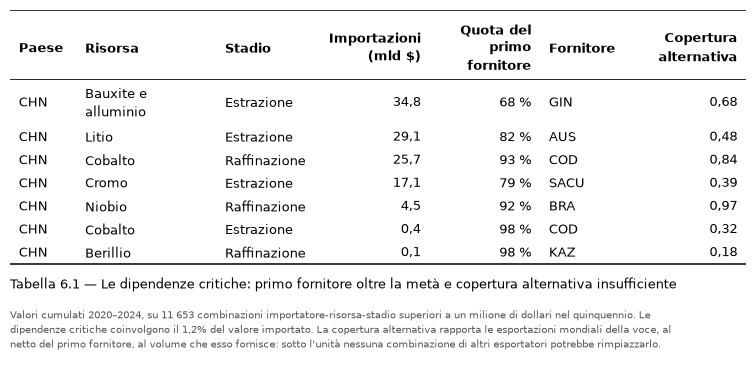

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_1_dipendenze_critiche.png


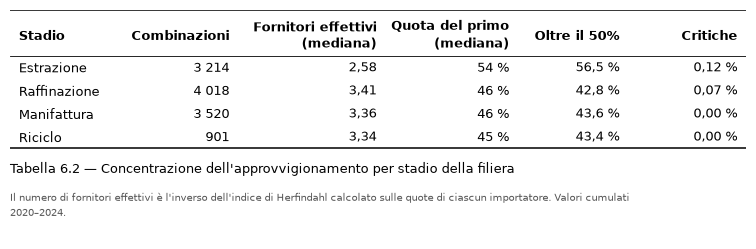

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_2_concentrazione_stadio.png


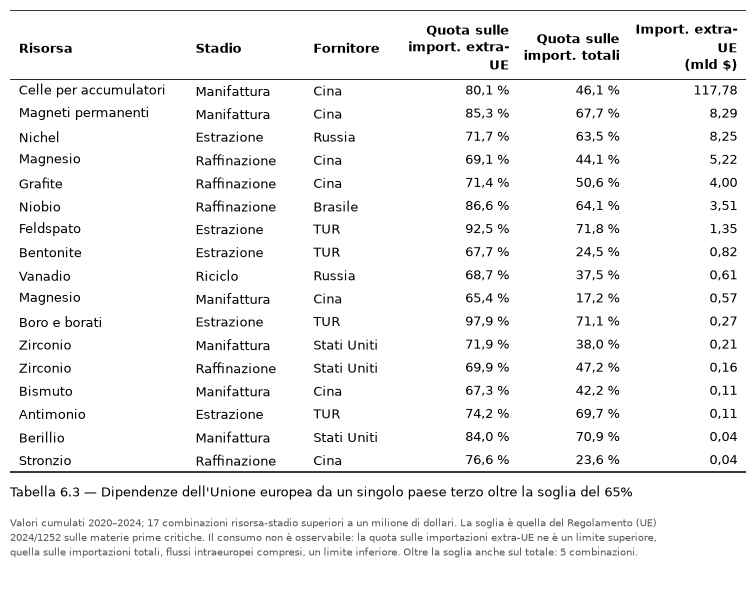

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_3_dipendenze_ue.png


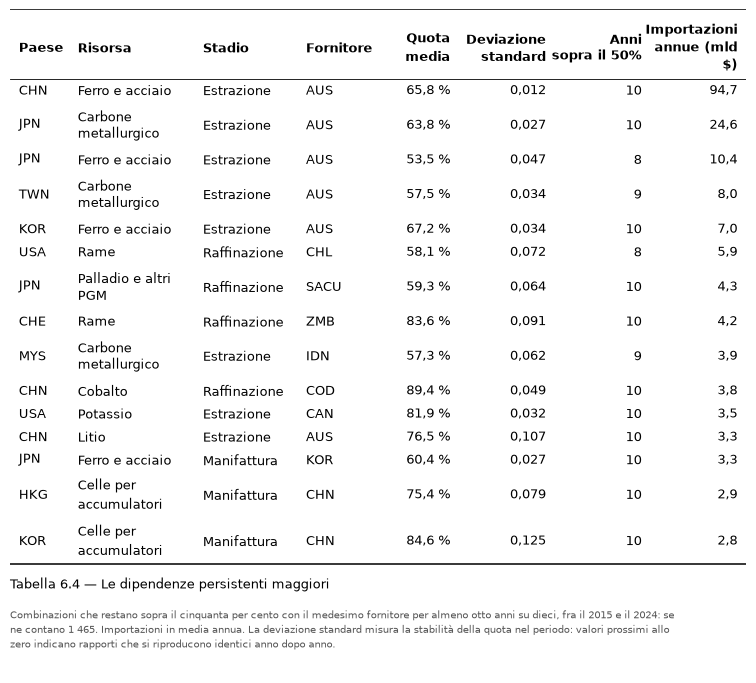

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_4_persistenti.png


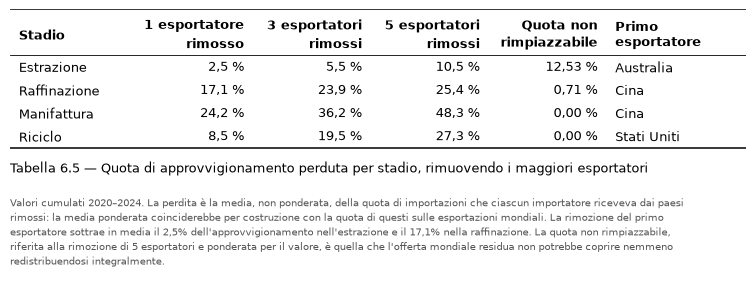

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_5_perdita_stadio.png


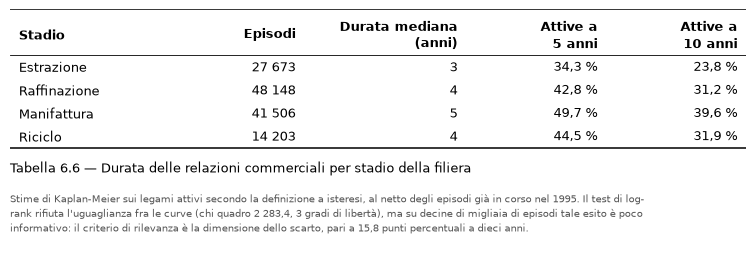

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_6_durata_stadio.png


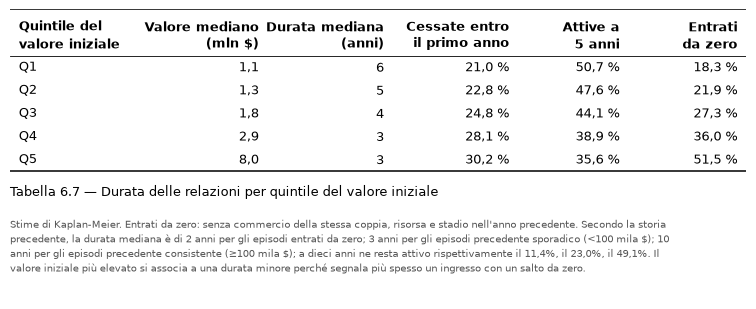

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_7_valore_storia.png


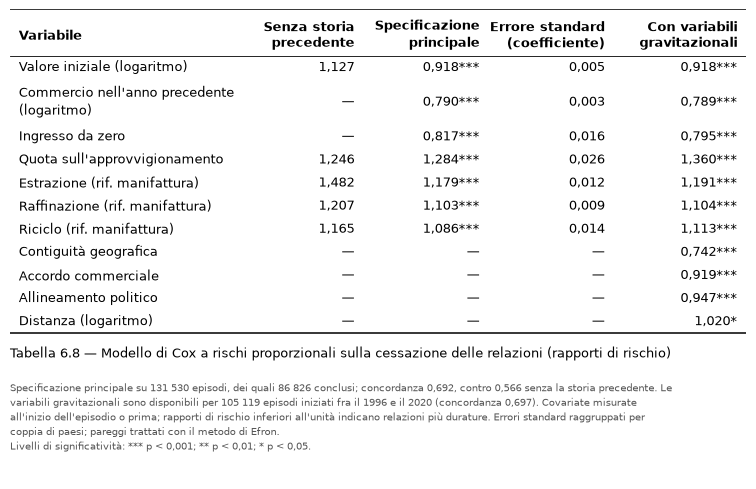

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_8_cox.png


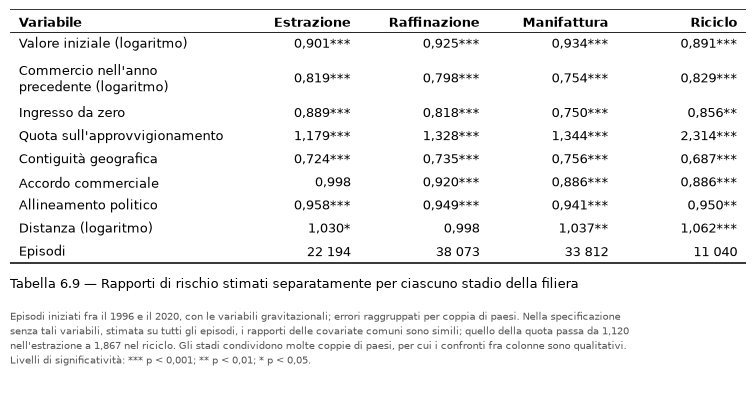

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_9_cox_stadio.png


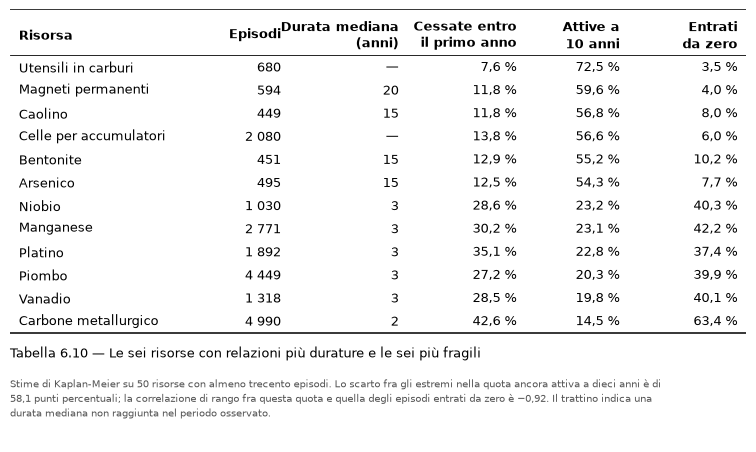

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_10_durata_risorsa.png


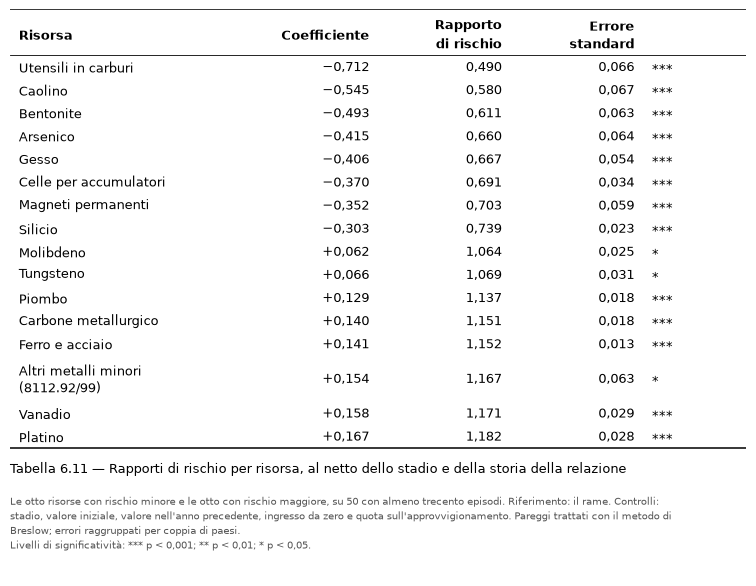

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_11_hr_risorsa.png


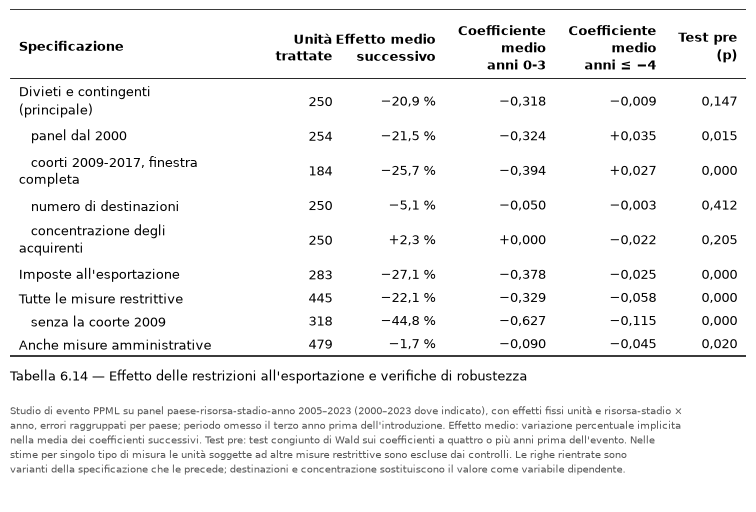

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_6_14_restrizioni.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_6_14_restrizioni.png')

In [116]:
# =============================================================================
# TABELLE
# =============================================================================
# Le tabelle 6.12 e 6.13 (modello gravitazionale) sono prodotte dalla cella
# GR5 della sezione gravity.

# %% CELLA T6.1 — le dipendenze critiche
D_dip = pd.read_csv(OUT_DIR / "vulnerabilita_dipendenze.csv")
CRIT = D_dip[D_dip.critica].sort_values("import_mld", ascending=False)

tabella(
    [(r.paese, _nome(r.resource), LBL_ST[r.stage_name], _n(r.import_mld, 1),
      _pp(r.quota_primo * 100, 0), r.primo, _n(r.copertura_alt, 2))
     for r in CRIT.itertuples()],
    ["Paese", "Risorsa", "Stadio", "Importazioni\n(mld $)",
     "Quota del\nprimo fornitore", "Fornitore", "Copertura\nalternativa"],
    [0.09, 0.19, 0.15, 0.14, 0.15, 0.12, 0.16],
    didascalia="Tabella 6.1 — Le dipendenze critiche: primo fornitore oltre la "
               "metà e copertura alternativa insufficiente",
    nota=f"Valori cumulati 2020–2024, su {_mig(len(D_dip))} combinazioni "
         f"importatore-risorsa-stadio superiori a un milione di dollari nel "
         f"quinquennio. Le dipendenze critiche coinvolgono il "
         f"{_n(CRIT.import_mld.sum() / D_dip.import_mld.sum() * 100, 1)}% del "
         f"valore importato. La copertura alternativa rapporta le esportazioni "
         f"mondiali della voce, al netto del primo fornitore, al volume che "
         f"esso fornisce: sotto l'unità nessuna combinazione di altri "
         f"esportatori potrebbe rimpiazzarlo.",
    allinea=["l", "l", "l", "r", "r", "l", "r"],
    out=FIG_DIR / "tab_6_1_dipendenze_critiche.png")


# %% CELLA T6.2 — concentrazione per stadio
AGG = (D_dip.groupby("stage_name")
       .apply(lambda g: pd.Series({
           "n": len(g), "n_eff": g.n_eff.median(), "quota": g.quota_primo.median(),
           "oltre50": (g.quota_primo >= 0.5).mean() * 100,
           "critiche": g.critica.mean() * 100}), include_groups=False)
       .reindex(STAGES))

tabella(
    [(LBL_ST[st], _mig(AGG.loc[st, "n"]), _n(AGG.loc[st, "n_eff"], 2),
      _pp(AGG.loc[st, "quota"] * 100, 0), _pp(AGG.loc[st, "oltre50"]),
      _pp(AGG.loc[st, "critiche"], 2)) for st in STAGES],
    ["Stadio", "Combinazioni", "Fornitori effettivi\n(mediana)",
     "Quota del primo\n(mediana)", "Oltre il 50%", "Critiche"],
    [0.16, 0.15, 0.20, 0.18, 0.15, 0.16],
    didascalia="Tabella 6.2 — Concentrazione dell'approvvigionamento per stadio "
               "della filiera",
    nota="Il numero di fornitori effettivi è l'inverso dell'indice di "
         "Herfindahl calcolato sulle quote di ciascun importatore. Valori "
         "cumulati 2020–2024.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_6_2_concentrazione_stadio.png")


# %% CELLA T6.3 — dipendenze europee oltre la soglia normativa
UE_ALL = pd.read_csv(OUT_DIR / "vulnerabilita_ue.csv")
UE = UE_ALL[UE_ALL.quota_extra >= 0.65] if "quota_extra" in UE_ALL.columns else UE_ALL
UE = UE.sort_values("import_extra_mld", ascending=False)
n_tot65 = int((UE.quota_totale >= 0.65).sum())

tabella(
    [(_nome(r.resource), LBL_ST[r.stage_name], NOMI_P.get(r.fornitore, r.fornitore),
      _pp(r.quota_extra * 100, 1), _pp(r.quota_totale * 100, 1),
      _n(r.import_extra_mld, 2)) for r in UE.itertuples()],
    ["Risorsa", "Stadio", "Fornitore", "Quota sulle\nimport. extra-UE",
     "Quota sulle\nimport. totali", "Import. extra-UE\n(mld $)"],
    [0.24, 0.16, 0.14, 0.15, 0.15, 0.16],
    didascalia="Tabella 6.3 — Dipendenze dell'Unione europea da un singolo paese "
               "terzo oltre la soglia del 65%",
    nota=f"Valori cumulati 2020–2024; {len(UE)} combinazioni risorsa-stadio"
         + (f" su {len(UE_ALL)}" if len(UE_ALL) > len(UE) else "")
         + " superiori a un milione di dollari. La soglia è quella del Regolamento "
           "(UE) 2024/1252 sulle materie prime critiche. Il consumo non è "
           "osservabile: la quota sulle importazioni extra-UE ne è un limite "
           "superiore, quella sulle importazioni totali, flussi intraeuropei "
           f"compresi, un limite inferiore. Oltre la soglia anche sul totale: "
           f"{n_tot65} combinazioni.",
    allinea=["l", "l", "l", "r", "r", "r"],
    out=FIG_DIR / "tab_6_3_dipendenze_ue.png")


# %% CELLA T6.4 — dipendenze persistenti
PER = pd.read_csv(OUT_DIR / "vulnerabilita_persistenti.csv")
if "persistente" in PER.columns:
    PER = PER[PER.persistente.astype(bool)]

tabella(
    [(r.paese, _nome(r.resource), LBL_ST[r.stage_name], r.primo_modale,
      _pp(r.quota_media * 100, 1), _n(r.quota_sd, 3), f"{int(r.anni_sopra_50)}",
      _n(r.import_medio, 1)) for r in PER.nlargest(15, "import_medio").itertuples()],
    ["Paese", "Risorsa", "Stadio", "Fornitore", "Quota\nmedia",
     "Deviazione\nstandard", "Anni\nsopra il 50%", "Importazioni\nannue (mld $)"],
    [0.08, 0.17, 0.14, 0.11, 0.11, 0.13, 0.13, 0.13],
    didascalia="Tabella 6.4 — Le dipendenze persistenti maggiori",
    nota=f"Combinazioni che restano sopra il cinquanta per cento con il "
         f"medesimo fornitore per almeno otto anni su dieci, fra il 2015 e il "
         f"2024: se ne contano {_mig(len(PER))}. Importazioni in media annua. "
         f"La deviazione standard misura la stabilità della quota nel periodo: "
         f"valori prossimi allo zero indicano rapporti che si riproducono "
         f"identici anno dopo anno.",
    allinea=["l", "l", "l", "l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_6_4_persistenti.png")


# %% CELLA T6.5 — perdita di approvvigionamento per stadio
VS_L = pd.read_csv(OUT_DIR / "vulnerabilita_per_stadio.csv")
c_perd = "perdita_media_non_ponderata" if "perdita_media_non_ponderata" in VS_L else "perdita"
c_nr = "non_rimpiazzabile_ponderata" if "non_rimpiazzabile_ponderata" in VS_L else "non_rimp"
c_pr = "primi" if "primi" in VS_L else "primo"
PV = VS_L.pivot(index="stadio", columns="k", values=c_perd)
NR = VS_L.pivot(index="stadio", columns="k", values=c_nr)
KS = sorted(VS_L.k.unique())
PRIMO = (VS_L[VS_L.k == 1].set_index("stadio")[c_pr].astype(str)
         .str.extract(r"([A-Z]{3,4})")[0].fillna("—"))

tabella(
    [(LBL_ST[st],) + tuple(_pp(PV.loc[st, k] * 100) for k in KS)
     + (_pp(NR.loc[st, KS[-1]] * 100, 2), NOMI_P.get(PRIMO[st], PRIMO[st]))
     for st in STAGES],
    ["Stadio"] + [f"{k} esportator{'e' if k == 1 else 'i'}\nrimoss{'o' if k == 1 else 'i'}"
                  for k in KS] + ["Quota non\nrimpiazzabile", "Primo\nesportatore"],
    [0.17] + [0.16] * len(KS) + [0.16, 0.19],
    didascalia="Tabella 6.5 — Quota di approvvigionamento perduta per stadio, "
               "rimuovendo i maggiori esportatori",
    nota=f"Valori cumulati 2020–2024. La perdita è la media, non ponderata, "
         f"della quota di importazioni che ciascun importatore riceveva dai paesi "
         f"rimossi: la media ponderata coinciderebbe per costruzione con la quota "
         f"di questi sulle esportazioni mondiali. La rimozione del primo "
         f"esportatore sottrae in media il {_n(PV.loc['upstream', 1] * 100, 1)}% "
         f"dell'approvvigionamento nell'estrazione e il "
         f"{_n(PV.loc['refining', 1] * 100, 1)}% nella raffinazione. La quota non "
         f"rimpiazzabile, riferita alla rimozione di {KS[-1]} esportatori e "
         f"ponderata per il valore, è quella che l'offerta mondiale residua non "
         f"potrebbe coprire nemmeno redistribuendosi integralmente.",
    allinea=["l"] + ["r"] * (len(KS) + 1) + ["l"],
    out=FIG_DIR / "tab_6_5_perdita_stadio.png")


# %% CELLA T6.6 — durata delle relazioni per stadio
KM = pd.read_csv(OUT_DIR / "sopravvivenza_km.csv").set_index("stadio")
KM_META = _serie("sopravvivenza_km_meta.csv")

tabella(
    [(LBL_ST[st], _mig(KM.loc[st, "episodi"]), _n(KM.loc[st, "mediana"], 0),
      _pp(KM.loc[st, "sopr_5anni"] * 100), _pp(KM.loc[st, "sopr_10anni"] * 100))
     for st in STAGES],
    ["Stadio", "Episodi", "Durata mediana\n(anni)", "Attive a\n5 anni",
     "Attive a\n10 anni"],
    [0.22, 0.18, 0.22, 0.19, 0.19],
    didascalia="Tabella 6.6 — Durata delle relazioni commerciali per stadio "
               "della filiera",
    nota=f"Stime di Kaplan-Meier sui legami attivi secondo la definizione a "
         f"isteresi, al netto degli episodi già in corso nel 1995. Il test di "
         f"log-rank rifiuta l'uguaglianza fra le curve (chi quadro "
         f"{_n(KM_META['chi2'], 1)}, {int(KM_META['gdl'])} gradi di libertà), ma "
         f"su decine di migliaia di episodi tale esito è poco informativo: il "
         f"criterio di rilevanza è la dimensione dello scarto, pari a "
         f"{_n(KM_META['scarto_10anni_pp'], 1)} punti percentuali a dieci anni.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_6_6_durata_stadio.png")


# %% CELLA T6.7 — valore iniziale e storia precedente
QV = pd.read_csv(OUT_DIR / "sopravvivenza_quintili_valore.csv")
ST_STORIA = pd.read_csv(OUT_DIR / "sopravvivenza_storia.csv")

tabella(
    [(r.quintile, _n(r.valore_mediano_mln, 1), _n(r.durata_mediana, 0),
      _pp(r.cessate_1anno * 100), _pp(r.attive_5anni * 100),
      _pp(r.entrati_da_zero * 100)) for r in QV.itertuples()],
    ["Quintile del\nvalore iniziale", "Valore mediano\n(mln $)",
     "Durata mediana\n(anni)", "Cessate entro\nil primo anno", "Attive a\n5 anni",
     "Entrati\nda zero"],
    [0.18, 0.17, 0.17, 0.17, 0.15, 0.16],
    didascalia="Tabella 6.7 — Durata delle relazioni per quintile del valore "
               "iniziale",
    nota="Stime di Kaplan-Meier. Entrati da zero: senza commercio della stessa "
         "coppia, risorsa e stadio nell'anno precedente. Secondo la storia "
         "precedente, la durata mediana è di "
         + "; ".join(f"{_n(r.mediana, 0)} anni per gli episodi {r.storia}"
                     for r in ST_STORIA.itertuples())
         + "; a dieci anni ne resta attivo rispettivamente il "
         + ", il ".join(f"{_n(r.attive_10anni * 100, 1)}%" for r in ST_STORIA.itertuples())
         + ". Il valore iniziale più elevato si associa a una durata minore perché "
           "segnala più spesso un ingresso con un salto da zero.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_6_7_valore_storia.png")


# %% CELLA T6.8 — modello di Cox
S_COX = pd.read_csv(OUT_DIR / "sopravvivenza_cox.csv", index_col=0)
COX_META = _serie("sopravvivenza_cox_meta.csv")
STORIA = pd.read_csv(OUT_DIR / "sopravvivenza_cox_storia.csv", index_col=0)
GRAV = pd.read_csv(OUT_DIR / "sopravvivenza_cox_gravity.csv", index_col=0)

ORD_C = ["lval", "lpre", "da_zero", "quota", "stage_name_upstream",
         "stage_name_refining", "stage_name_recycling",
         "contig", "rta", "allineamento", "ldist"]


def _val(df, c, col, pcol=None):
    if c not in df.index or pd.isna(df.loc[c, col]):
        return "—"
    return _n(df.loc[c, col]) + (_stelle(df.loc[c, pcol]) if pcol else "")


tabella(
    [(LBL_COV.get(c, c), _val(STORIA, c, "senza storia"),
      _val(S_COX, c, "exp(coef)", "p"), _val(S_COX, c, "se(coef)"),
      _val(GRAV, c, "con gravity", "p con gravity")) for c in ORD_C],
    ["Variabile", "Senza storia\nprecedente", "Specificazione\nprincipale",
     "Errore standard\n(coefficiente)", "Con variabili\ngravitazionali"],
    [0.32, 0.16, 0.17, 0.17, 0.18],
    didascalia="Tabella 6.8 — Modello di Cox a rischi proporzionali sulla "
               "cessazione delle relazioni (rapporti di rischio)",
    nota=f"Specificazione principale su {_mig(COX_META['n_episodi'])} episodi, dei "
         f"quali {_mig(COX_META['n_eventi'])} conclusi; concordanza "
         f"{_n(COX_META['concordance'])}, contro "
         f"{_n(STORIA.loc['concordance', 'senza storia'])} senza la storia "
         f"precedente. Le variabili gravitazionali sono disponibili per "
         f"{_mig(COX_META['n_episodi_gravity'])} episodi iniziati fra il 1996 e il "
         f"2020 (concordanza {_n(COX_META['concordance_gravity'])}). Covariate "
         f"misurate all'inizio dell'episodio o prima; rapporti di rischio "
         f"inferiori all'unità indicano relazioni più durature. Errori standard "
         f"raggruppati per coppia di paesi; pareggi trattati con il metodo di "
         f"Efron.\n" + NOTA_SIG,
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_6_8_cox.png")


# %% CELLA T6.9 — rapporti di rischio per stadio
CX_ALL = pd.read_csv(OUT_DIR / "sopravvivenza_cox_per_stadio.csv")
CXg, CXb = CX_ALL[CX_ALL.specifica == "gravity"], CX_ALL[CX_ALL.specifica == "base"]
HR_ST = CXg.pivot(index="covariata", columns="stadio", values="hr")[STAGES]
P_ST = CXg.pivot(index="covariata", columns="stadio", values="p")[STAGES]
QB = CXb[CXb.covariata == "quota"].set_index("stadio").hr
N_ST = CXg.groupby("stadio").n.first()
ORD_S = ["lval", "lpre", "da_zero", "quota", "contig", "rta", "allineamento", "ldist"]

tabella(
    [(LBL_COV.get(c, c),) + tuple(_n(HR_ST.loc[c, s]) + _stelle(P_ST.loc[c, s])
                                  for s in STAGES)
     for c in ORD_S if c in HR_ST.index]
    + [("Episodi",) + tuple(_mig(N_ST[s]) for s in STAGES)],
    ["Variabile"] + [LBL_ST[s] for s in STAGES],
    [0.30, 0.175, 0.175, 0.175, 0.175],
    didascalia="Tabella 6.9 — Rapporti di rischio stimati separatamente per "
               "ciascuno stadio della filiera",
    nota=f"Episodi iniziati fra il 1996 e il 2020, con le variabili "
         f"gravitazionali; errori raggruppati per coppia di paesi. Nella "
         f"specificazione senza tali variabili, stimata su tutti gli episodi, i "
         f"rapporti delle covariate comuni sono simili; quello della quota passa "
         f"da {_n(QB['upstream'])} nell'estrazione a {_n(QB['recycling'])} nel "
         f"riciclo. Gli stadi condividono molte coppie di paesi, per cui i "
         f"confronti fra colonne sono qualitativi.\n" + NOTA_SIG,
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_6_9_cox_stadio.png")


# %% CELLA T6.10 — durata per risorsa
RIS = pd.read_csv(OUT_DIR / "sopravvivenza_per_risorsa.csv")
EST = pd.concat([RIS.head(6), RIS.tail(6)])

tabella(
    [(_nome(r.risorsa), _mig(r.episodi), _n(r.mediana, 0), _pp(r.cessate_1anno * 100),
      _pp(r.s10 * 100), _pp(r.entrati_da_zero * 100)) for r in EST.itertuples()],
    ["Risorsa", "Episodi", "Durata mediana\n(anni)", "Cessate entro\nil primo anno",
     "Attive a\n10 anni", "Entrati\nda zero"],
    [0.26, 0.12, 0.16, 0.16, 0.14, 0.16],
    didascalia="Tabella 6.10 — Le sei risorse con relazioni più durature e le "
               "sei più fragili",
    nota=f"Stime di Kaplan-Meier su {len(RIS)} risorse con almeno trecento "
         f"episodi. Lo scarto fra gli estremi nella quota ancora attiva a dieci "
         f"anni è di {_n((RIS.s10.max() - RIS.s10.min()) * 100, 1)} punti "
         f"percentuali; la correlazione di rango fra questa quota e quella degli "
         f"episodi entrati da zero è "
         f"{_sgn(RIS.s10.rank().corr(RIS.entrati_da_zero.rank()), 2)}. Il trattino "
         f"indica una durata mediana non raggiunta nel periodo osservato.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_6_10_durata_risorsa.png")


# %% CELLA T6.11 — rischi per risorsa, al netto di stadio e covariate
HR = pd.read_csv(OUT_DIR / "sopravvivenza_hr_risorsa.csv", index_col=0)
EST_HR = pd.concat([HR.head(8), HR.tail(8)])

tabella(
    [(_nome(i), _sgn(r["coef"]), _n(r["exp(coef)"]), _n(r["se(coef)"]),
      _stelle(r["p"])) for i, r in EST_HR.iterrows()],
    ["Risorsa", "Coefficiente", "Rapporto\ndi rischio", "Errore\nstandard", ""],
    [0.32, 0.18, 0.18, 0.18, 0.14],
    didascalia="Tabella 6.11 — Rapporti di rischio per risorsa, al netto dello "
               "stadio e della storia della relazione",
    nota=f"Le otto risorse con rischio minore e le otto con rischio maggiore, "
         f"su {len(HR) + 1} con almeno trecento episodi. Riferimento: il rame. "
         f"Controlli: stadio, valore iniziale, valore nell'anno precedente, "
         f"ingresso da zero e quota sull'approvvigionamento. Pareggi trattati con "
         f"il metodo di Breslow; errori raggruppati per coppia di paesi.\n" + NOTA_SIG,
    allinea=["l", "r", "r", "r", "l"],
    out=FIG_DIR / "tab_6_11_hr_risorsa.png")


# %% CELLA T6.14 — restrizioni all'esportazione: effetto e robustezza
R5 = pd.read_csv(OUT_DIR / "event_study_robustezza.csv").set_index("specificazione")
R6 = pd.read_csv(OUT_DIR / "event_study_coorti.csv").set_index("specificazione")
MS = pd.read_csv(OUT_DIR / "event_study_meccanismo_sintesi.csv").set_index("variabile")


def _da_sintesi(df, k):
    r = df.loc[k]
    return (int(r.unita_trattate), r.effetto_pct, r.t0_t3, r.pre_medio, r.p_pre_congiunto)


def _da_mecc(dep):
    t = pd.read_csv(OUT_DIR / f"event_study_mecc_{dep}.csv", index_col=0)
    post = t[t.rel >= 0].Estimate.mean()
    return (int(R5.loc["solo divieti e contingenti", "unita_trattate"]),
            (np.exp(post) - 1) * 100, t[t.rel.between(0, 3)].Estimate.mean(),
            t[t.rel <= -4].Estimate.mean(), MS.loc[dep, "p_test_pre"])


RIGHE_EV = [
    ("Divieti e contingenti (principale)", _da_sintesi(R5, "solo divieti e contingenti")),
    ("   panel dal 2000", _da_sintesi(R6, "divieti e contingenti | panel dal 2000")),
    ("   coorti 2009-2017, finestra completa",
     _da_sintesi(R6, "divieti e contingenti | finestra bilanciata 2009-2017")),
    ("   numero di destinazioni", _da_mecc("n_clienti")),
    ("   concentrazione degli acquirenti", _da_mecc("hhi_clienti")),
    ("Imposte all'esportazione", _da_sintesi(R5, "solo imposte")),
    ("Tutte le misure restrittive", _da_sintesi(R5, "principale (misure restrittive)")),
    ("   senza la coorte 2009", _da_sintesi(R5, "senza la coorte 2009")),
    ("Anche misure amministrative", _da_sintesi(R5, "tutte le misure (anche amministrative)")),
]

tabella(
    [(lab, _mig(u), _sgn(e, 1) + " %", _sgn(t03), _sgn(pre), _n(p, 3))
     for lab, (u, e, t03, pre, p) in RIGHE_EV],
    ["Specificazione", "Unità\ntrattate", "Effetto medio\nsuccessivo",
     "Coefficiente medio\nanni 0-3", "Coefficiente medio\nanni ≤ −4", "Test pre\n(p)"],
    [0.34, 0.11, 0.14, 0.15, 0.15, 0.11],
    didascalia="Tabella 6.14 — Effetto delle restrizioni all'esportazione e "
               "verifiche di robustezza",
    nota="Studio di evento PPML su panel paese-risorsa-stadio-anno 2005–2023 "
         "(2000–2023 dove indicato), con effetti fissi unità e risorsa-stadio × "
         "anno, errori raggruppati per paese; periodo omesso il terzo anno prima "
         "dell'introduzione. Effetto medio: variazione percentuale implicita "
         "nella media dei coefficienti successivi. Test pre: test congiunto di "
         "Wald sui coefficienti a quattro o più anni prima dell'evento. Nelle "
         "stime per singolo tipo di misura le unità soggette ad altre misure "
         "restrittive sono escluse dai controlli. Le righe rientrate sono "
         "varianti della specificazione che le precede; destinazioni e "
         "concentrazione sostituiscono il valore come variabile dipendente.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_6_14_restrizioni.png")

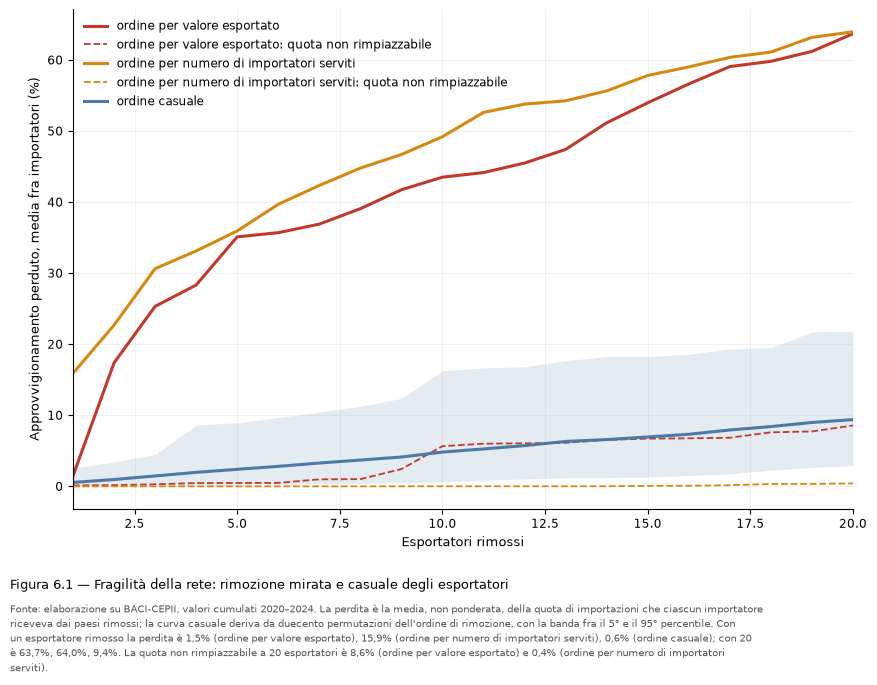

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_6_1_attacco_casuale.png


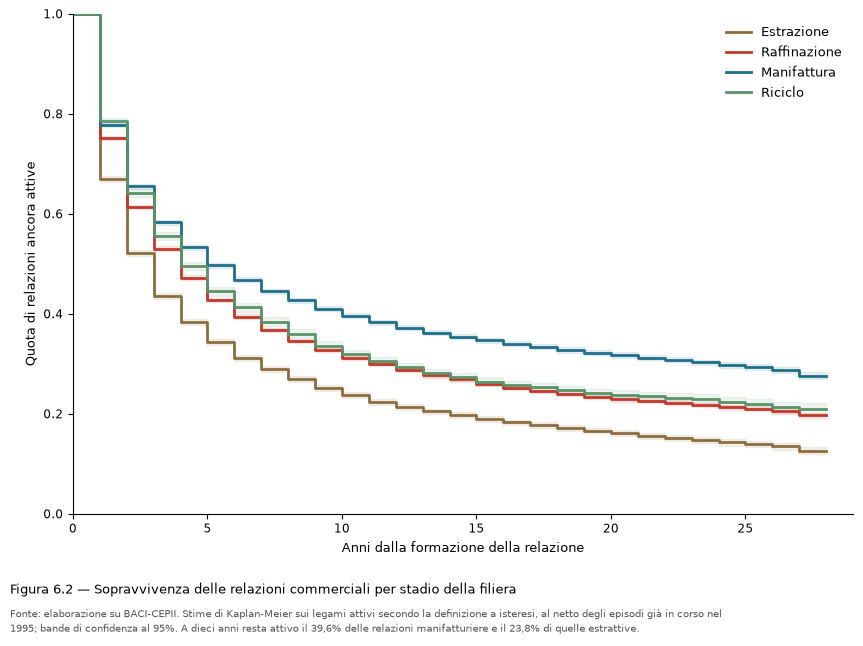

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_6_2_sopravvivenza_stadio.png


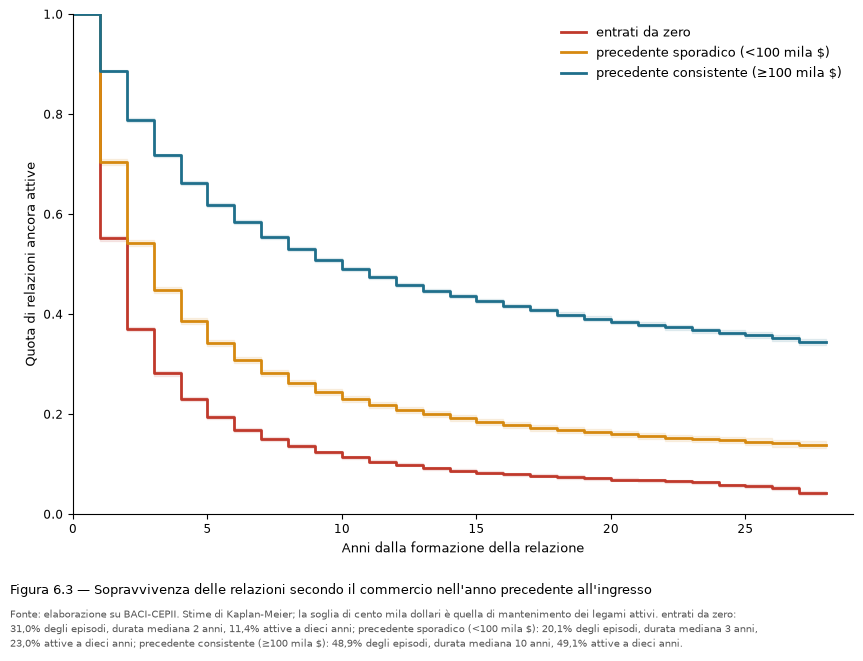

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_6_3_sopravvivenza_storia.png


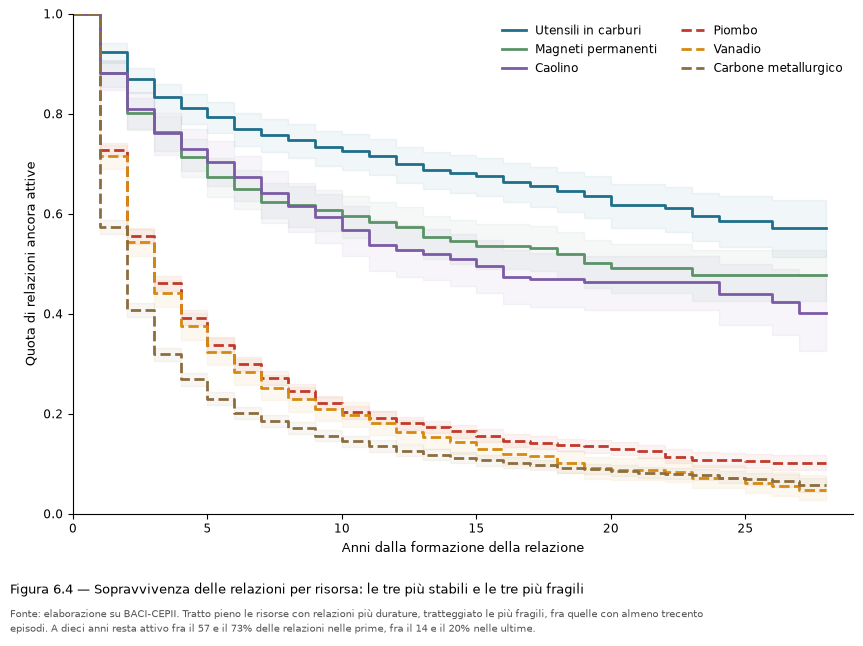

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_6_4_sopravvivenza_risorse.png


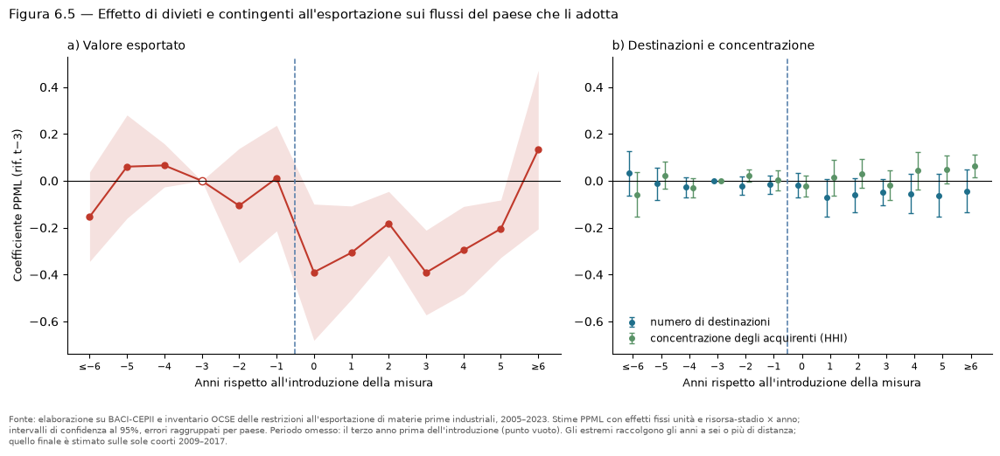

In [117]:
# =============================================================================
# FIGURE
# =============================================================================

# %% CELLA F6.1 — rimozione degli esportatori: per valore, per ampiezza, casuale
CUR = pd.read_csv(OUT_DIR / "vulnerabilita_curve.csv")


def _col(*cand):
    for c in cand:
        if c in CUR.columns:
            return c
    raise KeyError(f"nessuna fra {cand} in {CUR.columns.tolist()}")


C_P = _col("perdita_media_non_ponderata", "perdita", "persa")
C_NR = _col("non_rimpiazzabile_ponderata", "non_rimp")
C_LO = next((c for c in CUR.columns if "p05" in c), None)
C_HI = next((c for c in CUR.columns if "p95" in c), None)
TIPI_C = [t for t in CUR.tipo.unique() if t != "casuale"] + ["casuale"]
LBL_C = {"mirato, valore": "ordine per valore esportato",
         "mirato, ampiezza": "ordine per numero di importatori serviti",
         "casuale": "ordine casuale"}
COL_C = {"mirato, valore": "#c0392b", "mirato, ampiezza": "#d68910",
         "casuale": "#4e79a7"}
CV = {t: CUR[CUR.tipo == t].set_index("k").sort_index() for t in TIPI_C}
K_FIN = 20 if 20 in CUR.k.values else int(CUR.k.max())


def _f61(ax):
    for t in TIPI_C:
        c = CV[t]
        ax.plot(c.index, c[C_P] * 100, lw=2.2, color=COL_C.get(t, "0.4"),
                label=LBL_C.get(t, t))
        if t == "casuale" and C_LO and C_HI:
            ax.fill_between(c.index, c[C_LO] * 100, c[C_HI] * 100,
                            color=COL_C["casuale"], alpha=0.15, lw=0)
        elif t != "casuale":
            ax.plot(c.index, c[C_NR] * 100, lw=1.3, ls="--", color=COL_C.get(t, "0.4"),
                    label=f"{LBL_C.get(t, t)}: quota non rimpiazzabile")
    ax.set_xlabel("Esportatori rimossi", fontsize=9)
    ax.set_ylabel("Approvvigionamento perduto, media fra importatori (%)", fontsize=9)
    ax.set_xlim(1, CUR.k.max())
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")


_v = lambda t, k, col=C_P: _n(CV[t].loc[k, col] * 100, 1)
_mir = [t for t in TIPI_C if t != "casuale"]
figura(_f61, altezza=5.0,
       didascalia="Figura 6.1 — Fragilità della rete: rimozione mirata e "
                  "casuale degli esportatori",
       nota=f"Fonte: elaborazione su BACI-CEPII, valori cumulati 2020–2024. La "
            f"perdita è la media, non ponderata, della quota di importazioni che "
            f"ciascun importatore riceveva dai paesi rimossi; la curva casuale "
            f"deriva da duecento permutazioni dell'ordine di rimozione"
            + (", con la banda fra il 5° e il 95° percentile" if C_LO else "")
            + ". Con un esportatore rimosso la perdita è "
            + ", ".join(f"{_v(t, 1)}% ({LBL_C.get(t, t)})" for t in TIPI_C)
            + f"; con {K_FIN} è "
            + ", ".join(f"{_v(t, K_FIN)}%" for t in TIPI_C)
            + f". La quota non rimpiazzabile a {K_FIN} esportatori è "
            + " e ".join(f"{_v(t, K_FIN, C_NR)}% ({LBL_C.get(t, t)})" for t in _mir)
            + ".",
       out=FIG_DIR / "fig_6_1_attacco_casuale.png")


# %% CELLA F6.2 — curve di sopravvivenza per stadio
from lifelines import KaplanMeierFitter

if "Ec" not in globals():
    _EP = pd.read_csv(OUT_DIR / "sopravvivenza_episodi.csv")
    Ec = _EP[~_EP.troncato_sx].copy()
    print(f"[F6.2] {len(Ec):,} episodi caricati da file")


def _f62(ax):
    km = KaplanMeierFitter()
    for st in STAGES:
        m = Ec.stage_name == st
        km.fit(Ec.durata[m], Ec.evento[m], label=LBL_ST[st])
        km.plot_survival_function(ax=ax, color=COL_ST6[st], lw=2, ci_alpha=0.10)
    ax.set_xlabel("Anni dalla formazione della relazione", fontsize=9)
    ax.set_ylabel("Quota di relazioni ancora attive", fontsize=9)
    ax.set_xlim(0, 29)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=9)


figura(_f62, altezza=5.0,
       didascalia="Figura 6.2 — Sopravvivenza delle relazioni commerciali per "
                  "stadio della filiera",
       nota=f"Fonte: elaborazione su BACI-CEPII. Stime di Kaplan-Meier sui "
            f"legami attivi secondo la definizione a isteresi, al netto degli "
            f"episodi già in corso nel 1995; bande di confidenza al 95%. A dieci "
            f"anni resta attivo il {_n(KM.loc['manufacturing', 'sopr_10anni'] * 100, 1)}% "
            f"delle relazioni manifatturiere e il "
            f"{_n(KM.loc['upstream', 'sopr_10anni'] * 100, 1)}% di quelle "
            f"estrattive.",
       out=FIG_DIR / "fig_6_2_sopravvivenza_stadio.png")


# %% CELLA F6.3 — sopravvivenza secondo la storia precedente
if "Ec2" not in globals() or "val_pre" not in Ec2.columns:
    Ec2 = aggiungi_covariate(Ec)
ST_STORIA = pd.read_csv(OUT_DIR / "sopravvivenza_storia.csv").set_index("storia")
GRUPPI_ST = [("entrati da zero", "#c0392b"),
             ("precedente sporadico (<100 mila $)", "#d68910"),
             ("precedente consistente (≥100 mila $)", "#1f6f8b")]
_storia = np.select([Ec2.val_pre == 0, Ec2.val_pre < 100.0],
                    [GRUPPI_ST[0][0], GRUPPI_ST[1][0]], default=GRUPPI_ST[2][0])


def _f63(ax):
    km = KaplanMeierFitter()
    for nome, col in GRUPPI_ST:
        m = _storia == nome
        km.fit(Ec2.durata[m], Ec2.evento[m], label=nome)
        km.plot_survival_function(ax=ax, color=col, lw=2, ci_alpha=0.10)
    ax.set_xlabel("Anni dalla formazione della relazione", fontsize=9)
    ax.set_ylabel("Quota di relazioni ancora attive", fontsize=9)
    ax.set_xlim(0, 29)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=9)


figura(_f63, altezza=5.0,
       didascalia="Figura 6.3 — Sopravvivenza delle relazioni secondo il commercio "
                  "nell'anno precedente all'ingresso",
       nota="Fonte: elaborazione su BACI-CEPII. Stime di Kaplan-Meier; la soglia "
            "di cento mila dollari è quella di mantenimento dei legami attivi. "
            + "; ".join(f"{nome}: {_n(ST_STORIA.loc[nome, 'quota_episodi'] * 100, 1)}% "
                        f"degli episodi, durata mediana "
                        f"{_n(ST_STORIA.loc[nome, 'mediana'], 0)} anni, "
                        f"{_n(ST_STORIA.loc[nome, 'attive_10anni'] * 100, 1)}% "
                        f"attive a dieci anni" for nome, _ in GRUPPI_ST) + ".",
       out=FIG_DIR / "fig_6_3_sopravvivenza_storia.png")


# %% CELLA F6.4 — curve delle risorse estreme
sel6 = list(RIS.head(3).risorsa) + list(RIS.tail(3).risorsa)
PAL6 = ["#1f6f8b", "#5a9367", "#7b5aa6", "#c0392b", "#d68910", "#8c6d3f"]
_ext = RIS.set_index("risorsa").loc[sel6, "s10"]


def _f64(ax):
    km = KaplanMeierFitter()
    for i, r in enumerate(sel6):
        m = Ec.resource == r
        km.fit(Ec.durata[m], Ec.evento[m], label=_nome(r))
        km.plot_survival_function(ax=ax, color=PAL6[i], lw=2,
                                  ls="-" if i < 3 else "--", ci_alpha=0.06)
    ax.set_xlabel("Anni dalla formazione della relazione", fontsize=9)
    ax.set_ylabel("Quota di relazioni ancora attive", fontsize=9)
    ax.set_xlim(0, 29)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, ncol=2, fontsize=8.5)


figura(_f64, altezza=5.0,
       didascalia="Figura 6.4 — Sopravvivenza delle relazioni per risorsa: le "
                  "tre più stabili e le tre più fragili",
       nota=f"Fonte: elaborazione su BACI-CEPII. Tratto pieno le risorse con "
            f"relazioni più durature, tratteggiato le più fragili, fra quelle "
            f"con almeno trecento episodi. A dieci anni resta attivo fra il "
            f"{_n(_ext.iloc[:3].min() * 100, 0)} e il "
            f"{_n(_ext.iloc[:3].max() * 100, 0)}% delle relazioni nelle prime, "
            f"fra il {_n(_ext.iloc[3:].min() * 100, 0)} e il "
            f"{_n(_ext.iloc[3:].max() * 100, 0)}% nelle ultime.",
       out=FIG_DIR / "fig_6_4_sopravvivenza_risorse.png")


# %% CELLA F6.5 — studio di evento sulle restrizioni (due pannelli)
# Non usa figura(), che disegna un solo pannello: titolo e nota sono resi con
# lo stesso schema delle altre figure.
import matplotlib.pyplot as plt


def _carica_es(dep, rif=-3):
    t = pd.read_csv(OUT_DIR / f"event_study_mecc_{dep}.csv")[["rel", "Estimate", "Std. Error"]]
    t = (pd.concat([t, pd.DataFrame({"rel": [rif], "Estimate": [0.0], "Std. Error": [0.0]})])
           .sort_values("rel").reset_index(drop=True))
    t["lo"], t["hi"] = t.Estimate - 1.96 * t["Std. Error"], t.Estimate + 1.96 * t["Std. Error"]
    return t


ETICH_REL = ["≤−6"] + [str(k).replace("-", "−") for k in range(-5, 6)] + ["≥6"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
t = _carica_es("value")
ax.fill_between(t.rel, t.lo, t.hi, color="#c0392b", alpha=0.15, lw=0)
ax.plot(t.rel, t.Estimate, "o-", color="#c0392b", ms=5)
ax.plot(-3, 0, "o", ms=6, mfc="white", mec="#c0392b")
ax.set_title("a) Valore esportato", loc="left", fontsize=10)
ax.set_ylabel("Coefficiente PPML (rif. t−3)", fontsize=9)

ax = axes[1]
for dep, lab, c, dx in (("n_clienti", "numero di destinazioni", "#1f6f8b", -0.13),
                        ("hhi_clienti", "concentrazione degli acquirenti (HHI)", "#5a9367", 0.13)):
    t = _carica_es(dep)
    ax.errorbar(t.rel + dx, t.Estimate, yerr=1.96 * t["Std. Error"], fmt="o", ms=4,
                color=c, ecolor=c, elinewidth=1, capsize=2, label=lab)
ax.set_title("b) Destinazioni e concentrazione", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax.set_ylim(axes[0].get_ylim())

for ax in axes:
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(-0.5, color="#4e79a7", ls="--", lw=1.1)
    ax.set_xticks(range(-6, 7))
    ax.set_xticklabels(ETICH_REL, fontsize=8)
    ax.set_xlabel("Anni rispetto all'introduzione della misura", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Figura 6.5 — Effetto di divieti e contingenti all'esportazione sui "
             "flussi del paese che li adotta", fontsize=11, x=0.01, ha="left")
fig.text(0.01, -0.03,
         "Fonte: elaborazione su BACI-CEPII e inventario OCSE delle restrizioni "
         "all'esportazione di materie prime industriali, 2005–2023. Stime PPML con "
         "effetti fissi unità e risorsa-stadio × anno;\nintervalli di confidenza al "
         "95%, errori raggruppati per paese. Periodo omesso: il terzo anno prima "
         "dell'introduzione (punto vuoto). Gli estremi raccolgono gli anni a sei o "
         "più di distanza;\nquello finale è stimato sulle sole coorti 2009–2017.",
         fontsize=7.5, color="0.35", ha="left", va="top")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_6_5_event_study.png", dpi=300, bbox_inches="tight")
plt.show()

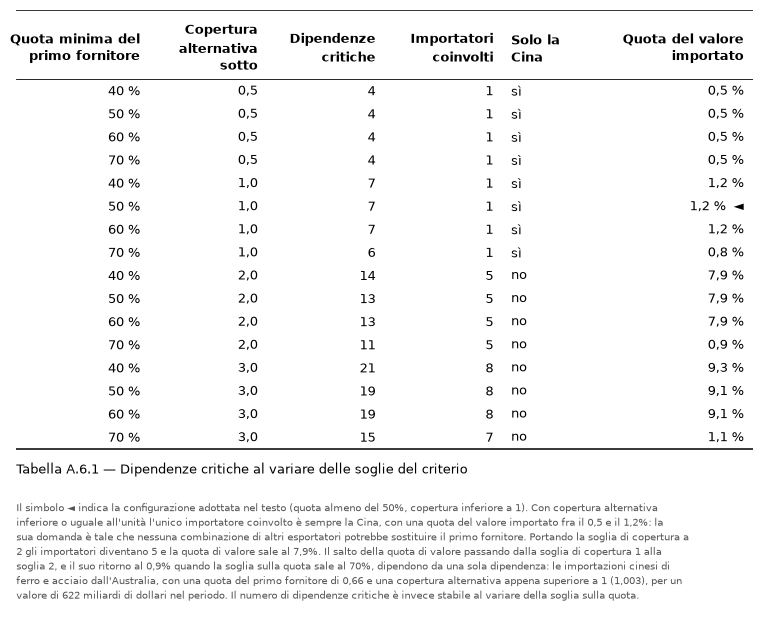

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A6_1_sensibilita.png
dipendenza che spiega il salto: CHN iron_ore_steel da AUS, quota 0.659, copertura 1.003, 621.8 mld $


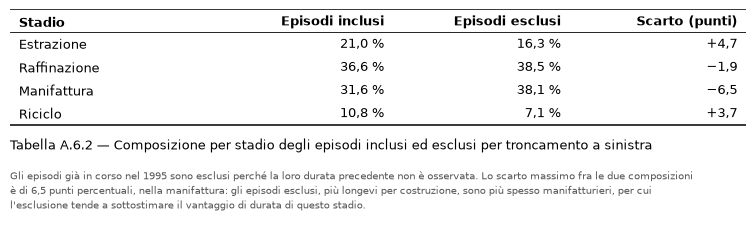

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A6_2_troncamento.png


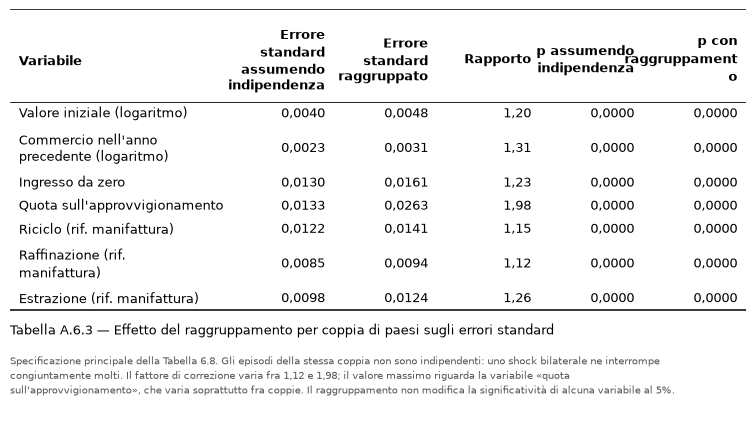

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A6_3_cluster.png


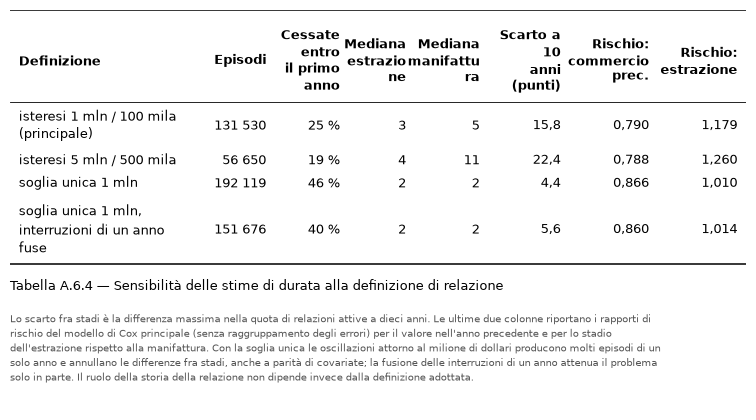

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A6_4_definizioni.png


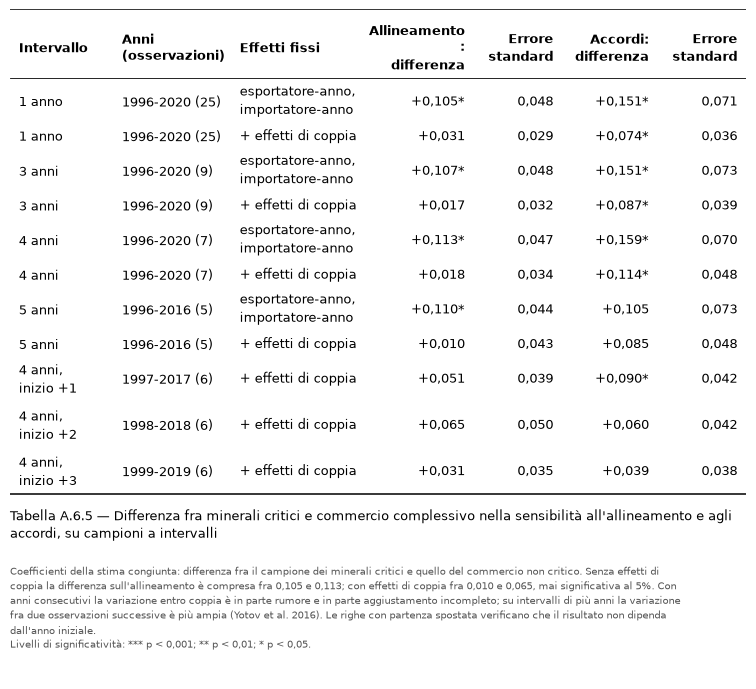

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A6_5_gravity_intervalli.png


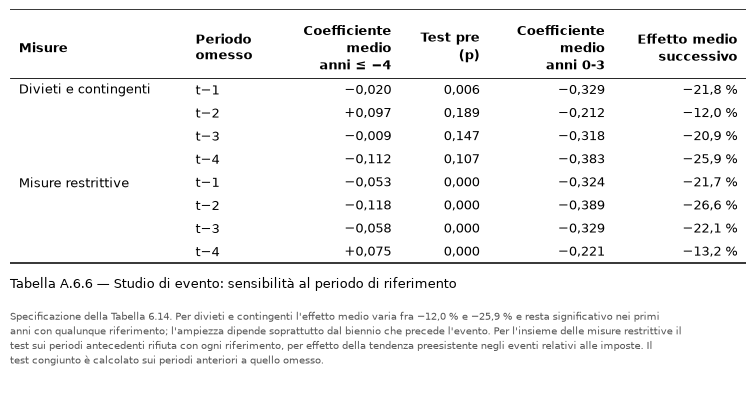

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A6_6_event_riferimento.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_A6_6_event_riferimento.png')

In [118]:
# =============================================================================
# APPENDICE
# =============================================================================

# %% CELLA A6.1 — sensibilità del criterio di criticità alle soglie
SEN = pd.read_csv(OUT_DIR / "vulnerabilita_sensibilita.csv")
SEN = SEN.sort_values(["soglia_copertura", "soglia_quota"]).reset_index(drop=True)
_princ = (SEN.soglia_quota == 0.5) & (SEN.soglia_copertura == 1.0)
_cop1 = SEN[SEN.soglia_copertura <= 1.0]
_cop2 = SEN[(SEN.soglia_copertura == 2.0) & (SEN.soglia_quota == 0.5)]
_cop2_70 = SEN[(SEN.soglia_copertura == 2.0) & (SEN.soglia_quota == 0.7)]

# la dipendenza che spiega il salto della quota di valore fra copertura 1 e 2
_dip = {"paese": "CHN", "resource": "iron_ore_steel", "primo": "AUS",
        "quota_primo": 0.659, "copertura_alt": 1.003, "import_mld": 622.0}   # da V8
try:
    _D = pd.read_csv(OUT_DIR / "vulnerabilita_dipendenze.csv")
    _sel = _D[_D.quota_primo.between(0.5, 0.7, inclusive="left")
              & _D.copertura_alt.between(1.0, 2.0, inclusive="left")]
    if not _sel.empty:
        _dip = _sel.nlargest(1, "import_mld").iloc[0].to_dict()
except (FileNotFoundError, AttributeError, KeyError):
    pass

if _dip["paese"] == "CHN" and _dip["primo"] == "AUS":
    _chi = f"le importazioni cinesi di {_nome(_dip['resource']).lower()} dall'Australia"
else:
    _chi = (f"le importazioni di {_nome(_dip['resource']).lower()} di {_dip['paese']} "
            f"dal primo fornitore {_dip['primo']}")

_nota_salto = ""
if len(_cop2) and len(_cop2_70):
    _nota_salto = (
        f" Il salto della quota di valore passando dalla soglia di copertura 1 alla soglia 2, "
        f"e il suo ritorno al {_n(_cop2_70.quota_valore.iloc[0] * 100, 1)}% quando la soglia "
        f"sulla quota sale al 70%, dipendono da una sola dipendenza: {_chi}, con una quota "
        f"del primo fornitore di {_n(_dip['quota_primo'], 2)} e una copertura alternativa "
        f"appena superiore a 1 ({_n(_dip['copertura_alt'], 3)}), per un valore di "
        f"{_mig(_dip['import_mld'])} miliardi di dollari nel periodo. Il numero di "
        f"dipendenze critiche è invece stabile al variare della soglia sulla quota.")

tabella(
    [(_n(r.soglia_quota * 100, 0) + " %", _n(r.soglia_copertura, 1),
      f"{int(r.critiche)}", f"{int(r.importatori)}", "sì" if r.solo_cina else "no",
      _pp(r.quota_valore * 100, 1) + ("  ◄" if p else ""))
     for r, p in zip(SEN.itertuples(), _princ)],
    ["Quota minima del\nprimo fornitore", "Copertura\nalternativa sotto",
     "Dipendenze\ncritiche", "Importatori\ncoinvolti", "Solo la\nCina", "Quota del valore\nimportato"],
    [0.18, 0.16, 0.16, 0.16, 0.14, 0.20],
    didascalia="Tabella A.6.1 — Dipendenze critiche al variare delle soglie del "
               "criterio",
    nota=f"Il simbolo ◄ indica la configurazione adottata nel testo (quota "
         f"almeno del 50%, copertura inferiore a 1). Con copertura alternativa "
         f"inferiore o uguale all'unità l'unico importatore coinvolto è "
         f"{'sempre ' if _cop1.solo_cina.all() else 'quasi sempre '}la Cina, con "
         f"una quota del valore importato fra il {_n(_cop1.quota_valore.min() * 100, 1)} "
         f"e il {_n(_cop1.quota_valore.max() * 100, 1)}%: la sua domanda è tale "
         f"che nessuna combinazione di altri esportatori potrebbe sostituire il "
         f"primo fornitore. Portando la soglia di copertura a 2 gli importatori "
         + (f"diventano {int(_cop2.importatori.iloc[0])} e la quota di valore sale "
            f"al {_n(_cop2.quota_valore.iloc[0] * 100, 1)}%."
            if len(_cop2) else "aumentano, ma con quote di valore contenute.")
         + _nota_salto,
    allinea=["r", "r", "r", "r", "l", "r"],
    out=FIG_DIR / "tab_A6_1_sensibilita.png")
print(f"dipendenza che spiega il salto: {_dip['paese']} {_dip['resource']} da {_dip['primo']}, "
      f"quota {_dip['quota_primo']:.3f}, copertura {_dip['copertura_alt']:.3f}, "
      f"{_dip['import_mld']:,.1f} mld $")


# %% CELLA A6.2 — neutralità del troncamento a sinistra
TR = pd.read_csv(OUT_DIR / "sopravvivenza_troncamento.csv", index_col=0)
_c_inc, _c_esc = TR.columns[0], TR.columns[1]
_scarti = (TR[_c_inc] - TR[_c_esc]) * 100

tabella(
    [(LBL_ST[st], _pp(TR.loc[st, _c_inc] * 100), _pp(TR.loc[st, _c_esc] * 100),
      _sgn(_scarti.loc[st], 1)) for st in STAGES],
    ["Stadio", "Episodi inclusi", "Episodi esclusi", "Scarto (punti)"],
    [0.28, 0.24, 0.24, 0.24],
    didascalia="Tabella A.6.2 — Composizione per stadio degli episodi inclusi ed "
               "esclusi per troncamento a sinistra",
    nota=f"Gli episodi già in corso nel 1995 sono esclusi perché la loro durata "
         f"precedente non è osservata. Lo scarto massimo fra le due composizioni è "
         f"di {_n(_scarti.abs().max(), 1)} punti percentuali, nella "
         f"{LBL_ST[_scarti.abs().idxmax()].lower()}: gli episodi esclusi, più "
         f"longevi per costruzione, sono più spesso manifatturieri, per cui "
         f"l'esclusione tende a sottostimare il vantaggio di durata di questo "
         f"stadio.",
    allinea=["l", "r", "r", "r"],
    out=FIG_DIR / "tab_A6_2_troncamento.png")


# %% CELLA A6.3 — effetto del raggruppamento sugli errori standard
CS = pd.read_csv(OUT_DIR / "sopravvivenza_cluster_se.csv", index_col=0)
_cambia = [LBL_COV.get(c, c).lower() for c in CS.index
           if CS.loc[c, "p_indipendenti"] < 0.05 <= CS.loc[c, "p_raggruppati"]]
_imax = CS.rapporto.idxmax()

tabella(
    [(LBL_COV.get(i, i), _n(r.se_indipendenti, 4), _n(r.se_raggruppati, 4),
      _n(r.rapporto, 2), _n(r.p_indipendenti, 4), _n(r.p_raggruppati, 4))
     for i, r in CS.iterrows()],
    ["Variabile", "Errore standard\nassumendo\nindipendenza",
     "Errore standard\nraggruppato", "Rapporto", "p assumendo\nindipendenza",
     "p con\nraggruppamento"],
    [0.30, 0.14, 0.14, 0.14, 0.14, 0.14],
    didascalia="Tabella A.6.3 — Effetto del raggruppamento per coppia di paesi "
               "sugli errori standard",
    nota=f"Specificazione principale della Tabella 6.8. Gli episodi della stessa "
         f"coppia non sono indipendenti: uno shock bilaterale ne interrompe "
         f"congiuntamente molti. Il fattore di correzione varia fra "
         f"{_n(CS.rapporto.min(), 2)} e {_n(CS.rapporto.max(), 2)}; il valore "
         f"massimo riguarda la variabile «{LBL_COV.get(_imax, _imax).lower()}», "
         f"che varia soprattutto fra coppie. "
         + (f"Senza il raggruppamento risulterebbe significativa al 5% anche la "
            f"{', la '.join(_cambia)}." if _cambia else
            "Il raggruppamento non modifica la significatività di alcuna "
            "variabile al 5%."),
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_A6_3_cluster.png")


# %% CELLA A6.4 — sensibilità alla definizione di relazione
SOG = pd.read_csv(OUT_DIR / "sopravvivenza_soglie.csv")
SOG_COX = pd.read_csv(OUT_DIR / "sopravvivenza_soglie_cox.csv", index_col=0)

tabella(
    [(r.definizione, _mig(r.episodi), _pp(r.cessate_1anno * 100, 0),
      _n(r.med_upst, 0), _n(r.med_manu, 0), _n(r.scarto_pp, 1),
      _n(SOG_COX.loc["lpre", r.definizione]),
      _n(SOG_COX.loc["stage_name_upstream", r.definizione]))
     for r in SOG.itertuples()],
    ["Definizione", "Episodi", "Cessate entro\nil primo anno", "Mediana\nestrazione",
     "Mediana\nmanifattura", "Scarto a 10\nanni (punti)", "Rischio:\ncommercio prec.",
     "Rischio:\nestrazione"],
    [0.27, 0.09, 0.10, 0.09, 0.10, 0.11, 0.12, 0.12],
    didascalia="Tabella A.6.4 — Sensibilità delle stime di durata alla "
               "definizione di relazione",
    nota="Lo scarto fra stadi è la differenza massima nella quota di relazioni "
         "attive a dieci anni. Le ultime due colonne riportano i rapporti di "
         "rischio del modello di Cox principale (senza raggruppamento degli "
         "errori) per il valore nell'anno precedente e per lo stadio "
         "dell'estrazione rispetto alla manifattura. Con la soglia unica le "
         "oscillazioni attorno al milione di dollari producono molti episodi di "
         "un solo anno e annullano le differenze fra stadi, anche a parità di "
         "covariate; la fusione delle interruzioni di un anno attenua il problema "
         "solo in parte. Il ruolo della storia della relazione non dipende invece "
         "dalla definizione adottata.",
    allinea=["l", "r", "r", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_A6_4_definizioni.png")


# %% CELLA A6.5 — modello gravitazionale su intervalli
GI = pd.read_csv(OUT_DIR / "gravity_intervalli.csv")
LBL_SPEC = {"oy+dy": "esportatore-anno,\nimportatore-anno",
            "coppia": "+ effetti di coppia"}
_base, _cp = GI[GI.spec == "oy+dy"], GI[GI.spec == "coppia"]

tabella(
    [((f"{int(r.intervallo)} ann{'o' if r.intervallo == 1 else 'i'}"
       + (f", inizio +{int(r.offset)}" if r.offset else "")),
      str(r.anni), LBL_SPEC.get(r.spec, r.spec),
      _sgn(r.diff_all_coef, 3) + _stelle(r.diff_all_p), _n(r.diff_all_se, 3),
      _sgn(r.diff_rta_coef, 3) + _stelle(r.diff_rta_p), _n(r.diff_rta_se, 3))
     for r in GI.itertuples()],
    ["Intervallo", "Anni (osservazioni)", "Effetti fissi", "Allineamento:\ndifferenza",
     "Errore\nstandard", "Accordi:\ndifferenza", "Errore\nstandard"],
    [0.14, 0.16, 0.20, 0.13, 0.12, 0.13, 0.12],
    didascalia="Tabella A.6.5 — Differenza fra minerali critici e commercio "
               "complessivo nella sensibilità all'allineamento e agli accordi, su "
               "campioni a intervalli",
    nota=f"Coefficienti della stima congiunta: differenza fra il campione dei "
         f"minerali critici e quello del commercio non critico. Senza effetti di "
         f"coppia la differenza sull'allineamento è compresa fra "
         f"{_n(_base.diff_all_coef.min(), 3)} e {_n(_base.diff_all_coef.max(), 3)}; "
         f"con effetti di coppia fra {_n(_cp.diff_all_coef.min(), 3)} e "
         f"{_n(_cp.diff_all_coef.max(), 3)}, "
         + ("mai significativa al 5%. " if (_cp.diff_all_p >= 0.05).all()
            else "significativa al 5% solo in alcuni intervalli. ")
         + "Con anni consecutivi la variazione entro coppia è in parte rumore e "
           "in parte aggiustamento incompleto; su intervalli di più anni la "
           "variazione fra due osservazioni successive è più ampia (Yotov et al. "
           "2016). Le righe con partenza spostata verificano che il risultato non "
           "dipenda dall'anno iniziale.\n" + NOTA_SIG,
    allinea=["l", "l", "l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_A6_5_gravity_intervalli.png")


# %% CELLA A6.6 — studio di evento: scelta del periodo di riferimento
ROB_RIF = pd.read_csv(OUT_DIR / "event_study_riferimento.csv")
_dc = ROB_RIF[ROB_RIF.misure == "divieti e contingenti"]

tabella(
    [(r.misure.capitalize() if i == 0 or r.misure != ROB_RIF.misure.iloc[i - 1] else "",
      f"t{int(r.riferimento):+d}".replace("-", "−"),
      _sgn(r.media_pre_lontani, 3), _n(r.p_test_pre, 3), _sgn(r.t0_t3, 3),
      _sgn(r.effetto_pct, 1) + " %")
     for i, r in enumerate(ROB_RIF.itertuples())],
    ["Misure", "Periodo\nomesso", "Coefficiente medio\nanni ≤ −4", "Test pre\n(p)",
     "Coefficiente medio\nanni 0-3", "Effetto medio\nsuccessivo"],
    [0.24, 0.12, 0.17, 0.12, 0.17, 0.18],
    didascalia="Tabella A.6.6 — Studio di evento: sensibilità al periodo di "
               "riferimento",
    nota=f"Specificazione della Tabella 6.14. Per divieti e contingenti "
         f"l'effetto medio varia fra {_sgn(_dc.effetto_pct.max(), 1)} % e "
         f"{_sgn(_dc.effetto_pct.min(), 1)} % e resta significativo nei primi "
         f"anni con qualunque riferimento; l'ampiezza dipende soprattutto dal "
         f"biennio che precede l'evento. Per l'insieme delle misure restrittive "
         f"il test sui periodi antecedenti rifiuta con ogni riferimento, per "
         f"effetto della tendenza preesistente negli eventi relativi alle imposte. "
         f"Il test congiunto è calcolato sui periodi anteriori a quello omesso.",
    allinea=["l", "l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_A6_6_event_riferimento.png")

In [119]:
# %% CELLA Z6 — riepilogo dei file prodotti
print("\n=== ELEMENTI DEL CAPITOLO 6 ===")
for pat in ["tab_6_*.png", "fig_6_*.png", "tab_A6_*.png"]:
    for p in sorted(FIG_DIR.glob(pat)):
        if "anteprima" not in p.name:
            print(f"  {p.name:42s} {p.stat().st_size / 1024:6.0f} KB")

ATTESI = ([f"tab_6_{i}_" for i in range(1, 15)] + [f"fig_6_{i}_" for i in range(1, 6)]
          + [f"tab_A6_{i}_" for i in range(1, 7)])
presenti = [p.name for p in FIG_DIR.glob("*.png")]
mancanti = [a for a in ATTESI if not any(n.startswith(a) for n in presenti)]
print(f"\nmancanti: {mancanti if mancanti else 'nessuno'}")


=== ELEMENTI DEL CAPITOLO 6 ===
  tab_6_10_durata_risorsa.png                   496 KB
  tab_6_10_hr_risorsa.png                       448 KB
  tab_6_11_cox_stadio.png                       198 KB
  tab_6_11_gravity.png                          334 KB
  tab_6_11_hr_risorsa.png                       501 KB
  tab_6_12_gravity.png                          416 KB
  tab_6_12_gravity_stadio.png                   277 KB
  tab_6_13_durata_risorsa.png                   468 KB
  tab_6_13_gravity_stadio.png                   272 KB
  tab_6_13_restrizioni.png                      300 KB
  tab_6_14_hr_risorsa.png                       447 KB
  tab_6_14_restrizioni.png                      534 KB
  tab_6_1_dipendenze_critiche.png               395 KB
  tab_6_1a_sensibilita.png                      145 KB
  tab_6_2_concentrazione_stadio.png             224 KB
  tab_6_2a_troncamento.png                      191 KB
  tab_6_3_dipendenze_ue.png                     673 KB
  tab_6_3a_cluster.png          

### CAPITOLO 7

In [120]:
# %% [markdown]
# # Capitolo 7 — celle di analisi della parte L
#
# Ordine di esecuzione:
#   L     formazione di nuove relazioni (validazione e panel di training)
#   L8    candidate 2024 -> 2025                       (invariata)
#   L9    valore iniziale delle nuove relazioni         (invariata)
#   L10   calibrazione della formazione                 (invariata)
#   L11a  relazioni esistenti: cessazione e valore      (NUOVA)
#   L11   simulazione 2025-2035                         (solo le sezioni 10-19)
#   L12   Monte Carlo                                   (due righe cambiate)
#   L12bis rete a valore atteso                         (invariata)
#
# Prerequisiti: celle 0-11 del notebook principale (FL, DI, ISO, STAGES,
# OUT_DIR). Tutte le celle usano FL, cioè i legami attivi secondo la
# definizione a isteresi: la stessa del capitolo 5 e dell'analisi di durata.
#
# Da cancellare: L0 (ridefinisce NON_IND, MERGE_CODES, ISO vecchi), le vecchie
# L1-L7 (versione superata della formazione) e la precedente cella L con
# carica_flussi_l.

### 7.x Formazione di nuove relazioni

La prima componente del modello di simulazione prevede quali relazioni si
formeranno. Una relazione è definita, come nei capitoli precedenti, dalla
quaterna esportatore-importatore-risorsa-stadio, e si considera formata
quando supera la soglia di attivazione di un milione di dollari secondo la
definizione a isteresi. Sono candidate tutte le coppie non attive nell'anno t
fra paesi già presenti come esportatori e come importatori nello stesso
mercato; positive quelle che si attivano nell'anno successivo. Questa
restrizione include fra il 79% e l'86% delle formazioni effettive: le
restanti coinvolgono paesi che entrano nel mercato per la prima volta e non
sono prevedibili con informazioni relazionali.

Il modello è un classificatore a gradient boosting (LightGBM) con tre
famiglie di variabili misurate nell'anno t: la topologia della rete del
mercato (cammini di lunghezza due, indici di Adamic-Adar e di Jaccard,
attaccamento preferenziale, reciprocità, gradi), la scala dei due paesi
(quote di mercato, valore del mercato, ampiezza del rapporto bilaterale su
altre risorse) e la storia della coppia (attività negli ultimi cinque anni).
La validazione è fuori campione e scorre nel tempo: per ogni anno dal 2005 al
2023 il modello è stimato sui soli anni precedenti e valutato su tutte le
candidate, senza campionamento. Nel training le coppie negative sono
campionate con un tasso unico per anno, così che il modello osservi anche i
mercati in cui non si forma alcuna relazione.

Su diciannove anni di test l'area sotto la curva ROC è in media 0,873, con
una deviazione standard di 0,008: la capacità di discriminare fra coppie che
si formano e coppie che non si formano è elevata e stabile nel tempo. Poiché
le formazioni sono rare (in media l'1,1% delle candidate), la precisione
media è più informativa: 0,088, quasi otto volte il valore casuale, e in
media il 21% delle prime duecento coppie indicate dal modello si forma
effettivamente. Il test 2023-2024, condotto su un anno di BACI a copertura
incompleta, ha una frequenza di formazione (0,82%) in linea con quella degli
anni 2014-2019 e prestazioni analoghe agli altri anni.

Le famiglie di variabili contribuiscono in modo complementare: la sola
topologia raggiunge un'area di 0,820, la sola scala 0,842, le due insieme
0,859; la storia della coppia porta il modello a 0,873, mentre la
composizione per risorsa e stadio aggiunge poco (0,877). Il contributo di
gran lunga maggiore viene però da un'informazione che il modello di
simulazione non può usare: il commercio corrente della coppia sotto la
soglia di attivazione. Includendolo, l'area sale a 0,912 e la precisione
media quasi raddoppia (0,154). Il 25% delle candidate che già scambia sotto
soglia genera il 70,6% delle formazioni, mentre quelle senza alcun commercio
precedente ne generano il 29,4%: una quota quasi identica a quella degli
episodi entrati da zero nell'analisi di durata (31,0%, §6.x). Due metodi
diversi convergono quindi sullo stesso risultato: una nuova relazione attiva
nasce di regola dalla maturazione di scambi già esistenti, più che dal nulla.

Negli anni simulati il commercio sotto soglia non è osservabile, per cui la
simulazione impiega il modello principale. Le sue prestazioni sono da
considerare un limite inferiore della prevedibilità effettiva della
formazione, e la quota di formazioni dovuta a nuovi entranti nel mercato
resta esclusa dal meccanismo previsivo.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1999-2024.*

In [121]:
# =============================================================================
# CELLA L — FORMAZIONE DI NUOVE RELAZIONI
# =============================================================================

# %% CELLA L — previsione della formazione di nuove relazioni
# Relazione = esportatore x importatore x risorsa x stadio. Candidate: coppie
# non attive nell'anno t fra paesi già attivi nello stesso mercato. Positive:
# coppie che si attivano in t+1, cioè superano la soglia di un milione.
#
# Tre scelte rispetto alla versione precedente:
#  1. i legami sono quelli di FL (isteresi), non una soglia unica;
#  2. le negative del training sono campionate con un tasso unico per anno su
#     tutti i mercati, anziché in proporzione alle positive di ciascun
#     mercato: i mercati senza alcuna formazione contribuiscono negative, e il
#     modello impara che vi sono mercati dove non si forma nulla;
#  3. per ogni candidata si misura il commercio corrente sotto soglia (tutti i
#     flussi, non solo i legami attivi). Distingue le formazioni da zero da
#     quelle che maturano sotto soglia, come nell'analisi di durata del
#     capitolo 6. Entra in una specificazione di confronto e nella
#     scomposizione dei risultati, non nel modello usato per la simulazione:
#     negli anni simulati il commercio sotto soglia non è osservabile.
import gc
import networkx as nx

import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

for _v in ["FL", "DI", "ISO", "OUT_DIR"]:
    if _v not in globals():
        raise RuntimeError(f"Manca {_v}: eseguire prima le celle 0-11.")

SOGLIA_L = 1_000          # attivazione, migliaia di dollari
NEG_PER_POS = 20          # rapporto negative/positive nel solo training
LOOKBACK = 5
ANNI_PANEL = range(1999, 2024)
ANNI_TEST = range(2005, 2024)
ESEGUI_ABLAZIONI = True
RNG_SEED = 42

# chiavi testuali: con colonne categoriche i groupby produrrebbero il prodotto
# cartesiano di tutte le risorse e di tutti gli stadi
for _c in ("resource", "stage_name"):
    FL[_c] = FL[_c].astype(str)
for _c in ("exp", "imp", "year"):
    FL[_c] = FL[_c].astype(int)

RESOURCE_LEVELS = sorted(FL.resource.unique())
STAGE_LEVELS = sorted(FL.stage_name.unique())


# --- indice dei legami attivi --------------------------------------------
def _chiavi(e, i):
    """Coppia esportatore-importatore come intero: i codici BACI sono < 1000."""
    return np.asarray(e, np.int64) * 1000 + np.asarray(i, np.int64)


CHIAVI_RS_ANNO = {(int(y), r, st): _chiavi(g.exp.to_numpy(), g.imp.to_numpy())
                  for (y, r, st), g in FL.groupby(["year", "resource", "stage_name"],
                                                  sort=False)}


def _chiavi_anno(y, r, st):
    return CHIAVI_RS_ANNO.get((int(y), r, st), np.empty(0, np.int64))


def _chiavi_storia(r, st, anno, lookback=LOOKBACK):
    y0 = max(int(FL.year.min()), anno - lookback)
    parti = [_chiavi_anno(y, r, st) for y in range(y0, anno)]
    return np.unique(np.concatenate(parti)) if parti else np.empty(0, np.int64)


def _edges(y, r, st):
    k = _chiavi_anno(y, r, st)
    return set(zip((k // 1000).tolist(), (k % 1000).tolist()))


def _history_edges(r, st, anno, lookback=LOOKBACK):
    """Usata da L8: insieme delle coppie attive nei cinque anni precedenti."""
    k = _chiavi_storia(r, st, anno, lookback)
    return set(zip((k // 1000).tolist(), (k % 1000).tolist()))


# --- commercio corrente, su tutti i flussi -------------------------------
_dv = DI.groupby(["year", "exp", "imp", "resource", "stage_name"],
                 observed=True, as_index=False).value.sum()
_dv["resource"] = _dv.resource.astype(str)
_dv["stage_name"] = _dv.stage_name.astype(str)
_dv["exp"] = _dv.exp.astype(int)
_dv["imp"] = _dv.imp.astype(int)
DV_ANNO = {int(y): g.drop(columns="year").rename(columns={"value": "valore_corrente"})
           for y, g in _dv.groupby("year")}
del _dv
gc.collect()


def commercio_corrente(C, anno):
    """Valore scambiato dalla coppia nell'anno t su tutti i flussi. Le
    candidate sono per costruzione non attive, quindi il valore è inferiore
    alla soglia di attivazione. Negli anni simulati è posto a zero."""
    v = DV_ANNO.get(int(anno))
    C = C.drop(columns=["valore_corrente"], errors="ignore")
    if v is None:
        C["valore_corrente"] = 0.0
    else:
        C = C.merge(v, on=["exp", "imp", "resource", "stage_name"], how="left")
        C["valore_corrente"] = C.valore_corrente.fillna(0.0)
    C["lval_corrente"] = np.log1p(C.valore_corrente)
    C["sotto_soglia"] = (C.valore_corrente > 0).astype(int)
    return C


# --- candidate -----------------------------------------------------------
def coppie_candidate(F, anno, rng=None, training=True, neg_per_pos=NEG_PER_POS,
                     lookback=LOOKBACK, verbose=True):
    """TRAIN: tutte le positive e negative campionate con tasso unico annuo.
    TEST: tutte le candidate. visto_5a: la coppia era attiva almeno una volta
    nei cinque anni precedenti (informazione disponibile al tempo t)."""
    cur, nxt = F[F.year == anno], F[F.year == anno + 1]
    if cur.empty or nxt.empty:
        return None
    if training and rng is None:
        rng = np.random.default_rng(RNG_SEED + anno)

    fut = {k: _chiavi(g.exp.to_numpy(), g.imp.to_numpy())
           for k, g in nxt.groupby(["resource", "stage_name"], sort=False)}
    n_future_new_all = sum(int((~np.isin(kf, _chiavi_anno(anno, r, st))).sum())
                           for (r, st), kf in fut.items())

    blocchi = []
    for (r, st), g in cur.groupby(["resource", "stage_name"], sort=False):
        exp_att, imp_att = np.unique(g.exp.to_numpy()), np.unique(g.imp.to_numpy())
        E, I = np.meshgrid(exp_att, imp_att, indexing="ij")
        E, I = E.ravel(), I.ravel()
        m = E != I
        E, I = E[m], I[m]
        K = _chiavi(E, I)
        cand = ~np.isin(K, _chiavi(g.exp.to_numpy(), g.imp.to_numpy()))
        if not cand.any():
            continue
        E, I, K = E[cand], I[cand], K[cand]
        forma = np.isin(K, fut.get((r, st), np.empty(0, np.int64))).astype(np.int8)
        visto = np.isin(K, _chiavi_storia(r, st, anno, lookback)).astype(np.int8)
        blocchi.append((r, st, E, I, forma, visto))

    if not blocchi:
        return pd.DataFrame()
    n_pos = sum(int(b[4].sum()) for b in blocchi)
    n_neg = sum(int((b[4] == 0).sum()) for b in blocchi)
    tasso = min(1.0, neg_per_pos * n_pos / n_neg) if (training and n_neg) else 1.0

    parti = []
    for r, st, E, I, forma, visto in blocchi:
        if training:
            tieni = (forma == 1) | (rng.random(len(forma)) < tasso)
            E, I, forma, visto = E[tieni], I[tieni], forma[tieni], visto[tieni]
        if len(E):
            parti.append(pd.DataFrame({"exp": E.astype(int), "imp": I.astype(int),
                                       "resource": r, "stage_name": st, "year": anno,
                                       "forma": forma.astype(int),
                                       "visto_5a": visto.astype(int)}))
    C = pd.concat(parti, ignore_index=True)
    C["tipo_evento"] = np.where(C.forma == 1,
                                np.where(C.visto_5a == 1, "riattivazione_5a", "nuova_5a"),
                                "nessuna")
    C.attrs.update(n_pos_eligible=n_pos, n_neg_full=n_neg,
                   n_neg_kept=int((C.forma == 0).sum()),
                   coverage=n_pos / n_future_new_all if n_future_new_all else np.nan)
    if verbose:
        print(f"  {anno} [{'TRAIN campionato' if training else 'TEST completo'}]: "
              f"{n_pos:,} positive | {C.attrs['n_neg_kept']:,} negative | "
              f"base {C.forma.mean():.3%} | copertura {C.attrs['coverage']:.1%}")
    return C


# --- variabili topologiche -----------------------------------------------
def feature_topologiche(C, F, anno):
    """Rete orientata esportatore -> importatore dell'anno t, per mercato.
    cammini_due: nodi k con e -> k -> i; adamic_adar: gli stessi pesati per la
    rarità di k; jaccard: sovrapposizione fra successori di e e predecessori
    di i; pref_attach: grado uscente di e per grado entrante di i;
    reciproco: esiste già i -> e."""
    cur = F[F.year == anno]
    blocchi = []
    for (r, st), g in C.groupby(["resource", "stage_name"], sort=False):
        gr = cur[(cur.resource == r) & (cur.stage_name == st)]
        G = nx.DiGraph()
        for e, i, v in zip(gr.exp, gr.imp, gr.value):
            e, i, v = int(e), int(i), float(v)
            if G.has_edge(e, i):
                G[e][i]["w"] += v
            else:
                G.add_edge(e, i, w=v)
        out_deg, in_deg = dict(G.out_degree()), dict(G.in_degree())
        out_s = {n: sum(G[n][m]["w"] for m in G.successors(n)) for n in G}
        in_s = {n: sum(G[m][n]["w"] for m in G.predecessors(n)) for n in G}
        tot_r = float(gr.value.sum())

        c2, aa, jac, pa, rec, go, gi, qe, qi = ([] for _ in range(9))
        for e, i in zip(g.exp.astype(int), g.imp.astype(int)):
            succ = set(G.successors(e)) if e in G else set()
            pred = set(G.predecessors(i)) if i in G else set()
            inter, union = succ & pred, succ | pred
            c2.append(len(inter))
            aa.append(sum(1 / np.log1p(out_deg.get(k, 0) + in_deg.get(k, 0))
                          for k in inter if out_deg.get(k, 0) + in_deg.get(k, 0) > 0))
            jac.append(len(inter) / len(union) if union else 0.0)
            pa.append(out_deg.get(e, 0) * in_deg.get(i, 0))
            rec.append(int(G.has_edge(i, e)))
            go.append(out_deg.get(e, 0))
            gi.append(in_deg.get(i, 0))
            qe.append(out_s.get(e, 0.0) / tot_r if tot_r > 0 else 0.0)
            qi.append(in_s.get(i, 0.0) / tot_r if tot_r > 0 else 0.0)

        blocchi.append(g.assign(cammini_due=c2, adamic_adar=aa, jaccard=jac,
                                pref_attach=pa, reciproco=rec, grado_out_exp=go,
                                grado_in_imp=gi, quota_exp=qe, quota_imp=qi,
                                valore_risorsa=np.log1p(tot_r)))
    C = pd.concat(blocchi, ignore_index=True)

    # la coppia commercia già altre risorse o stadi?
    altre = (cur.groupby(["exp", "imp"], as_index=False)
                .agg(n_risorse=("resource", "nunique"), n_mercati=("stage_name", "size"),
                     val_coppia=("value", "sum")))
    C = C.merge(altre, on=["exp", "imp"], how="left")
    C["n_risorse"] = C.n_risorse.fillna(0)
    C["n_mercati"] = C.n_mercati.fillna(0)
    C["lval_coppia"] = np.log1p(C.val_coppia.fillna(0))
    C = C.drop(columns="val_coppia")

    C = commercio_corrente(C, anno)
    C["resource_c"] = pd.Categorical(C.resource, categories=RESOURCE_LEVELS)
    C["stage_c"] = pd.Categorical(C.stage_name, categories=STAGE_LEVELS)
    return C


# --- panel di training ---------------------------------------------------
rng_l = np.random.default_rng(RNG_SEED)
parti, audit_train = [], []
for a in ANNI_PANEL:
    Ca = coppie_candidate(FL, a, rng=rng_l, training=True)
    if Ca is None or Ca.empty:
        continue
    audit_train.append(dict(anno=a, positive=int(Ca.forma.sum()),
                            negative_campionate=Ca.attrs["n_neg_kept"],
                            negative_complete=Ca.attrs["n_neg_full"],
                            coverage=Ca.attrs["coverage"]))
    parti.append(feature_topologiche(Ca, FL, a))

CL = pd.concat(parti, ignore_index=True)
CL["resource_c"] = pd.Categorical(CL.resource, categories=RESOURCE_LEVELS)
CL["stage_c"] = pd.Categorical(CL.stage_name, categories=STAGE_LEVELS)
AUDIT_TRAIN = pd.DataFrame(audit_train)
CL.to_pickle(OUT_DIR / "panel_formazione_train_campionato.pkl")
AUDIT_TRAIN.to_csv(OUT_DIR / "formazione_audit_training.csv", index=False)
del parti
gc.collect()
print(f"\n[PANEL TRAIN] {len(CL):,} osservazioni | base campionata {CL.forma.mean():.2%} "
      f"| candidate con commercio sotto soglia {CL.sotto_soglia.mean():.1%}")


# --- specificazioni ------------------------------------------------------
TOPO = ["cammini_due", "adamic_adar", "pref_attach", "jaccard", "reciproco",
        "grado_out_exp", "grado_in_imp"]
SCALA = ["quota_exp", "quota_imp", "valore_risorsa", "n_risorse", "n_mercati",
         "lval_coppia"]
STORIA = ["visto_5a"]
SOTTO = ["lval_corrente", "sotto_soglia"]
CATEG_L = ["resource_c", "stage_c"]

# modello usato per la previsione 2025 e la simulazione (L8-L11)
FEAT_FORECAST = TOPO + SCALA + STORIA
FEAT_L = TOPO + SCALA + STORIA + CATEG_L

SPEC_L = {"sola topologia": TOPO,
          "sola scala": SCALA,
          "topologia e scala": TOPO + SCALA,
          "principale": FEAT_FORECAST,
          "principale + commercio sotto soglia": FEAT_FORECAST + SOTTO,
          "principale + composizione": FEAT_L}


def nuovo_modello():
    return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63,
                              min_child_samples=40, verbose=-1, random_state=0,
                              n_jobs=-1)


def _metriche(y, score, top_k=(20, 200)):
    y, score = np.asarray(y, int), np.asarray(score, float)
    base = y.mean()
    out = dict(n=len(y), positive=int(y.sum()), base=base,
               auc=roc_auc_score(y, score) if np.unique(y).size == 2 else np.nan,
               ap=average_precision_score(y, score) if y.sum() else np.nan)
    out["lift_ap"] = out["ap"] / base if base else np.nan
    idx = np.argsort(score)[::-1]
    for k in top_k:
        t = y[idx[:min(k, len(y))]].mean()
        out[f"top{k}"], out[f"lift{k}"] = t, (t / base if base else np.nan)
    return out


def _metriche_gruppi(Te, score, anno, spec):
    """Scomposizione per storia di cinque anni e per commercio corrente."""
    out = []
    y_all = Te.forma.to_numpy()
    for col, gruppi in [("visto_5a", {0: "nuova_5a", 1: "riattivazione_5a"}),
                        ("sotto_soglia", {0: "da zero", 1: "sotto soglia"})]:
        for val, nome in gruppi.items():
            mask = Te[col].to_numpy() == val
            yy = y_all[mask]
            if not mask.any() or np.unique(yy).size < 2:
                continue
            mt = _metriche(yy, score[mask])
            mt.update(anno=anno, specificazione=spec, criterio=col, gruppo=nome,
                      quota_candidate=mask.mean(),
                      quota_formazioni=yy.sum() / y_all.sum())
            out.append(mt)
    return out


def valida_formazione(C_train, F, anni_test=ANNI_TEST):
    specs = SPEC_L if ESEGUI_ABLAZIONI else {"principale": FEAT_FORECAST}
    ris, ris_g, top_last = [], [], None
    for ty in anni_test:
        print(f"\n{'=' * 90}\nTEST {ty} -> {ty + 1}\n{'=' * 90}")
        Te0 = coppie_candidate(F, ty, training=False)
        if Te0 is None or Te0.empty or Te0.forma.nunique() < 2:
            continue
        Te = feature_topologiche(Te0, F, ty)
        Tr = C_train[C_train.year < ty]
        for nome, feat in specs.items():
            cat = [c for c in CATEG_L if c in feat]
            m = nuovo_modello()
            m.fit(Tr[feat], Tr.forma, categorical_feature=cat if cat else "auto")
            score = m.predict_proba(Te[feat])[:, 1]
            met = _metriche(Te.forma, score)
            met.update(anno=ty, specificazione=nome, coverage=Te0.attrs["coverage"])
            ris.append(met)
            print(f"  {nome:38s} | AUC {met['auc']:.4f} | AP {met['ap']:.4f} | "
                  f"base {met['base']:.4%} | top200 {met['top200']:.2%}")
            if nome in ("principale", "principale + commercio sotto soglia"):
                ris_g += _metriche_gruppi(Te, score, ty, nome)
            if nome == "principale" and ty == max(anni_test):
                top_last = Te.assign(score=score)
            del m
        del Te0, Te, Tr
        gc.collect()
    return pd.DataFrame(ris), pd.DataFrame(ris_g), top_last


CF, RG, TOP_2024 = valida_formazione(CL, FL)

RF = CF[CF.specificazione == "principale"].sort_values("anno").reset_index(drop=True)
CF.to_csv(OUT_DIR / "formazione_specificazioni.csv", index=False)
RG.to_csv(OUT_DIR / "formazione_gruppi.csv", index=False)
RF.to_csv(OUT_DIR / "previsione_formazione.csv", index=False)
(RG[(RG.specificazione == "principale") & (RG.criterio == "visto_5a")]
   .rename(columns={"gruppo": "tipo"})
   .to_csv(OUT_DIR / "formazione_nuove_vs_riattivazioni.csv", index=False))

print(f"\n{'=' * 90}\nFORMAZIONE — MODELLO PRINCIPALE, TEST COMPLETO\n{'=' * 90}")
print(RF[["anno", "n", "positive", "base", "auc", "ap", "top200", "lift_ap",
          "lift200", "coverage"]].round(4).to_string(index=False))
print(f"\nAUC media {RF.auc.mean():.3f} (dev. std {RF.auc.std():.3f}) | AP media "
      f"{RF.ap.mean():.4f} contro una base di {RF.base.mean():.4f} "
      f"(fattore {RF.lift_ap.mean():.1f})")

print(f"\n{'=' * 90}\nCONTRIBUTO DELLE FAMIGLIE DI VARIABILI (medie)\n{'=' * 90}")
print(CF.groupby("specificazione")[["auc", "ap", "lift_ap", "top200", "lift200"]]
        .mean().reindex([s for s in SPEC_L if s in set(CF.specificazione)])
        .round(4).to_string())

print(f"\n{'=' * 90}\nSCOMPOSIZIONE PER GRUPPO (medie)\n{'=' * 90}")
print(RG.groupby(["specificazione", "criterio", "gruppo"])
        [["quota_candidate", "quota_formazioni", "base", "auc", "ap", "lift_ap"]]
        .mean().round(4).to_string())


# --- importanza delle variabili del modello principale ----------------
m_l = nuovo_modello()
m_l.fit(CL[CL.year < 2023][FEAT_FORECAST], CL[CL.year < 2023].forma)
IMP_L = (pd.DataFrame({"variabile": FEAT_FORECAST, "importanza": m_l.feature_importances_})
         .sort_values("importanza", ascending=False).reset_index(drop=True))
IMP_L["quota"] = IMP_L.importanza / IMP_L.importanza.sum()
IMP_L["famiglia"] = np.select([IMP_L.variabile.isin(TOPO), IMP_L.variabile.isin(SCALA)],
                              ["topologia", "scala"], default="storia")
IMP_L.to_csv(OUT_DIR / "formazione_importanza.csv", index=False)
print("\nimportanza per famiglia (uso negli split, non quota causale):")
print(IMP_L.groupby("famiglia").quota.sum().sort_values(ascending=False).round(3).to_string())


# --- le prime venti del backtest 2023 -> 2024 --------------------------
if TOP_2024 is not None:
    T20 = TOP_2024.nlargest(20, "score").assign(
        paese_exp=lambda d: d.exp.map(lambda c: ISO.get(int(c), c)),
        paese_imp=lambda d: d.imp.map(lambda c: ISO.get(int(c), c)))
    T20.to_csv(OUT_DIR / "formazione_top20_2024.csv", index=False)
    print(f"\nfra le prime 20 del test completo 2023 -> 2024, "
          f"{int(T20.forma.sum())} si sono effettivamente formate")
    print(T20[["paese_exp", "paese_imp", "resource", "stage_name", "visto_5a",
               "sotto_soglia", "score", "forma"]].round(4).to_string(index=False))

  1999 [TRAIN campionato]: 2,705 positive | 54,275 negative | base 4.747% | copertura 78.3%
  2000 [TRAIN campionato]: 2,354 positive | 47,141 negative | base 4.756% | copertura 75.7%
  2001 [TRAIN campionato]: 2,278 positive | 45,491 negative | base 4.769% | copertura 78.5%
  2002 [TRAIN campionato]: 2,681 positive | 53,661 negative | base 4.758% | copertura 77.8%
  2003 [TRAIN campionato]: 3,819 positive | 76,128 negative | base 4.777% | copertura 78.9%
  2004 [TRAIN campionato]: 3,860 positive | 77,290 negative | base 4.757% | copertura 78.3%
  2005 [TRAIN campionato]: 4,449 positive | 88,973 negative | base 4.762% | copertura 80.8%
  2006 [TRAIN campionato]: 5,230 positive | 105,035 negative | base 4.743% | copertura 79.0%
  2007 [TRAIN campionato]: 5,761 positive | 114,998 negative | base 4.771% | copertura 80.8%
  2008 [TRAIN campionato]: 3,443 positive | 68,810 negative | base 4.765% | copertura 81.9%
  2009 [TRAIN campionato]: 4,578 positive | 91,928 negative | base 4.744% | co

### 7.x Cessazione e valore delle relazioni esistenti

La seconda componente del modello prevede, per ogni relazione attiva
nell'anno t, la probabilità che cessi nell'anno successivo, cioè che il
flusso scenda sotto la soglia di mantenimento di centomila dollari, e il
valore di quelle che sopravvivono. Le variabili descrivono la storia del
legame (valori dei quattro anni precedenti, medie mobili, variazioni, età),
la sua posizione nella rete del mercato (quote dei due paesi, numero di
partner, concentrazione dei fornitori dell'importatore) e la composizione per
risorsa e stadio. La validazione è fuori campione e scorre nel tempo dal
2010 al 2023.

La frequenza annua di cessazione è compresa per lo più fra il 6,5% e il 9%,
con un picco nel 2008-2009 (12%) e valori elevati nel 2022-2023 (10%); il
livello del 2023-2024 coincide con quello dell'anno precedente, per cui la
copertura incompleta dei dati del 2024 non sembra alterarlo. Il modello
distingue bene le relazioni che cessano: l'area sotto la curva ROC è in media
0,863 e la precisione media 0,34, oltre quattro volte la frequenza di base;
fra le venti relazioni indicate come più a rischio in ciascun anno, in media
il 65% cessa effettivamente. Come nel modello di durata del capitolo 6, il
contributo principale viene dalla storia della relazione: le sole variabili
storiche raggiungono un'area di 0,845, quelle di rete e composizione 0,754.
La frequenza di cessazione segue l'ordine già osservato fra gli stadi, dal
12,4% dell'estrazione al 6,0% della manifattura, stadio in cui la previsione
è anche più accurata (0,882). Per le relazioni superiori ai cento milioni di
dollari, che cessano raramente (0,8% l'anno), l'area sale a 0,917. Negli
anni 2021-2023 l'accuratezza si riduce (0,84), un segnale che le cessazioni
di quel periodo dipendono più da shock esterni che dalla struttura dei
legami.

La previsione del valore delle relazioni che sopravvivono è molto più
difficile. Il modello riduce l'errore assoluto medio della previsione di
persistenza, che attribuisce a ogni legame il valore dell'anno precedente,
solo dell'1,9% (del 6,1% l'errore quadratico), e per i legami superiori ai
dieci milioni di dollari fa peggio della persistenza. Il valore delle
relazioni consolidate si comporta quindi in larga misura come una passeggiata
casuale: la struttura della rete aiuta a prevedere se un legame continua,
molto meno quanto varrà.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1999-2024.*

In [122]:
# =============================================================================
# CELLA L11a — RELAZIONI ESISTENTI: CESSAZIONE E VALORE
# =============================================================================

# %% CELLA L11a — relazioni esistenti: previsione della cessazione e del valore
# Sostituisce le sezioni 2-9 della precedente L11 e le celle di validazione
# della cessazione e dei livelli del capitolo 7. La cessazione è quella dei
# legami a isteresi: il flusso scende sotto i centomila dollari. Il valore è
# previsto per i legami che sopravvivono, contro i previsori ingenui di
# persistenza e media mobile.
#
# Tempo: quattro specificazioni per quattordici anni, per due esercizi;
# con ESEGUI_ABLAZIONI_E = False si stima la sola specificazione completa.
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

KEY_EDGE = ["exp", "imp", "resource", "stage_name"]
SOGLIA_MANT = 100            # mantenimento, migliaia di dollari
SOGLIA_GRANDI = 100_000      # relazioni superiori ai cento milioni
ANNI_TEST_E = range(2010, 2024)
ESEGUI_ABLAZIONI_E = True
Q_GROWTH_LOW, Q_GROWTH_HIGH = 0.01, 0.99

STORIA_E = ["lag1", "lag2", "lag3", "ma3", "ma5", "diff1", "diff2", "eta"]
RETE_E = ["quota_exp", "quota_imp", "part_exp", "part_imp", "hhi_forn"]
COMP_E = ["resource_c", "stage_c"]
FEAT_EXIST = STORIA_E + RETE_E + COMP_E
CAT_EXIST = COMP_E
SPEC_E = {"sola storia": STORIA_E,
          "storia e composizione": STORIA_E + COMP_E,
          "sola rete e composizione": RETE_E + COMP_E,
          "completo": FEAT_EXIST}


def feature_archi_esistenti(hist, anno, con_target=False):
    """Variabili osservabili nell'anno t per i legami attivi in t."""
    cur = (hist[hist.year == anno].groupby(KEY_EDGE, as_index=False)["value"].sum())
    if cur.empty:
        return cur
    for k in range(1, 5):
        p = (hist[hist.year == anno - k].groupby(KEY_EDGE, as_index=False)["value"].sum()
             .rename(columns={"value": f"value_lag{k}"}))
        cur = cur.merge(p, on=KEY_EDGE, how="left")
        cur[f"value_lag{k}"] = cur[f"value_lag{k}"].fillna(0.0)

    cur["lag1"] = np.log1p(cur.value)
    cur["lag2"] = np.log1p(cur.value_lag1)
    cur["lag3"] = np.log1p(cur.value_lag2)
    cur["ma3"] = np.log1p((cur.value + cur.value_lag1 + cur.value_lag2) / 3)
    cur["ma5"] = np.log1p((cur.value + cur.value_lag1 + cur.value_lag2
                           + cur.value_lag3 + cur.value_lag4) / 5)
    cur["diff1"] = cur.lag1 - cur.lag2
    cur["diff2"] = cur.lag2 - cur.lag3

    # età: anni consecutivi di attività fino all'anno corrente
    min_y = int(hist.year.min())
    insiemi = {yy: set(zip(g.exp.astype(int), g.imp.astype(int), g.resource, g.stage_name))
               for yy, g in hist[hist.year <= anno].groupby("year")}
    eta = []
    for r in cur[KEY_EDGE].itertuples(index=False, name=None):
        a = 1
        for yy in range(anno - 1, min_y - 1, -1):
            if r in insiemi.get(yy, set()):
                a += 1
            else:
                break
        eta.append(a)
    cur["eta"] = eta

    rs = ["resource", "stage_name"]
    tot_rs = cur.groupby(rs)["value"].transform("sum")
    tot_exp = cur.groupby(rs + ["exp"])["value"].transform("sum")
    tot_imp = cur.groupby(rs + ["imp"])["value"].transform("sum")
    cur["quota_exp"] = np.where(tot_rs > 0, tot_exp / tot_rs, 0)
    cur["quota_imp"] = np.where(tot_rs > 0, tot_imp / tot_rs, 0)
    cur["part_exp"] = cur.groupby(rs + ["exp"])["imp"].transform("nunique")
    cur["part_imp"] = cur.groupby(rs + ["imp"])["exp"].transform("nunique")
    cur["_s2"] = np.where(tot_imp > 0, cur.value / tot_imp, 0) ** 2
    cur["hhi_forn"] = cur.groupby(rs + ["imp"])["_s2"].transform("sum")
    cur = cur.drop(columns="_s2")

    cur["resource_c"] = pd.Categorical(cur.resource, categories=RESOURCE_LEVELS)
    cur["stage_c"] = pd.Categorical(cur.stage_name, categories=STAGE_LEVELS)

    if con_target:
        nxt = (hist[hist.year == anno + 1].groupby(KEY_EDGE, as_index=False)["value"].sum()
               .rename(columns={"value": "value_next"}))
        cur = cur.merge(nxt, on=KEY_EDGE, how="left")
        cur["cessa"] = cur.value_next.isna().astype(int)
        cur["log_value_next"] = np.where(cur.value_next.notna(),
                                         np.log1p(cur.value_next.fillna(0)), np.nan)
    cur["year"] = anno
    return cur


# --- panel storico -------------------------------------------------------
PARTI_EXIST = []
for anno in range(1999, 2024):
    x = feature_archi_esistenti(FL, anno, con_target=True)
    if not x.empty:
        PARTI_EXIST.append(x)
        print(f"{anno}: {len(x):,} legami | cessazioni {x.cessa.mean():.2%}")
P_EXIST = pd.concat(PARTI_EXIST, ignore_index=True)
del PARTI_EXIST
P_EXIST["resource_c"] = pd.Categorical(P_EXIST.resource, categories=RESOURCE_LEVELS)
P_EXIST["stage_c"] = pd.Categorical(P_EXIST.stage_name, categories=STAGE_LEVELS)
print(f"\n[PANEL ESISTENTI] {len(P_EXIST):,} osservazioni | cessazione media "
      f"{P_EXIST.cessa.mean():.2%}")


def nuovo_modello_cessazione():
    return lgb.LGBMClassifier(n_estimators=450, learning_rate=0.04, num_leaves=63,
                              min_child_samples=50, reg_lambda=1.0, random_state=0,
                              n_jobs=-1, verbose=-1)


def nuovo_modello_valore_esistente():
    return lgb.LGBMRegressor(objective="regression", n_estimators=500,
                             learning_rate=0.04, num_leaves=63, min_child_samples=50,
                             subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
                             random_state=0, n_jobs=-1, verbose=-1)


def _fit(model, X, y, feat):
    cat = [c for c in CAT_EXIST if c in feat]
    model.fit(X[feat], y, categorical_feature=cat if cat else "auto")
    return model


def _top(y, s, k):
    return y[np.argsort(s)[::-1][:min(k, len(y))]].mean()


# --- validazione fuori campione ------------------------------------------
RIS_C, RIS_V, RIS_G, RIS_ST = [], [], [], []
OOS_CESS, OOS_VAL_EXIST = [], []
specs_e = SPEC_E if ESEGUI_ABLAZIONI_E else {"completo": FEAT_EXIST}

for ty in ANNI_TEST_E:
    tr, te = P_EXIST[P_EXIST.year < ty], P_EXIST[P_EXIST.year == ty]
    if tr.empty or te.empty:
        continue
    y = te.cessa.to_numpy()

    # cessazione
    for nome, feat in specs_e.items():
        s = _fit(nuovo_modello_cessazione(), tr, tr.cessa, feat).predict_proba(te[feat])[:, 1]
        base = y.mean()
        r = dict(anno_previsione=ty, anno_verifica=ty + 1, specificazione=nome,
                 n=len(te), base=base, auc=roc_auc_score(y, s),
                 ap=average_precision_score(y, s))
        for k in (20, 200, 1000):
            r[f"top{k}"] = _top(y, s, k)
            r[f"lift{k}"] = r[f"top{k}"] / base
        RIS_C.append(r)
        if nome == "completo":
            OOS_CESS.append(te[KEY_EDGE + ["year", "value", "cessa"]].assign(score_cessazione=s))
            g = te.value.to_numpy() >= SOGLIA_GRANDI
            if g.any() and np.unique(y[g]).size == 2:
                yg, sg = y[g], s[g]
                RIS_G.append(dict(anno=ty, n=int(g.sum()), base=yg.mean(),
                                  auc=roc_auc_score(yg, sg), top20=_top(yg, sg, 20),
                                  top100=_top(yg, sg, 100)))
            for st in STAGES:
                ms = te.stage_name.to_numpy() == st
                if ms.any() and np.unique(y[ms]).size == 2:
                    RIS_ST.append(dict(anno=ty, stadio=st, n=int(ms.sum()),
                                       base=y[ms].mean(), auc=roc_auc_score(y[ms], s[ms])))
            print(f"{ty} -> {ty + 1} | cessazione AUC {r['auc']:.4f} | AP {r['ap']:.4f} "
                  f"| base {base:.2%}")

    # valore dei legami che sopravvivono
    trv, tev = tr[tr.cessa == 0], te[te.cessa == 0]
    yv = tev.log_value_next.to_numpy()
    mae_p = mean_absolute_error(yv, tev.lag1)
    rmse_p = np.sqrt(mean_squared_error(yv, tev.lag1))
    mae_m3 = mean_absolute_error(yv, tev.ma3)
    for nome, feat in specs_e.items():
        pv = _fit(nuovo_modello_valore_esistente(), trv, trv.log_value_next,
                  feat).predict(tev[feat])
        mae, rmse = mean_absolute_error(yv, pv), np.sqrt(mean_squared_error(yv, pv))
        RIS_V.append({"anno": ty, "specificazione": nome, "n": len(tev),
                      "mae_persistenza": mae_p, "mae_ma3": mae_m3, "mae_modello": mae,
                      "guadagno_mae_%": (1 - mae / mae_p) * 100,
                      "guadagno_rmse_%": (1 - rmse / rmse_p) * 100})
        if nome == "completo":
            OOS_VAL_EXIST.append(
                tev[KEY_EDGE + ["year", "value", "value_next", "lag1"]]
                .assign(pred_log=pv, pred_value=np.maximum(np.expm1(pv), SOGLIA_MANT)))
            print(f"            valore: MAE {mae:.4f} contro persistenza {mae_p:.4f} "
                  f"({(1 - mae / mae_p) * 100:+.1f}%)")
    del tr, te, trv, tev
    gc.collect()

OOS_CESS = pd.concat(OOS_CESS, ignore_index=True)
OOS_VAL_EXIST = pd.concat(OOS_VAL_EXIST, ignore_index=True)
RIS_C, RIS_V = pd.DataFrame(RIS_C), pd.DataFrame(RIS_V)
RIS_G, RIS_ST = pd.DataFrame(RIS_G), pd.DataFrame(RIS_ST)


# --- tavole per il capitolo ----------------------------------------------
VAL_C = RIS_C[RIS_C.specificazione == "completo"].reset_index(drop=True)
VAL_C.to_csv(OUT_DIR / "validazione_cessazione_anni.csv", index=False)
RIS_C.to_csv(OUT_DIR / "cessazione_specificazioni.csv", index=False)

RIS_G["lift20"] = RIS_G.top20 / RIS_G.base
RIS_G["lift100"] = RIS_G.top100 / RIS_G.base
RIS_G.to_csv(OUT_DIR / "cessazione_grandi.csv", index=False)

PS = (RIS_ST.groupby("stadio").agg(n=("n", "mean"), base=("base", "mean"),
                                   auc=("auc", "mean"), sd=("auc", "std"))
      .reindex(STAGES).reset_index())
PS.to_csv(OUT_DIR / "cessazione_per_stadio.csv", index=False)

_pr = []
for (res, yy), g in OOS_CESS.groupby(["resource", "year"]):
    if g.cessa.nunique() == 2:
        _pr.append(dict(risorsa=res, anno=yy, n=len(g), base=g.cessa.mean(),
                        auc=roc_auc_score(g.cessa, g.score_cessazione),
                        valore=g.value.sum()))
PR = (pd.DataFrame(_pr).groupby("risorsa")
      .agg(auc=("auc", "mean"), sd=("auc", "std"), base=("base", "mean"),
           n=("n", "mean"), valore_mld=("valore", "mean"), anni=("anno", "nunique")))
PR["valore_mld"] = PR.valore_mld / 1e6
PR = PR[PR.anni >= len(ANNI_TEST_E) // 2].sort_values("auc", ascending=False)
PR.to_csv(OUT_DIR / "cessazione_per_risorsa.csv")

(OOS_CESS.assign(paese_exp=lambda d: d.exp.map(lambda c: ISO.get(int(c), c)),
                 paese_imp=lambda d: d.imp.map(lambda c: ISO.get(int(c), c)))
 .to_csv(OUT_DIR / "cessazione_oos.csv", index=False))

VAL_L = RIS_V[RIS_V.specificazione == "completo"].reset_index(drop=True)
VAL_L.to_csv(OUT_DIR / "previsione_finestra.csv", index=False)
RIS_V.to_csv(OUT_DIR / "previsione_specificazioni.csv", index=False)

_yv = np.log1p(OOS_VAL_EXIST.value_next)
_righe = []
for sg in (SOGLIA_MANT, 1_000, 10_000, 100_000):
    m = OOS_VAL_EXIST.value.to_numpy() >= sg
    mp = np.abs(_yv[m] - OOS_VAL_EXIST.lag1[m]).mean()
    mm = np.abs(_yv[m] - OOS_VAL_EXIST.pred_log[m]).mean()
    _righe.append(dict(soglia_kUSD=sg, osservazioni=int(m.sum()), mae_persistenza=mp,
                       mae_modello=mm, guadagno=(1 - mm / mp) * 100))
SOG7 = pd.DataFrame(_righe)
SOG7.to_csv(OUT_DIR / "previsione_soglie.csv", index=False)

print(f"\n{'=' * 90}\nCESSAZIONE — SPECIFICAZIONI (medie)\n{'=' * 90}")
print(RIS_C.groupby("specificazione")[["auc", "ap", "top20", "lift20", "top200", "lift200"]]
      .mean().round(4).to_string())
print(f"\nrelazioni grandi: AUC {RIS_G.auc.mean():.3f} | base {RIS_G.base.mean():.3%} | "
      f"prime 20 {RIS_G.top20.mean():.1%} | prime 100 {RIS_G.top100.mean():.1%}")
print("\nper stadio:\n" + PS.round(4).to_string(index=False))
print(f"\n{'=' * 90}\nVALORE DEI LEGAMI CHE SOPRAVVIVONO (medie)\n{'=' * 90}")
print(RIS_V.groupby("specificazione")[["mae_modello", "guadagno_mae_%", "guadagno_rmse_%"]]
      .mean().round(3).to_string())
print(f"MAE della persistenza {VAL_L.mae_persistenza.mean():.4f}, della media mobile "
      f"triennale {VAL_L.mae_ma3.mean():.4f}")
print("\nper soglia sul valore corrente:\n" + SOG7.round(4).to_string(index=False))


# --- calibrazione, correzioni e modelli finali ----------------------------
CAL_CESS = IsotonicRegression(y_min=1e-6, y_max=1 - 1e-6, out_of_bounds="clip")
CAL_CESS.fit(OOS_CESS.score_cessazione, OOS_CESS.cessa)
OOS_CESS["prob_cessazione"] = CAL_CESS.predict(OOS_CESS.score_cessazione)
print(f"\n[CESSAZIONE] tasso OOS {OOS_CESS.cessa.mean():.3%} | probabilità calibrata "
      f"media {OOS_CESS.prob_cessazione.mean():.3%}")

BIAS_EXIST = ((OOS_VAL_EXIST.value_next + 1) / (OOS_VAL_EXIST.pred_value + 1)).median()
_g = (P_EXIST[P_EXIST.cessa == 0].log_value_next - P_EXIST[P_EXIST.cessa == 0].lag1)
GROWTH_LO, GROWTH_HI = _g.quantile(Q_GROWTH_LOW), _g.quantile(Q_GROWTH_HIGH)
print(f"[VALORE] correzione {BIAS_EXIST:.4f} | crescita annua log in "
      f"[{GROWTH_LO:.3f}, {GROWTH_HI:.3f}]")

M_CESS = _fit(nuovo_modello_cessazione(), P_EXIST, P_EXIST.cessa, FEAT_EXIST)
_surv = P_EXIST[P_EXIST.cessa == 0]
M_VAL_EXIST = _fit(nuovo_modello_valore_esistente(), _surv, _surv.log_value_next, FEAT_EXIST)
del _surv
gc.collect()

IMP7 = pd.DataFrame({"variabile": FEAT_EXIST, "importanza": M_VAL_EXIST.feature_importances_})
IMP7["quota"] = IMP7.importanza / IMP7.importanza.sum()
IMP7["famiglia"] = np.select([IMP7.variabile.isin(STORIA_E), IMP7.variabile.isin(RETE_E)],
                             ["storia", "rete"], default="composizione")
IMP7.sort_values("importanza", ascending=False).to_csv(
    OUT_DIR / "previsione_importanza.csv", index=False)

if "RF" in globals():
    print(f"\n{'=' * 90}\nFORMAZIONE E CESSAZIONE A CONFRONTO (descrittivo)\n{'=' * 90}")
    print(pd.DataFrame([
        dict(esercizio="cessazione", auc=VAL_C.auc.mean(), ap=VAL_C.ap.mean(),
             base=VAL_C.base.mean(), fattore=(VAL_C.ap / VAL_C.base).mean()),
        dict(esercizio="formazione", auc=RF.auc.mean(), ap=RF.ap.mean(),
             base=RF.base.mean(), fattore=RF.lift_ap.mean())]).round(4).to_string(index=False))
print("\n[L11a] completata: M_CESS, CAL_CESS, M_VAL_EXIST, BIAS_EXIST pronti per L11.")

1999: 28,048 legami | cessazioni 7.83%
2000: 29,309 legami | cessazioni 8.03%
2001: 30,067 legami | cessazioni 8.54%
2002: 30,401 legami | cessazioni 7.89%
2003: 31,450 legami | cessazioni 6.83%
2004: 34,142 legami | cessazioni 7.44%
2005: 36,533 legami | cessazioni 7.51%
2006: 39,293 legami | cessazioni 7.29%
2007: 43,049 legami | cessazioni 7.51%
2008: 46,947 legami | cessazioni 12.00%
2009: 45,518 legami | cessazioni 8.24%
2010: 47,422 legami | cessazioni 7.60%
2011: 50,235 legami | cessazioni 9.01%
2012: 51,022 legami | cessazioni 9.01%
2013: 51,210 legami | cessazioni 8.76%
2014: 51,507 legami | cessazioni 8.79%
2015: 50,819 legami | cessazioni 8.48%
2016: 50,241 legami | cessazioni 6.63%
2017: 51,675 legami | cessazioni 6.89%
2018: 53,175 legami | cessazioni 7.53%
2019: 53,539 legami | cessazioni 8.32%
2020: 52,944 legami | cessazioni 6.48%
2021: 55,255 legami | cessazioni 8.19%
2022: 57,172 legami | cessazioni 10.00%
2023: 56,461 legami | cessazioni 10.07%

[PANEL ESISTENTI] 1,1

In [8]:
# %% preparazione per la L11a senza rilanciare la CELLA L
import gc
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

for _c in ("resource", "stage_name"):
    FL[_c] = FL[_c].astype(str)
for _c in ("exp", "imp", "year"):
    FL[_c] = FL[_c].astype(int)

RESOURCE_LEVELS = sorted(FL.resource.unique())
STAGE_LEVELS = sorted(FL.stage_name.unique())
print(f"FL: {len(FL):,} righe | {len(RESOURCE_LEVELS)} risorse | {len(STAGE_LEVELS)} stadi")

FL: 1,280,389 righe | 58 risorse | 4 stadi


In [9]:
# =============================================================================
# CELLA L11a — RELAZIONI ESISTENTI: CESSAZIONE E VALORE
# =============================================================================

# %% CELLA L11a — relazioni esistenti: previsione della cessazione e del valore
# Sostituisce le sezioni 2-9 della precedente L11 e le celle di validazione
# della cessazione e dei livelli del capitolo 7. La cessazione è quella dei
# legami a isteresi: il flusso scende sotto i centomila dollari. Il valore è
# previsto per i legami che sopravvivono, contro i previsori ingenui di
# persistenza e media mobile.
#
# Tempo: quattro specificazioni per quattordici anni, per due esercizi;
# con ESEGUI_ABLAZIONI_E = False si stima la sola specificazione completa.
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

KEY_EDGE = ["exp", "imp", "resource", "stage_name"]
SOGLIA_MANT = 100            # mantenimento, migliaia di dollari
SOGLIA_GRANDI = 100_000      # relazioni superiori ai cento milioni
ANNI_TEST_E = range(2010, 2024)
ESEGUI_ABLAZIONI_E = True
Q_GROWTH_LOW, Q_GROWTH_HIGH = 0.01, 0.99

STORIA_E = ["lag1", "lag2", "lag3", "ma3", "ma5", "diff1", "diff2", "eta"]
RETE_E = ["quota_exp", "quota_imp", "part_exp", "part_imp", "hhi_forn"]
COMP_E = ["resource_c", "stage_c"]
FEAT_EXIST = STORIA_E + RETE_E + COMP_E
CAT_EXIST = COMP_E
SPEC_E = {"sola storia": STORIA_E,
          "storia e composizione": STORIA_E + COMP_E,
          "sola rete e composizione": RETE_E + COMP_E,
          "completo": FEAT_EXIST}


def feature_archi_esistenti(hist, anno, con_target=False):
    """Variabili osservabili nell'anno t per i legami attivi in t."""
    cur = (hist[hist.year == anno].groupby(KEY_EDGE, as_index=False)["value"].sum())
    if cur.empty:
        return cur
    for k in range(1, 5):
        p = (hist[hist.year == anno - k].groupby(KEY_EDGE, as_index=False)["value"].sum()
             .rename(columns={"value": f"value_lag{k}"}))
        cur = cur.merge(p, on=KEY_EDGE, how="left")
        cur[f"value_lag{k}"] = cur[f"value_lag{k}"].fillna(0.0)

    cur["lag1"] = np.log1p(cur.value)
    cur["lag2"] = np.log1p(cur.value_lag1)
    cur["lag3"] = np.log1p(cur.value_lag2)
    cur["ma3"] = np.log1p((cur.value + cur.value_lag1 + cur.value_lag2) / 3)
    cur["ma5"] = np.log1p((cur.value + cur.value_lag1 + cur.value_lag2
                           + cur.value_lag3 + cur.value_lag4) / 5)
    cur["diff1"] = cur.lag1 - cur.lag2
    cur["diff2"] = cur.lag2 - cur.lag3

    # età: anni consecutivi di attività fino all'anno corrente
    min_y = int(hist.year.min())
    insiemi = {yy: set(zip(g.exp.astype(int), g.imp.astype(int), g.resource, g.stage_name))
               for yy, g in hist[hist.year <= anno].groupby("year")}
    eta = []
    for r in cur[KEY_EDGE].itertuples(index=False, name=None):
        a = 1
        for yy in range(anno - 1, min_y - 1, -1):
            if r in insiemi.get(yy, set()):
                a += 1
            else:
                break
        eta.append(a)
    cur["eta"] = eta

    rs = ["resource", "stage_name"]
    tot_rs = cur.groupby(rs)["value"].transform("sum")
    tot_exp = cur.groupby(rs + ["exp"])["value"].transform("sum")
    tot_imp = cur.groupby(rs + ["imp"])["value"].transform("sum")
    cur["quota_exp"] = np.where(tot_rs > 0, tot_exp / tot_rs, 0)
    cur["quota_imp"] = np.where(tot_rs > 0, tot_imp / tot_rs, 0)
    cur["part_exp"] = cur.groupby(rs + ["exp"])["imp"].transform("nunique")
    cur["part_imp"] = cur.groupby(rs + ["imp"])["exp"].transform("nunique")
    cur["_s2"] = np.where(tot_imp > 0, cur.value / tot_imp, 0) ** 2
    cur["hhi_forn"] = cur.groupby(rs + ["imp"])["_s2"].transform("sum")
    cur = cur.drop(columns="_s2")

    cur["resource_c"] = pd.Categorical(cur.resource, categories=RESOURCE_LEVELS)
    cur["stage_c"] = pd.Categorical(cur.stage_name, categories=STAGE_LEVELS)

    if con_target:
        nxt = (hist[hist.year == anno + 1].groupby(KEY_EDGE, as_index=False)["value"].sum()
               .rename(columns={"value": "value_next"}))
        cur = cur.merge(nxt, on=KEY_EDGE, how="left")
        cur["cessa"] = cur.value_next.isna().astype(int)
        cur["log_value_next"] = np.where(cur.value_next.notna(),
                                         np.log1p(cur.value_next.fillna(0)), np.nan)
    cur["year"] = anno
    return cur


# --- panel storico -------------------------------------------------------
PARTI_EXIST = []
for anno in range(1999, 2024):
    x = feature_archi_esistenti(FL, anno, con_target=True)
    if not x.empty:
        PARTI_EXIST.append(x)
        print(f"{anno}: {len(x):,} legami | cessazioni {x.cessa.mean():.2%}")
P_EXIST = pd.concat(PARTI_EXIST, ignore_index=True)
del PARTI_EXIST
P_EXIST["resource_c"] = pd.Categorical(P_EXIST.resource, categories=RESOURCE_LEVELS)
P_EXIST["stage_c"] = pd.Categorical(P_EXIST.stage_name, categories=STAGE_LEVELS)
print(f"\n[PANEL ESISTENTI] {len(P_EXIST):,} osservazioni | cessazione media "
      f"{P_EXIST.cessa.mean():.2%}")


def nuovo_modello_cessazione():
    return lgb.LGBMClassifier(n_estimators=450, learning_rate=0.04, num_leaves=63,
                              min_child_samples=50, reg_lambda=1.0, random_state=0,
                              n_jobs=-1, verbose=-1)


def nuovo_modello_valore_esistente():
    return lgb.LGBMRegressor(objective="regression", n_estimators=500,
                             learning_rate=0.04, num_leaves=63, min_child_samples=50,
                             subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0,
                             random_state=0, n_jobs=-1, verbose=-1)


def _fit(model, X, y, feat):
    cat = [c for c in CAT_EXIST if c in feat]
    model.fit(X[feat], y, categorical_feature=cat if cat else "auto")
    return model


def _top(y, s, k):
    return y[np.argsort(s)[::-1][:min(k, len(y))]].mean()

1999: 28,048 legami | cessazioni 7.83%
2000: 29,309 legami | cessazioni 8.03%
2001: 30,067 legami | cessazioni 8.54%
2002: 30,401 legami | cessazioni 7.89%
2003: 31,450 legami | cessazioni 6.83%
2004: 34,142 legami | cessazioni 7.44%
2005: 36,533 legami | cessazioni 7.51%
2006: 39,293 legami | cessazioni 7.29%
2007: 43,049 legami | cessazioni 7.51%
2008: 46,947 legami | cessazioni 12.00%
2009: 45,518 legami | cessazioni 8.24%
2010: 47,422 legami | cessazioni 7.60%
2011: 50,235 legami | cessazioni 9.01%
2012: 51,022 legami | cessazioni 9.01%
2013: 51,210 legami | cessazioni 8.76%
2014: 51,507 legami | cessazioni 8.79%
2015: 50,819 legami | cessazioni 8.48%
2016: 50,241 legami | cessazioni 6.63%
2017: 51,675 legami | cessazioni 6.89%
2018: 53,175 legami | cessazioni 7.53%
2019: 53,539 legami | cessazioni 8.32%
2020: 52,944 legami | cessazioni 6.48%
2021: 55,255 legami | cessazioni 8.19%
2022: 57,172 legami | cessazioni 10.00%
2023: 56,461 legami | cessazioni 10.07%

[PANEL ESISTENTI] 1,1

In [10]:
# %% CELLA L-HP — sensibilità agli iperparametri su anni precedenti la verifica
# Usa P_EXIST, FEAT_EXIST, CAT_EXIST della cella 133. Anni di taratura 2007-2009:
# precedono il primo anno di verifica (2010), quindi non toccano i risultati riportati.
import itertools, gc
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error

ANNI_TARATURA = [2007, 2008, 2009]
PASSO = 450 * 0.04                       # tasso × alberi dei modelli attuali
GRIGLIA = list(itertools.product([15, 31, 63, 127], [0.02, 0.04, 0.08]))
cat = [c for c in CAT_EXIST if c in FEAT_EXIST]

righe = []
for foglie, lr in GRIGLIA:
    n_alb = int(round(PASSO / lr))
    for ty in ANNI_TARATURA:
        tr, te = P_EXIST[P_EXIST.year < ty], P_EXIST[P_EXIST.year == ty]
        # cessazione
        mc = lgb.LGBMClassifier(n_estimators=n_alb, learning_rate=lr, num_leaves=foglie,
                                min_child_samples=50, reg_lambda=1.0, random_state=0,
                                n_jobs=-1, verbose=-1)
        mc.fit(tr[FEAT_EXIST], tr.cessa, categorical_feature=cat)
        s = mc.predict_proba(te[FEAT_EXIST])[:, 1]
        # valore dei legami che sopravvivono
        trv, tev = tr[tr.cessa == 0], te[te.cessa == 0]
        mv = lgb.LGBMRegressor(n_estimators=n_alb, learning_rate=lr, num_leaves=foglie,
                               min_child_samples=50, subsample=0.9, subsample_freq=1,
                               colsample_bytree=0.9, reg_lambda=1.0, random_state=0,
                               n_jobs=-1, verbose=-1)
        mv.fit(trv[FEAT_EXIST], trv.log_value_next, categorical_feature=cat)
        yv = tev.log_value_next.to_numpy()
        mae, mae_p = mean_absolute_error(yv, mv.predict(tev[FEAT_EXIST])), mean_absolute_error(yv, tev.lag1)
        righe.append(dict(foglie=foglie, lr=lr, alberi=n_alb, anno=ty,
                          auc=roc_auc_score(te.cessa, s),
                          ap=average_precision_score(te.cessa, s),
                          guadagno_mae=(1 - mae / mae_p) * 100))
        del tr, te, trv, tev; gc.collect()
    print(f"foglie {foglie:>3} | lr {lr:.2f} | alberi {n_alb:>3} | fatto")

HP = (pd.DataFrame(righe).groupby(["foglie", "lr", "alberi"])
      [["auc", "ap", "guadagno_mae"]].mean().reset_index())
HP["attuale"] = np.where((HP.foglie == 63) & (HP.lr == 0.04), "←", "")
print("\n=== MEDIE 2007-2009 ===")
print(HP.sort_values("auc", ascending=False).round(4).to_string(index=False))
print(f"\nAUC: intervallo {HP.auc.min():.4f}–{HP.auc.max():.4f} | "
      f"guadagno MAE: {HP.guadagno_mae.min():+.2f}% – {HP.guadagno_mae.max():+.2f}%")

foglie  15 | lr 0.02 | alberi 900 | fatto
foglie  15 | lr 0.04 | alberi 450 | fatto
foglie  15 | lr 0.08 | alberi 225 | fatto
foglie  31 | lr 0.02 | alberi 900 | fatto
foglie  31 | lr 0.04 | alberi 450 | fatto
foglie  31 | lr 0.08 | alberi 225 | fatto
foglie  63 | lr 0.02 | alberi 900 | fatto
foglie  63 | lr 0.04 | alberi 450 | fatto
foglie  63 | lr 0.08 | alberi 225 | fatto
foglie 127 | lr 0.02 | alberi 900 | fatto
foglie 127 | lr 0.04 | alberi 450 | fatto
foglie 127 | lr 0.08 | alberi 225 | fatto

=== MEDIE 2007-2009 ===
 foglie   lr  alberi    auc     ap  guadagno_mae attuale
     63 0.02     900 0.8529 0.3386       -0.8635        
     31 0.02     900 0.8527 0.3386       -0.7831        
     15 0.02     900 0.8525 0.3387       -0.5649        
     31 0.04     450 0.8525 0.3389       -0.8741        
     15 0.04     450 0.8525 0.3382       -0.6658        
     63 0.04     450 0.8523 0.3372       -0.9495       ←
     31 0.08     225 0.8523 0.3374       -0.8392        
     15 0.08   

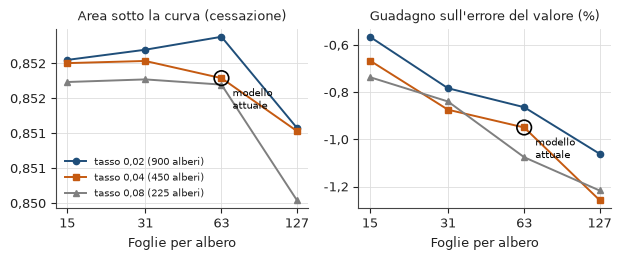

In [11]:
# %% FIGURA — sensibilità agli iperparametri (dopo la cella L-HP)
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcdefaults()
plt.style.use("default")
mpl.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#222222", "ytick.color": "#222222",
                     "text.color": "#222222"})

COL = {0.02: "#1f4e79", 0.04: "#c55a11", 0.08: "#7f7f7f"}
MARK = {0.02: "o", 0.04: "s", 0.08: "^"}
fig, axes = plt.subplots(1, 2, figsize=(16 / 2.54, 6.8 / 2.54), facecolor="white")

pannelli = [("auc", "Area sotto la curva (cessazione)", "{:.3f}"),
            ("guadagno_mae", "Guadagno sull'errore del valore (%)", "{:.1f}")]
for ax, (col, titolo, fmt) in zip(axes, pannelli):
    ax.set_facecolor("white")
    for lr in sorted(HP.lr.unique()):
        d = HP[HP.lr == lr].sort_values("foglie")
        ax.plot(d.foglie, d[col], marker=MARK[lr], ms=4.5, lw=1.4, color=COL[lr],
                label=f"tasso {str(lr).replace('.', ',')} ({int(d.alberi.iloc[0])} alberi)")
    att = HP[(HP.foglie == 63) & (HP.lr == 0.04)][col].iloc[0]
    ax.scatter([63], [att], s=110, facecolors="none", edgecolors="black", lw=1.2, zorder=5)
    ax.annotate("modello\nattuale", (63, att), xytext=(8, -22), textcoords="offset points",
                fontsize=7.5, color="black")
    ax.set_xscale("log", base=2)
    ax.set_xticks([15, 31, 63, 127]); ax.set_xticklabels(["15", "31", "63", "127"])
    ax.set_xlabel("Foglie per albero")
    ax.set_title(titolo, fontsize=9.5)
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(
        lambda v, _p, f=fmt: f.format(v).replace(".", ",")))
    ax.grid(True, color="#dddddd", lw=0.6); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

axes[0].legend(frameon=False, fontsize=7.5, loc="lower left")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_7_iperparametri.png", dpi=600, facecolor="white",
            bbox_inches="tight")
plt.show()

In [12]:
# %% CELLA L-HP-bis — stabilità per anno della griglia
R = pd.DataFrame(righe)
R["config"] = R.foglie.astype(str) + " foglie, lr " + R.lr.astype(str)

for metrica in ["auc", "guadagno_mae"]:
    T = R.pivot_table(index="config", columns="anno", values=metrica)
    T["ampiezza fra config"] = np.nan
    print(f"\n=== {metrica} per anno ===")
    print(T.drop(columns="ampiezza fra config").round(4).to_string())
    amp = T.drop(columns="ampiezza fra config").max() - T.drop(columns="ampiezza fra config").min()
    print("ampiezza fra configurazioni, per anno:", amp.round(4).to_dict())
    rk = T.drop(columns="ampiezza fra config").rank(ascending=False)
    print("rango della configurazione attuale per anno:",
          rk.loc["63 foglie, lr 0.04"].astype(int).to_dict(), "su", len(rk))


=== auc per anno ===
anno                   2007    2008    2009
config                                     
127 foglie, lr 0.02  0.8568  0.8465  0.8515
127 foglie, lr 0.04  0.8573  0.8467  0.8506
127 foglie, lr 0.08  0.8557  0.8456  0.8503
15 foglie, lr 0.02   0.8576  0.8483  0.8518
15 foglie, lr 0.04   0.8578  0.8481  0.8517
15 foglie, lr 0.08   0.8573  0.8479  0.8515
31 foglie, lr 0.02   0.8576  0.8487  0.8518
31 foglie, lr 0.04   0.8579  0.8481  0.8516
31 foglie, lr 0.08   0.8580  0.8479  0.8509
63 foglie, lr 0.02   0.8576  0.8486  0.8524
63 foglie, lr 0.04   0.8569  0.8479  0.8521
63 foglie, lr 0.08   0.8575  0.8480  0.8510
ampiezza fra configurazioni, per anno: {2007: 0.0022, 2008: 0.0031, 2009: 0.002}
rango della configurazione attuale per anno: {2007: 10, 2008: 9, 2009: 2} su 12

=== guadagno_mae per anno ===
anno                   2007    2008    2009
config                                     
127 foglie, lr 0.02  1.1538  1.0822 -5.4184
127 foglie, lr 0.04  0.8634  1.0182 -5

### 7.x.x Un controllo sui casi: il 2024

L'ultimo anno di validazione offre due casi in cui la cessazione di
relazioni rilevanti è dovuta a eventi politici: la chiusura della miniera di
rame Cobre Panamá alla fine del 2023 e il blocco delle esportazioni di uranio
del Niger dopo il colpo di Stato del luglio 2023. Il modello non dispone di
alcuna informazione su questi eventi, per cui i casi mostrano che cosa esso
può e non può cogliere.

Delle 56.461 relazioni attive nel 2023, 5.688 (10,1%) cessano nel 2024. Fra
le quaranta indicate come più a rischio ne cessano 23, quasi sei volte la
frequenza di base. Si tratta però quasi esclusivamente di legami di piccolo
valore, spesso di poco superiori alla soglia di mantenimento, nello stadio
dell'estrazione e nelle categorie più instabili individuate nel capitolo 6,
come il carbone metallurgico e lo zinco.

Le relazioni colpite dagli eventi politici sono invece di grandi dimensioni e
consolidate, e il modello le considerava a basso rischio. Dopo la sentenza
della Corte suprema panamense del 28 novembre 2023, che ha portato alla
chiusura della miniera, le esportazioni di minerale di rame di Panama verso
Bulgaria, Germania, Giappone, Corea, India e Spagna cessano tutte nel 2024,
ma si collocavano fra il 15° e il 77° percentile di rischio. Quella verso la
Cina, da 1,5 miliardi di dollari, aveva un rischio stimato dello 0,3% e
formalmente resta attiva, perché il valore del 2024 (23,5 milioni, il 98,5%
in meno) supera ancora la soglia di mantenimento: si tratta verosimilmente di
carichi spediti prima della chiusura e registrati all'arrivo. Dopo il colpo di
Stato in Niger del 26 luglio 2023, il legame con la Francia nei minerali di
uranio cessa pur trovandosi a metà della graduatoria, mentre quello nei
composti di uranio cresce nel 2024; un'ipotesi è che le dichiarazioni
francesi attribuiscano al Niger, come paese d'origine, uranio già depositato
fuori dal paese prima del blocco. Il modello misura dunque la fragilità
strutturale delle relazioni, legata alle loro dimensioni, alla loro storia e
alla posizione nella rete, e non il rischio politico, che colpisce anche
legami consolidati. Per le relazioni di maggiore rilevanza strategica questo
è il limite principale di una previsione costruita sui soli dati
commerciali.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 2023-2024.*

In [123]:
# %% CELLA L11c — i casi di validazione: backtest 2023 -> 2024
OOS = pd.read_csv(OUT_DIR / "cessazione_oos.csv")
U23 = OOS[OOS.year == 2023].copy()
U23["rango"] = U23.score_cessazione.rank(ascending=False, method="min").astype(int)
U23["percentile"] = U23.score_cessazione.rank(pct=True) * 100
print(f"legami attivi nel 2023: {len(U23):,} | cessati nel 2024: {U23.cessa.sum():,}")

casi = {"rame panamense": (U23.paese_exp == "PAN") & (U23.resource == "copper"),
        "uranio Niger -> Francia": (U23.paese_exp == "NER") & (U23.paese_imp == "FRA")
                                   & (U23.resource == "uranium")}
for nome, m in casi.items():
    print(f"\n--- {nome} ---")
    if not m.any():
        print("nessun legame attivo nel 2023")
        continue
    print(U23[m][["paese_exp", "paese_imp", "stage_name", "value", "score_cessazione",
                  "rango", "percentile", "cessa"]]
          .assign(value=lambda d: d.value / 1e3).round(3).to_string(index=False))

T40 = U23.nsmallest(40, "rango")
T40.to_csv(OUT_DIR / "cessazione_top40_2023.csv", index=False)
print(f"\nprimi 40 segnalati: {int(T40.cessa.sum())} effettivamente cessati")
print(T40[["paese_exp", "paese_imp", "resource", "stage_name", "value", "score_cessazione",
           "cessa"]].assign(value=lambda d: d.value / 1e3).round(3).to_string(index=False))

legami attivi nel 2023: 56,461 | cessati nel 2024: 5,688

--- rame panamense ---
paese_exp paese_imp stage_name    value  score_cessazione  rango  percentile  cessa
      PAN       BRA  recycling    1.239             0.272   4957      91.222      0
      PAN       BGR   upstream   98.519             0.124  12886      77.179      1
      PAN       CHN  recycling    3.949             0.014  32521      42.403      0
      PAN       CHN   upstream 1544.427             0.003  48153      14.716      0
      PAN       CRI  recycling    8.875             0.429   1060      98.124      1
      PAN       DEU  recycling    0.152             0.256   5649      89.997      0
      PAN       DEU   upstream  164.653             0.015  31921      43.465      1
      PAN       ITA  recycling    0.459             0.265   5257      90.691      1
      PAN       JPN  recycling    2.012             0.111  13878      75.422      0
      PAN       JPN   upstream  503.069             0.021  29060      48.533   

Fra le quaranta relazioni segnalate come più fragili, una parte rilevante non
nasce dalla produzione del paese esportatore. Confrontando i flussi con la
produzione mineraria del World Mining Data, 12 sono esportazioni di paesi
produttori, 4 di paesi produttori che importano almeno quanto esportano, 14
riesportazioni di paesi che importano almeno la metà di quanto esportano,
spesso piattaforme di intermediazione come Hong Kong e Singapore, e 9
provengono da paesi in cui non risulta alcuna produzione della risorsa. Le
relazioni di intermediazione cessano molto più spesso: nel 2024 si
interrompono 10 delle 14 riesportazioni (71%) e 6 dei 9 flussi senza
produzione rilevata (67%), contro 4 delle 12 esportazioni di paesi produttori
(33%). Il segnale di fragilità del modello è dunque particolarmente
affidabile per i flussi che non poggiano su una base produttiva, la cui
esistenza dipende da convenienze commerciali che possono venir meno da un
anno all'altro. Su numeri così piccoli il confronto ha valore illustrativo.

In [125]:
# %% CELLA L11d — produzione propria o riesportazione fra i legami segnalati
# Richiede WMD1 (carica_wmd) e la L11c (T40). La produzione del World Mining
# Data è la media 2019-2023, con i codici paese già riconciliati. Un paese
# produttore che importa almeno quanto esporta è classificato a parte: per
# i suoi legami la riesportazione è plausibile quanto la produzione propria.
SOGLIA_RIESP = 0.5

W = carica_wmd(verbose=False)
PROD_RS = {(r, s, int(c)): p for r, s, c, p in W[["resource", "stage_name", "code", "prod"]]
           .itertuples(index=False)}
PROD_R = W.groupby(["resource", "code"])["prod"].sum()
PROD_R = {(r, int(c)): p for (r, c), p in PROD_R.items()}
RIS_WMD = set(W.resource)

_d = DI[DI.year == 2023]
_ex = _d.groupby(["resource", "stage_name", "exp"], observed=True).value.sum().reset_index()
_im = _d.groupby(["resource", "stage_name", "imp"], observed=True).value.sum().reset_index()
EXP_23 = {(str(r), str(s), int(c)): v for r, s, c, v in _ex.itertuples(index=False)}
IMP_23 = {(str(r), str(s), int(c)): v for r, s, c, v in _im.itertuples(index=False)}


def classifica(r):
    k = (r.resource, r.stage_name, int(r.exp))
    produce = PROD_RS.get(k, 0) > 0 or PROD_R.get((r.resource, int(r.exp)), 0) > 0
    rapporto = IMP_23.get(k, 0) / max(EXP_23.get(k, 0), 1)
    if produce and rapporto >= 1:
        return "produttore, importatore netto", rapporto
    if produce:
        return "produzione propria", rapporto
    if rapporto >= SOGLIA_RIESP:
        return "riesportazione", rapporto
    if r.resource not in RIS_WMD or r.stage_name == "manufacturing":
        return "non determinabile", rapporto
    return "nessuna produzione rilevata", rapporto


T40[["origine", "import_su_export"]] = T40.apply(lambda r: pd.Series(classifica(r)), axis=1)
T40.to_csv(OUT_DIR / "cessazione_top40_2023_origine.csv", index=False)

ORD_OR = ["produzione propria", "produttore, importatore netto", "riesportazione",
          "nessuna produzione rilevata", "non determinabile"]
TAB_OR = (T40.groupby("origine").cessa.agg(legami="size", cessati="sum")
            .reindex([o for o in ORD_OR if o in set(T40.origine)]))
TAB_OR["quota_cessati"] = TAB_OR.cessati / TAB_OR.legami
TAB_OR.to_csv(OUT_DIR / "cessazione_top40_origine_sintesi.csv")
print("=== CESSAZIONE PER ORIGINE DEL FLUSSO (primi 40 segnalati) ===")
print(TAB_OR.round(3).to_string())
print("\nriesportazioni per paese esportatore:")
print(T40[T40.origine == "riesportazione"].paese_exp.value_counts().to_string())
print("\n" + T40[["paese_exp", "paese_imp", "resource", "stage_name", "origine",
                  "import_su_export", "cessa"]].round(2).to_string(index=False))

=== CESSAZIONE PER ORIGINE DEL FLUSSO (primi 40 segnalati) ===
                               legami  cessati  quota_cessati
origine                                                      
produzione propria                 12        4          0.333
produttore, importatore netto       4        2          0.500
riesportazione                     14       10          0.714
nessuna produzione rilevata         9        6          0.667
non determinabile                   1        1          1.000

riesportazioni per paese esportatore:
paese_exp
HKG    3
TWN    1
SGP    1
UZB    1
BRA    1
ROU    1
USA    1
EST    1
PER    1
SAU    1
ARM    1
AUT    1

paese_exp paese_imp                resource    stage_name                       origine  import_su_export  cessa
      TWN       CHN                 niobium manufacturing                riesportazione             30.85      1
      HKG       ISR                tungsten      refining                riesportazione              0.75      0
      

### 7.x.x Le relazioni previste per il 2025

Applicando il modello alla rete del 2024 si ottengono 423.094 coppie
candidate per il 2025: 406.649 mai attive negli ultimi cinque anni e 16.445
possibili riattivazioni. Per la previsione a un anno il commercio sotto
soglia del 2024 è osservato, per cui la graduatoria è costruita con la
specificazione che lo include, la più accurata nella validazione (area sotto
la curva ROC di 0,912 contro 0,873). Il punteggio ordina le candidate per
probabilità di formazione ma non è esso stesso una probabilità, perché il
modello è stimato su un campione in cui le coppie che non si formano sono
sottorappresentate; la calibrazione è discussa nel paragrafo successivo.

Le due specificazioni producono graduatorie molto diverse: solo due delle
prime cinquanta candidate coincidono. Tutte le prime cinquanta del modello
con commercio sotto soglia hanno già scambi al di sotto della soglia di
attivazione, e alcune occupano posizioni molto basse nella graduatoria del
modello principale. L'informazione sul commercio corrente, quindi, non si
limita a migliorare la previsione ma cambia l'identità delle relazioni
indicate come più probabili, e le singole previsioni vanno lette come
indicative.

Fra le candidate in testa ricorrono le celle per batterie, con dieci delle
prime cinquanta relazioni: fra le altre Norvegia-Benelux, Benelux-Lituania,
Canada-Svezia, Turchia-Benelux, Finlandia-Austria e Austria-Malaysia, un
segnale coerente con l'espansione della filiera delle batterie in Europa.
Compare inoltre un'esportazione di intermedi del nichel dall'Indonesia agli
Stati Uniti, già presente sotto soglia nel 2024: non riguarda il minerale,
il cui export è vietato dal 2020, ma prodotti della prima lavorazione,
coerentemente con la strategia indonesiana di valorizzazione interna della
risorsa. Il modello coglie però la struttura della rete e non i vincoli
politici: la graduatoria del modello principale comprende, per esempio, la
riattivazione delle esportazioni russe di ghisa verso gli Stati Uniti, che
dopo i dazi fino al 70% introdotti nel 2023 si sono azzerate, da oltre un
miliardo di dollari nel 2021.

La simulazione degli anni successivi impiega invece il modello principale,
perché negli anni simulati il commercio sotto soglia non è osservabile.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1999-2024.*

In [126]:
# %% [markdown]
# # Capitolo 7 — celle L8-L12bis
#
# Da eseguire dopo la cella L e la L11a del primo file. La L11 di questo file
# è completa e sostituisce la sola intestazione del primo file.
#
#   L8     candidate 2024 -> 2025 e score di formazione
#   L9     valore iniziale delle nuove relazioni
#   L10    calibrazione della formazione e del valore iniziale
#   L11    simulazione 2025-2035 (scenario centrale)
#   L12    Monte Carlo attorno allo scenario centrale
#   L12bis rete a valore atteso
#
# Rispetto alle versioni precedenti:
#  - le candidate sono costruite in forma vettoriale con la stessa funzione in
#    L8 e nella simulazione;
#  - la L11 conserva per ogni anno le probabilità di cessazione e di
#    formazione, che la L12 riusa invece di ricalcolarle: stessa traiettoria,
#    metà del tempo;
#  - il pavimento del valore dei legami esistenti è la soglia di mantenimento
#    (centomila dollari), quello dei legami nuovi la soglia di attivazione.


# %% CELLA L8 — candidate 2024 -> 2025 e score di formazione
def candidate_future_sim(hist, anno, lookback=LOOKBACK):
    """Tutte le coppie non attive nell'anno fra paesi attivi nello stesso
    mercato. Usata sulla rete osservata (L8) e su quelle simulate (L11)."""
    cur = hist[hist.year == anno]
    if cur.empty:
        return pd.DataFrame()
    past = hist[(hist.year >= anno - lookback) & (hist.year < anno)]
    storia = {k: _chiavi(g.exp.to_numpy(), g.imp.to_numpy())
              for k, g in past.groupby(["resource", "stage_name"], sort=False)}
    parti = []
    for (r, st), g in cur.groupby(["resource", "stage_name"], sort=False):
        exp_att, imp_att = np.unique(g.exp.to_numpy()), np.unique(g.imp.to_numpy())
        E, I = np.meshgrid(exp_att, imp_att, indexing="ij")
        E, I = E.ravel(), I.ravel()
        m = E != I
        E, I = E[m], I[m]
        K = _chiavi(E, I)
        cand = ~np.isin(K, _chiavi(g.exp.to_numpy(), g.imp.to_numpy()))
        if not cand.any():
            continue
        E, I, K = E[cand], I[cand], K[cand]
        visto = np.isin(K, storia.get((r, st), np.empty(0, np.int64))).astype(int)
        parti.append(pd.DataFrame({"exp": E.astype(int), "imp": I.astype(int),
                                   "resource": r, "stage_name": st, "year": anno,
                                   "visto_5a": visto}))
    if not parti:
        return pd.DataFrame()
    C = pd.concat(parti, ignore_index=True)
    C["tipo_candidata"] = np.where(C.visto_5a == 1, "riattivazione_5a", "nuova_5a")
    return C


ANNO_FORECAST, TOP_N = 2024, 50

C2025 = candidate_future_sim(FL, ANNO_FORECAST)
print(f"[FORECAST] {len(C2025):,} candidate {ANNO_FORECAST} -> {ANNO_FORECAST + 1} | "
      f"nuove {(C2025.visto_5a == 0).sum():,} | possibili riattivazioni "
      f"{(C2025.visto_5a == 1).sum():,}")
F2025 = feature_topologiche(C2025, FL, ANNO_FORECAST)

# modello principale: topologia, scala e storia, addestrato su tutti gli
# eventi 1999 -> 2000 ... 2023 -> 2024
m_2025 = nuovo_modello()
m_2025.fit(CL[FEAT_FORECAST], CL.forma)

F2025["score_formazione"] = m_2025.predict_proba(F2025[FEAT_FORECAST])[:, 1]
F2025["percentile"] = F2025.score_formazione.rank(pct=True) * 100
F2025["paese_exp"] = F2025.exp.map(lambda c: ISO.get(int(c), str(c)))
F2025["paese_imp"] = F2025.imp.map(lambda c: ISO.get(int(c), str(c)))

FORECAST_2025 = F2025.sort_values("score_formazione", ascending=False).reset_index(drop=True)
FORECAST_2025["rank"] = np.arange(1, len(FORECAST_2025) + 1)
NUOVE_2025 = FORECAST_2025[FORECAST_2025.visto_5a == 0].copy()
RIATT_2025 = FORECAST_2025[FORECAST_2025.visto_5a == 1].copy()

COL_SHOW = ["paese_exp", "paese_imp", "resource", "stage_name", "cammini_due",
            "adamic_adar", "n_risorse", "sotto_soglia", "score_formazione", "percentile"]
print(f"\nPRIME {TOP_N} NUOVE RELAZIONI PREVISTE PER IL {ANNO_FORECAST + 1}")
print(NUOVE_2025[COL_SHOW].head(TOP_N).round(4).to_string(index=False))
print(f"\nPRIME {TOP_N} RIATTIVAZIONI PREVISTE PER IL {ANNO_FORECAST + 1}")
print(RIATT_2025[COL_SHOW].head(TOP_N).round(4).to_string(index=False))

FORECAST_2025.to_csv(OUT_DIR / "previsione_formazione_2025_tutte.csv", index=False)
NUOVE_2025.head(100).to_csv(OUT_DIR / "previsione_formazione_2025_top100_nuove.csv", index=False)
RIATT_2025.head(100).to_csv(OUT_DIR / "previsione_formazione_2025_top100_riattivazioni.csv",
                            index=False)
print("\nlo score ordina le candidate; diventa probabilità solo dopo la calibrazione (L10)")

[FORECAST] 423,094 candidate 2024 -> 2025 | nuove 406,649 | possibili riattivazioni 16,445

PRIME 50 NUOVE RELAZIONI PREVISTE PER IL 2025
paese_exp paese_imp                resource    stage_name  cammini_due  adamic_adar  n_risorse  sotto_soglia  score_formazione  percentile
      DNK       CHN                  copper      refining            6       1.7766        8.0             1            0.7951    100.0000
      CHN       KIR          iron_ore_steel manufacturing            1       0.4024        2.0             1            0.7373     99.9993
      CHN       USA                 sulphur manufacturing            7       3.3543       50.0             1            0.7223     99.9981
      CHN       CHE                  sodium      refining           10       2.6243       31.0             1            0.6918     99.9962
      NOR       BLX           battery_cells manufacturing           16       3.7738       12.0             1            0.6438     99.9861
      CHN       ANT         

In [127]:
# %% CELLA L8b — graduatoria 2025 con il commercio sotto soglia
# Previsione a un anno: il commercio sotto soglia del 2024 è osservato, per cui
# le graduatorie del 2025 possono usare il modello più accurato (validazione:
# AUC 0,912 contro 0,873). La simulazione degli anni successivi resta sul
# modello principale, perché negli anni simulati tale informazione manca.
# Richiede la L8 (FORECAST_2025, TOP_N).
FEAT_2025 = FEAT_FORECAST + SOTTO
m_2025s = nuovo_modello()
m_2025s.fit(CL[FEAT_2025], CL.forma)
FORECAST_2025["score_sotto_soglia"] = m_2025s.predict_proba(FORECAST_2025[FEAT_2025])[:, 1]
FORECAST_2025["rank_sotto_soglia"] = (FORECAST_2025.score_sotto_soglia
                                      .rank(ascending=False, method="min").astype(int))
_cfr = FORECAST_2025.nsmallest(TOP_N, "rank_sotto_soglia")
print(f"PRIME {TOP_N} CON IL MODELLO A COMMERCIO SOTTO SOGLIA "
      f"(in comune con la graduatoria principale: "
      f"{int((_cfr['rank'] <= TOP_N).sum())})")
print(_cfr[["paese_exp", "paese_imp", "resource", "stage_name", "visto_5a",
            "sotto_soglia", "score_sotto_soglia", "rank"]].round(4).to_string(index=False))
FORECAST_2025.to_csv(OUT_DIR / "previsione_formazione_2025_tutte.csv", index=False)

PRIME 50 CON IL MODELLO A COMMERCIO SOTTO SOGLIA (in comune con la graduatoria principale: 2)
paese_exp paese_imp                resource    stage_name  visto_5a  sotto_soglia  score_sotto_soglia   rank
      AUS       IND                    lead      refining         1             1              0.8673      6
      BLX       JPN       aluminium-bauxite      refining         1             1              0.8382     12
      CHN       GUY                  copper manufacturing         0             1              0.8235   1329
      FRA       CHN                  sodium      refining         0             1              0.8228    424
      NOR       MYS       aluminium-bauxite      refining         0             1              0.8198    219
      NOR       BLX           battery_cells manufacturing         0             1              0.8192     60
      IDN       USA                  nickel      upstream         1             1              0.8129    659
      NIC       SLV          iron_

### 7.x.x Il valore iniziale delle nuove relazioni

Per le relazioni che si formano, un secondo modello stima il valore del
primo anno di attività, con le stesse variabili di topologia, scala e storia
e con la composizione per risorsa e stadio. Su 98.225 formazioni osservate
fra il 1999 e il 2024 il valore mediano del primo anno è di 1,86 milioni di
dollari: per costruzione le nuove relazioni partono poco al di sopra della
soglia di attivazione, e la distribuzione del loro valore iniziale è
concentrata.

Il modello migliora di poco la previsione più semplice, la mediana storica
per risorsa e stadio: l'errore assoluto medio si riduce in media del 2,4%,
con valori fra lo 0,4% e il 5,3% a seconda dell'anno, e la quota di varianza
spiegata è del 22%. Il guadagno è maggiore negli anni 2020-2022, segnati da
forti variazioni dei prezzi. Come per il valore delle relazioni esistenti, la
struttura della rete aiuta a prevedere se una relazione si forma, molto meno
quanto varrà; nella simulazione il valore iniziale delle nuove relazioni
contribuisce quindi soprattutto attraverso il loro numero e non attraverso
la precisione della stima del singolo flusso.

*Fonte: elaborazione propria su dati BACI HS92 V202601, 1999-2024.*

In [128]:
# %% CELLA L9 — valore iniziale delle nuove relazioni
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ANNI_TEST_VAL = range(2005, 2024)
FEAT_VAL = TOPO + SCALA + STORIA + CATEG_L
CAT_VAL = CATEG_L

# positive dell'anno t con il valore osservato nel primo anno di attività, t+1
_vn = (FL[["year", "exp", "imp", "resource", "stage_name", "value"]]
       .assign(year=lambda d: d.year - 1)
       .rename(columns={"value": "valore_primo_anno"}))
POSV = CL[CL.forma == 1].merge(_vn, on=["year", "exp", "imp", "resource", "stage_name"],
                               how="inner", validate="one_to_one")
POSV = POSV[POSV.valore_primo_anno > 0].copy()
POSV["log_valore_primo_anno"] = np.log1p(POSV.valore_primo_anno)
print(f"[VALORE NUOVI LEGAMI] {len(POSV):,} formazioni | valore mediano del primo anno "
      f"{POSV.valore_primo_anno.median() / 1e3:,.2f} mln $")


def nuovo_modello_valore():
    return lgb.LGBMRegressor(objective="regression", n_estimators=500, learning_rate=0.04,
                             num_leaves=63, min_child_samples=40, subsample=0.9,
                             colsample_bytree=0.9, reg_lambda=1.0, random_state=0,
                             n_jobs=-1, verbose=-1)


def baseline_valore(train, test):
    """Mediana storica del logaritmo per risorsa e stadio, poi per risorsa,
    poi globale: calcolata sui soli anni di training."""
    med_rs = train.groupby(["resource", "stage_name"]).log_valore_primo_anno.median()
    med_r = train.groupby("resource").log_valore_primo_anno.median()
    glob = train.log_valore_primo_anno.median()
    k = pd.MultiIndex.from_frame(test[["resource", "stage_name"]])
    out = pd.Series(med_rs.reindex(k).to_numpy(), index=test.index)
    out = out.fillna(test.resource.map(med_r)).fillna(glob)
    return out.to_numpy()


RIS_VAL, PRED_VAL = [], []
for ty in ANNI_TEST_VAL:
    tr, te = POSV[POSV.year < ty], POSV[POSV.year == ty]
    if tr.empty or te.empty:
        continue
    m = nuovo_modello_valore()
    m.fit(tr[FEAT_VAL], tr.log_valore_primo_anno, categorical_feature=CAT_VAL)
    p, b = m.predict(te[FEAT_VAL]), baseline_valore(tr, te)
    y = te.log_valore_primo_anno.to_numpy()
    mae, mae_b = mean_absolute_error(y, p), mean_absolute_error(y, b)
    RIS_VAL.append(dict(anno=ty, n=len(te), mae_modello=mae, mae_baseline=mae_b,
                        guadagno_mae_pct=(1 - mae / mae_b) * 100,
                        rmse_modello=np.sqrt(mean_squared_error(y, p)), r2=r2_score(y, p)))
    PRED_VAL.append(te[["year", "exp", "imp", "resource", "stage_name", "visto_5a",
                        "sotto_soglia", "valore_primo_anno"]]
                    .assign(valore_previsto=np.maximum(np.expm1(p), 0)))
    print(f"{ty} -> {ty + 1}: N {len(te):,} | MAE {mae:.4f} contro {mae_b:.4f} "
          f"({(1 - mae / mae_b) * 100:+.1f}%)")

RIS_VAL = pd.DataFrame(RIS_VAL)
PRED_VAL = pd.concat(PRED_VAL, ignore_index=True)
PRED_VAL["tipo"] = np.where(PRED_VAL.visto_5a == 1, "riattivazione_5a", "nuova_5a")
print(f"\nguadagno medio sulla mediana storica {RIS_VAL.guadagno_mae_pct.mean():+.1f}% | "
      f"R² medio {RIS_VAL.r2.mean():.3f}")

# modello finale e valore previsto per le candidate del 2025
m_val_2025 = nuovo_modello_valore()
m_val_2025.fit(POSV[FEAT_VAL], POSV.log_valore_primo_anno, categorical_feature=CAT_VAL)
F2025["valore_iniziale_previsto"] = np.maximum(np.expm1(m_val_2025.predict(F2025[FEAT_VAL])), 0)
F2025["valore_iniziale_previsto_musd"] = F2025.valore_iniziale_previsto / 1e3

IMP_VAL = pd.DataFrame({"variabile": FEAT_VAL, "importanza": m_val_2025.feature_importances_})
IMP_VAL["quota"] = IMP_VAL.importanza / IMP_VAL.importanza.sum()
IMP_VAL = IMP_VAL.sort_values("importanza", ascending=False)

RIS_VAL.to_csv(OUT_DIR / "validazione_valore_nuove_relazioni.csv", index=False)
PRED_VAL.to_csv(OUT_DIR / "backtest_valore_nuove_relazioni.csv", index=False)
IMP_VAL.to_csv(OUT_DIR / "importanza_valore_nuove_relazioni.csv", index=False)

[VALORE NUOVI LEGAMI] 98,225 formazioni | valore mediano del primo anno 1.86 mln $
2005 -> 2006: N 4,449 | MAE 0.5630 contro 0.5739 (+1.9%)
2006 -> 2007: N 5,230 | MAE 0.5740 contro 0.5776 (+0.6%)
2007 -> 2008: N 5,761 | MAE 0.6082 contro 0.6305 (+3.5%)
2008 -> 2009: N 3,443 | MAE 0.6259 contro 0.6334 (+1.2%)
2009 -> 2010: N 4,578 | MAE 0.6060 contro 0.6303 (+3.9%)
2010 -> 2011: N 5,124 | MAE 0.5961 contro 0.6088 (+2.1%)
2011 -> 2012: N 4,385 | MAE 0.6252 contro 0.6317 (+1.0%)
2012 -> 2013: N 3,892 | MAE 0.6003 contro 0.6125 (+2.0%)
2013 -> 2014: N 3,960 | MAE 0.5938 contro 0.6139 (+3.3%)
2014 -> 2015: N 3,238 | MAE 0.6129 contro 0.6193 (+1.0%)
2015 -> 2016: N 3,143 | MAE 0.6025 contro 0.6187 (+2.6%)
2016 -> 2017: N 3,996 | MAE 0.5821 contro 0.5928 (+1.8%)
2017 -> 2018: N 4,224 | MAE 0.5831 contro 0.5952 (+2.0%)
2018 -> 2019: N 3,634 | MAE 0.5961 contro 0.5983 (+0.4%)
2019 -> 2020: N 3,328 | MAE 0.5897 contro 0.6044 (+2.4%)
2020 -> 2021: N 4,870 | MAE 0.6126 contro 0.6436 (+4.8%)
2021 

### 7.x.x Calibrazione delle probabilità

**Calibrazione della formazione.** Il modello di formazione è addestrato su un campione in cui le coppie che non si formano sono sottorappresentate, per cui il suo punteggio ordina correttamente le candidate ma non è una probabilità. Per ciascun anno dal 2005 al 2023 il modello è stimato sugli anni precedenti e applicato a tutte le candidate dell'anno successivo, da circa 267.000 nel 2005 a 441.000 nel 2023; l'area sotto la curva ROC resta compresa fra 0,858 e 0,888 (in media 0,873). Sulle previsioni così ottenute il punteggio è trasformato in probabilità con una regressione isotonica, stimata separatamente per le nuove relazioni e per le riattivazioni, che hanno tassi di base molto diversi. La regressione è stimata sugli anni 2014–2023, nei quali le formazioni sono meno frequenti che nel decennio precedente e più vicine al periodo simulato: su questi anni il tasso di formazione è dello 0,70% per le nuove relazioni e dell'8,40% per le riattivazioni, contro lo 0,84% e il 9,08% sull'intero periodo 2005–2023. La calibrazione riduce il Brier score da 0,0110 a 0,0081 per le nuove relazioni e da 0,1254 a 0,0810 per le riattivazioni (Tabella A.7.6).

Anche il valore iniziale delle nuove relazioni è corretto. Il modello lo sovrastima sistematicamente: il rapporto mediano fra valore osservato e valore previsto, fuori campione, è 0,86 per le nuove relazioni e 0,87 per le riattivazioni, e le previsioni sono moltiplicate per questi fattori.

Applicata alle candidate del 2025, la calibrazione porta a 4.231 formazioni attese, di cui 2.798 nuove relazioni e 1.434 riattivazioni. È questo il punto di partenza della simulazione della §7.6.2.

In [129]:
# %% CELLA L10 — calibrazione della formazione e del valore iniziale
# Il training usa negative campionate: lo score non è una probabilità. Lo si
# calibra con una regressione isotonica sulle previsioni fuori campione,
# separatamente per nuove relazioni e riattivazioni, che hanno tassi di base
# molto diversi. La calibrazione usa gli anni dal 2014, con frequenze di
# formazione più vicine al periodo simulato; la tabella di calibrazione è
# calcolata sugli stessi anni.
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

ANNI_CAL = range(2005, 2024)
ANNO_CAL_MIN = 2014
MIN_PROB, MAX_PROB = 1e-6, 1 - 1e-6

OOS_FORM = []
for ty in ANNI_CAL:
    tr = CL[CL.year < ty]
    te0 = coppie_candidate(FL, ty, training=False, verbose=False)
    if tr.empty or te0 is None or te0.empty or te0.forma.nunique() < 2:
        continue
    te = feature_topologiche(te0, FL, ty)
    m = nuovo_modello()
    m.fit(tr[FEAT_FORECAST], tr.forma)
    s = m.predict_proba(te[FEAT_FORECAST])[:, 1]
    OOS_FORM.append(te[["year", "exp", "imp", "resource", "stage_name", "forma",
                        "visto_5a", "sotto_soglia"]].assign(score_formazione=s))
    print(f"{ty} -> {ty + 1}: N {len(te):,} | AUC {roc_auc_score(te.forma, s):.4f}")
    del te0, te, m
    gc.collect()
OOS_FORM = pd.concat(OOS_FORM, ignore_index=True)
OOS_FORM["tipo"] = np.where(OOS_FORM.visto_5a == 1, "riattivazione_5a", "nuova_5a")

CALIBRATORI_FORM = {}
for tipo, g in OOS_FORM.groupby("tipo"):
    iso = IsotonicRegression(y_min=MIN_PROB, y_max=MAX_PROB, out_of_bounds="clip")
    recente = g.year >= ANNO_CAL_MIN            # frequenze di formazione più vicine al 2025
    iso.fit(g.score_formazione[recente], g.forma[recente])
    OOS_FORM.loc[g.index, "prob_calibrata"] = iso.predict(g.score_formazione)
    CALIBRATORI_FORM[tipo] = iso
    pr = OOS_FORM.loc[g.index, "prob_calibrata"]
    print(f"{tipo:18s} 2005-2023: tasso reale {g.forma.mean():.4%} | probabilità media "
          f"{pr.mean():.4%} | Brier {brier_score_loss(g.forma, g.score_formazione):.5f} -> "
          f"{brier_score_loss(g.forma, pr):.5f}")
    print(f"{'':18s} {ANNO_CAL_MIN}-2023: tasso reale {g.forma[recente].mean():.4%} | "
          f"probabilità media {pr[recente].mean():.4%}")

# tabella di calibrazione sugli anni usati per stimare la regressione isotonica:
# sull'intero periodo le formazioni del 2005-2013, più frequenti, farebbero
# apparire sottostimate le probabilità
CAL_TABLE = []
for tipo, g in OOS_FORM[OOS_FORM.year >= ANNO_CAL_MIN].groupby("tipo"):
    g = g.assign(fascia=pd.qcut(g.score_formazione, 10, duplicates="drop"))
    CAL_TABLE.append(g.groupby("fascia", observed=True)
                      .agg(n=("forma", "size"), score_medio=("score_formazione", "mean"),
                           prob_calibrata=("prob_calibrata", "mean"),
                           frequenza_reale=("forma", "mean"))
                      .reset_index().assign(tipo=tipo))
CAL_TABLE = pd.concat(CAL_TABLE, ignore_index=True)

# correzione moltiplicativa del valore iniziale, mediana fuori campione
PRED_VAL_CAL = PRED_VAL.copy()
PRED_VAL_CAL["fattore_osservato"] = ((PRED_VAL_CAL.valore_primo_anno + 1)
                                     / (PRED_VAL_CAL.valore_previsto + 1))
BIAS_VALORE = PRED_VAL_CAL.groupby("tipo").fattore_osservato.median()
PRED_VAL_CAL["valore_previsto_calibrato"] = np.maximum(
    (PRED_VAL_CAL.valore_previsto + 1) * PRED_VAL_CAL.tipo.map(BIAS_VALORE) - 1, SOGLIA_L)
print("\ncorrezione del valore iniziale:\n" + BIAS_VALORE.round(4).to_string())

# applicazione alle candidate del 2025
F2025["tipo_candidata"] = np.where(F2025.visto_5a == 1, "riattivazione_5a", "nuova_5a")
F2025["prob_formazione"] = np.nan
for tipo, iso in CALIBRATORI_FORM.items():
    m = F2025.tipo_candidata == tipo
    F2025.loc[m, "prob_formazione"] = iso.predict(F2025.loc[m, "score_formazione"])
F2025["prob_formazione"] = F2025.prob_formazione.clip(MIN_PROB, MAX_PROB)
F2025["valore_iniziale_calibrato"] = np.maximum(
    (F2025.valore_iniziale_previsto + 1) * F2025.tipo_candidata.map(BIAS_VALORE) - 1, SOGLIA_L)
F2025["valore_atteso_2025"] = F2025.prob_formazione * F2025.valore_iniziale_calibrato

print(f"\nformazioni attese nel 2025: {F2025.prob_formazione.sum():,.0f} "
      f"(nuove {F2025.loc[F2025.tipo_candidata == 'nuova_5a', 'prob_formazione'].sum():,.0f}, "
      f"riattivazioni "
      f"{F2025.loc[F2025.tipo_candidata == 'riattivazione_5a', 'prob_formazione'].sum():,.0f})")

OOS_FORM.to_csv(OUT_DIR / "formazione_oos_calibrazione.csv", index=False)
CAL_TABLE.to_csv(OUT_DIR / "formazione_tabella_calibrazione.csv", index=False)
PRED_VAL_CAL.to_csv(OUT_DIR / "valore_nuovi_archi_oos_calibrato.csv", index=False)
F2025.to_csv(OUT_DIR / "previsione_2025_calibrata.csv", index=False)
(F2025.nlargest(50, "prob_formazione")
      .to_csv(OUT_DIR / "previsione_2025_top50_probabilita.csv", index=False))
(F2025.nlargest(50, "valore_atteso_2025")
      .to_csv(OUT_DIR / "previsione_2025_top50_valore_atteso.csv", index=False))

2005 -> 2006: N 266,886 | AUC 0.8640
2006 -> 2007: N 286,188 | AUC 0.8606
2007 -> 2008: N 322,527 | AUC 0.8580
2008 -> 2009: N 355,956 | AUC 0.8736
2009 -> 2010: N 348,525 | AUC 0.8714
2010 -> 2011: N 365,403 | AUC 0.8699
2011 -> 2012: N 398,562 | AUC 0.8720
2012 -> 2013: N 401,911 | AUC 0.8724
2013 -> 2014: N 400,475 | AUC 0.8693
2014 -> 2015: N 402,065 | AUC 0.8693
2015 -> 2016: N 394,697 | AUC 0.8809
2016 -> 2017: N 385,178 | AUC 0.8734
2017 -> 2018: N 396,740 | AUC 0.8738
2018 -> 2019: N 407,006 | AUC 0.8748
2019 -> 2020: N 410,919 | AUC 0.8818
2020 -> 2021: N 404,555 | AUC 0.8785
2021 -> 2022: N 424,963 | AUC 0.8709
2022 -> 2023: N 442,339 | AUC 0.8882
2023 -> 2024: N 441,273 | AUC 0.8873
nuova_5a           2005-2023: tasso reale 0.8401% | probabilità media 0.7264% | Brier 0.01103 -> 0.00810
                   2014-2023: tasso reale 0.7042% | probabilità media 0.7042%
riattivazione_5a   2005-2023: tasso reale 9.0837% | probabilità media 8.2660% | Brier 0.12541 -> 0.08099
         

In [8]:
# %% CELLA L10-bis — calibrazione fuori campione (holdout per anno)
# Per ogni anno di verifica y la regressione isotonica è stimata sugli anni
# 2014..y-1 e applicata all'anno y, che non ha contribuito alla stima.
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

OUT_DIR = Path(r"C:\Users\CristianSirigu\Downloads") / "OUT_BINARIO_A"
O = pd.read_csv(OUT_DIR / "formazione_oos_calibrazione.csv")
ANNO_CAL_MIN, PRIMO_TEST = 2014, 2016          # almeno due anni per la prima stima

righe = []
for tipo, g in O.groupby("tipo"):
    for y in range(PRIMO_TEST, 2024):
        tr = g[(g.year >= ANNO_CAL_MIN) & (g.year < y)]
        te = g[g.year == y]
        iso = IsotonicRegression(y_min=1e-6, y_max=1 - 1e-6, out_of_bounds="clip")
        iso.fit(tr.score_formazione, tr.forma)
        p = iso.predict(te.score_formazione)
        righe.append(dict(tipo=tipo, anno=y, n=len(te), tasso_reale=te.forma.mean(),
                          prob_media=p.mean(),
                          brier_score=brier_score_loss(te.forma, te.score_formazione),
                          brier_calibrato=brier_score_loss(te.forma, p),
                          brier_insample=brier_score_loss(te.forma, te.prob_calibrata)))
H = pd.DataFrame(righe)

print("=== PER ANNO ===")
print(H.round(5).to_string(index=False))
print("\n=== MEDIE 2016-2023 ===")
S = H.groupby("tipo")[["tasso_reale", "prob_media", "brier_score",
                       "brier_calibrato", "brier_insample"]].mean()
print(S.round(5).to_string())

=== PER ANNO ===
            tipo  anno      n  tasso_reale  prob_media  brier_score  brier_calibrato  brier_insample
        nuova_5a  2016 370000      0.00743     0.00542      0.00964          0.00721         0.00720
        nuova_5a  2017 382512      0.00776     0.00639      0.01020          0.00752         0.00751
        nuova_5a  2018 393593      0.00654     0.00716      0.00964          0.00635         0.00635
        nuova_5a  2019 397679      0.00585     0.00680      0.00892          0.00570         0.00570
        nuova_5a  2020 391192      0.00877     0.00638      0.01079          0.00846         0.00845
        nuova_5a  2021 412236      0.00986     0.00741      0.01228          0.00949         0.00948
        nuova_5a  2022 428802      0.00679     0.00790      0.01007          0.00657         0.00657
        nuova_5a  2023 426133      0.00602     0.00728      0.00910          0.00584         0.00583
riattivazione_5a  2016  15178      0.08209     0.06655      0.11539       

#### 7.6.2 Simulazione della rete 2025–2035

I modelli stimati nelle sezioni precedenti vengono applicati in sequenza, anno per anno, a partire dalla rete osservata nel 2024. A ogni passo si stima la probabilità di cessazione di ciascun legame esistente e la probabilità di formazione di ciascun legame candidato tra paesi già attivi nel mercato; le probabilità sono calibrate con regressione isotonica sul periodo 2014–2023. Il numero di cessazioni e di formazioni è posto pari alla somma delle probabilità, e vengono selezionati i legami con probabilità più alta. La rete risultante diventa la base dell'anno successivo. Questa regola trasforma le probabilità in esiti certi: i totali della rete corrispondono ai valori attesi, ma a livello di singolo paese l'esito può dipendere dalla cessazione o meno di pochi legami specifici.

La simulazione distingue due tracciati. Il primo, *stocastico*, aggiunge ai valori un errore estratto dai residui fuori campione e serve solo ad aggiornare le variabili storiche usate dal modello di cessazione (variazioni, volatilità), che altrimenti diventerebbero artificialmente piatte. Il secondo, *di riferimento*, non contiene rumore e fornisce i valori riportati nel capitolo. I legami sono divisi in tre classi di valore: sotto i 10 M$ la crescita è prevista dal modello; tra 10 e 100 M$ e sopra i 100 M$ il valore resta quello dell'anno precedente (persistenza), perché per questi legami il modello non migliora la previsione naive. Le due classi superiori si distinguono per la distribuzione degli errori utilizzata nel tracciato stocastico e nelle simulazioni Monte Carlo.

Lo scenario va letto come uno scenario sulla **struttura** della rete, non sul valore degli scambi: i legami di maggiore dimensione sono tenuti al livello nominale del 2024 e non viene introdotta alcuna ipotesi su prezzi o domanda. Restano inoltre esclusi i paesi che entrano per la prima volta nel mercato, che nel periodo storico rappresentano circa il 15% delle formazioni.

**Risultati.** Nello scenario principale il numero di legami passa da 55.048 nel 2024 a 58.792 nel 2035 (+6,8%; Figura 7.3b). Il primo anno le cessazioni (4.674, l'8,5% dei legami) superano le formazioni (4.232); dal 2026 il rapporto si inverte e la rete cresce di 400–530 legami all'anno. Le formazioni restano tra 3.640 e 4.230 l'anno e circa due terzi riguardano coppie mai attive in precedenza. Il valore complessivo di riferimento resta sostanzialmente costante (da 1.891 a 1.877 mld $; Figura 7.3a), mentre il valore medio per legame scende da 34,4 a 31,9 M$: i legami che si formano sono in media più piccoli di quelli che cessano.

Il tasso di cessazione simulato è però in media del 6,1%, contro l'8,2% osservato nel 2014–2023, e scende nel tempo dall'8,5% al 5,5%. Una possibile spiegazione, non verificata, è un effetto di selezione: i legami più fragili cessano nei primi anni, la rete residua è composta da legami più anziani e quindi più stabili, e la simulazione non contiene gli shock che hanno colpito il periodo storico. Per valutare il peso di questa ipotesi la simulazione è stata ripetuta riscalando ogni anno le probabilità di cessazione in modo che il tasso medio coincida con quello storico (Tabella A.7.8). In questo scenario le cessazioni (4.100–4.500 all'anno) superano stabilmente le formazioni e la rete scende a 49.946 legami nel 2035 (−9,3%), con un valore di riferimento di 1.811 mld $ (−4,2%).

La direzione in cui evolve il numero di legami dipende quindi dall'ipotesi sulla durata dei legami esistenti, e lo scenario non permette di stabilire se la rete si allargherà o si restringerà. Sono invece comuni ai due scenari la sostanziale stabilità del valore complessivo (tra −4% e −1%), l'aumento dell'export della Cina (+6,8 mld $ nello scenario principale, +3,8 in quello allineato) e il calo dei grandi esportatori a monte (Australia, Canada, Unione doganale dell'Africa australe e Brasile), più marcato quando le cessazioni seguono il ritmo storico (Australia −9,7 mld $, Canada −6,1).

**Struttura della rete.** Nello scenario principale l'aumento dei legami non si traduce in un allargamento della rete tra paesi (Figure 7.4a-b). Le coppie di paesi collegate da almeno un legame (corridoi) scendono da 7.138 nel 2024 a 6.664 nel 2035 (−6,6%), mentre il numero medio di legami per corridoio sale da 7,7 a 8,8: la rete si infittisce tra paesi già collegati, per risorse e stadi aggiuntivi, e perde coppie di paesi. Nel 2035 resta attivo l'84% dei corridoi del 2024; ne scompaiono 1.133 e se ne aggiungono 659. Una possibile spiegazione, non verificata, è che le variabili topologiche del modello di formazione favoriscano le coppie già collegate. La quota di paesi appartenenti alla componente fortemente connessa scende dal 91% all'84%: una quindicina di paesi resta nella rete con legami in una sola direzione. La reciprocità sale da 0,69 a 0,74, perché i corridoi che scompaiono sono in prevalenza non reciproci, e il coefficiente di clustering aumenta leggermente (da 0,78 a 0,80). La concentrazione dei valori resta invece invariata: l'indice di Herfindahl-Hirschman passa da 0,043 a 0,044 per le esportazioni e da 0,072 a 0,073 per le importazioni, e la quota dei primi cinque paesi dal 38,3% al 38,7%. La Cina aumenta la propria quota degli scambi di 0,24 punti percentuali (dal 17,1% al 17,3%); per tutti gli altri paesi le variazioni sono inferiori a 0,06 punti. Questi risultati si riferiscono allo scenario principale e non sono stati ricalcolati nello scenario con le cessazioni allineate al tasso storico.

**Corridoi e stadi.** Le variazioni tra il 2024 e il 2035 sono asimmetriche. Nel complesso i corridoi in crescita guadagnano 48,4 mld $ e quelli in calo ne perdono 62,6, ma solo 38 corridoi aumentano di almeno 100 M$, contro 101 che si riducono di almeno altrettanto (Figure 7.5a-b). Gli aumenti sono diffusi e di piccola entità: il maggiore, dalla Germania al Giappone, è di 0,19 mld $, e i corridoi in crescita partono soprattutto dalla Cina verso l'Europa (Francia, Germania, Portogallo, Slovacchia) e dalle economie industriali (Germania verso Giappone e Cina, Stati Uniti verso Turchia e Repubblica Ceca). Ciò discende dal disegno dello scenario, nel quale crescono soltanto i legami inferiori a 10 M$ e quelli che si formano. Le contrazioni maggiori derivano invece dalla cessazione di legami di dimensione intermedia o grande: le esportazioni dal Brasile alla Malesia scendono da 1,67 a 0,09 mld $, dal Canada alla Norvegia da 1,57 a 0,20 e dal Marocco al Bangladesh da 1,07 a 0,03; a esse si aggiungono riduzioni parziali di grandi corridoi nordamericani (Stati Uniti verso Messico −1,35 mld $ e verso Canada −0,99; Canada verso Stati Uniti −0,68) e delle esportazioni dell'Unione doganale dell'Africa australe verso la Cina (−0,80).

La contrazione si concentra nello stadio di estrazione (Tabella 7.12; Figure A.7.5a-d): il valore scende da 593 a 561 mld $ (−5,3%), i legami da 8.482 a 6.737 (−20,6%), i corridoi da 3.119 a 2.397 (−23%) e i paesi coinvolti da 177 a 166. La raffinazione resta stabile (+0,6% in valore, +3,8% nei legami, −4% nei corridoi). La manifattura cresce invece in tutte le dimensioni: i legami passano da 21.149 a 25.184 (+19,1%), un aumento superiore all'intero saldo della rete (+3.744 legami), e i corridoi da 4.935 a 5.305 (+7,5%), a fronte di un aumento del valore dell'1,8%. Il riciclo aumenta legami (+12,5%) e corridoi (+8,6%) ma su un numero minore di paesi (da 175 a 160), e la sua densità sale da 0,080 a 0,104. La riduzione dei corridoi osservata per la rete nel suo complesso riflette quindi soprattutto lo stadio di estrazione, mentre l'aumento dei legami è trainato dalla manifattura. Il risultato è coerente con l'analisi di sopravvivenza del capitolo 6 (§6.x.2 e §6.x.4): i legami di estrazione hanno la durata mediana più breve (3 anni, contro 4 per raffinazione e riciclo e 5 per la manifattura) e, a parità di dimensione e di storia precedente, un rischio di cessazione superiore del 18% rispetto alla manifattura. Anche questi risultati si riferiscono allo scenario principale.

Nello scenario principale le perdite relative più forti riguardano esportatori di dimensione ridotta: Armenia (−45%), Giordania e Uzbekistan (circa −28%). In Armenia e Uzbekistan cessa circa la metà dei legami attivi nel 2024, in prevalenza di dimensione intermedia; nel caso dell'Armenia si tratta soprattutto di metalli preziosi raffinati. Per questi due paesi il valore di riferimento del 2035 rientra nella banda Monte Carlo (Armenia 1,23 mld $ contro una mediana di 1,29; Uzbekistan 2,44 contro 2,78), e il calo non dipende quindi da singole cessazioni. In Giordania, invece, la perdita è dovuta in gran parte a un solo legame, l'export di fosfati verso l'India (745 M$ nel 2024, circa il 70% della perdita). La sua probabilità di cessazione resta sotto il 2% fino al 2031 e sale al 25% solo nell'ultimo anno; lungo l'intero periodo la probabilità cumulata di cessazione è di circa il 40%. La traiettoria di riferimento lo fa cessare perché nel 2034 rientra tra i legami con probabilità più alta, ma nella maggior parte delle simulazioni Monte Carlo il legame resta attivo e il valore di riferimento della Giordania (2,47 mld $) si colloca sul limite inferiore della banda p10–p90 (2,50–4,05 mld $). Le variazioni dei singoli paesi vanno quindi lette come indicazione di quali legami sono più esposti, non come previsione puntuale dell'export.

**Incertezza.** L'incertezza è stimata con 500 simulazioni Monte Carlo che estraggono gli errori dai residui fuori campione (Figure 7.3a-b). Le bande p10–p90 hanno un'ampiezza di circa 120–130 mld $ sul valore totale (circa il 6% del valore) e di 180–220 legami sul numero di archi. Le bande sono calcolate anno per anno e non cumulano l'incertezza lungo la traiettoria. Esse riflettono inoltre soltanto la componente casuale della simulazione: la differenza tra i due scenari sulle cessazioni (circa 8.800 legami nel 2035) è oltre quaranta volte l'ampiezza della banda p10–p90, e l'incertezza legata alle ipotesi del modello prevale quindi su quella stocastica.

Il livello delle simulazioni Monte Carlo (circa 2.010 mld $) è superiore a quello di riferimento perché, ritrasformando i logaritmi, la media include la correzione per la dispersione dei residui (smearing; fattori 1,33, 1,10 e 1,05 nelle tre classi); la rete attesa ricostruita con questi fattori coincide con la media Monte Carlo entro lo 0,2% (Tabella A.7.7). Nel testo si usa il valore di riferimento perché è direttamente confrontabile con il dato osservato del 2024; per lo stesso motivo i confronti tra valore di riferimento e bande Monte Carlo dei singoli paesi sono indicativi.

In [130]:
# %% CELLA L11 — simulazione dinamica della rete 2025-2035
# Traiettoria di riferimento ordinata per rischio: ogni anno cessano i legami
# con probabilità di cessazione più alta, in numero pari alla somma delle
# probabilità; si formano le candidate con probabilità più alta, in numero
# pari alla somma delle probabilità. Il 2025 è una previsione a un passo; dal
# 2026 la rete dipende da quelle simulate negli anni precedenti.
#
# Due binari per il valore dei legami:
#  - binario con volatilità ("value"): crescita attesa più uno scarto estratto
#    dagli errori fuori campione della L11a, per classe di valore. Serve solo a
#    costruire la storia dei legami da cui il modello calcola la probabilità di
#    cessazione: senza oscillazioni i legami sembrerebbero stabili e il rischio
#    sarebbe sottostimato.
#  - binario del valore atteso ("value_att"): sopra i dieci milioni di dollari
#    persistenza, perché nella validazione il modello non batte la persistenza
#    per i legami grandi; sotto, crescita prevista dal modello; i legami nuovi
#    entrano con il valore iniziale previsto. Da questo binario derivano tutti
#    i valori riportati. Gli scarti non vi si accumulano, perché in livello la
#    loro media supera l'unità e, propagati, gonfierebbero i valori.
# Limite: le candidate sono le coppie fra paesi già attivi nel mercato; i
# nuovi entranti (circa il 15% delle formazioni storiche) non sono simulati.
for x in ["FL", "m_2025", "m_val_2025", "CALIBRATORI_FORM", "BIAS_VALORE", "M_CESS",
          "CAL_CESS", "M_VAL_EXIST", "BIAS_EXIST", "GROWTH_LO", "GROWTH_HI",
          "SOGLIA_MANT", "OOS_VAL_EXIST", "P_EXIST", "feature_archi_esistenti",
          "candidate_future_sim"]:
    if x not in globals():
        raise RuntimeError(f"Manca {x}: eseguire prima L, L8-L10 e L11a.")

ANNO_BASE, ANNO_FINE = 2024, 2035
SOGLIA_IBRIDO, SOGLIA_GRANDISSIMI = 10_000, 100_000   # 10 e 100 milioni, in migliaia
SEED_SIM = 2025
RNG_SIM = np.random.default_rng(SEED_SIM)
ALLINEA_CESSAZIONE = False      # True: media delle probabilità pari a quella 2014-2023
TASSO_CESS_STORICO = P_EXIST[P_EXIST.year.between(2014, 2023)].cessa.mean()


def classe_valore(v):
    """0: sotto 10 milioni (modello); 1: 10-100 milioni; 2: oltre 100 milioni."""
    v = np.asarray(v, float)
    return np.select([v >= SOGLIA_GRANDISSIMI, v >= SOGLIA_IBRIDO], [2, 1], 0)


# errori fuori campione per classe, centrati sulla mediana e tagliati all'1%
_y = np.log1p(OOS_VAL_EXIST.value_next.to_numpy())
_cl = classe_valore(OOS_VAL_EXIST.value.to_numpy())
_err = {0: _y - OOS_VAL_EXIST.pred_log.to_numpy(), 1: _y - OOS_VAL_EXIST.lag1.to_numpy(),
        2: _y - OOS_VAL_EXIST.lag1.to_numpy()}
RES = {}
for k in (0, 1, 2):
    r = _err[k][_cl == k]
    r = r - np.median(r)
    RES[k] = np.clip(r, *np.quantile(r, [0.01, 0.99]))
print("[RESIDUI] " + " | ".join(f"classe {k}: {len(RES[k]):,} (dev. std {RES[k].std():.3f})"
                                for k in RES))


def scarti(classi, rng=RNG_SIM):
    out = np.empty(len(classi))
    for k in (0, 1, 2):
        m = classi == k
        if m.any():
            out[m] = rng.choice(RES[k], int(m.sum()))
    return out


def prevedi_formazioni(hist, anno):
    C = candidate_future_sim(hist, anno)
    if C.empty:
        return C
    C = feature_topologiche(C, hist, anno)
    C["score_formazione"] = m_2025.predict_proba(C[FEAT_FORECAST])[:, 1]
    C["prob_formazione"] = np.nan
    for tipo, iso in CALIBRATORI_FORM.items():
        m = C.tipo_candidata == tipo
        C.loc[m, "prob_formazione"] = iso.predict(C.loc[m, "score_formazione"])
    raw = np.maximum(np.expm1(m_val_2025.predict(C[FEAT_VAL])), SOGLIA_L)
    C["value_if_formed"] = np.maximum((raw + 1) * C.tipo_candidata.map(BIAS_VALORE) - 1,
                                      SOGLIA_L)
    return C


def crescita_modello(E):
    """Crescita logaritmica prevista dal modello, corretta e limitata."""
    return (np.clip(M_VAL_EXIST.predict(E[FEAT_EXIST]) - E.lag1.to_numpy(),
                    GROWTH_LO, GROWTH_HI) + np.log(BIAS_EXIST))


def seleziona_attesi(D, col_prob, col_score, per=None):
    gruppi = [(None, D)] if per is None else list(D.groupby(per))
    scelti = []
    for _, g in gruppi:
        n = min(int(np.rint(g[col_prob].sum())), len(g))
        if n > 0:
            scelti.append(g.sort_values([col_prob, col_score], ascending=False).head(n))
    return pd.concat(scelti, ignore_index=True) if scelti else D.iloc[0:0].copy()


def indicatori_paesi(rete, anno):
    ex = rete.groupby("exp").agg(export_kusd=("value", "sum"), destinazioni=("imp", "nunique"))
    im = rete.groupby("imp").agg(import_kusd=("value", "sum"), fornitori=("exp", "nunique"))
    out = ex.join(im, how="outer").fillna(0).rename_axis("code").reset_index()
    out["year"] = anno
    out["export_mld"] = out.export_kusd / 1e6
    out["import_mld"] = out.import_kusd / 1e6
    out["paese"] = out.code.map(lambda c: ISO.get(int(c), str(c)))
    return out


def hhi_importazioni(rete, anno):
    z = rete.copy()
    z["_q2"] = (z.value / z.groupby(["imp", "resource", "stage_name"]).value.transform("sum")) ** 2
    out = (z.groupby(["imp", "resource", "stage_name"], as_index=False)
             .agg(import_kusd=("value", "sum"), fornitori=("exp", "nunique"), hhi=("_q2", "sum")))
    out["year"] = anno
    out["paese"] = out.imp.map(lambda c: ISO.get(int(c), str(c)))
    return out


HIST_SIM = FL[["year", "exp", "imp", "resource", "stage_name", "value"]].copy()
RETE_2024 = HIST_SIM[HIST_SIM.year == 2024].assign(origine="osservato")
ATT = RETE_2024[KEY_EDGE + ["value"]].rename(columns={"value": "value_att"})
RETI_FUTURE = {2024: RETE_2024.assign(value_att=RETE_2024.value)}
RISCHIO_EXIST, RISCHIO_FORM = {}, {}
TRANSIZIONI = []
RIEPILOGO = [dict(anno=2024, archi=len(RETE_2024), cessazioni=np.nan, formazioni=np.nan,
                  nuove=np.nan, riattivazioni=np.nan, tasso_cessazione=np.nan,
                  valore_totale_mld=RETE_2024.value.sum() / 1e6,
                  valore_medio_musd=RETE_2024.value.mean() / 1e3,
                  valore_traiettoria_mld=RETE_2024.value.sum() / 1e6)]
PAESI_ANNUALI, HHI_ANNUALI = [indicatori_paesi(RETE_2024, 2024)], [hhi_importazioni(RETE_2024, 2024)]

for anno in range(ANNO_BASE, ANNO_FINE):
    futuro = anno + 1

    # A. legami esistenti: cessazione e valore nei due binari
    E = feature_archi_esistenti(HIST_SIM, anno)
    E = E.merge(ATT, on=KEY_EDGE, how="left")
    E["value_att"] = E.value_att.fillna(E.value)
    E["score_cessazione"] = M_CESS.predict_proba(E[FEAT_EXIST])[:, 1]
    E["prob_cessazione"] = CAL_CESS.predict(E.score_cessazione)
    if ALLINEA_CESSAZIONE:
        E["prob_cessazione"] = (E.prob_cessazione * TASSO_CESS_STORICO
                                / E.prob_cessazione.mean()).clip(upper=1.0)

    g_mod = crescita_modello(E)
    # binario con volatilità
    cl_v = classe_valore(E.value)
    g_v = np.clip(np.where(cl_v > 0, 0.0, g_mod) + scarti(cl_v), GROWTH_LO, GROWTH_HI)
    E["value_next"] = np.maximum(np.expm1(E.lag1.to_numpy() + g_v), SOGLIA_MANT)
    # binario del valore atteso
    E["classe"] = classe_valore(E.value_att)
    g_a = np.where(E.classe > 0, 0.0, g_mod)
    E["value_next_atteso"] = np.maximum(np.expm1(np.log1p(E.value_att.to_numpy()) + g_a),
                                        SOGLIA_MANT)
    RISCHIO_EXIST[anno] = E[KEY_EDGE + ["prob_cessazione", "value_next_atteso", "classe"]].copy()

    CESS = seleziona_attesi(E, "prob_cessazione", "score_cessazione")
    k_cess = set(zip(CESS.exp, CESS.imp, CESS.resource, CESS.stage_name))
    surv = [k not in k_cess for k in zip(E.exp, E.imp, E.resource, E.stage_name)]
    SURV_NEXT = (E.loc[surv, KEY_EDGE + ["value_next", "value_next_atteso"]]
                 .rename(columns={"value_next": "value", "value_next_atteso": "value_att"})
                 .assign(year=futuro, origine="sopravvissuto"))

    # B. formazioni
    CAND = prevedi_formazioni(HIST_SIM, anno)
    RISCHIO_FORM[anno] = CAND[KEY_EDGE + ["tipo_candidata", "prob_formazione",
                                         "value_if_formed"]].copy()
    FORM = seleziona_attesi(CAND, "prob_formazione", "score_formazione", per="tipo_candidata")
    FORM_NEXT = (FORM[KEY_EDGE + ["value_if_formed"]]
                 .assign(value=FORM.value_if_formed, value_att=FORM.value_if_formed,
                         year=futuro,
                         origine=np.where(FORM.tipo_candidata == "riattivazione_5a",
                                          "riattivato", "nuovo"))
                 .drop(columns="value_if_formed"))

    # C. rete del nuovo anno
    NEXT = (pd.concat([SURV_NEXT, FORM_NEXT], ignore_index=True)
              .groupby(KEY_EDGE + ["year", "origine"], as_index=False)[["value", "value_att"]].sum())
    HIST_SIM = pd.concat([HIST_SIM, NEXT[["year"] + KEY_EDGE + ["value"]]], ignore_index=True)
    ATT = NEXT.groupby(KEY_EDGE, as_index=False).value_att.sum()
    RETI_FUTURE[futuro] = NEXT
    NEXT.to_csv(OUT_DIR / f"rete_prevista_{futuro}.csv", index=False)
    RETE_ATT = NEXT.drop(columns="value").rename(columns={"value_att": "value"})

    if not CESS.empty:
        TRANSIZIONI.append(CESS[KEY_EDGE + ["prob_cessazione"]]
                           .assign(year_from=anno, year_to=futuro, evento="cessazione"))
    if not FORM.empty:
        TRANSIZIONI.append(FORM[KEY_EDGE + ["tipo_candidata", "prob_formazione",
                                            "value_if_formed"]]
                           .assign(year_from=anno, year_to=futuro, evento="formazione"))
    PAESI_ANNUALI.append(indicatori_paesi(RETE_ATT, futuro))
    HHI_ANNUALI.append(hhi_importazioni(RETE_ATT, futuro))
    n_nuove = int((FORM.tipo_candidata == "nuova_5a").sum()) if not FORM.empty else 0
    RIEPILOGO.append(dict(anno=futuro, archi=len(NEXT), cessazioni=len(CESS),
                          formazioni=len(FORM), nuove=n_nuove,
                          riattivazioni=len(FORM) - n_nuove,
                          tasso_cessazione=len(CESS) / len(E),
                          valore_totale_mld=NEXT.value_att.sum() / 1e6,
                          valore_medio_musd=NEXT.value_att.mean() / 1e3,
                          valore_traiettoria_mld=NEXT.value.sum() / 1e6))
    print(f"{anno} -> {futuro}: {len(E):,} legami | cessano {len(CESS):,} "
          f"({len(CESS) / len(E):.1%}) | si formano {len(FORM):,} ({n_nuove:,} nuove) | "
          f"rete {len(NEXT):,} legami, valore atteso {NEXT.value_att.sum() / 1e6:,.0f} mld $")
    del E, CESS, SURV_NEXT, CAND, FORM, FORM_NEXT, NEXT, RETE_ATT
    gc.collect()

RIEPILOGO = pd.DataFrame(RIEPILOGO)
PAESI_2024_2035 = pd.concat(PAESI_ANNUALI, ignore_index=True)
HHI_2024_2035 = pd.concat(HHI_ANNUALI, ignore_index=True)
TRANSIZIONI_2025_2035 = pd.concat(TRANSIZIONI, ignore_index=True) if TRANSIZIONI else pd.DataFrame()

_c = ["code", "paese", "export_mld", "import_mld", "destinazioni", "fornitori"]
CAMBIAMENTO_PAESE = (PAESI_2024_2035[PAESI_2024_2035.year == 2024][_c]
                     .merge(PAESI_2024_2035[PAESI_2024_2035.year == 2035][_c],
                            on=["code", "paese"], how="outer", suffixes=("_2024", "_2035"))
                     .fillna(0))
CAMBIAMENTO_PAESE["delta_export_mld"] = (CAMBIAMENTO_PAESE.export_mld_2035
                                         - CAMBIAMENTO_PAESE.export_mld_2024)
CAMBIAMENTO_PAESE["delta_import_mld"] = (CAMBIAMENTO_PAESE.import_mld_2035
                                         - CAMBIAMENTO_PAESE.import_mld_2024)

RIEPILOGO.to_csv(OUT_DIR / "scenario_rete_2025_2035_riepilogo.csv", index=False)
PAESI_2024_2035.to_csv(OUT_DIR / "scenario_rete_2024_2035_paesi.csv", index=False)
HHI_2024_2035.to_csv(OUT_DIR / "scenario_rete_2024_2035_hhi.csv", index=False)
TRANSIZIONI_2025_2035.to_csv(OUT_DIR / "scenario_rete_2025_2035_transizioni.csv", index=False)
CAMBIAMENTO_PAESE.to_csv(OUT_DIR / "scenario_rete_2024_2035_cambiamento_paesi.csv", index=False)

print("\n" + RIEPILOGO.round(3).to_string(index=False))
print(f"\ntasso di cessazione simulato medio {RIEPILOGO.tasso_cessazione.mean():.2%} "
      f"(storico 2014-2023: {TASSO_CESS_STORICO:.2%})"
      + (" — probabilità allineate alla media storica" if ALLINEA_CESSAZIONE else ""))
_cols = ["paese", "export_mld_2024", "export_mld_2035", "delta_export_mld"]
print("\nmaggiori aumenti dell'export 2024 -> 2035 (valore atteso):")
print(CAMBIAMENTO_PAESE.nlargest(10, "delta_export_mld")[_cols].round(2).to_string(index=False))
print("\nmaggiori diminuzioni dell'export 2024 -> 2035 (valore atteso):")
print(CAMBIAMENTO_PAESE.nsmallest(10, "delta_export_mld")[_cols].round(2).to_string(index=False))

[RESIDUI] classe 0: 496,327 (dev. std 0.798) | classe 1: 141,521 (dev. std 0.785) | classe 2: 34,075 (dev. std 0.583)
2024 -> 2025: 55,048 legami | cessano 4,674 (8.5%) | si formano 4,232 (2,798 nuove) | rete 54,606 legami, valore atteso 1,882 mld $
2025 -> 2026: 54,606 legami | cessano 3,838 (7.0%) | si formano 3,841 (2,546 nuove) | rete 54,609 legami, valore atteso 1,878 mld $
2026 -> 2027: 54,609 legami | cessano 3,506 (6.4%) | si formano 3,828 (2,429 nuove) | rete 54,931 legami, valore atteso 1,879 mld $
2027 -> 2028: 54,931 legami | cessano 3,344 (6.1%) | si formano 3,841 (2,413 nuove) | rete 55,428 legami, valore atteso 1,878 mld $
2028 -> 2029: 55,428 legami | cessano 3,257 (5.9%) | si formano 3,789 (2,404 nuove) | rete 55,960 legami, valore atteso 1,880 mld $
2029 -> 2030: 55,960 legami | cessano 3,231 (5.8%) | si formano 3,682 (2,384 nuove) | rete 56,411 legami, valore atteso 1,877 mld $
2030 -> 2031: 56,411 legami | cessano 3,190 (5.7%) | si formano 3,669 (2,355 nuove) | rete

In [131]:
# # L11r1 - copia dello scenario con cessazioni allineate al tasso storico (eseguire una volta, dopo L11 con True)
# ROB_ALLINEATO = RIEPILOGO[['anno', 'archi', 'cessazioni', 'formazioni',
#                            'tasso_cessazione', 'valore_totale_mld']].copy()
# print(ROB_ALLINEATO.to_string(index=False))

In [132]:
# # L11e - quali legami spiegano il calo di ARM, JOR, UZB (valori in M$)
# PAESI_CHK = ['ARM', 'JOR', 'UZB']
# COD_CHK = {c: p for c, p in ISO.items() if p in PAESI_CHK}   # codice numerico -> sigla
#
# B24 = HIST_SIM.loc[HIST_SIM.year == ANNO_BASE, KEY_EDGE + ['value']].rename(columns={'value': 'v2024'})
# F35 = ATT[KEY_EDGE + ['value_att']].rename(columns={'value_att': 'v2035'})
# CHK = B24.merge(F35, on=KEY_EDGE, how='outer', indicator=True)
# CHK = CHK[CHK.exp.astype(int).isin(COD_CHK)].copy()
# CHK['paese'] = CHK.exp.astype(int).map(COD_CHK)
# CHK['partner'] = CHK.imp.astype(int).map(ISO)
# CHK[['v2024', 'v2035']] = CHK[['v2024', 'v2035']].fillna(0) / 1_000
# CHK['esito'] = CHK['_merge'].astype(str).map({'left_only': 'cessato', 'right_only': 'nuovo', 'both': 'attivo'})
#
# COL_OUT = ['partner', 'resource', 'stage_name', 'v2024']
# for p in PAESI_CHK:
#     d = CHK[CHK.paese == p]
#     tot = d.v2024.sum()
#     print(f"\n=== {p}: export 2024 {tot:,.0f} M$ -> 2035 {d.v2035.sum():,.0f} M$ | "
#           f"legami 2024 {(d.v2024 > 0).sum()} | primo legame = {d.v2024.max() / tot:.0%} del totale")
#     print(d.groupby('esito', observed=True)[['v2024', 'v2035']].agg(['count', 'sum']).round(1).to_string())
#     print('principali legami cessati:')
#     print(d[d.esito == 'cessato'].nlargest(5, 'v2024')[COL_OUT].round(1).to_string(index=False))

In [133]:
# %% CELLA L12 — Monte Carlo attorno alla traiettoria di riferimento
# Per ogni anno ciascun legame esistente cessa con la sua probabilità, ciascuna
# candidata si forma con la sua, e i valori ricevono un errore estratto dai
# residui fuori campione della classe di valore corrispondente, applicato al
# valore atteso della L11. Le probabilità sono quelle calcolate dalla L11
# lungo la traiettoria di riferimento e le estrazioni non si propagano da un
# anno all'altro: le bande misurano l'incertezza di ciascun anno attorno a
# quella traiettoria e sottostimano l'incertezza complessiva.
N_SIM, SEED_MC = 500, 20260920
Q_LOW, Q_MED, Q_HIGH = 0.10, 0.50, 0.90
rng_mc = np.random.default_rng(SEED_MC)

for x in ["RISCHIO_EXIST", "RISCHIO_FORM", "RES", "PRED_VAL_CAL", "RIEPILOGO",
          "PAESI_2024_2035"]:
    if x not in globals():
        raise RuntimeError(f"Manca {x}: eseguire prima L10, L11a e L11.")

# residui del valore iniziale delle nuove relazioni, tagliati all'1% per lato
_rn = np.log1p(PRED_VAL_CAL.valore_primo_anno) - np.log1p(PRED_VAL_CAL.valore_previsto_calibrato)
RESID_NEW_POOL = {t: _rn[PRED_VAL_CAL.tipo == t]
                  .clip(_rn[PRED_VAL_CAL.tipo == t].quantile(0.01),
                        _rn[PRED_VAL_CAL.tipo == t].quantile(0.99)).dropna().to_numpy()
                  for t in ["nuova_5a", "riattivazione_5a"]}

ANNI_MC = list(range(2024, 2035))
YEARS_MC = np.array([a + 1 for a in ANNI_MC])
COUNTRY_CODES = np.sort(pd.unique(pd.concat(
    [pd.concat([RISCHIO_EXIST[a].exp, RISCHIO_EXIST[a].imp,
                RISCHIO_FORM[a].exp, RISCHIO_FORM[a].imp]) for a in ANNI_MC]).astype(int)))
POS_C = {int(c): i for i, c in enumerate(COUNTRY_CODES)}
N_C = len(COUNTRY_CODES)
_idx = lambda s: np.fromiter((POS_C[int(x)] for x in s), dtype=np.int32, count=len(s))

MC_DATA = {a: dict(E_exp=_idx(RISCHIO_EXIST[a].exp), E_imp=_idx(RISCHIO_EXIST[a].imp),
                   E_p=RISCHIO_EXIST[a].prob_cessazione.to_numpy(float),
                   E_v=RISCHIO_EXIST[a].value_next_atteso.to_numpy(float),
                   E_c=RISCHIO_EXIST[a].classe.to_numpy(int),
                   C_exp=_idx(RISCHIO_FORM[a].exp), C_imp=_idx(RISCHIO_FORM[a].imp),
                   C_p=RISCHIO_FORM[a].prob_formazione.to_numpy(float),
                   C_v=RISCHIO_FORM[a].value_if_formed.to_numpy(float),
                   C_t=RISCHIO_FORM[a].tipo_candidata.to_numpy())
           for a in ANNI_MC}

MC_ARCHI = np.zeros((N_SIM, len(ANNI_MC)), dtype=np.int32)
MC_VALORE = np.zeros((N_SIM, len(ANNI_MC)))
MC_EXPORT = np.zeros((N_SIM, len(ANNI_MC), N_C))
MC_IMPORT = np.zeros((N_SIM, len(ANNI_MC), N_C))

for s in range(N_SIM):
    for j, a in enumerate(ANNI_MC):
        d = MC_DATA[a]
        sopr = rng_mc.random(len(d["E_p"])) >= d["E_p"]
        v_e = np.maximum(np.expm1(np.log1p(d["E_v"][sopr]) + scarti(d["E_c"][sopr], rng_mc)),
                         SOGLIA_MANT)
        form = rng_mc.random(len(d["C_p"])) < d["C_p"]
        v_f = np.empty(int(form.sum()))
        tipi = d["C_t"][form]
        base_f = d["C_v"][form]
        for t in ("nuova_5a", "riattivazione_5a"):
            m = tipi == t
            if m.any():
                v_f[m] = np.maximum(np.expm1(np.log1p(base_f[m])
                                             + rng_mc.choice(RESID_NEW_POOL[t], size=int(m.sum()))),
                                    SOGLIA_L)
        MC_ARCHI[s, j] = int(sopr.sum()) + int(form.sum())
        MC_VALORE[s, j] = v_e.sum() + v_f.sum()
        MC_EXPORT[s, j] = (np.bincount(d["E_exp"][sopr], v_e, N_C)
                           + np.bincount(d["C_exp"][form], v_f, N_C))
        MC_IMPORT[s, j] = (np.bincount(d["E_imp"][sopr], v_e, N_C)
                           + np.bincount(d["C_imp"][form], v_f, N_C))
    if (s + 1) % 50 == 0:
        print(f"simulazioni completate: {s + 1}/{N_SIM}")

MC_RETE = pd.DataFrame({"anno": YEARS_MC,
                        **{f"archi_p{int(q * 100)}": np.quantile(MC_ARCHI, q, axis=0)
                           for q in (Q_LOW, Q_MED, Q_HIGH)},
                        **{f"valore_p{int(q * 100)}_mld": np.quantile(MC_VALORE, q, axis=0) / 1e6
                           for q in (Q_LOW, Q_MED, Q_HIGH)}})
MC_RETE = MC_RETE.merge(RIEPILOGO[["anno", "archi", "valore_totale_mld"]]
                        .rename(columns={"archi": "archi_riferimento",
                                         "valore_totale_mld": "valore_riferimento_mld"}),
                        on="anno", how="left")
MC_RETE["ampiezza80_valore_mld"] = MC_RETE.valore_p90_mld - MC_RETE.valore_p10_mld
MC_RETE["ampiezza80_archi"] = MC_RETE.archi_p90 - MC_RETE.archi_p10

_q = {q: (np.quantile(MC_EXPORT, q, axis=0), np.quantile(MC_IMPORT, q, axis=0))
      for q in (Q_LOW, Q_MED, Q_HIGH)}
MC_PAESI = pd.DataFrame([
    dict(anno=int(y), code=int(c), paese=ISO.get(int(c), str(c)),
         **{f"export_p{int(q * 100)}_mld": _q[q][0][j, k] / 1e6 for q in _q},
         **{f"import_p{int(q * 100)}_mld": _q[q][1][j, k] / 1e6 for q in _q})
    for j, y in enumerate(YEARS_MC) for k, c in enumerate(COUNTRY_CODES)])
MC_PAESI = MC_PAESI.merge(
    PAESI_2024_2035[PAESI_2024_2035.year >= 2025][["year", "code", "export_mld", "import_mld"]]
    .rename(columns={"year": "anno", "export_mld": "export_riferimento_mld",
                     "import_mld": "import_riferimento_mld"}),
    on=["anno", "code"], how="left").fillna({"export_riferimento_mld": 0,
                                             "import_riferimento_mld": 0})

MC_RETE.to_csv(OUT_DIR / "scenario_mc_2025_2035_rete.csv", index=False)
MC_PAESI.to_csv(OUT_DIR / "scenario_mc_2025_2035_paesi.csv", index=False)
MC_PAESI[MC_PAESI.anno == 2035].to_csv(OUT_DIR / "scenario_mc_2035_paesi.csv", index=False)
print("\n" + MC_RETE.round(2).to_string(index=False))

simulazioni completate: 50/500
simulazioni completate: 100/500
simulazioni completate: 150/500
simulazioni completate: 200/500
simulazioni completate: 250/500
simulazioni completate: 300/500
simulazioni completate: 350/500
simulazioni completate: 400/500
simulazioni completate: 450/500
simulazioni completate: 500/500

 anno  archi_p10  archi_p50  archi_p90  valore_p10_mld  valore_p50_mld  valore_p90_mld  archi_riferimento  valore_riferimento_mld  ampiezza80_valore_mld  ampiezza80_archi
 2025    54501.5    54614.0    54717.1         1964.70         2019.27         2088.51              54606                 1881.79                 123.82             215.6
 2026    54510.9    54602.5    54720.0         1959.89         2015.05         2082.64              54609                 1877.98                 122.76             209.1
 2027    54837.9    54934.0    55040.1         1957.27         2013.19         2079.10              54931                 1878.72                 121.83             20

In [134]:
# %% CELLA L12bis — rete a valore atteso 2025-2035
# Per ogni legame: probabilità di presenza per valore atteso se presente. Il
# ritorno dalla scala logaritmica introduce una distorsione, corretta con il
# fattore di smearing ricavato dai residui fuori campione, per classe di
# valore. Adatta a valori e quote; non alla topologia, perché ogni candidata
# con probabilità positiva vi entra con peso positivo.
SMEAR_EXIST = {k: np.mean(np.exp(r)) for k, r in RES.items()}
SMEAR_NEW = {t: np.mean(np.exp(r)) for t, r in RESID_NEW_POOL.items()}
print("smearing: " + " | ".join(f"classe {k} {v:.4f}" for k, v in SMEAR_EXIST.items())
      + " | " + " | ".join(f"{t} {v:.4f}" for t, v in SMEAR_NEW.items()))

RETI_ATTESE, RIEPILOGO_ATTESO = {}, []
for anno in ANNI_MC:
    futuro = anno + 1
    E = RISCHIO_EXIST[anno].assign(prob_presenza=lambda d: 1 - d.prob_cessazione)
    E["value_condizionato"] = np.maximum(
        (E.value_next_atteso + 1) * E.classe.map(SMEAR_EXIST) - 1, 0)
    C = RISCHIO_FORM[anno].rename(columns={"prob_formazione": "prob_presenza"})
    C["value_condizionato"] = np.maximum(
        (C.value_if_formed + 1) * C.tipo_candidata.map(SMEAR_NEW) - 1, 0)
    RETE = pd.concat([E[KEY_EDGE + ["prob_presenza", "value_condizionato"]]
                      .assign(tipo_arco="esistente"),
                      C[KEY_EDGE + ["prob_presenza", "value_condizionato"]]
                      .assign(tipo_arco=C.tipo_candidata.to_numpy())], ignore_index=True)
    RETE["value_atteso"] = RETE.prob_presenza * RETE.value_condizionato
    RETE["year"] = futuro
    RETI_ATTESE[futuro] = RETE
    RETE.to_csv(OUT_DIR / f"rete_attesa_{futuro}.csv", index=False)
    RIEPILOGO_ATTESO.append(dict(anno=futuro, archi_attesi=RETE.prob_presenza.sum(),
                                 valore_atteso_mld=RETE.value_atteso.sum() / 1e6,
                                 cessazioni_attese=E.prob_cessazione.sum(),
                                 formazioni_attese=C.prob_presenza.sum()))
RIEPILOGO_ATTESO = pd.DataFrame(RIEPILOGO_ATTESO)
CHECK_ATTESO = RIEPILOGO_ATTESO.assign(
    archi_mc_media=MC_ARCHI.mean(axis=0), valore_mc_media_mld=MC_VALORE.mean(axis=0) / 1e6)
CHECK_ATTESO["diff_valore_pct"] = (CHECK_ATTESO.valore_atteso_mld
                                   / CHECK_ATTESO.valore_mc_media_mld - 1) * 100

PAESI_ATTESI = []
for anno, R in RETI_ATTESE.items():
    P = (R.groupby("exp").value_atteso.sum().rename("export_atteso")
         .to_frame().join(R.groupby("imp").value_atteso.sum().rename("import_atteso"), how="outer")
         .fillna(0).rename_axis("code").reset_index())
    P["year"] = anno
    P["paese"] = P.code.map(lambda c: ISO.get(int(c), str(c)))
    P["export_atteso_mld"] = P.export_atteso / 1e6
    P["import_atteso_mld"] = P.import_atteso / 1e6
    P["quota_export_attesa"] = P.export_atteso / P.export_atteso.sum()
    P["quota_import_attesa"] = P.import_atteso / P.import_atteso.sum()
    PAESI_ATTESI.append(P.drop(columns=["export_atteso", "import_atteso"]))
PAESI_ATTESI = pd.concat(PAESI_ATTESI, ignore_index=True)

RIEPILOGO_ATTESO.to_csv(OUT_DIR / "scenario_2025_2035_rete_attesa.csv", index=False)
CHECK_ATTESO.to_csv(OUT_DIR / "scenario_2025_2035_rete_attesa_check_mc.csv", index=False)
PAESI_ATTESI.to_csv(OUT_DIR / "scenario_2025_2035_paesi_attesi.csv", index=False)
print("\nrete attesa contro media Monte Carlo:")
print(CHECK_ATTESO[["anno", "archi_attesi", "archi_mc_media", "valore_atteso_mld",
                    "valore_mc_media_mld", "diff_valore_pct"]].round(2).to_string(index=False))

smearing: classe 0 1.3296 | classe 1 1.1032 | classe 2 1.0547 | nuova_5a 1.6953 | riattivazione_5a 2.0203

rete attesa contro media Monte Carlo:
 anno  archi_attesi  archi_mc_media  valore_atteso_mld  valore_mc_media_mld  diff_valore_pct
 2025      54605.49        54612.36            2021.70              2022.67            -0.05
 2026      54608.47        54609.28            2017.98              2019.17            -0.06
 2027      54930.84        54934.16            2016.66              2015.57             0.05
 2028      55427.98        55430.64            2018.26              2019.56            -0.06
 2029      55960.14        55960.13            2018.92              2019.19            -0.01
 2030      56410.62        56410.56            2017.69              2015.92             0.09
 2031      56890.45        56892.84            2015.63              2018.84            -0.16
 2032      57333.26        57335.15            2014.95              2017.46            -0.12
 2033      57789.6

In [135]:
# # L11r2 - confronto scenario principale vs cessazioni allineate
# COLS = ['anno', 'archi', 'cessazioni', 'formazioni', 'tasso_cessazione', 'valore_totale_mld']
# CONFRONTO_CESS = RIEPILOGO[COLS].merge(ROB_ALLINEATO, on='anno',
#                                        suffixes=('_principale', '_allineato'))
# print(CONFRONTO_CESS.to_string(index=False))
#
# r35 = CONFRONTO_CESS[CONFRONTO_CESS.anno == ANNO_FINE].iloc[0]
# print(f"\n2035 - legami: {r35.archi_principale:,.0f} (principale) vs {r35.archi_allineato:,.0f} (allineato)"
#       f" | valore atteso: {r35.valore_totale_mld_principale:,.0f} vs {r35.valore_totale_mld_allineato:,.0f} mld $")

In [136]:
# CONFRONTO_CESS.to_csv(OUT_DIR / "scenario_robustezza_cessazione.csv", index=False)

In [137]:
# %% [markdown]
# # Capitolo 7 — figure e tabelle dello scenario 2025-2035
#
# Ordine: G7.0 → G7.1 → G7.3 → G7.4 → G7.5 → G7.6 → G7.8.
#
# Prerequisiti: FL e ISO (celle 0-11), shared_layout, separate, igraph_layout
# (R3), disegna_rete e _mig (G0), figura (F1), tabella (T1), LBL_ST (F1); i
# file prodotti da L11, L12, L12bis e L11r2 (scenario_robustezza_cessazione.csv).
# G7.6 usa posizioni_delta, definita in G7.5.
#
# Le figure usano la rete discreta dello scenario principale con i valori della
# traiettoria di riferimento (value_att). La rete attesa della L12bis serve solo
# come controllo (G7.4) e in appendice (Tab. A.7.7).
#
# Numerazione:
#   Fig. 7.3a-b    bande della simulazione (valore e numero di legami)
#   Fig. 7.4a-b    la rete nel 2024 e nel 2035
#   Fig. 7.5a-b    corridoi in maggiore aumento e contrazione
#   Tab. 7.12      struttura delle reti per stadio
#   Fig. A.7.5a-d  variazioni per stadio (appendice)

In [138]:
# %% CELLA G7.0 — reti dello scenario: caricamento comune
# Il 2024 è la rete dei legami attivi (FL), la stessa da cui parte la
# simulazione: con la soglia unica a un milione il confronto 2024-2025
# mostrerebbe un salto artificiale, perché i legami fra centomila e un milione
# ci sono nel punto di partenza della simulazione ma non nella figura.
# Le reti 2025-2035 usano il tracciato di riferimento della L11 (value_att),
# non il tracciato stocastico, che serve solo ad aggiornare le variabili del
# modello di cessazione.
KEY_RS = ["exp", "imp", "resource", "stage_name"]
ANNI_SCEN = [2024, 2025, 2030, 2035]
LETTERA_ANNO = dict(zip(ANNI_SCEN, "abcd"))
LETTERA_ST = dict(zip(STAGES, "abcd"))


def rete_osservata_2024():
    return FL[FL.year == 2024].groupby(KEY_RS, as_index=False).value.sum()


def rete_prevista(anno):
    """Rete discreta dello scenario principale (L11), valori del tracciato di
    riferimento: un legame c'è o non c'è."""
    d = pd.read_csv(OUT_DIR / f"rete_prevista_{anno}.csv")
    return (d.groupby(KEY_RS, as_index=False).value_att.sum()
             .rename(columns={"value_att": "value"}))


def rete_attesa(anno):
    """Rete a valore atteso (L12bis): probabilità di presenza per valore
    condizionato. Adatta ai valori, non alla topologia: ogni candidata con
    probabilità positiva vi compare con un peso positivo. Il livello include
    lo smearing e non è confrontabile con il 2024 osservato."""
    d = pd.read_csv(OUT_DIR / f"rete_attesa_{anno}.csv")
    return (d.groupby(KEY_RS, as_index=False).value_atteso.sum()
             .rename(columns={"value_atteso": "value"}))


RS_DISCRETA = {2024: rete_osservata_2024(), **{a: rete_prevista(a) for a in ANNI_SCEN[1:]}}
RS_ATTESA = {a: rete_attesa(a) for a in ANNI_SCEN[1:]}      # senza 2024: livello diverso


def paesi_iso(d, stadio=None):
    """Da esportatore-importatore-risorsa-stadio a corridoio paese-paese."""
    if stadio is not None:
        d = d[d.stage_name == stadio]
    z = d.groupby(["exp", "imp"], as_index=False).value.sum()
    z = z[z.value > 0].copy()
    z["exp_iso"] = z.exp.map(lambda c: ISO.get(int(c), str(int(c))))
    z["imp_iso"] = z.imp.map(lambda c: ISO.get(int(c), str(int(c))))
    return z[z.exp_iso != z.imp_iso]


def grafo_iso(d, stadio=None):
    G = nx.DiGraph()
    for a, b, v in paesi_iso(d, stadio)[["exp_iso", "imp_iso", "value"]].itertuples(index=False):
        if G.has_edge(a, b):
            G[a][b]["value"] += float(v)
        else:
            G.add_edge(a, b, value=float(v))
    return G


def forza(K):
    return {n: sum(d["value"] for _, _, d in K.out_edges(n, data=True))
            + sum(d["value"] for _, _, d in K.in_edges(n, data=True)) for n in K}


def layout_e_dimensioni(grafi, larghezza, altezza, coverage=0.95, base=110,
                        size_max=3000, pad=1.32):
    """Coordinate comuni a tutti i grafi e scala dimensionale unica: un nodo
    della stessa dimensione rappresenta lo stesso volume di scambi in ogni
    pannello. La separazione usa, per ciascun paese, la dimensione massima che
    raggiunge nei pannelli, così che nessuna coppia si sovrapponga."""
    pos, keep, _ = shared_layout(list(grafi.values()), coverage=coverage, seed=42,
                                 pad=pad, size_max=size_max, base=base, algo="drl",
                                 larghezza=larghezza, altezza=altezza)
    keep = set(keep)
    sub = {k: G.subgraph([n for n in keep if n in G]).copy() for k, G in grafi.items()}
    fz = {k: forza(K) for k, K in sub.items()}
    tutti = np.log1p(np.array([v for f in fz.values() for v in f.values()], float))
    lo, hi = tutti.min(), tutti.max()

    def dim(v):
        return base + np.clip((np.log1p(v) - lo) / (hi - lo + 1e-9), 0, 1) ** 1.4 * size_max

    sizes = {k: {n: dim(v) for n, v in f.items()} for k, f in fz.items()}
    nodi = list(pos)
    inviluppo = np.array([max(sizes[k].get(n, base) for k in grafi) for n in nodi])
    pos = separate(pos, nodi, inviluppo, larghezza_pollici=larghezza,
                   altezza_pollici=altezza, pad=pad)
    return pos, sub, sizes


# controllo: la rete discreta deve riprodurre legami e valore della L11
RIF = RIEPILOGO.set_index("anno")
for a in ANNI_SCEN:
    n, v = len(RS_DISCRETA[a]), RS_DISCRETA[a].value.sum() / 1e6
    print(f"{a}: {n:,} legami ({RIF.loc[a, 'archi']:,} in L11) | "
          f"{v:,.0f} mld $ ({RIF.loc[a, 'valore_totale_mld']:,.0f} in L11)"
          + (f" | rete attesa {RS_ATTESA[a].value.sum() / 1e6:,.0f} mld $" if a in RS_ATTESA else ""))

2024: 55,048 legami (55,048 in L11) | 1,891 mld $ (1,891 in L11)
2025: 54,606 legami (54,606 in L11) | 1,882 mld $ (1,882 in L11) | rete attesa 2,022 mld $
2030: 56,411 legami (56,411 in L11) | 1,877 mld $ (1,877 in L11) | rete attesa 2,018 mld $
2035: 58,792 legami (58,792 in L11) | 1,877 mld $ (1,877 in L11) | rete attesa 2,014 mld $


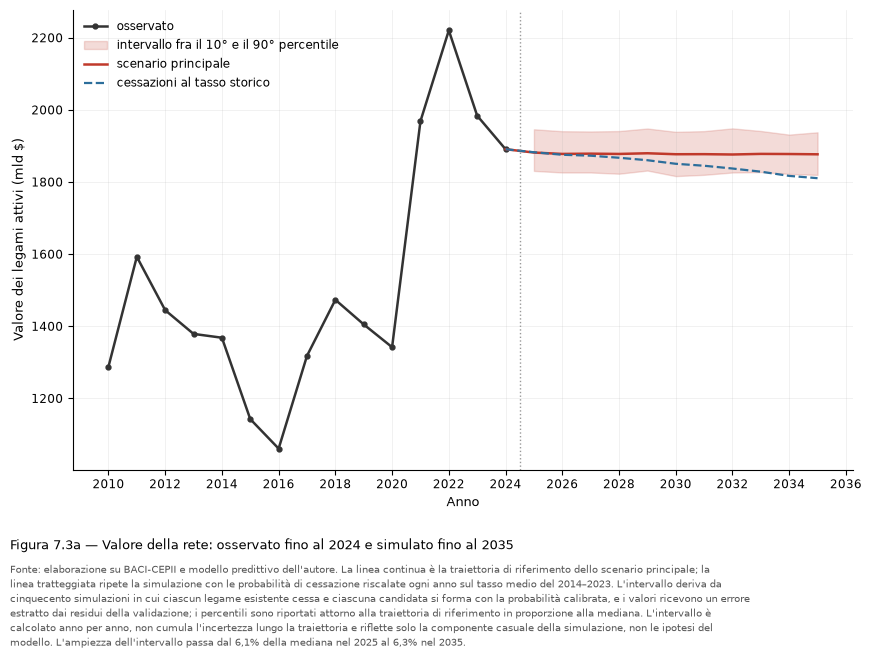

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_7_3a_bande_valore.png


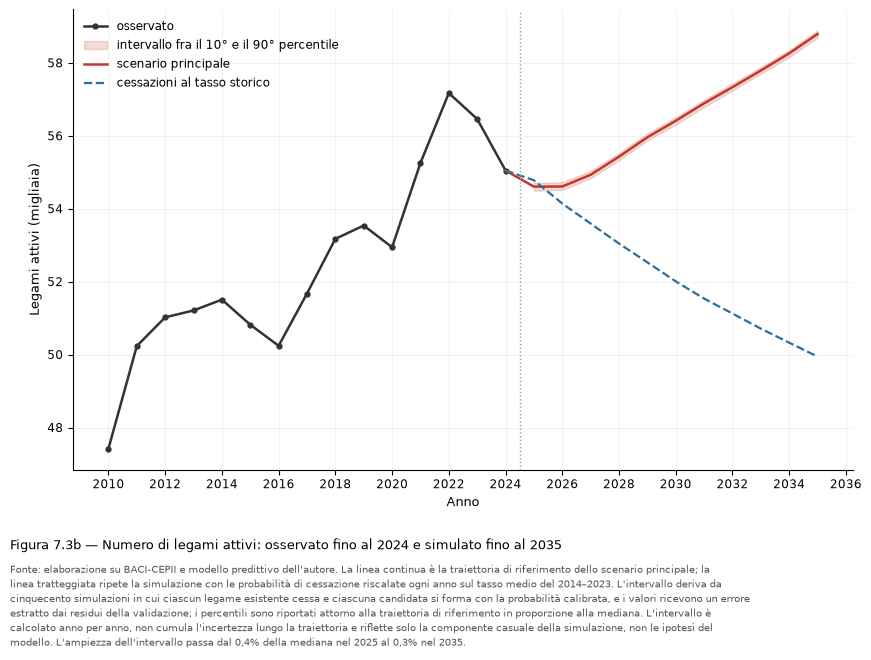

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_7_3b_bande_legami.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_7_3b_bande_legami.png')

In [139]:
# %% CELLA G7.1 — Figure 7.3a-b: le bande della simulazione
# La linea dello scenario è la traiettoria di riferimento della L11, collegata
# al dato osservato del 2024. Le bande riportano attorno a essa i percentili
# delle simulazioni Monte Carlo in proporzione alla mediana: il livello delle
# simulazioni include lo smearing e, disegnato accanto al 2024 osservato,
# mostrerebbe un salto artificiale di circa il 6% nel 2025.
MCR = pd.read_csv(OUT_DIR / "scenario_mc_2025_2035_rete.csv")
for v, (c10, c50, c90, rif) in {
        "valore_mld": ("valore_p10_mld", "valore_p50_mld", "valore_p90_mld", "valore_riferimento_mld"),
        "archi": ("archi_p10", "archi_p50", "archi_p90", "archi_riferimento")}.items():
    MCR[f"{v}_lo"] = MCR[rif] * MCR[c10] / MCR[c50]
    MCR[f"{v}_hi"] = MCR[rif] * MCR[c90] / MCR[c50]

STO = (FL[FL.year >= 2010].groupby(["year"] + KEY_RS, as_index=False).value.sum()
       .groupby("year").agg(archi=("value", "size"), valore=("value", "sum")).reset_index())
STO["valore_mld"] = STO.valore / 1e6

_b24 = STO[STO.year == 2024].iloc[0]
RIF_LINEA = pd.concat([pd.DataFrame({"anno": [2024], "archi": [_b24.archi],
                                     "valore_mld": [_b24.valore_mld]}),
                       pd.DataFrame({"anno": MCR.anno, "archi": MCR.archi_riferimento,
                                     "valore_mld": MCR.valore_riferimento_mld})],
                      ignore_index=True)

_p_all = OUT_DIR / "scenario_robustezza_cessazione.csv"
ALL_CESS = (pd.read_csv(_p_all).rename(columns={"archi_allineato": "archi",
                                                "valore_totale_mld_allineato": "valore_mld"})
            if _p_all.exists() else None)
if ALL_CESS is None:
    print("scenario_robustezza_cessazione.csv non trovato: la linea dello scenario allineato non viene disegnata")


def _f_mc(col, ylab, scala=1.0):
    def _f(ax):
        ax.plot(STO.year, STO[col] / scala, "o-", color="#333333", lw=1.8, ms=3.5,
                label="osservato")
        ax.fill_between(MCR.anno, MCR[f"{col}_lo"] / scala, MCR[f"{col}_hi"] / scala,
                        color="#c0392b", alpha=0.18,
                        label="intervallo fra il 10° e il 90° percentile")
        ax.plot(RIF_LINEA.anno, RIF_LINEA[col] / scala, "-", color="#c0392b", lw=1.8,
                label="scenario principale")
        if ALL_CESS is not None:
            ax.plot(ALL_CESS.anno, ALL_CESS[col] / scala, "--", color="#2c6e9b", lw=1.6,
                    label="cessazioni al tasso storico")
        ax.axvline(2024.5, color="#999999", ls=":", lw=1)
        ax.xaxis.set_major_locator(mtick.MultipleLocator(2))
        ax.set_xlabel("Anno", fontsize=9)
        ax.set_ylabel(ylab, fontsize=9)
        ax.legend(frameon=False, fontsize=8.5, loc="upper left")
    return _f


_amp = lambda c10, c50, c90, a: ((MCR.loc[MCR.anno == a, c90] - MCR.loc[MCR.anno == a, c10])
                                 / MCR.loc[MCR.anno == a, c50]).iloc[0] * 100
_nota_mc = ("Fonte: elaborazione su BACI-CEPII e modello predittivo dell'autore. "
            "La linea continua è la traiettoria di riferimento dello scenario principale; "
            "la linea tratteggiata ripete la simulazione con le probabilità di cessazione "
            "riscalate ogni anno sul tasso medio del 2014–2023. L'intervallo deriva da "
            "cinquecento simulazioni in cui ciascun legame esistente cessa e ciascuna "
            "candidata si forma con la probabilità calibrata, e i valori ricevono un errore "
            "estratto dai residui della validazione; i percentili sono riportati attorno "
            "alla traiettoria di riferimento in proporzione alla mediana. L'intervallo è "
            "calcolato anno per anno, non cumula l'incertezza lungo la traiettoria e "
            "riflette solo la componente casuale della simulazione, non le ipotesi del "
            "modello. ")

figura(_f_mc("valore_mld", "Valore dei legami attivi (mld $)"),
       altezza=4.6,
       didascalia="Figura 7.3a — Valore della rete: osservato fino al 2024 e "
                  "simulato fino al 2035",
       nota=_nota_mc + f"L'ampiezza dell'intervallo passa dal "
            f"{_n(_amp('valore_p10_mld', 'valore_p50_mld', 'valore_p90_mld', 2025), 1)}% "
            f"della mediana nel 2025 al "
            f"{_n(_amp('valore_p10_mld', 'valore_p50_mld', 'valore_p90_mld', 2035), 1)}% "
            f"nel 2035.",
       out=FIG_DIR / "fig_7_3a_bande_valore.png")

figura(_f_mc("archi", "Legami attivi (migliaia)", scala=1000),
       altezza=4.6,
       didascalia="Figura 7.3b — Numero di legami attivi: osservato fino al 2024 e "
                  "simulato fino al 2035",
       nota=_nota_mc + f"L'ampiezza dell'intervallo passa dal "
            f"{_n(_amp('archi_p10', 'archi_p50', 'archi_p90', 2025), 1)}% della "
            f"mediana nel 2025 al {_n(_amp('archi_p10', 'archi_p50', 'archi_p90', 2035), 1)}% "
            f"nel 2035.",
       out=FIG_DIR / "fig_7_3b_bande_legami.png")

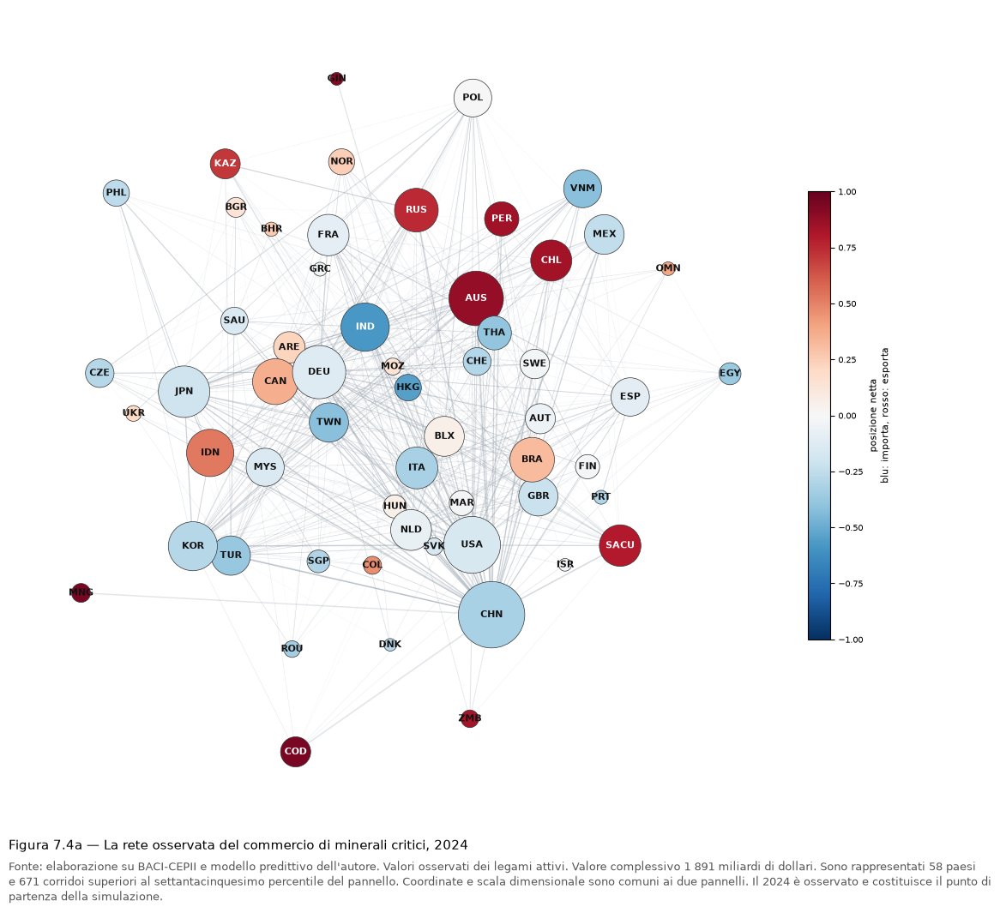

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_7_4a_rete_2024.png


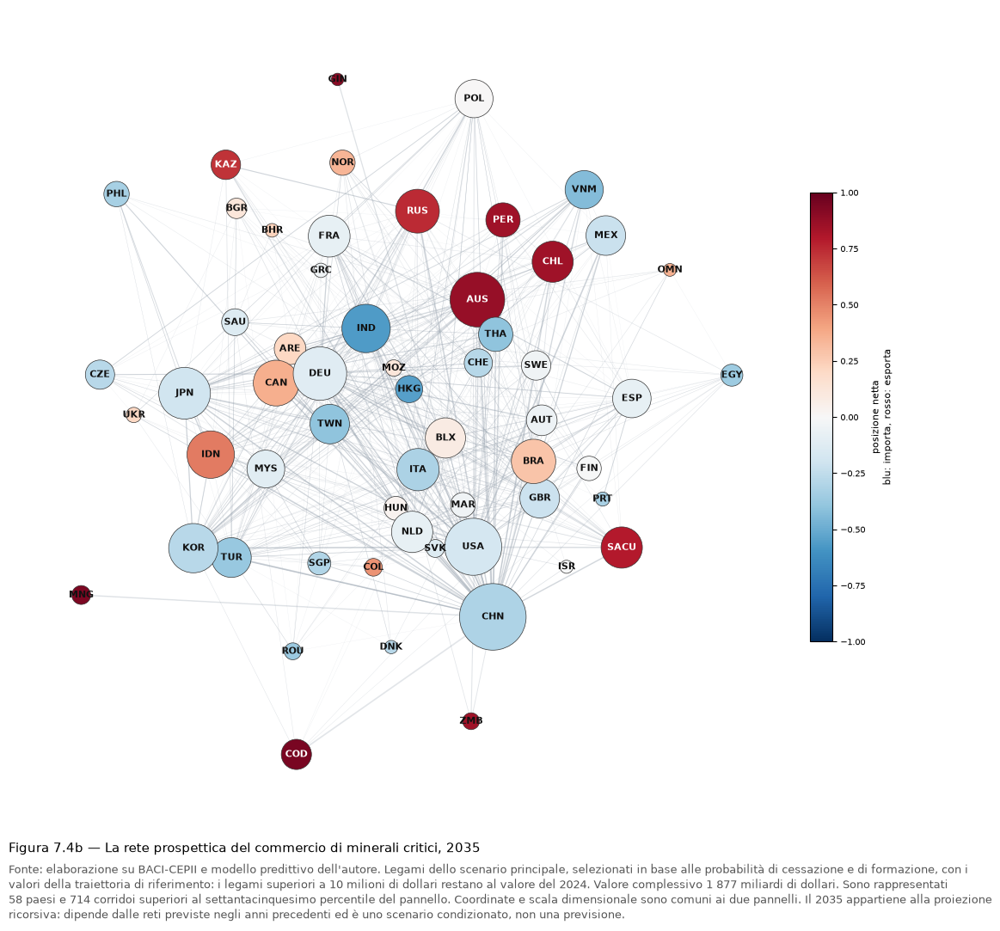

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_7_4b_rete_2035.png


In [140]:
# %% CELLA G7.3 — Figure 7.4a-b: la rete nel 2024 e nel 2035
# Si usa la rete discreta dello scenario principale: la rete attesa contiene
# ogni candidata con probabilità positiva (topologia più densa) e il suo
# livello include lo smearing, non confrontabile con il 2024 osservato.
# Le reti del 2025 e del 2030 sono quasi identiche e non sono rappresentate.
LARG_FUT, ALT_FUT = 11.0, 9.5
ANNI_FIG = [2024, 2035]
LETTERA_FIG = dict(zip(ANNI_FIG, "ab"))
GRAPHS_FUT = {a: grafo_iso(RS_DISCRETA[a]) for a in ANNI_FIG}
POS_FUT, SUB_FUT, SIZES_FUT = layout_e_dimensioni(GRAPHS_FUT, LARG_FUT, ALT_FUT)

TIPO = {2024: ("osservata", "Il 2024 è osservato e costituisce il punto di partenza "
                            "della simulazione."),
        2025: ("prevista", "Il 2025 è la previsione a un passo dalla rete osservata."),
        2030: ("prospettica", "Il 2030 appartiene alla proiezione ricorsiva: dipende "
                              "dalle reti previste negli anni precedenti ed è uno "
                              "scenario condizionato, non una previsione."),
        2035: ("prospettica", "Il 2035 appartiene alla proiezione ricorsiva: dipende "
                              "dalle reti previste negli anni precedenti ed è uno "
                              "scenario condizionato, non una previsione.")}

for a in ANNI_FIG:
    K = SUB_FUT[a]
    f, nn, na = disegna_rete(K, POS_FUT, np.array([SIZES_FUT[a][n] for n in K.nodes()]),
                             fs_lab=8.0)
    val = RS_DISCRETA[a].value.sum() / 1e6
    figura(f, altezza=ALT_FUT, larghezza=LARG_FUT, fs=11.0, margine_basso=0.05,
           margine_sx=0.05, margine_dx=0.05,
           didascalia=f"Figura 7.4{LETTERA_FIG[a]} — La rete {TIPO[a][0]} del "
                      f"commercio di minerali critici, {a}",
           nota=("Fonte: elaborazione su BACI-CEPII e modello predittivo dell'autore. "
                 + ("Valori osservati dei legami attivi. " if a == 2024 else
                    "Legami dello scenario principale, selezionati in base alle "
                    "probabilità di cessazione e di formazione, con i valori della "
                    "traiettoria di riferimento: i legami superiori a 10 milioni di "
                    "dollari restano al valore del 2024. ")
                 + f"Valore complessivo {_mig(val)} miliardi di dollari. Sono "
                   f"rappresentati {nn} paesi e {_mig(na)} corridoi superiori al "
                   f"settantacinquesimo percentile del pannello. Coordinate e scala "
                   f"dimensionale sono comuni ai due pannelli. " + TIPO[a][1]),
           out=FIG_DIR / f"fig_7_4{LETTERA_FIG[a]}_rete_{a}.png")

In [141]:
# %% CELLA G7.4 — che cosa cambia nella rete 2024-2035
# Topologia e valori si misurano sulle reti discrete dello scenario principale,
# con i valori della traiettoria di riferimento: è la stessa base della L11 ed
# è confrontabile con il 2024 osservato. La rete a valore atteso (L12bis)
# contiene ogni candidata con probabilità positiva e il suo livello include lo
# smearing, diverso per classe di valore: confrontata con il 2024 farebbe
# crescere quasi tutti i corridoi e ridurrebbe artificialmente la
# concentrazione. È usata solo come controllo delle tendenze 2025-2035.
def metriche_topologia(d):
    G = grafo_iso(d)
    n, m = G.number_of_nodes(), G.number_of_edges()
    scc = max((len(c) for c in nx.strongly_connected_components(G)), default=0)
    return dict(paesi=n, legami_rs=len(d), corridoi=m, densita=nx.density(G),
                reciprocita=nx.reciprocity(G), quota_scc=scc / n if n else np.nan,
                clustering=nx.average_clustering(G.to_undirected()))


def metriche_valori(d):
    z = paesi_iso(d)
    v = z.value.to_numpy()
    ex = z.groupby("exp_iso").value.sum()
    im = z.groupby("imp_iso").value.sum()
    st = ex.add(im, fill_value=0)
    vv = np.sort(v / v.sum())[::-1]
    return dict(valore_mld=v.sum() / 1e6, hhi_export=hhi(ex.values),
                hhi_import=hhi(im.values), quota_top5_paesi=(st / st.sum()).nlargest(5).sum(),
                quota_top10pct_corridoi=vv[:max(1, int(np.ceil(len(vv) * 0.1)))].sum())


TOPO_FUT = pd.DataFrame([dict(anno=a, **metriche_topologia(RS_DISCRETA[a])) for a in ANNI_SCEN])
PESATE_FUT = pd.DataFrame([dict(anno=a, **metriche_valori(RS_DISCRETA[a])) for a in ANNI_SCEN])
PESATE_ATTESA = pd.DataFrame([dict(anno=a, **metriche_valori(RS_ATTESA[a])) for a in ANNI_SCEN[1:]])

_e24 = set(map(tuple, paesi_iso(RS_DISCRETA[2024])[["exp_iso", "imp_iso"]].values))
_ov = []
for a in ANNI_SCEN:
    ea = set(map(tuple, paesi_iso(RS_DISCRETA[a])[["exp_iso", "imp_iso"]].values))
    _ov.append(dict(anno=a, persistenti_2024=len(_e24 & ea) / len(_e24),
                    jaccard=len(_e24 & ea) / len(_e24 | ea),
                    nuovi=len(ea - _e24), scomparsi=len(_e24 - ea)))
OVERLAP_FUT = pd.DataFrame(_ov)


def quote_paesi(d):
    z = paesi_iso(d)
    st = z.groupby("exp_iso").value.sum().add(z.groupby("imp_iso").value.sum(), fill_value=0)
    return st / st.sum()


_q24, _q35 = quote_paesi(RS_DISCRETA[2024]), quote_paesi(RS_DISCRETA[2035])
CHANGE = pd.DataFrame({"quota_2024": _q24, "quota_2035": _q35}).fillna(0)
CHANGE["delta_quota_scambi_pp"] = (CHANGE.quota_2035 - CHANGE.quota_2024) * 100
CHANGE = CHANGE.rename_axis("paese").reset_index()

CORRIDORS = (paesi_iso(RS_DISCRETA[2024])[["exp_iso", "imp_iso", "value"]]
             .rename(columns={"value": "value_2024"})
             .merge(paesi_iso(RS_DISCRETA[2035])[["exp_iso", "imp_iso", "value"]]
                    .rename(columns={"value": "value_2035"}),
                    on=["exp_iso", "imp_iso"], how="outer").fillna(0))
CORRIDORS["delta_mld"] = (CORRIDORS.value_2035 - CORRIDORS.value_2024) / 1e6

TOPO_FUT.to_csv(OUT_DIR / "scenario_topologia_2024_2035.csv", index=False)
PESATE_FUT.to_csv(OUT_DIR / "scenario_valori_2024_2035.csv", index=False)
PESATE_ATTESA.to_csv(OUT_DIR / "scenario_valori_attesi_2025_2035.csv", index=False)
OVERLAP_FUT.to_csv(OUT_DIR / "scenario_persistenza_2024_2035.csv", index=False)
CHANGE.to_csv(OUT_DIR / "scenario_quote_paesi_2024_2035.csv", index=False)
CORRIDORS.to_csv(OUT_DIR / "scenario_corridoi_2024_2035.csv", index=False)

print("topologia (reti discrete):\n" + TOPO_FUT.round(3).to_string(index=False))
print("\nvalori (traiettoria di riferimento):\n" + PESATE_FUT.round(3).to_string(index=False))
print("\ncontrollo: valori sulla rete attesa, 2025-2035 (livelli non confrontabili col 2024):\n"
      + PESATE_ATTESA.round(3).to_string(index=False))
print("\npersistenza rispetto al 2024:\n" + OVERLAP_FUT.round(3).to_string(index=False))
print("\nquote dei paesi, maggiori guadagni e perdite (punti):")
print(pd.concat([CHANGE.nlargest(8, "delta_quota_scambi_pp"),
                 CHANGE.nsmallest(8, "delta_quota_scambi_pp")])
      .round(3).to_string(index=False))

topologia (reti discrete):
 anno  paesi  legami_rs  corridoi  densita  reciprocita  quota_scc  clustering
 2024    205      55048      7138    0.171        0.691      0.912       0.780
 2025    204      54606      6719    0.162        0.695      0.897       0.791
 2030    203      56411      6552    0.160        0.720      0.862       0.788
 2035    203      58792      6664    0.163        0.742      0.842       0.798

valori (traiettoria di riferimento):
 anno  valore_mld  hhi_export  hhi_import  quota_top5_paesi  quota_top10pct_corridoi
 2024    1891.045       0.043       0.072             0.383                    0.845
 2025    1881.790       0.043       0.073             0.385                    0.839
 2030    1877.118       0.044       0.073             0.387                    0.834
 2035    1876.923       0.044       0.073             0.387                    0.834

controllo: valori sulla rete attesa, 2025-2035 (livelli non confrontabili col 2024):
 anno  valore_mld  hhi_export

corridoi con variazione di almeno 0.1 mld $: 38 in aumento, 101 in contrazione
variazione complessiva dei corridoi in aumento 48.4 mld $, in contrazione -62.6 mld $


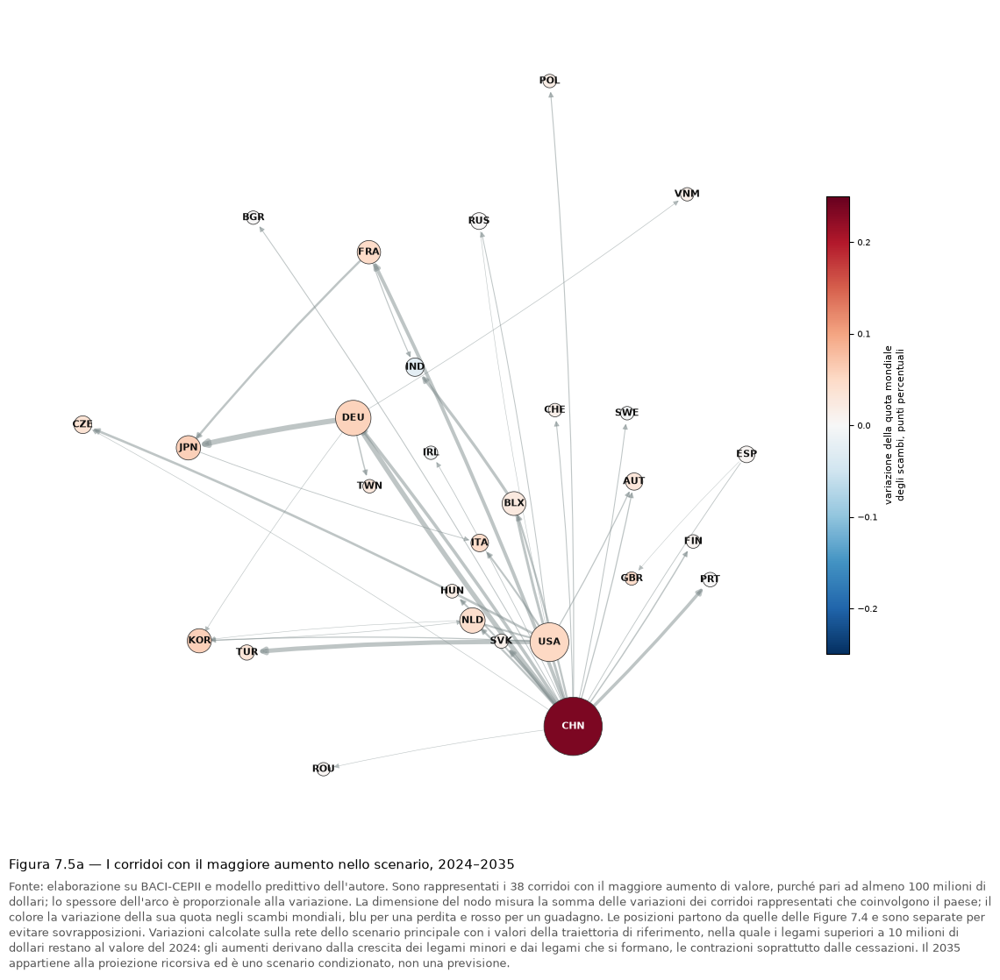

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_7_5a_corridoi_aumento.png


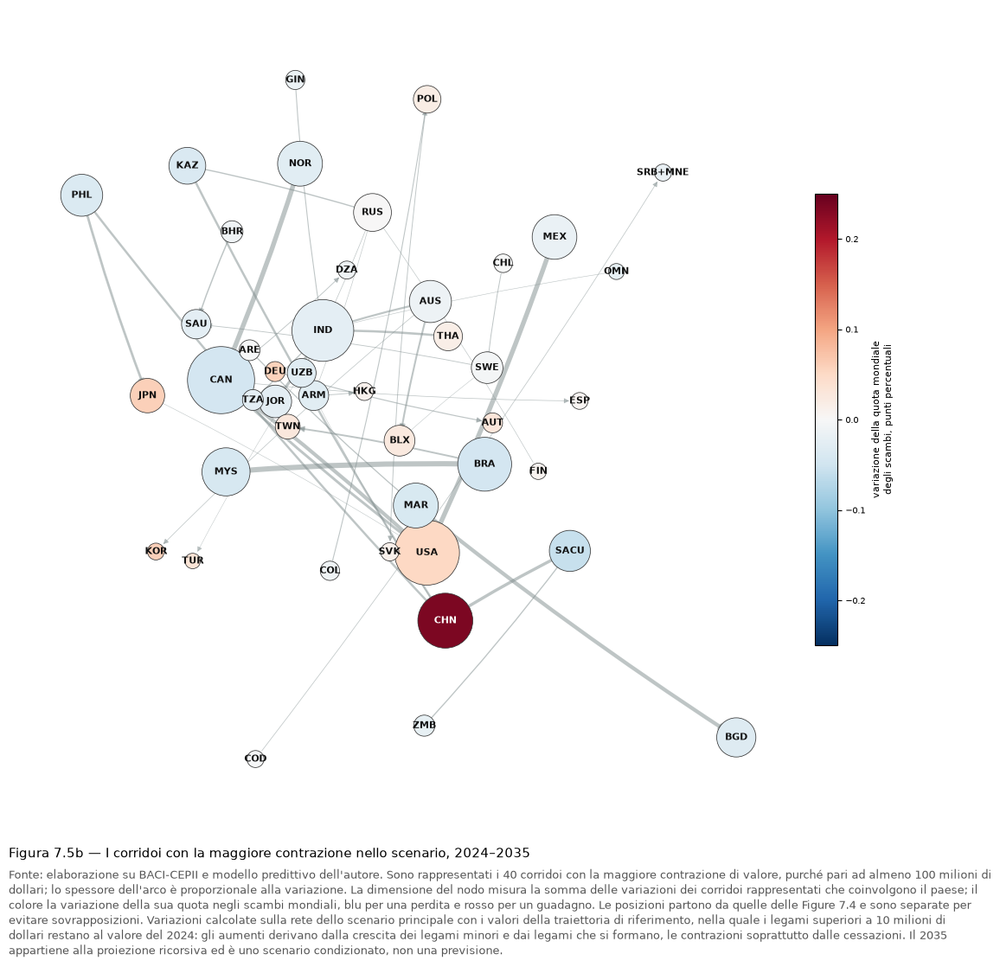

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_7_5b_corridoi_contrazione.png

maggiori aumenti:
exp_iso imp_iso  value_2024  value_2035  delta_mld
    DEU     JPN        0.88        1.07       0.19
    DEU     CHN        3.06        3.24       0.18
    USA     TUR        2.84        3.00       0.17
    CHN     FRA        2.82        2.97       0.15
    CHN     DEU       16.24       16.39       0.15
    CHN     PRT        0.17        0.32       0.15
    BLX     IND        0.28        0.42       0.14
    CHN     SVK        0.54        0.69       0.14
    BLX     CHN        0.53        0.67       0.14
    USA     CZE        0.23        0.36       0.13

maggiori contrazioni:
exp_iso imp_iso  value_2024  value_2035  delta_mld
    BRA     MYS        1.67        0.09      -1.58
    CAN     NOR        1.57        0.20      -1.36
    USA     MEX       18.45       17.11      -1.35
    MAR     BGD        1.07        0.03      -1.04
    USA     CAN       15.46       14.46      

In [142]:
# %% CELLA G7.5 — Figure 7.5a-b: corridoi in maggiore aumento e contrazione
# Le variazioni sono calcolate sulla rete discreta dello scenario principale
# (G7.4, CORRIDORS). Poiché i legami superiori a 10 M$ restano al valore del
# 2024, gli aumenti nascono dalla crescita dei legami minori e dalle
# formazioni, le contrazioni soprattutto dalle cessazioni.
TOP_CORR, MIN_DELTA_MLD = 40, 0.1
DQ = dict(zip(CHANGE.paese, CHANGE.delta_quota_scambi_pp))
LIM_DQ = max(0.25, min(CHANGE.delta_quota_scambi_pp.abs().quantile(0.95),
                       CHANGE.delta_quota_scambi_pp.abs().max()))
_sel = CORRIDORS[CORRIDORS.delta_mld.abs() >= MIN_DELTA_MLD]
AUMENTI = _sel[_sel.delta_mld > 0].nlargest(TOP_CORR, "delta_mld")
CONTRAZIONI = _sel[_sel.delta_mld < 0].nsmallest(TOP_CORR, "delta_mld")
print(f"corridoi con variazione di almeno {MIN_DELTA_MLD} mld $: "
      f"{(_sel.delta_mld > 0).sum()} in aumento, {(_sel.delta_mld < 0).sum()} in contrazione")
print(f"variazione complessiva dei corridoi in aumento {CORRIDORS.delta_mld.clip(lower=0).sum():,.1f} mld $, "
      f"in contrazione {CORRIDORS.delta_mld.clip(upper=0).sum():,.1f} mld $")


def grafo_delta(df):
    G = nx.DiGraph()
    for r in df.itertuples():
        G.add_edge(r.exp_iso, r.imp_iso, delta_mld=float(r.delta_mld),
                   value=abs(float(r.delta_mld)))
    return G


def forza_delta(G):
    return {n: sum(abs(d["delta_mld"]) for _, _, d in G.in_edges(n, data=True))
            + sum(abs(d["delta_mld"]) for _, _, d in G.out_edges(n, data=True)) for n in G}


def posizioni_delta(grafi, dim, larghezza=11.0, altezza=9.5, pad=1.32):
    """Parte dalle coordinate delle Figure 7.4, aggiunge i paesi mancanti e
    separa i nodi in base alle dimensioni di queste figure (la più grande fra
    i pannelli), così che nessuna coppia si sovrapponga."""
    pos = dict(POS_FUT)
    manca = [n for G in grafi for n in G if n not in pos]
    if manca:
        aux = igraph_layout(nx.compose_all(grafi), "drl", seed=42)[0]
        pos.update({n: aux[n] for n in manca})
    nodi = sorted({n for G in grafi for n in G})
    fz = [forza_delta(G) for G in grafi]
    inviluppo = np.array([max(dim(f[n]) if n in f else 0 for f in fz) for n in nodi])
    return separate({n: pos[n] for n in nodi}, nodi, inviluppo, larghezza_pollici=larghezza,
                    altezza_pollici=altezza, pad=pad)


def disegna_delta(G, pos, dq, lim, dim, cb_lab, colori_archi=False):
    """Reti di variazione: spessore dell'arco proporzionale alla variazione,
    dimensione del nodo alla somma delle variazioni dei corridoi rappresentati
    che lo coinvolgono, colore alla variazione della sua quota."""
    nodi = [n for n in G if n in pos]
    K = G.subgraph(nodi).copy()
    fz = forza_delta(K)
    sz = np.array([dim(fz[n]) for n in K.nodes()])
    cv = np.array([dq.get(n, 0.0) for n in K.nodes()])
    cmap, norm = plt.cm.RdBu_r, mcolors.TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    ed = list(K.edges())
    lw = np.log1p(np.array([abs(K[u][v]["delta_mld"]) for u, v in ed]))
    lw = 0.35 + 4.0 * (lw - lw.min()) / (lw.max() - lw.min() + 1e-9)
    ec = (["#b33b2e" if K[u][v]["delta_mld"] > 0 else "#336b87" for u, v in ed]
          if colori_archi else "#7f8c8d")
    rgba = cmap(norm(np.clip(cv, -lim, lim)))
    lum = 0.2126 * rgba[:, 0] + 0.7152 * rgba[:, 1] + 0.0722 * rgba[:, 2]
    grande = 2 * np.sqrt(sz / np.pi) >= 8.0 * 2.6
    scuri = [n for n, l, g in zip(K.nodes(), lum, grande) if l < 0.55 and g]
    chiari = [n for n in K.nodes() if n not in set(scuri)]

    def _f(ax):
        ax.grid(False)
        ax.axis("off")
        nx.draw_networkx_edges(K, pos, edgelist=ed, width=lw, edge_color=ec, alpha=0.5,
                               arrows=True, arrowsize=9, arrowstyle="-|>",
                               connectionstyle="arc3,rad=0.025", ax=ax)
        nx.draw_networkx_nodes(K, pos, node_size=sz, node_color=cv, cmap=cmap,
                               vmin=-lim, vmax=lim, edgecolors="#333333",
                               linewidths=0.55, ax=ax)
        for gruppo, col in [(chiari, "#111111"), (scuri, "#ffffff")]:
            if gruppo:
                nx.draw_networkx_labels(K, pos, labels={n: n for n in gruppo}, font_size=8,
                                        font_weight="bold", font_color=col, ax=ax)
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cb = ax.figure.colorbar(sm, ax=ax, shrink=0.55, pad=0.01)
        cb.set_label(cb_lab, fontsize=8)
        cb.ax.tick_params(labelsize=7.5)
        if colori_archi:
            from matplotlib.lines import Line2D
            ax.legend(handles=[Line2D([0], [0], color="#b33b2e", lw=2.2, label="aumento"),
                               Line2D([0], [0], color="#336b87", lw=2.2, label="contrazione")],
                      loc="lower right", frameon=False, fontsize=8)
    return _f, K.number_of_nodes(), K.number_of_edges()


G_INC, G_DEC = grafo_delta(AUMENTI), grafo_delta(CONTRAZIONI)
_ld = np.log1p(np.array(list(forza_delta(G_INC).values()) + list(forza_delta(G_DEC).values())))
DIM_D = lambda v: 120 + np.clip((np.log1p(v) - _ld.min()) / (_ld.max() - _ld.min() + 1e-9),
                                0, 1) ** 1.4 * 3000

_pos_d = posizioni_delta([G_INC, G_DEC], DIM_D)

_nota_d = ("La dimensione del nodo misura la somma delle variazioni dei corridoi "
           "rappresentati che coinvolgono il paese; il colore la variazione della sua "
           "quota negli scambi mondiali, blu per una perdita e rosso per un guadagno. "
           "Le posizioni partono da quelle delle Figure 7.4 e sono separate per evitare "
           "sovrapposizioni. "
           "Variazioni calcolate sulla rete dello scenario principale con i valori della "
           "traiettoria di riferimento, nella quale i legami superiori a 10 milioni di "
           "dollari restano al valore del 2024: gli aumenti derivano dalla crescita dei "
           "legami minori e dai legami che si formano, le contrazioni soprattutto dalle "
           "cessazioni. Il 2035 appartiene alla proiezione ricorsiva ed è uno scenario "
           "condizionato, non una previsione.")
for G, lett, art, cosa in [(G_INC, "a", "il maggiore", "aumento"),
                           (G_DEC, "b", "la maggiore", "contrazione")]:
    if G.number_of_edges() == 0:
        print(f"nessun corridoio in {cosa} sopra la soglia: figura 7.5{lett} non prodotta")
        continue
    f, nn, na = disegna_delta(G, _pos_d, DQ, LIM_DQ, DIM_D,
                              "variazione della quota mondiale\ndegli scambi, punti percentuali")
    figura(f, altezza=9.5, larghezza=11.0, fs=11.0, margine_basso=0.05, margine_sx=0.05,
           margine_dx=0.05,
           didascalia=f"Figura 7.5{lett} — I corridoi con {art} {cosa} nello scenario, "
                      f"2024–2035",
           nota=f"Fonte: elaborazione su BACI-CEPII e modello predittivo dell'autore. "
                f"Sono rappresentati i {na} corridoi con {art} {cosa} di valore, purché "
                f"pari ad almeno {_n(MIN_DELTA_MLD * 1000, 0)} milioni di dollari; lo "
                f"spessore dell'arco è proporzionale alla variazione. " + _nota_d,
           out=FIG_DIR / f"fig_7_5{lett}_corridoi_{cosa}.png")

pd.concat([AUMENTI.assign(tipo="aumento"), CONTRAZIONI.assign(tipo="contrazione")]) \
  .to_csv(OUT_DIR / "scenario_corridoi_selezionati.csv", index=False)

# i dieci corridoi principali per tipo, in miliardi di dollari (per il testo)
_mld = lambda d: d[["exp_iso", "imp_iso", "value_2024", "value_2035", "delta_mld"]].assign(
    value_2024=d.value_2024 / 1e6, value_2035=d.value_2035 / 1e6).round(2)
print("\nmaggiori aumenti:\n" + _mld(AUMENTI.head(10)).to_string(index=False))
print("\nmaggiori contrazioni:\n" + _mld(CONTRAZIONI.head(10)).to_string(index=False))

       stadio  valore_2024_mld  valore_2035_mld  corridoi_2024  corridoi_2035 maggiore_aumento  aumento_mld maggiore_contrazione  contrazione_mld  delta_pct
     upstream           592.76           561.37           3119           2397          USA→KOR         0.09              BRA→MYS            -1.57      -5.29
     refining           516.65           519.83           4335           4156          DEU→JPN         0.08              THA→IND            -0.44       0.62
manufacturing           656.57           668.52           4935           5305          CHN→ESP         0.09              MAR→BGD            -1.04       1.82
    recycling           125.07           127.20           2433           2642          MYS→BLX         0.05              POL→CZE            -0.12       1.70


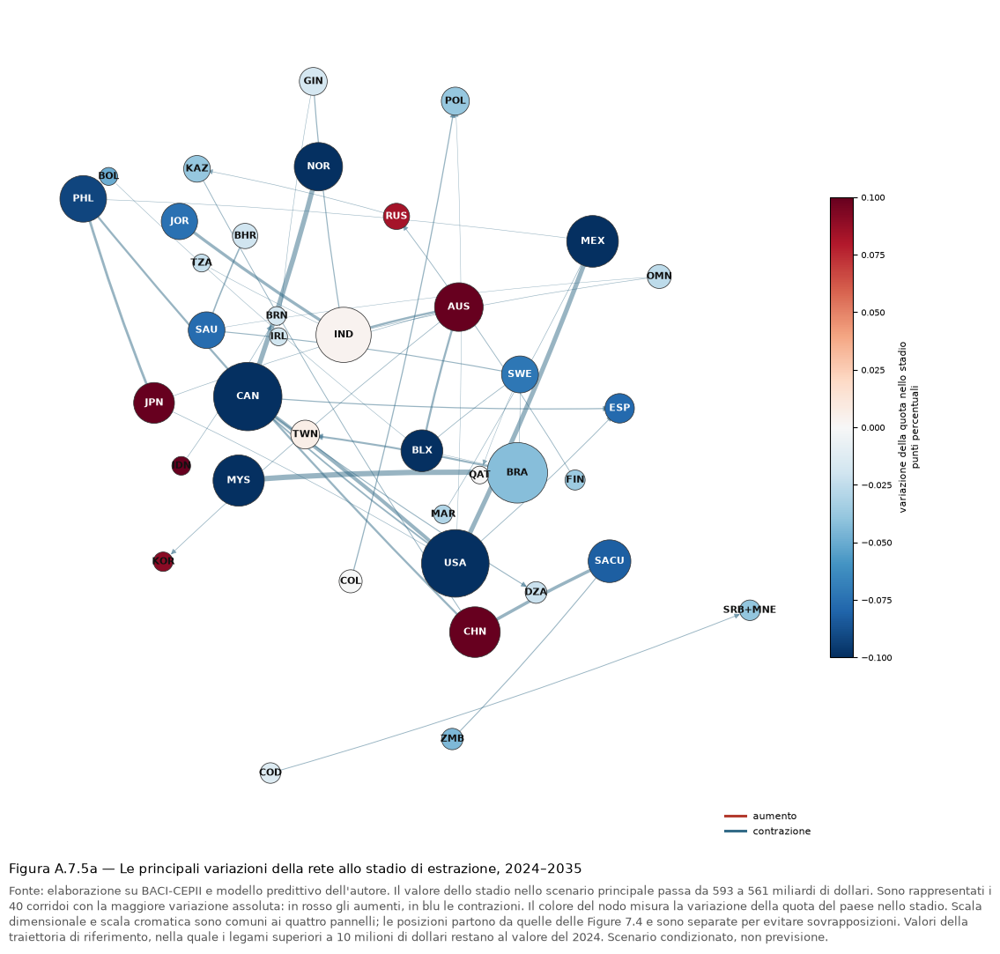

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_A7_5a_variazioni_upstream.png


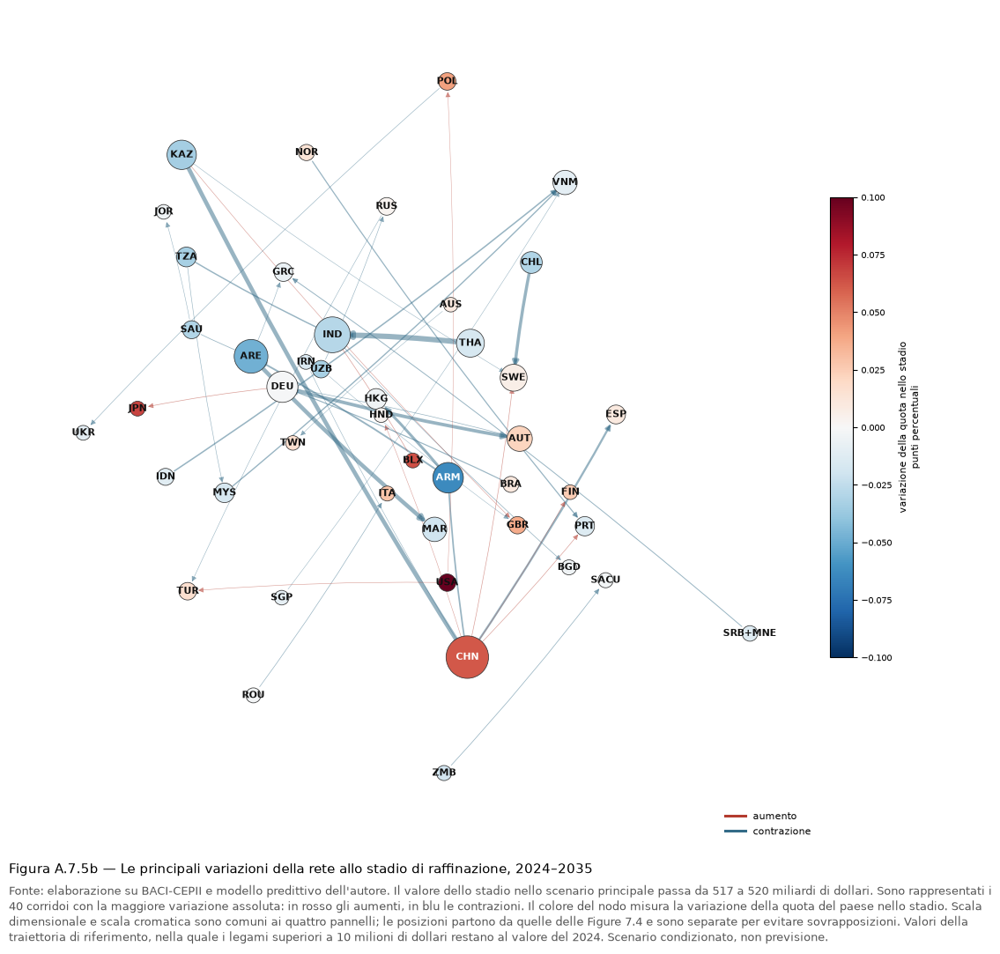

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_A7_5b_variazioni_refining.png


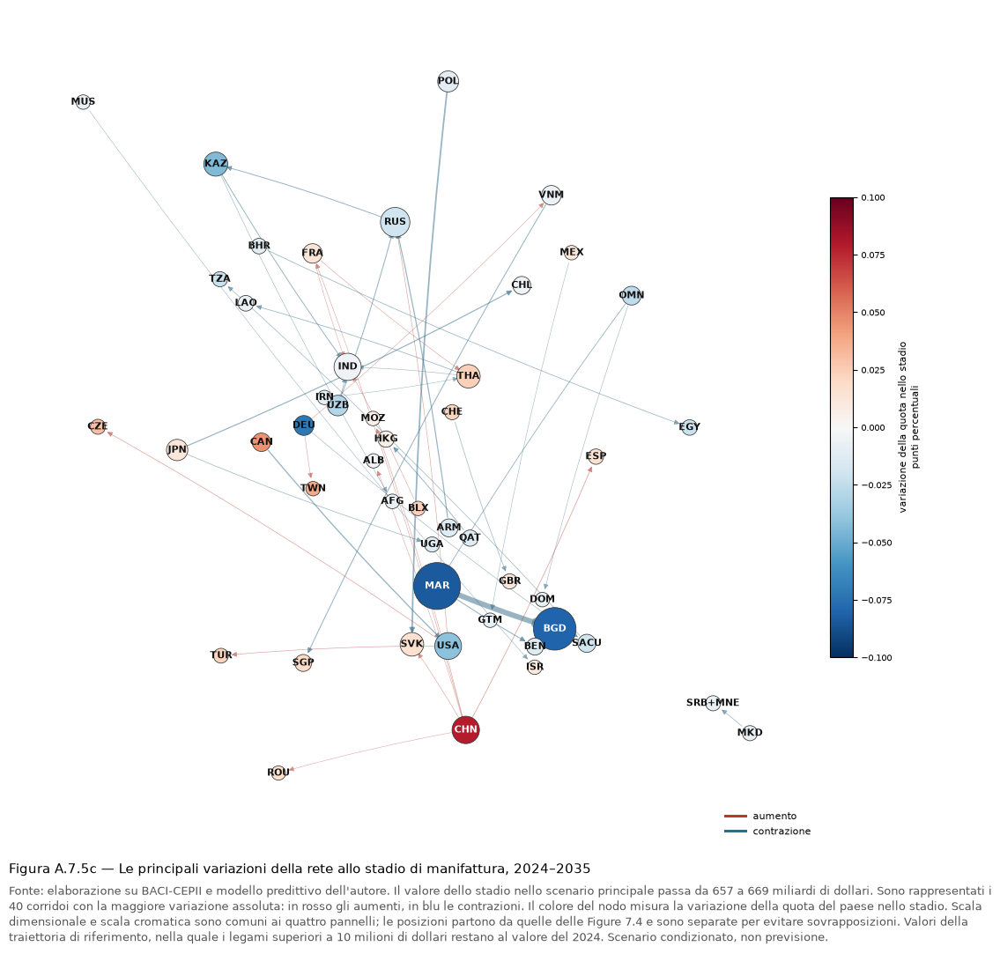

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_A7_5c_variazioni_manufacturing.png


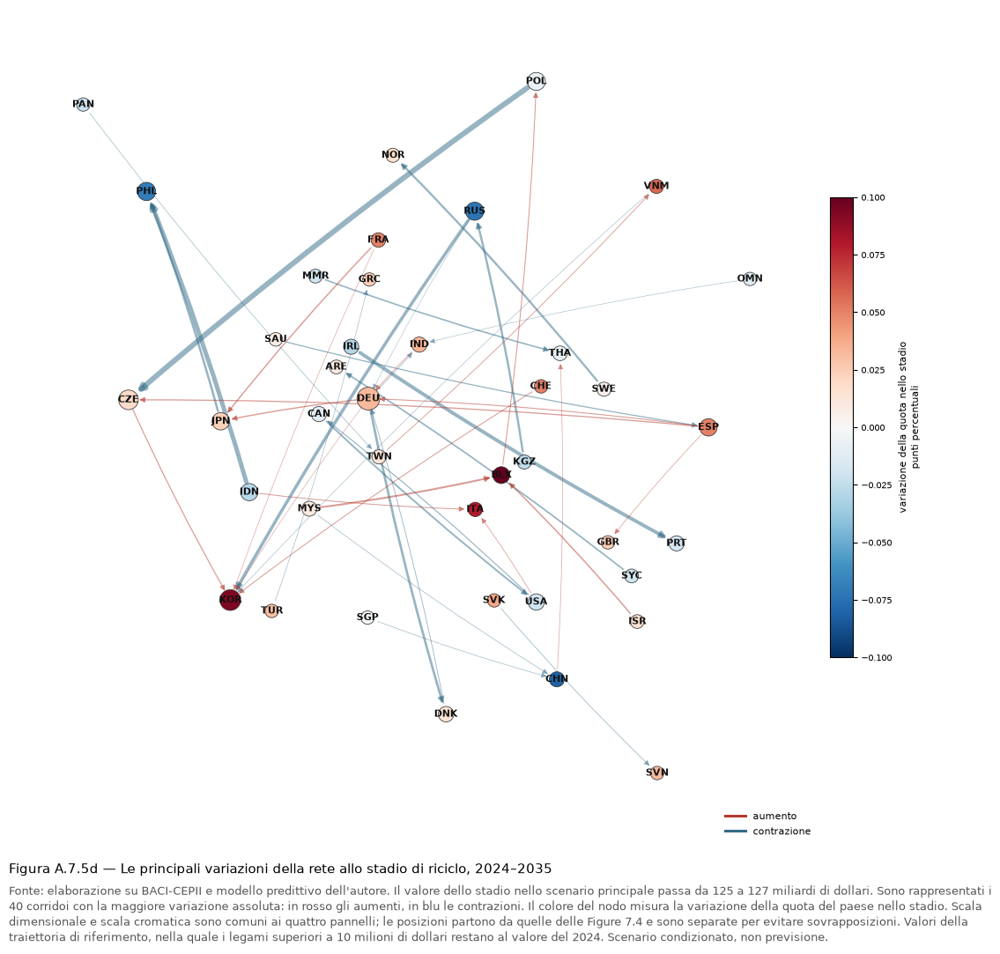

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_A7_5d_variazioni_recycling.png


In [143]:
# %% CELLA G7.6 — Figure A.7.5a-d: variazioni per stadio, 2024-2035 (appendice)
# Rete discreta dello scenario principale, valori della traiettoria di
# riferimento (come G7.4 e G7.5). Richiede posizioni_delta (G7.5).
TOP_ST, MIN_DELTA_ST, MIN_ARCHI_ST = 40, 0.10, 15
DELTA_ST, SEL_ST, DQ_ST, RIEP_ST = {}, {}, {}, []


def _quote_st(zz):
    s_ = zz.groupby("exp_iso").value.sum().add(zz.groupby("imp_iso").value.sum(), fill_value=0)
    return s_ / s_.sum()


for st in STAGES:
    a = paesi_iso(RS_DISCRETA[2024], st)[["exp_iso", "imp_iso", "value"]]
    b = paesi_iso(RS_DISCRETA[2035], st)[["exp_iso", "imp_iso", "value"]]
    z = (a.rename(columns={"value": "v24"}).merge(b.rename(columns={"value": "v35"}),
                                                  on=["exp_iso", "imp_iso"], how="outer")
         .fillna(0))
    z["delta_mld"] = (z.v35 - z.v24) / 1e6
    z["abs_delta"] = z.delta_mld.abs()
    DELTA_ST[st] = z
    s = z[z.abs_delta >= MIN_DELTA_ST].nlargest(TOP_ST, "abs_delta")
    SEL_ST[st] = s if len(s) >= MIN_ARCHI_ST else z.nlargest(min(TOP_ST, len(z)), "abs_delta")

    q24, q35 = _quote_st(a), _quote_st(b)
    idx = q24.index.union(q35.index)
    DQ_ST[st] = (q35.reindex(idx, fill_value=0) - q24.reindex(idx, fill_value=0)) * 100
    top_inc, top_dec = z.nlargest(1, "delta_mld").iloc[0], z.nsmallest(1, "delta_mld").iloc[0]
    RIEP_ST.append(dict(stadio=st, valore_2024_mld=z.v24.sum() / 1e6,
                        valore_2035_mld=z.v35.sum() / 1e6,
                        corridoi_2024=int((z.v24 > 0).sum()), corridoi_2035=int((z.v35 > 0).sum()),
                        maggiore_aumento=f"{top_inc.exp_iso}→{top_inc.imp_iso}",
                        aumento_mld=top_inc.delta_mld,
                        maggiore_contrazione=f"{top_dec.exp_iso}→{top_dec.imp_iso}",
                        contrazione_mld=top_dec.delta_mld))
RIEP_ST = pd.DataFrame(RIEP_ST)
RIEP_ST["delta_pct"] = (RIEP_ST.valore_2035_mld / RIEP_ST.valore_2024_mld - 1) * 100
RIEP_ST.to_csv(OUT_DIR / "scenario_variazioni_per_stadio.csv", index=False)
print(RIEP_ST.round(2).to_string(index=False))

G_ST = {st: grafo_delta(SEL_ST[st]) for st in STAGES}
_ls = np.log1p(np.array([v for G in G_ST.values() for v in forza_delta(G).values()]))
DIM_S = lambda v: 120 + np.clip((np.log1p(v) - _ls.min()) / (_ls.max() - _ls.min() + 1e-9),
                                0, 1) ** 1.4 * 3000
LIM_ST = max(0.10, np.quantile(np.abs(np.concatenate([d.values for d in DQ_ST.values()])), 0.95))

_pos_s = posizioni_delta(list(G_ST.values()), DIM_S)

for st in STAGES:
    r = RIEP_ST.set_index("stadio").loc[st]
    f, nn, na = disegna_delta(G_ST[st], _pos_s, DQ_ST[st].to_dict(), LIM_ST, DIM_S,
                              "variazione della quota nello stadio\npunti percentuali",
                              colori_archi=True)
    figura(f, altezza=9.5, larghezza=11.0, fs=11.0, margine_basso=0.05, margine_sx=0.05,
           margine_dx=0.05,
           didascalia=f"Figura A.7.5{LETTERA_ST[st]} — Le principali variazioni della rete "
                      f"allo stadio di {LBL_ST[st].lower()}, 2024–2035",
           nota=f"Fonte: elaborazione su BACI-CEPII e modello predittivo dell'autore. Il "
                f"valore dello stadio nello scenario principale passa da "
                f"{_mig(r.valore_2024_mld)} a {_mig(r.valore_2035_mld)} miliardi di dollari. "
                f"Sono rappresentati i {na} corridoi con la maggiore variazione assoluta: in "
                f"rosso gli aumenti, in blu le contrazioni. Il colore del nodo misura la "
                f"variazione della quota del paese nello stadio. Scala dimensionale e scala "
                f"cromatica sono comuni ai quattro pannelli; le posizioni partono da quelle "
                f"delle Figure 7.4 e sono separate per evitare sovrapposizioni. Valori della "
                f"traiettoria di riferimento, nella quale i legami superiori a 10 milioni di "
                f"dollari restano al valore del 2024. Scenario condizionato, non previsione.",
           out=FIG_DIR / f"fig_A7_5{LETTERA_ST[st]}_variazioni_{st}.png")

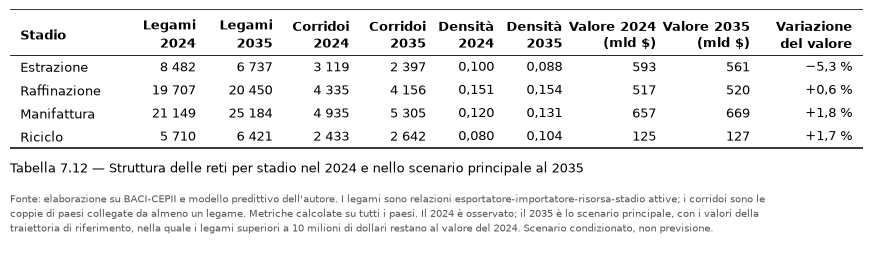

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_12_struttura_stadi.png
 anno        stadio  paesi  legami_rs  corridoi  densita  valore_mld
 2024      upstream    177       8482      3119    0.100     592.755
 2024      refining    170      19707      4335    0.151     516.651
 2024 manufacturing    203      21149      4935    0.120     656.566
 2024     recycling    175       5710      2433    0.080     125.072
 2025      upstream    174       7846      2811    0.093     588.130
 2025      refining    166      19835      4111    0.150     515.179
 2025 manufacturing    203      21268      4711    0.115     654.251
 2025     recycling    171       5657      2336    0.080     124.229
 2030      upstream    169       6977      2528    0.089     573.284
 2030      refining    165      20231      4188    0.155     517.220
 2030 manufacturing    202      23501      4986    0.123     661.771
 2030     recycling    163       5702      2353    0.089     124.842
 2035      

In [144]:
# %% CELLA G7.8 — Tabella 7.12: struttura delle reti per stadio, 2024 e 2035
# Metriche sui grafi completi (tutti i paesi, non solo quelli disegnati), rete
# discreta dello scenario principale con i valori della traiettoria di
# riferimento. Valori e corridoi coincidono con RIEP_ST (G7.6).
_r = []
for a in ANNI_SCEN:
    for st in STAGES:
        G = grafo_iso(RS_DISCRETA[a], st)
        n, m = G.number_of_nodes(), G.number_of_edges()
        _r.append(dict(anno=a, stadio=st, paesi=n,
                       legami_rs=int((RS_DISCRETA[a].stage_name == st).sum()),
                       corridoi=m, densita=m / (n * (n - 1)) if n > 1 else np.nan,
                       valore_mld=sum(d["value"] for _, _, d in G.edges(data=True)) / 1e6))
STR_ST = pd.DataFrame(_r)
STR_ST.to_csv(OUT_DIR / "scenario_struttura_per_stadio.csv", index=False)

A24 = STR_ST[STR_ST.anno == 2024].set_index("stadio")
A35 = STR_ST[STR_ST.anno == 2035].set_index("stadio")
tabella(
    [(LBL_ST[st], _mig(A24.loc[st, "legami_rs"]), _mig(A35.loc[st, "legami_rs"]),
      _mig(A24.loc[st, "corridoi"]), _mig(A35.loc[st, "corridoi"]),
      _n(A24.loc[st, "densita"], 3), _n(A35.loc[st, "densita"], 3),
      _mig(A24.loc[st, "valore_mld"]), _mig(A35.loc[st, "valore_mld"]),
      _sgn((A35.loc[st, "valore_mld"] / A24.loc[st, "valore_mld"] - 1) * 100, 1) + " %")
     for st in STAGES],
    ["Stadio", "Legami\n2024", "Legami\n2035", "Corridoi\n2024", "Corridoi\n2035",
     "Densità\n2024", "Densità\n2035", "Valore 2024\n(mld $)", "Valore 2035\n(mld $)",
     "Variazione\ndel valore"],
    [0.14, 0.09, 0.09, 0.09, 0.09, 0.08, 0.08, 0.11, 0.11, 0.12],
    didascalia="Tabella 7.12 — Struttura delle reti per stadio nel 2024 e nello "
               "scenario principale al 2035",
    nota="Fonte: elaborazione su BACI-CEPII e modello predittivo dell'autore. I legami "
         "sono relazioni esportatore-importatore-risorsa-stadio attive; i corridoi sono "
         "le coppie di paesi collegate da almeno un legame. Metriche calcolate su tutti "
         "i paesi. Il 2024 è osservato; il 2035 è lo scenario principale, con i valori "
         "della traiettoria di riferimento, nella quale i legami superiori a 10 milioni "
         "di dollari restano al valore del 2024. Scenario condizionato, non previsione.",
    allinea=["l"] + ["r"] * 9, larghezza=11.0,
    out=FIG_DIR / "tab_7_12_struttura_stadi.png")

print(STR_ST.round(3).to_string(index=False))

In [145]:
# %% [markdown]
# # Capitolo 7 — concentrazione, estrapolazione, tabelle e figure
#
# Ordine: C1 → C2 → C3 → X1, poi T7.0 … T7.11, F7.1, F7.2, A7, Z7.
# Da eseguire dopo le celle L (primo e secondo file) e prima o dopo le G7.
#
# Prerequisiti: DI, FL, ISO, STAGES, hhi (celle 0-11); tabella, figura, _nome,
# LBL_ST (T1, F1); RESOURCE_LEVELS e STAGE_LEVELS (cella L); i file salvati da
# L, L10 e L11a.
#
# Struttura del capitolo:
#   7.2 livelli          T7.1, T7.2, F7.1
#   7.3 cessazione       T7.3 – T7.6
#   7.4 formazione       T7.7 – T7.9
#   7.5 concentrazione   T7.10, T7.11
#   7.6 orizzonte        F7.2, poi le celle G7: Fig. 7.3-7.5 e Tabella 7.12
#   Appendice            A.7.1 – A.7.4 e A.7.6 (questo blocco); Fig. A.7.5a-d
#                        (G7.6); Tab. A.7.7 (L12bis) e A.7.8 (robustezza)

In [146]:
# =============================================================================
# CONCENTRAZIONE DELL'APPROVVIGIONAMENTO
# =============================================================================

# %% CELLA C1 — panel della concentrazione dell'approvvigionamento
# Unità: importatore x risorsa x stadio, la stessa della vulnerabilità nel
# capitolo 6. Concentrazione: indice di Herfindahl delle quote dei fornitori,
# su tutti i flussi in valore. Sono tenute le combinazioni con importazioni
# annue di almeno un milione di dollari: sotto, un solo carico produce indici
# prossimi all'unità privi di significato. Sono esclusi i flussi interni ai
# codici accorpati (es. Belgio-Lussemburgo, SACU), che farebbero del paese un
# fornitore di sé stesso.
import gc

import lightgbm as lgb   # usato in C2

SOGLIA_IMP_C = 1_000
_k = ["year", "imp", "resource", "stage_name"]

_b = DI.groupby(_k + ["exp"], observed=True, as_index=False).value.sum()
_b = _b[_b.value > 0]
_interni = (_b.exp == _b.imp)
print(f"flussi interni ai codici accorpati esclusi: {_interni.sum():,} "
      f"({_b.loc[_interni, 'value'].sum() / _b.value.sum():.2%} del valore)")
_b = _b[~_interni].copy()
for _c in ("resource", "stage_name"):
    _b[_c] = _b[_c].astype(str)
_b["tot"] = _b.groupby(_k).value.transform("sum")
_b["q"] = _b.value / _b.tot

AGG_C = (_b.assign(q2=_b.q ** 2).groupby(_k)
           .agg(tot=("value", "sum"), hhi=("q2", "sum"), n_fornitori=("exp", "size"),
                quota_primo=("q", "max")).reset_index())
AGG_C = AGG_C.merge(_b.loc[_b.groupby(_k).q.idxmax(), _k + ["exp"]]
                    .rename(columns={"exp": "primo"}), on=_k)

# lato dell'offerta mondiale di ciascun mercato
_w = _b.groupby(["year", "resource", "stage_name", "exp"], as_index=False).value.sum()
_w["qm"] = _w.value / _w.groupby(["year", "resource", "stage_name"]).value.transform("sum")
_off = (_w.assign(qm2=_w.qm ** 2).groupby(["year", "resource", "stage_name"])
          .agg(hhi_offerta=("qm2", "sum"), tot_mondo=("value", "sum")).reset_index())
AGG_C = (AGG_C.merge(_off, on=["year", "resource", "stage_name"])
              .merge(_w[["year", "resource", "stage_name", "exp", "qm"]]
                     .rename(columns={"exp": "primo", "qm": "quota_primo_mondo"}),
                     on=["year", "resource", "stage_name", "primo"], how="left"))
AGG_C["quota_imp_mondo"] = AGG_C.tot / AGG_C.tot_mondo
del _b, _w, _off
gc.collect()

# ritardi e obiettivo
_lag = AGG_C[_k + ["hhi", "tot"]]
for k in (1, 2):
    AGG_C = AGG_C.merge(_lag.assign(year=_lag.year + k)
                        .rename(columns={"hhi": f"hhi_lag{k}", "tot": f"tot_lag{k}"}),
                        on=_k, how="left")
AGG_C["n_eff"] = 1 / AGG_C.hhi
AGG_C["ltot"] = np.log1p(AGG_C.tot)
AGG_C["dltot"] = AGG_C.ltot - np.log1p(AGG_C.tot_lag1)
AGG_C["d_hhi1"] = AGG_C.hhi - AGG_C.hhi_lag1

PC = AGG_C.merge(_lag.assign(year=_lag.year - 1)
                 .rename(columns={"hhi": "hhi_next", "tot": "tot_next"}), on=_k, how="left")
PC = PC[PC.tot >= SOGLIA_IMP_C].copy()
PC["ha_target"] = PC.hhi_next.notna() & (PC.tot_next >= SOGLIA_IMP_C)
PC["d_hhi"] = PC.hhi_next - PC.hhi
PC["resource_c"] = pd.Categorical(PC.resource, categories=RESOURCE_LEVELS)
PC["stage_c"] = pd.Categorical(PC.stage_name, categories=STAGE_LEVELS)
for _c, _o in (("resource_c", "resource"), ("stage_c", "stage_name")):
    _na = PC[_c].isna()
    if _na.any():
        print(f"ATTENZIONE: {_na.sum():,} righe con {_o} fuori dai livelli del modello: "
              f"{sorted(PC.loc[_na, _o].unique())[:10]}")
PC["paese"] = PC.imp.map(lambda c: ISO.get(int(c), str(c)))
PC["fornitore"] = PC.primo.map(lambda c: ISO.get(int(c), str(c)))
del AGG_C, _lag
gc.collect()

FEAT_C = ["hhi", "hhi_lag1", "hhi_lag2", "d_hhi1", "n_fornitori", "n_eff", "quota_primo",
          "ltot", "dltot", "quota_imp_mondo", "hhi_offerta", "quota_primo_mondo",
          "resource_c", "stage_c"]
CAT_C = ["resource_c", "stage_c"]

print(f"[CONCENTRAZIONE] {len(PC):,} osservazioni | "
      f"{PC.groupby(['imp', 'resource', 'stage_name']).ngroups:,} combinazioni | "
      f"con osservazione l'anno successivo {PC.ha_target.sum():,}")

flussi interni ai codici accorpati esclusi: 0 (0.00% del valore)
[CONCENTRAZIONE] 218,287 osservazioni | 12,310 combinazioni | con osservazione l'anno successivo 195,542


### 7.5 La concentrazione dell'approvvigionamento

L'analisi si sposta dai singoli legami alla dipendenza di ciascun importatore dai propri fornitori. L'unità è la combinazione importatore × risorsa × stadio, la stessa usata per la vulnerabilità nel capitolo 6, e la concentrazione è misurata con l'indice di Herfindahl-Hirschman (HHI) delle quote dei fornitori, calcolato su tutti i flussi in valore. Sono considerate le combinazioni con importazioni annue di almeno un milione di dollari, perché al di sotto un singolo carico produce indici prossimi all'unità privi di significato; il panel comprende 218.287 osservazioni relative a 12.310 combinazioni. Il modello (LightGBM) usa il livello corrente e i due ritardi dell'indice, il numero di fornitori e il loro numero equivalente, la quota del primo fornitore, il valore importato e la sua variazione, il peso dell'importatore sul mercato mondiale, la concentrazione dell'offerta mondiale e la quota mondiale del primo fornitore, oltre a risorsa e stadio. La validazione è a finestra crescente: per ogni anno dal 2010 al 2023 il modello è stimato sugli anni precedenti e valutato sull'anno successivo.

Il livello dell'anno successivo è previsto meglio della persistenza in tutti i quattordici anni, con una riduzione media dell'errore assoluto del 3,4% (tra il 2,3% e il 5,0%; Tabella 7.10). Il guadagno è modesto perché la concentrazione dei fornitori cambia poco da un anno all'altro. La variazione dell'indice, che è la grandezza rilevante per stabilire quali dipendenze si aggravano, ha una correlazione di 0,42 con quella osservata (tra 0,40 e 0,45), senza deterioramento nel tempo.

Nei dati le combinazioni poco concentrate tendono a concentrarsi e quelle molto concentrate a diversificarsi: la correlazione fra livello e variazione successiva è −0,28, e resta −0,28 in scala logit, per cui non si tratta di un effetto del limite superiore dell'indice. Poiché il livello corrente è tra le variabili, prevedere la variazione o prevedere il livello e sottrarre quello corrente equivale a stimare la stessa media condizionale, e le due previsioni hanno infatti la stessa relazione con il livello (correlazioni di −0,650 e −0,652). Il modello riproduce questo ritorno verso la media nella misura osservata: la variazione diminuisce di 0,163 per ogni unità di livello nelle previsioni e di 0,156 nei dati, e la pendenza della variazione osservata su quella prevista è 0,96. Anche per fascia di concentrazione le variazioni medie previste sono vicine a quelle osservate (Tabella 7.11): +0,024 contro +0,027 sotto 0,25 e −0,096 contro −0,088 sopra 0,75. All'interno di ciascuna fascia la correlazione fra variazione prevista e osservata resta compresa fra 0,29 e 0,35, segno che il modello coglie differenze ulteriori rispetto al solo livello di partenza.

Applicato al 2024, il modello individua le dipendenze per cui è atteso un aumento della concentrazione nel 2025. Fra le 597 combinazioni con importazioni superiori a 500 milioni di dollari, 67 hanno un indice superiore a 0,3 e un aumento previsto. Queste combinazioni vanno in direzione opposta al ritorno verso la media, che per livelli di concentrazione elevati prevede in media una diminuzione. Fra le prime quindici prevalgono le importazioni di celle per batterie dalla Cina (Spagna, Paesi Bassi, Australia, Polonia e Taiwan) e di silicio manifatturato dalla Cina (Thailandia e Vietnam); vi compare anche il litio a monte importato dalla Cina, per il 66% dall'Australia. Gli aumenti previsti sono contenuti, fra 0,02 e 0,08 sull'indice, e data la correlazione di 0,42 vanno intesi come segnalazione di dipendenze da monitorare, non come previsione puntuale.

In [147]:
# %% CELLA C2 — previsione del livello e della variazione
# Due obiettivi: il livello dell'anno successivo, confrontato con la
# persistenza, e la variazione, che è la grandezza rilevante per stabilire
# quali dipendenze si aggravano. Poiché il livello corrente è tra le
# variabili, i due modelli stimano in linea di principio la stessa media
# condizionale; la variazione è modellata direttamente perché è l'obiettivo
# d'interesse e il modello non deve ricostruirla come differenza fra due
# grandezze molto più ampie. In entrambi i casi la previsione incorpora il
# ritorno verso la media osservato nei dati (le combinazioni poco concentrate
# tendono a concentrarsi e viceversa), in parte dovuto al rumore della misura:
# META_C confronta la relazione fra livello e variazione prevista con quella
# osservata.
from sklearn.metrics import mean_absolute_error

ANNI_TEST_C = range(2010, 2024)


def nuovo_modello_c():
    return lgb.LGBMRegressor(n_estimators=400, learning_rate=0.04, num_leaves=31,
                             min_child_samples=40, colsample_bytree=0.9,
                             random_state=0, n_jobs=-1, verbose=-1)


PCT = PC[PC.ha_target]
RIS_L, RIS_D, OOS_C = [], [], []
for ty in ANNI_TEST_C:
    tr, te = PCT[PCT.year < ty], PCT[PCT.year == ty]
    if tr.empty or te.empty:
        continue
    pl = np.clip(nuovo_modello_c().fit(tr[FEAT_C], tr.hhi_next, categorical_feature=CAT_C)
                 .predict(te[FEAT_C]), 0, 1)
    pdl = (nuovo_modello_c().fit(tr[FEAT_C], tr.d_hhi, categorical_feature=CAT_C)
           .predict(te[FEAT_C]))
    mae_p = mean_absolute_error(te.hhi_next, te.hhi)
    mae_m = mean_absolute_error(te.hhi_next, pl)
    RIS_L.append({"anno": ty, "n": len(te), "mae_persistenza": mae_p, "mae_modello": mae_m,
                  "guadagno_%": (1 - mae_m / mae_p) * 100})
    RIS_D.append(dict(anno=ty, n=len(te), corr=np.corrcoef(pdl, te.d_hhi)[0, 1],
                      mae_zero=te.d_hhi.abs().mean(),
                      mae_modello=mean_absolute_error(te.d_hhi, pdl),
                      corr_livello_prevista=np.corrcoef(te.hhi, pdl)[0, 1],
                      corr_livello_da_livello=np.corrcoef(te.hhi, pl - te.hhi)[0, 1],
                      corr_livello_osservata=np.corrcoef(te.hhi, te.d_hhi)[0, 1]))
    OOS_C.append(te[_k + ["hhi", "hhi_next", "d_hhi", "tot"]]
                 .assign(pred_livello=pl, pred_delta=pdl))
    print(f"{ty} -> {ty + 1}: livello {(1 - mae_m / mae_p) * 100:+.1f}% sulla persistenza | "
          f"correlazione sulla variazione {RIS_D[-1]['corr']:.3f}")

RH, RD = pd.DataFrame(RIS_L), pd.DataFrame(RIS_D)
OOS_C = pd.concat(OOS_C, ignore_index=True)

_lg = lambda x: np.log(np.clip(x, 1e-3, 1 - 1e-3) / (1 - np.clip(x, 1e-3, 1 - 1e-3)))
META_C = pd.Series({
    "corr_livello_osservata": OOS_C.hhi.corr(OOS_C.d_hhi),
    "corr_livello_osservata_logit": pd.Series(_lg(OOS_C.hhi)).corr(
        pd.Series(_lg(OOS_C.hhi_next) - _lg(OOS_C.hhi))),
    "corr_livello_prevista": OOS_C.hhi.corr(OOS_C.pred_delta),
    "corr_livello_da_livello": OOS_C.hhi.corr(OOS_C.pred_livello - OOS_C.hhi)})

RH.to_csv(OUT_DIR / "previsione_hhi.csv", index=False)
RD.to_csv(OUT_DIR / "previsione_hhi_delta.csv", index=False)
OOS_C.to_csv(OUT_DIR / "previsione_hhi_oos.csv", index=False)
META_C.to_csv(OUT_DIR / "previsione_hhi_meta.csv", header=["valore"])

print(f"\nlivello: guadagno medio {RH['guadagno_%'].mean():+.2f}%, anni vinti "
      f"{(RH['guadagno_%'] > 0).sum()} su {len(RH)}")
print(f"variazione: correlazione media {RD['corr'].mean():.3f} "
      f"(fra {RD['corr'].min():.3f} e {RD['corr'].max():.3f})")
print("\n" + META_C.round(3).to_string())

2010 -> 2011: livello +3.4% sulla persistenza | correlazione sulla variazione 0.433
2011 -> 2012: livello +5.0% sulla persistenza | correlazione sulla variazione 0.440
2012 -> 2013: livello +5.0% sulla persistenza | correlazione sulla variazione 0.445
2013 -> 2014: livello +2.9% sulla persistenza | correlazione sulla variazione 0.417
2014 -> 2015: livello +3.5% sulla persistenza | correlazione sulla variazione 0.438
2015 -> 2016: livello +3.9% sulla persistenza | correlazione sulla variazione 0.427
2016 -> 2017: livello +3.5% sulla persistenza | correlazione sulla variazione 0.428
2017 -> 2018: livello +2.7% sulla persistenza | correlazione sulla variazione 0.422
2018 -> 2019: livello +3.4% sulla persistenza | correlazione sulla variazione 0.423
2019 -> 2020: livello +2.3% sulla persistenza | correlazione sulla variazione 0.409
2020 -> 2021: livello +3.1% sulla persistenza | correlazione sulla variazione 0.429
2021 -> 2022: livello +2.9% sulla persistenza | correlazione sulla variazion

In [148]:
# %% CELLA C3 — ritorno verso la media per fascia e dipendenze in aggravamento
# Il confronto fra previsto e osservato si fa sulle pendenze e sulle medie per
# fascia, non sulle correlazioni: la previsione è più liscia del dato
# osservato e la sua correlazione con il livello è per costruzione più forte.
BANDE = [0, 0.25, 0.5, 0.75, 1.0001]
LAB_BANDE = ["fino a 0,25", "da 0,25 a 0,50", "da 0,50 a 0,75", "oltre 0,75"]

_pend = lambda x, y: np.polyfit(x, y, 1)[0]
PEND_C = pd.Series({
    "pendenza_osservata": _pend(OOS_C.hhi, OOS_C.d_hhi),
    "pendenza_prevista": _pend(OOS_C.hhi, OOS_C.pred_delta),
    "calibrazione": _pend(OOS_C.pred_delta, OOS_C.d_hhi)})
PEND_C.to_csv(OUT_DIR / "previsione_hhi_pendenze.csv", header=["valore"])
print("variazione sul livello (pendenze) e calibrazione:\n" + PEND_C.round(3).to_string() + "\n")

OOS_C["fascia"] = pd.cut(OOS_C.hhi, BANDE, labels=LAB_BANDE, right=False)
FAS = (OOS_C.groupby("fascia", observed=True)
       .apply(lambda g: pd.Series(dict(
           n=len(g),
           variazione_media_osservata=g.d_hhi.mean(),
           variazione_media_prevista=g.pred_delta.mean(),
           correlazione=g.hhi.corr(g.pred_delta),
           correlazione_osservata=g.hhi.corr(g.d_hhi),
           corr_prevista_osservata=g.pred_delta.corr(g.d_hhi))), include_groups=False)
       .reset_index())
FAS.to_csv(OUT_DIR / "aggravamento_per_fascia.csv", index=False)
print(FAS.round(3).to_string(index=False))

# modello finale su tutti gli anni con obiettivo osservato, applicato al 2024
MD_C = nuovo_modello_c().fit(PCT[FEAT_C], PCT.d_hhi, categorical_feature=CAT_C)
P24 = PC[PC.year == 2024].copy()
P24["d_prevista"] = MD_C.predict(P24[FEAT_C])
GRANDI_C = P24[P24.tot >= 500_000]
AGR = (GRANDI_C[(GRANDI_C.hhi > 0.3) & (GRANDI_C.d_prevista > 0)]
       .sort_values("d_prevista", ascending=False))
GRANDI_C.to_csv(OUT_DIR / "previsione_hhi_2025_grandi.csv", index=False)
AGR.to_csv(OUT_DIR / "dipendenze_in_aggravamento.csv", index=False)
print(f"\ncombinazioni superiori ai cinquecento milioni: {len(GRANDI_C)} | concentrate e "
      f"in aggravamento atteso: {len(AGR)}")
print(AGR.head(15)[["paese", "resource", "stage_name", "tot", "fornitore", "quota_primo",
                    "hhi", "d_prevista"]].round(3).to_string(index=False))

variazione sul livello (pendenze) e calibrazione:
pendenza_osservata   -0.156
pendenza_prevista    -0.163
calibrazione          0.959

        fascia       n  variazione_media_osservata  variazione_media_prevista  correlazione  correlazione_osservata  corr_prevista_osservata
   fino a 0,25 38998.0                       0.027                      0.024         0.025                   0.022                    0.343
da 0,25 a 0,50 41998.0                       0.016                      0.009        -0.208                  -0.062                    0.347
da 0,50 a 0,75 15137.0                      -0.036                     -0.044        -0.353                  -0.138                    0.341
    oltre 0,75 10872.0                      -0.088                     -0.096         0.028                   0.007                    0.285

combinazioni superiori ai cinquecento milioni: 597 | concentrate e in aggravamento atteso: 67
paese          resource    stage_name         tot fornitore  quot

In [149]:
# %% CELLA X1 — estrapolazione della concentrazione dell'offerta al 2030
# Non è una previsione: quantifica l'implicazione di una tendenza decennale
# sotto l'ipotesi esplicita che prosegua, con l'intervallo di previsione della
# regressione lineare. La concentrazione è l'indice di Herfindahl sulle
# esportazioni della risorsa, sommando i quattro stadi. L'indice è in valore
# e risente quindi dei prezzi; l'intervallo presume residui indipendenti ed è
# troppo stretto se sono autocorrelati (colonna rho1_residui).
from scipy import stats

RIS_X = ["cobalt", "lithium", "graphite", "nickel", "ree", "copper"]
ANNI_FIT, ANNI_PROJ = range(2015, 2025), range(2025, 2031)

_mancanti = set(RIS_X) - set(DI.resource.astype(str).unique())
if _mancanti:
    raise KeyError(f"risorse non presenti in DI: {sorted(_mancanti)}")

_x = (DI[DI.resource.isin(RIS_X)]
      .groupby(["resource", "year", "exp"], observed=True).value.sum().reset_index())
_x["resource"] = _x.resource.astype(str)
STO7 = (_x.groupby(["resource", "year"]).value.apply(lambda v: hhi(v.values))
          .rename("hhi").reset_index())

righe = []
for r in RIS_X:
    s = STO7[(STO7.resource == r) & STO7.year.isin(ANNI_FIT)].sort_values("year")
    x, y = s.year.to_numpy(float), s.hhi.to_numpy()
    n = len(x)
    b, a = np.polyfit(x, y, 1)
    res = y - (a + b * x)
    rho1 = np.corrcoef(res[:-1], res[1:])[0, 1] if n > 2 else np.nan
    sig = np.sqrt((res ** 2).sum() / (n - 2))
    sxx = ((x - x.mean()) ** 2).sum()
    tq = stats.t.ppf(0.975, n - 2)
    h24 = STO7[(STO7.resource == r) & (STO7.year == 2024)].hhi.iloc[0]
    for x0 in ANNI_PROJ:
        m = a + b * x0
        se = sig * np.sqrt(1 + 1 / n + (x0 - x.mean()) ** 2 / sxx)
        righe.append(dict(risorsa=r, anno=x0, stima=m, inf=max(m - tq * se, 0),
                          sup=min(m + tq * se, 1), hhi_2024=h24, pendenza=b,
                          rho1_residui=rho1))
TR7 = pd.DataFrame(righe)
TR7["esclude_2024"] = (TR7.inf > TR7.hhi_2024) | (TR7.sup < TR7.hhi_2024)
STO7.to_csv(OUT_DIR / "serie_hhi_storica.csv", index=False)
TR7.to_csv(OUT_DIR / "estrapolazione_hhi.csv", index=False)
print(TR7[TR7.anno.isin([2025, 2030])].round(3).to_string(index=False))

 risorsa  anno  stima   inf   sup  hhi_2024  pendenza  rho1_residui  esclude_2024
  cobalt  2025  0.373 0.160 0.586     0.221     0.020        -0.010         False
  cobalt  2030  0.476 0.201 0.750     0.221     0.020        -0.010         False
 lithium  2025  0.217 0.117 0.317     0.158     0.015         0.007         False
 lithium  2030  0.290 0.161 0.420     0.158     0.015         0.007          True
graphite  2025  0.159 0.113 0.204     0.154     0.007         0.385         False
graphite  2030  0.193 0.135 0.252     0.154     0.007         0.385         False
  nickel  2025  0.134 0.076 0.192     0.153     0.010         0.671         False
  nickel  2030  0.184 0.109 0.259     0.153     0.010         0.671         False
     ree  2025  0.134 0.080 0.189     0.118     0.002        -0.106         False
     ree  2030  0.146 0.076 0.216     0.118     0.002        -0.106         False
  copper  2025  0.047 0.041 0.053     0.049    -0.000        -0.034         False
  copper  2030  

utilità del capitolo 7 pronte


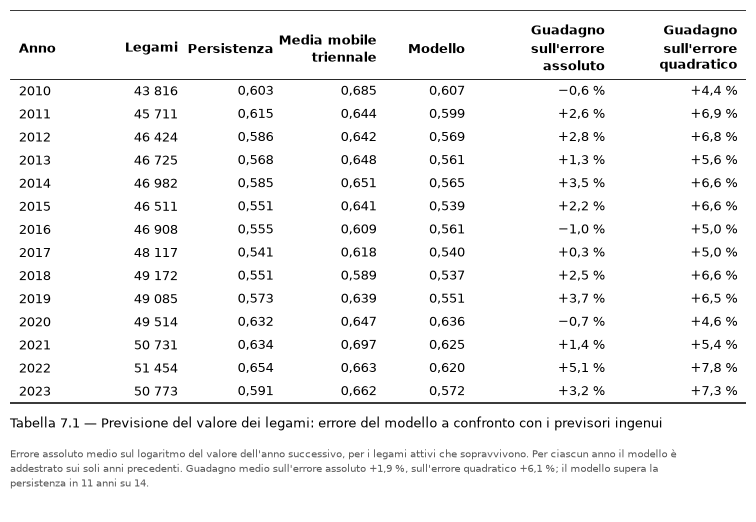

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_1_livelli.png


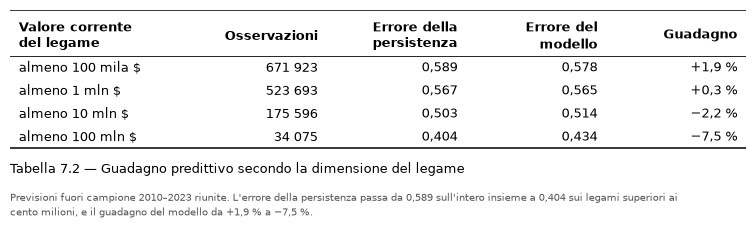

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_2_soglie.png


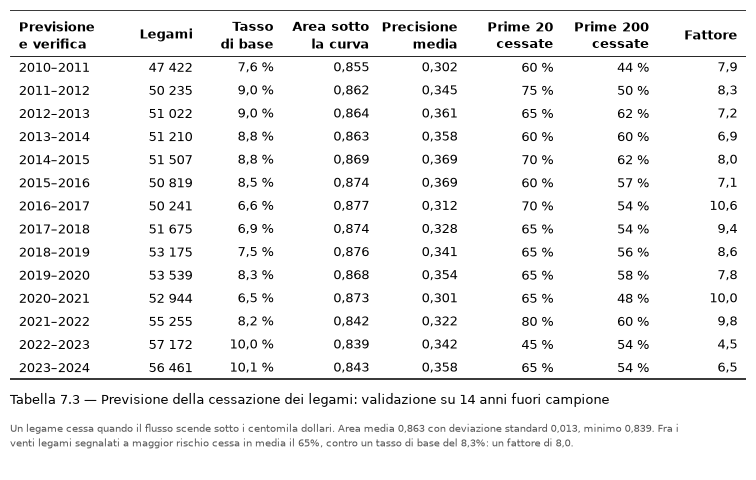

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_3_cessazione_anni.png


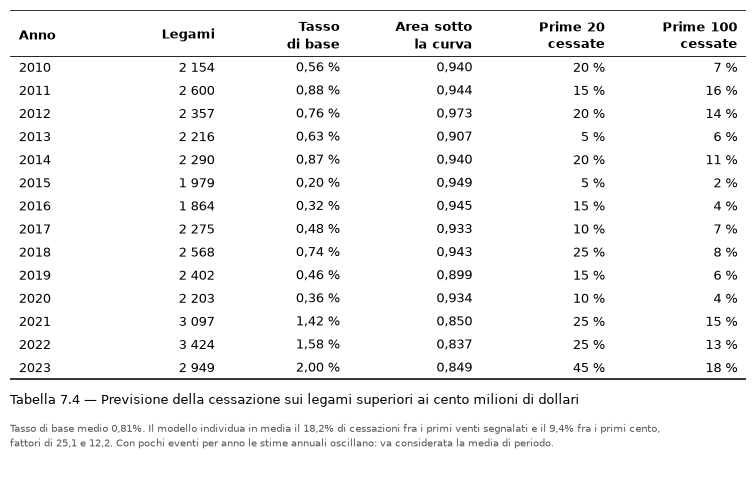

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_4_cessazione_grandi.png


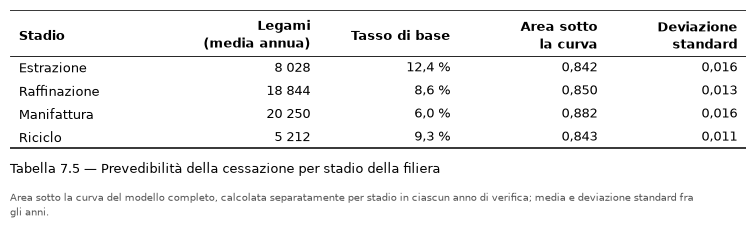

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_5_cessazione_stadio.png


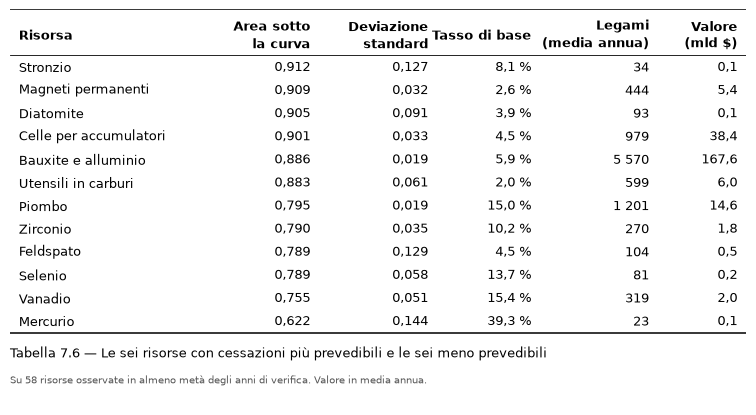

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_6_cessazione_risorsa.png


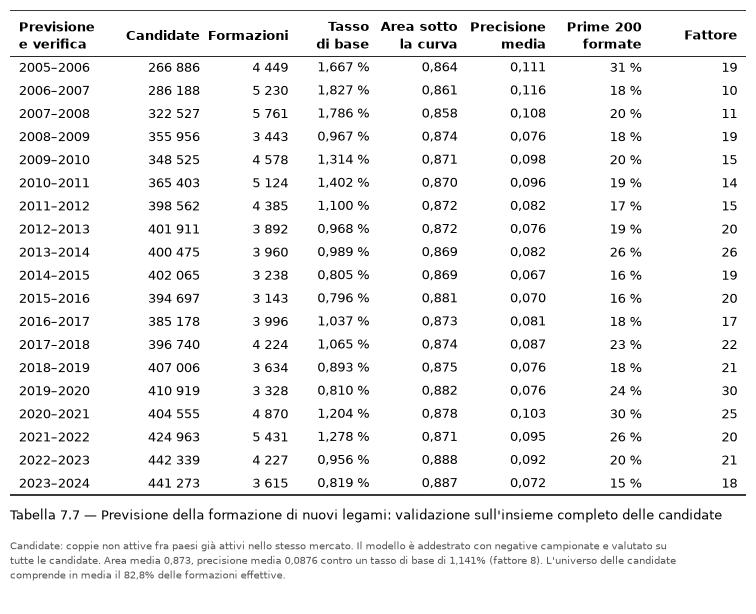

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_7_formazione_anni.png


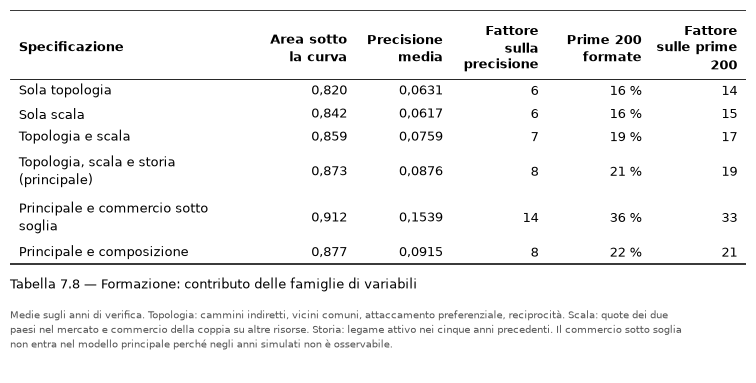

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_8_formazione_specificazioni.png


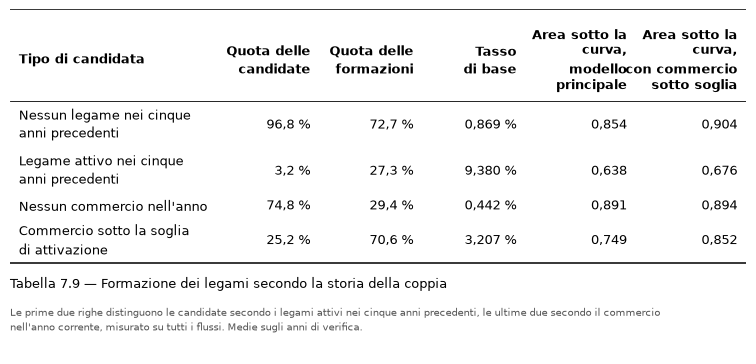

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_9_formazione_gruppi.png


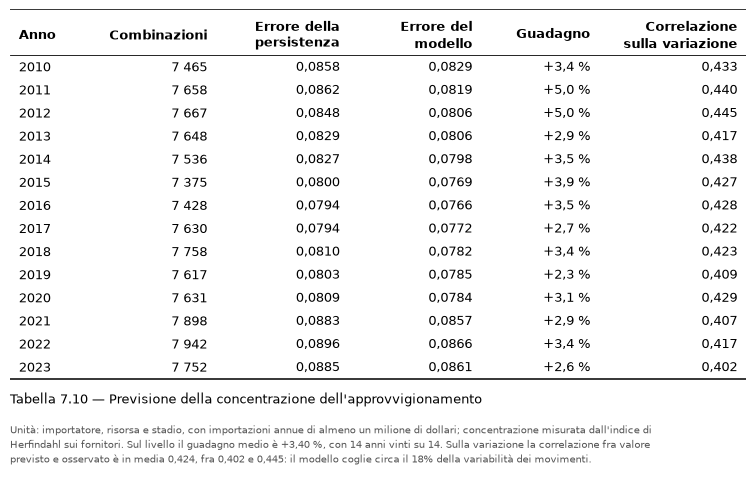

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_10_concentrazione.png


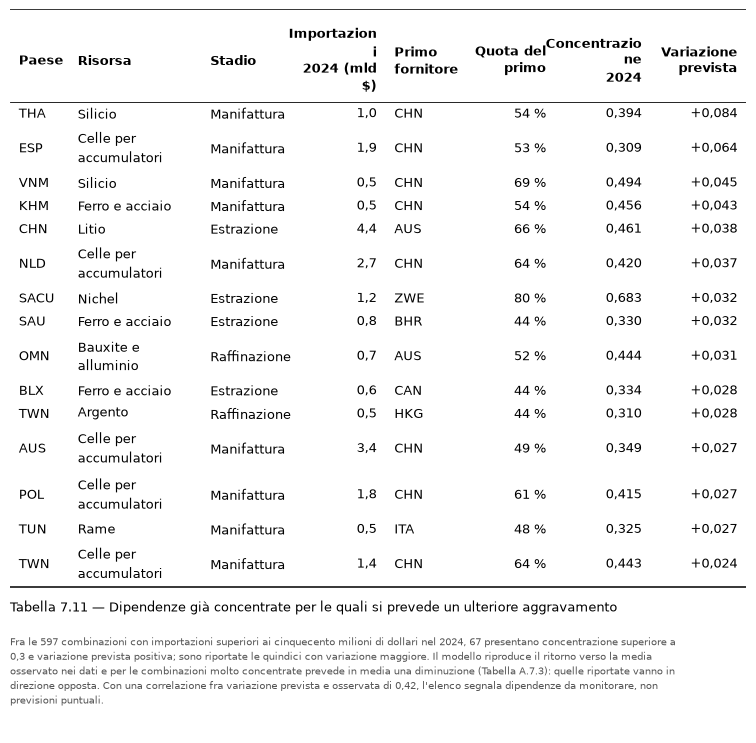

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_7_11_aggravamento.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/tab_7_11_aggravamento.png')

In [150]:
# =============================================================================
# TABELLE
# =============================================================================

# %% CELLA T7.0 — utilità
LBL_VAR = {"lag1": "Valore dell'anno corrente", "lag2": "Valore a un anno",
           "lag3": "Valore a due anni", "ma3": "Media mobile triennale",
           "ma5": "Media mobile quinquennale", "diff1": "Variazione recente",
           "diff2": "Variazione precedente", "eta": "Età della relazione",
           "quota_exp": "Quota dell'esportatore nel mercato",
           "quota_imp": "Quota dell'importatore nel mercato",
           "part_exp": "Partner dell'esportatore", "part_imp": "Partner dell'importatore",
           "hhi_forn": "Concentrazione dei fornitori", "resource_c": "Risorsa",
           "stage_c": "Stadio della filiera"}
LBL_SPEC_E = {"sola storia": "Sola storia della relazione",
              "storia e composizione": "Storia e composizione",
              "sola rete e composizione": "Sola struttura di rete e composizione",
              "completo": "Specificazione completa"}
LBL_SPEC_F = {"sola topologia": "Sola topologia", "sola scala": "Sola scala",
              "topologia e scala": "Topologia e scala",
              "principale": "Topologia, scala e storia (principale)",
              "principale + commercio sotto soglia": "Principale e commercio sotto soglia",
              "principale + composizione": "Principale e composizione"}
LBL_GRUPPO = {"nuova_5a": "Nessun legame nei cinque anni precedenti",
              "riattivazione_5a": "Legame attivo nei cinque anni precedenti",
              "da zero": "Nessun commercio nell'anno",
              "sotto soglia": "Commercio sotto la soglia di attivazione"}


def _n(x, dec=3):
    if x is None or not np.isfinite(x):
        return "—"
    return f"{x:,.{dec}f}".replace(",", "\u00a0").replace(".", ",")


def _mig(x, dec=0):
    return f"{x:,.{dec}f}".replace(",", "\u00a0")


def _pp(x, dec=1):
    return _n(x, dec) + " %"


def _sgn(x, dec=3):
    if x is None or not np.isfinite(x):
        return "—"
    return f"{x:+.{dec}f}".replace(".", ",").replace("-", "−")


def _spc(x, dec=1):
    return _sgn(x, dec) + " %"


print("utilità del capitolo 7 pronte")


# %% CELLA T7.1 — previsione del valore dei legami
RL = pd.read_csv(OUT_DIR / "previsione_finestra.csv")

tabella(
    [(str(int(r["anno"])), _mig(r["n"]), _n(r["mae_persistenza"]), _n(r["mae_ma3"]),
      _n(r["mae_modello"]), _spc(r["guadagno_mae_%"]), _spc(r["guadagno_rmse_%"]))
     for _, r in RL.iterrows()],
    ["Anno", "Legami", "Persistenza", "Media mobile\ntriennale", "Modello",
     "Guadagno\nsull'errore assoluto", "Guadagno\nsull'errore quadratico"],
    [0.10, 0.14, 0.13, 0.14, 0.12, 0.19, 0.18],
    didascalia="Tabella 7.1 — Previsione del valore dei legami: errore del modello a "
               "confronto con i previsori ingenui",
    nota=f"Errore assoluto medio sul logaritmo del valore dell'anno successivo, per i "
         f"legami attivi che sopravvivono. Per ciascun anno il modello è addestrato sui "
         f"soli anni precedenti. Guadagno medio sull'errore assoluto "
         f"{_spc(RL['guadagno_mae_%'].mean())}, sull'errore quadratico "
         f"{_spc(RL['guadagno_rmse_%'].mean())}; il modello supera la persistenza in "
         f"{(RL['guadagno_mae_%'] > 0).sum()} anni su {len(RL)}.",
    allinea=["l", "r", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_1_livelli.png")


# %% CELLA T7.2 — guadagno per dimensione del legame
SOG7 = pd.read_csv(OUT_DIR / "previsione_soglie.csv")

tabella(
    [("almeno " + (_mig(r.soglia_kUSD / 1000) + " mln $" if r.soglia_kUSD >= 1000
                   else _mig(r.soglia_kUSD) + " mila $"),
      _mig(r.osservazioni), _n(r.mae_persistenza), _n(r.mae_modello), _spc(r.guadagno))
     for r in SOG7.itertuples()],
    ["Valore corrente\ndel legame", "Osservazioni", "Errore della\npersistenza",
     "Errore del\nmodello", "Guadagno"],
    [0.24, 0.19, 0.19, 0.19, 0.19],
    didascalia="Tabella 7.2 — Guadagno predittivo secondo la dimensione del legame",
    nota=f"Previsioni fuori campione {int(RL.anno.min())}–{int(RL.anno.max())} riunite. "
         f"L'errore della persistenza passa da {_n(SOG7.mae_persistenza.iloc[0])} sull'intero "
         f"insieme a {_n(SOG7.mae_persistenza.iloc[-1])} sui legami superiori ai cento "
         f"milioni, e il guadagno del modello da {_spc(SOG7.guadagno.iloc[0])} a "
         f"{_spc(SOG7.guadagno.iloc[-1])}.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_2_soglie.png")


# %% CELLA T7.3 — cessazione: validazione per anno
VAL = pd.read_csv(OUT_DIR / "validazione_cessazione_anni.csv")

tabella(
    [(f"{int(r.anno_previsione)}–{int(r.anno_verifica)}", _mig(r.n), _pp(r.base * 100),
      _n(r.auc), _n(r.ap), _pp(r.top20 * 100, 0), _pp(r.top200 * 100, 0), _n(r.lift20, 1))
     for r in VAL.itertuples()],
    ["Previsione\ne verifica", "Legami", "Tasso\ndi base", "Area sotto\nla curva",
     "Precisione\nmedia", "Prime 20\ncessate", "Prime 200\ncessate", "Fattore"],
    [0.14, 0.12, 0.11, 0.13, 0.12, 0.13, 0.13, 0.12],
    didascalia=f"Tabella 7.3 — Previsione della cessazione dei legami: validazione su "
               f"{len(VAL)} anni fuori campione",
    nota=f"Un legame cessa quando il flusso scende sotto i centomila dollari. Area media "
         f"{_n(VAL.auc.mean())} con deviazione standard {_n(VAL.auc.std())}, minimo "
         f"{_n(VAL.auc.min())}. Fra i venti legami segnalati a maggior rischio cessa in "
         f"media il {_n(VAL.top20.mean() * 100, 0)}%, contro un tasso di base del "
         f"{_n(VAL.base.mean() * 100, 1)}%: un fattore di {_n(VAL.lift20.mean(), 1)}.",
    allinea=["l", "r", "r", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_3_cessazione_anni.png")


# %% CELLA T7.4 — cessazione dei legami di grande dimensione
BIG7 = pd.read_csv(OUT_DIR / "cessazione_grandi.csv")

tabella(
    [(str(int(r.anno)), _mig(r.n), _pp(r.base * 100, 2), _n(r.auc),
      _pp(r.top20 * 100, 0), _pp(r.top100 * 100, 0)) for r in BIG7.itertuples()],
    ["Anno", "Legami", "Tasso\ndi base", "Area sotto\nla curva", "Prime 20\ncessate",
     "Prime 100\ncessate"],
    [0.13, 0.16, 0.17, 0.18, 0.18, 0.18],
    didascalia="Tabella 7.4 — Previsione della cessazione sui legami superiori ai cento "
               "milioni di dollari",
    nota=f"Tasso di base medio {_n(BIG7.base.mean() * 100, 2)}%. Il modello individua in "
         f"media il {_n(BIG7.top20.mean() * 100, 1)}% di cessazioni fra i primi venti "
         f"segnalati e il {_n(BIG7.top100.mean() * 100, 1)}% fra i primi cento, fattori "
         f"di {_n(BIG7.lift20.mean(), 1)} e {_n(BIG7.lift100.mean(), 1)}. Con pochi eventi "
         f"per anno le stime annuali oscillano: va considerata la media di periodo.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_4_cessazione_grandi.png")


# %% CELLA T7.5 — cessazione per stadio
PS7 = pd.read_csv(OUT_DIR / "cessazione_per_stadio.csv").set_index("stadio")

tabella(
    [(LBL_ST[st], _mig(PS7.loc[st, "n"]), _pp(PS7.loc[st, "base"] * 100),
      _n(PS7.loc[st, "auc"]), _n(PS7.loc[st, "sd"])) for st in STAGES],
    ["Stadio", "Legami\n(media annua)", "Tasso di base", "Area sotto\nla curva",
     "Deviazione\nstandard"],
    [0.22, 0.20, 0.19, 0.20, 0.19],
    didascalia="Tabella 7.5 — Prevedibilità della cessazione per stadio della filiera",
    nota="Area sotto la curva del modello completo, calcolata separatamente per stadio "
         "in ciascun anno di verifica; media e deviazione standard fra gli anni.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_5_cessazione_stadio.png")


# %% CELLA T7.6 — cessazione per risorsa
# ordinamento esplicito per area sotto la curva, qualunque sia l'ordine del file
PR7 = (pd.read_csv(OUT_DIR / "cessazione_per_risorsa.csv", index_col=0)
         .sort_values("auc", ascending=False))
EST7 = pd.concat([PR7.head(6), PR7.tail(6)])

tabella(
    [(_nome(i), _n(r.auc), _n(r.sd), _pp(r.base * 100), _mig(r.n), _n(r.valore_mld, 1))
     for i, r in EST7.iterrows()],
    ["Risorsa", "Area sotto\nla curva", "Deviazione\nstandard", "Tasso di base",
     "Legami\n(media annua)", "Valore\n(mld $)"],
    [0.26, 0.16, 0.16, 0.14, 0.16, 0.12],
    didascalia="Tabella 7.6 — Le sei risorse con cessazioni più prevedibili e le sei meno "
               "prevedibili",
    nota=f"Su {len(PR7)} risorse osservate in almeno metà degli anni di verifica. Valore "
         f"in media annua.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_6_cessazione_risorsa.png")


# %% CELLA T7.7 — formazione: validazione per anno
RF7 = pd.read_csv(OUT_DIR / "previsione_formazione.csv")

tabella(
    [(f"{int(r.anno)}–{int(r.anno) + 1}", _mig(r.n), _mig(r.positive),
      _pp(r.base * 100, 3), _n(r.auc), _n(r.ap), _pp(r.top200 * 100, 0), _n(r.lift200, 0))
     for r in RF7.itertuples()],
    ["Previsione\ne verifica", "Candidate", "Formazioni", "Tasso\ndi base",
     "Area sotto\nla curva", "Precisione\nmedia", "Prime 200\nformate", "Fattore"],
    [0.13, 0.14, 0.12, 0.11, 0.12, 0.12, 0.13, 0.13],
    didascalia="Tabella 7.7 — Previsione della formazione di nuovi legami: validazione "
               "sull'insieme completo delle candidate",
    nota=f"Candidate: coppie non attive fra paesi già attivi nello stesso mercato. Il "
         f"modello è addestrato con negative campionate e valutato su tutte le candidate. "
         f"Area media {_n(RF7.auc.mean())}, precisione media {_n(RF7.ap.mean(), 4)} contro "
         f"un tasso di base di {_n(RF7.base.mean() * 100, 3)}% (fattore "
         f"{_n(RF7.lift_ap.mean(), 0)}). L'universo delle candidate comprende in media il "
         f"{_n(RF7.coverage.mean() * 100, 1)}% delle formazioni effettive.",
    allinea=["l", "r", "r", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_7_formazione_anni.png")


# %% CELLA T7.8 — formazione: contributo delle famiglie di variabili
CF7 = pd.read_csv(OUT_DIR / "formazione_specificazioni.csv")
SF7 = (CF7.groupby("specificazione")[["auc", "ap", "lift_ap", "top200", "lift200"]].mean()
          .reindex([s for s in LBL_SPEC_F if s in set(CF7.specificazione)]))

tabella(
    [(LBL_SPEC_F[s], _n(r.auc), _n(r.ap, 4), _n(r.lift_ap, 0), _pp(r.top200 * 100, 0),
      _n(r.lift200, 0)) for s, r in SF7.iterrows()],
    ["Specificazione", "Area sotto\nla curva", "Precisione\nmedia", "Fattore sulla\nprecisione",
     "Prime 200\nformate", "Fattore\nsulle prime 200"],
    [0.34, 0.13, 0.13, 0.13, 0.14, 0.13],
    didascalia="Tabella 7.8 — Formazione: contributo delle famiglie di variabili",
    nota="Medie sugli anni di verifica. Topologia: cammini indiretti, vicini comuni, "
         "attaccamento preferenziale, reciprocità. Scala: quote dei due paesi nel mercato "
         "e commercio della coppia su altre risorse. Storia: legame attivo nei cinque anni "
         "precedenti. Il commercio sotto soglia non entra nel modello principale perché "
         "negli anni simulati non è osservabile.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_8_formazione_specificazioni.png")


# %% CELLA T7.9 — formazione per tipo di candidata
RG7 = pd.read_csv(OUT_DIR / "formazione_gruppi.csv")
_g = RG7.groupby(["specificazione", "criterio", "gruppo"])[
    ["quota_candidate", "quota_formazioni", "base", "auc"]].mean()
_righe = []
for crit in ("visto_5a", "sotto_soglia"):
    for gr in (["nuova_5a", "riattivazione_5a"] if crit == "visto_5a"
               else ["da zero", "sotto soglia"]):
        p = _g.loc[("principale", crit, gr)]
        s = _g.loc[("principale + commercio sotto soglia", crit, gr)] \
            if ("principale + commercio sotto soglia", crit, gr) in _g.index else None
        _righe.append((LBL_GRUPPO[gr], _pp(p.quota_candidate * 100), _pp(p.quota_formazioni * 100),
                       _pp(p.base * 100, 3), _n(p.auc), _n(s.auc) if s is not None else "—"))

tabella(
    _righe,
    ["Tipo di candidata", "Quota delle\ncandidate", "Quota delle\nformazioni",
     "Tasso\ndi base", "Area sotto la curva,\nmodello principale",
     "Area sotto la curva,\ncon commercio\nsotto soglia"],
    [0.28, 0.14, 0.14, 0.14, 0.15, 0.15],
    didascalia="Tabella 7.9 — Formazione dei legami secondo la storia della coppia",
    nota="Le prime due righe distinguono le candidate secondo i legami attivi nei cinque "
         "anni precedenti, le ultime due secondo il commercio nell'anno corrente, "
         "misurato su tutti i flussi. Medie sugli anni di verifica.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_9_formazione_gruppi.png")


# %% CELLA T7.10 — previsione della concentrazione
RH = pd.read_csv(OUT_DIR / "previsione_hhi.csv")
RD = pd.read_csv(OUT_DIR / "previsione_hhi_delta.csv")
_rhd = RH.merge(RD[["anno", "corr"]], on="anno")

tabella(
    [(str(int(r.anno)), _mig(r.n), _n(r.mae_persistenza, 4), _n(r.mae_modello, 4),
      _spc(r["guadagno_%"]), _n(r["corr"])) for _, r in _rhd.iterrows()],
    ["Anno", "Combinazioni", "Errore della\npersistenza", "Errore del\nmodello",
     "Guadagno", "Correlazione\nsulla variazione"],
    [0.12, 0.16, 0.18, 0.18, 0.16, 0.20],
    didascalia="Tabella 7.10 — Previsione della concentrazione dell'approvvigionamento",
    nota=f"Unità: importatore, risorsa e stadio, con importazioni annue di almeno un "
         f"milione di dollari; concentrazione misurata dall'indice di Herfindahl sui "
         f"fornitori. Sul livello il guadagno medio è {_spc(RH['guadagno_%'].mean(), 2)}, con "
         f"{(RH['guadagno_%'] > 0).sum()} anni vinti su {len(RH)}. Sulla variazione la "
         f"correlazione fra valore previsto e osservato è in media {_n(RD['corr'].mean())}, "
         f"fra {_n(RD['corr'].min())} e {_n(RD['corr'].max())}: il modello coglie circa il "
         f"{_n(RD['corr'].mean() ** 2 * 100, 0)}% della variabilità dei movimenti.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_7_10_concentrazione.png")


# %% CELLA T7.11 — dipendenze in aggravamento atteso
AGR = pd.read_csv(OUT_DIR / "dipendenze_in_aggravamento.csv")
GRANDI_C = pd.read_csv(OUT_DIR / "previsione_hhi_2025_grandi.csv")
RD = pd.read_csv(OUT_DIR / "previsione_hhi_delta.csv")
A15 = AGR.nlargest(15, "d_prevista")

tabella(
    [(r.paese, _nome(r.resource), LBL_ST[r.stage_name], _n(r.tot / 1e6, 1), r.fornitore,
      _pp(r.quota_primo * 100, 0), _n(r.hhi), _sgn(r.d_prevista)) for r in A15.itertuples()],
    ["Paese", "Risorsa", "Stadio", "Importazioni\n2024 (mld $)", "Primo\nfornitore",
     "Quota del\nprimo", "Concentrazione\n2024", "Variazione\nprevista"],
    [0.08, 0.18, 0.13, 0.12, 0.11, 0.12, 0.13, 0.13],
    didascalia="Tabella 7.11 — Dipendenze già concentrate per le quali si prevede un "
               "ulteriore aggravamento",
    nota=f"Fra le {len(GRANDI_C)} combinazioni con importazioni superiori ai cinquecento "
         f"milioni di dollari nel 2024, {len(AGR)} presentano concentrazione superiore a "
         f"0,3 e variazione prevista positiva; sono riportate le quindici con variazione "
         f"maggiore. Il modello riproduce il ritorno verso la media osservato nei dati e "
         f"per le combinazioni molto concentrate prevede in media una diminuzione "
         f"(Tabella A.7.3): quelle riportate vanno in direzione opposta. Con una "
         f"correlazione fra variazione prevista e osservata di {_n(RD['corr'].mean(), 2)}, "
         f"l'elenco segnala dipendenze da monitorare, non previsioni puntuali.",
    allinea=["l", "l", "l", "r", "l", "r", "r", "r"],
    out=FIG_DIR / "tab_7_11_aggravamento.png")

### 7.6 Uno sguardo al 2030–2035

#### 7.6.1 Estrapolazione della concentrazione dell'offerta

Prima della simulazione della rete, un esercizio più semplice indica che cosa implicherebbe per la concentrazione dell'offerta il proseguimento delle tendenze recenti. Per sei risorse (cobalto, litio, grafite, nichel, terre rare e rame) l'indice di Herfindahl sulle esportazioni, calcolato sommando i quattro stadi, è interpolato con una retta sul decennio 2015–2024 ed estrapolato al 2030 con l'intervallo di previsione al 95% (Figura 7.2; Tabella A.7.4). Non si tratta di una previsione, ma dell'implicazione aritmetica di una tendenza sotto l'ipotesi esplicita che prosegua; l'indice è inoltre calcolato in valore e risente anche dei prezzi.

La pendenza è positiva per il cobalto (+0,020 all'anno), il litio (+0,015), il nichel (+0,010) e la grafite (+0,007), quasi nulla per le terre rare (+0,002) e assente per il rame. Le serie mostrano però che per diverse risorse la crescita non è stata graduale. Litio, grafite e nichel registrano un salto di livello intorno al 2021–2022: il litio passa da circa 0,12 a 0,23 nel 2022–2023 per poi tornare a 0,16 nel 2024, la grafite sale da circa 0,10 a 0,15–0,17, il nichel, in calo fino al 2021, sale da circa 0,06 a 0,15 nel 2024. Il cobalto raggiunge un massimo di circa 0,41 nel 2021 e scende a 0,22 nel 2024, ben al di sotto della retta, che già per il 2025 indica 0,37. Le terre rare, dopo il picco di circa 0,38 nel 2011, oscillano da un decennio fra 0,11 e 0,16, mentre il rame mostra una lenta diversificazione. In presenza di salti di livello la retta attribuisce a una tendenza continua quello che è un cambiamento avvenuto in pochi anni, e per il nichel e la grafite i residui sono autocorrelati (0,67 e 0,39 al primo ritardo), per cui gli intervalli sottostimano l'incertezza.

Con queste cautele, solo per il litio l'intervallo al 2030 esclude il livello del 2024: proseguendo la tendenza l'indice passerebbe da 0,158 a 0,290 (intervallo 0,161–0,420). Per il cobalto la retta porterebbe l'indice a 0,476, ma con un intervallo molto ampio (0,20–0,75). Per le altre risorse la tendenza decennale non permette di escludere che la concentrazione resti al livello attuale.

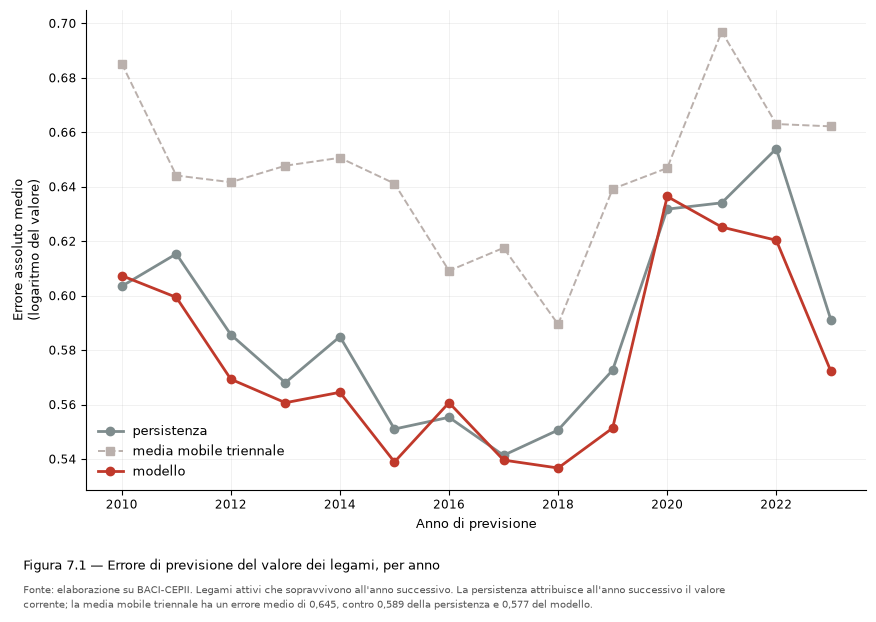

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_7_1_errore_livelli.png


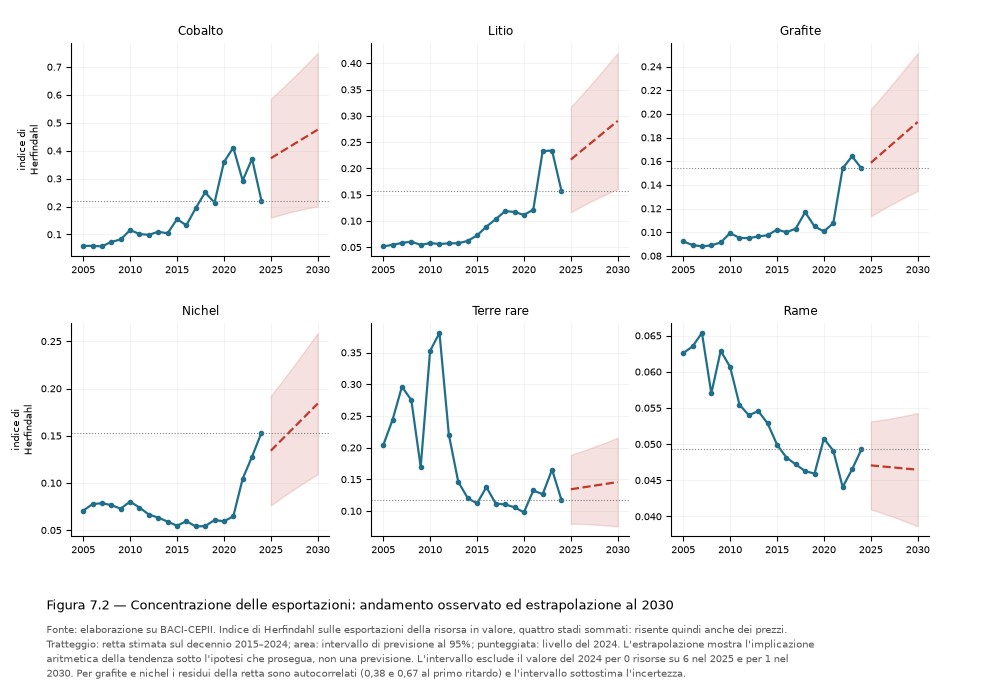

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\fig_7_2_estrapolazione.png


WindowsPath('C:/Users/CristianSirigu/Downloads/OUT_BINARIO_A/figure/fig_7_2_estrapolazione.png')

In [151]:
# =============================================================================
# FIGURE
# =============================================================================

# %% CELLA F7.1 — errore di previsione del valore, per anno
def _f71(ax):
    ax.plot(RL.anno, RL.mae_persistenza, "o-", lw=2, color="#7f8c8d", label="persistenza")
    ax.plot(RL.anno, RL.mae_ma3, "s--", lw=1.4, color="#bab0ac",
            label="media mobile triennale")
    ax.plot(RL.anno, RL.mae_modello, "o-", lw=2, color="#c0392b", label="modello")
    ax.set_xlabel("Anno di previsione", fontsize=9)
    ax.set_ylabel("Errore assoluto medio\n(logaritmo del valore)", fontsize=9)
    ax.legend(frameon=False, fontsize=9)


figura(_f71, altezza=4.8,
       didascalia="Figura 7.1 — Errore di previsione del valore dei legami, per anno",
       nota=f"Fonte: elaborazione su BACI-CEPII. Legami attivi che sopravvivono all'anno "
            f"successivo. La persistenza attribuisce all'anno successivo il valore "
            f"corrente; la media mobile triennale ha un errore medio di "
            f"{_n(RL.mae_ma3.mean())}, contro {_n(RL.mae_persistenza.mean())} della "
            f"persistenza e {_n(RL.mae_modello.mean())} del modello.",
       out=FIG_DIR / "fig_7_1_errore_livelli.png")


# %% CELLA F7.2 — estrapolazione della concentrazione al 2030
TR7 = pd.read_csv(OUT_DIR / "estrapolazione_hhi.csv")
STO7 = pd.read_csv(OUT_DIR / "serie_hhi_storica.csv")
RIS_F = [r for r in ["cobalt", "lithium", "graphite", "nickel", "ree", "copper"]
         if r in set(TR7.risorsa)]


def _f72(ax):
    ax.axis("off")
    fig, pos = ax.figure, ax.get_position()
    for i, r in enumerate(RIS_F):
        row, col = divmod(i, 3)
        a = fig.add_axes([pos.x0 + col * pos.width / 3,
                          pos.y0 + (1 - row) * pos.height / 2 + pos.height * 0.06,
                          pos.width / 3 * 0.86, pos.height / 2 * 0.76])
        s = STO7[(STO7.resource == r) & (STO7.year >= 2005)]
        e = TR7[TR7.risorsa == r]
        a.plot(s.year, s.hhi, "o-", lw=1.6, ms=3, color="#1f6f8b")
        a.plot(e.anno, e.stima, "--", lw=1.6, color="#c0392b")
        a.fill_between(e.anno, e.inf, e.sup, color="#c0392b", alpha=0.15)
        a.axhline(e.hhi_2024.iloc[0], color="grey", lw=0.8, ls=":")
        a.set_title(_nome(r), fontsize=8.5)
        a.tick_params(labelsize=7)
        a.grid(alpha=0.25, lw=0.4)
        for sp in ("top", "right"):
            a.spines[sp].set_visible(False)
        if col == 0:
            a.set_ylabel("indice di\nHerfindahl", fontsize=7.5)


_n25 = int(TR7[TR7.anno == 2025].esclude_2024.sum())
_n30 = int(TR7[TR7.anno == 2030].esclude_2024.sum())
_ac = TR7.drop_duplicates("risorsa").query("rho1_residui > 0.3")
_nota_ac = ("" if _ac.empty else
            " Per " + " e ".join(_nome(r).lower() for r in _ac.risorsa)
            + " i residui della retta sono autocorrelati ("
            + " e ".join(_n(v, 2) for v in _ac.rho1_residui)
            + " al primo ritardo) e l'intervallo sottostima l'incertezza.")
figura(_f72, altezza=5.6, larghezza=9.5, margine_basso=0.15, margine_sx=0.25,
       didascalia="Figura 7.2 — Concentrazione delle esportazioni: andamento osservato ed "
                  "estrapolazione al 2030",
       nota=f"Fonte: elaborazione su BACI-CEPII. Indice di Herfindahl sulle esportazioni "
            f"della risorsa in valore, quattro stadi sommati: risente quindi anche dei "
            f"prezzi. Tratteggio: retta stimata sul decennio 2015–2024; area: intervallo "
            f"di previsione al 95%; punteggiata: livello del 2024. L'estrapolazione mostra "
            f"l'implicazione aritmetica della tendenza sotto l'ipotesi che prosegua, non "
            f"una previsione. L'intervallo esclude il valore del 2024 per {_n25} risorse "
            f"su {len(RIS_F)} nel 2025 e per {_n30} nel 2030." + _nota_ac,
       out=FIG_DIR / "fig_7_2_estrapolazione.png")

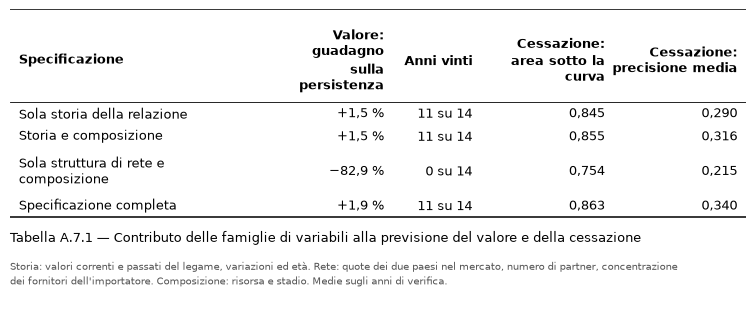

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A7_1_specificazioni.png


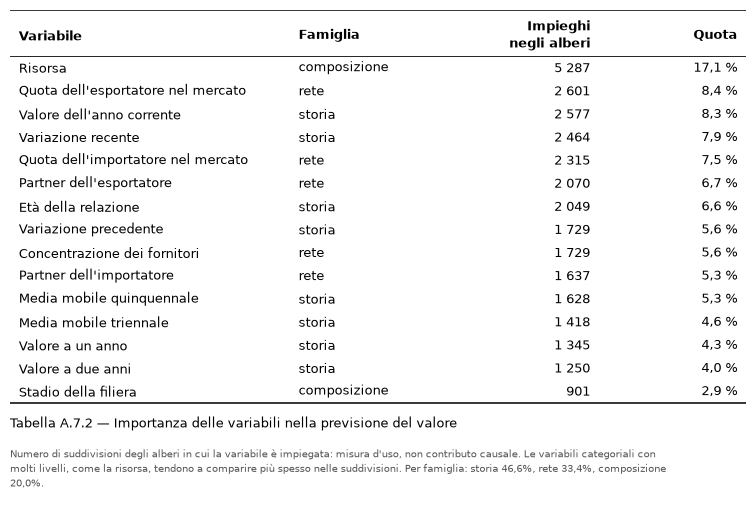

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A7_2_importanza.png


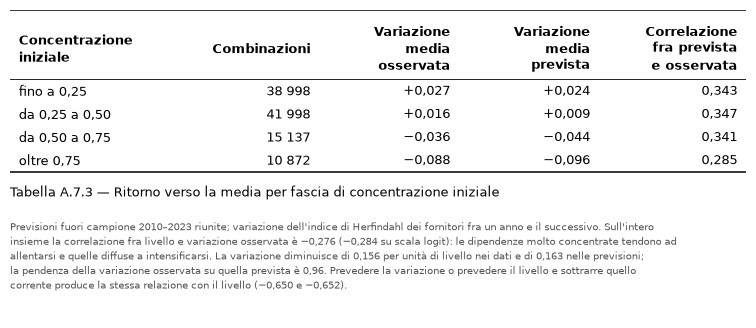

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A7_3_fasce.png


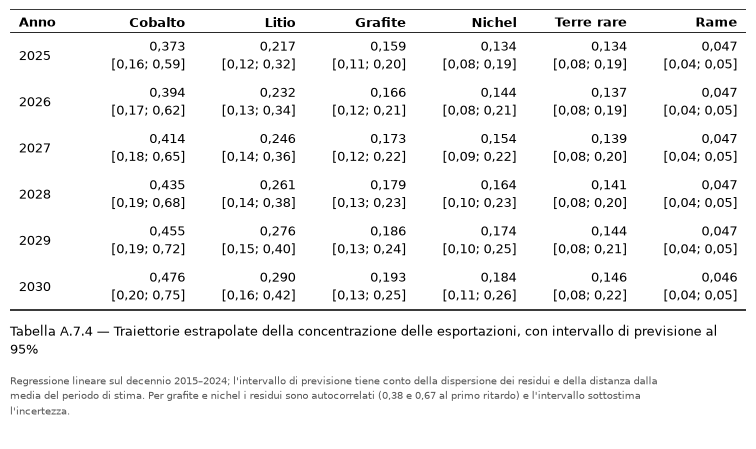

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A7_4_traiettorie.png


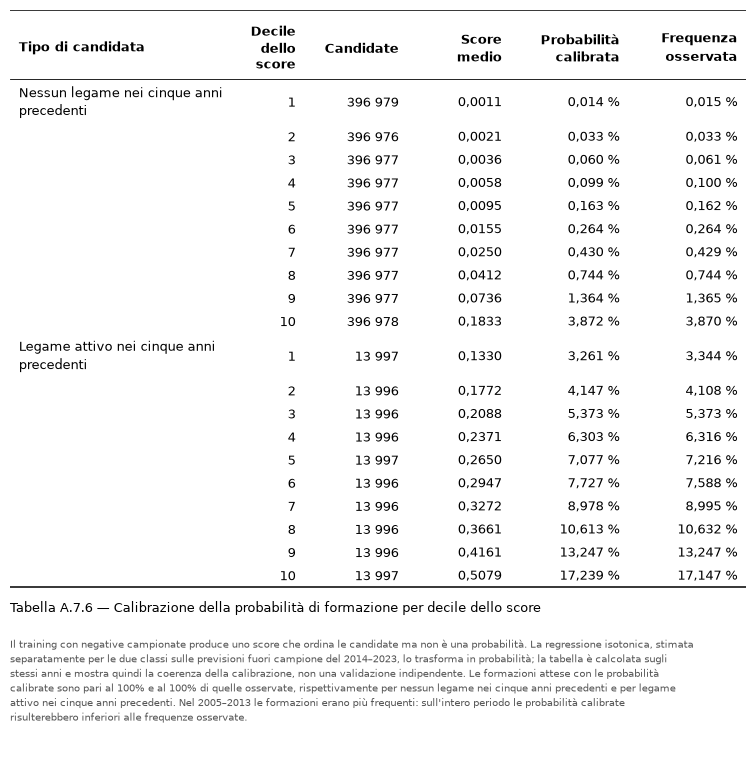

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A7_6_calibrazione.png


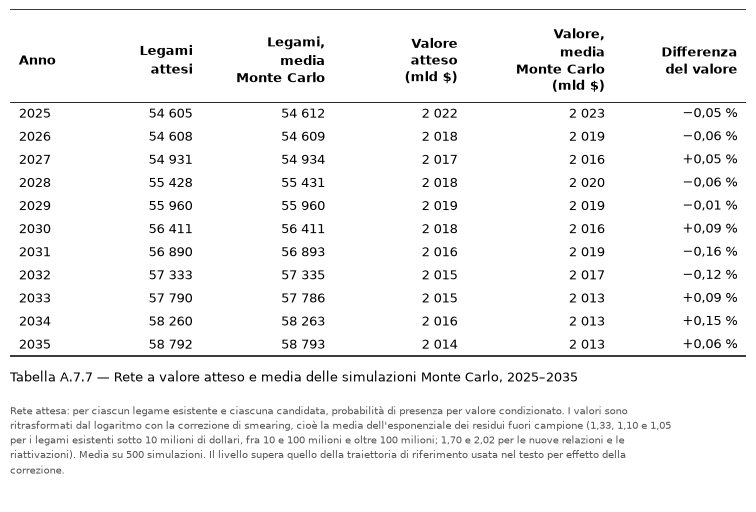

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A7_7_rete_attesa.png


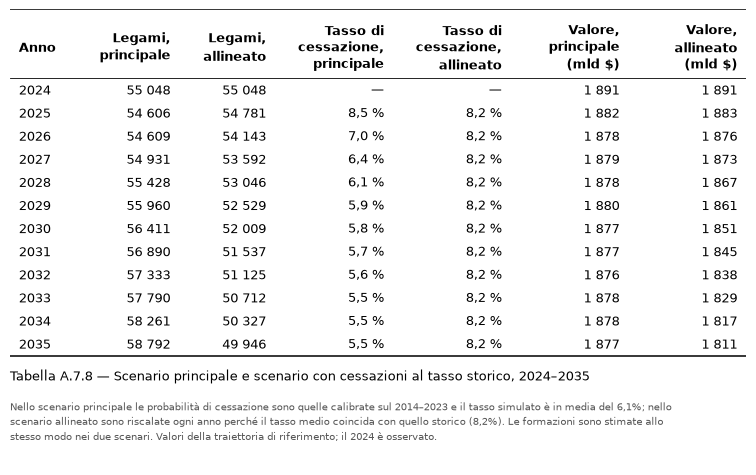

scritta C:\Users\CristianSirigu\Downloads\OUT_BINARIO_A\figure\tab_A7_8_robustezza.png

=== ELEMENTI DEL CAPITOLO 7 ===
  tab_7_10_concentrazione.png                       534 KB
  tab_7_11_aggravamento.png                         745 KB
  tab_7_12_struttura_stadi.png                      367 KB
  tab_7_1_livelli.png                               606 KB
  tab_7_2_soglie.png                                238 KB
  tab_7_3_cessazione_anni.png                       639 KB
  tab_7_4_cessazione_grandi.png                     481 KB
  tab_7_5_cessazione_stadio.png                     193 KB
  tab_7_6_cessazione_risorsa.png                    415 KB
  tab_7_7_concentrazione.png                        405 KB
  tab_7_7_formazione_anni.png                       834 KB
  tab_7_8_aggravamento.png                          704 KB
  tab_7_8_formazione_specificazioni.png             356 KB
  tab_7_9_formazione_gruppi.png                     333 KB
  tab_7_x_struttura_stadi.png                       36

In [152]:
# =============================================================================
# APPENDICE
# =============================================================================

# %% CELLA A7 — tabelle per l'appendice
# --- A.7.1 contributo delle famiglie di variabili: valore e cessazione ----
SPV = pd.read_csv(OUT_DIR / "previsione_specificazioni.csv")
SPC = pd.read_csv(OUT_DIR / "cessazione_specificazioni.csv")
_v = SPV.groupby("specificazione").agg(guadagno=("guadagno_mae_%", "mean"),
                                       anni=("guadagno_mae_%", lambda s: int((s > 0).sum())),
                                       tot=("anno", "nunique"))
_c = SPC.groupby("specificazione")[["auc", "ap"]].mean()
_ord = [s for s in LBL_SPEC_E if s in _v.index]

tabella(
    [(LBL_SPEC_E[s], _spc(_v.loc[s, "guadagno"]), f"{_v.loc[s, 'anni']} su {_v.loc[s, 'tot']}",
      _n(_c.loc[s, "auc"]), _n(_c.loc[s, "ap"])) for s in _ord],
    ["Specificazione", "Valore: guadagno\nsulla persistenza", "Anni vinti",
     "Cessazione:\narea sotto la curva", "Cessazione:\nprecisione media"],
    [0.36, 0.16, 0.12, 0.18, 0.18],
    didascalia="Tabella A.7.1 — Contributo delle famiglie di variabili alla previsione del "
               "valore e della cessazione",
    nota="Storia: valori correnti e passati del legame, variazioni ed età. Rete: quote dei "
         "due paesi nel mercato, numero di partner, concentrazione dei fornitori "
         "dell'importatore. Composizione: risorsa e stadio. Medie sugli anni di verifica.",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_A7_1_specificazioni.png")

# --- A.7.2 importanza delle variabili nella previsione del valore ---------
IMP7 = pd.read_csv(OUT_DIR / "previsione_importanza.csv")
_fam = IMP7.groupby("famiglia").quota.sum()

tabella(
    [(LBL_VAR.get(r.variabile, r.variabile), r.famiglia, _mig(r.importanza),
      _pp(r.quota * 100)) for r in IMP7.itertuples()],
    ["Variabile", "Famiglia", "Impieghi\nnegli alberi", "Quota"],
    [0.38, 0.22, 0.20, 0.20],
    didascalia="Tabella A.7.2 — Importanza delle variabili nella previsione del valore",
    nota=f"Numero di suddivisioni degli alberi in cui la variabile è impiegata: misura "
         f"d'uso, non contributo causale. Le variabili categoriali con molti livelli, come la "
         f"risorsa, tendono a comparire più spesso nelle suddivisioni. Per famiglia: storia "
         f"{_n(_fam.get('storia', 0) * 100, 1)}%, rete {_n(_fam.get('rete', 0) * 100, 1)}%, "
         f"composizione {_n(_fam.get('composizione', 0) * 100, 1)}%.",
    allinea=["l", "l", "r", "r"],
    out=FIG_DIR / "tab_A7_2_importanza.png")

# --- A.7.3 ritorno verso la media per fascia di concentrazione -----------
FAS = pd.read_csv(OUT_DIR / "aggravamento_per_fascia.csv")
MC7 = pd.read_csv(OUT_DIR / "previsione_hhi_meta.csv", index_col=0).iloc[:, 0]
PEN7 = pd.read_csv(OUT_DIR / "previsione_hhi_pendenze.csv", index_col=0).iloc[:, 0]

tabella(
    [(r.fascia, _mig(r.n), _sgn(r.variazione_media_osservata),
      _sgn(r.variazione_media_prevista), _n(r.corr_prevista_osservata))
     for r in FAS.itertuples()],
    ["Concentrazione\niniziale", "Combinazioni", "Variazione\nmedia\nosservata",
     "Variazione\nmedia\nprevista", "Correlazione\nfra prevista\ne osservata"],
    [0.24, 0.18, 0.19, 0.19, 0.20],
    didascalia="Tabella A.7.3 — Ritorno verso la media per fascia di concentrazione iniziale",
    nota=f"Previsioni fuori campione 2010–2023 riunite; variazione dell'indice di "
         f"Herfindahl dei fornitori fra un anno e il successivo. Sull'intero insieme la "
         f"correlazione fra livello e variazione osservata è "
         f"{_sgn(MC7['corr_livello_osservata'])} ({_sgn(MC7['corr_livello_osservata_logit'])} "
         f"su scala logit): le dipendenze molto concentrate tendono ad allentarsi e quelle "
         f"diffuse a intensificarsi. La variazione diminuisce di "
         f"{_n(-PEN7['pendenza_osservata'])} per unità di livello nei dati e di "
         f"{_n(-PEN7['pendenza_prevista'])} nelle previsioni; la pendenza della variazione "
         f"osservata su quella prevista è {_n(PEN7['calibrazione'], 2)}. Prevedere la "
         f"variazione o prevedere il livello e sottrarre quello corrente produce la stessa "
         f"relazione con il livello ({_sgn(MC7['corr_livello_prevista'])} e "
         f"{_sgn(MC7['corr_livello_da_livello'])}).",
    allinea=["l", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_A7_3_fasce.png")

# --- A.7.4 traiettorie estrapolate --------------------------------------
TR7 = pd.read_csv(OUT_DIR / "estrapolazione_hhi.csv")
RIS_F = [r for r in ["cobalt", "lithium", "graphite", "nickel", "ree", "copper"]
         if r in set(TR7.risorsa)]
PIV = TR7.pivot(index="anno", columns="risorsa", values="stima")
INF = TR7.pivot(index="anno", columns="risorsa", values="inf")
SUP = TR7.pivot(index="anno", columns="risorsa", values="sup")
_ac7 = TR7.drop_duplicates("risorsa").query("rho1_residui > 0.3")
_nota_ac7 = ("" if _ac7.empty else
             " Per " + " e ".join(_nome(r).lower() for r in _ac7.risorsa)
             + " i residui sono autocorrelati ("
             + " e ".join(_n(v, 2) for v in _ac7.rho1_residui)
             + " al primo ritardo) e l'intervallo sottostima l'incertezza.")

tabella(
    [(str(int(a)),) + tuple(_n(PIV.loc[a, c]) + "\n[" + _n(INF.loc[a, c], 2) + "; "
                            + _n(SUP.loc[a, c], 2) + "]" for c in RIS_F) for a in PIV.index],
    ["Anno"] + [_nome(c) for c in RIS_F],
    [0.10] + [0.90 / len(RIS_F)] * len(RIS_F),
    didascalia="Tabella A.7.4 — Traiettorie estrapolate della concentrazione delle "
               "esportazioni, con intervallo di previsione al 95%",
    nota="Regressione lineare sul decennio 2015–2024; l'intervallo di previsione tiene "
         "conto della dispersione dei residui e della distanza dalla media del periodo di "
         "stima." + _nota_ac7,
    allinea=["l"] + ["r"] * len(RIS_F),
    out=FIG_DIR / "tab_A7_4_traiettorie.png")

# --- A.7.6 calibrazione della probabilità di formazione -----------------
CAL7 = pd.read_csv(OUT_DIR / "formazione_tabella_calibrazione.csv")
CAL7["decile"] = CAL7.groupby("tipo").cumcount() + 1
_rap7 = (CAL7.groupby("tipo")
             .apply(lambda g: (g.prob_calibrata * g.n).sum() / (g.frequenza_reale * g.n).sum(),
                    include_groups=False))

tabella(
    [(LBL_GRUPPO[r.tipo] if r.decile == 1 else "", str(r.decile), _mig(r.n),
      _n(r.score_medio, 4), _pp(r.prob_calibrata * 100, 3), _pp(r.frequenza_reale * 100, 3))
     for r in CAL7.itertuples()],
    ["Tipo di candidata", "Decile\ndello score", "Candidate", "Score\nmedio",
     "Probabilità\ncalibrata", "Frequenza\nosservata"],
    [0.30, 0.10, 0.14, 0.14, 0.16, 0.16],
    didascalia="Tabella A.7.6 — Calibrazione della probabilità di formazione per decile "
               "dello score",
    nota="Il training con negative campionate produce uno score che ordina le candidate ma "
         "non è una probabilità. La regressione isotonica, stimata separatamente per le due "
         "classi sulle previsioni fuori campione del 2014–2023, lo trasforma in probabilità; "
         "la tabella è calcolata sugli stessi anni e mostra quindi la coerenza della "
         "calibrazione, non una validazione indipendente. Le formazioni attese con le "
         "probabilità calibrate sono pari al "
         + " e al ".join(f"{_n(_rap7[t] * 100, 0)}%" for t in _rap7.index)
         + " di quelle osservate, rispettivamente per "
         + " e per ".join(LBL_GRUPPO[t].lower() for t in _rap7.index)
         + ". Nel 2005–2013 le formazioni erano più frequenti: sull'intero periodo "
           "le probabilità calibrate risulterebbero inferiori alle frequenze osservate.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_A7_6_calibrazione.png")

# --- A.7.7 rete attesa e media delle simulazioni Monte Carlo -------------
CHK7 = pd.read_csv(OUT_DIR / "scenario_2025_2035_rete_attesa_check_mc.csv")

tabella(
    [(str(int(r.anno)), _mig(r.archi_attesi), _mig(r.archi_mc_media),
      _mig(r.valore_atteso_mld), _mig(r.valore_mc_media_mld), _spc(r.diff_valore_pct, 2))
     for r in CHK7.itertuples()],
    ["Anno", "Legami\nattesi", "Legami,\nmedia\nMonte Carlo", "Valore\natteso\n(mld $)",
     "Valore,\nmedia\nMonte Carlo\n(mld $)", "Differenza\ndel valore"],
    [0.10, 0.16, 0.18, 0.18, 0.20, 0.18],
    didascalia="Tabella A.7.7 — Rete a valore atteso e media delle simulazioni Monte Carlo, "
               "2025–2035",
    nota="Rete attesa: per ciascun legame esistente e ciascuna candidata, probabilità di "
         "presenza per valore condizionato. I valori sono ritrasformati dal logaritmo con la "
         "correzione di smearing, cioè la media dell'esponenziale dei residui fuori campione "
         "(1,33, 1,10 e 1,05 per i legami esistenti sotto 10 milioni di dollari, fra 10 e "
         "100 milioni e oltre 100 milioni; 1,70 e 2,02 per le nuove relazioni e le "
         "riattivazioni). Media su 500 simulazioni. Il livello supera quello della "
         "traiettoria di riferimento usata nel testo per effetto della correzione.",
    allinea=["l", "r", "r", "r", "r", "r"],
    out=FIG_DIR / "tab_A7_7_rete_attesa.png")

# --- A.7.8 scenario principale e cessazioni al tasso storico -------------
_p_rob = OUT_DIR / "scenario_robustezza_cessazione.csv"
if _p_rob.exists():
    ROB7 = pd.read_csv(_p_rob)
    _pct = lambda x: _pp(x * 100) if pd.notna(x) else "—"
    tabella(
        [(str(int(r.anno)), _mig(r.archi_principale), _mig(r.archi_allineato),
          _pct(r.tasso_cessazione_principale), _pct(r.tasso_cessazione_allineato),
          _mig(r.valore_totale_mld_principale), _mig(r.valore_totale_mld_allineato))
         for r in ROB7.itertuples()],
        ["Anno", "Legami,\nprincipale", "Legami,\nallineato", "Tasso di\ncessazione,\nprincipale",
         "Tasso di\ncessazione,\nallineato", "Valore,\nprincipale\n(mld $)",
         "Valore,\nallineato\n(mld $)"],
        [0.10, 0.13, 0.13, 0.16, 0.16, 0.16, 0.16],
        didascalia="Tabella A.7.8 — Scenario principale e scenario con cessazioni al tasso "
                   "storico, 2024–2035",
        nota=f"Nello scenario principale le probabilità di cessazione sono quelle calibrate "
             f"sul 2014–2023 e il tasso simulato è in media del "
             f"{_n(ROB7.tasso_cessazione_principale.mean() * 100, 1)}%; nello scenario "
             f"allineato sono riscalate ogni anno perché il tasso medio coincida con quello "
             f"storico ({_n(ROB7.tasso_cessazione_allineato.mean() * 100, 1)}%). Le "
             f"formazioni sono stimate allo stesso modo nei due scenari. Valori della "
             f"traiettoria di riferimento; il 2024 è osservato.",
        allinea=["l", "r", "r", "r", "r", "r", "r"],
        out=FIG_DIR / "tab_A7_8_robustezza.png")
else:
    print("scenario_robustezza_cessazione.csv non trovato: salvarlo da L11r2 per la Tabella A.7.8")


# %% CELLA Z7 — riepilogo dei file prodotti
print("\n=== ELEMENTI DEL CAPITOLO 7 ===")
for pat in ["tab_7_*.png", "fig_7_*.png", "tab_A7_*.png", "fig_A7_*.png"]:
    for p in sorted(FIG_DIR.glob(pat)):
        if "anteprima" not in p.name:
            print(f"  {p.name:46s} {p.stat().st_size / 1024:6.0f} KB")

In [159]:
for t in ("SENS", "CH", "FANT"):
    print(f"\n=== {t} ===")
    print(globals()[t].to_string())


=== SENS ===
   soglia_off   legami   formazioni   cessazioni    rientri
0           0  1524557  4073.206897  2336.551724  10.855590
1          25  1379937  4371.310345  2984.551724  11.028341
2          50  1335030  4497.827586  3196.172414  11.250027
3         100  1280389  4682.931034  3484.413793  11.716217
4         150  1242039  4833.793103  3707.896552  12.289308
5         250  1187895  5092.724138  4061.965517  13.353617
6         400  1130444  5446.000000  4510.620690  15.116674
7         600  1075904  5904.275862  5060.896552  17.974232
8         800  1033639  6377.655172  5602.137931  21.322758
9        1000   999925  6870.310345  6145.310345  25.282891

=== CH ===
    anno  cessazioni  rientri_dopo_1_anno
0   1996        1377             0.138707
1   1997        1901             0.136770
2   1998        2102             0.122265
3   1999        2485             0.110664
4   2000        2195             0.101139
5   2001        2353             0.107522
6   2002        2569

In [160]:
agg = (DI[DI["resource"].isin(FL["resource"].unique())]
       .groupby(["year", "exp", "imp", "resource", "stage_name"], observed=True)["value"].sum())
agg = agg[agg > 0]
for s in (100, 500, 1000, 5000):          # migliaia di dollari, come in BACI
    sotto = agg < s
    print(f"soglia {s/1000:g} mln: flussi sotto = {sotto.mean():.1%}, "
          f"valore sotto = {agg[sotto].sum()/agg.sum():.2%}")
a24 = agg.xs(2024, level="year")
print(f"2024, soglia 1 mln: flussi sotto = {(a24<1000).mean():.1%}, "
      f"valore sotto = {a24[a24<1000].sum()/a24.sum():.2%}")

soglia 0.1 mln: flussi sotto = 63.1%, valore sotto = 0.21%
soglia 0.5 mln: flussi sotto = 78.3%, valore sotto = 0.89%
soglia 1 mln: flussi sotto = 83.6%, valore sotto = 1.59%
soglia 5 mln: flussi sotto = 92.4%, valore sotto = 5.44%
2024, soglia 1 mln: flussi sotto = 82.7%, valore sotto = 1.01%


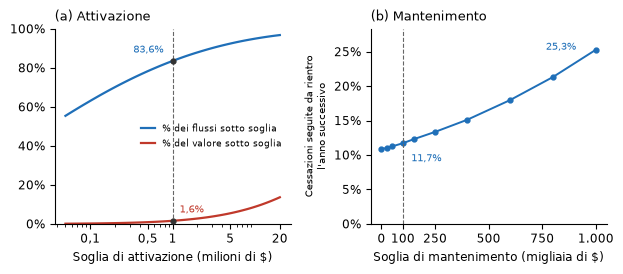

salvata: fig_5_1_soglie.png | sotto 1 mln: 83,6% dei flussi, 1,59% del valore


In [161]:
import numpy as np, matplotlib.pyplot as plt, matplotlib.ticker as mt

OUT_PNG = "fig_5_1_soglie.png"          # cambia il percorso se vuoi salvarla altrove

# --- dati del pannello (a): flussi bilaterali aggregati per risorsa e stadio, 1995-2024
try:
    agg
except NameError:
    agg = (DI[DI["resource"].isin(FL["resource"].unique())]
           .groupby(["year", "exp", "imp", "resource", "stage_name"], observed=True)["value"].sum())
    agg = agg[agg > 0]
v = np.sort(agg.to_numpy())                 # migliaia di dollari
cum = np.cumsum(v)
grid = np.logspace(np.log10(50), np.log10(20000), 80)     # da 50 mila a 20 milioni
idx = np.searchsorted(v, grid)
q_flussi = 100 * idx / len(v)
q_valore = 100 * np.where(idx > 0, cum[np.maximum(idx - 1, 0)], 0) / cum[-1]
i1 = np.searchsorted(v, 1000)
f1, v1 = 100 * i1 / len(v), 100 * cum[i1 - 1] / cum[-1]

# --- dati del pannello (b): sensibilità alla soglia di mantenimento
so = SENS["soglia_off"].to_numpy()
ri = SENS["rientri"].to_numpy()
r100 = SENS.loc[SENS["soglia_off"] == 100, "rientri"].iloc[0]
r1000 = SENS.loc[SENS["soglia_off"] == 1000, "rientri"].iloc[0]

it = lambda x: f"{x:g}".replace(".", ",")
pc = lambda x, d=1: f"{x:.{d}f}%".replace(".", ",")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5,
                     "axes.spines.top": False, "axes.spines.right": False})
fig, (a, b) = plt.subplots(1, 2, figsize=(6.3, 2.8))

# (a) attivazione
a.plot(grid / 1000, q_flussi, color="#1f6fb8", lw=1.6, label="% dei flussi sotto soglia")
a.plot(grid / 1000, q_valore, color="#c0392b", lw=1.6, label="% del valore sotto soglia")
a.axvline(1, color="0.4", ls="--", lw=0.8)
a.plot([1, 1], [f1, v1], "o", color="0.2", ms=3.5, zorder=5)
a.annotate(pc(f1), (1, f1), xytext=(-6, 6), textcoords="offset points", ha="right", fontsize=7, color="#1f6fb8")
a.annotate(pc(v1), (1, v1), xytext=(5, 6), textcoords="offset points", ha="left", fontsize=7, color="#c0392b")
a.set_xscale("log")
a.set_xticks([0.1, 0.5, 1, 5, 20])
a.xaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: it(x)))
a.xaxis.set_minor_formatter(mt.NullFormatter())
a.set_ylim(0, 100)
a.yaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: f"{x:.0f}%"))
a.set_xlabel("Soglia di attivazione (milioni di $)")
a.set_title("(a) Attivazione", fontsize=9, loc="left")
a.legend(frameon=False, fontsize=6.8, loc="center right", bbox_to_anchor=(1.0, 0.45), handlelength=1.5)

# (b) mantenimento
b.plot(so, ri, "o-", color="#1f6fb8", ms=3.5, lw=1.4)
b.axvline(100, color="0.4", ls="--", lw=0.8)
b.annotate(pc(r100), (100, r100), xytext=(6, -13), textcoords="offset points", fontsize=7, color="#1f6fb8")
b.annotate(pc(r1000), (1000, r1000), xytext=(-36, 0), textcoords="offset points", fontsize=7, color="#1f6fb8")
b.set_ylim(0, max(ri) * 1.12)
b.yaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: f"{x:.0f}%"))
b.set_ylabel("Cessazioni seguite da rientro\nl'anno successivo", fontsize=7.5)
b.set_xticks([0, 100, 250, 500, 750, 1000])
b.set_xticklabels(["0", "100", "250", "500", "750", "1.000"])
b.set_xlabel("Soglia di mantenimento (migliaia di $)")
b.set_title("(b) Mantenimento", fontsize=9, loc="left")

fig.tight_layout()
fig.savefig(OUT_PNG, dpi=600)
plt.show()
print("salvata:", OUT_PNG, f"| sotto 1 mln: {pc(f1)} dei flussi, {pc(v1, 2)} del valore")

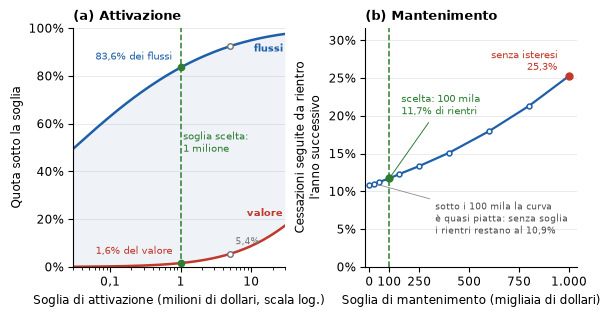

salvata: fig_5_1_soglie.png
1 mln: 83,6% flussi, 1,59% valore | 5 mln: 5,44% valore | 100 mila: 63,1% flussi


In [162]:
import numpy as np, matplotlib.pyplot as plt, matplotlib.ticker as mt

OUT_PNG = "fig_5_1_soglie.png"

# ---------- dati (a): flussi bilaterali per esportatore, importatore, risorsa, stadio e anno
try:
    agg
except NameError:
    agg = (DI[DI["resource"].isin(FL["resource"].unique())]
           .groupby(["year", "exp", "imp", "resource", "stage_name"], observed=True)["value"].sum())
    agg = agg[agg > 0]
v = np.sort(agg.to_numpy())                       # migliaia di dollari
cum = np.cumsum(v)
def quote(s):                                     # s in migliaia di dollari
    i = np.searchsorted(v, s)
    return 100 * i / len(v), 100 * (cum[i - 1] if i > 0 else 0) / cum[-1]
grid = np.logspace(np.log10(30), np.log10(30000), 200)
QF, QV = np.array([quote(s) for s in grid]).T
f1, v1 = quote(1000)
f5, v5 = quote(5000)
f01, v01 = quote(100)

# ---------- dati (b): sensibilità alla soglia di mantenimento
so = SENS["soglia_off"].to_numpy(float)
ri = SENS["rientri"].to_numpy(float)
r = dict(zip(so, ri))

# ---------- stile
BLU, ROSSO, GRIGIO, SCELTA = "#1f5fa8", "#c0392b", "0.45", "#2e7d32"
pc = lambda x, d=1: f"{x:.{d}f}%".replace(".", ",")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 9})
fig, (a, b) = plt.subplots(1, 2, figsize=(6.5, 3.1), gridspec_kw={"wspace": 0.38})

# ================= (a) attivazione
a.fill_between(grid / 1000, QV, QF, color=BLU, alpha=0.07, lw=0)
a.plot(grid / 1000, QF, color=BLU, lw=1.8)
a.plot(grid / 1000, QV, color=ROSSO, lw=1.8)
a.axvline(1, color=SCELTA, lw=1.1, ls="--", zorder=1)
a.plot([1, 1], [f1, v1], "o", color=SCELTA, ms=4.5, zorder=5)
a.plot([5, 5], [f5, v5], "o", mfc="white", mec=GRIGIO, ms=4, zorder=5)
# etichette dirette delle curve
a.text(28, QF[-1] - 4, "flussi", color=BLU, ha="right", va="top", fontsize=7.5, fontweight="bold")
a.text(28, QV[-1] + 3, "valore", color=ROSSO, ha="right", va="bottom", fontsize=7.5, fontweight="bold")
# valori sulla soglia scelta e sull'alternativa
a.annotate(f"{pc(f1)} dei flussi", (1, f1), xytext=(-6, 4), textcoords="offset points",
           ha="right", va="bottom", fontsize=7, color=BLU)
a.annotate(f"{pc(v1)} del valore", (1, v1), xytext=(-6, 5), textcoords="offset points",
           ha="right", va="bottom", fontsize=7, color=ROSSO)
a.annotate(pc(v5), (5, v5), xytext=(4, 7), textcoords="offset points", fontsize=6.8, color=GRIGIO)
a.text(1.08, 52, "soglia scelta:\n1 milione", color=SCELTA, fontsize=7, va="center")
a.set_xscale("log")
a.set_xlim(0.03, 30)
a.set_xticks([0.1, 1, 10])
a.xaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: f"{x:g}".replace(".", ",")))
a.xaxis.set_minor_formatter(mt.NullFormatter())
a.set_ylim(0, 100)
a.yaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: f"{x:.0f}%"))
a.grid(axis="y", color="0.9", lw=0.6)
a.set_axisbelow(True)
a.set_xlabel("Soglia di attivazione (milioni di dollari, scala log.)")
a.set_ylabel("Quota sotto la soglia")
a.set_title("(a) Attivazione", loc="left")

# ================= (b) mantenimento
b.plot(so, ri, "-o", color=BLU, lw=1.6, ms=3.5, mfc="white", mew=1.1)
b.axvline(100, color=SCELTA, lw=1.1, ls="--", zorder=1)
b.plot(100, r[100], "o", color=SCELTA, ms=5, zorder=5)
b.plot(1000, r[1000], "o", color=ROSSO, ms=5, zorder=5)
b.annotate(f"scelta: 100 mila\n{pc(r[100])} di rientri", (100, r[100]), xytext=(160, r[100] + 8.5),
           fontsize=7, color=SCELTA, ha="left",
           arrowprops=dict(arrowstyle="-", color=SCELTA, lw=0.7))
b.annotate(f"senza isteresi\n{pc(r[1000])}", (1000, r[1000]), xytext=(-8, 2), textcoords="offset points",
           fontsize=7, color=ROSSO, ha="right", va="bottom")
b.annotate(f"sotto i 100 mila la curva\nè quasi piatta: senza soglia\ni rientri restano al {pc(r[0])}", (25, r[25]),
           xytext=(330, 4), fontsize=6.6, color="0.3", ha="left", va="bottom",
           arrowprops=dict(arrowstyle="-", color="0.55", lw=0.6))
b.set_xlim(-20, 1040)
b.set_ylim(0, max(ri) * 1.25)
b.set_xticks([0, 100, 250, 500, 750, 1000])
b.set_xticklabels(["0", "100", "250", "500", "750", "1.000"])
b.yaxis.set_major_formatter(mt.FuncFormatter(lambda x, p: f"{x:.0f}%"))
b.grid(axis="y", color="0.9", lw=0.6)
b.set_axisbelow(True)
b.set_xlabel("Soglia di mantenimento (migliaia di dollari)")
b.set_ylabel("Cessazioni seguite da rientro\nl'anno successivo")
b.set_title("(b) Mantenimento", loc="left")

fig.savefig(OUT_PNG, dpi=600, bbox_inches="tight")
plt.show()
print("salvata:", OUT_PNG)
print(f"1 mln: {pc(f1)} flussi, {pc(v1,2)} valore | 5 mln: {pc(v5,2)} valore | 100 mila: {pc(f01)} flussi")